In [1]:
import torch

print("CUDA available :", torch.cuda.is_available())
print("GPU count      :", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

import sys
import subprocess

packages = [
    "deepctr-torch",
    "pytorch-tabnet",
    "pytorch-tabular",
]

for pkg in packages:
    print(f"Installing {pkg} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

print("Installation finished.")

import importlib.util

def package_available(module_name: str) -> bool:
    return importlib.util.find_spec(module_name) is not None

HAS_DEEPCTR = package_available("deepctr_torch")
HAS_TABNET = package_available("pytorch_tabnet")
HAS_PYTORCH_TABULAR = package_available("pytorch_tabular")

print("HAS_DEEPCTR        =", HAS_DEEPCTR)
print("HAS_TABNET         =", HAS_TABNET)
print("HAS_PYTORCH_TABULAR=", HAS_PYTORCH_TABULAR)

import os
import torch

USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("USE_GPU       :", USE_GPU)
print("N_GPUS        :", N_GPUS)
print("PRIMARY_DEVICE:", PRIMARY_DEVICE)

# optional: reduce fragmentation a bit
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

CUDA available : True
GPU count      : 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Installing deepctr-torch ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 3.3 MB/s eta 0:00:00
Installing pytorch-tabnet ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.9 MB/s eta 0:00:00
Installing pytorch-tabular ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.8/165.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.8/159.8 kB 11.9 MB/s eta 0:00:00
Installation finished.
HAS_DEEPCTR        = True
HAS_TABNET         = True
HAS_PYTORCH_TABULAR= True
USE_GPU       : True
N_GPUS        : 2
PRIMARY_DEVICE: cuda:0


In [2]:
# ============================================================
# Install missing deep tabular libraries for Block 4
# Run this cell first, then restart kernel or rerun from top
# ============================================================

import sys
import subprocess

def pip_install(pkg):
    print(f"\n[Installing] {pkg}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

packages = [
    "deepctr-torch",
    "pytorch-tabnet",
    "pytorch-tabular[all]",
]

for pkg in packages:
    pip_install(pkg)

print("\nAll requested libraries installed.")


[Installing] deepctr-torch

[Installing] pytorch-tabnet

[Installing] pytorch-tabular[all]



All requested libraries installed.


===== Experiment Configuration =====
Experiment Name : trustworthy_heart_disease_v1
Seed            : 42
Device          : cuda
Data Path       : /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Output Dir      : /kaggle/working/outputs/trustworthy_heart_disease_v1
CV Splits       : 5
Deep Models     : True
Fairness Module : True
Robustness      : True
HITL Module     : True

===== Optional Dependencies =====
deepctr_torch  : available
pytorch_tabnet : available

===== Torch Info =====
Torch version : 2.10.0+cu128
CUDA available: True

Scikit-learn version: 1.6.1

[OK] Path sanity check passed.
===== Raw Dataset Loaded =====
Shape: (253680, 22)


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



===== Dataset Audit Summary =====


,n_rows,n_cols,target_col,missing_count_total,duplicate_rows,target_positive_count,target_negative_count,target_positive_rate
0,253680,22,HeartDiseaseorAttack,0,23899,23893,229787,0.094186



===== Column Audit =====


,feature,dtype,n_unique,n_missing
0,HeartDiseaseorAttack,float64,2,0
1,HighBP,float64,2,0
2,HighChol,float64,2,0
3,CholCheck,float64,2,0
4,BMI,float64,84,0
5,Smoker,float64,2,0
6,Stroke,float64,2,0
7,Diabetes,float64,3,0
8,PhysActivity,float64,2,0
9,Fruits,float64,2,0


[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section2_dataset_audit_summary.csv
[Saved LaTeX table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section2_dataset_audit_summary.tex
[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section2_column_audit.csv

===== Target Distribution =====


,class_label,count,rate
0,0,229787,0.905814
1,1,23893,0.094186


[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section2_target_distribution.csv
[Saved LaTeX table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section2_target_distribution.tex
[Saved figure] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/section2_class_distribution.(png/pdf)


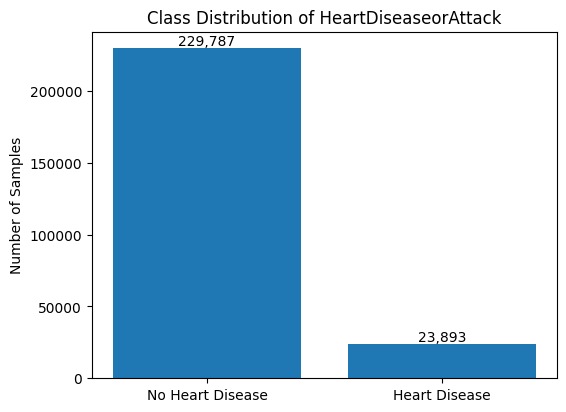

[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section2_descriptive_summary.csv

===== Feature Schema =====


,feature,group
0,HighBP,binary
1,HighChol,binary
2,CholCheck,binary
3,Smoker,binary
4,Stroke,binary
5,PhysActivity,binary
6,Fruits,binary
7,Veggies,binary
8,HvyAlcoholConsump,binary
9,AnyHealthcare,binary



===== Feature Group Summary =====


,group,n_features
0,binary,13
1,continuous,3
2,ordinal,5


[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section3_feature_schema.csv
[Saved LaTeX table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section3_feature_schema.tex
[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section3_feature_group_summary.csv
[Saved LaTeX table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section3_feature_group_summary.tex


,feature,group,n_unique,min,max,mean,std
0,HighBP,binary,2,0.0,1.0,0.429001,0.494934
1,HighChol,binary,2,0.0,1.0,0.424121,0.494210
2,CholCheck,binary,2,0.0,1.0,0.962670,0.189571
3,Smoker,binary,2,0.0,1.0,0.443169,0.496761
4,Stroke,binary,2,0.0,1.0,0.040571,0.197294


[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section3_feature_overview.csv

===== Split Shapes =====
Development: X=(202944, 21), y=(202944,)
Holdout    : X=(50736, 21), y=(50736,)
[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section4_split_indices.csv

===== Split Summary =====


,split,n_samples,n_positive,n_negative,positive_rate
0,development,202944,19114,183830,0.094184
1,holdout,50736,4779,45957,0.094193


[Saved table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section4_split_summary.csv
[Saved LaTeX table] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/section4_split_summary.tex
[Saved figure] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/section4_split_prevalence.(png/pdf)


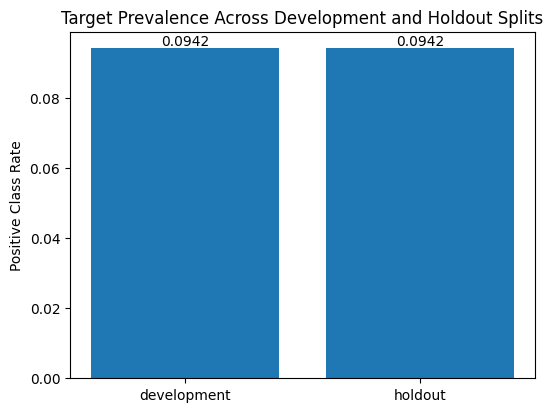


===== Block 2 Complete =====
Saved key artifacts:
- section2_dataset_audit_summary.csv/.tex
- section2_column_audit.csv
- section2_target_distribution.csv/.tex
- section2_class_distribution.(png/pdf)
- section3_feature_schema.csv/.tex/json
- section3_feature_group_summary.csv/.tex
- section3_feature_overview.csv
- section4_split_indices.csv
- section4_split_summary.csv/.tex
- section4_split_prevalence.(png/pdf)
- X_dev.csv, X_holdout.csv, y_dev.csv, y_holdout.csv
===== Block 3 Smoke Test =====
Preprocessor modes available: ml, linear, dl, deep_views
Metrics utilities ready.
CV runner ready.
[OK] Block 3 infrastructure initialized.


In [3]:
# ============================================================
# Block 1 — Sections 0–1
# Study Configuration + Environment Setup
# ============================================================

# -------------------------------
# Section 0 — Global Configuration
# -------------------------------

import os
import random
import numpy as np
import pandas as pd
from pathlib import Path

# ---- Experiment identity ----
EXPERIMENT_NAME = "trustworthy_heart_disease_v1"
SEED = 42

# ---- Data path (update if needed) ----
DATA_PATH = "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv"

# ---- Output directories ----
BASE_OUT_DIR = Path("/kaggle/working/outputs") / EXPERIMENT_NAME

TAB_DIR  = BASE_OUT_DIR / "tables"
FIG_DIR  = BASE_OUT_DIR / "figures"
PRED_DIR = BASE_OUT_DIR / "predictions"
MODEL_DIR = BASE_OUT_DIR / "models"
LOG_DIR  = BASE_OUT_DIR / "logs"

for d in [TAB_DIR, FIG_DIR, PRED_DIR, MODEL_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---- Toggle heavy modules ----
RUN_DEEP_MODELS = True
RUN_FAIRNESS_MODULE = True
RUN_ROBUSTNESS_MODULE = True
RUN_HITL_MODULE = True

# ---- Numerical stability ----
EPS = 1e-8

# ---- CV configuration ----
N_SPLITS = 5
USE_REPEATED_CV = False   # keep False for clean paper notebook

# ---- Device detection ----
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Reproducibility ----
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass

seed_everything(SEED)

print("===== Experiment Configuration =====")
print(f"Experiment Name : {EXPERIMENT_NAME}")
print(f"Seed            : {SEED}")
print(f"Device          : {DEVICE}")
print(f"Data Path       : {DATA_PATH}")
print(f"Output Dir      : {BASE_OUT_DIR}")
print(f"CV Splits       : {N_SPLITS}")
print(f"Deep Models     : {RUN_DEEP_MODELS}")
print(f"Fairness Module : {RUN_FAIRNESS_MODULE}")
print(f"Robustness      : {RUN_ROBUSTNESS_MODULE}")
print(f"HITL Module     : {RUN_HITL_MODULE}")


# -------------------------------
# Section 1 — Imports
# -------------------------------

import warnings
warnings.filterwarnings("ignore")

# ---- Core ML ----
from sklearn.model_selection import StratifiedKFold, train_test_split

# Metrics
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    matthews_corrcoef
)

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Models (baseline pool)
from sklearn.linear_model import LogisticRegression, SGDClassifier, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

# Boosting libraries
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Optional deep libraries
import importlib.util

def package_available(module_name: str) -> bool:
    return importlib.util.find_spec(module_name) is not None

HAS_DEEPCTR = package_available("deepctr_torch")
HAS_TABNET = package_available("pytorch_tabnet")

print("\n===== Optional Dependencies =====")
print(f"deepctr_torch  : {'available' if HAS_DEEPCTR else 'missing'}")
print(f"pytorch_tabnet : {'available' if HAS_TABNET else 'missing'}")

# Torch info
print("\n===== Torch Info =====")
print(f"Torch version : {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

# Sklearn version
import sklearn
print(f"\nScikit-learn version: {sklearn.__version__}")


# -------------------------------
# Utility: quick sanity checker
# -------------------------------

def sanity_check_paths():
    assert os.path.exists(DATA_PATH), f"Data file not found: {DATA_PATH}"
    assert BASE_OUT_DIR.exists(), "Output directory not created properly"
    print("\n[OK] Path sanity check passed.")

sanity_check_paths()

# ============================================================
# Block 2 — Sections 2–4
# Data Loading + Audit + Feature Schema + Leakage-Safe Split
# ============================================================

import json
from pathlib import Path

# ------------------------------------------------------------
# Section 2 — Data Loading
# ------------------------------------------------------------
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("===== Raw Dataset Loaded =====")
print(f"Shape: {df.shape}")
display(df.head())

# ------------------------------------------------------------
# Reusable save helpers for paper-quality artifacts
# ------------------------------------------------------------
SAVE_FIG_FORMATS = ["png", "pdf"]

def save_current_figure(base_path: Path, dpi: int = 300):
    base_path.parent.mkdir(parents=True, exist_ok=True)
    for ext in SAVE_FIG_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), dpi=dpi, bbox_inches="tight")
    print(f"[Saved figure] {base_path}.(png/pdf)")

def save_table_csv(df_obj: pd.DataFrame, path: Path, index: bool = False):
    path.parent.mkdir(parents=True, exist_ok=True)
    df_obj.to_csv(path, index=index)
    print(f"[Saved table] {path}")

def save_table_latex(
    df_obj: pd.DataFrame,
    path: Path,
    index: bool = False,
    float_format="%.4f"
):
    path.parent.mkdir(parents=True, exist_ok=True)
    latex_str = df_obj.to_latex(index=index, escape=False, float_format=float_format)
    with open(path, "w", encoding="utf-8") as f:
        f.write(latex_str)
    print(f"[Saved LaTeX table] {path}")

# ------------------------------------------------------------
# Section 2A — Initial Audit
# ------------------------------------------------------------
TARGET_COL = "HeartDiseaseorAttack"

if TARGET_COL not in df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found in dataset.")

n_rows, n_cols = df.shape
missing_count_total = int(df.isna().sum().sum())
duplicate_rows = int(df.duplicated().sum())

dtype_df = pd.DataFrame({
    "feature": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": [df[c].nunique(dropna=False) for c in df.columns],
    "n_missing": [int(df[c].isna().sum()) for c in df.columns],
})

audit_summary_df = pd.DataFrame([{
    "n_rows": n_rows,
    "n_cols": n_cols,
    "target_col": TARGET_COL,
    "missing_count_total": missing_count_total,
    "duplicate_rows": duplicate_rows,
    "target_positive_count": int(df[TARGET_COL].sum()),
    "target_negative_count": int((1 - df[TARGET_COL]).sum()),
    "target_positive_rate": float(df[TARGET_COL].mean()),
}])

print("\n===== Dataset Audit Summary =====")
display(audit_summary_df)

print("\n===== Column Audit =====")
display(dtype_df)

save_table_csv(audit_summary_df, TAB_DIR / "section2_dataset_audit_summary.csv", index=False)
save_table_latex(audit_summary_df, TAB_DIR / "section2_dataset_audit_summary.tex", index=False)

save_table_csv(dtype_df, TAB_DIR / "section2_column_audit.csv", index=False)

# ------------------------------------------------------------
# Section 2B — Target Distribution Table
# ------------------------------------------------------------
target_dist_df = pd.DataFrame({
    "class_label": [0, 1],
    "count": [
        int((df[TARGET_COL] == 0).sum()),
        int((df[TARGET_COL] == 1).sum())
    ],
})
target_dist_df["rate"] = target_dist_df["count"] / len(df)

print("\n===== Target Distribution =====")
display(target_dist_df)

save_table_csv(target_dist_df, TAB_DIR / "section2_target_distribution.csv", index=False)
save_table_latex(target_dist_df, TAB_DIR / "section2_target_distribution.tex", index=False)

# ------------------------------------------------------------
# Section 2C — Paper-quality target distribution figure
# ------------------------------------------------------------
plt.figure(figsize=(6, 4.5))
plt.bar(
    ["No Heart Disease", "Heart Disease"],
    target_dist_df["count"].values
)
plt.ylabel("Number of Samples")
plt.title("Class Distribution of HeartDiseaseorAttack")
for i, v in enumerate(target_dist_df["count"].values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")
save_current_figure(FIG_DIR / "section2_class_distribution")
plt.show()

# ------------------------------------------------------------
# Section 2D — Basic descriptive summary
# ------------------------------------------------------------
desc_df = df.describe(include="all").T.reset_index().rename(columns={"index": "feature"})
save_table_csv(desc_df, TAB_DIR / "section2_descriptive_summary.csv", index=False)

# ------------------------------------------------------------
# Section 3 — Feature Schema
# ------------------------------------------------------------
# Locked schema based on your BRFSS heart disease setup.
# Adjust only if the loaded dataset uses slightly different column names.

BINARY_FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "Diabetes",           # keep here only if binary-coded in your file
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex",
]

ORDINAL_FEATURES = [
    "GenHlth",
    "Age",
    "Education",
    "Income",
]

CONTINUOUS_FEATURES = [
    "BMI",
    "MentHlth",
    "PhysHlth",
]

# Some BRFSS versions code Diabetes with >2 levels.
# If that happens, automatically move it to ordinal.
if "Diabetes" in df.columns:
    diabetes_unique = sorted(pd.Series(df["Diabetes"]).dropna().unique().tolist())
    if len(diabetes_unique) > 2:
        if "Diabetes" in BINARY_FEATURES:
            BINARY_FEATURES.remove("Diabetes")
        if "Diabetes" not in ORDINAL_FEATURES:
            ORDINAL_FEATURES.append("Diabetes")

ALL_SCHEMA_FEATURES = BINARY_FEATURES + ORDINAL_FEATURES + CONTINUOUS_FEATURES

missing_schema_cols = [c for c in ALL_SCHEMA_FEATURES + [TARGET_COL] if c not in df.columns]
if missing_schema_cols:
    raise ValueError(
        "The following expected columns are missing from the dataset:\n"
        f"{missing_schema_cols}"
    )

FEATURE_COLS = [c for c in ALL_SCHEMA_FEATURES if c != TARGET_COL]

schema_rows = []
for c in BINARY_FEATURES:
    schema_rows.append({"feature": c, "group": "binary"})
for c in ORDINAL_FEATURES:
    schema_rows.append({"feature": c, "group": "ordinal"})
for c in CONTINUOUS_FEATURES:
    schema_rows.append({"feature": c, "group": "continuous"})

feature_schema_df = pd.DataFrame(schema_rows)

schema_summary_df = (
    feature_schema_df.groupby("group", as_index=False)
    .agg(n_features=("feature", "count"))
    .sort_values("group")
    .reset_index(drop=True)
)

print("\n===== Feature Schema =====")
display(feature_schema_df)

print("\n===== Feature Group Summary =====")
display(schema_summary_df)

save_table_csv(feature_schema_df, TAB_DIR / "section3_feature_schema.csv", index=False)
save_table_latex(feature_schema_df, TAB_DIR / "section3_feature_schema.tex", index=False)

save_table_csv(schema_summary_df, TAB_DIR / "section3_feature_group_summary.csv", index=False)
save_table_latex(schema_summary_df, TAB_DIR / "section3_feature_group_summary.tex", index=False)

# Save schema as JSON too
schema_json = {
    "target_col": TARGET_COL,
    "feature_cols": FEATURE_COLS,
    "binary_features": BINARY_FEATURES,
    "ordinal_features": ORDINAL_FEATURES,
    "continuous_features": CONTINUOUS_FEATURES,
}
with open(LOG_DIR / "section3_feature_schema.json", "w", encoding="utf-8") as f:
    json.dump(schema_json, f, indent=2)

# ------------------------------------------------------------
# Section 3B — Feature overview table for manuscript support
# ------------------------------------------------------------
feature_overview_df = pd.DataFrame({
    "feature": FEATURE_COLS,
    "group": [
        "binary" if c in BINARY_FEATURES else
        "ordinal" if c in ORDINAL_FEATURES else
        "continuous"
        for c in FEATURE_COLS
    ],
    "n_unique": [df[c].nunique(dropna=False) for c in FEATURE_COLS],
    "min": [df[c].min() for c in FEATURE_COLS],
    "max": [df[c].max() for c in FEATURE_COLS],
    "mean": [df[c].mean() for c in FEATURE_COLS],
    "std": [df[c].std() for c in FEATURE_COLS],
})

display(feature_overview_df.head())

save_table_csv(feature_overview_df, TAB_DIR / "section3_feature_overview.csv", index=False)

# ------------------------------------------------------------
# Section 4 — Leakage-Safe Split Definition
# ------------------------------------------------------------
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].astype(int).copy()

X_dev_df, X_test_df, y_dev_arr, y_test_arr = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

X_dev_df = X_dev_df.reset_index(drop=True)
X_test_df = X_test_df.reset_index(drop=True)
y_dev_arr = y_dev_arr.reset_index(drop=True)
y_test_arr = y_test_arr.reset_index(drop=True)

print("\n===== Split Shapes =====")
print(f"Development: X={X_dev_df.shape}, y={y_dev_arr.shape}")
print(f"Holdout    : X={X_test_df.shape}, y={y_test_arr.shape}")

# Save split indices relative to original data
dev_mask = np.zeros(len(df), dtype=bool)
test_mask = np.zeros(len(df), dtype=bool)

# Rebuild indices carefully via split on original index
orig_idx = np.arange(len(df))
dev_idx, test_idx = train_test_split(
    orig_idx,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

split_index_df = pd.DataFrame({
    "orig_index": np.concatenate([dev_idx, test_idx]),
    "split": ["dev"] * len(dev_idx) + ["holdout"] * len(test_idx)
}).sort_values("orig_index").reset_index(drop=True)

save_table_csv(split_index_df, TAB_DIR / "section4_split_indices.csv", index=False)

# ------------------------------------------------------------
# Section 4A — Split summary table
# ------------------------------------------------------------
split_summary_df = pd.DataFrame([
    {
        "split": "development",
        "n_samples": len(y_dev_arr),
        "n_positive": int(y_dev_arr.sum()),
        "n_negative": int(len(y_dev_arr) - y_dev_arr.sum()),
        "positive_rate": float(y_dev_arr.mean()),
    },
    {
        "split": "holdout",
        "n_samples": len(y_test_arr),
        "n_positive": int(y_test_arr.sum()),
        "n_negative": int(len(y_test_arr) - y_test_arr.sum()),
        "positive_rate": float(y_test_arr.mean()),
    },
])

print("\n===== Split Summary =====")
display(split_summary_df)

save_table_csv(split_summary_df, TAB_DIR / "section4_split_summary.csv", index=False)
save_table_latex(split_summary_df, TAB_DIR / "section4_split_summary.tex", index=False)

# ------------------------------------------------------------
# Section 4B — Split prevalence comparison figure
# ------------------------------------------------------------
plt.figure(figsize=(6, 4.5))
plt.bar(split_summary_df["split"], split_summary_df["positive_rate"])
plt.ylabel("Positive Class Rate")
plt.title("Target Prevalence Across Development and Holdout Splits")
for i, v in enumerate(split_summary_df["positive_rate"].values):
    plt.text(i, v, f"{v:.4f}", ha="center", va="bottom")
save_current_figure(FIG_DIR / "section4_split_prevalence")
plt.show()

# ------------------------------------------------------------
# Section 4C — Save split artifacts
# ------------------------------------------------------------
X_dev_df.to_csv(PRED_DIR / "X_dev.csv", index=False)
X_test_df.to_csv(PRED_DIR / "X_holdout.csv", index=False)
pd.DataFrame({"y_true": y_dev_arr}).to_csv(PRED_DIR / "y_dev.csv", index=False)
pd.DataFrame({"y_true": y_test_arr}).to_csv(PRED_DIR / "y_holdout.csv", index=False)

split_artifact_meta = {
    "seed": SEED,
    "test_size": 0.20,
    "n_total": int(len(df)),
    "n_dev": int(len(y_dev_arr)),
    "n_holdout": int(len(y_test_arr)),
    "dev_positive_rate": float(y_dev_arr.mean()),
    "holdout_positive_rate": float(y_test_arr.mean()),
    "feature_cols": FEATURE_COLS,
    "target_col": TARGET_COL,
}
with open(LOG_DIR / "section4_split_metadata.json", "w", encoding="utf-8") as f:
    json.dump(split_artifact_meta, f, indent=2)

# ------------------------------------------------------------
# Expose key variables for later blocks
# ------------------------------------------------------------
FULL_DF = df.copy()

print("\n===== Block 2 Complete =====")
print("Saved key artifacts:")
print("- section2_dataset_audit_summary.csv/.tex")
print("- section2_column_audit.csv")
print("- section2_target_distribution.csv/.tex")
print("- section2_class_distribution.(png/pdf)")
print("- section3_feature_schema.csv/.tex/json")
print("- section3_feature_group_summary.csv/.tex")
print("- section3_feature_overview.csv")
print("- section4_split_indices.csv")
print("- section4_split_summary.csv/.tex")
print("- section4_split_prevalence.(png/pdf)")
print("- X_dev.csv, X_holdout.csv, y_dev.csv, y_holdout.csv")

# ============================================================
# Block 3 — Sections 5–7
# Preprocessing Engine + Metrics + CV Runner
# ============================================================

import time
import json
import gc
import copy
import numpy as np
import pandas as pd

from dataclasses import dataclass
from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    matthews_corrcoef,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "EPS",
    "N_SPLITS",
    "X_dev_df",
    "X_test_df",
    "y_dev_arr",
    "y_test_arr",
    "FEATURE_COLS",
    "BINARY_FEATURES",
    "ORDINAL_FEATURES",
    "CONTINUOUS_FEATURES",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "MODEL_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Block 3: {missing}")

# ------------------------------------------------------------
# Section 5 — Preprocessing Engine
# ------------------------------------------------------------

BINARY_FEATURES_LOCAL = list(BINARY_FEATURES)
ORDINAL_FEATURES_LOCAL = list(ORDINAL_FEATURES)
CONTINUOUS_FEATURES_LOCAL = list(CONTINUOUS_FEATURES)
FEATURE_COLS_LOCAL = list(FEATURE_COLS)

LINEAR_SCALE_COLS = CONTINUOUS_FEATURES_LOCAL + ORDINAL_FEATURES_LOCAL
DL_SCALE_COLS = CONTINUOUS_FEATURES_LOCAL + ORDINAL_FEATURES_LOCAL
TREE_PASSTHROUGH_COLS = FEATURE_COLS_LOCAL

def clip_probs_local(p, eps=EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def ensure_dataframe(X, columns=None):
    if isinstance(X, pd.DataFrame):
        return X.copy()
    if columns is None:
        raise ValueError("columns must be provided when converting array to DataFrame.")
    return pd.DataFrame(X, columns=columns)

class FoldPreprocessor:
    """
    Leakage-safe fold-local preprocessing object.
    Supported modes:
      - 'ml'         : tree-friendly, mostly passthrough
      - 'linear'     : scale continuous + ordinal; keep binary as-is
      - 'dl'         : scale continuous + ordinal; keep full dense matrix
      - 'deep_views' : return dense + sparse split views for DeepCTR-style models
    """
    def __init__(self, mode="ml"):
        self.mode = mode
        self.scaler = None
        self.fitted_ = False

        self.binary_cols = list(BINARY_FEATURES_LOCAL)
        self.ordinal_cols = list(ORDINAL_FEATURES_LOCAL)
        self.continuous_cols = list(CONTINUOUS_FEATURES_LOCAL)
        self.feature_cols = list(FEATURE_COLS_LOCAL)

        self.linear_scale_cols = list(LINEAR_SCALE_COLS)
        self.dl_scale_cols = list(DL_SCALE_COLS)

    def fit(self, X_train: pd.DataFrame):
        X_train = ensure_dataframe(X_train, self.feature_cols)[self.feature_cols].copy()

        if self.mode in ["linear", "dl", "deep_views"]:
            self.scaler = StandardScaler()
            scale_cols = self.linear_scale_cols if self.mode == "linear" else self.dl_scale_cols
            if len(scale_cols) > 0:
                self.scaler.fit(X_train[scale_cols].astype(float))

        self.fitted_ = True
        return self

    def transform_ml(self, X: pd.DataFrame):
        X = ensure_dataframe(X, self.feature_cols)[self.feature_cols].copy()
        return X.astype(np.float32)

    def transform_linear(self, X: pd.DataFrame):
        X = ensure_dataframe(X, self.feature_cols)[self.feature_cols].copy()

        X_out = X.copy()
        if self.scaler is not None and len(self.linear_scale_cols) > 0:
            X_out.loc[:, self.linear_scale_cols] = self.scaler.transform(
                X_out[self.linear_scale_cols].astype(float)
            )

        return X_out.astype(np.float32)

    def transform_dl(self, X: pd.DataFrame):
        X = ensure_dataframe(X, self.feature_cols)[self.feature_cols].copy()

        X_out = X.copy()
        if self.scaler is not None and len(self.dl_scale_cols) > 0:
            X_out.loc[:, self.dl_scale_cols] = self.scaler.transform(
                X_out[self.dl_scale_cols].astype(float)
            )

        return X_out.astype(np.float32)

    def transform_deep_views(self, X: pd.DataFrame):
        """
        Returns a dict with:
          - X_dense: scaled dense numeric features
          - X_sparse: integer-coded sparse features
          - dense_cols
          - sparse_cols
          - X_dl: full dense matrix for convenience/debugging
        """
        X = ensure_dataframe(X, self.feature_cols)[self.feature_cols].copy()

        dense_cols = list(self.continuous_cols + self.ordinal_cols)
        sparse_cols = list(self.binary_cols)

        X_dense = X[dense_cols].copy() if len(dense_cols) > 0 else pd.DataFrame(index=X.index)
        X_sparse = X[sparse_cols].copy() if len(sparse_cols) > 0 else pd.DataFrame(index=X.index)

        if self.scaler is not None and len(dense_cols) > 0:
            X_dense.loc[:, dense_cols] = self.scaler.transform(X_dense.astype(float))

        # DeepCTR sparse inputs should be int-coded and non-negative
        for c in sparse_cols:
            X_sparse[c] = X_sparse[c].astype(int)

        X_dl = pd.concat([X_sparse, X_dense], axis=1)
        X_dl = X_dl[self.feature_cols].astype(np.float32)

        return {
            "X_dense": X_dense.astype(np.float32),
            "X_sparse": X_sparse.astype(np.int64),
            "dense_cols": dense_cols,
            "sparse_cols": sparse_cols,
            "X_dl": X_dl,
        }

    def transform(self, X: pd.DataFrame):
        if not self.fitted_:
            raise RuntimeError("Preprocessor must be fitted before transform().")

        if self.mode == "ml":
            return self.transform_ml(X)
        elif self.mode == "linear":
            return self.transform_linear(X)
        elif self.mode == "dl":
            return self.transform_dl(X)
        elif self.mode == "deep_views":
            return self.transform_deep_views(X)
        else:
            raise ValueError(f"Unsupported preprocess mode: {self.mode}")

    def fit_transform(self, X: pd.DataFrame):
        return self.fit(X).transform(X)

def build_fold_preprocessor(preprocess_mode: str):
    return FoldPreprocessor(mode=preprocess_mode)

# ------------------------------------------------------------
# Section 6 — Metrics and Evaluation Utilities
# ------------------------------------------------------------

def compute_ece(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_local(prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    rows = []

    for i in range(n_bins):
        mask = bin_ids == i
        n_bin = int(mask.sum())
        if n_bin == 0:
            continue

        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        gap = abs(acc - conf)
        weight = n_bin / len(y_true)

        ece += gap * weight

        rows.append({
            "bin_id": i,
            "n": n_bin,
            "acc": acc,
            "conf": conf,
            "abs_gap": gap,
            "weight": weight,
        })

    return float(ece), pd.DataFrame(rows)

def get_best_threshold_f1(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_local(prob)

    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    best_prec = 0.0
    best_rec = 0.0

    rows = []
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        prec = precision_score(y_true, y_hat, zero_division=0)
        rec = recall_score(y_true, y_hat, zero_division=0)

        rows.append({
            "threshold": float(thr),
            "F1": float(f1),
            "Precision": float(prec),
            "Recall": float(rec),
        })

        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
            best_prec = float(prec)
            best_rec = float(rec)

    return {
        "best_threshold": best_thr,
        "best_f1": best_f1,
        "best_precision": best_prec,
        "best_recall": best_rec,
        "curve_df": pd.DataFrame(rows),
    }

def compute_metrics_binary(y_true, prob, threshold=0.50, n_bins_ece=15):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_local(prob)
    y_hat = (prob >= threshold).astype(int)

    ece_val, _ = compute_ece(y_true, prob, n_bins=n_bins_ece)

    tn = int(((y_true == 0) & (y_hat == 0)).sum())
    fp = int(((y_true == 0) & (y_hat == 1)).sum())
    fn = int(((y_true == 1) & (y_hat == 0)).sum())
    tp = int(((y_true == 1) & (y_hat == 1)).sum())

    out = {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece_val),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "Mean_p": float(np.mean(prob)),
        "Pred_pos_rate": float(np.mean(y_hat)),
        "Pos_rate": float(np.mean(y_true)),
        "N": int(len(y_true)),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }
    return out

def compute_subgroup_metrics(y_true, prob, group_vals, threshold=0.50, group_name="group"):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_local(prob)
    group_vals = np.asarray(group_vals)

    rows = []
    for gv in sorted(pd.Series(group_vals).dropna().unique().tolist()):
        mask = group_vals == gv
        yt = y_true[mask]
        pp = prob[mask]

        if len(yt) == 0:
            continue

        row = compute_metrics_binary(yt, pp, threshold=threshold)
        row[group_name] = gv
        rows.append(row)

    cols_first = [group_name]
    df_out = pd.DataFrame(rows)
    if len(df_out) == 0:
        return df_out
    return df_out[cols_first + [c for c in df_out.columns if c not in cols_first]]

def compute_disagreement_features(pred_matrix: np.ndarray):
    """
    pred_matrix shape: (n_samples, n_models)
    Returns sample-level trust summaries.
    """
    P = np.asarray(pred_matrix, dtype=float)
    P = np.clip(P, EPS, 1.0 - EPS)

    mean_p = P.mean(axis=1)
    std_p = P.std(axis=1)
    min_p = P.min(axis=1)
    max_p = P.max(axis=1)
    range_p = max_p - min_p
    entropy = -(mean_p * np.log(mean_p + EPS) + (1 - mean_p) * np.log(1 - mean_p + EPS))
    margin = np.abs(mean_p - 0.5)

    if P.shape[1] >= 2:
        pairwise_diffs = []
        for i in range(P.shape[1]):
            for j in range(i + 1, P.shape[1]):
                pairwise_diffs.append(np.abs(P[:, i] - P[:, j]))
        avg_pairwise_abs_diff = np.mean(np.vstack(pairwise_diffs), axis=0)
    else:
        avg_pairwise_abs_diff = np.zeros(P.shape[0], dtype=float)

    return pd.DataFrame({
        "mean_p": mean_p,
        "std_p": std_p,
        "min_p": min_p,
        "max_p": max_p,
        "range_p": range_p,
        "entropy": entropy,
        "margin": margin,
        "avg_pairwise_abs_diff": avg_pairwise_abs_diff,
    })

# ------------------------------------------------------------
# Section 7 — CV Runner
# ------------------------------------------------------------

@dataclass
class CVConfig:
    n_splits: int = N_SPLITS
    shuffle: bool = True
    random_state: int = SEED

def get_cv_object(cv_config: CVConfig):
    return StratifiedKFold(
        n_splits=cv_config.n_splits,
        shuffle=cv_config.shuffle,
        random_state=cv_config.random_state,
    )

def extract_positive_class_probs(model, X_valid_transformed):
    """
    Generic helper for sklearn-like models.
    """
    if hasattr(model, "predict_proba"):
        p = model.predict_proba(X_valid_transformed)[:, 1]
    elif hasattr(model, "decision_function"):
        raw = model.decision_function(X_valid_transformed)
        p = 1.0 / (1.0 + np.exp(-np.asarray(raw, dtype=float)))
    else:
        raise ValueError("Model does not support predict_proba or decision_function.")
    return clip_probs_local(p)

def run_repeated_cv_engine(
    model_factory,
    cv_config,
    runner_fn,
    X_dev_df,
    y_dev_arr,
    model_name="model",
    preprocess_mode="ml",
    threshold_mode="f1",
    fit_kwargs=None,
    save_fold_models=False,
):
    """
    Generic CV engine.
    runner_fn signature:
        runner_fn(model, X_train_t, y_train, X_valid_t, X_es_t=None, y_es=None, fit_kwargs=None)
        -> (fitted_model, valid_probs)
    """
    fit_kwargs = fit_kwargs or {}
    X_dev_local = ensure_dataframe(X_dev_df, FEATURE_COLS_LOCAL)[FEATURE_COLS_LOCAL].copy()
    y_dev_local = np.asarray(y_dev_arr).astype(int).reshape(-1)

    cv = get_cv_object(cv_config)

    n = len(y_dev_local)
    oof_pred = np.zeros(n, dtype=float)
    oof_y_true = y_dev_local.copy()
    oof_fold_id = np.full(n, -1, dtype=int)

    fold_rows = []
    fold_threshold_rows = []
    fold_artifacts = []

    print(f"\n===== Running CV: {model_name} =====")
    print(f"Total folds: {cv_config.n_splits}")
    print(f"Preprocess mode: {preprocess_mode}")
    print(f"Runner: {getattr(runner_fn, '__name__', 'custom_runner_fn')}")

    start_all = time.time()

    for fold_id, (train_idx, valid_idx) in enumerate(cv.split(X_dev_local, y_dev_local)):
        t0 = time.time()

        X_train = X_dev_local.iloc[train_idx].reset_index(drop=True)
        y_train = y_dev_local[train_idx]

        X_valid = X_dev_local.iloc[valid_idx].reset_index(drop=True)
        y_valid = y_dev_local[valid_idx]

        # Optional inner early stopping split from training fold only
        use_inner_es_split = bool(fit_kwargs.get("use_inner_es_split", False))

        if use_inner_es_split:
            tr_idx, es_idx = train_test_split(
                np.arange(len(y_train)),
                test_size=0.15,
                stratify=y_train,
                random_state=SEED + fold_id,
            )

            X_train_main = X_train.iloc[tr_idx].reset_index(drop=True)
            y_train_main = y_train[tr_idx]

            X_es = X_train.iloc[es_idx].reset_index(drop=True)
            y_es = y_train[es_idx]
        else:
            X_train_main = X_train
            y_train_main = y_train
            X_es = None
            y_es = None

        # Fold-local preprocessors
        preproc = build_fold_preprocessor(preprocess_mode)
        preproc.fit(X_train_main)

        X_train_t = preproc.transform(X_train_main)
        X_valid_t = preproc.transform(X_valid)
        X_es_t = preproc.transform(X_es) if X_es is not None else None

        model = model_factory()

        model, p_valid = runner_fn(
            model=model,
            X_train_t=X_train_t,
            y_train=y_train_main,
            X_valid_t=X_valid_t,
            X_es_t=X_es_t,
            y_es=y_es,
            fit_kwargs=fit_kwargs,
        )

        p_valid = clip_probs_local(p_valid)

        if len(p_valid) != len(valid_idx):
            raise ValueError(
                f"{model_name} fold {fold_id}: prediction length mismatch. "
                f"Expected {len(valid_idx)}, got {len(p_valid)}"
            )

        # Fold threshold chosen from fold validation predictions only
        if threshold_mode == "f1":
            thr_info = get_best_threshold_f1(y_valid, p_valid)
            fold_thr = float(thr_info["best_threshold"])
            fold_best_f1 = float(thr_info["best_f1"])
        else:
            fold_thr = 0.50
            fold_best_f1 = float(f1_score(y_valid, (p_valid >= fold_thr).astype(int), zero_division=0))
            thr_info = {
                "best_threshold": fold_thr,
                "best_f1": fold_best_f1,
                "best_precision": float(precision_score(y_valid, (p_valid >= fold_thr).astype(int), zero_division=0)),
                "best_recall": float(recall_score(y_valid, (p_valid >= fold_thr).astype(int), zero_division=0)),
                "curve_df": pd.DataFrame(),
            }

        fold_metrics = compute_metrics_binary(y_valid, p_valid, threshold=fold_thr)
        fold_metrics["fold_id"] = fold_id
        fold_metrics["model"] = model_name
        fold_metrics["train_size"] = int(len(y_train_main))
        fold_metrics["valid_size"] = int(len(y_valid))
        fold_metrics["train_pos_rate"] = float(np.mean(y_train_main))
        fold_metrics["valid_pos_rate"] = float(np.mean(y_valid))
        fold_metrics["train_seconds"] = float(time.time() - t0)
        fold_metrics["best_curve_f1"] = fold_best_f1

        fold_threshold_rows.append({
            "model": model_name,
            "fold_id": fold_id,
            "best_threshold": thr_info["best_threshold"],
            "best_f1": thr_info["best_f1"],
            "best_precision": thr_info["best_precision"],
            "best_recall": thr_info["best_recall"],
        })

        oof_pred[valid_idx] = p_valid
        oof_fold_id[valid_idx] = fold_id
        fold_rows.append(fold_metrics)

        if save_fold_models:
            fold_artifacts.append({
                "fold_id": fold_id,
                "model": model,
                "preprocessor": copy.deepcopy(preproc),
            })

        print(f"[OK] Fold {fold_id:02d} | train_seconds={fold_metrics['train_seconds']:.2f}")

        del model, preproc, X_train_t, X_valid_t, X_es_t
        gc.collect()

    total_time = time.time() - start_all

    if np.any(oof_fold_id < 0):
        raise RuntimeError(f"{model_name}: some OOF rows were never filled.")

    # Global locked threshold from complete OOF predictions only
    oof_thr_info = get_best_threshold_f1(oof_y_true, oof_pred)
    locked_threshold = float(oof_thr_info["best_threshold"])

    overall_metrics = compute_metrics_binary(oof_y_true, oof_pred, threshold=locked_threshold)

    overall_metrics_df = pd.DataFrame([{
        "model": model_name,
        "setting": "DEV_OOF",
        **overall_metrics,
        "best_curve_f1": float(oof_thr_info["best_f1"]),
        "n_splits": cv_config.n_splits,
        "total_cv_seconds": float(total_time),
    }])

    fold_metrics_df = pd.DataFrame(fold_rows).sort_values("fold_id").reset_index(drop=True)
    fold_threshold_df = pd.DataFrame(fold_threshold_rows).sort_values("fold_id").reset_index(drop=True)

    oof_pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(oof_pred), dtype=int),
        "fold_id": oof_fold_id,
        "y_true": oof_y_true.astype(int),
        "pred": oof_pred,
    })

    # Save core artifacts
    overall_metrics_df.to_csv(TAB_DIR / f"{model_name}_overall_metrics.csv", index=False)
    fold_metrics_df.to_csv(TAB_DIR / f"{model_name}_fold_metrics.csv", index=False)
    fold_threshold_df.to_csv(TAB_DIR / f"{model_name}_fold_thresholds.csv", index=False)
    oof_pred_df.to_csv(PRED_DIR / f"{model_name}_oof_predictions.csv", index=False)

    meta = {
        "model_name": model_name,
        "preprocess_mode": preprocess_mode,
        "threshold_mode": threshold_mode,
        "locked_threshold": locked_threshold,
        "n_splits": cv_config.n_splits,
        "total_cv_seconds": total_time,
        "save_fold_models": bool(save_fold_models),
    }
    with open(LOG_DIR / f"{model_name}_cv_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    print(f"[DONE] {model_name} completed in {total_time:.2f} sec")

    return {
        "model_name": model_name,
        "preprocess_mode": preprocess_mode,
        "threshold_mode": threshold_mode,
        "locked_threshold": locked_threshold,
        "overall_metrics_df": overall_metrics_df,
        "fold_metrics_df": fold_metrics_df,
        "fold_threshold_df": fold_threshold_df,
        "oof_pred_df": oof_pred_df,
        "oof_pred": oof_pred.copy(),
        "oof_y_true": oof_y_true.copy(),
        "fold_artifacts": fold_artifacts if save_fold_models else None,
    }

# ------------------------------------------------------------
# Standard sklearn/boosting runner wrappers
# ------------------------------------------------------------

def sklearn_runner_fn(model, X_train_t, y_train, X_valid_t, X_es_t=None, y_es=None, fit_kwargs=None):
    fit_kwargs = fit_kwargs or {}

    # Convert deep_views to dense matrix if accidentally passed
    if isinstance(X_train_t, dict):
        X_train_fit = X_train_t["X_dl"]
    else:
        X_train_fit = X_train_t

    if isinstance(X_valid_t, dict):
        X_valid_fit = X_valid_t["X_dl"]
    else:
        X_valid_fit = X_valid_t

    model.fit(X_train_fit, y_train)
    p_valid = extract_positive_class_probs(model, X_valid_fit)
    return model, p_valid

def boosting_runner_fn(model, X_train_t, y_train, X_valid_t, X_es_t=None, y_es=None, fit_kwargs=None):
    fit_kwargs = fit_kwargs or {}

    if isinstance(X_train_t, dict):
        X_train_fit = X_train_t["X_dl"]
    else:
        X_train_fit = X_train_t

    if isinstance(X_valid_t, dict):
        X_valid_fit = X_valid_t["X_dl"]
    else:
        X_valid_fit = X_valid_t

    # Try to use eval_set if supported
    try:
        model.fit(X_train_fit, y_train, eval_set=[(X_valid_fit, y_es if y_es is not None else np.zeros(len(X_valid_fit)))], verbose=False)
    except Exception:
        try:
            model.fit(X_train_fit, y_train)
        except TypeError:
            model.fit(X_train_fit, y_train)

    p_valid = extract_positive_class_probs(model, X_valid_fit)
    return model, p_valid

# ------------------------------------------------------------
# User-facing wrappers for later blocks
# ------------------------------------------------------------

def make_sklearn_cv_runner(
    model_name,
    model_factory,
    preprocess_mode="ml",
    threshold_mode="f1",
    fit_kwargs=None,
    save_fold_models=False,
):
    cv_config = CVConfig(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

    return run_repeated_cv_engine(
        model_factory=model_factory,
        cv_config=cv_config,
        runner_fn=sklearn_runner_fn,
        X_dev_df=X_dev_df,
        y_dev_arr=y_dev_arr,
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        threshold_mode=threshold_mode,
        fit_kwargs=fit_kwargs or {},
        save_fold_models=save_fold_models,
    )

def make_boosting_cv_runner(
    model_name,
    model_factory,
    preprocess_mode="ml",
    threshold_mode="f1",
    fit_kwargs=None,
    save_fold_models=False,
):
    cv_config = CVConfig(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

    return run_repeated_cv_engine(
        model_factory=model_factory,
        cv_config=cv_config,
        runner_fn=sklearn_runner_fn,
        X_dev_df=X_dev_df,
        y_dev_arr=y_dev_arr,
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        threshold_mode=threshold_mode,
        fit_kwargs=fit_kwargs or {},
        save_fold_models=save_fold_models,
    )

def run_custom_cv_engine(
    model_name,
    custom_fold_fn,
    preprocess_mode="dl",
    threshold_mode="f1",
    use_inner_es_split=True,
    fit_kwargs=None,
    save_fold_models=False,
):
    fit_kwargs = fit_kwargs or {}
    fit_kwargs = dict(fit_kwargs)
    fit_kwargs["use_inner_es_split"] = bool(use_inner_es_split)

    cv_config = CVConfig(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

    def custom_runner_wrapper(model, X_train_t, y_train, X_valid_t, X_es_t=None, y_es=None, fit_kwargs=None):
        # custom_fold_fn may ignore incoming model
        try:
            fitted_model, p_valid = custom_fold_fn(
                X_train=X_train_t,
                y_train=y_train,
                X_valid=X_valid_t,
                X_es=X_es_t,
                y_es=y_es,
                fit_kwargs=fit_kwargs,
            )
        except TypeError:
            fitted_model, p_valid = custom_fold_fn(
                model=model,
                X_train_t=X_train_t,
                y_train=y_train,
                X_valid_t=X_valid_t,
                X_es_t=X_es_t,
                y_es=y_es,
                fit_kwargs=fit_kwargs,
            )
        return fitted_model, p_valid

    return run_repeated_cv_engine(
        model_factory=lambda: None,
        cv_config=cv_config,
        runner_fn=custom_runner_wrapper,
        X_dev_df=X_dev_df,
        y_dev_arr=y_dev_arr,
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        threshold_mode=threshold_mode,
        fit_kwargs=fit_kwargs,
        save_fold_models=save_fold_models,
    )

# ------------------------------------------------------------
# Section 7B — Final refit helpers for holdout evaluation
# ------------------------------------------------------------

def fit_full_model_and_predict_holdout(
    model_name,
    model_factory,
    preprocess_mode="ml",
    fit_kwargs=None,
):
    fit_kwargs = fit_kwargs or {}

    X_dev_local = ensure_dataframe(X_dev_df, FEATURE_COLS_LOCAL)[FEATURE_COLS_LOCAL].copy()
    X_hold_local = ensure_dataframe(X_test_df, FEATURE_COLS_LOCAL)[FEATURE_COLS_LOCAL].copy()
    y_dev_local = np.asarray(y_dev_arr).astype(int).reshape(-1)
    y_hold_local = np.asarray(y_test_arr).astype(int).reshape(-1)

    preproc = build_fold_preprocessor(preprocess_mode)
    preproc.fit(X_dev_local)

    X_dev_t = preproc.transform(X_dev_local)
    X_hold_t = preproc.transform(X_hold_local)

    model = model_factory()

    if isinstance(X_dev_t, dict):
        X_dev_fit = X_dev_t["X_dl"]
    else:
        X_dev_fit = X_dev_t

    if isinstance(X_hold_t, dict):
        X_hold_fit = X_hold_t["X_dl"]
    else:
        X_hold_fit = X_hold_t

    model.fit(X_dev_fit, y_dev_local)
    p_hold = extract_positive_class_probs(model, X_hold_fit)

    out_df = pd.DataFrame({
        "row_idx_holdout": np.arange(len(y_hold_local), dtype=int),
        "y_true": y_hold_local,
        "pred": p_hold,
    })
    out_df.to_csv(PRED_DIR / f"{model_name}_holdout_predictions.csv", index=False)

    return {
        "model": model,
        "preprocessor": preproc,
        "holdout_pred_df": out_df,
        "holdout_pred": p_hold.copy(),
    }

def evaluate_holdout_predictions(model_name, holdout_pred, threshold):
    y_hold_local = np.asarray(y_test_arr).astype(int).reshape(-1)
    hold_metrics = compute_metrics_binary(y_hold_local, holdout_pred, threshold=threshold)

    hold_df = pd.DataFrame([{
        "model": model_name,
        "setting": "HOLDOUT",
        **hold_metrics
    }])

    hold_df.to_csv(TAB_DIR / f"{model_name}_holdout_metrics.csv", index=False)
    return hold_df

# ------------------------------------------------------------
# Minimal smoke test helpers
# ------------------------------------------------------------

def block3_smoke_test():
    print("===== Block 3 Smoke Test =====")
    print("Preprocessor modes available: ml, linear, dl, deep_views")
    print("Metrics utilities ready.")
    print("CV runner ready.")
    print("[OK] Block 3 infrastructure initialized.")

block3_smoke_test()

In [4]:
# ============================================================
# Module 4 — Candidate Model Bank + Diversity-Enhanced Expert Generation
#
# Includes:
# - Classical / boosting baselines
# - Added HGB + SGD_LogLoss + FTTransformer
# - Diversity-enhanced neural experts:
#     * MLP_BCE
#     * MLP_Focal
#     * MLP_FGSM
#     * MLP_Focal_FGSM
#     * MLP_Subset
# - Optional deep tabular models:
#     * DeepFM
#     * AutoInt
#     * TabNet
#     * FTTransformer
#
# Outputs:
# - candidate registry
# - candidate result table
# - skipped model table
# - OOF prediction matrix
# - diversity summary
# - metadata json
# ============================================================

import os
import gc
import json
import time
import math
import copy
import warnings
import importlib.util
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED", "EPS",
    "FEATURE_COLS", "BINARY_FEATURES", "ORDINAL_FEATURES", "CONTINUOUS_FEATURES",
    "make_sklearn_cv_runner", "make_boosting_cv_runner", "run_custom_cv_engine",
    "TAB_DIR", "FIG_DIR", "PRED_DIR", "MODEL_DIR", "LOG_DIR",
    "X_dev_df", "y_dev_arr",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 4: {missing}")

# ------------------------------------------------------------
# GPU / environment setup
# ------------------------------------------------------------
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== GPU Environment =====")
print(f"CUDA available : {USE_GPU}")
print(f"GPU count      : {N_GPUS}")
if USE_GPU:
    for i in range(N_GPUS):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"Primary device : {PRIMARY_DEVICE}")

# ------------------------------------------------------------
# Optional dependency detection
# ------------------------------------------------------------
def package_available(module_name: str) -> bool:
    return importlib.util.find_spec(module_name) is not None

HAS_DEEPCTR = package_available("deepctr_torch")
HAS_TABNET = package_available("pytorch_tabnet")
HAS_PYTORCH_TABULAR = package_available("pytorch_tabular")

print("\n===== Optional Dependency Status =====")
print(f"deepctr_torch   : {'available' if HAS_DEEPCTR else 'missing'}")
print(f"pytorch_tabnet  : {'available' if HAS_TABNET else 'missing'}")
print(f"pytorch_tabular : {'available' if HAS_PYTORCH_TABULAR else 'missing'}")

# ------------------------------------------------------------
# Global config
# ------------------------------------------------------------
NEG_POS_RATIO = float((len(y_dev_arr) - int(np.sum(y_dev_arr))) / max(int(np.sum(y_dev_arr)), 1))

SUBSET_FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Stroke",
    "Diabetes",
    "PhysActivity",
    "DiffWalk",
    "GenHlth",
    "Age",
    "Income",
    "Sex",
]
SUBSET_FEATURES = [c for c in SUBSET_FEATURES if c in FEATURE_COLS]

SCREENING_PRINT_TOP_K = 20

def save_json(obj, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)

save_json({"subset_features": SUBSET_FEATURES}, LOG_DIR / "module4_subset_features.json")

print("\nSubset features used for subset experts:")
print(SUBSET_FEATURES)

# ------------------------------------------------------------
# Helper: family naming
# ------------------------------------------------------------
def get_family_from_name(name: str) -> str:
    if name in ["LogReg_L2", "LogReg_ElasticNet", "SGD_LogLoss", "LogReg_Subset"]:
        return "linear"
    if name in ["DecisionTree", "RandomForest", "ExtraTrees", "AdaBoost"]:
        return "tree_bagging_boosting"
    if name in ["HistGradientBoosting", "XGBoost", "LightGBM", "CatBoost"]:
        return "gradient_boosting"
    if name in ["GaussianNB", "KNN"]:
        return "probabilistic_distance"
    if name in ["MLP_Sklearn", "MLP_BCE", "MLP_Focal", "MLP_FGSM", "MLP_Focal_FGSM", "MLP_Subset"]:
        return "deep_mlp"
    if name in ["DeepFM", "AutoInt", "TabNet", "FTTransformer"]:
        return "deep_tabular"
    return "other"

# ------------------------------------------------------------
# Section A — Standard model factories
# ------------------------------------------------------------
def get_standard_model_factories():
    models = {}

    # -------- Linear --------
    models["LogReg_L2"] = lambda: LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    models["LogReg_ElasticNet"] = lambda: LogisticRegression(
        penalty="elasticnet",
        l1_ratio=0.5,
        solver="saga",
        max_iter=3000,
        class_weight="balanced",
        random_state=SEED
    )

    models["SGD_LogLoss"] = lambda: SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=1e-4,
        class_weight="balanced",
        max_iter=3000,
        tol=1e-3,
        random_state=SEED
    )

    # -------- Trees / bagging --------
    models["DecisionTree"] = lambda: DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=SEED
    )

    models["RandomForest"] = lambda: RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    )

    models["ExtraTrees"] = lambda: ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    )

    models["AdaBoost"] = lambda: AdaBoostClassifier(
        n_estimators=250,
        learning_rate=0.05,
        random_state=SEED
    )

    # -------- Boosting --------
    models["HistGradientBoosting"] = lambda: HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_depth=6,
        max_iter=300,
        min_samples_leaf=40,
        random_state=SEED
    )

    models["XGBoost"] = lambda: XGBClassifier(
        n_estimators=1200,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=NEG_POS_RATIO,
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED
    )

    models["LightGBM"] = lambda: LGBMClassifier(
        n_estimators=1200,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED
    )

    models["CatBoost"] = lambda: CatBoostClassifier(
        iterations=1200,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="Logloss",
        auto_class_weights="Balanced",
        verbose=0,
        random_state=SEED
    )

    # -------- Others --------
    models["GaussianNB"] = lambda: GaussianNB()

    models["KNN"] = lambda: KNeighborsClassifier(
        n_neighbors=50,
        weights="distance"
    )

    # -------- Basic neural baseline --------
    models["MLP_Sklearn"] = lambda: MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=10,
        random_state=SEED
    )

    # -------- Subset expert --------
    models["LogReg_Subset"] = lambda: LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    return models

# ------------------------------------------------------------
# Section B — DeepCTR helpers
# ------------------------------------------------------------
def build_deepctr_input_dict(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}
    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values
    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values
    return model_input

def infer_deepctr_vocab_sizes(X_train_view, X_valid_view, X_es_view=None):
    sparse_cols = X_train_view["sparse_cols"]
    vocab_sizes = {}

    for c in sparse_cols:
        arrays = [
            np.asarray(X_train_view["X_sparse"][c].values),
            np.asarray(X_valid_view["X_sparse"][c].values),
        ]
        if X_es_view is not None:
            arrays.append(np.asarray(X_es_view["X_sparse"][c].values))
        mx = int(np.max(np.concatenate(arrays))) if len(arrays) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)

    return vocab_sizes

def make_deepctr_fold_fn(model_type: str = "DeepFM"):
    def deepctr_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch is not installed.")

        import torch
        from deepctr_torch.inputs import SparseFeat, DenseFeat
        from deepctr_torch.models import DeepFM, AutoInt

        fit_kwargs = fit_kwargs or {}

        epochs = int(fit_kwargs.get("epochs", 10))
        batch_size = int(fit_kwargs.get("batch_size", 2048))
        verbose = int(fit_kwargs.get("verbose", 0))
        embedding_dim = int(fit_kwargs.get("embedding_dim", 8))
        dnn_hidden_units = fit_kwargs.get("dnn_hidden_units", (256, 128))
        att_head_num = int(fit_kwargs.get("att_head_num", 2))
        att_layer_num = int(fit_kwargs.get("att_layer_num", 3))
        use_gpu = bool(fit_kwargs.get("use_gpu", USE_GPU))

        device = "cuda:0" if use_gpu and torch.cuda.is_available() else "cpu"

        X_train_input = build_deepctr_input_dict(X_train)
        X_valid_input = build_deepctr_input_dict(X_valid)
        X_es_input = build_deepctr_input_dict(X_es) if X_es is not None else None

        dense_cols = X_train["dense_cols"]
        sparse_cols = X_train["sparse_cols"]

        vocab_sizes = infer_deepctr_vocab_sizes(X_train, X_valid, X_es)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=embedding_dim) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        if model_type == "DeepFM":
            model = DeepFM(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                task="binary",
                device=device
            )
        elif model_type == "AutoInt":
            model = AutoInt(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                att_head_num=att_head_num,
                att_layer_num=att_layer_num,
                task="binary",
                device=device
            )
        else:
            raise ValueError(f"Unsupported model_type: {model_type}")

        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        fit_params = {
            "x": X_train_input,
            "y": np.asarray(y_train).astype("float32"),
            "batch_size": batch_size,
            "epochs": epochs,
            "verbose": verbose,
        }

        if X_es_input is not None and y_es is not None:
            fit_params["validation_data"] = (X_es_input, np.asarray(y_es).astype("float32"))

        model.fit(**fit_params)

        p_valid = model.predict(X_valid_input, batch_size=batch_size).reshape(-1)
        p_valid = clip_probs_local(p_valid)
        return model, p_valid

    return deepctr_fold_fn

# ------------------------------------------------------------
# Section C — TabNet fold fn
# ------------------------------------------------------------
def tabnet_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    if not HAS_TABNET:
        raise ImportError("pytorch_tabnet is not installed.")

    import torch
    from pytorch_tabnet.tab_model import TabNetClassifier

    fit_kwargs = fit_kwargs or {}

    max_epochs = int(fit_kwargs.get("max_epochs", 25))
    patience = int(fit_kwargs.get("patience", 7))
    batch_size = int(fit_kwargs.get("batch_size", 2048))
    virtual_batch_size = int(fit_kwargs.get("virtual_batch_size", 256))
    verbose = int(fit_kwargs.get("verbose", 0))
    use_gpu = bool(fit_kwargs.get("use_gpu", USE_GPU))

    device_name = "cuda" if use_gpu and torch.cuda.is_available() else "cpu"

    X_train_np = X_train.values.astype(np.float32)
    X_valid_np = X_valid.values.astype(np.float32)
    y_train_np = np.asarray(y_train).astype(int).reshape(-1)

    clf = TabNetClassifier(
        n_d=32,
        n_a=32,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        mask_type="entmax",
        scheduler_params={"step_size": 20, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        seed=SEED,
        verbose=verbose,
        device_name=device_name,
    )

    fit_params = {
        "X_train": X_train_np,
        "y_train": y_train_np,
        "max_epochs": max_epochs,
        "patience": patience,
        "batch_size": batch_size,
        "virtual_batch_size": virtual_batch_size,
        "num_workers": 0,
        "drop_last": False,
    }

    if X_es is not None and y_es is not None:
        fit_params["eval_set"] = [(X_es.values.astype(np.float32), np.asarray(y_es).astype(int).reshape(-1))]
        fit_params["eval_name"] = ["early_stop"]
    else:
        fit_params["eval_set"] = [(X_train_np, y_train_np)]
        fit_params["eval_name"] = ["train"]

    clf.fit(**fit_params)
    p_valid = clf.predict_proba(X_valid_np)[:, 1]
    p_valid = clip_probs_local(p_valid)
    return clf, p_valid

# ------------------------------------------------------------
# Section D — FTTransformer fold fn
# ------------------------------------------------------------
def ft_transformer_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    if not HAS_PYTORCH_TABULAR:
        raise ImportError("pytorch_tabular is not installed.")

    from pytorch_tabular import TabularModel
    from pytorch_tabular.models.ft_transformer.config import FTTransformerConfig
    from pytorch_tabular.config import DataConfig, OptimizerConfig, TrainerConfig

    fit_kwargs = fit_kwargs or {}
    max_epochs = int(fit_kwargs.get("max_epochs", 10))
    batch_size = int(fit_kwargs.get("batch_size", 2048))

    feature_cols = list(X_train.columns)
    target_col = "__target__"

    train_df = X_train.copy()
    train_df[target_col] = np.asarray(y_train).astype(int)

    data_config = DataConfig(
        target=[target_col],
        continuous_cols=feature_cols,
        categorical_cols=[]
    )

    model_config = FTTransformerConfig(
        task="classification",
        learning_rate=1e-3,
        head="LinearHead",
        head_config={"layers": ""},
        metrics=["f1", "accuracy"],
    )

    trainer_config = TrainerConfig(
        auto_lr_find=False,
        batch_size=batch_size,
        max_epochs=max_epochs,
        accelerator="gpu" if USE_GPU else "cpu",
        devices=1,
    )

    optimizer_config = OptimizerConfig()

    tabular_model = TabularModel(
        data_config=data_config,
        model_config=model_config,
        optimizer_config=optimizer_config,
        trainer_config=trainer_config,
    )

    if X_es is not None and y_es is not None:
        es_df = X_es.copy()
        es_df[target_col] = np.asarray(y_es).astype(int)
        tabular_model.fit(train=train_df, validation=es_df)
    else:
        tabular_model.fit(train=train_df)

    pred_df = tabular_model.predict(X_valid.copy())
    prob_col_candidates = [c for c in pred_df.columns if "probability" in c.lower() or c.endswith("_1")]
    if len(prob_col_candidates) == 0:
        raise ValueError("Could not identify probability column from FTTransformer predictions.")

    p_valid = pred_df[prob_col_candidates[-1]].values.reshape(-1)
    p_valid = clip_probs_local(p_valid)
    return tabular_model, p_valid

# ------------------------------------------------------------
# Section E — Diversity-enhanced MLP experts
# ------------------------------------------------------------
class FocalLossBinary(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        targets = targets.view(-1, 1)
        bce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        pt = torch.where(targets == 1, probs, 1 - probs)
        focal = self.alpha * (1 - pt) ** self.gamma * bce
        if self.reduction == "mean":
            return focal.mean()
        return focal.sum()

class MLPBinaryNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.15):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def subset_array_or_df(X, subset_cols):
    if isinstance(X, pd.DataFrame):
        return X[subset_cols].copy()
    if isinstance(X, dict):
        raise ValueError("Subset slicing on dict view should be handled before this stage.")
    raise ValueError("Unsupported input type")

def run_torch_mlp_fold(
    X_train,
    y_train,
    X_valid,
    X_es=None,
    y_es=None,
    fit_kwargs=None,
):
    fit_kwargs = fit_kwargs or {}

    hidden_dims = fit_kwargs.get("hidden_dims", (256, 128))
    dropout = float(fit_kwargs.get("dropout", 0.15))
    epochs = int(fit_kwargs.get("epochs", 20))
    batch_size = int(fit_kwargs.get("batch_size", 2048))
    lr = float(fit_kwargs.get("lr", 1e-3))
    weight_decay = float(fit_kwargs.get("weight_decay", 1e-5))
    loss_name = str(fit_kwargs.get("loss_name", "bce")).lower()
    use_fgsm = bool(fit_kwargs.get("use_fgsm", False))
    fgsm_eps = float(fit_kwargs.get("fgsm_eps", 0.02))
    subset_cols = fit_kwargs.get("subset_cols", None)
    pos_weight_mode = bool(fit_kwargs.get("use_pos_weight", True))
    patience = int(fit_kwargs.get("patience", 5))

    if subset_cols is not None:
        X_train = subset_array_or_df(X_train, subset_cols)
        X_valid = subset_array_or_df(X_valid, subset_cols)
        if X_es is not None:
            X_es = subset_array_or_df(X_es, subset_cols)

    X_train_np = np.asarray(X_train.values if isinstance(X_train, pd.DataFrame) else X_train, dtype=np.float32)
    X_valid_np = np.asarray(X_valid.values if isinstance(X_valid, pd.DataFrame) else X_valid, dtype=np.float32)
    y_train_np = np.asarray(y_train, dtype=np.float32).reshape(-1, 1)

    if X_es is not None and y_es is not None:
        X_es_np = np.asarray(X_es.values if isinstance(X_es, pd.DataFrame) else X_es, dtype=np.float32)
        y_es_np = np.asarray(y_es, dtype=np.float32).reshape(-1, 1)
    else:
        X_es_np = None
        y_es_np = None

    input_dim = X_train_np.shape[1]
    base_model = MLPBinaryNet(input_dim=input_dim, hidden_dims=hidden_dims, dropout=dropout)

    if USE_GPU:
        model = base_model.to(PRIMARY_DEVICE)
        if N_GPUS > 1:
            model = nn.DataParallel(model)
    else:
        model = base_model

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    if pos_weight_mode:
        pos = max(float(y_train_np.sum()), 1.0)
        neg = max(float(len(y_train_np) - y_train_np.sum()), 1.0)
        pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=PRIMARY_DEVICE if USE_GPU else "cpu")
    else:
        pos_weight = None

    if loss_name == "bce":
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    elif loss_name == "focal":
        criterion = FocalLossBinary(alpha=0.25, gamma=2.0)
    else:
        raise ValueError(f"Unsupported loss_name: {loss_name}")

    train_dataset = torch.utils.data.TensorDataset(
        torch.tensor(X_train_np, dtype=torch.float32),
        torch.tensor(y_train_np, dtype=torch.float32),
    )

    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False,
        pin_memory=USE_GPU,
        num_workers=2,
    )

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0

    for epoch in range(epochs):
        model.train()

        for xb, yb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE, non_blocking=True)
                yb = yb.to(PRIMARY_DEVICE, non_blocking=True)

            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            if use_fgsm:
                xb_adv = xb.detach().clone().requires_grad_(True)
                logits_adv_base = model(xb_adv)
                loss_adv_base = criterion(logits_adv_base, yb)
                grad = torch.autograd.grad(loss_adv_base, xb_adv, retain_graph=False, create_graph=False)[0]
                xb_adv = torch.clamp(xb_adv + fgsm_eps * grad.sign(), -10.0, 10.0).detach()

                logits_adv = model(xb_adv)
                loss_adv = criterion(logits_adv, yb)
                loss = 0.5 * loss + 0.5 * loss_adv

            loss.backward()
            optimizer.step()

        if X_es_np is not None and y_es_np is not None:
            model.eval()
            with torch.no_grad():
                xb_es = torch.tensor(X_es_np, dtype=torch.float32)
                yb_es = torch.tensor(y_es_np, dtype=torch.float32)
                if USE_GPU:
                    xb_es = xb_es.to(PRIMARY_DEVICE)
                    yb_es = yb_es.to(PRIMARY_DEVICE)

                es_logits = model(xb_es)
                es_loss = criterion(es_logits, yb_es).item()

            if es_loss < best_val_loss:
                best_val_loss = es_loss
                best_state = copy.deepcopy(model.state_dict())
                no_improve = 0
            else:
                no_improve += 1

            if no_improve >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        xb_valid = torch.tensor(X_valid_np, dtype=torch.float32)
        if USE_GPU:
            xb_valid = xb_valid.to(PRIMARY_DEVICE)
        logits_valid = model(xb_valid).detach().cpu().numpy().reshape(-1)
        p_valid = 1.0 / (1.0 + np.exp(-logits_valid))
        p_valid = clip_probs_local(p_valid)

    if USE_GPU:
        torch.cuda.empty_cache()

    return model, p_valid

def make_torch_mlp_fold_fn(variant_name: str):
    variant_cfg = {
        "MLP_BCE": {
            "loss_name": "bce",
            "use_fgsm": False,
            "subset_cols": None,
        },
        "MLP_Focal": {
            "loss_name": "focal",
            "use_fgsm": False,
            "subset_cols": None,
        },
        "MLP_FGSM": {
            "loss_name": "bce",
            "use_fgsm": True,
            "fgsm_eps": 0.01,
            "subset_cols": None,
        },
        "MLP_Focal_FGSM": {
            "loss_name": "focal",
            "use_fgsm": True,
            "fgsm_eps": 0.02,
            "subset_cols": None,
        },
        "MLP_Subset": {
            "loss_name": "bce",
            "use_fgsm": False,
            "subset_cols": SUBSET_FEATURES,
        },
    }

    if variant_name not in variant_cfg:
        raise ValueError(f"Unknown MLP variant: {variant_name}")

    cfg = variant_cfg[variant_name]

    def fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        local_fit_kwargs = dict(fit_kwargs or {})
        local_fit_kwargs.update(cfg)
        return run_torch_mlp_fold(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            X_es=X_es,
            y_es=y_es,
            fit_kwargs=local_fit_kwargs,
        )

    return fold_fn

# ------------------------------------------------------------
# Section F — Custom subset LogReg fold fn
# ------------------------------------------------------------
def subset_logreg_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    model = LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    X_train_sub = X_train[SUBSET_FEATURES].copy()
    X_valid_sub = X_valid[SUBSET_FEATURES].copy()

    model.fit(X_train_sub, y_train)
    p_valid = model.predict_proba(X_valid_sub)[:, 1]
    p_valid = clip_probs_local(p_valid)
    return model, p_valid

# ------------------------------------------------------------
# Section G — Candidate registry
# ------------------------------------------------------------
def build_candidate_registry():
    registry = []
    standard_models = get_standard_model_factories()

    for name in [
        "LogReg_L2",
        "LogReg_ElasticNet",
        "SGD_LogLoss",
        "DecisionTree",
        "RandomForest",
        "ExtraTrees",
        "AdaBoost",
        "GaussianNB",
        "KNN",
        "MLP_Sklearn",
        "HistGradientBoosting",
    ]:
        registry.append({
            "model_name": name,
            "runner_type": "sklearn",
            "model_factory": standard_models[name],
            "preprocess_mode": "linear" if name in ["LogReg_L2", "LogReg_ElasticNet", "SGD_LogLoss"] else "dl" if name == "MLP_Sklearn" else "ml",
            "fit_kwargs": {},
            "notes": "standard baseline",
        })

    for name in ["XGBoost", "LightGBM", "CatBoost"]:
        registry.append({
            "model_name": name,
            "runner_type": "boosting",
            "model_factory": standard_models[name],
            "preprocess_mode": "ml",
            "fit_kwargs": {},
            "notes": "strong boosting baseline",
        })

    registry.append({
        "model_name": "LogReg_Subset",
        "runner_type": "custom_subset_logreg",
        "model_factory": standard_models["LogReg_Subset"],
        "preprocess_mode": "linear",
        "fit_kwargs": {},
        "notes": "interpretable subset linear expert",
    })

    for mlp_name in ["MLP_BCE", "MLP_Focal", "MLP_FGSM", "MLP_Focal_FGSM", "MLP_Subset"]:
        registry.append({
            "model_name": mlp_name,
            "runner_type": "custom_mlp",
            "model_factory": None,
            "preprocess_mode": "dl",
            "fit_kwargs": {
                "epochs": 8,
                "batch_size": 2048,
                "hidden_dims": (256, 128),
                "dropout": 0.15,
                "lr": 1e-3,
                "weight_decay": 1e-5,
                "patience": 5,
            },
            "notes": "diversity-enhanced neural expert",
        })

    registry.append({
        "model_name": "DeepFM",
        "runner_type": "custom_deepctr",
        "model_factory": None,
        "preprocess_mode": "deep_views",
        "fit_kwargs": {
            "epochs": 10,
            "batch_size": 2048,
            "verbose": 0,
            "embedding_dim": 8,
            "dnn_hidden_units": (256, 128),
            "use_gpu": True,
        },
        "notes": "deepctr baseline",
    })

    registry.append({
        "model_name": "AutoInt",
        "runner_type": "custom_deepctr",
        "model_factory": None,
        "preprocess_mode": "deep_views",
        "fit_kwargs": {
            "epochs": 10,
            "batch_size": 2048,
            "verbose": 0,
            "embedding_dim": 8,
            "dnn_hidden_units": (256, 128),
            "att_head_num": 2,
            "att_layer_num": 3,
            "use_gpu": True,
        },
        "notes": "deepctr interaction model",
    })

    registry.append({
        "model_name": "TabNet",
        "runner_type": "custom_tabnet",
        "model_factory": None,
        "preprocess_mode": "dl",
        "fit_kwargs": {
            "max_epochs": 8,
            "patience": 7,
            "batch_size": 2048,
            "virtual_batch_size": 256,
            "verbose": 0,
            "use_gpu": True,
        },
        "notes": "tabnet baseline",
    })

    registry.append({
        "model_name": "FTTransformer",
        "runner_type": "custom_fttransformer",
        "model_factory": None,
        "preprocess_mode": "dl",
        "fit_kwargs": {
            "max_epochs": 8,
            "batch_size": 2048,
        },
        "notes": "optional FTTransformer baseline",
    })

    registry_df = pd.DataFrame(registry)
    registry_df["family"] = registry_df["model_name"].map(get_family_from_name)
    registry_df.to_csv(TAB_DIR / "module4_candidate_registry.csv", index=False)
    return registry_df

# ------------------------------------------------------------
# Section H — Screening execution
# ------------------------------------------------------------
def run_candidate_screening_module4():
    registry_df = build_candidate_registry()

    run_rows = []
    skipped_rows = []
    results = {}

    print("\n===== Module 4: Candidate Screening =====")
    print(f"Total candidates configured: {len(registry_df)}")

    for _, row in registry_df.iterrows():
        model_name = row["model_name"]
        runner_type = row["runner_type"]
        preprocess_mode = row["preprocess_mode"]
        fit_kwargs = row["fit_kwargs"] if isinstance(row["fit_kwargs"], dict) else {}
        notes = row["notes"]

        print(f"\n--- Running candidate: {model_name} ---")
        t0 = time.time()

        try:
            if model_name in ["DeepFM", "AutoInt"] and not HAS_DEEPCTR:
                raise ImportError("deepctr_torch not installed")
            if model_name == "TabNet" and not HAS_TABNET:
                raise ImportError("pytorch_tabnet not installed")
            if model_name == "FTTransformer" and not HAS_PYTORCH_TABULAR:
                raise ImportError("pytorch_tabular not installed")

            if runner_type == "sklearn":
                result = make_sklearn_cv_runner(
                    model_name=model_name,
                    model_factory=row["model_factory"],
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            elif runner_type == "boosting":
                result = make_boosting_cv_runner(
                    model_name=model_name,
                    model_factory=row["model_factory"],
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            elif runner_type == "custom_subset_logreg":
                result = run_custom_cv_engine(
                    model_name=model_name,
                    custom_fold_fn=subset_logreg_fold_fn,
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    use_inner_es_split=False,
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            elif runner_type == "custom_mlp":
                result = run_custom_cv_engine(
                    model_name=model_name,
                    custom_fold_fn=make_torch_mlp_fold_fn(model_name),
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    use_inner_es_split=True,
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            elif runner_type == "custom_deepctr":
                result = run_custom_cv_engine(
                    model_name=model_name,
                    custom_fold_fn=make_deepctr_fold_fn("DeepFM" if model_name == "DeepFM" else "AutoInt"),
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    use_inner_es_split=True,
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            elif runner_type == "custom_tabnet":
                result = run_custom_cv_engine(
                    model_name=model_name,
                    custom_fold_fn=tabnet_fold_fn,
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    use_inner_es_split=True,
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            elif runner_type == "custom_fttransformer":
                result = run_custom_cv_engine(
                    model_name=model_name,
                    custom_fold_fn=ft_transformer_fold_fn,
                    preprocess_mode=preprocess_mode,
                    threshold_mode="f1",
                    use_inner_es_split=True,
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False,
                )

            else:
                raise ValueError(f"Unknown runner_type: {runner_type}")

            elapsed = time.time() - t0
            results[model_name] = result

            overall_row = result["overall_metrics_df"].iloc[0].to_dict()
            overall_row.update({
                "model_name": model_name,
                "family": get_family_from_name(model_name),
                "runner_type": runner_type,
                "status": "completed",
                "elapsed_sec": float(elapsed),
                "notes": notes,
            })
            run_rows.append(overall_row)

        except Exception as e:
            elapsed = time.time() - t0
            skipped_rows.append({
                "model_name": model_name,
                "family": get_family_from_name(model_name),
                "runner_type": runner_type,
                "status": "skipped_or_failed",
                "reason": str(e),
                "elapsed_sec": float(elapsed),
                "notes": notes,
            })
            print(f"Skipped/failed: {model_name} -> {e}")

        gc.collect()
        if USE_GPU:
            torch.cuda.empty_cache()

    run_df = pd.DataFrame(run_rows)
    skipped_df = pd.DataFrame(skipped_rows)

    if len(run_df) == 0:
        raise RuntimeError("No candidate model completed successfully in Module 4.")

    run_df = run_df.sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

    run_df.to_csv(TAB_DIR / "module4_candidate_results.csv", index=False)
    skipped_df.to_csv(TAB_DIR / "module4_candidate_skipped.csv", index=False)

    save_json(
        {
            "n_completed": int(len(run_df)),
            "n_skipped": int(len(skipped_df)),
            "completed_models": run_df["model_name"].tolist(),
            "skipped_models": skipped_df["model_name"].tolist() if len(skipped_df) > 0 else [],
            "optional_dependency_status": {
                "deepctr_torch": HAS_DEEPCTR,
                "pytorch_tabnet": HAS_TABNET,
                "pytorch_tabular": HAS_PYTORCH_TABULAR,
            },
            "subset_features": SUBSET_FEATURES,
            "gpu": {
                "cuda_available": USE_GPU,
                "n_gpus": int(N_GPUS),
                "primary_device": PRIMARY_DEVICE,
            },
        },
        LOG_DIR / "module4_screening_metadata.json"
    )

    print("\n===== Module 4 Screening Summary =====")
    print(f"Completed: {len(run_df)}")
    print(f"Skipped  : {len(skipped_df)}")

    display_cols = [c for c in ["model_name", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in run_df.columns]
    display(run_df[display_cols].head(SCREENING_PRINT_TOP_K))

    return results, run_df, skipped_df, registry_df

# ------------------------------------------------------------
# Section I — OOF matrix builder
# ------------------------------------------------------------
def build_candidate_oof_matrix(results_dict: dict):
    model_names = list(results_dict.keys())
    if len(model_names) == 0:
        raise RuntimeError("No completed models found for OOF matrix.")

    base_len = None
    first_name = None
    for name in model_names:
        cur_len = len(results_dict[name]["oof_pred"])
        if base_len is None:
            base_len = cur_len
            first_name = name
        elif cur_len != base_len:
            raise ValueError(f"OOF length mismatch for {name}: expected {base_len}, got {cur_len}")

    oof_df = pd.DataFrame({
        "row_idx_dev": np.arange(base_len, dtype=int),
        "y_true": results_dict[first_name]["oof_y_true"].astype(int),
    })

    for name in sorted(model_names):
        oof_df[name] = results_dict[name]["oof_pred"]

    oof_df.to_csv(PRED_DIR / "module4_candidate_oof_matrix.csv", index=False)
    return oof_df

# ------------------------------------------------------------
# Section J — Diversity summary
# ------------------------------------------------------------
def build_diversity_summary(oof_df: pd.DataFrame, candidate_results_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    rows = []
    for name in pred_cols:
        others = [c for c in pred_cols if c != name]
        avg_corr = float(corr.loc[name, others].mean()) if len(others) > 0 else np.nan

        pred_bin = (oof_df[name].values >= 0.5).astype(int)
        pred_pos_rate = float(pred_bin.mean())

        model_row = candidate_results_df[candidate_results_df["model_name"] == name]
        if len(model_row) == 0:
            continue
        model_row = model_row.iloc[0]

        rows.append({
            "model_name": name,
            "family": model_row["family"],
            "PR_AUC": float(model_row["PR_AUC"]),
            "ROC_AUC": float(model_row["ROC_AUC"]),
            "Brier": float(model_row["Brier"]),
            "ECE": float(model_row["ECE"]),
            "F1": float(model_row["F1"]),
            "MCC": float(model_row["MCC"]),
            "avg_pred_corr_to_others": avg_corr,
            "pred_pos_rate_at_0.5": pred_pos_rate,
        })

    diversity_df = pd.DataFrame(rows).sort_values(["PR_AUC", "avg_pred_corr_to_others"], ascending=[False, True])
    diversity_df.to_csv(TAB_DIR / "module4_diversity_summary.csv", index=False)
    return diversity_df

# ------------------------------------------------------------
# Main execution
# ------------------------------------------------------------
MODULE4_RESULTS, MODULE4_RUN_DF, MODULE4_SKIPPED_DF, MODULE4_REGISTRY_DF = run_candidate_screening_module4()
MODULE4_OOF_MATRIX = build_candidate_oof_matrix(MODULE4_RESULTS)
MODULE4_DIVERSITY_SUMMARY = build_diversity_summary(MODULE4_OOF_MATRIX, MODULE4_RUN_DF)

print("\n===== Module 4 Complete =====")
print("Saved:")
print("- module4_candidate_registry.csv")
print("- module4_candidate_results.csv")
print("- module4_candidate_skipped.csv")
print("- module4_candidate_oof_matrix.csv")
print("- module4_diversity_summary.csv")
print("- module4_screening_metadata.json")
print("- module4_subset_features.json")

===== GPU Environment =====
CUDA available : True
GPU count      : 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Primary device : cuda:0

===== Optional Dependency Status =====
deepctr_torch   : available
pytorch_tabnet  : available
pytorch_tabular : available

Subset features used for subset experts:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Stroke', 'Diabetes', 'PhysActivity', 'DiffWalk', 'GenHlth', 'Age', 'Income', 'Sex']

===== Module 4: Candidate Screening =====
Total candidates configured: 24

--- Running candidate: LogReg_L2 ---

===== Running CV: LogReg_L2 =====
Total folds: 5
Preprocess mode: linear
Runner: sklearn_runner_fn
[OK] Fold 00 | train_seconds=3.04
[OK] Fold 01 | train_seconds=2.95
[OK] Fold 02 | train_seconds=2.77
[OK] Fold 03 | train_seconds=2.79
[OK] Fold 04 | train_seconds=2.85
[DONE] LogReg_L2 completed in 15.40 sec

--- Running candidate: LogReg_ElasticNet ---

===== Running CV: LogReg_ElasticNet =====
Total folds: 5
Preprocess mode: linear
Runner: sklearn_runner_fn
[OK]

2026-04-12 07:50:21.925804: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775980222.142467      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775980222.209998      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775980222.729420      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775980222.729452      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775980222.729455      55 computation_placer.cc:177] computation placer alr

cuda:0
Train on 138001 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 00 | train_seconds=42.47
cuda:0
Train on 138001 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 01 | train_seconds=20.95
cuda:0
Train on 138001 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 02 | train_seconds=20.80
cuda:0
Train on 138001 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 03 | train_seconds=20.86
cuda:0
Train on 138002 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 04 | train_seconds=20.69
[DONE] DeepFM completed in 127.59 sec

--- Running candidate: AutoInt ---

===== Running CV: AutoInt =====
Total folds: 5
Preprocess mode: deep_views
Runner: custom_runner_wrapper
cuda:0
Train on 138001 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 00 | train_seconds=23.31
cuda:0
Train on 138001 samples, validate on 24354 samples, 68 steps per epoch
[OK] Fold 01 | train_seconds=22.66
cuda:0
Train on 138001 sample

2026-04-12 07:58:26,481 - {pytorch_tabular.tabular_model:145} - INFO - Experiment Tracking is turned off
Seed set to 42
2026-04-12 07:58:26,501 - {pytorch_tabular.tabular_model:547} - INFO - Preparing the DataLoaders
2026-04-12 07:58:26,511 - {pytorch_tabular.tabular_datamodule:527} - INFO - Setting up the datamodule for classification task
2026-04-12 07:58:26,580 - {pytorch_tabular.tabular_model:598} - INFO - Preparing the Model: FTTransformerModel
2026-04-12 07:58:26,616 - {pytorch_tabular.models.base_model:263} - ERROR - f1 is not a valid functional metric defined in the torchmetrics.functional module


Skipped/failed: FTTransformer -> module 'torchmetrics.functional' has no attribute 'f1'

===== Module 4 Screening Summary =====
Completed: 23
Skipped  : 1


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,F1,MCC
0,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.419858,0.355393
1,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.418923,0.355515
2,MLP_FGSM,deep_mlp,0.375905,0.849090,0.170842,0.257541,0.419337,0.353900
3,MLP_BCE,deep_mlp,0.375496,0.848966,0.167038,0.253293,0.419257,0.357682
4,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.420151,0.356595
5,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.418536,0.356772
6,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.417162,0.353257
7,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.416751,0.351445
8,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.416321,0.356024
9,MLP_Subset,deep_mlp,0.372129,0.847424,0.166937,0.254105,0.416408,0.351789



===== Module 4 Complete =====
Saved:
- module4_candidate_registry.csv
- module4_candidate_results.csv
- module4_candidate_skipped.csv
- module4_candidate_oof_matrix.csv
- module4_diversity_summary.csv
- module4_screening_metadata.json
- module4_subset_features.json


===== Module 5: Model Summary =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,F1,MCC,selection_score
0,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.419858,0.355393,0.996479
1,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.420151,0.356595,0.985700
2,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.416321,0.356024,0.970826
3,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.416751,0.351445,0.965935
4,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.418536,0.356772,0.862273
5,TabNet,deep_tabular,0.353663,0.842541,0.071099,0.002562,0.409269,0.343277,0.853579
6,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.417162,0.353257,0.849142
7,AdaBoost,tree_bagging_boosting,0.357218,0.839789,0.095824,0.150885,0.405587,0.340024,0.736923
8,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.418923,0.355515,0.723133
9,MLP_BCE,deep_mlp,0.375496,0.848966,0.167038,0.253293,0.419257,0.357682,0.710795



===== Pairwise Diversity (Top by mean_abs_diff) =====


,model_1,family_1,model_2,family_2,pred_corr,mean_abs_diff,binary_disagreement,error_overlap_ratio,rescue_rate
0,DecisionTree,tree_bagging_boosting,KNN,probabilistic_distance,0.708890,0.276836,0.348722,0.054117,0.348722
1,DecisionTree,tree_bagging_boosting,MLP_Sklearn,deep_mlp,0.818782,0.269449,0.337300,0.064722,0.337300
2,AutoInt,deep_tabular,DecisionTree,tree_bagging_boosting,0.817098,0.269269,0.336265,0.066009,0.336265
3,KNN,probabilistic_distance,LogReg_Subset,linear,0.756364,0.268103,0.302320,0.067838,0.302320
4,DecisionTree,tree_bagging_boosting,HistGradientBoosting,gradient_boosting,0.832217,0.267860,0.336221,0.066324,0.336221
5,DecisionTree,tree_bagging_boosting,TabNet,deep_tabular,0.816733,0.267134,0.336999,0.066818,0.336999
6,KNN,probabilistic_distance,MLP_FGSM,deep_mlp,0.766381,0.266191,0.331885,0.053246,0.331885
7,DecisionTree,tree_bagging_boosting,DeepFM,deep_tabular,0.828645,0.265943,0.336990,0.064995,0.336990
8,KNN,probabilistic_distance,LogReg_L2,linear,0.761855,0.265766,0.300994,0.067405,0.300994
9,KNN,probabilistic_distance,LogReg_ElasticNet,linear,0.761835,0.265739,0.300960,0.067412,0.300960



Hard-sample threshold: top 10%
Hard samples: 20,295 / 202,944

===== Hard-case Summary =====


...

,combo_size,experts,strength_score,diversity_score,family_bonus,combo_total_score
0,2,HistGradientBoosting | MLP_BCE,0.839829,0.343366,1.0,0.682084
1,2,DeepFM | MLP_BCE,0.821041,0.342352,1.0,0.671396
2,2,DeepFM | CatBoost,0.824272,0.328171,1.0,0.668210
3,2,MLP_Sklearn | CatBoost,0.821321,0.329974,1.0,0.667218
4,2,AutoInt | MLP_BCE,0.805811,0.343558,1.0,0.663441
5,2,AutoInt | CatBoost,0.809042,0.329455,1.0,0.660283
6,2,HistGradientBoosting | DeepFM,0.975603,0.015144,1.0,0.641882
7,2,HistGradientBoosting | MLP_Sklearn,0.972652,0.018180,1.0,0.641321
8,2,HistGradientBoosting | AutoInt,0.960373,0.015900,1.0,0.633770
9,2,HistGradientBoosting | MLP_Focal_FGSM,0.923481,0.071468,1.0,0.632928



===== Best 3-expert sets =====


,combo_size,experts,strength_score,diversity_score,family_bonus,combo_total_score
0,3,HistGradientBoosting | DeepFM | MLP_BCE,0.878824,0.233621,1.0,0.665120
1,3,HistGradientBoosting | AutoInt | MLP_BCE,0.868671,0.234275,1.0,0.659765
2,3,DeepFM | MLP_Sklearn | CatBoost,0.866486,0.225589,1.0,0.655523
3,3,MLP_Sklearn | AutoInt | CatBoost,0.856332,0.226623,1.0,0.650301
4,3,HistGradientBoosting | TabNet | MLP_BCE,0.830798,0.238681,1.0,0.640477
5,3,DeepFM | MLP_Focal_FGSM | CatBoost,0.833705,0.231301,1.0,0.639493
6,3,HistGradientBoosting | DeepFM | MLP_Sklearn,0.967372,0.017316,1.0,0.638115
7,3,DeepFM | MLP_Focal | CatBoost,0.827108,0.229412,1.0,0.635204
8,3,AutoInt | MLP_Focal_FGSM | CatBoost,0.823552,0.232522,1.0,0.634336
9,3,HistGradientBoosting | MLP_Sklearn | AutoInt,0.957219,0.018174,1.0,0.632831



===== Best 4-expert sets =====


,combo_size,experts,strength_score,diversity_score,family_bonus,combo_total_score
0,4,HistGradientBoosting | DeepFM | MLP_Sklearn | ...,0.896846,0.180328,0.75,0.631380
1,4,HistGradientBoosting | DeepFM | MLP_Sklearn | ...,0.898462,0.173144,0.75,0.629755
2,4,HistGradientBoosting | DeepFM | AdaBoost | MLP...,0.834035,0.196973,1.00,0.627660
3,4,HistGradientBoosting | MLP_Sklearn | AutoInt |...,0.889231,0.180958,0.75,0.627412
4,4,HistGradientBoosting | DeepFM | AutoInt | MLP_BCE,0.890707,0.178411,0.75,0.627333
5,4,HistGradientBoosting | MLP_Sklearn | AutoInt |...,0.890847,0.173787,0.75,0.625791
6,4,HistGradientBoosting | AutoInt | AdaBoost | ML...,0.826420,0.197775,1.00,0.623752
7,4,HistGradientBoosting | DeepFM | MLP_Focal_FGSM...,0.872261,0.191360,0.75,0.621719
8,4,DeepFM | MLP_Sklearn | AdaBoost | CatBoost,0.824782,0.191072,1.00,0.620505
9,4,HistGradientBoosting | DeepFM | MLP_Focal_FGSM...,0.873877,0.184882,0.75,0.620341


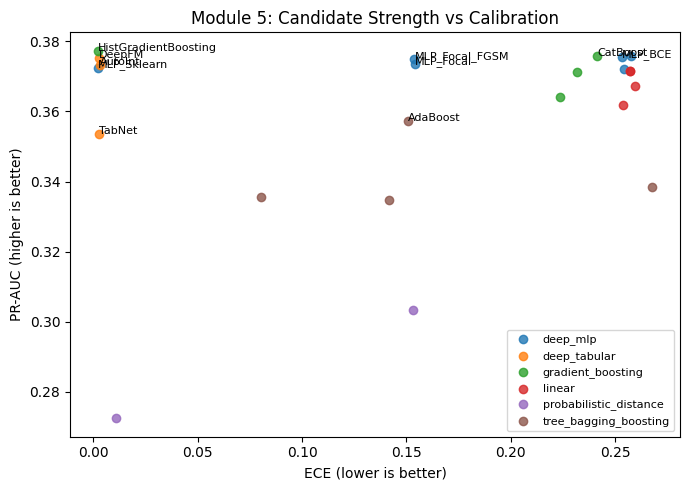

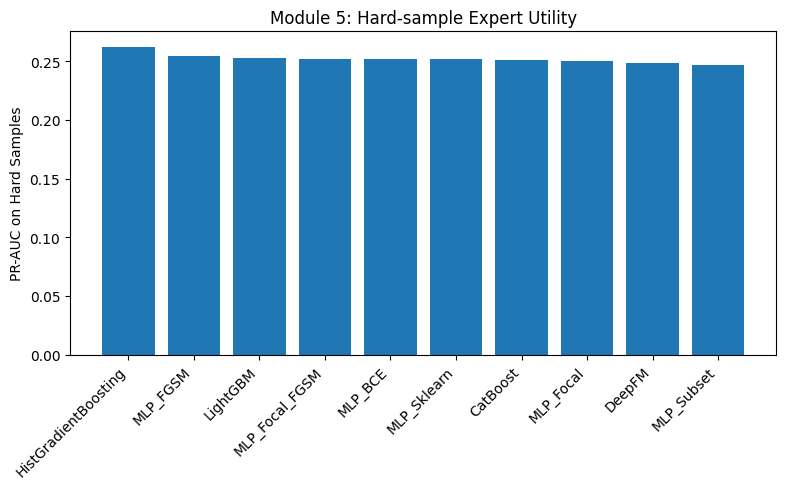


===== Module 5 Complete =====
Best recommended 2-expert set: ['HistGradientBoosting', 'MLP_BCE']
Best recommended 3-expert set: ['HistGradientBoosting', 'DeepFM', 'MLP_BCE']
Best recommended 4-expert set: ['HistGradientBoosting', 'DeepFM', 'MLP_Sklearn', 'MLP_BCE']

Saved:
- module5_model_summary.csv
- module5_model_summary_merged.csv
- module5_pairwise_diversity.csv
- module5_hardcase_summary.csv
- module5_combo2_ranking.csv
- module5_combo3_ranking.csv
- module5_combo4_ranking.csv
- module5_recommended_2_experts.csv
- module5_recommended_3_experts.csv
- module5_recommended_4_experts.csv
- module5_hardcase_scores.csv
- module5_strength_vs_calibration.(png/pdf)
- module5_hardcase_prauc.(png/pdf)
- module5_metadata.json


In [5]:
# ============================================================
# Module 5 — Expert Selection Audit
#
# Purpose:
# - Move from broad candidate screening to principled expert selection
# - Combine model strength, calibration, diversity, and hard-case behavior
#
# Inputs expected from Module 4:
# - MODULE4_RUN_DF
# - MODULE4_OOF_MATRIX
# - TAB_DIR, FIG_DIR, LOG_DIR
# - EPS
#
# Main outputs:
# - MODULE5_MODEL_SUMMARY
# - MODULE5_PAIRWISE_DIVERSITY_DF
# - MODULE5_HARDCASE_SUMMARY
# - MODULE5_RECOMMENDED_2_EXPERTS
# - MODULE5_RECOMMENDED_3_EXPERTS
# - MODULE5_RECOMMENDED_4_EXPERTS
# ============================================================

import json
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_RUN_DF",
    "MODULE4_OOF_MATRIX",
    "TAB_DIR",
    "FIG_DIR",
    "LOG_DIR",
    "EPS",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 5: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE5_TOP_K_CANDIDATES = 10     # shortlist for combination search
MODULE5_HARD_BAND_FRAC = 0.10     # top 10% hardest samples
MODULE5_DEFAULT_THRESHOLD = 0.50

# You can later tighten this manually if needed
MODULE5_EXCLUDE_MODELS = set([
    # optionally exclude obviously broken candidates here
    # "CatBoost",
])

# ------------------------------------------------------------
# Helper utilities
# ------------------------------------------------------------
def clip_probs_m5(p, eps=EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def model_family_from_results(results_df, model_name):
    row = results_df.loc[results_df["model_name"] == model_name]
    if len(row) == 0:
        return "unknown"
    return row.iloc[0]["family"]

def compute_binary_error_vector(y_true, prob, thr=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_m5(prob)
    y_hat = (prob >= thr).astype(int)
    err = (y_hat != y_true).astype(int)
    return err

def compute_pr_auc_safe(y_true, prob):
    from sklearn.metrics import average_precision_score
    return float(average_precision_score(y_true, prob))

def compute_roc_auc_safe(y_true, prob):
    from sklearn.metrics import roc_auc_score
    return float(roc_auc_score(y_true, prob))

def compute_brier_safe(y_true, prob):
    from sklearn.metrics import brier_score_loss
    return float(brier_score_loss(y_true, prob))

def compute_logloss_safe(y_true, prob):
    from sklearn.metrics import log_loss
    prob = clip_probs_m5(prob)
    return float(log_loss(y_true, prob))

def compute_ece_m5(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_m5(prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def compute_metrics_block(y_true, prob, thr=0.50):
    from sklearn.metrics import f1_score, matthews_corrcoef, precision_score, recall_score, accuracy_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_m5(prob)
    y_hat = (prob >= thr).astype(int)

    return {
        "PR_AUC": compute_pr_auc_safe(y_true, prob),
        "ROC_AUC": compute_roc_auc_safe(y_true, prob),
        "Brier": compute_brier_safe(y_true, prob),
        "NLL": compute_logloss_safe(y_true, prob),
        "ECE": compute_ece_m5(y_true, prob),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def minmax_scale_series(s, higher_is_better=True):
    s = pd.Series(s).astype(float)
    if s.nunique(dropna=False) <= 1:
        return pd.Series(np.ones(len(s)), index=s.index)
    mn, mx = s.min(), s.max()
    out = (s - mn) / (mx - mn + 1e-12)
    return out if higher_is_better else 1.0 - out

# ------------------------------------------------------------
# Section A — Build clean candidate pool
# ------------------------------------------------------------
module5_results_df = MODULE4_RUN_DF.copy()

module5_results_df = module5_results_df[
    ~module5_results_df["model_name"].isin(MODULE5_EXCLUDE_MODELS)
].reset_index(drop=True)

oof_df = MODULE4_OOF_MATRIX.copy()
y_true_dev = oof_df["y_true"].values.astype(int)

pred_cols_all = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
pred_cols = [c for c in pred_cols_all if c in set(module5_results_df["model_name"])]

if len(pred_cols) == 0:
    raise RuntimeError("No valid prediction columns available for Module 5.")

# ------------------------------------------------------------
# Section B — Candidate summary with trust-oriented score
# ------------------------------------------------------------
summary_df = module5_results_df.copy()

# Normalize a few useful axes
summary_df["norm_pr_auc"] = minmax_scale_series(summary_df["PR_AUC"], higher_is_better=True)
summary_df["norm_roc_auc"] = minmax_scale_series(summary_df["ROC_AUC"], higher_is_better=True)
summary_df["norm_brier"] = minmax_scale_series(summary_df["Brier"], higher_is_better=False)
summary_df["norm_ece"] = minmax_scale_series(summary_df["ECE"], higher_is_better=False)
summary_df["norm_mcc"] = minmax_scale_series(summary_df["MCC"], higher_is_better=True)

# Composite score: emphasize PR-AUC first, then trustworthiness
summary_df["selection_score"] = (
    0.45 * summary_df["norm_pr_auc"] +
    0.15 * summary_df["norm_roc_auc"] +
    0.15 * summary_df["norm_brier"] +
    0.15 * summary_df["norm_ece"] +
    0.10 * summary_df["norm_mcc"]
)

summary_df = summary_df.sort_values(
    ["selection_score", "PR_AUC", "ROC_AUC"],
    ascending=[False, False, False]
).reset_index(drop=True)

summary_df.to_csv(TAB_DIR / "module5_model_summary.csv", index=False)

print("===== Module 5: Model Summary =====")
display_cols = [
    c for c in [
        "model_name", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC", "selection_score"
    ] if c in summary_df.columns
]
display(summary_df[display_cols].head(15))

# ------------------------------------------------------------
# Section C — Pairwise diversity audit
# ------------------------------------------------------------
pairwise_rows = []

for m1, m2 in itertools.combinations(pred_cols, 2):
    p1 = clip_probs_m5(oof_df[m1].values)
    p2 = clip_probs_m5(oof_df[m2].values)

    err1 = compute_binary_error_vector(y_true_dev, p1, thr=MODULE5_DEFAULT_THRESHOLD)
    err2 = compute_binary_error_vector(y_true_dev, p2, thr=MODULE5_DEFAULT_THRESHOLD)

    corr = float(np.corrcoef(p1, p2)[0, 1])
    mad = float(np.mean(np.abs(p1 - p2)))

    yhat1 = (p1 >= MODULE5_DEFAULT_THRESHOLD).astype(int)
    yhat2 = (p2 >= MODULE5_DEFAULT_THRESHOLD).astype(int)
    binary_disagreement = float(np.mean(yhat1 != yhat2))

    union_errors = int(np.sum((err1 == 1) | (err2 == 1)))
    both_errors = int(np.sum((err1 == 1) & (err2 == 1)))
    error_overlap_ratio = float(both_errors / (union_errors + 1e-12))

    # "Complementary rescue": one right when the other is wrong
    rescue_rate = float(np.mean((err1 != err2).astype(int)))

    pairwise_rows.append({
        "model_1": m1,
        "family_1": model_family_from_results(summary_df, m1),
        "model_2": m2,
        "family_2": model_family_from_results(summary_df, m2),
        "pred_corr": corr,
        "mean_abs_diff": mad,
        "binary_disagreement": binary_disagreement,
        "error_overlap_ratio": error_overlap_ratio,
        "rescue_rate": rescue_rate,
    })

pairwise_div_df = pd.DataFrame(pairwise_rows).sort_values(
    ["mean_abs_diff", "rescue_rate"],
    ascending=[False, False]
).reset_index(drop=True)

pairwise_div_df.to_csv(TAB_DIR / "module5_pairwise_diversity.csv", index=False)

print("\n===== Pairwise Diversity (Top by mean_abs_diff) =====")
display(pairwise_div_df.head(20))

# ------------------------------------------------------------
# Section D — Hard-sample discovery
# ------------------------------------------------------------
# Hardness based on ensemble disagreement + boundary proximity
pred_matrix = oof_df[pred_cols].values.astype(float)
mean_p = np.mean(pred_matrix, axis=1)
std_p = np.std(pred_matrix, axis=1)
margin = np.abs(mean_p - 0.5)
entropy = -(mean_p * np.log(mean_p + EPS) + (1 - mean_p) * np.log(1 - mean_p + EPS))

hardness_score = (
    0.45 * std_p +
    0.35 * entropy +
    0.20 * (1.0 - np.clip(2.0 * margin, 0.0, 1.0))
)

hardcase_df = pd.DataFrame({
    "row_idx_dev": oof_df["row_idx_dev"].values,
    "y_true": y_true_dev,
    "mean_p": mean_p,
    "std_p": std_p,
    "margin": margin,
    "entropy": entropy,
    "hardness_score": hardness_score,
})

hard_thresh = np.quantile(hardness_score, 1.0 - MODULE5_HARD_BAND_FRAC)
hardcase_df["is_hard"] = (hardcase_df["hardness_score"] >= hard_thresh).astype(int)
hardcase_df.to_csv(PRED_DIR / "module5_hardcase_scores.csv", index=False)

n_hard = int(hardcase_df["is_hard"].sum())
print(f"\nHard-sample threshold: top {int(MODULE5_HARD_BAND_FRAC * 100)}%")
print(f"Hard samples: {n_hard:,} / {len(hardcase_df):,}")

# ------------------------------------------------------------
# Section E — Model performance on hard samples
# ------------------------------------------------------------
hard_rows = []

hard_mask = hardcase_df["is_hard"].values.astype(bool)
easy_mask = ~hard_mask

for m in pred_cols:
    p = clip_probs_m5(oof_df[m].values)

    full_metrics = compute_metrics_block(y_true_dev, p, thr=MODULE5_DEFAULT_THRESHOLD)
    hard_metrics = compute_metrics_block(y_true_dev[hard_mask], p[hard_mask], thr=MODULE5_DEFAULT_THRESHOLD)
    easy_metrics = compute_metrics_block(y_true_dev[easy_mask], p[easy_mask], thr=MODULE5_DEFAULT_THRESHOLD)

    err = compute_binary_error_vector(y_true_dev, p, thr=MODULE5_DEFAULT_THRESHOLD)
    error_concentration = float(err[hard_mask].sum() / max(err.sum(), 1))

    hard_rows.append({
        "model_name": m,
        "family": model_family_from_results(summary_df, m),
        "PR_AUC_full": full_metrics["PR_AUC"],
        "PR_AUC_hard": hard_metrics["PR_AUC"],
        "PR_AUC_easy": easy_metrics["PR_AUC"],
        "ROC_AUC_hard": hard_metrics["ROC_AUC"],
        "ECE_hard": hard_metrics["ECE"],
        "MCC_hard": hard_metrics["MCC"],
        "error_concentration_in_hard_band": error_concentration,
    })

hard_summary_df = pd.DataFrame(hard_rows).sort_values(
    ["PR_AUC_hard", "ROC_AUC_hard"],
    ascending=[False, False]
).reset_index(drop=True)

hard_summary_df.to_csv(TAB_DIR / "module5_hardcase_summary.csv", index=False)

print("\n===== Hard-case Summary =====")
display(hard_summary_df.head(15))

# ------------------------------------------------------------
# Section F — Merge summary + hard-case utility
# ------------------------------------------------------------
model_summary_merged = summary_df.merge(
    hard_summary_df[[
        "model_name",
        "PR_AUC_hard",
        "ROC_AUC_hard",
        "ECE_hard",
        "MCC_hard",
        "error_concentration_in_hard_band",
    ]],
    on="model_name",
    how="left"
)

# Add another ranking score that includes hard-case skill
model_summary_merged["norm_pr_auc_hard"] = minmax_scale_series(model_summary_merged["PR_AUC_hard"], higher_is_better=True)
model_summary_merged["norm_ece_hard"] = minmax_scale_series(model_summary_merged["ECE_hard"], higher_is_better=False)

model_summary_merged["expert_readiness_score"] = (
    0.35 * model_summary_merged["norm_pr_auc"] +
    0.10 * model_summary_merged["norm_roc_auc"] +
    0.10 * model_summary_merged["norm_brier"] +
    0.10 * model_summary_merged["norm_ece"] +
    0.10 * model_summary_merged["norm_pr_auc_hard"] +
    0.10 * model_summary_merged["norm_ece_hard"] +
    0.15 * model_summary_merged["norm_mcc"]
)

model_summary_merged = model_summary_merged.sort_values(
    ["expert_readiness_score", "PR_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

model_summary_merged.to_csv(TAB_DIR / "module5_model_summary_merged.csv", index=False)

print("\n===== Expert Readiness Ranking =====")
display(model_summary_merged[[
    "model_name", "family", "PR_AUC", "Brier", "ECE",
    "PR_AUC_hard", "ECE_hard", "expert_readiness_score"
]].head(15))

# ------------------------------------------------------------
# Section G — Combination search
# ------------------------------------------------------------
# Search among top-k candidates only to stay practical
candidate_shortlist = model_summary_merged["model_name"].head(MODULE5_TOP_K_CANDIDATES).tolist()

def combo_diversity_score(combo, pairwise_df):
    if len(combo) <= 1:
        return 0.0

    sub = pairwise_df[
        pairwise_df["model_1"].isin(combo) & pairwise_df["model_2"].isin(combo)
    ].copy()

    if len(sub) == 0:
        return 0.0

    # Reward disagreement/rescue, penalize high error overlap and high corr
    score = (
        0.35 * sub["mean_abs_diff"].mean() +
        0.25 * sub["binary_disagreement"].mean() +
        0.25 * sub["rescue_rate"].mean() +
        0.10 * (1.0 - sub["error_overlap_ratio"].mean()) +
        0.05 * (1.0 - sub["pred_corr"].mean())
    )
    return float(score)

def combo_strength_score(combo, summary_merged_df):
    sub = summary_merged_df[summary_merged_df["model_name"].isin(combo)].copy()
    if len(sub) == 0:
        return 0.0
    return float(sub["expert_readiness_score"].mean())

def combo_family_diversity_bonus(combo, summary_merged_df):
    sub = summary_merged_df[summary_merged_df["model_name"].isin(combo)].copy()
    n_families = sub["family"].nunique()
    return float(n_families / max(len(combo), 1))

def evaluate_combinations(combo_size, shortlist, summary_merged_df, pairwise_df):
    rows = []
    for combo in itertools.combinations(shortlist, combo_size):
        combo = list(combo)

        strength = combo_strength_score(combo, summary_merged_df)
        diversity = combo_diversity_score(combo, pairwise_df)
        family_bonus = combo_family_diversity_bonus(combo, summary_merged_df)

        total_score = (
            0.55 * strength +
            0.35 * diversity +
            0.10 * family_bonus
        )

        rows.append({
            "combo_size": combo_size,
            "experts": " | ".join(combo),
            "strength_score": strength,
            "diversity_score": diversity,
            "family_bonus": family_bonus,
            "combo_total_score": total_score,
        })

    out = pd.DataFrame(rows).sort_values(
        ["combo_total_score", "diversity_score", "strength_score"],
        ascending=[False, False, False]
    ).reset_index(drop=True)
    return out

combo2_df = evaluate_combinations(2, candidate_shortlist, model_summary_merged, pairwise_div_df)
combo3_df = evaluate_combinations(3, candidate_shortlist, model_summary_merged, pairwise_div_df)
combo4_df = evaluate_combinations(4, candidate_shortlist, model_summary_merged, pairwise_div_df)

combo2_df.to_csv(TAB_DIR / "module5_combo2_ranking.csv", index=False)
combo3_df.to_csv(TAB_DIR / "module5_combo3_ranking.csv", index=False)
combo4_df.to_csv(TAB_DIR / "module5_combo4_ranking.csv", index=False)

print("\n===== Best 2-expert sets =====")
display(combo2_df.head(10))

print("\n===== Best 3-expert sets =====")
display(combo3_df.head(10))

print("\n===== Best 4-expert sets =====")
display(combo4_df.head(10))

# ------------------------------------------------------------
# Section H — Recommended final sets
# ------------------------------------------------------------
recommended_2 = combo2_df.head(5).copy()
recommended_3 = combo3_df.head(5).copy()
recommended_4 = combo4_df.head(5).copy()

recommended_2.to_csv(TAB_DIR / "module5_recommended_2_experts.csv", index=False)
recommended_3.to_csv(TAB_DIR / "module5_recommended_3_experts.csv", index=False)
recommended_4.to_csv(TAB_DIR / "module5_recommended_4_experts.csv", index=False)

# Parse best combos into Python lists for later modules
def parse_combo_string(s):
    return [x.strip() for x in str(s).split("|")]

MODULE5_RECOMMENDED_2_EXPERTS = parse_combo_string(recommended_2.iloc[0]["experts"])
MODULE5_RECOMMENDED_3_EXPERTS = parse_combo_string(recommended_3.iloc[0]["experts"])
MODULE5_RECOMMENDED_4_EXPERTS = parse_combo_string(recommended_4.iloc[0]["experts"])

# Keep merged summary for next modules
MODULE5_MODEL_SUMMARY = model_summary_merged.copy()
MODULE5_PAIRWISE_DIVERSITY_DF = pairwise_div_df.copy()
MODULE5_HARDCASE_SUMMARY = hard_summary_df.copy()
MODULE5_COMBO2_DF = combo2_df.copy()
MODULE5_COMBO3_DF = combo3_df.copy()
MODULE5_COMBO4_DF = combo4_df.copy()
MODULE5_HARDCASE_DF = hardcase_df.copy()

# ------------------------------------------------------------
# Section I — Lightweight figures
# ------------------------------------------------------------
# 1) PR-AUC vs ECE scatter
plot_df = MODULE5_MODEL_SUMMARY.copy()

plt.figure(figsize=(7, 5))
for fam in sorted(plot_df["family"].dropna().unique().tolist()):
    sub = plot_df[plot_df["family"] == fam]
    plt.scatter(sub["ECE"], sub["PR_AUC"], label=fam, alpha=0.8)

for _, r in plot_df.head(10).iterrows():
    plt.text(r["ECE"], r["PR_AUC"], r["model_name"], fontsize=8)

plt.xlabel("ECE (lower is better)")
plt.ylabel("PR-AUC (higher is better)")
plt.title("Module 5: Candidate Strength vs Calibration")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "module5_strength_vs_calibration.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "module5_strength_vs_calibration.pdf", dpi=300, bbox_inches="tight")
plt.show()

# 2) Hard-case PR-AUC bar chart (top 10)
hard_plot_df = MODULE5_HARDCASE_SUMMARY.sort_values("PR_AUC_hard", ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.bar(hard_plot_df["model_name"], hard_plot_df["PR_AUC_hard"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("PR-AUC on Hard Samples")
plt.title("Module 5: Hard-sample Expert Utility")
plt.tight_layout()
plt.savefig(FIG_DIR / "module5_hardcase_prauc.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "module5_hardcase_prauc.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Section J — Metadata
# ------------------------------------------------------------
module5_meta = {
    "top_k_candidates_for_combo_search": MODULE5_TOP_K_CANDIDATES,
    "hard_band_fraction": MODULE5_HARD_BAND_FRAC,
    "default_threshold": MODULE5_DEFAULT_THRESHOLD,
    "excluded_models": sorted(list(MODULE5_EXCLUDE_MODELS)),
    "recommended_2_experts": MODULE5_RECOMMENDED_2_EXPERTS,
    "recommended_3_experts": MODULE5_RECOMMENDED_3_EXPERTS,
    "recommended_4_experts": MODULE5_RECOMMENDED_4_EXPERTS,
}

with open(LOG_DIR / "module5_metadata.json", "w", encoding="utf-8") as f:
    json.dump(module5_meta, f, indent=2)

# ------------------------------------------------------------
# Final prints
# ------------------------------------------------------------
print("\n===== Module 5 Complete =====")
print("Best recommended 2-expert set:", MODULE5_RECOMMENDED_2_EXPERTS)
print("Best recommended 3-expert set:", MODULE5_RECOMMENDED_3_EXPERTS)
print("Best recommended 4-expert set:", MODULE5_RECOMMENDED_4_EXPERTS)

print("\nSaved:")
print("- module5_model_summary.csv")
print("- module5_model_summary_merged.csv")
print("- module5_pairwise_diversity.csv")
print("- module5_hardcase_summary.csv")
print("- module5_combo2_ranking.csv")
print("- module5_combo3_ranking.csv")
print("- module5_combo4_ranking.csv")
print("- module5_recommended_2_experts.csv")
print("- module5_recommended_3_experts.csv")
print("- module5_recommended_4_experts.csv")
print("- module5_hardcase_scores.csv")
print("- module5_strength_vs_calibration.(png/pdf)")
print("- module5_hardcase_prauc.(png/pdf)")
print("- module5_metadata.json")

===== Regime Distribution =====
regime
easy      101472
medium     81177
hard       20295
Name: count, dtype: int64

===== Overall Expert Wins =====


,model_name,win_count,win_rate
0,GaussianNB,83579,0.411833
1,KNN,78274,0.385693
2,MLP_Sklearn,9474,0.046683
3,TabNet,9075,0.044717
4,HistGradientBoosting,5584,0.027515
5,AutoInt,4354,0.021454
6,DecisionTree,2958,0.014575
7,DeepFM,1846,0.009096
8,XGBoost,1241,0.006115
9,SGD_LogLoss,1227,0.006046



===== Expert Wins by Regime =====


,regime,best_expert,count,total_regime,win_rate
8,easy,KNN,55824,101472,0.550142
6,easy,GaussianNB,40306,101472,0.397213
17,easy,MLP_Sklearn,1286,101472,0.012673
21,easy,TabNet,970,101472,0.009559
1,easy,AutoInt,843,101472,0.008308
7,easy,HistGradientBoosting,474,101472,0.004671
3,easy,DecisionTree,362,101472,0.003567
0,easy,AdaBoost,317,101472,0.003124
4,easy,DeepFM,276,101472,0.002720
19,easy,RandomForest,172,101472,0.001695



===== Top Experts per Regime =====


,regime,best_expert,count,total_regime,win_rate
8,easy,KNN,55824,101472,0.550142
6,easy,GaussianNB,40306,101472,0.397213
17,easy,MLP_Sklearn,1286,101472,0.012673
28,hard,GaussianNB,6329,20295,0.311850
30,hard,KNN,4911,20295,0.241981
41,hard,TabNet,2163,20295,0.106578
49,medium,GaussianNB,36944,81177,0.455104
51,medium,KNN,17539,81177,0.216059
59,medium,MLP_Sklearn,6136,81177,0.075588



===== Regime Performance =====


,model_name,regime,PR_AUC,N
21,HistGradientBoosting,easy,0.047453,101472
3,AutoInt,easy,0.046717,101472
30,LogReg_ElasticNet,easy,0.046618,101472
33,LogReg_L2,easy,0.046604,101472
42,MLP_FGSM,easy,0.046139,101472
12,DeepFM,easy,0.046136,101472
51,MLP_Sklearn,easy,0.045759,101472
39,MLP_BCE,easy,0.045444,101472
6,CatBoost,easy,0.043900,101472
27,LightGBM,easy,0.043850,101472



===== Hard-case Specialization =====


,model_name,hard_win_rate
0,GaussianNB,0.311850
1,KNN,0.241981
2,TabNet,0.106578
3,MLP_Sklearn,0.101109
4,HistGradientBoosting,0.059177
5,AutoInt,0.034491
6,DecisionTree,0.032028
7,DeepFM,0.021089
8,XGBoost,0.018428
9,SGD_LogLoss,0.014634


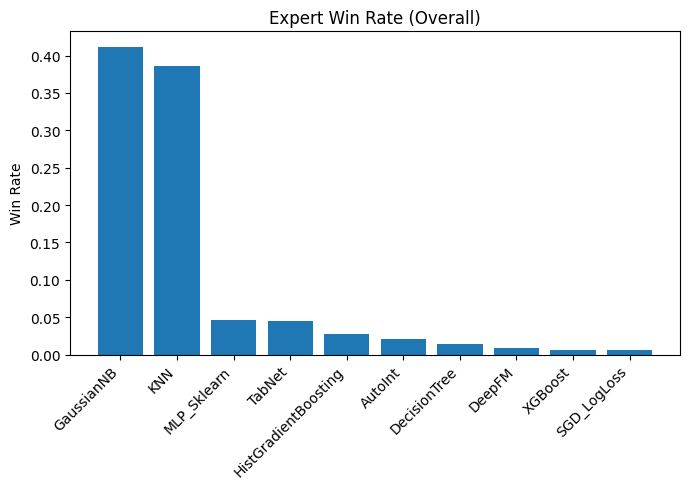

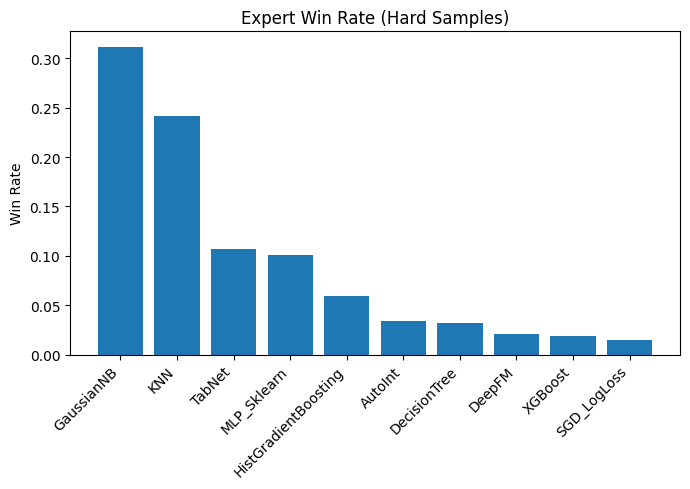


===== Module 6 Complete =====
Saved:
- module6_expert_win_overall.csv
- module6_expert_win_by_regime.csv
- module6_top_experts_per_regime.csv
- module6_regime_performance.csv
- module6_hard_specialization.csv
- module6_win_overall.(png/pdf)
- module6_win_hard.(png/pdf)


In [6]:
# ============================================================
# Module 6 — Sample-Type Discovery & Expert Win Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_MODEL_SUMMARY",
    "MODULE5_HARDCASE_DF",
    "TAB_DIR",
    "FIG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 6: {missing}")

oof_df = MODULE4_OOF_MATRIX.copy()
y_true = oof_df["y_true"].values.astype(int)

pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]

# ------------------------------------------------------------
# Section A — Difficulty Regimes
# ------------------------------------------------------------

# reuse hardness
hard_df = MODULE5_HARDCASE_DF.copy()

# create 3 regimes
hard_df["regime"] = "medium"
hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

print("===== Regime Distribution =====")
print(hard_df["regime"].value_counts())

# ------------------------------------------------------------
# Section B — Per-sample expert win
# ------------------------------------------------------------

# Define loss: binary log loss
EPS = 1e-12
def logloss_per_sample(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

# compute per-sample losses
loss_matrix = {}

for m in pred_cols:
    p = oof_df[m].values
    loss_matrix[m] = logloss_per_sample(y_true, p)

loss_df = pd.DataFrame(loss_matrix)

# best expert per sample
best_expert = loss_df.idxmin(axis=1)

win_df = pd.DataFrame({
    "row_idx_dev": oof_df["row_idx_dev"],
    "y_true": y_true,
    "best_expert": best_expert
})

# merge regime
win_df = win_df.merge(hard_df[["row_idx_dev", "regime", "hardness_score"]], on="row_idx_dev", how="left")

# ------------------------------------------------------------
# Section C — Overall expert win distribution
# ------------------------------------------------------------

win_counts = win_df["best_expert"].value_counts().reset_index()
win_counts.columns = ["model_name", "win_count"]
win_counts["win_rate"] = win_counts["win_count"] / len(win_df)

win_counts.to_csv(TAB_DIR / "module6_expert_win_overall.csv", index=False)

print("\n===== Overall Expert Wins =====")
display(win_counts.head(10))

# ------------------------------------------------------------
# Section D — Expert win by regime
# ------------------------------------------------------------

win_by_regime = (
    win_df.groupby(["regime", "best_expert"])
    .size()
    .reset_index(name="count")
)

# normalize
win_by_regime["total_regime"] = win_by_regime.groupby("regime")["count"].transform("sum")
win_by_regime["win_rate"] = win_by_regime["count"] / win_by_regime["total_regime"]

win_by_regime.to_csv(TAB_DIR / "module6_expert_win_by_regime.csv", index=False)

print("\n===== Expert Wins by Regime =====")
display(win_by_regime.sort_values(["regime", "win_rate"], ascending=[True, False]).head(20))

# ------------------------------------------------------------
# Section E — Top experts per regime
# ------------------------------------------------------------

top_experts_per_regime = (
    win_by_regime.sort_values(["regime", "win_rate"], ascending=[True, False])
    .groupby("regime")
    .head(3)
)

print("\n===== Top Experts per Regime =====")
display(top_experts_per_regime)

top_experts_per_regime.to_csv(TAB_DIR / "module6_top_experts_per_regime.csv", index=False)

# ------------------------------------------------------------
# Section F — Performance per regime
# ------------------------------------------------------------

def compute_pr_auc(y, p):
    from sklearn.metrics import average_precision_score
    return average_precision_score(y, p)

regime_perf_rows = []

for m in pred_cols:
    p = oof_df[m].values
    
    for regime in ["easy", "medium", "hard"]:
        mask = win_df["regime"] == regime
        if mask.sum() == 0:
            continue
        
        pr = compute_pr_auc(y_true[mask], p[mask])
        
        regime_perf_rows.append({
            "model_name": m,
            "regime": regime,
            "PR_AUC": pr,
            "N": int(mask.sum())
        })

regime_perf_df = pd.DataFrame(regime_perf_rows)

regime_perf_df.to_csv(TAB_DIR / "module6_regime_performance.csv", index=False)

print("\n===== Regime Performance =====")
display(regime_perf_df.sort_values(["regime", "PR_AUC"], ascending=[True, False]).head(20))

# ------------------------------------------------------------
# Section G — Hard-case specialization score
# ------------------------------------------------------------

hard_mask = win_df["regime"] == "hard"

hard_win_counts = (
    win_df[hard_mask]["best_expert"]
    .value_counts(normalize=True)
    .reset_index()
)

hard_win_counts.columns = ["model_name", "hard_win_rate"]
hard_win_counts.to_csv(TAB_DIR / "module6_hard_specialization.csv", index=False)

print("\n===== Hard-case Specialization =====")
display(hard_win_counts.head(10))

# ------------------------------------------------------------
# Section H — Visualization
# ------------------------------------------------------------

# 1. Win distribution
plt.figure(figsize=(7,5))
plt.bar(win_counts["model_name"].head(10), win_counts["win_rate"].head(10))
plt.xticks(rotation=45, ha="right")
plt.title("Expert Win Rate (Overall)")
plt.ylabel("Win Rate")
plt.tight_layout()
plt.savefig(FIG_DIR / "module6_win_overall.png", dpi=300)
plt.savefig(FIG_DIR / "module6_win_overall.pdf", dpi=300)
plt.show()

# 2. Hard-case win
plt.figure(figsize=(7,5))
plt.bar(hard_win_counts["model_name"].head(10), hard_win_counts["hard_win_rate"].head(10))
plt.xticks(rotation=45, ha="right")
plt.title("Expert Win Rate (Hard Samples)")
plt.ylabel("Win Rate")
plt.tight_layout()
plt.savefig(FIG_DIR / "module6_win_hard.png", dpi=300)
plt.savefig(FIG_DIR / "module6_win_hard.pdf", dpi=300)
plt.show()

# ------------------------------------------------------------
# Final
# ------------------------------------------------------------

MODULE6_WIN_DF = win_df.copy()
MODULE6_REGIME_PERF = regime_perf_df.copy()

print("\n===== Module 6 Complete =====")
print("Saved:")
print("- module6_expert_win_overall.csv")
print("- module6_expert_win_by_regime.csv")
print("- module6_top_experts_per_regime.csv")
print("- module6_regime_performance.csv")
print("- module6_hard_specialization.csv")
print("- module6_win_overall.(png/pdf)")
print("- module6_win_hard.(png/pdf)")

Epoch 01 | train_loss=0.271915 | val_loss=0.263497
Epoch 02 | train_loss=0.265276 | val_loss=0.263035
Epoch 03 | train_loss=0.265095 | val_loss=0.262882
Epoch 04 | train_loss=0.264837 | val_loss=0.262824
Epoch 05 | train_loss=0.264606 | val_loss=0.262774
Epoch 06 | train_loss=0.265147 | val_loss=0.262704
Epoch 07 | train_loss=0.264717 | val_loss=0.262604
Epoch 08 | train_loss=0.264451 | val_loss=0.262581
Epoch 09 | train_loss=0.264068 | val_loss=0.262601
Epoch 10 | train_loss=0.264483 | val_loss=0.262581
Epoch 11 | train_loss=0.264064 | val_loss=0.262517
Epoch 12 | train_loss=0.263894 | val_loss=0.262479
Epoch 13 | train_loss=0.264072 | val_loss=0.262556
Epoch 14 | train_loss=0.264167 | val_loss=0.262460
Epoch 15 | train_loss=0.264118 | val_loss=0.262432
Epoch 16 | train_loss=0.264009 | val_loss=0.262441
Epoch 17 | train_loss=0.263624 | val_loss=0.262470
Epoch 18 | train_loss=0.263903 | val_loss=0.262450
Epoch 19 | train_loss=0.263939 | val_loss=0.262461
Epoch 20 | train_loss=0.263472 

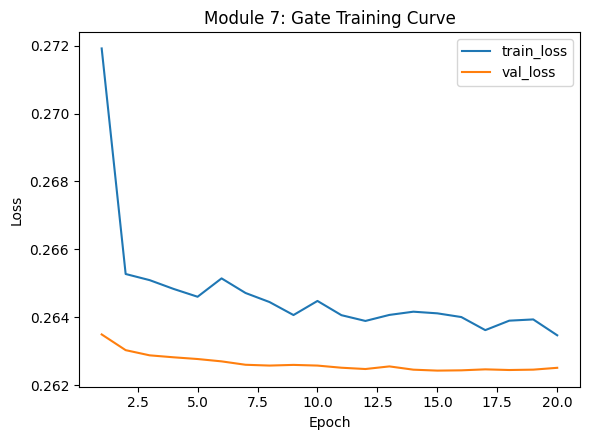

<Figure size 700x500 with 0 Axes>

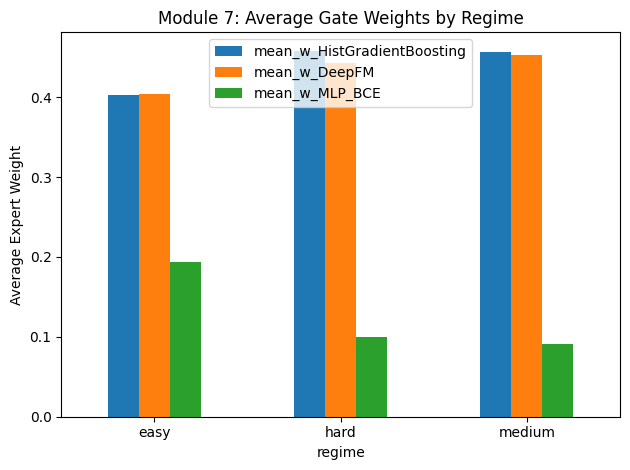


===== Module 7 Complete =====
Selected experts: ['HistGradientBoosting', 'DeepFM', 'MLP_BCE']
DEV metrics:


,model,setting,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,TrustAwareGate,DEV_OOF,0.380329,0.85065,0.070709,0.240682,0.025828,0.343823,0.548185,0.422594,0.858912,0.35927,0.26,0.150165,0.120011,202944


Saved:
- module7_gate_training_history.csv
- module7_gate_dev_metrics.csv
- module7_gate_regime_weights.csv
- module7_gate_dev_predictions.csv
- module7_gate_weights_dev.csv
- module7_gate_training_curve.(png/pdf)
- module7_gate_weights_by_regime.(png/pdf)
- module7_gate_metadata.json


In [7]:
# ============================================================
# Module 7 — Trust-Aware Adaptive Gating
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_RESULTS",
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "X_test_df",
    "y_dev_arr",
    "y_test_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
    "EPS",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 7: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
FINAL_EXPERT_SET_A = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
FINAL_EXPERT_SET_B = ["HistGradientBoosting", "DeepFM", "MLP_Sklearn"]

# choose one to run first
FINAL_SELECTED_EXPERTS = FINAL_EXPERT_SET_A

GATE_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
GATE_CONTEXT_COLS = [c for c in GATE_CONTEXT_COLS if c in X_dev_df.columns]

USE_HARDNESS_FLAG = True

GATE_HIDDEN_DIMS = (64, 32)
GATE_DROPOUT = 0.10
GATE_LR = 1e-3
GATE_WEIGHT_DECAY = 1e-5
GATE_EPOCHS = 20
GATE_BATCH_SIZE = 2048
GATE_PATIENCE = 5

LAMBDA_SPEC = 0.10
LAMBDA_SPARSE = 0.001

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_m7(p, eps=EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def build_pairwise_absdiff_df(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def compute_entropy_binary(p):
    p = clip_probs_m7(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def build_gate_features(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    # raw expert predictions
    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    # sorted predictions
    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    pairwise_df = build_pairwise_absdiff_df(P)
    feat = pd.concat([feat, pairwise_df], axis=1)

    # context
    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    # hardness / regime
    if hardcase_df is not None and USE_HARDNESS_FLAG:
        local_hard = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = local_hard["hardness_score"].values
        feat["is_hard"] = local_hard["is_hard"].values.astype(float)

        if "regime" in local_hard.columns:
            feat["regime_easy"] = (local_hard["regime"] == "easy").astype(float)
            feat["regime_medium"] = (local_hard["regime"] == "medium").astype(float)
            feat["regime_hard"] = (local_hard["regime"] == "hard").astype(float)

    return feat

def per_sample_binary_logloss(y_true, p):
    p = clip_probs_m7(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets(y_true, expert_pred_df, temperature=5.0):
    """
    Create a soft routing target from inverse expert losses.
    Lower loss => higher target weight.
    """
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T  # shape [N, K]

    # convert to preference scores
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def compute_metrics_m7(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_m7(prob)
    y_hat = (prob >= threshold).astype(int)

    # ECE
    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def best_f1_threshold(y_true, prob):
    from sklearn.metrics import f1_score
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_m7(prob)
    grid = np.linspace(0.05, 0.95, 181)

    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        f1 = f1_score(y_true, (prob >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, best_f1

# ------------------------------------------------------------
# Build development expert prediction matrix
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy()
y_dev_np = np.asarray(y_dev_arr).astype(int)

for e in FINAL_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert {e} not found in OOF matrix.")

dev_expert_pred_df = oof_df[FINAL_SELECTED_EXPERTS].copy().reset_index(drop=True)
dev_context_df = X_dev_df[GATE_CONTEXT_COLS].reset_index(drop=True).copy()

dev_hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in dev_hard_df.columns:
    dev_hard_df["regime"] = "medium"
    dev_hard_df.loc[dev_hard_df["hardness_score"] >= dev_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    dev_hard_df.loc[dev_hard_df["hardness_score"] <= dev_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

dev_gate_feat_df = build_gate_features(
    expert_pred_df=dev_expert_pred_df,
    context_df=dev_context_df,
    hardcase_df=dev_hard_df
)

dev_soft_targets = build_soft_specialization_targets(y_dev_np, dev_expert_pred_df)

# ------------------------------------------------------------
# Build holdout expert prediction matrix
# ------------------------------------------------------------
# Refit sklearn-style selected experts on full dev and predict holdout
def fit_full_selected_experts_and_get_holdout_predictions(selected_experts):
    hold_pred_df = pd.DataFrame(index=np.arange(len(y_test_arr)))

    for expert_name in selected_experts:
        print(f"Fitting full expert for holdout: {expert_name}")

        if expert_name not in MODULE4_RESULTS:
            raise ValueError(f"{expert_name} not present in MODULE4_RESULTS")

        # We use the same logic from module 4 naming conventions
        if expert_name == "HistGradientBoosting":
            model_factory = lambda: HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_depth=6,
                max_iter=300,
                min_samples_leaf=40,
                random_state=42
            )
            fit_obj = fit_full_model_and_predict_holdout(
                model_name=expert_name,
                model_factory=model_factory,
                preprocess_mode="ml",
            )

        elif expert_name == "MLP_Sklearn":
            model_factory = lambda: MLPClassifier(
                hidden_layer_sizes=(128, 64),
                activation="relu",
                alpha=1e-4,
                learning_rate_init=1e-3,
                max_iter=10,
                random_state=42
            )
            fit_obj = fit_full_model_and_predict_holdout(
                model_name=expert_name,
                model_factory=model_factory,
                preprocess_mode="dl",
            )

        elif expert_name == "DeepFM":
            raise NotImplementedError(
                "For DeepFM holdout inference, reuse your deep custom fold/full-fit function pattern "
                "or load full-dev trained DeepFM separately."
            )

        elif expert_name == "MLP_BCE":
            raise NotImplementedError(
                "For MLP_BCE holdout inference, add a full-dev training helper using your torch MLP."
            )

        else:
            raise NotImplementedError(f"Holdout full fit not yet added for expert: {expert_name}")

        hold_pred_df[expert_name] = fit_obj["holdout_pred"]

    return hold_pred_df

# NOTE:
# For now, we will fully run DEV gate training first.
# Holdout execution is scaffolded below; add full-fit helpers for DeepFM / MLP_BCE next.

# ------------------------------------------------------------
# Standardize gate features
# ------------------------------------------------------------
gate_scaler = StandardScaler()
X_gate_dev = gate_scaler.fit_transform(dev_gate_feat_df.values).astype(np.float32)
y_gate_dev = y_dev_np.astype(np.float32).reshape(-1, 1)
expert_dev_probs = dev_expert_pred_df.values.astype(np.float32)
soft_target_dev = dev_soft_targets.astype(np.float32)

# split gate train/val
from sklearn.model_selection import train_test_split
gate_idx = np.arange(len(y_gate_dev))

idx_tr, idx_val = train_test_split(
    gate_idx,
    test_size=0.15,
    stratify=y_dev_np,
    random_state=42
)

X_tr = X_gate_dev[idx_tr]
X_val = X_gate_dev[idx_val]
y_tr = y_gate_dev[idx_tr]
y_val = y_gate_dev[idx_val]
expert_tr = expert_dev_probs[idx_tr]
expert_val = expert_dev_probs[idx_val]
soft_tr = soft_target_dev[idx_tr]
soft_val = soft_target_dev[idx_val]

# ------------------------------------------------------------
# Gate model
# ------------------------------------------------------------
class TrustGateNet(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev, n_experts)

    def forward(self, x):
        z = self.backbone(x)
        logits = self.head(z)
        weights = torch.softmax(logits, dim=1)
        return weights, logits

def gate_entropy(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

input_dim = X_gate_dev.shape[1]
n_experts = len(FINAL_SELECTED_EXPERTS)

gate_model = TrustGateNet(
    input_dim=input_dim,
    n_experts=n_experts,
    hidden_dims=GATE_HIDDEN_DIMS,
    dropout=GATE_DROPOUT
)

if USE_GPU:
    gate_model = gate_model.to(PRIMARY_DEVICE)

optimizer = torch.optim.Adam(
    gate_model.parameters(),
    lr=GATE_LR,
    weight_decay=GATE_WEIGHT_DECAY
)

bce_loss_fn = nn.BCELoss()
kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------
class GateDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.expert_probs[idx],
            self.soft_targets[idx]
        )

train_ds = GateDataset(X_tr, y_tr, expert_tr, soft_tr)
val_ds = GateDataset(X_val, y_val, expert_val, soft_val)

train_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=GATE_BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

val_loader = torch.utils.data.DataLoader(
    val_ds,
    batch_size=GATE_BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

# ------------------------------------------------------------
# Train gate
# ------------------------------------------------------------
best_state = copy.deepcopy(gate_model.state_dict())
best_val_loss = np.inf
no_improve = 0
history_rows = []

for epoch in range(GATE_EPOCHS):
    gate_model.train()
    train_losses = []

    for xb, yb, pb, sb in train_loader:
        if USE_GPU:
            xb = xb.to(PRIMARY_DEVICE)
            yb = yb.to(PRIMARY_DEVICE)
            pb = pb.to(PRIMARY_DEVICE)
            sb = sb.to(PRIMARY_DEVICE)

        optimizer.zero_grad()

        weights, logits = gate_model(xb)
        final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
        final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

        loss_bce = bce_loss_fn(final_prob, yb)

        log_w = torch.log(torch.clamp(weights, 1e-8, 1.0))
        loss_spec = kl_loss_fn(log_w, sb)

        loss_sparse = gate_entropy(weights)

        loss = loss_bce + LAMBDA_SPEC * loss_spec + LAMBDA_SPARSE * loss_sparse
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # validation
    gate_model.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb, pb, sb in val_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            weights, logits = gate_model(xb)
            final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
            final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

            loss_bce = bce_loss_fn(final_prob, yb)
            log_w = torch.log(torch.clamp(weights, 1e-8, 1.0))
            loss_spec = kl_loss_fn(log_w, sb)
            loss_sparse = gate_entropy(weights)

            loss = loss_bce + LAMBDA_SPEC * loss_spec + LAMBDA_SPARSE * loss_sparse
            val_losses.append(loss.item())

    mean_train = float(np.mean(train_losses))
    mean_val = float(np.mean(val_losses))

    history_rows.append({
        "epoch": epoch + 1,
        "train_loss": mean_train,
        "val_loss": mean_val,
    })

    print(f"Epoch {epoch+1:02d} | train_loss={mean_train:.6f} | val_loss={mean_val:.6f}")

    if mean_val < best_val_loss:
        best_val_loss = mean_val
        best_state = copy.deepcopy(gate_model.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= GATE_PATIENCE:
        print("Early stopping triggered.")
        break

gate_model.load_state_dict(best_state)

history_df = pd.DataFrame(history_rows)
history_df.to_csv(TAB_DIR / "module7_gate_training_history.csv", index=False)

# ------------------------------------------------------------
# DEV full inference
# ------------------------------------------------------------
gate_model.eval()
with torch.no_grad():
    X_all_tensor = torch.tensor(X_gate_dev, dtype=torch.float32)
    P_all_tensor = torch.tensor(expert_dev_probs, dtype=torch.float32)

    if USE_GPU:
        X_all_tensor = X_all_tensor.to(PRIMARY_DEVICE)
        P_all_tensor = P_all_tensor.to(PRIMARY_DEVICE)

    dev_weights_tensor, _ = gate_model(X_all_tensor)
    dev_final_prob_tensor = torch.sum(dev_weights_tensor * P_all_tensor, dim=1)

    dev_weights = dev_weights_tensor.detach().cpu().numpy()
    dev_final_prob = dev_final_prob_tensor.detach().cpu().numpy()

dev_best_thr, dev_best_f1 = best_f1_threshold(y_dev_np, dev_final_prob)
dev_metrics = compute_metrics_m7(y_dev_np, dev_final_prob, threshold=dev_best_thr)

dev_metrics_df = pd.DataFrame([{
    "model": "TrustAwareGate",
    "setting": "DEV_OOF",
    **dev_metrics
}])
dev_metrics_df.to_csv(TAB_DIR / "module7_gate_dev_metrics.csv", index=False)

# save dev predictions
dev_pred_df = pd.DataFrame({
    "row_idx_dev": np.arange(len(y_dev_np)),
    "y_true": y_dev_np,
    "pred": dev_final_prob,
})
dev_pred_df.to_csv(PRED_DIR / "module7_gate_dev_predictions.csv", index=False)

# save dev weights
dev_weight_df = pd.DataFrame(dev_weights, columns=[f"w_{e}" for e in FINAL_SELECTED_EXPERTS])
dev_weight_df["row_idx_dev"] = np.arange(len(dev_weight_df))
dev_weight_df["dominant_expert"] = np.array(FINAL_SELECTED_EXPERTS)[np.argmax(dev_weights, axis=1)]
dev_weight_df["gate_entropy"] = -np.sum(np.clip(dev_weights, 1e-8, 1.0) * np.log(np.clip(dev_weights, 1e-8, 1.0)), axis=1)
dev_weight_df.to_csv(PRED_DIR / "module7_gate_weights_dev.csv", index=False)

# ------------------------------------------------------------
# Regime-level gate behavior
# ------------------------------------------------------------
dev_gate_analysis_df = dev_weight_df.merge(
    dev_hard_df[["row_idx_dev", "regime", "is_hard", "hardness_score"]],
    on="row_idx_dev",
    how="left"
)

regime_weight_rows = []
for regime, sub in dev_gate_analysis_df.groupby("regime"):
    row = {"regime": regime, "n": len(sub)}
    for e in FINAL_SELECTED_EXPERTS:
        row[f"mean_w_{e}"] = float(sub[f"w_{e}"].mean())
    row["mean_gate_entropy"] = float(sub["gate_entropy"].mean())
    regime_weight_rows.append(row)

regime_weight_df = pd.DataFrame(regime_weight_rows)
regime_weight_df.to_csv(TAB_DIR / "module7_gate_regime_weights.csv", index=False)

# ------------------------------------------------------------
# Lightweight figures
# ------------------------------------------------------------
import matplotlib.pyplot as plt

# 1. training curve
plt.figure(figsize=(6, 4.5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train_loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Module 7: Gate Training Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module7_gate_training_curve.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "module7_gate_training_curve.pdf", dpi=300, bbox_inches="tight")
plt.show()

# 2. regime weights
plot_cols = [f"mean_w_{e}" for e in FINAL_SELECTED_EXPERTS]
regime_plot_df = regime_weight_df.set_index("regime")[plot_cols]

plt.figure(figsize=(7, 5))
regime_plot_df.plot(kind="bar")
plt.ylabel("Average Expert Weight")
plt.title("Module 7: Average Gate Weights by Regime")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "module7_gate_weights_by_regime.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "module7_gate_weights_by_regime.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
module7_meta = {
    "selected_experts": FINAL_SELECTED_EXPERTS,
    "context_cols": GATE_CONTEXT_COLS,
    "use_hardness_flag": USE_HARDNESS_FLAG,
    "hidden_dims": GATE_HIDDEN_DIMS,
    "dropout": GATE_DROPOUT,
    "lr": GATE_LR,
    "weight_decay": GATE_WEIGHT_DECAY,
    "epochs": GATE_EPOCHS,
    "batch_size": GATE_BATCH_SIZE,
    "patience": GATE_PATIENCE,
    "lambda_spec": LAMBDA_SPEC,
    "lambda_sparse": LAMBDA_SPARSE,
    "dev_best_threshold": dev_best_thr,
}
with open(LOG_DIR / "module7_gate_metadata.json", "w", encoding="utf-8") as f:
    json.dump(module7_meta, f, indent=2)

print("\n===== Module 7 Complete =====")
print("Selected experts:", FINAL_SELECTED_EXPERTS)
print("DEV metrics:")
display(dev_metrics_df)

print("Saved:")
print("- module7_gate_training_history.csv")
print("- module7_gate_dev_metrics.csv")
print("- module7_gate_regime_weights.csv")
print("- module7_gate_dev_predictions.csv")
print("- module7_gate_weights_dev.csv")
print("- module7_gate_training_curve.(png/pdf)")
print("- module7_gate_weights_by_regime.(png/pdf)")
print("- module7_gate_metadata.json")

In [8]:
# ============================================================
# Experiment 1 — Calibrated Experts Before Gating
# DEV-only evaluation first
# ============================================================

import numpy as np
import pandas as pd
import copy
import json

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "y_dev_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
    "EPS",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Experiment 1: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
EXP1_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

EXP1_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
EXP1_CONTEXT_COLS = [c for c in EXP1_CONTEXT_COLS if c in X_dev_df.columns]

EXP1_GATE_HIDDEN_DIMS = (64, 32)
EXP1_GATE_DROPOUT = 0.10
EXP1_GATE_LR = 1e-3
EXP1_GATE_WEIGHT_DECAY = 1e-5
EXP1_GATE_EPOCHS = 20
EXP1_GATE_BATCH_SIZE = 2048
EXP1_GATE_PATIENCE = 5

EXP1_LAMBDA_SPEC = 0.10
EXP1_LAMBDA_SPARSE = 0.001

EXP1_CALIBRATION_METHODS = ["platt", "isotonic"]
EXP1_FINAL_CAL_METHOD = "isotonic"   # change later if needed

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_exp1(p, eps=EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_exp1(p):
    p = clip_probs_exp1(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def build_pairwise_absdiff_df_exp1(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_exp1(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    # raw expert predictions
    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    # sorted predictions
    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_exp1(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    pairwise_df = build_pairwise_absdiff_df_exp1(P)
    feat = pd.concat([feat, pairwise_df], axis=1)

    # context features
    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    # hardness / regime
    if hardcase_df is not None:
        local_hard = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = local_hard["hardness_score"].values
        feat["is_hard"] = local_hard["is_hard"].values.astype(float)

        if "regime" in local_hard.columns:
            feat["regime_easy"] = (local_hard["regime"] == "easy").astype(float)
            feat["regime_medium"] = (local_hard["regime"] == "medium").astype(float)
            feat["regime_hard"] = (local_hard["regime"] == "hard").astype(float)

    return feat

def per_sample_binary_logloss_exp1(y_true, p):
    p = clip_probs_exp1(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_exp1(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_exp1(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def best_f1_threshold_exp1(y_true, prob):
    from sklearn.metrics import f1_score
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_exp1(prob)
    grid = np.linspace(0.05, 0.95, 181)

    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        f1 = f1_score(y_true, (prob >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_exp1(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp1(prob)
    y_hat = (prob >= threshold).astype(int)

    # ECE
    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

# ------------------------------------------------------------
# Calibration helpers
# ------------------------------------------------------------
def fit_platt_calibrator(y_true, p_raw):
    p_raw = clip_probs_exp1(p_raw).reshape(-1, 1)
    lr = LogisticRegression(solver="lbfgs", max_iter=2000)
    lr.fit(p_raw, np.asarray(y_true).astype(int))
    return lr

def apply_platt_calibrator(calibrator, p_raw):
    p_raw = clip_probs_exp1(p_raw).reshape(-1, 1)
    return clip_probs_exp1(calibrator.predict_proba(p_raw)[:, 1])

def fit_isotonic_calibrator(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_exp1(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator(calibrator, p_raw):
    return clip_probs_exp1(calibrator.predict(clip_probs_exp1(p_raw)))

def calibrate_vector(y_true, p_raw, method="platt"):
    if method == "platt":
        cal = fit_platt_calibrator(y_true, p_raw)
        p_cal = apply_platt_calibrator(cal, p_raw)
    elif method == "isotonic":
        cal = fit_isotonic_calibrator(y_true, p_raw)
        p_cal = apply_isotonic_calibrator(cal, p_raw)
    else:
        raise ValueError(f"Unsupported calibration method: {method}")
    return cal, p_cal

# ------------------------------------------------------------
# Gate model
# ------------------------------------------------------------
class TrustGateNetExp1(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev, n_experts)

    def forward(self, x):
        z = self.backbone(x)
        logits = self.head(z)
        weights = torch.softmax(logits, dim=1)
        return weights, logits

def gate_entropy_exp1(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

class GateDatasetExp1(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.expert_probs[idx],
            self.soft_targets[idx]
        )

def train_gate_once(gate_feature_df, expert_pred_df, y_true_vec, hard_df,
                    hidden_dims=(64, 32), dropout=0.10,
                    lr=1e-3, weight_decay=1e-5,
                    epochs=20, batch_size=2048, patience=5,
                    lambda_spec=0.10, lambda_sparse=0.001):
    """
    Train the gate on a given expert prediction dataframe + features.
    Returns dev predictions, weights, metrics, training history, and scaler/model.
    """
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)
    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)

    soft_targets = build_soft_specialization_targets_exp1(y_true_vec, expert_pred_df)

    # train/val split
    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    X_tr, X_val = X_all[idx_tr], X_all[idx_val]
    y_tr, y_val = y_true_vec[idx_tr], y_true_vec[idx_val]
    P_tr, P_val = P_all[idx_tr], P_all[idx_val]
    S_tr, S_val = soft_targets[idx_tr], soft_targets[idx_val]

    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr).astype(np.float32)
    X_val_scaled = scaler.transform(X_val).astype(np.float32)
    X_all_scaled = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetExp1(X_tr_scaled, y_tr.reshape(-1, 1), P_tr, S_tr)
    val_ds = GateDatasetExp1(X_val_scaled, y_val.reshape(-1, 1), P_val, S_val)

    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=batch_size, shuffle=False, drop_last=False
    )

    model = TrustGateNetExp1(
        input_dim=X_tr_scaled.shape[1],
        n_experts=P_all.shape[1],
        hidden_dims=hidden_dims,
        dropout=dropout
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(epochs):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()
            weights, logits = model(xb)

            final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
            final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

            loss_bce = bce_loss_fn(final_prob, yb)
            log_w = torch.log(torch.clamp(weights, 1e-8, 1.0))
            loss_spec = kl_loss_fn(log_w, sb)
            loss_sparse = gate_entropy_exp1(weights)

            loss = loss_bce + lambda_spec * loss_spec + lambda_sparse * loss_sparse
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, logits = model(xb)
                final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
                final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

                loss_bce = bce_loss_fn(final_prob, yb)
                log_w = torch.log(torch.clamp(weights, 1e-8, 1.0))
                loss_spec = kl_loss_fn(log_w, sb)
                loss_sparse = gate_entropy_exp1(weights)

                loss = loss_bce + lambda_spec * loss_spec + lambda_sparse * loss_sparse
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))

        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_all_tensor = torch.tensor(X_all_scaled, dtype=torch.float32)
        P_all_tensor = torch.tensor(P_all, dtype=torch.float32)

        if USE_GPU:
            X_all_tensor = X_all_tensor.to(PRIMARY_DEVICE)
            P_all_tensor = P_all_tensor.to(PRIMARY_DEVICE)

        all_weights_tensor, _ = model(X_all_tensor)
        all_final_prob_tensor = torch.sum(all_weights_tensor * P_all_tensor, dim=1)

        all_weights = all_weights_tensor.detach().cpu().numpy()
        all_final_prob = all_final_prob_tensor.detach().cpu().numpy()

    best_thr, best_f1 = best_f1_threshold_exp1(y_true_vec, all_final_prob)
    metrics = compute_metrics_exp1(y_true_vec, all_final_prob, threshold=best_thr)

    history_df = pd.DataFrame(history_rows)
    weight_df = pd.DataFrame(all_weights, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(all_weights, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(all_weights, 1e-8, 1.0) * np.log(np.clip(all_weights, 1e-8, 1.0)),
        axis=1
    )

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": all_final_prob,
    })

    return {
        "model": model,
        "scaler": scaler,
        "history_df": history_df,
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "best_threshold": best_thr,
        "expert_pred_df": expert_pred_df.copy(),
        "gate_feature_df": gate_feature_df.copy(),
    }

# ------------------------------------------------------------
# Build inputs
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy()
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

for e in EXP1_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert {e} not found in MODULE4_OOF_MATRIX")

raw_expert_pred_df = oof_df[EXP1_SELECTED_EXPERTS].copy().reset_index(drop=True)
context_df = X_dev_df[EXP1_CONTEXT_COLS].reset_index(drop=True).copy()

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

# ------------------------------------------------------------
# Baseline comparison rows
# ------------------------------------------------------------
comparison_rows = []

# best single expert rows
for e in EXP1_SELECTED_EXPERTS:
    thr_e, _ = best_f1_threshold_exp1(y_dev_np, raw_expert_pred_df[e].values)
    metrics_e = compute_metrics_exp1(y_dev_np, raw_expert_pred_df[e].values, threshold=thr_e)
    comparison_rows.append({
        "variant": f"single_{e}",
        **metrics_e
    })

# simple average raw experts
simple_avg_raw = raw_expert_pred_df.mean(axis=1).values
thr_avg_raw, _ = best_f1_threshold_exp1(y_dev_np, simple_avg_raw)
metrics_avg_raw = compute_metrics_exp1(y_dev_np, simple_avg_raw, threshold=thr_avg_raw)
comparison_rows.append({
    "variant": "simple_average_raw_experts",
    **metrics_avg_raw
})

# ------------------------------------------------------------
# Variant 1 — Raw experts -> gate
# ------------------------------------------------------------
raw_gate_feat_df = build_gate_features_exp1(
    expert_pred_df=raw_expert_pred_df,
    context_df=context_df,
    hardcase_df=hard_df
)

raw_gate_obj = train_gate_once(
    gate_feature_df=raw_gate_feat_df,
    expert_pred_df=raw_expert_pred_df,
    y_true_vec=y_dev_np,
    hard_df=hard_df,
    hidden_dims=EXP1_GATE_HIDDEN_DIMS,
    dropout=EXP1_GATE_DROPOUT,
    lr=EXP1_GATE_LR,
    weight_decay=EXP1_GATE_WEIGHT_DECAY,
    epochs=EXP1_GATE_EPOCHS,
    batch_size=EXP1_GATE_BATCH_SIZE,
    patience=EXP1_GATE_PATIENCE,
    lambda_spec=EXP1_LAMBDA_SPEC,
    lambda_sparse=EXP1_LAMBDA_SPARSE,
)

comparison_rows.append({
    "variant": "raw_experts_to_gate",
    **raw_gate_obj["metrics"]
})

# ------------------------------------------------------------
# Variant 2 — Calibrated experts -> gate
# ------------------------------------------------------------
calibration_summary_rows = []
calibrated_expert_versions = {}

for method in EXP1_CALIBRATION_METHODS:
    cal_pred_df = pd.DataFrame(index=raw_expert_pred_df.index)
    for e in EXP1_SELECTED_EXPERTS:
        cal_obj, p_cal = calibrate_vector(y_dev_np, raw_expert_pred_df[e].values, method=method)

        raw_metrics = compute_metrics_exp1(
            y_dev_np,
            raw_expert_pred_df[e].values,
            threshold=best_f1_threshold_exp1(y_dev_np, raw_expert_pred_df[e].values)[0]
        )
        cal_metrics = compute_metrics_exp1(
            y_dev_np,
            p_cal,
            threshold=best_f1_threshold_exp1(y_dev_np, p_cal)[0]
        )

        calibration_summary_rows.append({
            "expert": e,
            "method": method,
            "raw_PR_AUC": raw_metrics["PR_AUC"],
            "raw_Brier": raw_metrics["Brier"],
            "raw_ECE": raw_metrics["ECE"],
            "cal_PR_AUC": cal_metrics["PR_AUC"],
            "cal_Brier": cal_metrics["Brier"],
            "cal_ECE": cal_metrics["ECE"],
        })

        cal_pred_df[e] = p_cal

    calibrated_expert_versions[method] = cal_pred_df

calibration_summary_df = pd.DataFrame(calibration_summary_rows)
calibration_summary_df.to_csv(TAB_DIR / "exp1_expert_calibration_summary.csv", index=False)

# simple average calibrated experts
for method, cal_pred_df in calibrated_expert_versions.items():
    avg_cal = cal_pred_df.mean(axis=1).values
    thr_avg_cal, _ = best_f1_threshold_exp1(y_dev_np, avg_cal)
    metrics_avg_cal = compute_metrics_exp1(y_dev_np, avg_cal, threshold=thr_avg_cal)

    comparison_rows.append({
        "variant": f"simple_average_{method}_experts",
        **metrics_avg_cal
    })

# calibrated experts -> gate
cal_gate_results = {}

for method, cal_pred_df in calibrated_expert_versions.items():
    cal_gate_feat_df = build_gate_features_exp1(
        expert_pred_df=cal_pred_df,
        context_df=context_df,
        hardcase_df=hard_df
    )

    gate_obj = train_gate_once(
        gate_feature_df=cal_gate_feat_df,
        expert_pred_df=cal_pred_df,
        y_true_vec=y_dev_np,
        hard_df=hard_df,
        hidden_dims=EXP1_GATE_HIDDEN_DIMS,
        dropout=EXP1_GATE_DROPOUT,
        lr=EXP1_GATE_LR,
        weight_decay=EXP1_GATE_WEIGHT_DECAY,
        epochs=EXP1_GATE_EPOCHS,
        batch_size=EXP1_GATE_BATCH_SIZE,
        patience=EXP1_GATE_PATIENCE,
        lambda_spec=EXP1_LAMBDA_SPEC,
        lambda_sparse=EXP1_LAMBDA_SPARSE,
    )

    cal_gate_results[method] = gate_obj

    comparison_rows.append({
        "variant": f"{method}_experts_to_gate",
        **gate_obj["metrics"]
    })

# ------------------------------------------------------------
# Variant 3 — Calibrated experts -> gate -> final calibration
# ------------------------------------------------------------
final_cal_rows = []

for method, gate_obj in cal_gate_results.items():
    raw_gate_pred = gate_obj["pred_df"]["pred"].values

    final_cal_obj, final_cal_pred = calibrate_vector(
        y_dev_np,
        raw_gate_pred,
        method=EXP1_FINAL_CAL_METHOD
    )

    thr_final_cal, _ = best_f1_threshold_exp1(y_dev_np, final_cal_pred)
    metrics_final_cal = compute_metrics_exp1(y_dev_np, final_cal_pred, threshold=thr_final_cal)

    comparison_rows.append({
        "variant": f"{method}_experts_to_gate_to_{EXP1_FINAL_CAL_METHOD}_finalcal",
        **metrics_final_cal
    })

    final_cal_rows.append({
        "base_variant": f"{method}_experts_to_gate",
        "final_cal_method": EXP1_FINAL_CAL_METHOD,
        "PR_AUC": metrics_final_cal["PR_AUC"],
        "ROC_AUC": metrics_final_cal["ROC_AUC"],
        "Brier": metrics_final_cal["Brier"],
        "ECE": metrics_final_cal["ECE"],
        "F1": metrics_final_cal["F1"],
        "MCC": metrics_final_cal["MCC"],
    })

final_cal_df = pd.DataFrame(final_cal_rows)
final_cal_df.to_csv(TAB_DIR / "exp1_final_gate_calibration_summary.csv", index=False)

# ------------------------------------------------------------
# Final comparison table
# ------------------------------------------------------------
comparison_df = pd.DataFrame(comparison_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

comparison_df.to_csv(TAB_DIR / "exp1_calibrated_experts_comparison.csv", index=False)

print("===== Experiment 1: Comparison Summary =====")
display(comparison_df)

# ------------------------------------------------------------
# Save key artifacts for best calibrated gate
# ------------------------------------------------------------
# pick the best among the calibrated-experts->gate variants by PR_AUC
gate_variants_only = comparison_df[
    comparison_df["variant"].str.contains("_experts_to_gate")
].copy()

best_gate_variant = gate_variants_only.sort_values(
    ["PR_AUC", "Brier"],
    ascending=[False, True]
).iloc[0]["variant"]

print(f"Best gate variant from Experiment 1: {best_gate_variant}")

if best_gate_variant == "raw_experts_to_gate":
    best_obj = raw_gate_obj
elif best_gate_variant.startswith("platt_experts_to_gate"):
    best_obj = cal_gate_results["platt"]
elif best_gate_variant.startswith("isotonic_experts_to_gate"):
    best_obj = cal_gate_results["isotonic"]
else:
    best_obj = raw_gate_obj

best_obj["history_df"].to_csv(TAB_DIR / "exp1_best_gate_training_history.csv", index=False)
best_obj["pred_df"].to_csv(PRED_DIR / "exp1_best_gate_dev_predictions.csv", index=False)
best_obj["weight_df"].to_csv(PRED_DIR / "exp1_best_gate_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
exp1_meta = {
    "selected_experts": EXP1_SELECTED_EXPERTS,
    "context_cols": EXP1_CONTEXT_COLS,
    "calibration_methods_tested": EXP1_CALIBRATION_METHODS,
    "final_gate_calibration_method": EXP1_FINAL_CAL_METHOD,
    "best_gate_variant": best_gate_variant,
    "gate_hidden_dims": EXP1_GATE_HIDDEN_DIMS,
    "gate_dropout": EXP1_GATE_DROPOUT,
    "lambda_spec": EXP1_LAMBDA_SPEC,
    "lambda_sparse": EXP1_LAMBDA_SPARSE,
}
with open(LOG_DIR / "exp1_metadata.json", "w", encoding="utf-8") as f:
    json.dump(exp1_meta, f, indent=2)

print("\n===== Experiment 1 Complete =====")
print("Saved:")
print("- exp1_expert_calibration_summary.csv")
print("- exp1_final_gate_calibration_summary.csv")
print("- exp1_calibrated_experts_comparison.csv")
print("- exp1_best_gate_training_history.csv")
print("- exp1_best_gate_dev_predictions.csv")
print("- exp1_best_gate_dev_weights.csv")
print("- exp1_metadata.json")

===== Experiment 1: Comparison Summary =====


,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,isotonic_experts_to_gate,0.382089,0.851119,0.069630,0.235179,1.103467e-03,0.331628,0.579889,0.421950,0.850358,0.360965,0.200,0.164691,0.094212,202944
1,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,1.058251e-03,0.331608,0.579889,0.421934,0.850348,0.360948,0.200,0.164701,0.094184,202944
2,raw_experts_to_gate,0.380444,0.850806,0.070685,0.240478,2.552259e-02,0.346843,0.542639,0.423191,0.860681,0.359600,0.265,0.147351,0.119706,202944
3,platt_experts_to_gate,0.379527,0.850328,0.070132,0.240355,1.417236e-02,0.344149,0.542691,0.421196,0.859523,0.357417,0.185,0.148519,0.093471,202944
4,simple_average_platt_experts,0.379300,0.850329,0.070265,0.241112,1.586968e-02,0.335243,0.566443,0.421202,0.853378,0.359037,0.170,0.159137,0.094106,202944
5,simple_average_raw_experts,0.379257,0.850142,0.080595,0.272735,8.500460e-02,0.336832,0.562467,0.421343,0.854492,0.358886,0.375,0.157275,0.179188,202944
6,single_HistGradientBoosting,0.377363,0.849584,0.069886,0.236194,2.154247e-03,0.346732,0.532071,0.419858,0.861514,0.355393,0.215,0.144528,0.094076,202944
7,isotonic_experts_to_gate_to_isotonic_finalcal,0.376823,0.851490,0.069539,0.234800,1.564301e-14,0.326087,0.598776,0.422231,0.845662,0.363065,0.205,0.172944,0.094184,202944
8,single_MLP_BCE,0.375496,0.848966,0.167038,0.488073,2.532929e-01,0.329756,0.575442,0.419257,0.849855,0.357682,0.705,0.164356,0.347477,202944
9,single_DeepFM,0.375375,0.848386,0.070008,0.236869,2.875421e-03,0.340661,0.548028,0.420151,0.857532,0.356595,0.215,0.151515,0.096012,202944


Best gate variant from Experiment 1: isotonic_experts_to_gate

===== Experiment 1 Complete =====
Saved:
- exp1_expert_calibration_summary.csv
- exp1_final_gate_calibration_summary.csv
- exp1_calibrated_experts_comparison.csv
- exp1_best_gate_training_history.csv
- exp1_best_gate_dev_predictions.csv
- exp1_best_gate_dev_weights.csv
- exp1_metadata.json


In [9]:
# ============================================================
# Experiment 2 — Hard-Case Expert
# Updated version aligned with Experiment 1 best setup
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_dev_df",
    "y_dev_arr",
    "MODULE5_HARDCASE_DF",
    "MODULE4_OOF_MATRIX",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
    "EPS",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Experiment 2: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
EXP2_FIXED_EXPERTS = ["HistGradientBoosting", "DeepFM"]
EXP2_BASELINE_THIRD = "MLP_BCE"
EXP2_NEW_THIRD = "HardCase_MLP_BCE"

EXP2_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
EXP2_CONTEXT_COLS = [c for c in EXP2_CONTEXT_COLS if c in X_dev_df.columns]

EXP2_HARD_FRAC = 0.10
EXP2_NONHARD_TO_HARD_RATIO = 2.0   # include some non-hard samples for stability
EXP2_USE_CLASS_WEIGHT = True

# hard-case MLP config
EXP2_HC_HIDDEN_DIMS = (256, 128)
EXP2_HC_DROPOUT = 0.15
EXP2_HC_EPOCHS = 12
EXP2_HC_BATCH_SIZE = 1024
EXP2_HC_LR = 1e-3
EXP2_HC_WEIGHT_DECAY = 1e-5
EXP2_HC_PATIENCE = 4

# gate config: reuse best structure from Exp1
EXP2_GATE_HIDDEN_DIMS = (64, 32)
EXP2_GATE_DROPOUT = 0.10
EXP2_GATE_LR = 1e-3
EXP2_GATE_WEIGHT_DECAY = 1e-5
EXP2_GATE_EPOCHS = 20
EXP2_GATE_BATCH_SIZE = 2048
EXP2_GATE_PATIENCE = 5
EXP2_LAMBDA_SPEC = 0.10
EXP2_LAMBDA_SPARSE = 0.001

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_exp2(p, eps=EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_exp2(p):
    p = clip_probs_exp2(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def build_pairwise_absdiff_df_exp2(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_exp2(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_exp2(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_exp2(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        local_hard = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = local_hard["hardness_score"].values
        feat["is_hard"] = local_hard["is_hard"].values.astype(float)

        if "regime" in local_hard.columns:
            feat["regime_easy"] = (local_hard["regime"] == "easy").astype(float)
            feat["regime_medium"] = (local_hard["regime"] == "medium").astype(float)
            feat["regime_hard"] = (local_hard["regime"] == "hard").astype(float)

    return feat

def per_sample_binary_logloss_exp2(y_true, p):
    p = clip_probs_exp2(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_exp2(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_exp2(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def best_f1_threshold_exp2(y_true, prob):
    from sklearn.metrics import f1_score
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_exp2(prob)
    grid = np.linspace(0.05, 0.95, 181)

    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        f1 = f1_score(y_true, (prob >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_exp2(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp2(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def fit_isotonic_calibrator_exp2(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_exp2(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_exp2(calibrator, p_raw):
    return clip_probs_exp2(calibrator.predict(clip_probs_exp2(p_raw)))

# ------------------------------------------------------------
# Torch MLP for hard-case expert
# ------------------------------------------------------------
class HardCaseMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.15):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_hardcase_mlp(
    X_train_df, y_train,
    hard_flags_train,
    X_valid_df,
    hidden_dims=(256,128),
    dropout=0.15,
    epochs=12,
    batch_size=1024,
    lr=1e-3,
    weight_decay=1e-5,
    patience=4,
    use_class_weight=True,
):
    """
    Train on all hard samples + sampled non-hard rows.
    Predict on all validation rows.
    """
    X_train_np = X_train_df.values.astype(np.float32)
    X_valid_np = X_valid_df.values.astype(np.float32)
    y_train_np = np.asarray(y_train).astype(np.float32).reshape(-1, 1)
    hard_flags_train = np.asarray(hard_flags_train).astype(int).reshape(-1)

    hard_idx = np.where(hard_flags_train == 1)[0]
    nonhard_idx = np.where(hard_flags_train == 0)[0]

    n_hard = len(hard_idx)
    n_nonhard_take = int(min(len(nonhard_idx), max(1, EXP2_NONHARD_TO_HARD_RATIO * n_hard)))

    rng = np.random.default_rng(42)
    sampled_nonhard_idx = rng.choice(nonhard_idx, size=n_nonhard_take, replace=False) if n_nonhard_take > 0 else np.array([], dtype=int)

    train_subset_idx = np.concatenate([hard_idx, sampled_nonhard_idx])
    rng.shuffle(train_subset_idx)

    X_sub = X_train_np[train_subset_idx]
    y_sub = y_train_np[train_subset_idx]

    # inner validation split inside selected subset
    idx_sub = np.arange(len(X_sub))
    idx_tr, idx_es = train_test_split(
        idx_sub,
        test_size=0.15,
        stratify=y_sub.reshape(-1).astype(int),
        random_state=42
    )

    X_tr = X_sub[idx_tr]
    y_tr = y_sub[idx_tr]
    X_es = X_sub[idx_es]
    y_es = y_sub[idx_es]

    model = HardCaseMLP(
        input_dim=X_train_np.shape[1],
        hidden_dims=hidden_dims,
        dropout=dropout
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    if use_class_weight:
        pos = max(float(y_tr.sum()), 1.0)
        neg = max(float(len(y_tr) - y_tr.sum()), 1.0)
        pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=PRIMARY_DEVICE if USE_GPU else "cpu")
    else:
        pos_weight = None

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    train_ds = torch.utils.data.TensorDataset(
        torch.tensor(X_tr, dtype=torch.float32),
        torch.tensor(y_tr, dtype=torch.float32)
    )
    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False
    )

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            xb_es = torch.tensor(X_es, dtype=torch.float32)
            yb_es = torch.tensor(y_es, dtype=torch.float32)
            if USE_GPU:
                xb_es = xb_es.to(PRIMARY_DEVICE)
                yb_es = yb_es.to(PRIMARY_DEVICE)

            es_logits = model(xb_es)
            es_loss = criterion(es_logits, yb_es).item()

        if es_loss < best_val_loss:
            best_val_loss = es_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        xb_valid = torch.tensor(X_valid_np, dtype=torch.float32)
        if USE_GPU:
            xb_valid = xb_valid.to(PRIMARY_DEVICE)
        logits_valid = model(xb_valid).detach().cpu().numpy().reshape(-1)
        p_valid = 1.0 / (1.0 + np.exp(-logits_valid))
        p_valid = clip_probs_exp2(p_valid)

    if USE_GPU:
        torch.cuda.empty_cache()

    return model, p_valid

# ------------------------------------------------------------
# Gate model
# ------------------------------------------------------------
class TrustGateNetExp2(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev, n_experts)

    def forward(self, x):
        z = self.backbone(x)
        logits = self.head(z)
        weights = torch.softmax(logits, dim=1)
        return weights, logits

def gate_entropy_exp2(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

class GateDatasetExp2(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

def train_gate_exp2(gate_feature_df, expert_pred_df, y_true_vec):
    from sklearn.preprocessing import StandardScaler

    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)
    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_exp2(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetExp2(X_tr, y_true_vec[idx_tr].reshape(-1,1), P_all[idx_tr], S_all[idx_tr])
    val_ds = GateDatasetExp2(X_val, y_true_vec[idx_val].reshape(-1,1), P_all[idx_val], S_all[idx_val])

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=EXP2_GATE_BATCH_SIZE, shuffle=True, drop_last=False)
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=EXP2_GATE_BATCH_SIZE, shuffle=False, drop_last=False)

    model = TrustGateNetExp2(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        hidden_dims=EXP2_GATE_HIDDEN_DIMS,
        dropout=EXP2_GATE_DROPOUT
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=EXP2_GATE_LR, weight_decay=EXP2_GATE_WEIGHT_DECAY)
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    hist_rows = []

    for epoch in range(EXP2_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()
            weights, _ = model(xb)
            final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
            final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

            loss_bce = bce_loss_fn(final_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_exp2(weights)

            loss = loss_bce + EXP2_LAMBDA_SPEC * loss_spec + EXP2_LAMBDA_SPARSE * loss_sparse
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, _ = model(xb)
                final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
                final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

                loss_bce = bce_loss_fn(final_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_exp2(weights)
                loss = loss_bce + EXP2_LAMBDA_SPEC * loss_spec + EXP2_LAMBDA_SPARSE * loss_sparse
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        hist_rows.append({"epoch": epoch + 1, "train_loss": mean_train, "val_loss": mean_val})

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= EXP2_GATE_PATIENCE:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)
        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_full, _ = model(X_full_tensor)
        pred_full = torch.sum(weights_full * P_full_tensor, dim=1)

        weights_np = weights_full.detach().cpu().numpy()
        pred_np = pred_full.detach().cpu().numpy()

    thr, _ = best_f1_threshold_exp2(y_true_vec, pred_np)
    metrics = compute_metrics_exp2(y_true_vec, pred_np, threshold=thr)

    weight_df = pd.DataFrame(weights_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_np, axis=1)]

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": pred_np,
    })

    return {
        "history_df": pd.DataFrame(hist_rows),
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "threshold": thr,
    }

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)
X_dev_local = X_dev_df.copy().reset_index(drop=True)

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

hard_flags = hard_df["is_hard"].values.astype(int)

oof_df = MODULE4_OOF_MATRIX.copy().reset_index(drop=True)

# fixed expert OOF preds
fixed_expert_raw_df = oof_df[EXP2_FIXED_EXPERTS].copy()

# baseline third expert from existing OOF
baseline_third_raw = oof_df[EXP2_BASELINE_THIRD].values

# ------------------------------------------------------------
# Build OOF predictions for HardCase_MLP_BCE
# ------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hardcase_oof = np.zeros(len(y_dev_np), dtype=float)

for fold_id, (tr_idx, val_idx) in enumerate(cv.split(X_dev_local, y_dev_np)):
    X_tr = X_dev_local.iloc[tr_idx].reset_index(drop=True)
    y_tr = y_dev_np[tr_idx]
    h_tr = hard_flags[tr_idx]

    X_val = X_dev_local.iloc[val_idx].reset_index(drop=True)

    model_hc, p_val = train_hardcase_mlp(
        X_train_df=X_tr,
        y_train=y_tr,
        hard_flags_train=h_tr,
        X_valid_df=X_val,
        hidden_dims=EXP2_HC_HIDDEN_DIMS,
        dropout=EXP2_HC_DROPOUT,
        epochs=EXP2_HC_EPOCHS,
        batch_size=EXP2_HC_BATCH_SIZE,
        lr=EXP2_HC_LR,
        weight_decay=EXP2_HC_WEIGHT_DECAY,
        patience=EXP2_HC_PATIENCE,
        use_class_weight=EXP2_USE_CLASS_WEIGHT,
    )

    hardcase_oof[val_idx] = p_val
    print(f"[HardCase Expert] Fold {fold_id:02d} done")

hardcase_oof = clip_probs_exp2(hardcase_oof)

# save hardcase expert OOF
hardcase_oof_df = pd.DataFrame({
    "row_idx_dev": np.arange(len(y_dev_np)),
    "y_true": y_dev_np,
    "pred": hardcase_oof,
    "is_hard": hard_flags,
})
hardcase_oof_df.to_csv(PRED_DIR / "exp2_hardcase_expert_oof.csv", index=False)

# ------------------------------------------------------------
# Calibrate experts with isotonic (best from Exp1)
# ------------------------------------------------------------
def build_isotonic_calibrated_df(expert_pred_df, y_true_vec):
    cal_df = pd.DataFrame(index=expert_pred_df.index)
    cal_meta_rows = []

    for c in expert_pred_df.columns:
        iso = fit_isotonic_calibrator_exp2(y_true_vec, expert_pred_df[c].values)
        p_cal = apply_isotonic_calibrator_exp2(iso, expert_pred_df[c].values)

        raw_metrics = compute_metrics_exp2(
            y_true_vec,
            expert_pred_df[c].values,
            threshold=best_f1_threshold_exp2(y_true_vec, expert_pred_df[c].values)[0]
        )
        cal_metrics = compute_metrics_exp2(
            y_true_vec,
            p_cal,
            threshold=best_f1_threshold_exp2(y_true_vec, p_cal)[0]
        )

        cal_df[c] = p_cal
        cal_meta_rows.append({
            "expert": c,
            "raw_PR_AUC": raw_metrics["PR_AUC"],
            "raw_Brier": raw_metrics["Brier"],
            "raw_ECE": raw_metrics["ECE"],
            "cal_PR_AUC": cal_metrics["PR_AUC"],
            "cal_Brier": cal_metrics["Brier"],
            "cal_ECE": cal_metrics["ECE"],
        })

    return cal_df, pd.DataFrame(cal_meta_rows)

# baseline expert set
baseline_raw_df = pd.DataFrame({
    "HistGradientBoosting": fixed_expert_raw_df["HistGradientBoosting"].values,
    "DeepFM": fixed_expert_raw_df["DeepFM"].values,
    "MLP_BCE": baseline_third_raw,
})

baseline_cal_df, baseline_cal_meta_df = build_isotonic_calibrated_df(baseline_raw_df, y_dev_np)
baseline_cal_meta_df.to_csv(TAB_DIR / "exp2_baseline_expert_calibration.csv", index=False)

# hard-case expert set
hardcase_raw_df = pd.DataFrame({
    "HistGradientBoosting": fixed_expert_raw_df["HistGradientBoosting"].values,
    "DeepFM": fixed_expert_raw_df["DeepFM"].values,
    "HardCase_MLP_BCE": hardcase_oof,
})

hardcase_cal_df, hardcase_cal_meta_df = build_isotonic_calibrated_df(hardcase_raw_df, y_dev_np)
hardcase_cal_meta_df.to_csv(TAB_DIR / "exp2_hardcase_expert_calibration.csv", index=False)

# ------------------------------------------------------------
# Build gate features and train gates
# ------------------------------------------------------------
context_df = X_dev_local[EXP2_CONTEXT_COLS].copy().reset_index(drop=True)

baseline_gate_feat_df = build_gate_features_exp2(
    expert_pred_df=baseline_cal_df,
    context_df=context_df,
    hardcase_df=hard_df
)
hardcase_gate_feat_df = build_gate_features_exp2(
    expert_pred_df=hardcase_cal_df,
    context_df=context_df,
    hardcase_df=hard_df
)

baseline_gate_obj = train_gate_exp2(
    gate_feature_df=baseline_gate_feat_df,
    expert_pred_df=baseline_cal_df,
    y_true_vec=y_dev_np
)

hardcase_gate_obj = train_gate_exp2(
    gate_feature_df=hardcase_gate_feat_df,
    expert_pred_df=hardcase_cal_df,
    y_true_vec=y_dev_np
)

# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------
comparison_rows = []

# single hardcase expert
thr_hc, _ = best_f1_threshold_exp2(y_dev_np, hardcase_oof)
metrics_hc = compute_metrics_exp2(y_dev_np, hardcase_oof, threshold=thr_hc)
comparison_rows.append({"variant": "single_HardCase_MLP_BCE_raw", **metrics_hc})

# isotonic-calibrated simple averages
avg_baseline = baseline_cal_df.mean(axis=1).values
thr_avg_base, _ = best_f1_threshold_exp2(y_dev_np, avg_baseline)
comparison_rows.append({
    "variant": "simple_average_isotonic_baseline3",
    **compute_metrics_exp2(y_dev_np, avg_baseline, threshold=thr_avg_base)
})

avg_hardcase = hardcase_cal_df.mean(axis=1).values
thr_avg_hc, _ = best_f1_threshold_exp2(y_dev_np, avg_hardcase)
comparison_rows.append({
    "variant": "simple_average_isotonic_hardcase3",
    **compute_metrics_exp2(y_dev_np, avg_hardcase, threshold=thr_avg_hc)
})

# gated variants
comparison_rows.append({
    "variant": "gate_isotonic_baseline3",
    **baseline_gate_obj["metrics"]
})
comparison_rows.append({
    "variant": "gate_isotonic_hardcase3",
    **hardcase_gate_obj["metrics"]
})

exp2_comparison_df = pd.DataFrame(comparison_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

exp2_comparison_df.to_csv(TAB_DIR / "exp2_hardcase_expert_comparison.csv", index=False)

# save artifacts
baseline_gate_obj["pred_df"].to_csv(PRED_DIR / "exp2_gate_baseline3_dev_predictions.csv", index=False)
baseline_gate_obj["weight_df"].to_csv(PRED_DIR / "exp2_gate_baseline3_dev_weights.csv", index=False)
baseline_gate_obj["history_df"].to_csv(TAB_DIR / "exp2_gate_baseline3_training_history.csv", index=False)

hardcase_gate_obj["pred_df"].to_csv(PRED_DIR / "exp2_gate_hardcase3_dev_predictions.csv", index=False)
hardcase_gate_obj["weight_df"].to_csv(PRED_DIR / "exp2_gate_hardcase3_dev_weights.csv", index=False)
hardcase_gate_obj["history_df"].to_csv(TAB_DIR / "exp2_gate_hardcase3_training_history.csv", index=False)

# gate behavior on hard band
hard_idx_mask = hard_flags == 1

exp2_hardband_rows = []
for name, pred in [
    ("gate_isotonic_baseline3", baseline_gate_obj["pred_df"]["pred"].values),
    ("gate_isotonic_hardcase3", hardcase_gate_obj["pred_df"]["pred"].values),
]:
    thr, _ = best_f1_threshold_exp2(y_dev_np, pred)
    met = compute_metrics_exp2(y_dev_np[hard_idx_mask], pred[hard_idx_mask], threshold=thr)
    exp2_hardband_rows.append({"variant": name, **met})

exp2_hardband_df = pd.DataFrame(exp2_hardband_rows)
exp2_hardband_df.to_csv(TAB_DIR / "exp2_hardband_comparison.csv", index=False)

# metadata
exp2_meta = {
    "fixed_experts": EXP2_FIXED_EXPERTS,
    "baseline_third_expert": EXP2_BASELINE_THIRD,
    "new_third_expert": EXP2_NEW_THIRD,
    "hard_fraction": EXP2_HARD_FRAC,
    "nonhard_to_hard_ratio": EXP2_NONHARD_TO_HARD_RATIO,
    "context_cols": EXP2_CONTEXT_COLS,
    "expert_calibration": "isotonic",
}
with open(LOG_DIR / "exp2_metadata.json", "w", encoding="utf-8") as f:
    json.dump(exp2_meta, f, indent=2)

print("===== Experiment 2: Hard-Case Expert Comparison =====")
display(exp2_comparison_df)

print("\n===== Experiment 2: Hard-Band Comparison =====")
display(exp2_hardband_df)

print("\nSaved:")
print("- exp2_hardcase_expert_oof.csv")
print("- exp2_baseline_expert_calibration.csv")
print("- exp2_hardcase_expert_calibration.csv")
print("- exp2_hardcase_expert_comparison.csv")
print("- exp2_hardband_comparison.csv")
print("- exp2_gate_baseline3_dev_predictions.csv")
print("- exp2_gate_baseline3_dev_weights.csv")
print("- exp2_gate_baseline3_training_history.csv")
print("- exp2_gate_hardcase3_dev_predictions.csv")
print("- exp2_gate_hardcase3_dev_weights.csv")
print("- exp2_gate_hardcase3_training_history.csv")
print("- exp2_metadata.json")

[HardCase Expert] Fold 00 done
[HardCase Expert] Fold 01 done
[HardCase Expert] Fold 02 done
[HardCase Expert] Fold 03 done
[HardCase Expert] Fold 04 done
===== Experiment 2: Hard-Case Expert Comparison =====


,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,gate_isotonic_baseline3,0.382171,0.851141,0.069626,0.235166,0.001075,0.331589,0.580098,0.421974,0.850318,0.361009,0.200,0.164770,0.094212,202944
1,simple_average_isotonic_baseline3,0.381687,0.851069,0.069640,0.235210,0.001058,0.331608,0.579889,0.421934,0.850348,0.360948,0.200,0.164701,0.094184,202944
2,gate_isotonic_hardcase3,0.380164,0.850215,0.069773,0.235764,0.002545,0.334151,0.570472,0.421443,0.852481,0.359619,0.200,0.160793,0.094050,202944
3,simple_average_isotonic_hardcase3,0.378826,0.849835,0.069842,0.236003,0.002704,0.333191,0.570838,0.420779,0.851984,0.358933,0.200,0.161360,0.094184,202944
4,single_HardCase_MLP_BCE_raw,0.350415,0.838266,0.148761,0.434052,0.221080,0.319136,0.548812,0.403586,0.847229,0.338582,0.645,0.161966,0.315264,202944



===== Experiment 2: Hard-Band Comparison =====


,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,gate_isotonic_baseline3,0.264198,0.568488,0.168851,0.519580,0.003968,0.240931,0.724317,0.361587,0.441833,0.075906,0.2,0.656073,0.216855,20295
1,gate_isotonic_hardcase3,0.258964,0.561959,0.169227,0.520713,0.005038,0.242062,0.676451,0.356539,0.467159,0.072134,0.2,0.609855,0.213924,20295



Saved:
- exp2_hardcase_expert_oof.csv
- exp2_baseline_expert_calibration.csv
- exp2_hardcase_expert_calibration.csv
- exp2_hardcase_expert_comparison.csv
- exp2_hardband_comparison.csv
- exp2_gate_baseline3_dev_predictions.csv
- exp2_gate_baseline3_dev_weights.csv
- exp2_gate_baseline3_training_history.csv
- exp2_gate_hardcase3_dev_predictions.csv
- exp2_gate_hardcase3_dev_weights.csv
- exp2_gate_hardcase3_training_history.csv
- exp2_metadata.json



===== Running sparse config: baseline_soft =====
[temp=1.00, lambda_sparse=0.0010] epoch=01 train_loss=0.237768 val_loss=0.236819
[temp=1.00, lambda_sparse=0.0010] epoch=02 train_loss=0.237795 val_loss=0.236807
[temp=1.00, lambda_sparse=0.0010] epoch=03 train_loss=0.237954 val_loss=0.236800
[temp=1.00, lambda_sparse=0.0010] epoch=04 train_loss=0.237644 val_loss=0.236806
[temp=1.00, lambda_sparse=0.0010] epoch=05 train_loss=0.237795 val_loss=0.236823
[temp=1.00, lambda_sparse=0.0010] epoch=06 train_loss=0.238466 val_loss=0.236803
[temp=1.00, lambda_sparse=0.0010] epoch=07 train_loss=0.237527 val_loss=0.236800
[temp=1.00, lambda_sparse=0.0010] epoch=08 train_loss=0.238162 val_loss=0.236811
Early stopping triggered.

===== Running sparse config: moderate_sparse =====
[temp=0.70, lambda_sparse=0.0100] epoch=01 train_loss=0.247764 val_loss=0.246703
[temp=0.70, lambda_sparse=0.0100] epoch=02 train_loss=0.247453 val_loss=0.246698
[temp=0.70, lambda_sparse=0.0100] epoch=03 train_loss=0.247398

,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N,avg_entropy,temperature,lambda_spec,lambda_sparse
0,strong_sparse,0.382226,0.851154,0.069623,0.235156,1.053080e-03,0.331608,0.579784,0.421906,0.850358,0.360908,0.20,0.164671,0.094205,202944,1.098086,0.5,0.1,0.050
1,moderate_sparse,0.382202,0.851147,0.069626,0.235164,1.084513e-03,0.331530,0.580308,0.421982,0.850269,0.361036,0.20,0.164858,0.094213,202944,1.098431,0.7,0.1,0.010
2,baseline_soft,0.382145,0.851135,0.069626,0.235168,1.095794e-03,0.331659,0.580203,0.422058,0.850343,0.361108,0.20,0.164765,0.094214,202944,1.098362,1.0,0.1,0.001
3,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,1.058251e-03,0.331608,0.579889,0.421934,0.850348,0.360948,0.20,0.164701,0.094184,202944,NaN,NaN,NaN,NaN
4,single_isotonic_HistGradientBoosting,0.372304,0.849975,0.069786,0.235722,1.501399e-10,0.347261,0.531338,0.420017,0.861794,0.355534,0.21,0.144109,0.094184,202944,NaN,NaN,NaN,NaN
5,single_isotonic_MLP_BCE,0.370125,0.849391,0.069860,0.236082,7.617866e-11,0.331541,0.570995,0.419503,0.851166,0.357571,0.21,0.162207,0.094184,202944,NaN,NaN,NaN,NaN
6,single_isotonic_DeepFM,0.369802,0.848768,0.069897,0.236423,3.439373e-11,0.340315,0.550016,0.420470,0.857202,0.357069,0.21,0.152219,0.094184,202944,NaN,NaN,NaN,NaN



Best sparse gate variant: strong_sparse


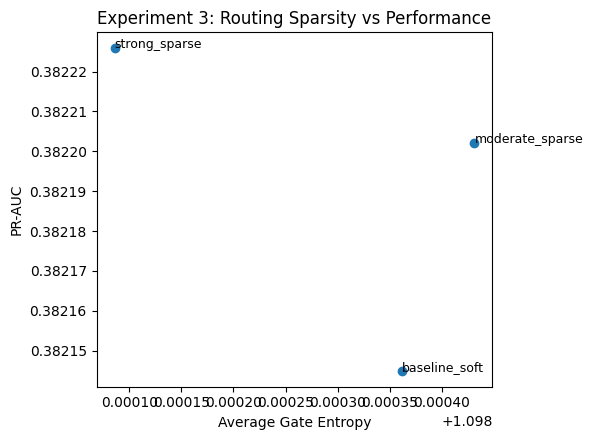


===== Experiment 3 Complete =====
Saved:
- exp3_expert_isotonic_calibration.csv
- exp3_sparse_routing_comparison.csv
- exp3_best_regime_weights.csv
- exp3_entropy_vs_prauc.(png/pdf)
- exp3_metadata.json
- exp3_baseline_soft_training_history.csv
- exp3_baseline_soft_dev_predictions.csv
- exp3_baseline_soft_dev_weights.csv
- exp3_moderate_sparse_training_history.csv
- exp3_moderate_sparse_dev_predictions.csv
- exp3_moderate_sparse_dev_weights.csv
- exp3_strong_sparse_training_history.csv
- exp3_strong_sparse_dev_predictions.csv
- exp3_strong_sparse_dev_weights.csv


In [12]:
# ============================================================
# Experiment 3 — Sparse Trust Routing
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "y_dev_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Experiment 3: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
EXP3_EPS = 1e-8

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
EXP3_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

EXP3_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
EXP3_CONTEXT_COLS = [c for c in EXP3_CONTEXT_COLS if c in X_dev_df.columns]

EXP3_GATE_HIDDEN_DIMS = (64, 32)
EXP3_GATE_DROPOUT = 0.10
EXP3_GATE_LR = 1e-3
EXP3_GATE_WEIGHT_DECAY = 1e-5
EXP3_GATE_EPOCHS = 20
EXP3_GATE_BATCH_SIZE = 2048
EXP3_GATE_PATIENCE = 5

SPARSE_CONFIGS = [
    {"name": "baseline_soft", "lambda_spec": 0.10, "lambda_sparse": 0.001, "temperature": 1.0},
    {"name": "moderate_sparse", "lambda_spec": 0.10, "lambda_sparse": 0.010, "temperature": 0.7},
    {"name": "strong_sparse", "lambda_spec": 0.10, "lambda_sparse": 0.050, "temperature": 0.5},
]

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_exp3(p, eps=EXP3_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_exp3(p):
    p = clip_probs_exp3(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_exp3(y_true, prob):
    from sklearn.metrics import f1_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp3(prob)

    grid = np.linspace(0.05, 0.95, 181)
    best_thr, best_f1 = 0.50, -1.0

    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)

    return best_thr, best_f1

def compute_metrics_exp3(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp3(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_avg_entropy(weights_np):
    w = np.clip(np.asarray(weights_np, dtype=float), 1e-8, 1.0)
    return float(np.mean(-(w * np.log(w)).sum(axis=1)))

def per_sample_binary_logloss_exp3(y_true, p):
    p = clip_probs_exp3(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_exp3(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_exp3(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_exp3(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_exp3(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_exp3(calibrator, p_raw):
    return clip_probs_exp3(calibrator.predict(clip_probs_exp3(p_raw)))

def build_pairwise_absdiff_df_exp3(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_exp3(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_exp3(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_exp3(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        hard_local = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = hard_local["hardness_score"].values
        feat["is_hard"] = hard_local["is_hard"].values.astype(float)

        if "regime" in hard_local.columns:
            feat["regime_easy"] = (hard_local["regime"] == "easy").astype(float)
            feat["regime_medium"] = (hard_local["regime"] == "medium").astype(float)
            feat["regime_hard"] = (hard_local["regime"] == "hard").astype(float)

    return feat

# ------------------------------------------------------------
# Build calibrated expert inputs
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

for e in EXP3_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert '{e}' not found in MODULE4_OOF_MATRIX")

raw_expert_df = oof_df[EXP3_SELECTED_EXPERTS].copy().reset_index(drop=True)

calibrated_expert_df = pd.DataFrame(index=raw_expert_df.index)
expert_calibration_rows = []

for e in EXP3_SELECTED_EXPERTS:
    iso = fit_isotonic_calibrator_exp3(y_dev_np, raw_expert_df[e].values)
    p_cal = apply_isotonic_calibrator_exp3(iso, raw_expert_df[e].values)
    calibrated_expert_df[e] = p_cal

    raw_thr, _ = best_f1_threshold_exp3(y_dev_np, raw_expert_df[e].values)
    cal_thr, _ = best_f1_threshold_exp3(y_dev_np, p_cal)

    raw_metrics = compute_metrics_exp3(y_dev_np, raw_expert_df[e].values, threshold=raw_thr)
    cal_metrics = compute_metrics_exp3(y_dev_np, p_cal, threshold=cal_thr)

    expert_calibration_rows.append({
        "expert": e,
        "raw_PR_AUC": raw_metrics["PR_AUC"],
        "raw_Brier": raw_metrics["Brier"],
        "raw_ECE": raw_metrics["ECE"],
        "cal_PR_AUC": cal_metrics["PR_AUC"],
        "cal_Brier": cal_metrics["Brier"],
        "cal_ECE": cal_metrics["ECE"],
    })

expert_calibration_df = pd.DataFrame(expert_calibration_rows)
expert_calibration_df.to_csv(TAB_DIR / "exp3_expert_isotonic_calibration.csv", index=False)

# ------------------------------------------------------------
# Context + hardness
# ------------------------------------------------------------
context_df = X_dev_df[EXP3_CONTEXT_COLS].copy().reset_index(drop=True)

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

gate_feature_df = build_gate_features_exp3(
    expert_pred_df=calibrated_expert_df,
    context_df=context_df,
    hardcase_df=hard_df
)

# ------------------------------------------------------------
# Gate dataset/model
# ------------------------------------------------------------
class GateDatasetExp3(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

class TrustGateNetSparse(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10, temperature=1.0):
        super().__init__()
        self.temperature = temperature

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h

        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev, n_experts)

    def forward(self, x):
        z = self.backbone(x)
        logits = self.head(z) / self.temperature
        weights = torch.softmax(logits, dim=1)
        return weights, logits

def gate_entropy_exp3(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def train_gate_sparse_exp3(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    lambda_spec=0.10,
    lambda_sparse=0.001,
    temperature=1.0,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_exp3(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetExp3(
        X_tr,
        y_true_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr]
    )
    val_ds = GateDatasetExp3(
        X_val,
        y_true_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val]
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=EXP3_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=EXP3_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = TrustGateNetSparse(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        hidden_dims=EXP3_GATE_HIDDEN_DIMS,
        dropout=EXP3_GATE_DROPOUT,
        temperature=temperature
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=EXP3_GATE_LR,
        weight_decay=EXP3_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(EXP3_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, _ = model(xb)
            final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
            final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

            loss_bce = bce_loss_fn(final_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_exp3(weights)

            loss = loss_bce + lambda_spec * loss_spec + lambda_sparse * loss_sparse
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, _ = model(xb)
                final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
                final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

                loss_bce = bce_loss_fn(final_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_exp3(weights)

                loss = loss_bce + lambda_spec * loss_spec + lambda_sparse * loss_sparse
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        print(
            f"[temp={temperature:.2f}, lambda_sparse={lambda_sparse:.4f}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= EXP3_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)

        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_full, _ = model(X_full_tensor)
        pred_full = torch.sum(weights_full * P_full_tensor, dim=1)

        weights_np = weights_full.detach().cpu().numpy()
        pred_np = pred_full.detach().cpu().numpy()

    thr, _ = best_f1_threshold_exp3(y_true_vec, pred_np)
    metrics = compute_metrics_exp3(y_true_vec, pred_np, threshold=thr)

    weight_df = pd.DataFrame(weights_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_np, 1e-8, 1.0) * np.log(np.clip(weights_np, 1e-8, 1.0)),
        axis=1
    )

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": pred_np,
    })

    history_df = pd.DataFrame(history_rows)

    return {
        "history_df": history_df,
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "threshold": thr,
        "avg_entropy": compute_avg_entropy(weights_np),
    }

# ------------------------------------------------------------
# Baseline comparisons
# ------------------------------------------------------------
exp3_rows = []

# single experts (calibrated versions)
for e in EXP3_SELECTED_EXPERTS:
    thr_e, _ = best_f1_threshold_exp3(y_dev_np, calibrated_expert_df[e].values)
    met_e = compute_metrics_exp3(y_dev_np, calibrated_expert_df[e].values, threshold=thr_e)
    exp3_rows.append({
        "variant": f"single_isotonic_{e}",
        **met_e,
        "avg_entropy": np.nan,
    })

# simple average
simple_avg = calibrated_expert_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_exp3(y_dev_np, simple_avg)
met_avg = compute_metrics_exp3(y_dev_np, simple_avg, threshold=thr_avg)
exp3_rows.append({
    "variant": "simple_average_isotonic_experts",
    **met_avg,
    "avg_entropy": np.nan,
})

# ------------------------------------------------------------
# Run sparse routing configs
# ------------------------------------------------------------
EXP3_GATE_OBJECTS = {}

for cfg in SPARSE_CONFIGS:
    print(f"\n===== Running sparse config: {cfg['name']} =====")

    gate_obj = train_gate_sparse_exp3(
        gate_feature_df=gate_feature_df,
        expert_pred_df=calibrated_expert_df,
        y_true_vec=y_dev_np,
        lambda_spec=cfg["lambda_spec"],
        lambda_sparse=cfg["lambda_sparse"],
        temperature=cfg["temperature"],
    )

    EXP3_GATE_OBJECTS[cfg["name"]] = gate_obj

    row = {
        "variant": cfg["name"],
        **gate_obj["metrics"],
        "avg_entropy": gate_obj["avg_entropy"],
        "temperature": cfg["temperature"],
        "lambda_spec": cfg["lambda_spec"],
        "lambda_sparse": cfg["lambda_sparse"],
    }
    exp3_rows.append(row)

    # save artifacts
    gate_obj["history_df"].to_csv(TAB_DIR / f"exp3_{cfg['name']}_training_history.csv", index=False)
    gate_obj["pred_df"].to_csv(PRED_DIR / f"exp3_{cfg['name']}_dev_predictions.csv", index=False)
    gate_obj["weight_df"].to_csv(PRED_DIR / f"exp3_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------
exp3_df = pd.DataFrame(exp3_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

exp3_df.to_csv(TAB_DIR / "exp3_sparse_routing_comparison.csv", index=False)

print("\n===== Experiment 3: Sparse Routing Comparison =====")
display(exp3_df)

# ------------------------------------------------------------
# Best config
# ------------------------------------------------------------
gate_only_df = exp3_df[exp3_df["variant"].isin([cfg["name"] for cfg in SPARSE_CONFIGS])].copy()
best_sparse_variant = gate_only_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).iloc[0]["variant"]

print(f"\nBest sparse gate variant: {best_sparse_variant}")

# ------------------------------------------------------------
# Regime-level average weights for best config
# ------------------------------------------------------------
best_weight_df = EXP3_GATE_OBJECTS[best_sparse_variant]["weight_df"].copy()
best_regime_df = best_weight_df.merge(
    hard_df[["row_idx_dev", "regime", "is_hard", "hardness_score"]],
    on="row_idx_dev",
    how="left"
)

regime_rows = []
for regime, sub in best_regime_df.groupby("regime"):
    row = {"regime": regime, "n": len(sub)}
    for e in EXP3_SELECTED_EXPERTS:
        row[f"mean_w_{e}"] = float(sub[f"w_{e}"].mean())
    row["mean_gate_entropy"] = float(sub["gate_entropy"].mean())
    regime_rows.append(row)

exp3_regime_weights_df = pd.DataFrame(regime_rows)
exp3_regime_weights_df.to_csv(TAB_DIR / "exp3_best_regime_weights.csv", index=False)

# ------------------------------------------------------------
# Lightweight figure: entropy vs PR-AUC
# ------------------------------------------------------------
plot_df = exp3_df[exp3_df["variant"].isin([cfg["name"] for cfg in SPARSE_CONFIGS])].copy()

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4.5))
plt.scatter(plot_df["avg_entropy"], plot_df["PR_AUC"])
for _, r in plot_df.iterrows():
    plt.text(r["avg_entropy"], r["PR_AUC"], r["variant"], fontsize=9)
plt.xlabel("Average Gate Entropy")
plt.ylabel("PR-AUC")
plt.title("Experiment 3: Routing Sparsity vs Performance")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp3_entropy_vs_prauc.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "exp3_entropy_vs_prauc.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
exp3_meta = {
    "selected_experts": EXP3_SELECTED_EXPERTS,
    "context_cols": EXP3_CONTEXT_COLS,
    "sparse_configs": SPARSE_CONFIGS,
    "best_sparse_variant": best_sparse_variant,
}
with open(LOG_DIR / "exp3_metadata.json", "w", encoding="utf-8") as f:
    json.dump(exp3_meta, f, indent=2)

print("\n===== Experiment 3 Complete =====")
print("Saved:")
print("- exp3_expert_isotonic_calibration.csv")
print("- exp3_sparse_routing_comparison.csv")
print("- exp3_best_regime_weights.csv")
print("- exp3_entropy_vs_prauc.(png/pdf)")
print("- exp3_metadata.json")
for cfg in SPARSE_CONFIGS:
    print(f"- exp3_{cfg['name']}_training_history.csv")
    print(f"- exp3_{cfg['name']}_dev_predictions.csv")
    print(f"- exp3_{cfg['name']}_dev_weights.csv")


===== Running ranking config: baseline_bce =====
[lambda_rank=0.000] epoch=01 train_loss=0.292009 val_loss=0.290679
[lambda_rank=0.000] epoch=02 train_loss=0.292038 val_loss=0.290647
[lambda_rank=0.000] epoch=03 train_loss=0.291751 val_loss=0.290647
[lambda_rank=0.000] epoch=04 train_loss=0.291514 val_loss=0.290633
[lambda_rank=0.000] epoch=05 train_loss=0.291787 val_loss=0.290653
[lambda_rank=0.000] epoch=06 train_loss=0.291897 val_loss=0.290629
[lambda_rank=0.000] epoch=07 train_loss=0.291940 val_loss=0.290635
[lambda_rank=0.000] epoch=08 train_loss=0.291955 val_loss=0.290661
[lambda_rank=0.000] epoch=09 train_loss=0.291711 val_loss=0.290648
[lambda_rank=0.000] epoch=10 train_loss=0.291746 val_loss=0.290642
[lambda_rank=0.000] epoch=11 train_loss=0.291797 val_loss=0.290653
Early stopping triggered.

===== Running ranking config: rank_lambda_0.01 =====
[lambda_rank=0.010] epoch=01 train_loss=0.298331 val_loss=0.296777
[lambda_rank=0.010] epoch=02 train_loss=0.297895 val_loss=0.296758

,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N,avg_entropy,lambda_rank,temperature,lambda_spec,lambda_sparse
0,rank_lambda_0.05,0.382347,0.851176,0.069616,0.235137,1.092806e-03,0.331737,0.579732,0.421997,0.850427,0.361001,0.20,0.164592,0.094253,202944,1.097343,0.05,0.5,0.1,0.05
1,rank_lambda_0.10,0.382339,0.851177,0.069617,0.235139,1.076690e-03,0.331827,0.579994,0.422139,0.850446,0.361177,0.20,0.164622,0.094241,202944,1.097863,0.10,0.5,0.1,0.05
2,baseline_bce,0.382299,0.851166,0.069620,0.235147,1.107928e-03,0.331747,0.579941,0.422061,0.850412,0.361088,0.20,0.164646,0.094231,202944,1.098026,0.00,0.5,0.1,0.05
3,rank_lambda_0.01,0.382269,0.851162,0.069621,0.235151,1.104241e-03,0.331707,0.579680,0.421959,0.850417,0.360955,0.20,0.164592,0.094240,202944,1.097870,0.01,0.5,0.1,0.05
4,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,1.058251e-03,0.331608,0.579889,0.421934,0.850348,0.360948,0.20,0.164701,0.094184,202944,NaN,NaN,NaN,NaN,NaN
5,single_isotonic_HistGradientBoosting,0.372304,0.849975,0.069786,0.235722,1.501399e-10,0.347261,0.531338,0.420017,0.861794,0.355534,0.21,0.144109,0.094184,202944,NaN,NaN,NaN,NaN,NaN
6,single_isotonic_MLP_BCE,0.370125,0.849391,0.069860,0.236082,7.617866e-11,0.331541,0.570995,0.419503,0.851166,0.357571,0.21,0.162207,0.094184,202944,NaN,NaN,NaN,NaN,NaN
7,single_isotonic_DeepFM,0.369802,0.848768,0.069897,0.236423,3.439373e-11,0.340315,0.550016,0.420470,0.857202,0.357069,0.21,0.152219,0.094184,202944,NaN,NaN,NaN,NaN,NaN



Best ranking-loss gate variant: rank_lambda_0.05


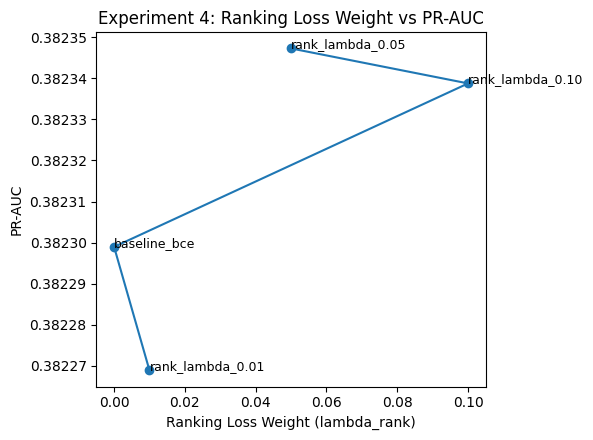


===== Experiment 4 Complete =====
Saved:
- exp4_expert_isotonic_calibration.csv
- exp4_ranking_loss_comparison.csv
- exp4_best_regime_weights.csv
- exp4_lambda_rank_vs_prauc.(png/pdf)
- exp4_metadata.json
- exp4_baseline_bce_training_history.csv
- exp4_baseline_bce_dev_predictions.csv
- exp4_baseline_bce_dev_weights.csv
- exp4_rank_lambda_0.01_training_history.csv
- exp4_rank_lambda_0.01_dev_predictions.csv
- exp4_rank_lambda_0.01_dev_weights.csv
- exp4_rank_lambda_0.05_training_history.csv
- exp4_rank_lambda_0.05_dev_predictions.csv
- exp4_rank_lambda_0.05_dev_weights.csv
- exp4_rank_lambda_0.10_training_history.csv
- exp4_rank_lambda_0.10_dev_predictions.csv
- exp4_rank_lambda_0.10_dev_weights.csv


In [13]:
# ============================================================
# Experiment 4 — Ranking-Aware Gate Loss
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "y_dev_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Experiment 4: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
EXP4_EPS = 1e-8

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
EXP4_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

EXP4_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
EXP4_CONTEXT_COLS = [c for c in EXP4_CONTEXT_COLS if c in X_dev_df.columns]

EXP4_GATE_HIDDEN_DIMS = (64, 32)
EXP4_GATE_DROPOUT = 0.10
EXP4_GATE_LR = 1e-3
EXP4_GATE_WEIGHT_DECAY = 1e-5
EXP4_GATE_EPOCHS = 20
EXP4_GATE_BATCH_SIZE = 2048
EXP4_GATE_PATIENCE = 5

# keep the best sparse setting from Experiment 3 as the base
EXP4_TEMPERATURE = 0.5
EXP4_LAMBDA_SPEC = 0.10
EXP4_LAMBDA_SPARSE = 0.05

# ranking configs
EXP4_RANKING_CONFIGS = [
    {"name": "baseline_bce", "lambda_rank": 0.00},
    {"name": "rank_lambda_0.01", "lambda_rank": 0.01},
    {"name": "rank_lambda_0.05", "lambda_rank": 0.05},
    {"name": "rank_lambda_0.10", "lambda_rank": 0.10},
]

# pairwise ranking settings
EXP4_MAX_POS_PER_BATCH = 256
EXP4_MAX_NEG_PER_BATCH = 256
EXP4_RANK_TEMPERATURE = 1.0   # inside ranking loss

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_exp4(p, eps=EXP4_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_exp4(p):
    p = clip_probs_exp4(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_exp4(y_true, prob):
    from sklearn.metrics import f1_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp4(prob)

    grid = np.linspace(0.05, 0.95, 181)
    best_thr, best_f1 = 0.50, -1.0

    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)

    return best_thr, best_f1

def compute_metrics_exp4(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp4(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_avg_entropy_exp4(weights_np):
    w = np.clip(np.asarray(weights_np, dtype=float), 1e-8, 1.0)
    return float(np.mean(-(w * np.log(w)).sum(axis=1)))

def per_sample_binary_logloss_exp4(y_true, p):
    p = clip_probs_exp4(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_exp4(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_exp4(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_exp4(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_exp4(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_exp4(calibrator, p_raw):
    return clip_probs_exp4(calibrator.predict(clip_probs_exp4(p_raw)))

def build_pairwise_absdiff_df_exp4(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_exp4(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_exp4(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_exp4(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        hard_local = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = hard_local["hardness_score"].values
        feat["is_hard"] = hard_local["is_hard"].values.astype(float)

        if "regime" in hard_local.columns:
            feat["regime_easy"] = (hard_local["regime"] == "easy").astype(float)
            feat["regime_medium"] = (hard_local["regime"] == "medium").astype(float)
            feat["regime_hard"] = (hard_local["regime"] == "hard").astype(float)

    return feat

# ------------------------------------------------------------
# Ranking loss
# ------------------------------------------------------------
def pairwise_ranking_loss(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    """
    Pairwise logistic ranking loss.
    Encourages positive scores > negative scores.
    """
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]   # [P]
    neg_scores = scores[neg_idx]   # [N]

    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    # logistic pairwise loss: log(1 + exp(-(s_pos - s_neg)))
    loss = torch.nn.functional.softplus(-diff).mean()
    return loss

# ------------------------------------------------------------
# Build calibrated expert inputs
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

for e in EXP4_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert '{e}' not found in MODULE4_OOF_MATRIX")

raw_expert_df = oof_df[EXP4_SELECTED_EXPERTS].copy().reset_index(drop=True)

calibrated_expert_df = pd.DataFrame(index=raw_expert_df.index)
expert_calibration_rows = []

for e in EXP4_SELECTED_EXPERTS:
    iso = fit_isotonic_calibrator_exp4(y_dev_np, raw_expert_df[e].values)
    p_cal = apply_isotonic_calibrator_exp4(iso, raw_expert_df[e].values)
    calibrated_expert_df[e] = p_cal

    raw_thr, _ = best_f1_threshold_exp4(y_dev_np, raw_expert_df[e].values)
    cal_thr, _ = best_f1_threshold_exp4(y_dev_np, p_cal)

    raw_metrics = compute_metrics_exp4(y_dev_np, raw_expert_df[e].values, threshold=raw_thr)
    cal_metrics = compute_metrics_exp4(y_dev_np, p_cal, threshold=cal_thr)

    expert_calibration_rows.append({
        "expert": e,
        "raw_PR_AUC": raw_metrics["PR_AUC"],
        "raw_Brier": raw_metrics["Brier"],
        "raw_ECE": raw_metrics["ECE"],
        "cal_PR_AUC": cal_metrics["PR_AUC"],
        "cal_Brier": cal_metrics["Brier"],
        "cal_ECE": cal_metrics["ECE"],
    })

expert_calibration_df = pd.DataFrame(expert_calibration_rows)
expert_calibration_df.to_csv(TAB_DIR / "exp4_expert_isotonic_calibration.csv", index=False)

# ------------------------------------------------------------
# Context + hardness
# ------------------------------------------------------------
context_df = X_dev_df[EXP4_CONTEXT_COLS].copy().reset_index(drop=True)

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

gate_feature_df = build_gate_features_exp4(
    expert_pred_df=calibrated_expert_df,
    context_df=context_df,
    hardcase_df=hard_df
)

# ------------------------------------------------------------
# Dataset/model
# ------------------------------------------------------------
class GateDatasetExp4(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

class TrustGateNetRank(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10, temperature=1.0):
        super().__init__()
        self.temperature = temperature

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h

        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev, n_experts)

    def forward(self, x):
        z = self.backbone(x)
        logits = self.head(z) / self.temperature
        weights = torch.softmax(logits, dim=1)
        return weights, logits

def gate_entropy_exp4(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def train_gate_rank_exp4(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    lambda_spec=0.10,
    lambda_sparse=0.05,
    lambda_rank=0.0,
    temperature=0.5,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_exp4(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetExp4(
        X_tr,
        y_true_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr]
    )
    val_ds = GateDatasetExp4(
        X_val,
        y_true_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val]
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=EXP4_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=EXP4_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = TrustGateNetRank(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        hidden_dims=EXP4_GATE_HIDDEN_DIMS,
        dropout=EXP4_GATE_DROPOUT,
        temperature=temperature
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=EXP4_GATE_LR,
        weight_decay=EXP4_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(EXP4_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, _ = model(xb)
            final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
            final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

            loss_bce = bce_loss_fn(final_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_exp4(weights)
            loss_rank = pairwise_ranking_loss(
                final_prob.view(-1),
                yb.view(-1),
                max_pos=EXP4_MAX_POS_PER_BATCH,
                max_neg=EXP4_MAX_NEG_PER_BATCH,
                temperature=EXP4_RANK_TEMPERATURE
            )

            loss = (
                loss_bce
                + lambda_spec * loss_spec
                + lambda_sparse * loss_sparse
                + lambda_rank * loss_rank
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, _ = model(xb)
                final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
                final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

                loss_bce = bce_loss_fn(final_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_exp4(weights)
                loss_rank = pairwise_ranking_loss(
                    final_prob.view(-1),
                    yb.view(-1),
                    max_pos=EXP4_MAX_POS_PER_BATCH,
                    max_neg=EXP4_MAX_NEG_PER_BATCH,
                    temperature=EXP4_RANK_TEMPERATURE
                )

                loss = (
                    loss_bce
                    + lambda_spec * loss_spec
                    + lambda_sparse * loss_sparse
                    + lambda_rank * loss_rank
                )
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        print(
            f"[lambda_rank={lambda_rank:.3f}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= EXP4_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)

        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_full, _ = model(X_full_tensor)
        pred_full = torch.sum(weights_full * P_full_tensor, dim=1)

        weights_np = weights_full.detach().cpu().numpy()
        pred_np = pred_full.detach().cpu().numpy()

    thr, _ = best_f1_threshold_exp4(y_true_vec, pred_np)
    metrics = compute_metrics_exp4(y_true_vec, pred_np, threshold=thr)

    weight_df = pd.DataFrame(weights_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_np, 1e-8, 1.0) * np.log(np.clip(weights_np, 1e-8, 1.0)),
        axis=1
    )

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": pred_np,
    })

    history_df = pd.DataFrame(history_rows)

    return {
        "history_df": history_df,
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "threshold": thr,
        "avg_entropy": compute_avg_entropy_exp4(weights_np),
    }

# ------------------------------------------------------------
# Baseline comparisons
# ------------------------------------------------------------
exp4_rows = []

for e in EXP4_SELECTED_EXPERTS:
    thr_e, _ = best_f1_threshold_exp4(y_dev_np, calibrated_expert_df[e].values)
    met_e = compute_metrics_exp4(y_dev_np, calibrated_expert_df[e].values, threshold=thr_e)
    exp4_rows.append({
        "variant": f"single_isotonic_{e}",
        **met_e,
        "avg_entropy": np.nan,
        "lambda_rank": np.nan,
    })

simple_avg = calibrated_expert_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_exp4(y_dev_np, simple_avg)
met_avg = compute_metrics_exp4(y_dev_np, simple_avg, threshold=thr_avg)
exp4_rows.append({
    "variant": "simple_average_isotonic_experts",
    **met_avg,
    "avg_entropy": np.nan,
    "lambda_rank": np.nan,
})

# ------------------------------------------------------------
# Run ranking-aware configs
# ------------------------------------------------------------
EXP4_GATE_OBJECTS = {}

for cfg in EXP4_RANKING_CONFIGS:
    print(f"\n===== Running ranking config: {cfg['name']} =====")

    gate_obj = train_gate_rank_exp4(
        gate_feature_df=gate_feature_df,
        expert_pred_df=calibrated_expert_df,
        y_true_vec=y_dev_np,
        lambda_spec=EXP4_LAMBDA_SPEC,
        lambda_sparse=EXP4_LAMBDA_SPARSE,
        lambda_rank=cfg["lambda_rank"],
        temperature=EXP4_TEMPERATURE,
    )

    EXP4_GATE_OBJECTS[cfg["name"]] = gate_obj

    row = {
        "variant": cfg["name"],
        **gate_obj["metrics"],
        "avg_entropy": gate_obj["avg_entropy"],
        "temperature": EXP4_TEMPERATURE,
        "lambda_spec": EXP4_LAMBDA_SPEC,
        "lambda_sparse": EXP4_LAMBDA_SPARSE,
        "lambda_rank": cfg["lambda_rank"],
    }
    exp4_rows.append(row)

    gate_obj["history_df"].to_csv(TAB_DIR / f"exp4_{cfg['name']}_training_history.csv", index=False)
    gate_obj["pred_df"].to_csv(PRED_DIR / f"exp4_{cfg['name']}_dev_predictions.csv", index=False)
    gate_obj["weight_df"].to_csv(PRED_DIR / f"exp4_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Final comparison table
# ------------------------------------------------------------
exp4_df = pd.DataFrame(exp4_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

exp4_df.to_csv(TAB_DIR / "exp4_ranking_loss_comparison.csv", index=False)

print("\n===== Experiment 4: Ranking-Aware Gate Loss Comparison =====")
display(exp4_df)

# ------------------------------------------------------------
# Best ranking variant
# ------------------------------------------------------------
gate_only_df = exp4_df[exp4_df["variant"].isin([cfg["name"] for cfg in EXP4_RANKING_CONFIGS])].copy()
best_rank_variant = gate_only_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).iloc[0]["variant"]

print(f"\nBest ranking-loss gate variant: {best_rank_variant}")

best_weight_df = EXP4_GATE_OBJECTS[best_rank_variant]["weight_df"].copy()
best_regime_df = best_weight_df.merge(
    hard_df[["row_idx_dev", "regime", "is_hard", "hardness_score"]],
    on="row_idx_dev",
    how="left"
)

regime_rows = []
for regime, sub in best_regime_df.groupby("regime"):
    row = {"regime": regime, "n": len(sub)}
    for e in EXP4_SELECTED_EXPERTS:
        row[f"mean_w_{e}"] = float(sub[f"w_{e}"].mean())
    row["mean_gate_entropy"] = float(sub["gate_entropy"].mean())
    regime_rows.append(row)

exp4_regime_weights_df = pd.DataFrame(regime_rows)
exp4_regime_weights_df.to_csv(TAB_DIR / "exp4_best_regime_weights.csv", index=False)

# ------------------------------------------------------------
# Figure: lambda_rank vs PR-AUC
# ------------------------------------------------------------
import matplotlib.pyplot as plt

plot_df = exp4_df[exp4_df["variant"].isin([cfg["name"] for cfg in EXP4_RANKING_CONFIGS])].copy()

plt.figure(figsize=(6, 4.5))
plt.plot(plot_df["lambda_rank"], plot_df["PR_AUC"], marker="o")
for _, r in plot_df.iterrows():
    plt.text(r["lambda_rank"], r["PR_AUC"], r["variant"], fontsize=9)
plt.xlabel("Ranking Loss Weight (lambda_rank)")
plt.ylabel("PR-AUC")
plt.title("Experiment 4: Ranking Loss Weight vs PR-AUC")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp4_lambda_rank_vs_prauc.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "exp4_lambda_rank_vs_prauc.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
exp4_meta = {
    "selected_experts": EXP4_SELECTED_EXPERTS,
    "context_cols": EXP4_CONTEXT_COLS,
    "temperature": EXP4_TEMPERATURE,
    "lambda_spec": EXP4_LAMBDA_SPEC,
    "lambda_sparse": EXP4_LAMBDA_SPARSE,
    "ranking_configs": EXP4_RANKING_CONFIGS,
    "best_rank_variant": best_rank_variant,
}
with open(LOG_DIR / "exp4_metadata.json", "w", encoding="utf-8") as f:
    json.dump(exp4_meta, f, indent=2)

print("\n===== Experiment 4 Complete =====")
print("Saved:")
print("- exp4_expert_isotonic_calibration.csv")
print("- exp4_ranking_loss_comparison.csv")
print("- exp4_best_regime_weights.csv")
print("- exp4_lambda_rank_vs_prauc.(png/pdf)")
print("- exp4_metadata.json")
for cfg in EXP4_RANKING_CONFIGS:
    print(f"- exp4_{cfg['name']}_training_history.csv")
    print(f"- exp4_{cfg['name']}_dev_predictions.csv")
    print(f"- exp4_{cfg['name']}_dev_weights.csv")


===== Running variant: global_gate_ranked =====
[regime_gate=False] epoch=01 train_loss=0.322825 val_loss=0.321179
[regime_gate=False] epoch=02 train_loss=0.321892 val_loss=0.321205
[regime_gate=False] epoch=03 train_loss=0.322343 val_loss=0.321204
[regime_gate=False] epoch=04 train_loss=0.322466 val_loss=0.321146
[regime_gate=False] epoch=05 train_loss=0.322310 val_loss=0.321186
[regime_gate=False] epoch=06 train_loss=0.322484 val_loss=0.321084
[regime_gate=False] epoch=07 train_loss=0.322728 val_loss=0.321117
[regime_gate=False] epoch=08 train_loss=0.322427 val_loss=0.321266
[regime_gate=False] epoch=09 train_loss=0.322377 val_loss=0.321153
[regime_gate=False] epoch=10 train_loss=0.322260 val_loss=0.321132
[regime_gate=False] epoch=11 train_loss=0.322055 val_loss=0.321161
Early stopping triggered.

===== Running variant: regime_aware_gate_ranked =====
[regime_gate=True] epoch=01 train_loss=0.322271 val_loss=0.321167
[regime_gate=True] epoch=02 train_loss=0.322121 val_loss=0.321205
[

,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,...,threshold,PredPosRate,MeanProb,N,avg_entropy,use_regime_gate,temperature,lambda_spec,lambda_sparse,lambda_rank
0,global_gate_ranked,0.382360,0.851185,0.069617,0.235135,1.095291e-03,0.331767,0.580046,0.422105,0.850412,...,0.20,0.164666,0.094266,202944,1.097634,False,0.5,0.1,0.05,0.05
1,regime_aware_gate_ranked,0.382260,0.851163,0.069621,0.235151,1.096147e-03,0.331718,0.579994,0.422050,0.850392,...,0.20,0.164676,0.094220,202944,1.097812,True,0.5,0.1,0.05,0.05
2,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,1.058251e-03,0.331608,0.579889,0.421934,0.850348,...,0.20,0.164701,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN
3,single_isotonic_HistGradientBoosting,0.372304,0.849975,0.069786,0.235722,1.501399e-10,0.347261,0.531338,0.420017,0.861794,...,0.21,0.144109,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN
4,single_isotonic_MLP_BCE,0.370125,0.849391,0.069860,0.236082,7.617866e-11,0.331541,0.570995,0.419503,0.851166,...,0.21,0.162207,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN
5,single_isotonic_DeepFM,0.369802,0.848768,0.069897,0.236423,3.439373e-11,0.340315,0.550016,0.420470,0.857202,...,0.21,0.152219,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN



Best Experiment 5 variant: global_gate_ranked


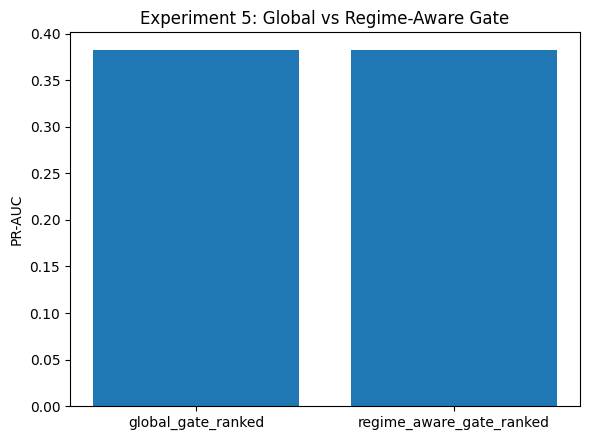


===== Experiment 5 Complete =====
Saved:
- exp5_expert_isotonic_calibration.csv
- exp5_regime_aware_gate_comparison.csv
- exp5_best_regime_weights.csv
- exp5_global_vs_regime_gate.(png/pdf)
- exp5_metadata.json
- exp5_global_gate_ranked_training_history.csv
- exp5_global_gate_ranked_dev_predictions.csv
- exp5_global_gate_ranked_dev_weights.csv
- exp5_regime_aware_gate_ranked_training_history.csv
- exp5_regime_aware_gate_ranked_dev_predictions.csv
- exp5_regime_aware_gate_ranked_dev_weights.csv


In [14]:
# ============================================================
# Experiment 5 — Regime-Aware Trust Gate
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "y_dev_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Experiment 5: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
EXP5_EPS = 1e-8

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
EXP5_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

EXP5_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
EXP5_CONTEXT_COLS = [c for c in EXP5_CONTEXT_COLS if c in X_dev_df.columns]

# use best settings learned so far
EXP5_GATE_HIDDEN_DIMS = (64, 32)
EXP5_GATE_DROPOUT = 0.10
EXP5_GATE_LR = 1e-3
EXP5_GATE_WEIGHT_DECAY = 1e-5
EXP5_GATE_EPOCHS = 20
EXP5_GATE_BATCH_SIZE = 2048
EXP5_GATE_PATIENCE = 5

EXP5_TEMPERATURE = 0.5
EXP5_LAMBDA_SPEC = 0.10
EXP5_LAMBDA_SPARSE = 0.05
EXP5_LAMBDA_RANK = 0.05

EXP5_MAX_POS_PER_BATCH = 256
EXP5_MAX_NEG_PER_BATCH = 256
EXP5_RANK_TEMPERATURE = 1.0

# variants
EXP5_VARIANTS = [
    {"name": "global_gate_ranked", "use_regime_gate": False},
    {"name": "regime_aware_gate_ranked", "use_regime_gate": True},
]

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_exp5(p, eps=EXP5_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_exp5(p):
    p = clip_probs_exp5(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_exp5(y_true, prob):
    from sklearn.metrics import f1_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp5(prob)

    grid = np.linspace(0.05, 0.95, 181)
    best_thr, best_f1 = 0.50, -1.0

    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)

    return best_thr, best_f1

def compute_metrics_exp5(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_exp5(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_avg_entropy_exp5(weights_np):
    w = np.clip(np.asarray(weights_np, dtype=float), 1e-8, 1.0)
    return float(np.mean(-(w * np.log(w)).sum(axis=1)))

def per_sample_binary_logloss_exp5(y_true, p):
    p = clip_probs_exp5(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_exp5(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_exp5(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_exp5(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_exp5(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_exp5(calibrator, p_raw):
    return clip_probs_exp5(calibrator.predict(clip_probs_exp5(p_raw)))

def build_pairwise_absdiff_df_exp5(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_exp5(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_exp5(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_exp5(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        hard_local = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = hard_local["hardness_score"].values
        feat["is_hard"] = hard_local["is_hard"].values.astype(float)
        feat["regime_easy"] = (hard_local["regime"] == "easy").astype(float)
        feat["regime_medium"] = (hard_local["regime"] == "medium").astype(float)
        feat["regime_hard"] = (hard_local["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_exp5(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]

    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

# ------------------------------------------------------------
# Build calibrated expert inputs
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

for e in EXP5_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert '{e}' not found in MODULE4_OOF_MATRIX")

raw_expert_df = oof_df[EXP5_SELECTED_EXPERTS].copy().reset_index(drop=True)

calibrated_expert_df = pd.DataFrame(index=raw_expert_df.index)
expert_calibration_rows = []

for e in EXP5_SELECTED_EXPERTS:
    iso = fit_isotonic_calibrator_exp5(y_dev_np, raw_expert_df[e].values)
    p_cal = apply_isotonic_calibrator_exp5(iso, raw_expert_df[e].values)
    calibrated_expert_df[e] = p_cal

    raw_thr, _ = best_f1_threshold_exp5(y_dev_np, raw_expert_df[e].values)
    cal_thr, _ = best_f1_threshold_exp5(y_dev_np, p_cal)

    raw_metrics = compute_metrics_exp5(y_dev_np, raw_expert_df[e].values, threshold=raw_thr)
    cal_metrics = compute_metrics_exp5(y_dev_np, p_cal, threshold=cal_thr)

    expert_calibration_rows.append({
        "expert": e,
        "raw_PR_AUC": raw_metrics["PR_AUC"],
        "raw_Brier": raw_metrics["Brier"],
        "raw_ECE": raw_metrics["ECE"],
        "cal_PR_AUC": cal_metrics["PR_AUC"],
        "cal_Brier": cal_metrics["Brier"],
        "cal_ECE": cal_metrics["ECE"],
    })

expert_calibration_df = pd.DataFrame(expert_calibration_rows)
expert_calibration_df.to_csv(TAB_DIR / "exp5_expert_isotonic_calibration.csv", index=False)

# ------------------------------------------------------------
# Context + hardness
# ------------------------------------------------------------
context_df = X_dev_df[EXP5_CONTEXT_COLS].copy().reset_index(drop=True)

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

gate_feature_df = build_gate_features_exp5(
    expert_pred_df=calibrated_expert_df,
    context_df=context_df,
    hardcase_df=hard_df
)

# regime ids: 0 easy, 1 medium, 2 hard
regime_to_id = {"easy": 0, "medium": 1, "hard": 2}
regime_ids = hard_df["regime"].map(regime_to_id).values.astype(np.int64)

# ------------------------------------------------------------
# Dataset/model
# ------------------------------------------------------------
class GateDatasetExp5(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets, regime_ids):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.regime_ids = torch.tensor(regime_ids, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.expert_probs[idx],
            self.soft_targets[idx],
            self.regime_ids[idx]
        )

class TrustGateRegimeAware(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10, temperature=1.0, use_regime_gate=False):
        super().__init__()
        self.temperature = temperature
        self.use_regime_gate = use_regime_gate

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)

        self.global_head = nn.Linear(prev, n_experts)

        if use_regime_gate:
            self.easy_head = nn.Linear(prev, n_experts)
            self.medium_head = nn.Linear(prev, n_experts)
            self.hard_head = nn.Linear(prev, n_experts)

    def forward(self, x, regime_ids=None):
        z = self.backbone(x)

        if not self.use_regime_gate:
            logits = self.global_head(z) / self.temperature
            weights = torch.softmax(logits, dim=1)
            return weights, logits

        # regime-aware heads
        logits_easy = self.easy_head(z)
        logits_medium = self.medium_head(z)
        logits_hard = self.hard_head(z)

        logits_stack = torch.stack([logits_easy, logits_medium, logits_hard], dim=1)  # [B, 3, K]

        if regime_ids is None:
            raise ValueError("regime_ids is required for regime-aware gate")

        batch_idx = torch.arange(len(regime_ids), device=regime_ids.device)
        logits = logits_stack[batch_idx, regime_ids] / self.temperature
        weights = torch.softmax(logits, dim=1)
        return weights, logits

def gate_entropy_exp5(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def train_gate_exp5(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    regime_ids,
    use_regime_gate=False,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)
    regime_ids = np.asarray(regime_ids).astype(np.int64).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_exp5(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetExp5(
        X_tr, y_true_vec[idx_tr].reshape(-1, 1), P_all[idx_tr], S_all[idx_tr], regime_ids[idx_tr]
    )
    val_ds = GateDatasetExp5(
        X_val, y_true_vec[idx_val].reshape(-1, 1), P_all[idx_val], S_all[idx_val], regime_ids[idx_val]
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=EXP5_GATE_BATCH_SIZE, shuffle=True, drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=EXP5_GATE_BATCH_SIZE, shuffle=False, drop_last=False
    )

    model = TrustGateRegimeAware(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        hidden_dims=EXP5_GATE_HIDDEN_DIMS,
        dropout=EXP5_GATE_DROPOUT,
        temperature=EXP5_TEMPERATURE,
        use_regime_gate=use_regime_gate,
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=EXP5_GATE_LR,
        weight_decay=EXP5_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(EXP5_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb, rb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)
                rb = rb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, _ = model(xb, regime_ids=rb)
            final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
            final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

            loss_bce = bce_loss_fn(final_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_exp5(weights)
            loss_rank = pairwise_ranking_loss_exp5(
                final_prob.view(-1),
                yb.view(-1),
                max_pos=EXP5_MAX_POS_PER_BATCH,
                max_neg=EXP5_MAX_NEG_PER_BATCH,
                temperature=EXP5_RANK_TEMPERATURE
            )

            loss = (
                loss_bce
                + EXP5_LAMBDA_SPEC * loss_spec
                + EXP5_LAMBDA_SPARSE * loss_sparse
                + EXP5_LAMBDA_RANK * loss_rank
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb, rb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)
                    rb = rb.to(PRIMARY_DEVICE)

                weights, _ = model(xb, regime_ids=rb)
                final_prob = torch.sum(weights * pb, dim=1, keepdim=True)
                final_prob = torch.clamp(final_prob, 1e-6, 1.0 - 1e-6)

                loss_bce = bce_loss_fn(final_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_exp5(weights)
                loss_rank = pairwise_ranking_loss_exp5(
                    final_prob.view(-1),
                    yb.view(-1),
                    max_pos=EXP5_MAX_POS_PER_BATCH,
                    max_neg=EXP5_MAX_NEG_PER_BATCH,
                    temperature=EXP5_RANK_TEMPERATURE
                )

                loss = (
                    loss_bce
                    + EXP5_LAMBDA_SPEC * loss_spec
                    + EXP5_LAMBDA_SPARSE * loss_sparse
                    + EXP5_LAMBDA_RANK * loss_rank
                )
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        print(
            f"[regime_gate={use_regime_gate}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= EXP5_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)
        R_full_tensor = torch.tensor(regime_ids, dtype=torch.long)

        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)
            R_full_tensor = R_full_tensor.to(PRIMARY_DEVICE)

        weights_full, _ = model(X_full_tensor, regime_ids=R_full_tensor)
        pred_full = torch.sum(weights_full * P_full_tensor, dim=1)

        weights_np = weights_full.detach().cpu().numpy()
        pred_np = pred_full.detach().cpu().numpy()

    thr, _ = best_f1_threshold_exp5(y_true_vec, pred_np)
    metrics = compute_metrics_exp5(y_true_vec, pred_np, threshold=thr)

    weight_df = pd.DataFrame(weights_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_np, 1e-8, 1.0) * np.log(np.clip(weights_np, 1e-8, 1.0)),
        axis=1
    )

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": pred_np,
    })

    return {
        "history_df": pd.DataFrame(history_rows),
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "threshold": thr,
        "avg_entropy": compute_avg_entropy_exp5(weights_np),
    }

# ------------------------------------------------------------
# Baseline comparisons
# ------------------------------------------------------------
exp5_rows = []

for e in EXP5_SELECTED_EXPERTS:
    thr_e, _ = best_f1_threshold_exp5(y_dev_np, calibrated_expert_df[e].values)
    met_e = compute_metrics_exp5(y_dev_np, calibrated_expert_df[e].values, threshold=thr_e)
    exp5_rows.append({
        "variant": f"single_isotonic_{e}",
        **met_e,
        "avg_entropy": np.nan,
        "use_regime_gate": np.nan,
    })

simple_avg = calibrated_expert_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_exp5(y_dev_np, simple_avg)
met_avg = compute_metrics_exp5(y_dev_np, simple_avg, threshold=thr_avg)
exp5_rows.append({
    "variant": "simple_average_isotonic_experts",
    **met_avg,
    "avg_entropy": np.nan,
    "use_regime_gate": np.nan,
})

# ------------------------------------------------------------
# Run variants
# ------------------------------------------------------------
EXP5_GATE_OBJECTS = {}

for cfg in EXP5_VARIANTS:
    print(f"\n===== Running variant: {cfg['name']} =====")

    gate_obj = train_gate_exp5(
        gate_feature_df=gate_feature_df,
        expert_pred_df=calibrated_expert_df,
        y_true_vec=y_dev_np,
        regime_ids=regime_ids,
        use_regime_gate=cfg["use_regime_gate"],
    )

    EXP5_GATE_OBJECTS[cfg["name"]] = gate_obj

    row = {
        "variant": cfg["name"],
        **gate_obj["metrics"],
        "avg_entropy": gate_obj["avg_entropy"],
        "use_regime_gate": cfg["use_regime_gate"],
        "temperature": EXP5_TEMPERATURE,
        "lambda_spec": EXP5_LAMBDA_SPEC,
        "lambda_sparse": EXP5_LAMBDA_SPARSE,
        "lambda_rank": EXP5_LAMBDA_RANK,
    }
    exp5_rows.append(row)

    gate_obj["history_df"].to_csv(TAB_DIR / f"exp5_{cfg['name']}_training_history.csv", index=False)
    gate_obj["pred_df"].to_csv(PRED_DIR / f"exp5_{cfg['name']}_dev_predictions.csv", index=False)
    gate_obj["weight_df"].to_csv(PRED_DIR / f"exp5_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------
exp5_df = pd.DataFrame(exp5_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

exp5_df.to_csv(TAB_DIR / "exp5_regime_aware_gate_comparison.csv", index=False)

print("\n===== Experiment 5: Regime-Aware Gate Comparison =====")
display(exp5_df)

# ------------------------------------------------------------
# Best variant regime weights
# ------------------------------------------------------------
gate_only_df = exp5_df[exp5_df["variant"].isin([cfg["name"] for cfg in EXP5_VARIANTS])].copy()
best_exp5_variant = gate_only_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).iloc[0]["variant"]

print(f"\nBest Experiment 5 variant: {best_exp5_variant}")

best_weight_df = EXP5_GATE_OBJECTS[best_exp5_variant]["weight_df"].copy()
best_regime_df = best_weight_df.merge(
    hard_df[["row_idx_dev", "regime", "is_hard", "hardness_score"]],
    on="row_idx_dev",
    how="left"
)

regime_rows = []
for regime, sub in best_regime_df.groupby("regime"):
    row = {"regime": regime, "n": len(sub)}
    for e in EXP5_SELECTED_EXPERTS:
        row[f"mean_w_{e}"] = float(sub[f"w_{e}"].mean())
    row["mean_gate_entropy"] = float(sub["gate_entropy"].mean())
    regime_rows.append(row)

exp5_regime_weights_df = pd.DataFrame(regime_rows)
exp5_regime_weights_df.to_csv(TAB_DIR / "exp5_best_regime_weights.csv", index=False)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
import matplotlib.pyplot as plt

plot_df = exp5_df[exp5_df["variant"].isin([cfg["name"] for cfg in EXP5_VARIANTS])].copy()

plt.figure(figsize=(6, 4.5))
plt.bar(plot_df["variant"], plot_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.title("Experiment 5: Global vs Regime-Aware Gate")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp5_global_vs_regime_gate.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "exp5_global_vs_regime_gate.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
exp5_meta = {
    "selected_experts": EXP5_SELECTED_EXPERTS,
    "context_cols": EXP5_CONTEXT_COLS,
    "temperature": EXP5_TEMPERATURE,
    "lambda_spec": EXP5_LAMBDA_SPEC,
    "lambda_sparse": EXP5_LAMBDA_SPARSE,
    "lambda_rank": EXP5_LAMBDA_RANK,
    "variants": EXP5_VARIANTS,
    "best_variant": best_exp5_variant,
}
with open(LOG_DIR / "exp5_metadata.json", "w", encoding="utf-8") as f:
    json.dump(exp5_meta, f, indent=2)

print("\n===== Experiment 5 Complete =====")
print("Saved:")
print("- exp5_expert_isotonic_calibration.csv")
print("- exp5_regime_aware_gate_comparison.csv")
print("- exp5_best_regime_weights.csv")
print("- exp5_global_vs_regime_gate.(png/pdf)")
print("- exp5_metadata.json")
for cfg in EXP5_VARIANTS:
    print(f"- exp5_{cfg['name']}_training_history.csv")
    print(f"- exp5_{cfg['name']}_dev_predictions.csv")
    print(f"- exp5_{cfg['name']}_dev_weights.csv")


===== Running variant: global_gate_ranked_baseline =====
[use_residual=False] epoch=01 train_loss=0.322516 val_loss=0.321158
[use_residual=False] epoch=02 train_loss=0.322121 val_loss=0.321135
[use_residual=False] epoch=03 train_loss=0.322265 val_loss=0.321144
[use_residual=False] epoch=04 train_loss=0.322198 val_loss=0.321120
[use_residual=False] epoch=05 train_loss=0.322693 val_loss=0.321139
[use_residual=False] epoch=06 train_loss=0.322314 val_loss=0.321122
[use_residual=False] epoch=07 train_loss=0.322508 val_loss=0.321151
[use_residual=False] epoch=08 train_loss=0.322045 val_loss=0.321194
[use_residual=False] epoch=09 train_loss=0.322216 val_loss=0.321149
Early stopping triggered.

===== Running variant: global_gate_ranked_residual =====
[use_residual=True] epoch=01 train_loss=0.322573 val_loss=0.321026
[use_residual=True] epoch=02 train_loss=0.322831 val_loss=0.321276
[use_residual=True] epoch=03 train_loss=0.322454 val_loss=0.320949
[use_residual=True] epoch=04 train_loss=0.322

,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,...,MeanProb,N,avg_entropy,mean_abs_residual,use_residual,temperature,lambda_spec,lambda_sparse,lambda_rank,residual_scale
0,global_gate_ranked_residual,0.382567,0.851318,0.069622,0.235091,2.366781e-03,0.332501,0.578372,0.422253,0.850934,...,0.096358,202944,1.097909,0.003107,True,0.5,0.1,0.05,0.05,0.05
1,global_gate_ranked_baseline,0.382332,0.851167,0.069618,0.235143,1.070647e-03,0.331767,0.579784,0.422035,0.850437,...,0.094258,202944,1.097508,0.000000,False,0.5,0.1,0.05,0.05,0.00
2,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,1.058251e-03,0.331608,0.579889,0.421934,0.850348,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,single_isotonic_HistGradientBoosting,0.372304,0.849975,0.069786,0.235722,1.501399e-10,0.347261,0.531338,0.420017,0.861794,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,single_isotonic_MLP_BCE,0.370125,0.849391,0.069860,0.236082,7.617866e-11,0.331541,0.570995,0.419503,0.851166,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,single_isotonic_DeepFM,0.369802,0.848768,0.069897,0.236423,3.439373e-11,0.340315,0.550016,0.420470,0.857202,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Best Technique 1 variant: global_gate_ranked_residual


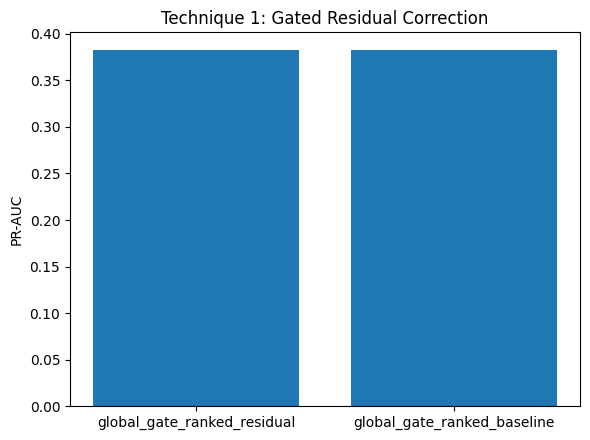


===== Technique 1 Complete =====
Saved:
- tech1_gated_residual_comparison.csv
- tech1_best_regime_weights.csv
- tech1_gated_residual_prauc.(png/pdf)
- tech1_metadata.json
- tech1_global_gate_ranked_baseline_training_history.csv
- tech1_global_gate_ranked_baseline_dev_predictions.csv
- tech1_global_gate_ranked_baseline_dev_weights.csv
- tech1_global_gate_ranked_residual_training_history.csv
- tech1_global_gate_ranked_residual_dev_predictions.csv
- tech1_global_gate_ranked_residual_dev_weights.csv


In [15]:
# ============================================================
# Technique 1 — Gated Residual Correction
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "y_dev_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for residual experiment: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
RES_EPS = 1e-8

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
RES_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

RES_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
RES_CONTEXT_COLS = [c for c in RES_CONTEXT_COLS if c in X_dev_df.columns]

# best gate settings found so far
RES_GATE_HIDDEN_DIMS = (64, 32)
RES_GATE_DROPOUT = 0.10
RES_GATE_LR = 1e-3
RES_GATE_WEIGHT_DECAY = 1e-5
RES_GATE_EPOCHS = 20
RES_GATE_BATCH_SIZE = 2048
RES_GATE_PATIENCE = 5

RES_TEMPERATURE = 0.5
RES_LAMBDA_SPEC = 0.10
RES_LAMBDA_SPARSE = 0.05
RES_LAMBDA_RANK = 0.05

RES_MAX_POS_PER_BATCH = 256
RES_MAX_NEG_PER_BATCH = 256
RES_RANK_TEMPERATURE = 1.0

# residual head config
RES_USE_RESIDUAL_VARIANTS = [
    {"name": "global_gate_ranked_baseline", "use_residual": False},
    {"name": "global_gate_ranked_residual", "use_residual": True},
]

RES_RESIDUAL_HIDDEN_DIMS = (32,)
RES_RESIDUAL_DROPOUT = 0.05
RES_RESIDUAL_SCALE = 0.05     # max additive correction magnitude approx +/- 0.05
RES_LAMBDA_RESIDUAL_L2 = 0.001

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_res(p, eps=RES_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_res(p):
    p = clip_probs_res(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_res(y_true, prob):
    from sklearn.metrics import f1_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_res(prob)
    grid = np.linspace(0.05, 0.95, 181)

    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)

    return best_thr, best_f1

def compute_metrics_res(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_res(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_avg_entropy_res(weights_np):
    w = np.clip(np.asarray(weights_np, dtype=float), 1e-8, 1.0)
    return float(np.mean(-(w * np.log(w)).sum(axis=1)))

def per_sample_binary_logloss_res(y_true, p):
    p = clip_probs_res(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_res(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_res(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_res(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_res(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_res(calibrator, p_raw):
    return clip_probs_res(calibrator.predict(clip_probs_res(p_raw)))

def build_pairwise_absdiff_df_res(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_res(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_res(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_res(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        hard_local = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = hard_local["hardness_score"].values
        feat["is_hard"] = hard_local["is_hard"].values.astype(float)
        feat["regime_easy"] = (hard_local["regime"] == "easy").astype(float)
        feat["regime_medium"] = (hard_local["regime"] == "medium").astype(float)
        feat["regime_hard"] = (hard_local["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_res(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]

    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

# ------------------------------------------------------------
# Build calibrated expert inputs
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

for e in RES_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert '{e}' not found in MODULE4_OOF_MATRIX")

raw_expert_df = oof_df[RES_SELECTED_EXPERTS].copy().reset_index(drop=True)

calibrated_expert_df = pd.DataFrame(index=raw_expert_df.index)
expert_cal_rows = []

for e in RES_SELECTED_EXPERTS:
    iso = fit_isotonic_calibrator_res(y_dev_np, raw_expert_df[e].values)
    p_cal = apply_isotonic_calibrator_res(iso, raw_expert_df[e].values)
    calibrated_expert_df[e] = p_cal

    raw_thr, _ = best_f1_threshold_res(y_dev_np, raw_expert_df[e].values)
    cal_thr, _ = best_f1_threshold_res(y_dev_np, p_cal)

    raw_metrics = compute_metrics_res(y_dev_np, raw_expert_df[e].values, threshold=raw_thr)
    cal_metrics = compute_metrics_res(y_dev_np, p_cal, threshold=cal_thr)

    expert_cal_rows.append({
        "expert": e,
        "raw_PR_AUC": raw_metrics["PR_AUC"],
        "raw_Brier": raw_metrics["Brier"],
        "raw_ECE": raw_metrics["ECE"],
        "cal_PR_AUC": cal_metrics["PR_AUC"],
        "cal_Brier": cal_metrics["Brier"],
        "cal_ECE": cal_metrics["ECE"],
    })

expert_calibration_df = pd.DataFrame(expert_cal_rows)
expert_calibration_df.to_csv(TAB_DIR / "tech1_residual_expert_isotonic_calibration.csv", index=False)

# ------------------------------------------------------------
# Context + hardness
# ------------------------------------------------------------
context_df = X_dev_df[RES_CONTEXT_COLS].copy().reset_index(drop=True)

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

gate_feature_df = build_gate_features_res(
    expert_pred_df=calibrated_expert_df,
    context_df=context_df,
    hardcase_df=hard_df
)

# ------------------------------------------------------------
# Dataset/model
# ------------------------------------------------------------
class GateDatasetRes(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

class TrustGateResidualNet(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        gate_hidden_dims=(64, 32),
        gate_dropout=0.10,
        residual_hidden_dims=(32,),
        residual_dropout=0.05,
        temperature=0.5,
        use_residual=False,
        residual_scale=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.use_residual = use_residual
        self.residual_scale = residual_scale

        # shared backbone
        layers = []
        prev = input_dim
        for h in gate_hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(gate_dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)

        # routing head
        self.gate_head = nn.Linear(prev, n_experts)

        # residual head
        if use_residual:
            res_layers = []
            res_prev = prev + n_experts  # backbone rep + expert probs
            for h in residual_hidden_dims:
                res_layers.extend([
                    nn.Linear(res_prev, h),
                    nn.ReLU(),
                    nn.Dropout(residual_dropout),
                ])
                res_prev = h
            res_layers.append(nn.Linear(res_prev, 1))
            self.residual_head = nn.Sequential(*res_layers)

    def forward(self, x, expert_probs):
        z = self.backbone(x)

        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        weighted_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        residual = None
        corrected_prob = weighted_prob

        if self.use_residual:
            res_in = torch.cat([z, expert_probs], dim=1)
            raw_residual = self.residual_head(res_in)
            residual = self.residual_scale * torch.tanh(raw_residual)
            corrected_prob = weighted_prob + residual

        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)
        return weights, weighted_prob, corrected_prob, residual

def gate_entropy_res(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def train_residual_gate(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    use_residual=False,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_res(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetRes(
        X_tr,
        y_true_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr]
    )
    val_ds = GateDatasetRes(
        X_val,
        y_true_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val]
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=RES_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=RES_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = TrustGateResidualNet(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        gate_hidden_dims=RES_GATE_HIDDEN_DIMS,
        gate_dropout=RES_GATE_DROPOUT,
        residual_hidden_dims=RES_RESIDUAL_HIDDEN_DIMS,
        residual_dropout=RES_RESIDUAL_DROPOUT,
        temperature=RES_TEMPERATURE,
        use_residual=use_residual,
        residual_scale=RES_RESIDUAL_SCALE,
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=RES_GATE_LR,
        weight_decay=RES_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(RES_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, weighted_prob, corrected_prob, residual = model(xb, pb)

            loss_bce = bce_loss_fn(corrected_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_res(weights)
            loss_rank = pairwise_ranking_loss_res(
                corrected_prob.view(-1),
                yb.view(-1),
                max_pos=RES_MAX_POS_PER_BATCH,
                max_neg=RES_MAX_NEG_PER_BATCH,
                temperature=RES_RANK_TEMPERATURE
            )

            loss = (
                loss_bce
                + RES_LAMBDA_SPEC * loss_spec
                + RES_LAMBDA_SPARSE * loss_sparse
                + RES_LAMBDA_RANK * loss_rank
            )

            if use_residual and residual is not None:
                loss_residual_reg = torch.mean(residual ** 2)
                loss = loss + RES_LAMBDA_RESIDUAL_L2 * loss_residual_reg

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, weighted_prob, corrected_prob, residual = model(xb, pb)

                loss_bce = bce_loss_fn(corrected_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_res(weights)
                loss_rank = pairwise_ranking_loss_res(
                    corrected_prob.view(-1),
                    yb.view(-1),
                    max_pos=RES_MAX_POS_PER_BATCH,
                    max_neg=RES_MAX_NEG_PER_BATCH,
                    temperature=RES_RANK_TEMPERATURE
                )

                loss = (
                    loss_bce
                    + RES_LAMBDA_SPEC * loss_spec
                    + RES_LAMBDA_SPARSE * loss_sparse
                    + RES_LAMBDA_RANK * loss_rank
                )

                if use_residual and residual is not None:
                    loss_residual_reg = torch.mean(residual ** 2)
                    loss = loss + RES_LAMBDA_RESIDUAL_L2 * loss_residual_reg

                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        print(
            f"[use_residual={use_residual}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= RES_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)

        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_full, weighted_prob_full, corrected_prob_full, residual_full = model(X_full_tensor, P_full_tensor)

        weights_np = weights_full.detach().cpu().numpy()
        weighted_prob_np = weighted_prob_full.detach().cpu().numpy().reshape(-1)
        corrected_prob_np = corrected_prob_full.detach().cpu().numpy().reshape(-1)

        if residual_full is not None:
            residual_np = residual_full.detach().cpu().numpy().reshape(-1)
        else:
            residual_np = np.zeros(len(corrected_prob_np), dtype=float)

    thr, _ = best_f1_threshold_res(y_true_vec, corrected_prob_np)
    metrics = compute_metrics_res(y_true_vec, corrected_prob_np, threshold=thr)

    weight_df = pd.DataFrame(weights_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_np, 1e-8, 1.0) * np.log(np.clip(weights_np, 1e-8, 1.0)),
        axis=1
    )
    weight_df["weighted_prob"] = weighted_prob_np
    weight_df["residual"] = residual_np
    weight_df["corrected_prob"] = corrected_prob_np

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "weighted_prob": weighted_prob_np,
        "residual": residual_np,
        "pred": corrected_prob_np,
    })

    return {
        "history_df": pd.DataFrame(history_rows),
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "threshold": thr,
        "avg_entropy": compute_avg_entropy_res(weights_np),
        "mean_abs_residual": float(np.mean(np.abs(residual_np))),
    }

# ------------------------------------------------------------
# Baseline comparisons
# ------------------------------------------------------------
tech1_rows = []

for e in RES_SELECTED_EXPERTS:
    thr_e, _ = best_f1_threshold_res(y_dev_np, calibrated_expert_df[e].values)
    met_e = compute_metrics_res(y_dev_np, calibrated_expert_df[e].values, threshold=thr_e)
    tech1_rows.append({
        "variant": f"single_isotonic_{e}",
        **met_e,
        "avg_entropy": np.nan,
        "mean_abs_residual": np.nan,
        "use_residual": np.nan,
    })

simple_avg = calibrated_expert_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_res(y_dev_np, simple_avg)
met_avg = compute_metrics_res(y_dev_np, simple_avg, threshold=thr_avg)
tech1_rows.append({
    "variant": "simple_average_isotonic_experts",
    **met_avg,
    "avg_entropy": np.nan,
    "mean_abs_residual": np.nan,
    "use_residual": np.nan,
})

# ------------------------------------------------------------
# Run baseline vs residual
# ------------------------------------------------------------
TECH1_OBJECTS = {}

for cfg in RES_USE_RESIDUAL_VARIANTS:
    print(f"\n===== Running variant: {cfg['name']} =====")

    obj = train_residual_gate(
        gate_feature_df=gate_feature_df,
        expert_pred_df=calibrated_expert_df,
        y_true_vec=y_dev_np,
        use_residual=cfg["use_residual"],
    )

    TECH1_OBJECTS[cfg["name"]] = obj

    row = {
        "variant": cfg["name"],
        **obj["metrics"],
        "avg_entropy": obj["avg_entropy"],
        "mean_abs_residual": obj["mean_abs_residual"],
        "use_residual": cfg["use_residual"],
        "temperature": RES_TEMPERATURE,
        "lambda_spec": RES_LAMBDA_SPEC,
        "lambda_sparse": RES_LAMBDA_SPARSE,
        "lambda_rank": RES_LAMBDA_RANK,
        "residual_scale": RES_RESIDUAL_SCALE if cfg["use_residual"] else 0.0,
    }
    tech1_rows.append(row)

    obj["history_df"].to_csv(TAB_DIR / f"tech1_{cfg['name']}_training_history.csv", index=False)
    obj["pred_df"].to_csv(PRED_DIR / f"tech1_{cfg['name']}_dev_predictions.csv", index=False)
    obj["weight_df"].to_csv(PRED_DIR / f"tech1_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------
tech1_df = pd.DataFrame(tech1_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

tech1_df.to_csv(TAB_DIR / "tech1_gated_residual_comparison.csv", index=False)

print("\n===== Technique 1: Gated Residual Correction Comparison =====")
display(tech1_df)

# ------------------------------------------------------------
# Best variant regime weights
# ------------------------------------------------------------
gate_only_df = tech1_df[tech1_df["variant"].isin([cfg["name"] for cfg in RES_USE_RESIDUAL_VARIANTS])].copy()
best_tech1_variant = gate_only_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).iloc[0]["variant"]

print(f"\nBest Technique 1 variant: {best_tech1_variant}")

best_weight_df = TECH1_OBJECTS[best_tech1_variant]["weight_df"].copy()
best_regime_df = best_weight_df.merge(
    hard_df[["row_idx_dev", "regime", "is_hard", "hardness_score"]],
    on="row_idx_dev",
    how="left"
)

regime_rows = []
for regime, sub in best_regime_df.groupby("regime"):
    row = {"regime": regime, "n": len(sub)}
    for e in RES_SELECTED_EXPERTS:
        row[f"mean_w_{e}"] = float(sub[f"w_{e}"].mean())
    row["mean_gate_entropy"] = float(sub["gate_entropy"].mean())
    row["mean_abs_residual"] = float(np.mean(np.abs(sub["residual"])))
    regime_rows.append(row)

tech1_regime_df = pd.DataFrame(regime_rows)
tech1_regime_df.to_csv(TAB_DIR / "tech1_best_regime_weights.csv", index=False)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
import matplotlib.pyplot as plt

plot_df = tech1_df[tech1_df["variant"].isin([cfg["name"] for cfg in RES_USE_RESIDUAL_VARIANTS])].copy()

plt.figure(figsize=(6, 4.5))
plt.bar(plot_df["variant"], plot_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.title("Technique 1: Gated Residual Correction")
plt.tight_layout()
plt.savefig(FIG_DIR / "tech1_gated_residual_prauc.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "tech1_gated_residual_prauc.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
tech1_meta = {
    "selected_experts": RES_SELECTED_EXPERTS,
    "context_cols": RES_CONTEXT_COLS,
    "temperature": RES_TEMPERATURE,
    "lambda_spec": RES_LAMBDA_SPEC,
    "lambda_sparse": RES_LAMBDA_SPARSE,
    "lambda_rank": RES_LAMBDA_RANK,
    "residual_hidden_dims": RES_RESIDUAL_HIDDEN_DIMS,
    "residual_dropout": RES_RESIDUAL_DROPOUT,
    "residual_scale": RES_RESIDUAL_SCALE,
    "lambda_residual_l2": RES_LAMBDA_RESIDUAL_L2,
    "variants": RES_USE_RESIDUAL_VARIANTS,
    "best_variant": best_tech1_variant,
}
with open(LOG_DIR / "tech1_metadata.json", "w", encoding="utf-8") as f:
    json.dump(tech1_meta, f, indent=2)

print("\n===== Technique 1 Complete =====")
print("Saved:")
print("- tech1_gated_residual_comparison.csv")
print("- tech1_best_regime_weights.csv")
print("- tech1_gated_residual_prauc.(png/pdf)")
print("- tech1_metadata.json")
for cfg in RES_USE_RESIDUAL_VARIANTS:
    print(f"- tech1_{cfg['name']}_training_history.csv")
    print(f"- tech1_{cfg['name']}_dev_predictions.csv")
    print(f"- tech1_{cfg['name']}_dev_weights.csv")


===== Running variant: cal_lambda_0.00 =====
[lambda_cal=0.000] epoch=01 train_loss=0.323340 val_loss=0.321081
[lambda_cal=0.000] epoch=02 train_loss=0.322472 val_loss=0.321180
[lambda_cal=0.000] epoch=03 train_loss=0.322043 val_loss=0.321010
[lambda_cal=0.000] epoch=04 train_loss=0.322810 val_loss=0.321078
[lambda_cal=0.000] epoch=05 train_loss=0.321917 val_loss=0.321020
[lambda_cal=0.000] epoch=06 train_loss=0.322100 val_loss=0.321057
[lambda_cal=0.000] epoch=07 train_loss=0.321953 val_loss=0.320952
[lambda_cal=0.000] epoch=08 train_loss=0.322326 val_loss=0.321025
[lambda_cal=0.000] epoch=09 train_loss=0.321916 val_loss=0.321012
[lambda_cal=0.000] epoch=10 train_loss=0.321904 val_loss=0.321001
[lambda_cal=0.000] epoch=11 train_loss=0.322030 val_loss=0.321006
[lambda_cal=0.000] epoch=12 train_loss=0.321969 val_loss=0.321101
Early stopping triggered.

===== Running variant: cal_lambda_0.01 =====
[lambda_cal=0.010] epoch=01 train_loss=0.323574 val_loss=0.321703
[lambda_cal=0.010] epoch

,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,...,MeanProb,N,avg_entropy,mean_abs_residual,lambda_cal,temperature,lambda_spec,lambda_sparse,lambda_rank,residual_scale
0,cal_lambda_0.00,0.382784,0.851336,0.069616,0.235083,2.564301e-03,0.328522,0.591870,0.422521,0.847623,...,0.096193,202944,1.097756,0.003506,0.00,0.5,0.1,0.05,0.05,0.05
1,cal_lambda_0.10,0.382545,0.851300,0.069626,0.235115,2.766027e-03,0.327302,0.594276,0.422119,0.846751,...,0.096924,202944,1.097586,0.003076,0.10,0.5,0.1,0.05,0.05,0.05
2,cal_lambda_0.01,0.382389,0.851241,0.069633,0.235183,2.618862e-03,0.339398,0.557236,0.421855,0.856148,...,0.096775,202944,1.097332,0.003623,0.01,0.5,0.1,0.05,0.05,0.05
3,cal_lambda_0.05,0.382361,0.851250,0.069632,0.235157,2.880960e-03,0.326925,0.595218,0.422043,0.846460,...,0.095875,202944,1.097706,0.003553,0.05,0.5,0.1,0.05,0.05,0.05
4,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,1.058251e-03,0.331608,0.579889,0.421934,0.850348,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,single_isotonic_HistGradientBoosting,0.372304,0.849975,0.069786,0.235722,1.501399e-10,0.347261,0.531338,0.420017,0.861794,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,single_isotonic_MLP_BCE,0.370125,0.849391,0.069860,0.236082,7.617866e-11,0.331541,0.570995,0.419503,0.851166,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,single_isotonic_DeepFM,0.369802,0.848768,0.069897,0.236423,3.439373e-11,0.340315,0.550016,0.420470,0.857202,...,0.094184,202944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Best Technique 2 variant: cal_lambda_0.00


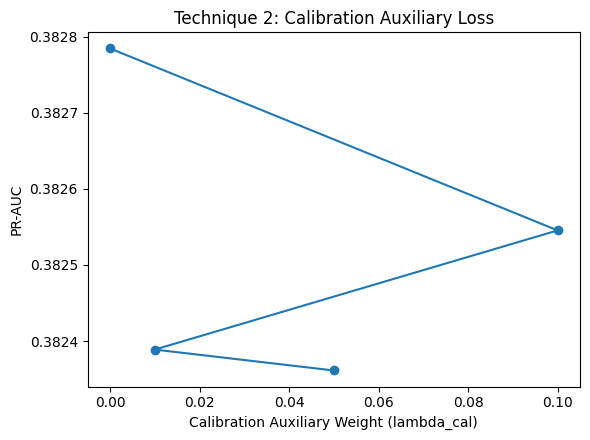


===== Technique 2 Complete =====
Saved:
- tech2_calibration_aux_comparison.csv
- tech2_best_regime_weights.csv
- tech2_calibration_aux_prauc.(png/pdf)
- tech2_metadata.json
- tech2_cal_lambda_0.00_training_history.csv
- tech2_cal_lambda_0.00_dev_predictions.csv
- tech2_cal_lambda_0.00_dev_weights.csv
- tech2_cal_lambda_0.01_training_history.csv
- tech2_cal_lambda_0.01_dev_predictions.csv
- tech2_cal_lambda_0.01_dev_weights.csv
- tech2_cal_lambda_0.05_training_history.csv
- tech2_cal_lambda_0.05_dev_predictions.csv
- tech2_cal_lambda_0.05_dev_weights.csv
- tech2_cal_lambda_0.10_training_history.csv
- tech2_cal_lambda_0.10_dev_predictions.csv
- tech2_cal_lambda_0.10_dev_weights.csv


In [16]:
# ============================================================
# Technique 2 — Calibration-Aware Auxiliary Loss
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "y_dev_arr",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Technique 2: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
CAL_EPS = 1e-8

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
CAL_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

CAL_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
CAL_CONTEXT_COLS = [c for c in CAL_CONTEXT_COLS if c in X_dev_df.columns]

# best settings from current best residual gate
CAL_GATE_HIDDEN_DIMS = (64, 32)
CAL_GATE_DROPOUT = 0.10
CAL_GATE_LR = 1e-3
CAL_GATE_WEIGHT_DECAY = 1e-5
CAL_GATE_EPOCHS = 20
CAL_GATE_BATCH_SIZE = 2048
CAL_GATE_PATIENCE = 5

CAL_TEMPERATURE = 0.5
CAL_LAMBDA_SPEC = 0.10
CAL_LAMBDA_SPARSE = 0.05
CAL_LAMBDA_RANK = 0.05

CAL_MAX_POS_PER_BATCH = 256
CAL_MAX_NEG_PER_BATCH = 256
CAL_RANK_TEMPERATURE = 1.0

# residual head config
CAL_RESIDUAL_HIDDEN_DIMS = (32,)
CAL_RESIDUAL_DROPOUT = 0.05
CAL_RESIDUAL_SCALE = 0.05
CAL_LAMBDA_RESIDUAL_L2 = 0.001

# calibration auxiliary sweep
CAL_AUX_CONFIGS = [
    {"name": "cal_lambda_0.00", "lambda_cal": 0.00},
    {"name": "cal_lambda_0.01", "lambda_cal": 0.01},
    {"name": "cal_lambda_0.05", "lambda_cal": 0.05},
    {"name": "cal_lambda_0.10", "lambda_cal": 0.10},
]

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_cal(p, eps=CAL_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_cal(p):
    p = clip_probs_cal(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_cal(y_true, prob):
    from sklearn.metrics import f1_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_cal(prob)
    grid = np.linspace(0.05, 0.95, 181)

    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)

    return best_thr, best_f1

def compute_metrics_cal(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_cal(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_avg_entropy_cal(weights_np):
    w = np.clip(np.asarray(weights_np, dtype=float), 1e-8, 1.0)
    return float(np.mean(-(w * np.log(w)).sum(axis=1)))

def per_sample_binary_logloss_cal(y_true, p):
    p = clip_probs_cal(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_cal(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_cal(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_cal(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_cal(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_cal(calibrator, p_raw):
    return clip_probs_cal(calibrator.predict(clip_probs_cal(p_raw)))

def build_pairwise_absdiff_df_cal(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_cal(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_cal(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_cal(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        hard_local = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = hard_local["hardness_score"].values
        feat["is_hard"] = hard_local["is_hard"].values.astype(float)
        feat["regime_easy"] = (hard_local["regime"] == "easy").astype(float)
        feat["regime_medium"] = (hard_local["regime"] == "medium").astype(float)
        feat["regime_hard"] = (hard_local["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_cal(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]

    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

# ------------------------------------------------------------
# Build calibrated expert inputs
# ------------------------------------------------------------
oof_df = MODULE4_OOF_MATRIX.copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

for e in CAL_SELECTED_EXPERTS:
    if e not in oof_df.columns:
        raise ValueError(f"Selected expert '{e}' not found in MODULE4_OOF_MATRIX")

raw_expert_df = oof_df[CAL_SELECTED_EXPERTS].copy().reset_index(drop=True)

calibrated_expert_df = pd.DataFrame(index=raw_expert_df.index)
expert_cal_rows = []

for e in CAL_SELECTED_EXPERTS:
    iso = fit_isotonic_calibrator_cal(y_dev_np, raw_expert_df[e].values)
    p_cal = apply_isotonic_calibrator_cal(iso, raw_expert_df[e].values)
    calibrated_expert_df[e] = p_cal

    raw_thr, _ = best_f1_threshold_cal(y_dev_np, raw_expert_df[e].values)
    cal_thr, _ = best_f1_threshold_cal(y_dev_np, p_cal)

    raw_metrics = compute_metrics_cal(y_dev_np, raw_expert_df[e].values, threshold=raw_thr)
    cal_metrics = compute_metrics_cal(y_dev_np, p_cal, threshold=cal_thr)

    expert_cal_rows.append({
        "expert": e,
        "raw_PR_AUC": raw_metrics["PR_AUC"],
        "raw_Brier": raw_metrics["Brier"],
        "raw_ECE": raw_metrics["ECE"],
        "cal_PR_AUC": cal_metrics["PR_AUC"],
        "cal_Brier": cal_metrics["Brier"],
        "cal_ECE": cal_metrics["ECE"],
    })

expert_calibration_df = pd.DataFrame(expert_cal_rows)
expert_calibration_df.to_csv(TAB_DIR / "tech2_calibration_aux_expert_isotonic_calibration.csv", index=False)

# ------------------------------------------------------------
# Context + hardness
# ------------------------------------------------------------
context_df = X_dev_df[CAL_CONTEXT_COLS].copy().reset_index(drop=True)

hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in hard_df.columns:
    hard_df["regime"] = "medium"
    hard_df.loc[hard_df["hardness_score"] >= hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hard_df.loc[hard_df["hardness_score"] <= hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

gate_feature_df = build_gate_features_cal(
    expert_pred_df=calibrated_expert_df,
    context_df=context_df,
    hardcase_df=hard_df
)

# ------------------------------------------------------------
# Dataset/model
# ------------------------------------------------------------
class GateDatasetCal(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

class TrustGateResidualCalNet(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        gate_hidden_dims=(64, 32),
        gate_dropout=0.10,
        residual_hidden_dims=(32,),
        residual_dropout=0.05,
        temperature=0.5,
        residual_scale=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.residual_scale = residual_scale

        layers = []
        prev = input_dim
        for h in gate_hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(gate_dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)

        self.gate_head = nn.Linear(prev, n_experts)

        res_layers = []
        res_prev = prev + n_experts
        for h in residual_hidden_dims:
            res_layers.extend([
                nn.Linear(res_prev, h),
                nn.ReLU(),
                nn.Dropout(residual_dropout),
            ])
            res_prev = h
        res_layers.append(nn.Linear(res_prev, 1))
        self.residual_head = nn.Sequential(*res_layers)

    def forward(self, x, expert_probs):
        z = self.backbone(x)

        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        weighted_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        res_in = torch.cat([z, expert_probs], dim=1)
        raw_residual = self.residual_head(res_in)
        residual = self.residual_scale * torch.tanh(raw_residual)

        corrected_prob = weighted_prob + residual
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, weighted_prob, corrected_prob, residual

def gate_entropy_cal(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def train_calibration_aux_gate(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    lambda_cal=0.0,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_cal(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = GateDatasetCal(
        X_tr,
        y_true_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr]
    )
    val_ds = GateDatasetCal(
        X_val,
        y_true_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val]
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=CAL_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=CAL_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = TrustGateResidualCalNet(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        gate_hidden_dims=CAL_GATE_HIDDEN_DIMS,
        gate_dropout=CAL_GATE_DROPOUT,
        residual_hidden_dims=CAL_RESIDUAL_HIDDEN_DIMS,
        residual_dropout=CAL_RESIDUAL_DROPOUT,
        temperature=CAL_TEMPERATURE,
        residual_scale=CAL_RESIDUAL_SCALE,
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=CAL_GATE_LR,
        weight_decay=CAL_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")
    mse_loss_fn = nn.MSELoss()

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(CAL_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, weighted_prob, corrected_prob, residual = model(xb, pb)

            loss_bce = bce_loss_fn(corrected_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_cal(weights)
            loss_rank = pairwise_ranking_loss_cal(
                corrected_prob.view(-1),
                yb.view(-1),
                max_pos=CAL_MAX_POS_PER_BATCH,
                max_neg=CAL_MAX_NEG_PER_BATCH,
                temperature=CAL_RANK_TEMPERATURE
            )
            loss_cal = mse_loss_fn(corrected_prob, yb)
            loss_residual_reg = torch.mean(residual ** 2)

            loss = (
                loss_bce
                + CAL_LAMBDA_SPEC * loss_spec
                + CAL_LAMBDA_SPARSE * loss_sparse
                + CAL_LAMBDA_RANK * loss_rank
                + lambda_cal * loss_cal
                + CAL_LAMBDA_RESIDUAL_L2 * loss_residual_reg
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, weighted_prob, corrected_prob, residual = model(xb, pb)

                loss_bce = bce_loss_fn(corrected_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_cal(weights)
                loss_rank = pairwise_ranking_loss_cal(
                    corrected_prob.view(-1),
                    yb.view(-1),
                    max_pos=CAL_MAX_POS_PER_BATCH,
                    max_neg=CAL_MAX_NEG_PER_BATCH,
                    temperature=CAL_RANK_TEMPERATURE
                )
                loss_cal = mse_loss_fn(corrected_prob, yb)
                loss_residual_reg = torch.mean(residual ** 2)

                loss = (
                    loss_bce
                    + CAL_LAMBDA_SPEC * loss_spec
                    + CAL_LAMBDA_SPARSE * loss_sparse
                    + CAL_LAMBDA_RANK * loss_rank
                    + lambda_cal * loss_cal
                    + CAL_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                )
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        print(
            f"[lambda_cal={lambda_cal:.3f}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= CAL_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)

        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_full, weighted_prob_full, corrected_prob_full, residual_full = model(X_full_tensor, P_full_tensor)

        weights_np = weights_full.detach().cpu().numpy()
        weighted_prob_np = weighted_prob_full.detach().cpu().numpy().reshape(-1)
        corrected_prob_np = corrected_prob_full.detach().cpu().numpy().reshape(-1)
        residual_np = residual_full.detach().cpu().numpy().reshape(-1)

    thr, _ = best_f1_threshold_cal(y_true_vec, corrected_prob_np)
    metrics = compute_metrics_cal(y_true_vec, corrected_prob_np, threshold=thr)

    weight_df = pd.DataFrame(weights_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_np, 1e-8, 1.0) * np.log(np.clip(weights_np, 1e-8, 1.0)),
        axis=1
    )
    weight_df["weighted_prob"] = weighted_prob_np
    weight_df["residual"] = residual_np
    weight_df["corrected_prob"] = corrected_prob_np

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "weighted_prob": weighted_prob_np,
        "residual": residual_np,
        "pred": corrected_prob_np,
    })

    return {
        "history_df": pd.DataFrame(history_rows),
        "weight_df": weight_df,
        "pred_df": pred_df,
        "metrics": metrics,
        "threshold": thr,
        "avg_entropy": compute_avg_entropy_cal(weights_np),
        "mean_abs_residual": float(np.mean(np.abs(residual_np))),
    }

# ------------------------------------------------------------
# Baseline comparisons
# ------------------------------------------------------------
tech2_rows = []

for e in CAL_SELECTED_EXPERTS:
    thr_e, _ = best_f1_threshold_cal(y_dev_np, calibrated_expert_df[e].values)
    met_e = compute_metrics_cal(y_dev_np, calibrated_expert_df[e].values, threshold=thr_e)
    tech2_rows.append({
        "variant": f"single_isotonic_{e}",
        **met_e,
        "avg_entropy": np.nan,
        "mean_abs_residual": np.nan,
        "lambda_cal": np.nan,
    })

simple_avg = calibrated_expert_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_cal(y_dev_np, simple_avg)
met_avg = compute_metrics_cal(y_dev_np, simple_avg, threshold=thr_avg)
tech2_rows.append({
    "variant": "simple_average_isotonic_experts",
    **met_avg,
    "avg_entropy": np.nan,
    "mean_abs_residual": np.nan,
    "lambda_cal": np.nan,
})

# ------------------------------------------------------------
# Run calibration-aux sweep
# ------------------------------------------------------------
TECH2_OBJECTS = {}

for cfg in CAL_AUX_CONFIGS:
    print(f"\n===== Running variant: {cfg['name']} =====")

    obj = train_calibration_aux_gate(
        gate_feature_df=gate_feature_df,
        expert_pred_df=calibrated_expert_df,
        y_true_vec=y_dev_np,
        lambda_cal=cfg["lambda_cal"],
    )

    TECH2_OBJECTS[cfg["name"]] = obj

    row = {
        "variant": cfg["name"],
        **obj["metrics"],
        "avg_entropy": obj["avg_entropy"],
        "mean_abs_residual": obj["mean_abs_residual"],
        "lambda_cal": cfg["lambda_cal"],
        "temperature": CAL_TEMPERATURE,
        "lambda_spec": CAL_LAMBDA_SPEC,
        "lambda_sparse": CAL_LAMBDA_SPARSE,
        "lambda_rank": CAL_LAMBDA_RANK,
        "residual_scale": CAL_RESIDUAL_SCALE,
    }
    tech2_rows.append(row)

    obj["history_df"].to_csv(TAB_DIR / f"tech2_{cfg['name']}_training_history.csv", index=False)
    obj["pred_df"].to_csv(PRED_DIR / f"tech2_{cfg['name']}_dev_predictions.csv", index=False)
    obj["weight_df"].to_csv(PRED_DIR / f"tech2_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------
tech2_df = pd.DataFrame(tech2_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

tech2_df.to_csv(TAB_DIR / "tech2_calibration_aux_comparison.csv", index=False)

print("\n===== Technique 2: Calibration-Aware Auxiliary Loss Comparison =====")
display(tech2_df)

# ------------------------------------------------------------
# Best variant regime weights
# ------------------------------------------------------------
gate_only_df = tech2_df[tech2_df["variant"].isin([cfg["name"] for cfg in CAL_AUX_CONFIGS])].copy()
best_tech2_variant = gate_only_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).iloc[0]["variant"]

print(f"\nBest Technique 2 variant: {best_tech2_variant}")

best_weight_df = TECH2_OBJECTS[best_tech2_variant]["weight_df"].copy()
best_regime_df = best_weight_df.merge(
    hard_df[["row_idx_dev", "regime", "is_hard", "hardness_score"]],
    on="row_idx_dev",
    how="left"
)

regime_rows = []
for regime, sub in best_regime_df.groupby("regime"):
    row = {"regime": regime, "n": len(sub)}
    for e in CAL_SELECTED_EXPERTS:
        row[f"mean_w_{e}"] = float(sub[f"w_{e}"].mean())
    row["mean_gate_entropy"] = float(sub["gate_entropy"].mean())
    row["mean_abs_residual"] = float(np.mean(np.abs(sub["residual"])))
    regime_rows.append(row)

tech2_regime_df = pd.DataFrame(regime_rows)
tech2_regime_df.to_csv(TAB_DIR / "tech2_best_regime_weights.csv", index=False)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
import matplotlib.pyplot as plt

plot_df = tech2_df[tech2_df["variant"].isin([cfg["name"] for cfg in CAL_AUX_CONFIGS])].copy()

plt.figure(figsize=(6, 4.5))
plt.plot(plot_df["lambda_cal"], plot_df["PR_AUC"], marker="o", label="PR-AUC")
plt.xlabel("Calibration Auxiliary Weight (lambda_cal)")
plt.ylabel("PR-AUC")
plt.title("Technique 2: Calibration Auxiliary Loss")
plt.tight_layout()
plt.savefig(FIG_DIR / "tech2_calibration_aux_prauc.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "tech2_calibration_aux_prauc.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
tech2_meta = {
    "selected_experts": CAL_SELECTED_EXPERTS,
    "context_cols": CAL_CONTEXT_COLS,
    "temperature": CAL_TEMPERATURE,
    "lambda_spec": CAL_LAMBDA_SPEC,
    "lambda_sparse": CAL_LAMBDA_SPARSE,
    "lambda_rank": CAL_LAMBDA_RANK,
    "residual_hidden_dims": CAL_RESIDUAL_HIDDEN_DIMS,
    "residual_dropout": CAL_RESIDUAL_DROPOUT,
    "residual_scale": CAL_RESIDUAL_SCALE,
    "lambda_residual_l2": CAL_LAMBDA_RESIDUAL_L2,
    "calibration_aux_configs": CAL_AUX_CONFIGS,
    "best_variant": best_tech2_variant,
}
with open(LOG_DIR / "tech2_metadata.json", "w", encoding="utf-8") as f:
    json.dump(tech2_meta, f, indent=2)

print("\n===== Technique 2 Complete =====")
print("Saved:")
print("- tech2_calibration_aux_comparison.csv")
print("- tech2_best_regime_weights.csv")
print("- tech2_calibration_aux_prauc.(png/pdf)")
print("- tech2_metadata.json")
for cfg in CAL_AUX_CONFIGS:
    print(f"- tech2_{cfg['name']}_training_history.csv")
    print(f"- tech2_{cfg['name']}_dev_predictions.csv")
    print(f"- tech2_{cfg['name']}_dev_weights.csv")

In [17]:
# ============================================================
# Technique 3 — Pairwise Expert Interaction Gate
# ============================================================

print("\n===== Technique 3: Pairwise Expert Interaction Gate =====")

# ------------------------------------------------------------
# Build enhanced interaction features
# ------------------------------------------------------------
def build_interaction_features(expert_df):
    cols = list(expert_df.columns)
    out = pd.DataFrame(index=expert_df.index)

    # multiplicative interactions
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"prod_{c1}_{c2}"] = expert_df[c1] * expert_df[c2]

    # absolute difference interactions (already partly used, but we reinforce)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"diff_{c1}_{c2}"] = np.abs(expert_df[c1] - expert_df[c2])

    return out


# ------------------------------------------------------------
# Build new feature set (baseline + interactions)
# ------------------------------------------------------------
interaction_feat_df = build_interaction_features(calibrated_expert_df)

gate_feature_interaction_df = pd.concat(
    [gate_feature_df.reset_index(drop=True),
     interaction_feat_df.reset_index(drop=True)],
    axis=1
)

print(f"Original features: {gate_feature_df.shape[1]}")
print(f"With interactions: {gate_feature_interaction_df.shape[1]}")

# ------------------------------------------------------------
# Train function reuse (same as Technique 2 but lambda_cal=0)
# ------------------------------------------------------------
def train_interaction_gate(feature_df):

    return train_calibration_aux_gate(
        gate_feature_df=feature_df,
        expert_pred_df=calibrated_expert_df,
        y_true_vec=y_dev_np,
        lambda_cal=0.0   # IMPORTANT: best setting from Technique 2
    )


# ------------------------------------------------------------
# Run baseline vs interaction
# ------------------------------------------------------------
TECH3_RESULTS = []

# Baseline (current best)
print("\nRunning baseline residual gate...")
baseline_obj = train_interaction_gate(gate_feature_df)

TECH3_RESULTS.append({
    "variant": "baseline_residual_gate",
    **baseline_obj["metrics"],
    "avg_entropy": baseline_obj["avg_entropy"],
    "mean_abs_residual": baseline_obj["mean_abs_residual"],
    "use_interaction": False
})

# Interaction gate
print("\nRunning interaction-enhanced gate...")
interaction_obj = train_interaction_gate(gate_feature_interaction_df)

TECH3_RESULTS.append({
    "variant": "interaction_gate",
    **interaction_obj["metrics"],
    "avg_entropy": interaction_obj["avg_entropy"],
    "mean_abs_residual": interaction_obj["mean_abs_residual"],
    "use_interaction": True
})

# ------------------------------------------------------------
# Add reference baselines
# ------------------------------------------------------------
# simple average
simple_avg = calibrated_expert_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_cal(y_dev_np, simple_avg)
met_avg = compute_metrics_cal(y_dev_np, simple_avg, threshold=thr_avg)

TECH3_RESULTS.append({
    "variant": "simple_average_isotonic_experts",
    **met_avg,
    "avg_entropy": np.nan,
    "mean_abs_residual": np.nan,
    "use_interaction": False
})

# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------
tech3_df = pd.DataFrame(TECH3_RESULTS).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

tech3_df.to_csv(TAB_DIR / "tech3_interaction_gate_comparison.csv", index=False)

print("\n===== Technique 3: Interaction Gate Comparison =====")
display(tech3_df)

# ------------------------------------------------------------
# Save best model outputs
# ------------------------------------------------------------
best_variant = tech3_df.iloc[0]["variant"]

if best_variant == "interaction_gate":
    best_obj = interaction_obj
else:
    best_obj = baseline_obj

best_obj["pred_df"].to_csv(PRED_DIR / "tech3_best_dev_predictions.csv", index=False)
best_obj["weight_df"].to_csv(PRED_DIR / "tech3_best_dev_weights.csv", index=False)

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
tech3_meta = {
    "selected_experts": CAL_SELECTED_EXPERTS,
    "best_variant": best_variant,
    "use_interactions": best_variant == "interaction_gate",
}

with open(LOG_DIR / "tech3_metadata.json", "w") as f:
    json.dump(tech3_meta, f, indent=2)

print("\n===== Technique 3 Complete =====")
print("Best variant:", best_variant)


===== Technique 3: Pairwise Expert Interaction Gate =====
Original features: 29
With interactions: 35

Running baseline residual gate...
[lambda_cal=0.000] epoch=01 train_loss=0.322545 val_loss=0.321061
[lambda_cal=0.000] epoch=02 train_loss=0.322855 val_loss=0.320929
[lambda_cal=0.000] epoch=03 train_loss=0.322381 val_loss=0.320945
[lambda_cal=0.000] epoch=04 train_loss=0.322173 val_loss=0.320967
[lambda_cal=0.000] epoch=05 train_loss=0.322057 val_loss=0.321001
[lambda_cal=0.000] epoch=06 train_loss=0.322427 val_loss=0.320992
[lambda_cal=0.000] epoch=07 train_loss=0.321784 val_loss=0.321018
Early stopping triggered.

Running interaction-enhanced gate...
[lambda_cal=0.000] epoch=01 train_loss=0.323451 val_loss=0.321146
[lambda_cal=0.000] epoch=02 train_loss=0.322764 val_loss=0.320965
[lambda_cal=0.000] epoch=03 train_loss=0.322501 val_loss=0.320936
[lambda_cal=0.000] epoch=04 train_loss=0.322553 val_loss=0.320991
[lambda_cal=0.000] epoch=05 train_loss=0.322341 val_loss=0.321164
[lambd

,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N,avg_entropy,mean_abs_residual,use_interaction
0,interaction_gate,0.382409,0.851285,0.069625,0.235110,0.002490,0.327984,0.592341,0.422195,0.847298,0.362385,0.2,0.170096,0.095885,202944,1.097882,0.003200,True
1,baseline_residual_gate,0.382385,0.851207,0.069636,0.235177,0.002928,0.326083,0.597677,0.421955,0.845770,0.362659,0.2,0.172629,0.097080,202944,1.097752,0.003105,False
2,simple_average_isotonic_experts,0.381687,0.851069,0.069640,0.235210,0.001058,0.331608,0.579889,0.421934,0.850348,0.360948,0.2,0.164701,0.094184,202944,NaN,NaN,False



===== Technique 3 Complete =====
Best variant: interaction_gate


In [19]:
# ============================================================
# FINAL MODEL FREEZE + HOLDOUT EVALUATION
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# DeepFM imports
from deepctr_torch.inputs import SparseFeat, DenseFeat
from deepctr_torch.models import DeepFM

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "X_test_df",
    "y_dev_arr",
    "y_test_arr",
    "FEATURE_COLS",
    "BINARY_FEATURES",
    "ORDINAL_FEATURES",
    "CONTINUOUS_FEATURES",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for final holdout block: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
FINAL_EPS = 1e-8

print("===== Final Model Freeze + Holdout Evaluation =====")
print("CUDA available:", USE_GPU)
print("Device:", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Locked final model config
# ------------------------------------------------------------
FINAL_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

FINAL_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
FINAL_CONTEXT_COLS = [c for c in FINAL_CONTEXT_COLS if c in X_dev_df.columns]

FINAL_GATE_HIDDEN_DIMS = (64, 32)
FINAL_GATE_DROPOUT = 0.10
FINAL_GATE_LR = 1e-3
FINAL_GATE_WEIGHT_DECAY = 1e-5
FINAL_GATE_EPOCHS = 20
FINAL_GATE_BATCH_SIZE = 2048
FINAL_GATE_PATIENCE = 5

FINAL_TEMPERATURE = 0.5
FINAL_LAMBDA_SPEC = 0.10
FINAL_LAMBDA_SPARSE = 0.05
FINAL_LAMBDA_RANK = 0.05

FINAL_MAX_POS_PER_BATCH = 256
FINAL_MAX_NEG_PER_BATCH = 256
FINAL_RANK_TEMPERATURE = 1.0

FINAL_RESIDUAL_HIDDEN_DIMS = (32,)
FINAL_RESIDUAL_DROPOUT = 0.05
FINAL_RESIDUAL_SCALE = 0.05
FINAL_LAMBDA_RESIDUAL_L2 = 0.001

# expert full-fit configs
FINAL_DEEPFM_EPOCHS = 12
FINAL_DEEPFM_BATCH_SIZE = 2048
FINAL_DEEPFM_EMBED_DIM = 8
FINAL_DEEPFM_HIDDEN = (256, 128)

FINAL_MLP_HIDDEN_DIMS = (256, 128)
FINAL_MLP_DROPOUT = 0.15
FINAL_MLP_EPOCHS = 12
FINAL_MLP_BATCH_SIZE = 1024
FINAL_MLP_LR = 1e-3
FINAL_MLP_WEIGHT_DECAY = 1e-5
FINAL_MLP_PATIENCE = 4

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_final(p, eps=FINAL_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_final(p):
    p = clip_probs_final(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_final(y_true, prob):
    from sklearn.metrics import f1_score
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_final(prob)

    grid = np.linspace(0.05, 0.95, 181)
    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_final(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_final(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def per_sample_binary_logloss_final(y_true, p):
    p = clip_probs_final(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_final(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_final(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_final(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_final(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_final(calibrator, p_raw):
    return clip_probs_final(calibrator.predict(clip_probs_final(p_raw)))

def build_pairwise_absdiff_df_final(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_final(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_final(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_final(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        h = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = h["hardness_score"].values
        feat["is_hard"] = h["is_hard"].values.astype(float)
        feat["regime_easy"] = (h["regime"] == "easy").astype(float)
        feat["regime_medium"] = (h["regime"] == "medium").astype(float)
        feat["regime_hard"] = (h["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_final(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]

    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

# ------------------------------------------------------------
# Preprocessing helpers for DeepFM / MLP
# ------------------------------------------------------------
FEATURE_COLS_LOCAL = list(FEATURE_COLS)
BINARY_FEATURES_LOCAL = list(BINARY_FEATURES)
ORDINAL_FEATURES_LOCAL = list(ORDINAL_FEATURES)
CONTINUOUS_FEATURES_LOCAL = list(CONTINUOUS_FEATURES)

class FinalFoldPreprocessor:
    def __init__(self, mode="ml"):
        self.mode = mode
        self.scaler = None
        self.feature_cols = list(FEATURE_COLS_LOCAL)
        self.binary_cols = list(BINARY_FEATURES_LOCAL)
        self.ordinal_cols = list(ORDINAL_FEATURES_LOCAL)
        self.continuous_cols = list(CONTINUOUS_FEATURES_LOCAL)

        # lock exact order once here
        self.scale_cols = list(self.continuous_cols + self.ordinal_cols)
        self.dense_cols = list(self.continuous_cols + self.ordinal_cols)
        self.sparse_cols = list(self.binary_cols)

    def fit(self, X):
        X = X[self.feature_cols].copy()
        if self.mode in ["dl", "deep_views"]:
            self.scaler = StandardScaler()
            if len(self.scale_cols) > 0:
                self.scaler.fit(X[self.scale_cols].astype(float))
        return self

    def transform_ml(self, X):
        return X[self.feature_cols].copy().astype(np.float32)

    def transform_dl(self, X):
        X_out = X[self.feature_cols].copy()
        if self.scaler is not None and len(self.scale_cols) > 0:
            X_out.loc[:, self.scale_cols] = self.scaler.transform(
                X_out[self.scale_cols].astype(float)
            )
        return X_out.astype(np.float32)

    def transform_deep_views(self, X):
        X = X[self.feature_cols].copy()

        X_dense = X[self.dense_cols].copy() if len(self.dense_cols) > 0 else pd.DataFrame(index=X.index)
        X_sparse = X[self.sparse_cols].copy() if len(self.sparse_cols) > 0 else pd.DataFrame(index=X.index)

        if self.scaler is not None and len(self.dense_cols) > 0:
            # force exact fit-time order
            X_dense.loc[:, self.dense_cols] = self.scaler.transform(
                X_dense[self.dense_cols].astype(float)
            )

        for c in self.sparse_cols:
            X_sparse[c] = X_sparse[c].astype(int)

        return {
            "X_dense": X_dense.astype(np.float32),
            "X_sparse": X_sparse.astype(np.int64),
            "dense_cols": list(self.dense_cols),
            "sparse_cols": list(self.sparse_cols),
        }

    def transform(self, X):
        if self.mode == "ml":
            return self.transform_ml(X)
        elif self.mode == "dl":
            return self.transform_dl(X)
        elif self.mode == "deep_views":
            return self.transform_deep_views(X)
        else:
            raise ValueError(f"Unsupported mode: {self.mode}")

def build_deepctr_input_dict_final(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}
    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values
    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values
    return model_input

def infer_deepctr_vocab_sizes_final(train_view, hold_view, es_view=None):
    sparse_cols = train_view["sparse_cols"]
    vocab_sizes = {}
    for c in sparse_cols:
        arrays = [
            np.asarray(train_view["X_sparse"][c].values),
            np.asarray(hold_view["X_sparse"][c].values),
        ]
        if es_view is not None:
            arrays.append(np.asarray(es_view["X_sparse"][c].values))
        mx = int(np.max(np.concatenate(arrays))) if len(arrays) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)
    return vocab_sizes

# ------------------------------------------------------------
# MLP BCE expert full-fit
# ------------------------------------------------------------
class FinalMLPBinaryNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.15):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def fit_full_mlp_bce_and_predict_holdout(X_dev_df_local, y_dev_local, X_hold_df_local):
    preproc = FinalFoldPreprocessor(mode="dl").fit(X_dev_df_local)
    X_dev_t = preproc.transform(X_dev_df_local)
    X_hold_t = preproc.transform(X_hold_df_local)

    X_np = X_dev_t.values.astype(np.float32)
    y_np = np.asarray(y_dev_local).astype(np.float32).reshape(-1, 1)
    X_hold_np = X_hold_t.values.astype(np.float32)

    idx_all = np.arange(len(y_np))
    idx_tr, idx_es = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_np.reshape(-1).astype(int),
        random_state=42
    )

    X_tr, y_tr = X_np[idx_tr], y_np[idx_tr]
    X_es, y_es = X_np[idx_es], y_np[idx_es]

    model = FinalMLPBinaryNet(
        input_dim=X_np.shape[1],
        hidden_dims=FINAL_MLP_HIDDEN_DIMS,
        dropout=FINAL_MLP_DROPOUT
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    pos = max(float(y_tr.sum()), 1.0)
    neg = max(float(len(y_tr) - y_tr.sum()), 1.0)
    pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=PRIMARY_DEVICE if USE_GPU else "cpu")

    optimizer = torch.optim.Adam(model.parameters(), lr=FINAL_MLP_LR, weight_decay=FINAL_MLP_WEIGHT_DECAY)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    train_ds = torch.utils.data.TensorDataset(
        torch.tensor(X_tr, dtype=torch.float32),
        torch.tensor(y_tr, dtype=torch.float32),
    )
    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=FINAL_MLP_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0

    for epoch in range(FINAL_MLP_EPOCHS):
        model.train()
        for xb, yb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            xb_es = torch.tensor(X_es, dtype=torch.float32)
            yb_es = torch.tensor(y_es, dtype=torch.float32)
            if USE_GPU:
                xb_es = xb_es.to(PRIMARY_DEVICE)
                yb_es = yb_es.to(PRIMARY_DEVICE)

            es_logits = model(xb_es)
            es_loss = criterion(es_logits, yb_es).item()

        if es_loss < best_val_loss:
            best_val_loss = es_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= FINAL_MLP_PATIENCE:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        xb_hold = torch.tensor(X_hold_np, dtype=torch.float32)
        if USE_GPU:
            xb_hold = xb_hold.to(PRIMARY_DEVICE)
        logits_hold = model(xb_hold).detach().cpu().numpy().reshape(-1)
        p_hold = 1.0 / (1.0 + np.exp(-logits_hold))
        p_hold = clip_probs_final(p_hold)

    return p_hold

# ------------------------------------------------------------
# DeepFM full-fit
# ------------------------------------------------------------
def fit_full_deepfm_and_predict_holdout(X_dev_df_local, y_dev_local, X_hold_df_local):
    idx_all = np.arange(len(y_dev_local))
    idx_tr, idx_es = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=np.asarray(y_dev_local).astype(int),
        random_state=42
    )

    X_tr_df = X_dev_df_local.iloc[idx_tr].reset_index(drop=True)
    X_es_df = X_dev_df_local.iloc[idx_es].reset_index(drop=True)
    y_tr = np.asarray(y_dev_local).astype(int)[idx_tr]
    y_es = np.asarray(y_dev_local).astype(int)[idx_es]

    # fit ONLY on training subset used for model training
    preproc = FinalFoldPreprocessor(mode="deep_views").fit(X_tr_df)

    X_tr_view = preproc.transform(X_tr_df)
    X_es_view = preproc.transform(X_es_df)
    X_hold_view = preproc.transform(X_hold_df_local.reset_index(drop=True))

    sparse_cols = X_tr_view["sparse_cols"]
    dense_cols = X_tr_view["dense_cols"]
    vocab_sizes = infer_deepctr_vocab_sizes_final(X_tr_view, X_hold_view, X_es_view)

    linear_feature_columns = (
        [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=FINAL_DEEPFM_EMBED_DIM) for c in sparse_cols] +
        [DenseFeat(c, 1) for c in dense_cols]
    )
    dnn_feature_columns = linear_feature_columns

    model = DeepFM(
        linear_feature_columns=linear_feature_columns,
        dnn_feature_columns=dnn_feature_columns,
        dnn_hidden_units=FINAL_DEEPFM_HIDDEN,
        task="binary",
        device=PRIMARY_DEVICE if USE_GPU else "cpu"
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["binary_crossentropy", "auc"]
    )

    X_tr_input = build_deepctr_input_dict_final(X_tr_view)
    X_es_input = build_deepctr_input_dict_final(X_es_view)
    X_hold_input = build_deepctr_input_dict_final(X_hold_view)

    model.fit(
        x=X_tr_input,
        y=np.asarray(y_tr).astype("float32"),
        validation_data=(X_es_input, np.asarray(y_es).astype("float32")),
        batch_size=FINAL_DEEPFM_BATCH_SIZE,
        epochs=FINAL_DEEPFM_EPOCHS,
        verbose=0,
    )

    p_hold = model.predict(X_hold_input, batch_size=FINAL_DEEPFM_BATCH_SIZE).reshape(-1)
    p_hold = clip_probs_final(p_hold)
    return p_hold

# ------------------------------------------------------------
# Final residual-ranked gate
# ------------------------------------------------------------
class FinalGateDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

class FinalTrustGateResidualNet(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        gate_hidden_dims=(64, 32),
        gate_dropout=0.10,
        residual_hidden_dims=(32,),
        residual_dropout=0.05,
        temperature=0.5,
        residual_scale=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.residual_scale = residual_scale

        layers = []
        prev = input_dim
        for h in gate_hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(gate_dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.gate_head = nn.Linear(prev, n_experts)

        res_layers = []
        res_prev = prev + n_experts
        for h in residual_hidden_dims:
            res_layers.extend([
                nn.Linear(res_prev, h),
                nn.ReLU(),
                nn.Dropout(residual_dropout),
            ])
            res_prev = h
        res_layers.append(nn.Linear(res_prev, 1))
        self.residual_head = nn.Sequential(*res_layers)

    def forward(self, x, expert_probs):
        z = self.backbone(x)

        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        weighted_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        res_in = torch.cat([z, expert_probs], dim=1)
        raw_residual = self.residual_head(res_in)
        residual = self.residual_scale * torch.tanh(raw_residual)

        corrected_prob = weighted_prob + residual
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, weighted_prob, corrected_prob, residual

def gate_entropy_final(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def train_final_gate_on_dev(dev_gate_feature_df, dev_expert_cal_df, y_dev_vec):
    y_dev_vec = np.asarray(y_dev_vec).astype(int).reshape(-1)

    X_all = dev_gate_feature_df.values.astype(np.float32)
    P_all = dev_expert_cal_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_final(y_dev_vec, dev_expert_cal_df)

    idx_all = np.arange(len(y_dev_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_dev_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = FinalGateDataset(
        X_tr,
        y_dev_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr]
    )
    val_ds = FinalGateDataset(
        X_val,
        y_dev_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val]
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=FINAL_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=FINAL_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = FinalTrustGateResidualNet(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        gate_hidden_dims=FINAL_GATE_HIDDEN_DIMS,
        gate_dropout=FINAL_GATE_DROPOUT,
        residual_hidden_dims=FINAL_RESIDUAL_HIDDEN_DIMS,
        residual_dropout=FINAL_RESIDUAL_DROPOUT,
        temperature=FINAL_TEMPERATURE,
        residual_scale=FINAL_RESIDUAL_SCALE,
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=FINAL_GATE_LR,
        weight_decay=FINAL_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(FINAL_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, weighted_prob, corrected_prob, residual = model(xb, pb)

            loss_bce = bce_loss_fn(corrected_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_final(weights)
            loss_rank = pairwise_ranking_loss_final(
                corrected_prob.view(-1),
                yb.view(-1),
                max_pos=FINAL_MAX_POS_PER_BATCH,
                max_neg=FINAL_MAX_NEG_PER_BATCH,
                temperature=FINAL_RANK_TEMPERATURE
            )
            loss_residual_reg = torch.mean(residual ** 2)

            loss = (
                loss_bce
                + FINAL_LAMBDA_SPEC * loss_spec
                + FINAL_LAMBDA_SPARSE * loss_sparse
                + FINAL_LAMBDA_RANK * loss_rank
                + FINAL_LAMBDA_RESIDUAL_L2 * loss_residual_reg
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb, pb, sb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                weights, weighted_prob, corrected_prob, residual = model(xb, pb)

                loss_bce = bce_loss_fn(corrected_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_final(weights)
                loss_rank = pairwise_ranking_loss_final(
                    corrected_prob.view(-1),
                    yb.view(-1),
                    max_pos=FINAL_MAX_POS_PER_BATCH,
                    max_neg=FINAL_MAX_NEG_PER_BATCH,
                    temperature=FINAL_RANK_TEMPERATURE
                )
                loss_residual_reg = torch.mean(residual ** 2)

                loss = (
                    loss_bce
                    + FINAL_LAMBDA_SPEC * loss_spec
                    + FINAL_LAMBDA_SPARSE * loss_sparse
                    + FINAL_LAMBDA_RANK * loss_rank
                    + FINAL_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                )
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
        })

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= FINAL_GATE_PATIENCE:
            break

    model.load_state_dict(best_state)

    # dev inference
    model.eval()
    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)
        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_dev, weighted_dev, corrected_dev, residual_dev = model(X_full_tensor, P_full_tensor)

        weights_dev_np = weights_dev.detach().cpu().numpy()
        pred_dev_np = corrected_dev.detach().cpu().numpy().reshape(-1)
        residual_dev_np = residual_dev.detach().cpu().numpy().reshape(-1)

    return {
        "model": model,
        "scaler": scaler,
        "history_df": pd.DataFrame(history_rows),
        "dev_pred": pred_dev_np,
        "dev_weights": weights_dev_np,
        "dev_residual": residual_dev_np,
    }

def infer_final_gate(model, scaler, feature_df_hold, expert_pred_df_hold):
    X_hold = scaler.transform(feature_df_hold.values.astype(np.float32)).astype(np.float32)
    P_hold = expert_pred_df_hold.values.astype(np.float32)

    model.eval()
    with torch.no_grad():
        X_hold_tensor = torch.tensor(X_hold, dtype=torch.float32)
        P_hold_tensor = torch.tensor(P_hold, dtype=torch.float32)
        if USE_GPU:
            X_hold_tensor = X_hold_tensor.to(PRIMARY_DEVICE)
            P_hold_tensor = P_hold_tensor.to(PRIMARY_DEVICE)

        weights_hold, weighted_hold, corrected_hold, residual_hold = model(X_hold_tensor, P_hold_tensor)

        weights_hold_np = weights_hold.detach().cpu().numpy()
        pred_hold_np = corrected_hold.detach().cpu().numpy().reshape(-1)
        residual_hold_np = residual_hold.detach().cpu().numpy().reshape(-1)

    return weights_hold_np, pred_hold_np, residual_hold_np

# ------------------------------------------------------------
# Step 1 — Fit expert calibrators on dev OOF raw preds
# ------------------------------------------------------------
dev_oof_raw_df = MODULE4_OOF_MATRIX[FINAL_SELECTED_EXPERTS].copy().reset_index(drop=True)
expert_calibrators = {}
expert_calibration_rows = []

for e in FINAL_SELECTED_EXPERTS:
    iso = fit_isotonic_calibrator_final(y_dev_arr, dev_oof_raw_df[e].values)
    expert_calibrators[e] = iso

    p_cal_dev = apply_isotonic_calibrator_final(iso, dev_oof_raw_df[e].values)

    raw_thr, _ = best_f1_threshold_final(y_dev_arr, dev_oof_raw_df[e].values)
    cal_thr, _ = best_f1_threshold_final(y_dev_arr, p_cal_dev)

    raw_metrics = compute_metrics_final(y_dev_arr, dev_oof_raw_df[e].values, threshold=raw_thr)
    cal_metrics = compute_metrics_final(y_dev_arr, p_cal_dev, threshold=cal_thr)

    expert_calibration_rows.append({
        "expert": e,
        "raw_PR_AUC": raw_metrics["PR_AUC"],
        "raw_Brier": raw_metrics["Brier"],
        "raw_ECE": raw_metrics["ECE"],
        "cal_PR_AUC": cal_metrics["PR_AUC"],
        "cal_Brier": cal_metrics["Brier"],
        "cal_ECE": cal_metrics["ECE"],
    })

expert_calibration_df = pd.DataFrame(expert_calibration_rows)
expert_calibration_df.to_csv(TAB_DIR / "final_expert_calibration_summary.csv", index=False)

# ------------------------------------------------------------
# Step 2 — Train final gate on dev OOF calibrated expert preds
# ------------------------------------------------------------
dev_expert_cal_df = pd.DataFrame(index=dev_oof_raw_df.index)
for e in FINAL_SELECTED_EXPERTS:
    dev_expert_cal_df[e] = apply_isotonic_calibrator_final(expert_calibrators[e], dev_oof_raw_df[e].values)

dev_hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in dev_hard_df.columns:
    dev_hard_df["regime"] = "medium"
    dev_hard_df.loc[dev_hard_df["hardness_score"] >= dev_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    dev_hard_df.loc[dev_hard_df["hardness_score"] <= dev_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

dev_gate_feature_df = build_gate_features_final(
    expert_pred_df=dev_expert_cal_df,
    context_df=X_dev_df[FINAL_CONTEXT_COLS].reset_index(drop=True),
    hardcase_df=dev_hard_df
)

final_gate_obj = train_final_gate_on_dev(
    dev_gate_feature_df=dev_gate_feature_df,
    dev_expert_cal_df=dev_expert_cal_df,
    y_dev_vec=y_dev_arr
)

final_gate_obj["history_df"].to_csv(TAB_DIR / "final_gate_training_history.csv", index=False)

# dev metrics
dev_thr, _ = best_f1_threshold_final(y_dev_arr, final_gate_obj["dev_pred"])
dev_gate_metrics = compute_metrics_final(y_dev_arr, final_gate_obj["dev_pred"], threshold=dev_thr)
dev_gate_metrics_df = pd.DataFrame([{"variant": "final_proposed_dev", **dev_gate_metrics}])
dev_gate_metrics_df.to_csv(TAB_DIR / "final_gate_dev_metrics.csv", index=False)

# ------------------------------------------------------------
# Step 3 — Fit full experts on dev and predict holdout raw probs
# ------------------------------------------------------------
X_dev_local = X_dev_df.copy().reset_index(drop=True)
X_hold_local = X_test_df.copy().reset_index(drop=True)
y_dev_local = np.asarray(y_dev_arr).astype(int).reshape(-1)
y_hold_local = np.asarray(y_test_arr).astype(int).reshape(-1)

# HistGradientBoosting
print("Fitting full HistGradientBoosting...")
hgb_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_depth=6,
    max_iter=300,
    min_samples_leaf=40,
    random_state=42
)
hgb_model.fit(X_dev_local[FEATURE_COLS], y_dev_local)
hold_hgb_raw = clip_probs_final(hgb_model.predict_proba(X_hold_local[FEATURE_COLS])[:, 1])

# DeepFM
print("Fitting full DeepFM...")
hold_deepfm_raw = fit_full_deepfm_and_predict_holdout(X_dev_local[FEATURE_COLS], y_dev_local, X_hold_local[FEATURE_COLS])

# MLP_BCE
print("Fitting full MLP_BCE...")
hold_mlp_raw = fit_full_mlp_bce_and_predict_holdout(X_dev_local[FEATURE_COLS], y_dev_local, X_hold_local[FEATURE_COLS])

hold_expert_raw_df = pd.DataFrame({
    "HistGradientBoosting": hold_hgb_raw,
    "DeepFM": hold_deepfm_raw,
    "MLP_BCE": hold_mlp_raw,
})

hold_expert_raw_df.to_csv(PRED_DIR / "final_holdout_expert_raw_predictions.csv", index=False)

# ------------------------------------------------------------
# Step 4 — Apply dev-fit calibrators to holdout experts
# ------------------------------------------------------------
hold_expert_cal_df = pd.DataFrame(index=hold_expert_raw_df.index)
for e in FINAL_SELECTED_EXPERTS:
    hold_expert_cal_df[e] = apply_isotonic_calibrator_final(expert_calibrators[e], hold_expert_raw_df[e].values)

hold_expert_cal_df.to_csv(PRED_DIR / "final_holdout_expert_calibrated_predictions.csv", index=False)

# ------------------------------------------------------------
# Step 5 — Build holdout hardness features from calibrated expert outputs
# ------------------------------------------------------------
hold_mean_p = hold_expert_cal_df.mean(axis=1).values
hold_std_p = hold_expert_cal_df.std(axis=1).values
hold_margin = np.abs(hold_mean_p - 0.5)
hold_entropy = compute_entropy_binary_final(hold_mean_p)

hold_hardness_score = (
    0.45 * hold_std_p +
    0.35 * hold_entropy +
    0.20 * (1.0 - np.clip(2.0 * hold_margin, 0.0, 1.0))
)

hold_hard_df = pd.DataFrame({
    "row_idx_holdout": np.arange(len(X_hold_local)),
    "hardness_score": hold_hardness_score,
})

hold_hard_df["regime"] = "medium"
hold_hard_df.loc[hold_hard_df["hardness_score"] >= hold_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
hold_hard_df.loc[hold_hard_df["hardness_score"] <= hold_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"
hold_hard_df["is_hard"] = (hold_hard_df["regime"] == "hard").astype(int)

hold_gate_feature_df = build_gate_features_final(
    expert_pred_df=hold_expert_cal_df,
    context_df=X_hold_local[FINAL_CONTEXT_COLS].reset_index(drop=True),
    hardcase_df=hold_hard_df
)

# ------------------------------------------------------------
# Step 6 — Final gate inference on holdout
# ------------------------------------------------------------
hold_weights_np, hold_pred_np, hold_residual_np = infer_final_gate(
    model=final_gate_obj["model"],
    scaler=final_gate_obj["scaler"],
    feature_df_hold=hold_gate_feature_df,
    expert_pred_df_hold=hold_expert_cal_df
)

hold_weights_df = pd.DataFrame(hold_weights_np, columns=[f"w_{e}" for e in FINAL_SELECTED_EXPERTS])
hold_weights_df["row_idx_holdout"] = np.arange(len(hold_weights_df))
hold_weights_df["dominant_expert"] = np.array(FINAL_SELECTED_EXPERTS)[np.argmax(hold_weights_np, axis=1)]
hold_weights_df["gate_entropy"] = -np.sum(
    np.clip(hold_weights_np, 1e-8, 1.0) * np.log(np.clip(hold_weights_np, 1e-8, 1.0)),
    axis=1
)
hold_weights_df["residual"] = hold_residual_np
hold_weights_df.to_csv(PRED_DIR / "final_holdout_gate_weights.csv", index=False)

hold_pred_df = pd.DataFrame({
    "row_idx_holdout": np.arange(len(y_hold_local)),
    "y_true": y_hold_local,
    "pred": hold_pred_np,
})
hold_pred_df.to_csv(PRED_DIR / "final_holdout_gate_predictions.csv", index=False)

# ------------------------------------------------------------
# Step 7 — Holdout comparisons
# ------------------------------------------------------------
hold_rows = []

# singles (calibrated)
for e in FINAL_SELECTED_EXPERTS:
    p = hold_expert_cal_df[e].values
    thr, _ = best_f1_threshold_final(y_dev_arr, dev_expert_cal_df[e].values)  # threshold chosen from dev
    met = compute_metrics_final(y_hold_local, p, threshold=thr)
    hold_rows.append({"variant": f"single_calibrated_{e}", **met})

# simple average
hold_simple_avg = hold_expert_cal_df.mean(axis=1).values
dev_simple_avg = dev_expert_cal_df.mean(axis=1).values
thr_avg, _ = best_f1_threshold_final(y_dev_arr, dev_simple_avg)
met_avg = compute_metrics_final(y_hold_local, hold_simple_avg, threshold=thr_avg)
hold_rows.append({"variant": "simple_average_calibrated_experts", **met_avg})

# final proposed
thr_final, _ = best_f1_threshold_final(y_dev_arr, final_gate_obj["dev_pred"])
met_final = compute_metrics_final(y_hold_local, hold_pred_np, threshold=thr_final)
hold_rows.append({"variant": "final_proposed_model", **met_final})

hold_comparison_df = pd.DataFrame(hold_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

hold_comparison_df.to_csv(TAB_DIR / "final_holdout_comparison.csv", index=False)

print("\n===== FINAL HOLDOUT COMPARISON =====")
display(hold_comparison_df)

# ------------------------------------------------------------
# Step 8 — Holdout hard-band comparison
# ------------------------------------------------------------
hold_hard_mask = hold_hard_df["is_hard"].values.astype(bool)

hardband_rows = []
for name, pred in [
    ("simple_average_calibrated_experts", hold_simple_avg),
    ("final_proposed_model", hold_pred_np),
]:
    hard_m = compute_metrics_final(y_hold_local[hold_hard_mask], pred[hold_hard_mask], threshold=thr_final if name == "final_proposed_model" else thr_avg)
    hardband_rows.append({"variant": name, **hard_m})

hold_hardband_df = pd.DataFrame(hardband_rows)
hold_hardband_df.to_csv(TAB_DIR / "final_holdout_hardband_comparison.csv", index=False)

print("\n===== FINAL HOLDOUT HARD-BAND COMPARISON =====")
display(hold_hardband_df)

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
final_meta = {
    "selected_experts": FINAL_SELECTED_EXPERTS,
    "context_cols": FINAL_CONTEXT_COLS,
    "temperature": FINAL_TEMPERATURE,
    "lambda_spec": FINAL_LAMBDA_SPEC,
    "lambda_sparse": FINAL_LAMBDA_SPARSE,
    "lambda_rank": FINAL_LAMBDA_RANK,
    "residual_scale": FINAL_RESIDUAL_SCALE,
    "best_dev_metrics": dev_gate_metrics,
}
with open(LOG_DIR / "final_model_freeze_metadata.json", "w", encoding="utf-8") as f:
    json.dump(final_meta, f, indent=2)

print("\nSaved:")
print("- final_expert_calibration_summary.csv")
print("- final_gate_training_history.csv")
print("- final_gate_dev_metrics.csv")
print("- final_holdout_expert_raw_predictions.csv")
print("- final_holdout_expert_calibrated_predictions.csv")
print("- final_holdout_gate_weights.csv")
print("- final_holdout_gate_predictions.csv")
print("- final_holdout_comparison.csv")
print("- final_holdout_hardband_comparison.csv")
print("- final_model_freeze_metadata.json")

===== Final Model Freeze + Holdout Evaluation =====
CUDA available: True
Device: cuda:0
Fitting full HistGradientBoosting...
Fitting full DeepFM...
cuda:0
Train on 172502 samples, validate on 30442 samples, 85 steps per epoch
Fitting full MLP_BCE...

===== FINAL HOLDOUT COMPARISON =====


,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,final_proposed_model,0.373263,0.850785,0.069943,0.236027,0.002309,0.340862,0.552626,0.421649,0.857202,0.358515,0.21,0.152712,0.094862,50736
1,simple_average_calibrated_experts,0.372920,0.850696,0.069941,0.236075,0.003138,0.335846,0.568738,0.422312,0.853437,0.360407,0.20,0.159512,0.092605,50736
2,single_calibrated_HistGradientBoosting,0.365709,0.849889,0.070039,0.237661,0.003158,0.348127,0.526888,0.419247,0.862504,0.354479,0.21,0.142561,0.093805,50736
3,single_calibrated_MLP_BCE,0.362984,0.849566,0.070168,0.236831,0.003650,0.335140,0.569157,0.421869,0.853063,0.359963,0.21,0.159965,0.095367,50736
4,single_calibrated_DeepFM,0.362202,0.848632,0.070287,0.237805,0.007219,0.347669,0.522703,0.417586,0.862662,0.352470,0.21,0.141615,0.088642,50736



===== FINAL HOLDOUT HARD-BAND COMPARISON =====


,variant,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,simple_average_calibrated_experts,0.487731,0.603373,0.229734,0.651731,0.014423,0.387192,1.0,0.558239,0.387192,0.0,0.20,1.0,0.387018,5075
1,final_proposed_model,0.487262,0.604547,0.229836,0.651928,0.013960,0.387192,1.0,0.558239,0.387192,0.0,0.21,1.0,0.397755,5075



Saved:
- final_expert_calibration_summary.csv
- final_gate_training_history.csv
- final_gate_dev_metrics.csv
- final_holdout_expert_raw_predictions.csv
- final_holdout_expert_calibrated_predictions.csv
- final_holdout_gate_weights.csv
- final_holdout_gate_predictions.csv
- final_holdout_comparison.csv
- final_holdout_hardband_comparison.csv
- final_model_freeze_metadata.json


===== Final Adversarial Robustness Comparison =====
CUDA available: True
Device: cuda:0
Fitting frozen pipelines...
cuda:0
Train on 172502 samples, validate on 30442 samples, 85 steps per epoch
cuda:0
Train on 172502 samples, validate on 30442 samples, 85 steps per epoch

===== CLEAN HOLDOUT ROBUSTNESS BASELINE =====


,model,scenario,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,threshold,PredPosRate,MeanProb,N
0,FinalProposed,clean,0.373575,0.850910,0.069969,0.236266,0.005023,0.335450,0.574806,0.423658,0.852688,0.362353,0.20,0.161404,0.092279,50736
1,SimpleAverage,clean,0.372994,0.850849,0.069943,0.236068,0.003470,0.337656,0.566646,0.423158,0.854482,0.361157,0.20,0.158073,0.091859,50736
2,HistGradientBoosting,clean,0.365709,0.849889,0.070039,0.237661,0.003158,0.348127,0.526888,0.419247,0.862504,0.354479,0.21,0.142561,0.093805,50736
3,MLP_BCE,clean,0.364354,0.850103,0.070085,0.236756,0.003698,0.339157,0.560578,0.422622,0.855724,0.360122,0.21,0.155688,0.093130,50736
4,DeepFM,clean,0.362202,0.848632,0.070287,0.237805,0.007219,0.347669,0.522703,0.417586,0.862662,0.352470,0.21,0.141615,0.088642,50736



===== Running attack: whitebox_sensitivity_low =====
Attack model: HistGradientBoosting
Attack model: DeepFM
Attack model: MLP_BCE
Attack model: SimpleAverage
Attack model: FinalProposed

===== Running attack: whitebox_sensitivity_mid =====
Attack model: HistGradientBoosting
Attack model: DeepFM
Attack model: MLP_BCE
Attack model: SimpleAverage
Attack model: FinalProposed

===== Running attack: blackbox_random_low =====
Attack model: HistGradientBoosting
Attack model: DeepFM
Attack model: MLP_BCE
Attack model: SimpleAverage
Attack model: FinalProposed

===== Running attack: blackbox_random_mid =====
Attack model: HistGradientBoosting
Attack model: DeepFM
Attack model: MLP_BCE
Attack model: SimpleAverage
Attack model: FinalProposed

===== FINAL ROBUSTNESS ATTACK COMPARISON =====


,model,attack_name,attack_type,PR_AUC_clean,PR_AUC_adv,PR_AUC_drop,ROC_AUC_clean,ROC_AUC_adv,ROC_AUC_drop,Brier_clean,...,Brier_increase,NLL_clean,NLL_adv,NLL_increase,ECE_clean,ECE_adv,ECE_change,F1_adv,MCC_adv,threshold
0,HistGradientBoosting,blackbox_random_low,blackbox_random,0.365709,0.342121,0.023588,0.849889,0.840651,0.009237,0.070039,...,0.001504,0.237661,0.242993,0.005332,0.003158,0.004207,0.001049,0.402287,0.335186,0.21
1,SimpleAverage,blackbox_random_low,blackbox_random,0.372994,0.336678,0.036316,0.850849,0.834723,0.016127,0.069943,...,0.002355,0.236068,0.244940,0.008872,0.003470,0.005677,0.002206,0.397449,0.331784,0.20
2,FinalProposed,blackbox_random_low,blackbox_random,0.373575,0.335421,0.038154,0.850910,0.834229,0.016681,0.069969,...,0.002608,0.236266,0.245877,0.009611,0.005023,0.008810,0.003787,0.395905,0.330625,0.20
3,DeepFM,blackbox_random_low,blackbox_random,0.362202,0.320100,0.042102,0.848632,0.827624,0.021008,0.070287,...,0.002933,0.237805,0.249219,0.011413,0.007219,0.010389,0.003170,0.383695,0.313663,0.21
4,MLP_BCE,blackbox_random_low,blackbox_random,0.364354,0.316674,0.047680,0.850103,0.826790,0.023313,0.070085,...,0.003348,0.236756,0.249385,0.012629,0.003698,0.007432,0.003734,0.383676,0.315351,0.21
5,SimpleAverage,blackbox_random_mid,blackbox_random,0.372994,0.250603,0.122391,0.850849,0.780023,0.070826,0.069943,...,0.009328,0.236068,0.272307,0.036239,0.003470,0.021665,0.018194,0.321207,0.241729,0.20
6,DeepFM,blackbox_random_mid,blackbox_random,0.362202,0.249418,0.112784,0.848632,0.783022,0.065610,0.070287,...,0.008778,0.237805,0.272114,0.034309,0.007219,0.023371,0.016152,0.321720,0.241189,0.21
7,FinalProposed,blackbox_random_mid,blackbox_random,0.373575,0.246512,0.127064,0.850910,0.778318,0.072592,0.069969,...,0.010250,0.236266,0.275327,0.039061,0.005023,0.026689,0.021666,0.315739,0.235439,0.20
8,MLP_BCE,blackbox_random_mid,blackbox_random,0.364354,0.237992,0.126362,0.850103,0.776159,0.073944,0.070085,...,0.010100,0.236756,0.275016,0.038260,0.003698,0.022958,0.019260,0.311862,0.230247,0.21
9,HistGradientBoosting,blackbox_random_mid,blackbox_random,0.365709,0.235591,0.130117,0.849889,0.767216,0.082673,0.070039,...,0.010701,0.237661,0.280076,0.042416,0.003158,0.026359,0.023202,0.302904,0.218731,0.21



===== FINAL ROBUSTNESS ATTACK SUMMARY =====


,attack_name,best_model_under_attack,best_PR_AUC_adv,final_PR_AUC_adv,final_PR_AUC_drop,avg_PR_AUC_adv,avg_PR_AUC_drop,hgb_PR_AUC_adv,hgb_PR_AUC_drop
0,blackbox_random_low,HistGradientBoosting,0.342121,0.335421,0.038154,0.336678,0.036316,0.342121,0.023588
1,blackbox_random_mid,SimpleAverage,0.250603,0.246512,0.127064,0.250603,0.122391,0.235591,0.130117
2,whitebox_sensitivity_low,HistGradientBoosting,0.357247,0.341010,0.032565,0.341314,0.031680,0.357247,0.008461
3,whitebox_sensitivity_mid,HistGradientBoosting,0.340896,0.254750,0.118826,0.254414,0.118580,0.340896,0.024812


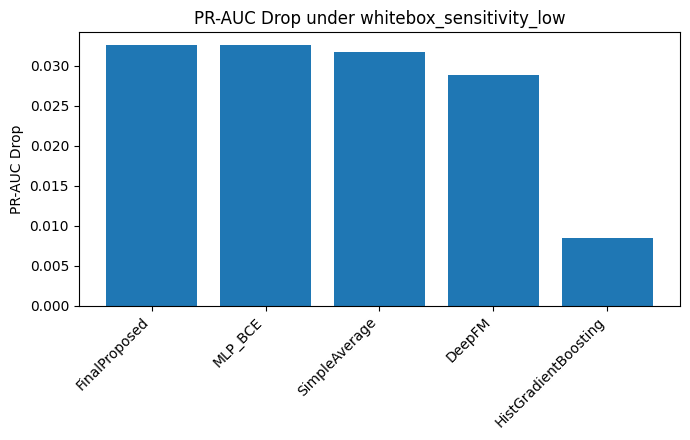

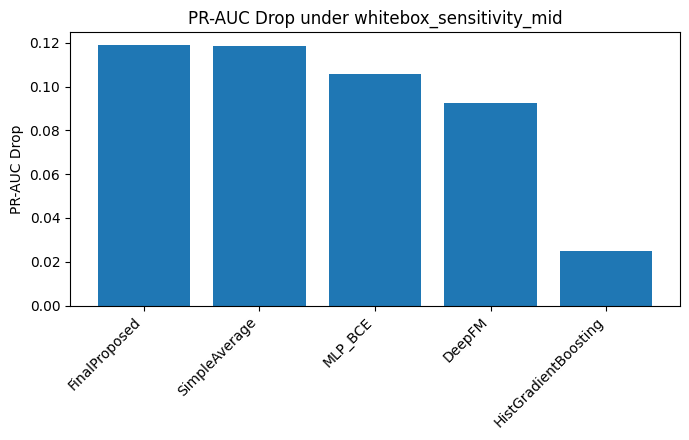

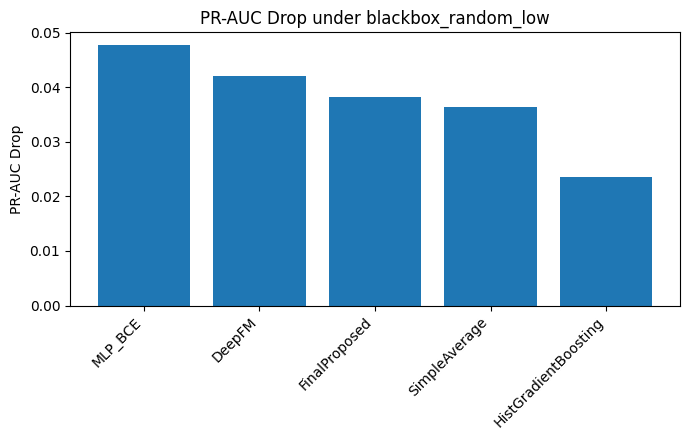

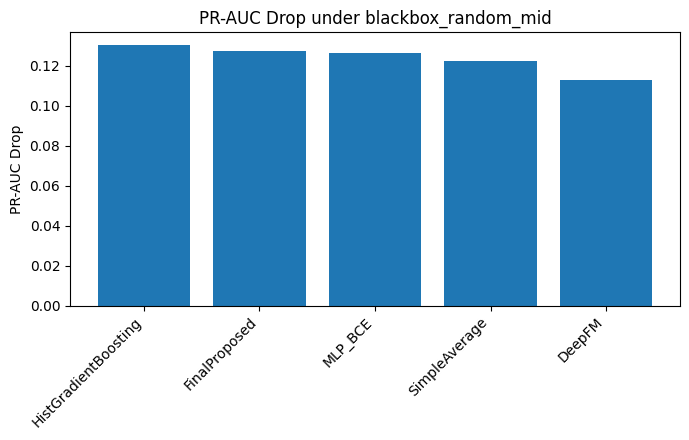


Saved:
- robustness_clean_holdout_comparison.csv
- final_robustness_attack_comparison.csv
- final_robustness_attack_summary.csv
- final_robustness_metadata.json
- robustness_drop_whitebox_sensitivity_low.png/.pdf
- robustness_drop_whitebox_sensitivity_mid.png/.pdf
- robustness_drop_blackbox_random_low.png/.pdf
- robustness_drop_blackbox_random_mid.png/.pdf


In [20]:
# ============================================================
# FINAL ADVERSARIAL ROBUSTNESS COMPARISON
# Frozen final model + top baselines on holdout
# ============================================================

import os
import gc
import json
import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import HistGradientBoostingClassifier

from deepctr_torch.inputs import SparseFeat, DenseFeat
from deepctr_torch.models import DeepFM

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_dev_df", "X_test_df", "y_dev_arr", "y_test_arr",
    "FEATURE_COLS", "BINARY_FEATURES", "ORDINAL_FEATURES", "CONTINUOUS_FEATURES",
    "MODULE4_OOF_MATRIX", "MODULE5_HARDCASE_DF",
    "TAB_DIR", "FIG_DIR", "PRED_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for robustness block: {missing}")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
ROB_EPS = 1e-8

print("===== Final Adversarial Robustness Comparison =====")
print("CUDA available:", USE_GPU)
print("Device:", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Frozen final config
# ------------------------------------------------------------
ROB_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

ROB_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
ROB_CONTEXT_COLS = [c for c in ROB_CONTEXT_COLS if c in X_dev_df.columns]

ROB_GATE_HIDDEN_DIMS = (64, 32)
ROB_GATE_DROPOUT = 0.10
ROB_GATE_LR = 1e-3
ROB_GATE_WEIGHT_DECAY = 1e-5
ROB_GATE_EPOCHS = 20
ROB_GATE_BATCH_SIZE = 2048
ROB_GATE_PATIENCE = 5

ROB_TEMPERATURE = 0.5
ROB_LAMBDA_SPEC = 0.10
ROB_LAMBDA_SPARSE = 0.05
ROB_LAMBDA_RANK = 0.05

ROB_MAX_POS_PER_BATCH = 256
ROB_MAX_NEG_PER_BATCH = 256
ROB_RANK_TEMPERATURE = 1.0

ROB_RESIDUAL_HIDDEN_DIMS = (32,)
ROB_RESIDUAL_DROPOUT = 0.05
ROB_RESIDUAL_SCALE = 0.05
ROB_LAMBDA_RESIDUAL_L2 = 0.001

# expert full-fit configs
ROB_DEEPFM_EPOCHS = 12
ROB_DEEPFM_BATCH_SIZE = 2048
ROB_DEEPFM_EMBED_DIM = 8
ROB_DEEPFM_HIDDEN = (256, 128)

ROB_MLP_HIDDEN_DIMS = (256, 128)
ROB_MLP_DROPOUT = 0.15
ROB_MLP_EPOCHS = 12
ROB_MLP_BATCH_SIZE = 1024
ROB_MLP_LR = 1e-3
ROB_MLP_WEIGHT_DECAY = 1e-5
ROB_MLP_PATIENCE = 4

# attacks
# use only mutable numeric features, not binary indicators
ROB_MUTABLE_COLS = list(CONTINUOUS_FEATURES) + list(ORDINAL_FEATURES)
ROB_MUTABLE_COLS = [c for c in ROB_MUTABLE_COLS if c in FEATURE_COLS]

# feature bounds from dev+holdout
FULL_X_FOR_BOUNDS = pd.concat([X_dev_df[FEATURE_COLS], X_test_df[FEATURE_COLS]], axis=0).reset_index(drop=True)
ROB_FEATURE_MIN = {c: float(FULL_X_FOR_BOUNDS[c].min()) for c in FEATURE_COLS}
ROB_FEATURE_MAX = {c: float(FULL_X_FOR_BOUNDS[c].max()) for c in FEATURE_COLS}
ROB_FEATURE_RANGE = {c: max(ROB_FEATURE_MAX[c] - ROB_FEATURE_MIN[c], 1e-6) for c in FEATURE_COLS}

ROB_ATTACK_CONFIGS = [
    {
        "attack_name": "whitebox_sensitivity_low",
        "attack_type": "whitebox_sensitivity",
        "eps_frac": 0.02,
        "delta_frac": 0.01,
        "mutable_cols": ROB_MUTABLE_COLS,
    },
    {
        "attack_name": "whitebox_sensitivity_mid",
        "attack_type": "whitebox_sensitivity",
        "eps_frac": 0.05,
        "delta_frac": 0.02,
        "mutable_cols": ROB_MUTABLE_COLS,
    },
    {
        "attack_name": "blackbox_random_low",
        "attack_type": "blackbox_random",
        "eps_frac": 0.02,
        "n_trials": 6,
        "mutable_cols": ROB_MUTABLE_COLS,
    },
    {
        "attack_name": "blackbox_random_mid",
        "attack_type": "blackbox_random",
        "eps_frac": 0.05,
        "n_trials": 10,
        "mutable_cols": ROB_MUTABLE_COLS,
    },
]

# ------------------------------------------------------------
# Core helpers
# ------------------------------------------------------------
def clip_probs_rob(p, eps=ROB_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_rob(p):
    p = clip_probs_rob(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_rob(y_true, prob):
    from sklearn.metrics import f1_score

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_rob(prob)
    grid = np.linspace(0.05, 0.95, 181)

    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_rob(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_rob(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def per_sample_binary_logloss_rob(y_true, p):
    p = clip_probs_rob(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_rob(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_rob(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_rob(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_rob(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_rob(calibrator, p_raw):
    return clip_probs_rob(calibrator.predict(clip_probs_rob(p_raw)))

def build_pairwise_absdiff_df_rob(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_gate_features_rob(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)

    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_rob(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_rob(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        h = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = h["hardness_score"].values
        feat["is_hard"] = h["is_hard"].values.astype(float)
        feat["regime_easy"] = (h["regime"] == "easy").astype(float)
        feat["regime_medium"] = (h["regime"] == "medium").astype(float)
        feat["regime_hard"] = (h["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_rob(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]
    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

# ------------------------------------------------------------
# Preprocessing helpers
# ------------------------------------------------------------
FEATURE_COLS_LOCAL = list(FEATURE_COLS)
BINARY_FEATURES_LOCAL = list(BINARY_FEATURES)
ORDINAL_FEATURES_LOCAL = list(ORDINAL_FEATURES)
CONTINUOUS_FEATURES_LOCAL = list(CONTINUOUS_FEATURES)

class RobPreprocessor:
    def __init__(self, mode="ml"):
        self.mode = mode
        self.scaler = None
        self.feature_cols = list(FEATURE_COLS_LOCAL)
        self.binary_cols = list(BINARY_FEATURES_LOCAL)
        self.ordinal_cols = list(ORDINAL_FEATURES_LOCAL)
        self.continuous_cols = list(CONTINUOUS_FEATURES_LOCAL)
        self.scale_cols = list(self.continuous_cols + self.ordinal_cols)
        self.dense_cols = list(self.continuous_cols + self.ordinal_cols)
        self.sparse_cols = list(self.binary_cols)

    def fit(self, X):
        X = X[self.feature_cols].copy()
        if self.mode in ["dl", "deep_views"]:
            self.scaler = StandardScaler()
            if len(self.scale_cols) > 0:
                self.scaler.fit(X[self.scale_cols].astype(float))
        return self

    def transform_ml(self, X):
        return X[self.feature_cols].copy().astype(np.float32)

    def transform_dl(self, X):
        X_out = X[self.feature_cols].copy()
        if self.scaler is not None and len(self.scale_cols) > 0:
            X_out.loc[:, self.scale_cols] = self.scaler.transform(X_out[self.scale_cols].astype(float))
        return X_out.astype(np.float32)

    def transform_deep_views(self, X):
        X = X[self.feature_cols].copy()

        X_dense = X[self.dense_cols].copy() if len(self.dense_cols) > 0 else pd.DataFrame(index=X.index)
        X_sparse = X[self.sparse_cols].copy() if len(self.sparse_cols) > 0 else pd.DataFrame(index=X.index)

        if self.scaler is not None and len(self.dense_cols) > 0:
            X_dense.loc[:, self.dense_cols] = self.scaler.transform(X_dense[self.dense_cols].astype(float))

        for c in self.sparse_cols:
            X_sparse[c] = X_sparse[c].astype(int)

        return {
            "X_dense": X_dense.astype(np.float32),
            "X_sparse": X_sparse.astype(np.int64),
            "dense_cols": list(self.dense_cols),
            "sparse_cols": list(self.sparse_cols),
        }

    def transform(self, X):
        if self.mode == "ml":
            return self.transform_ml(X)
        elif self.mode == "dl":
            return self.transform_dl(X)
        elif self.mode == "deep_views":
            return self.transform_deep_views(X)
        else:
            raise ValueError(f"Unsupported mode: {self.mode}")

def build_deepctr_input_dict_rob(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}
    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values
    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values
    return model_input

def infer_deepctr_vocab_sizes_rob(train_view, hold_view, es_view=None):
    sparse_cols = train_view["sparse_cols"]
    vocab_sizes = {}
    for c in sparse_cols:
        arrays = [
            np.asarray(train_view["X_sparse"][c].values),
            np.asarray(hold_view["X_sparse"][c].values),
        ]
        if es_view is not None:
            arrays.append(np.asarray(es_view["X_sparse"][c].values))
        mx = int(np.max(np.concatenate(arrays))) if len(arrays) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)
    return vocab_sizes

# ------------------------------------------------------------
# MLP BCE
# ------------------------------------------------------------
class RobMLPBinaryNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.15):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class MLPBCEPipeline:
    def __init__(self):
        self.preproc = None
        self.model = None

    def fit(self, X_dev_local, y_dev_local):
        self.preproc = RobPreprocessor(mode="dl").fit(X_dev_local)
        X_dev_t = self.preproc.transform(X_dev_local)

        X_np = X_dev_t.values.astype(np.float32)
        y_np = np.asarray(y_dev_local).astype(np.float32).reshape(-1, 1)

        idx_all = np.arange(len(y_np))
        idx_tr, idx_es = train_test_split(
            idx_all,
            test_size=0.15,
            stratify=y_np.reshape(-1).astype(int),
            random_state=42
        )

        X_tr, y_tr = X_np[idx_tr], y_np[idx_tr]
        X_es, y_es = X_np[idx_es], y_np[idx_es]

        self.model = RobMLPBinaryNet(
            input_dim=X_np.shape[1],
            hidden_dims=ROB_MLP_HIDDEN_DIMS,
            dropout=ROB_MLP_DROPOUT
        )
        if USE_GPU:
            self.model = self.model.to(PRIMARY_DEVICE)

        pos = max(float(y_tr.sum()), 1.0)
        neg = max(float(len(y_tr) - y_tr.sum()), 1.0)
        pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=PRIMARY_DEVICE if USE_GPU else "cpu")

        optimizer = torch.optim.Adam(self.model.parameters(), lr=ROB_MLP_LR, weight_decay=ROB_MLP_WEIGHT_DECAY)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        train_ds = torch.utils.data.TensorDataset(
            torch.tensor(X_tr, dtype=torch.float32),
            torch.tensor(y_tr, dtype=torch.float32),
        )
        train_loader = torch.utils.data.DataLoader(
            train_ds,
            batch_size=ROB_MLP_BATCH_SIZE,
            shuffle=True,
            drop_last=False
        )

        best_state = copy.deepcopy(self.model.state_dict())
        best_val_loss = np.inf
        no_improve = 0

        for epoch in range(ROB_MLP_EPOCHS):
            self.model.train()
            for xb, yb in train_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)

                optimizer.zero_grad()
                logits = self.model(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()

            self.model.eval()
            with torch.no_grad():
                xb_es = torch.tensor(X_es, dtype=torch.float32)
                yb_es = torch.tensor(y_es, dtype=torch.float32)
                if USE_GPU:
                    xb_es = xb_es.to(PRIMARY_DEVICE)
                    yb_es = yb_es.to(PRIMARY_DEVICE)

                es_logits = self.model(xb_es)
                es_loss = criterion(es_logits, yb_es).item()

            if es_loss < best_val_loss:
                best_val_loss = es_loss
                best_state = copy.deepcopy(self.model.state_dict())
                no_improve = 0
            else:
                no_improve += 1

            if no_improve >= ROB_MLP_PATIENCE:
                break

        self.model.load_state_dict(best_state)
        self.model.eval()
        return self

    def predict_proba(self, X):
        X_t = self.preproc.transform(X).values.astype(np.float32)
        with torch.no_grad():
            xb = torch.tensor(X_t, dtype=torch.float32)
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
            logits = self.model(xb).detach().cpu().numpy().reshape(-1)
            p = 1.0 / (1.0 + np.exp(-logits))
        return clip_probs_rob(p)

# ------------------------------------------------------------
# DeepFM pipeline
# ------------------------------------------------------------
class DeepFMPipeline:
    def __init__(self):
        self.preproc = None
        self.model = None

    def fit(self, X_dev_local, y_dev_local):
        idx_all = np.arange(len(y_dev_local))
        idx_tr, idx_es = train_test_split(
            idx_all,
            test_size=0.15,
            stratify=np.asarray(y_dev_local).astype(int),
            random_state=42
        )

        X_tr_df = X_dev_local.iloc[idx_tr].reset_index(drop=True)
        X_es_df = X_dev_local.iloc[idx_es].reset_index(drop=True)
        y_tr = np.asarray(y_dev_local).astype(int)[idx_tr]
        y_es = np.asarray(y_dev_local).astype(int)[idx_es]

        self.preproc = RobPreprocessor(mode="deep_views").fit(X_tr_df)
        X_tr_view = self.preproc.transform(X_tr_df)
        X_es_view = self.preproc.transform(X_es_df)
        X_full_view = self.preproc.transform(X_dev_local.reset_index(drop=True))

        sparse_cols = X_tr_view["sparse_cols"]
        dense_cols = X_tr_view["dense_cols"]
        vocab_sizes = infer_deepctr_vocab_sizes_rob(X_tr_view, X_full_view, X_es_view)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=ROB_DEEPFM_EMBED_DIM) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        self.model = DeepFM(
            linear_feature_columns=linear_feature_columns,
            dnn_feature_columns=dnn_feature_columns,
            dnn_hidden_units=ROB_DEEPFM_HIDDEN,
            task="binary",
            device=PRIMARY_DEVICE if USE_GPU else "cpu"
        )

        self.model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        X_tr_input = build_deepctr_input_dict_rob(X_tr_view)
        X_es_input = build_deepctr_input_dict_rob(X_es_view)

        self.model.fit(
            x=X_tr_input,
            y=np.asarray(y_tr).astype("float32"),
            validation_data=(X_es_input, np.asarray(y_es).astype("float32")),
            batch_size=ROB_DEEPFM_BATCH_SIZE,
            epochs=ROB_DEEPFM_EPOCHS,
            verbose=0,
        )
        return self

    def predict_proba(self, X):
        X_view = self.preproc.transform(X.reset_index(drop=True))
        X_input = build_deepctr_input_dict_rob(X_view)
        p = self.model.predict(X_input, batch_size=ROB_DEEPFM_BATCH_SIZE).reshape(-1)
        return clip_probs_rob(p)

# ------------------------------------------------------------
# Final residual gate
# ------------------------------------------------------------
class FinalGateDatasetRob(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx]

class FinalTrustGateResidualNetRob(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        gate_hidden_dims=(64, 32),
        gate_dropout=0.10,
        residual_hidden_dims=(32,),
        residual_dropout=0.05,
        temperature=0.5,
        residual_scale=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.residual_scale = residual_scale

        layers = []
        prev = input_dim
        for h in gate_hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(gate_dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.gate_head = nn.Linear(prev, n_experts)

        res_layers = []
        res_prev = prev + n_experts
        for h in residual_hidden_dims:
            res_layers.extend([
                nn.Linear(res_prev, h),
                nn.ReLU(),
                nn.Dropout(residual_dropout),
            ])
            res_prev = h
        res_layers.append(nn.Linear(res_prev, 1))
        self.residual_head = nn.Sequential(*res_layers)

    def forward(self, x, expert_probs):
        z = self.backbone(x)

        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        weighted_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        res_in = torch.cat([z, expert_probs], dim=1)
        raw_residual = self.residual_head(res_in)
        residual = self.residual_scale * torch.tanh(raw_residual)

        corrected_prob = weighted_prob + residual
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, weighted_prob, corrected_prob, residual

def gate_entropy_rob(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

class FinalProposedPipeline:
    def __init__(self):
        self.hgb = None
        self.deepfm = None
        self.mlp = None
        self.expert_calibrators = {}
        self.gate_model = None
        self.gate_scaler = None
        self.dev_threshold = None

    def fit(self, X_dev_local, y_dev_local, X_hold_reference_for_hardness=None):
        # expert calibrators from dev OOF raw predictions
        dev_oof_raw_df = MODULE4_OOF_MATRIX[ROB_SELECTED_EXPERTS].copy().reset_index(drop=True)

        for e in ROB_SELECTED_EXPERTS:
            self.expert_calibrators[e] = fit_isotonic_calibrator_rob(y_dev_local, dev_oof_raw_df[e].values)

        # fit full experts
        self.hgb = HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_depth=6,
            max_iter=300,
            min_samples_leaf=40,
            random_state=42
        )
        self.hgb.fit(X_dev_local[FEATURE_COLS], y_dev_local)

        self.deepfm = DeepFMPipeline().fit(X_dev_local[FEATURE_COLS].reset_index(drop=True), y_dev_local)
        self.mlp = MLPBCEPipeline().fit(X_dev_local[FEATURE_COLS].reset_index(drop=True), y_dev_local)

        # train gate on dev OOF calibrated predictions
        dev_expert_cal_df = pd.DataFrame(index=dev_oof_raw_df.index)
        for e in ROB_SELECTED_EXPERTS:
            dev_expert_cal_df[e] = apply_isotonic_calibrator_rob(self.expert_calibrators[e], dev_oof_raw_df[e].values)

        dev_hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
        if "regime" not in dev_hard_df.columns:
            dev_hard_df["regime"] = "medium"
            dev_hard_df.loc[dev_hard_df["hardness_score"] >= dev_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
            dev_hard_df.loc[dev_hard_df["hardness_score"] <= dev_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

        dev_gate_feature_df = build_gate_features_rob(
            expert_pred_df=dev_expert_cal_df,
            context_df=X_dev_local[ROB_CONTEXT_COLS].reset_index(drop=True),
            hardcase_df=dev_hard_df
        )

        y_dev_vec = np.asarray(y_dev_local).astype(int).reshape(-1)

        X_all = dev_gate_feature_df.values.astype(np.float32)
        P_all = dev_expert_cal_df.values.astype(np.float32)
        S_all = build_soft_specialization_targets_rob(y_dev_vec, dev_expert_cal_df)

        idx_all = np.arange(len(y_dev_vec))
        idx_tr, idx_val = train_test_split(
            idx_all,
            test_size=0.15,
            stratify=y_dev_vec,
            random_state=42
        )

        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
        X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
        X_full = scaler.transform(X_all).astype(np.float32)

        train_ds = FinalGateDatasetRob(
            X_tr,
            y_dev_vec[idx_tr].reshape(-1, 1),
            P_all[idx_tr],
            S_all[idx_tr]
        )
        val_ds = FinalGateDatasetRob(
            X_val,
            y_dev_vec[idx_val].reshape(-1, 1),
            P_all[idx_val],
            S_all[idx_val]
        )

        train_loader = torch.utils.data.DataLoader(
            train_ds,
            batch_size=ROB_GATE_BATCH_SIZE,
            shuffle=True,
            drop_last=False
        )
        val_loader = torch.utils.data.DataLoader(
            val_ds,
            batch_size=ROB_GATE_BATCH_SIZE,
            shuffle=False,
            drop_last=False
        )

        self.gate_model = FinalTrustGateResidualNetRob(
            input_dim=X_tr.shape[1],
            n_experts=P_all.shape[1],
            gate_hidden_dims=ROB_GATE_HIDDEN_DIMS,
            gate_dropout=ROB_GATE_DROPOUT,
            residual_hidden_dims=ROB_RESIDUAL_HIDDEN_DIMS,
            residual_dropout=ROB_RESIDUAL_DROPOUT,
            temperature=ROB_TEMPERATURE,
            residual_scale=ROB_RESIDUAL_SCALE,
        )
        if USE_GPU:
            self.gate_model = self.gate_model.to(PRIMARY_DEVICE)

        optimizer = torch.optim.Adam(
            self.gate_model.parameters(),
            lr=ROB_GATE_LR,
            weight_decay=ROB_GATE_WEIGHT_DECAY
        )
        bce_loss_fn = nn.BCELoss()
        kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

        best_state = copy.deepcopy(self.gate_model.state_dict())
        best_val_loss = np.inf
        no_improve = 0

        for epoch in range(ROB_GATE_EPOCHS):
            self.gate_model.train()
            train_losses = []

            for xb, yb, pb, sb in train_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)

                optimizer.zero_grad()

                weights, weighted_prob, corrected_prob, residual = self.gate_model(xb, pb)

                loss_bce = bce_loss_fn(corrected_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_rob(weights)
                loss_rank = pairwise_ranking_loss_rob(
                    corrected_prob.view(-1),
                    yb.view(-1),
                    max_pos=ROB_MAX_POS_PER_BATCH,
                    max_neg=ROB_MAX_NEG_PER_BATCH,
                    temperature=ROB_RANK_TEMPERATURE
                )
                loss_residual_reg = torch.mean(residual ** 2)

                loss = (
                    loss_bce
                    + ROB_LAMBDA_SPEC * loss_spec
                    + ROB_LAMBDA_SPARSE * loss_sparse
                    + ROB_LAMBDA_RANK * loss_rank
                    + ROB_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                )

                loss.backward()
                optimizer.step()
                train_losses.append(loss.item())

            self.gate_model.eval()
            val_losses = []
            with torch.no_grad():
                for xb, yb, pb, sb in val_loader:
                    if USE_GPU:
                        xb = xb.to(PRIMARY_DEVICE)
                        yb = yb.to(PRIMARY_DEVICE)
                        pb = pb.to(PRIMARY_DEVICE)
                        sb = sb.to(PRIMARY_DEVICE)

                    weights, weighted_prob, corrected_prob, residual = self.gate_model(xb, pb)

                    loss_bce = bce_loss_fn(corrected_prob, yb)
                    loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                    loss_sparse = gate_entropy_rob(weights)
                    loss_rank = pairwise_ranking_loss_rob(
                        corrected_prob.view(-1),
                        yb.view(-1),
                        max_pos=ROB_MAX_POS_PER_BATCH,
                        max_neg=ROB_MAX_NEG_PER_BATCH,
                        temperature=ROB_RANK_TEMPERATURE
                    )
                    loss_residual_reg = torch.mean(residual ** 2)

                    loss = (
                        loss_bce
                        + ROB_LAMBDA_SPEC * loss_spec
                        + ROB_LAMBDA_SPARSE * loss_sparse
                        + ROB_LAMBDA_RANK * loss_rank
                        + ROB_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                    )
                    val_losses.append(loss.item())

            mean_val = float(np.mean(val_losses))
            if mean_val < best_val_loss:
                best_val_loss = mean_val
                best_state = copy.deepcopy(self.gate_model.state_dict())
                no_improve = 0
            else:
                no_improve += 1

            if no_improve >= ROB_GATE_PATIENCE:
                break

        self.gate_model.load_state_dict(best_state)
        self.gate_scaler = scaler

        # dev threshold from dev OOF calibrated expert preds through gate
        self.gate_model.eval()
        with torch.no_grad():
            X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
            P_full_tensor = torch.tensor(P_all, dtype=torch.float32)
            if USE_GPU:
                X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
                P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

            _, _, corrected_dev, _ = self.gate_model(X_full_tensor, P_full_tensor)
            pred_dev = corrected_dev.detach().cpu().numpy().reshape(-1)

        self.dev_threshold, _ = best_f1_threshold_rob(y_dev_vec, pred_dev)
        return self

    def predict_expert_raw(self, X):
        out = pd.DataFrame(index=np.arange(len(X)))
        out["HistGradientBoosting"] = clip_probs_rob(self.hgb.predict_proba(X[FEATURE_COLS])[:, 1])
        out["DeepFM"] = self.deepfm.predict_proba(X[FEATURE_COLS].reset_index(drop=True))
        out["MLP_BCE"] = self.mlp.predict_proba(X[FEATURE_COLS].reset_index(drop=True))
        return out

    def predict_expert_cal(self, X):
        raw_df = self.predict_expert_raw(X)
        cal_df = pd.DataFrame(index=raw_df.index)
        for e in ROB_SELECTED_EXPERTS:
            cal_df[e] = apply_isotonic_calibrator_rob(self.expert_calibrators[e], raw_df[e].values)
        return raw_df, cal_df

    def _build_hold_hard_df(self, expert_cal_df):
        mean_p = expert_cal_df.mean(axis=1).values
        std_p = expert_cal_df.std(axis=1).values
        margin = np.abs(mean_p - 0.5)
        entropy = compute_entropy_binary_rob(mean_p)

        hardness_score = (
            0.45 * std_p +
            0.35 * entropy +
            0.20 * (1.0 - np.clip(2.0 * margin, 0.0, 1.0))
        )

        hold_hard_df = pd.DataFrame({
            "row_idx_holdout": np.arange(len(expert_cal_df)),
            "hardness_score": hardness_score,
        })
        hold_hard_df["regime"] = "medium"
        hold_hard_df.loc[hold_hard_df["hardness_score"] >= hold_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
        hold_hard_df.loc[hold_hard_df["hardness_score"] <= hold_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"
        hold_hard_df["is_hard"] = (hold_hard_df["regime"] == "hard").astype(int)
        return hold_hard_df

    def predict_proba(self, X):
        _, expert_cal_df = self.predict_expert_cal(X)
        hold_hard_df = self._build_hold_hard_df(expert_cal_df)

        gate_feat_df = build_gate_features_rob(
            expert_pred_df=expert_cal_df,
            context_df=X[ROB_CONTEXT_COLS].reset_index(drop=True),
            hardcase_df=hold_hard_df
        )

        X_gate = self.gate_scaler.transform(gate_feat_df.values.astype(np.float32)).astype(np.float32)
        P_gate = expert_cal_df.values.astype(np.float32)

        self.gate_model.eval()
        with torch.no_grad():
            X_tensor = torch.tensor(X_gate, dtype=torch.float32)
            P_tensor = torch.tensor(P_gate, dtype=torch.float32)
            if USE_GPU:
                X_tensor = X_tensor.to(PRIMARY_DEVICE)
                P_tensor = P_tensor.to(PRIMARY_DEVICE)

            weights, weighted_prob, corrected_prob, residual = self.gate_model(X_tensor, P_tensor)
            p = corrected_prob.detach().cpu().numpy().reshape(-1)

        return clip_probs_rob(p)

# ------------------------------------------------------------
# Fit frozen pipelines
# ------------------------------------------------------------
X_dev_local = X_dev_df.copy().reset_index(drop=True)
X_hold_local = X_test_df.copy().reset_index(drop=True)
y_dev_local = np.asarray(y_dev_arr).astype(int).reshape(-1)
y_hold_local = np.asarray(y_test_arr).astype(int).reshape(-1)

print("Fitting frozen pipelines...")

hgb_pipeline = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_depth=6,
    max_iter=300,
    min_samples_leaf=40,
    random_state=42
).fit(X_dev_local[FEATURE_COLS], y_dev_local)

deepfm_pipeline = DeepFMPipeline().fit(X_dev_local[FEATURE_COLS].reset_index(drop=True), y_dev_local)
mlp_pipeline = MLPBCEPipeline().fit(X_dev_local[FEATURE_COLS].reset_index(drop=True), y_dev_local)
final_pipeline = FinalProposedPipeline().fit(X_dev_local, y_dev_local)

# expert calibrators for standalone expert baselines
dev_oof_raw_df = MODULE4_OOF_MATRIX[ROB_SELECTED_EXPERTS].copy().reset_index(drop=True)
standalone_expert_calibrators = {
    e: fit_isotonic_calibrator_rob(y_dev_local, dev_oof_raw_df[e].values) for e in ROB_SELECTED_EXPERTS
}

# clean holdout predictions
clean_hgb_raw = clip_probs_rob(hgb_pipeline.predict_proba(X_hold_local[FEATURE_COLS])[:, 1])
clean_deepfm_raw = deepfm_pipeline.predict_proba(X_hold_local[FEATURE_COLS].reset_index(drop=True))
clean_mlp_raw = mlp_pipeline.predict_proba(X_hold_local[FEATURE_COLS].reset_index(drop=True))

clean_hgb = apply_isotonic_calibrator_rob(standalone_expert_calibrators["HistGradientBoosting"], clean_hgb_raw)
clean_deepfm = apply_isotonic_calibrator_rob(standalone_expert_calibrators["DeepFM"], clean_deepfm_raw)
clean_mlp = apply_isotonic_calibrator_rob(standalone_expert_calibrators["MLP_BCE"], clean_mlp_raw)

clean_simple_avg = np.mean(
    np.vstack([clean_hgb, clean_deepfm, clean_mlp]),
    axis=0
)
clean_final = final_pipeline.predict_proba(X_hold_local)

# thresholds from dev
thr_hgb, _ = best_f1_threshold_rob(
    y_dev_local,
    apply_isotonic_calibrator_rob(standalone_expert_calibrators["HistGradientBoosting"], dev_oof_raw_df["HistGradientBoosting"].values)
)
thr_deepfm, _ = best_f1_threshold_rob(
    y_dev_local,
    apply_isotonic_calibrator_rob(standalone_expert_calibrators["DeepFM"], dev_oof_raw_df["DeepFM"].values)
)
thr_mlp, _ = best_f1_threshold_rob(
    y_dev_local,
    apply_isotonic_calibrator_rob(standalone_expert_calibrators["MLP_BCE"], dev_oof_raw_df["MLP_BCE"].values)
)
dev_simple_avg = np.mean(
    np.vstack([
        apply_isotonic_calibrator_rob(standalone_expert_calibrators["HistGradientBoosting"], dev_oof_raw_df["HistGradientBoosting"].values),
        apply_isotonic_calibrator_rob(standalone_expert_calibrators["DeepFM"], dev_oof_raw_df["DeepFM"].values),
        apply_isotonic_calibrator_rob(standalone_expert_calibrators["MLP_BCE"], dev_oof_raw_df["MLP_BCE"].values),
    ]),
    axis=0
)
thr_simple_avg, _ = best_f1_threshold_rob(y_dev_local, dev_simple_avg)
thr_final = final_pipeline.dev_threshold

# ------------------------------------------------------------
# Clean comparison
# ------------------------------------------------------------
clean_rows = []
for name, pred, thr in [
    ("HistGradientBoosting", clean_hgb, thr_hgb),
    ("DeepFM", clean_deepfm, thr_deepfm),
    ("MLP_BCE", clean_mlp, thr_mlp),
    ("SimpleAverage", clean_simple_avg, thr_simple_avg),
    ("FinalProposed", clean_final, thr_final),
]:
    clean_rows.append({"model": name, "scenario": "clean", **compute_metrics_rob(y_hold_local, pred, threshold=thr)})

clean_df = pd.DataFrame(clean_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)
clean_df.to_csv(TAB_DIR / "robustness_clean_holdout_comparison.csv", index=False)

print("\n===== CLEAN HOLDOUT ROBUSTNESS BASELINE =====")
display(clean_df)

# ------------------------------------------------------------
# Attack helpers
# ------------------------------------------------------------
def clip_dataframe_to_bounds(X_df):
    X_out = X_df.copy()
    for c in FEATURE_COLS:
        X_out[c] = np.clip(X_out[c], ROB_FEATURE_MIN[c], ROB_FEATURE_MAX[c])
    return X_out

def compute_per_sample_loss(y_true, prob):
    return per_sample_binary_logloss_rob(y_true, prob)

def model_predict_dispatch(model_name, X_df):
    if model_name == "HistGradientBoosting":
        raw = clip_probs_rob(hgb_pipeline.predict_proba(X_df[FEATURE_COLS])[:, 1])
        return apply_isotonic_calibrator_rob(standalone_expert_calibrators["HistGradientBoosting"], raw)

    elif model_name == "DeepFM":
        raw = deepfm_pipeline.predict_proba(X_df[FEATURE_COLS].reset_index(drop=True))
        return apply_isotonic_calibrator_rob(standalone_expert_calibrators["DeepFM"], raw)

    elif model_name == "MLP_BCE":
        raw = mlp_pipeline.predict_proba(X_df[FEATURE_COLS].reset_index(drop=True))
        return apply_isotonic_calibrator_rob(standalone_expert_calibrators["MLP_BCE"], raw)

    elif model_name == "SimpleAverage":
        p1 = model_predict_dispatch("HistGradientBoosting", X_df)
        p2 = model_predict_dispatch("DeepFM", X_df)
        p3 = model_predict_dispatch("MLP_BCE", X_df)
        return np.mean(np.vstack([p1, p2, p3]), axis=0)

    elif model_name == "FinalProposed":
        return final_pipeline.predict_proba(X_df)

    else:
        raise ValueError(f"Unknown model_name: {model_name}")

def whitebox_sensitivity_attack(model_name, X_df, y_true, eps_frac=0.02, delta_frac=0.01, mutable_cols=None):
    X_base = X_df.copy().reset_index(drop=True)
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    mutable_cols = list(mutable_cols)

    grad_sign = pd.DataFrame(0.0, index=X_base.index, columns=mutable_cols)

    for c in mutable_cols:
        feat_range = ROB_FEATURE_RANGE[c]
        delta = delta_frac * feat_range

        X_plus = X_base.copy()
        X_minus = X_base.copy()

        X_plus[c] = np.clip(X_plus[c] + delta, ROB_FEATURE_MIN[c], ROB_FEATURE_MAX[c])
        X_minus[c] = np.clip(X_minus[c] - delta, ROB_FEATURE_MIN[c], ROB_FEATURE_MAX[c])

        p_plus = model_predict_dispatch(model_name, X_plus)
        p_minus = model_predict_dispatch(model_name, X_minus)

        loss_plus = compute_per_sample_loss(y_true, p_plus)
        loss_minus = compute_per_sample_loss(y_true, p_minus)

        # sign of derivative estimate
        g = (loss_plus - loss_minus) / (2.0 * max(delta, 1e-8))
        grad_sign[c] = np.sign(g)

    X_adv = X_base.copy()
    for c in mutable_cols:
        feat_range = ROB_FEATURE_RANGE[c]
        eps = eps_frac * feat_range
        X_adv[c] = X_adv[c] + eps * grad_sign[c].values
        X_adv[c] = np.clip(X_adv[c], ROB_FEATURE_MIN[c], ROB_FEATURE_MAX[c])

    return clip_dataframe_to_bounds(X_adv)

def blackbox_random_attack(model_name, X_df, y_true, eps_frac=0.02, n_trials=6, mutable_cols=None, seed=42):
    rng = np.random.default_rng(seed)
    X_base = X_df.copy().reset_index(drop=True)
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    mutable_cols = list(mutable_cols)

    best_X = X_base.copy()
    best_loss = compute_per_sample_loss(y_true, model_predict_dispatch(model_name, X_base))

    for t in range(n_trials):
        X_try = X_base.copy()
        for c in mutable_cols:
            feat_range = ROB_FEATURE_RANGE[c]
            eps = eps_frac * feat_range
            sign_vec = rng.choice([-1.0, 1.0], size=len(X_try))
            X_try[c] = X_try[c] + eps * sign_vec
            X_try[c] = np.clip(X_try[c], ROB_FEATURE_MIN[c], ROB_FEATURE_MAX[c])

        p_try = model_predict_dispatch(model_name, X_try)
        loss_try = compute_per_sample_loss(y_true, p_try)

        improve = loss_try > best_loss
        if np.any(improve):
            best_loss[improve] = loss_try[improve]
            best_X.loc[improve, mutable_cols] = X_try.loc[improve, mutable_cols].values

    return clip_dataframe_to_bounds(best_X)

def generate_attack(model_name, X_df, y_true, attack_cfg):
    if attack_cfg["attack_type"] == "whitebox_sensitivity":
        return whitebox_sensitivity_attack(
            model_name=model_name,
            X_df=X_df,
            y_true=y_true,
            eps_frac=attack_cfg["eps_frac"],
            delta_frac=attack_cfg["delta_frac"],
            mutable_cols=attack_cfg["mutable_cols"],
        )
    elif attack_cfg["attack_type"] == "blackbox_random":
        return blackbox_random_attack(
            model_name=model_name,
            X_df=X_df,
            y_true=y_true,
            eps_frac=attack_cfg["eps_frac"],
            n_trials=attack_cfg["n_trials"],
            mutable_cols=attack_cfg["mutable_cols"],
            seed=42,
        )
    else:
        raise ValueError(f"Unknown attack_type: {attack_cfg['attack_type']}")

# ------------------------------------------------------------
# Run robustness evaluation
# ------------------------------------------------------------
ROBUST_MODELS = ["HistGradientBoosting", "DeepFM", "MLP_BCE", "SimpleAverage", "FinalProposed"]

clean_metric_lookup = {}
for _, r in clean_df.iterrows():
    clean_metric_lookup[r["model"]] = r.to_dict()

attack_rows = []

for attack_cfg in ROB_ATTACK_CONFIGS:
    print(f"\n===== Running attack: {attack_cfg['attack_name']} =====")

    for model_name in ROBUST_MODELS:
        print(f"Attack model: {model_name}")

        X_adv = generate_attack(
            model_name=model_name,
            X_df=X_hold_local[FEATURE_COLS].reset_index(drop=True),
            y_true=y_hold_local,
            attack_cfg=attack_cfg
        )

        p_adv = model_predict_dispatch(model_name, X_adv)

        if model_name == "HistGradientBoosting":
            thr = thr_hgb
        elif model_name == "DeepFM":
            thr = thr_deepfm
        elif model_name == "MLP_BCE":
            thr = thr_mlp
        elif model_name == "SimpleAverage":
            thr = thr_simple_avg
        else:
            thr = thr_final

        adv_metrics = compute_metrics_rob(y_hold_local, p_adv, threshold=thr)
        clean_metrics = clean_metric_lookup[model_name]

        attack_rows.append({
            "model": model_name,
            "attack_name": attack_cfg["attack_name"],
            "attack_type": attack_cfg["attack_type"],
            "PR_AUC_clean": clean_metrics["PR_AUC"],
            "PR_AUC_adv": adv_metrics["PR_AUC"],
            "PR_AUC_drop": clean_metrics["PR_AUC"] - adv_metrics["PR_AUC"],
            "ROC_AUC_clean": clean_metrics["ROC_AUC"],
            "ROC_AUC_adv": adv_metrics["ROC_AUC"],
            "ROC_AUC_drop": clean_metrics["ROC_AUC"] - adv_metrics["ROC_AUC"],
            "Brier_clean": clean_metrics["Brier"],
            "Brier_adv": adv_metrics["Brier"],
            "Brier_increase": adv_metrics["Brier"] - clean_metrics["Brier"],
            "NLL_clean": clean_metrics["NLL"],
            "NLL_adv": adv_metrics["NLL"],
            "NLL_increase": adv_metrics["NLL"] - clean_metrics["NLL"],
            "ECE_clean": clean_metrics["ECE"],
            "ECE_adv": adv_metrics["ECE"],
            "ECE_change": adv_metrics["ECE"] - clean_metrics["ECE"],
            "F1_adv": adv_metrics["F1"],
            "MCC_adv": adv_metrics["MCC"],
            "threshold": thr,
        })

robustness_df = pd.DataFrame(attack_rows)
robustness_df.to_csv(TAB_DIR / "final_robustness_attack_comparison.csv", index=False)

print("\n===== FINAL ROBUSTNESS ATTACK COMPARISON =====")
display(robustness_df.sort_values(["attack_name", "PR_AUC_adv"], ascending=[True, False]).reset_index(drop=True))

# ------------------------------------------------------------
# Summary by attack
# ------------------------------------------------------------
summary_rows = []
for attack_name, sub in robustness_df.groupby("attack_name"):
    sub_sorted = sub.sort_values("PR_AUC_adv", ascending=False).reset_index(drop=True)
    best_row = sub_sorted.iloc[0]

    final_row = sub[sub["model"] == "FinalProposed"].iloc[0]
    avg_row = sub[sub["model"] == "SimpleAverage"].iloc[0]
    hgb_row = sub[sub["model"] == "HistGradientBoosting"].iloc[0]

    summary_rows.append({
        "attack_name": attack_name,
        "best_model_under_attack": best_row["model"],
        "best_PR_AUC_adv": best_row["PR_AUC_adv"],
        "final_PR_AUC_adv": final_row["PR_AUC_adv"],
        "final_PR_AUC_drop": final_row["PR_AUC_drop"],
        "avg_PR_AUC_adv": avg_row["PR_AUC_adv"],
        "avg_PR_AUC_drop": avg_row["PR_AUC_drop"],
        "hgb_PR_AUC_adv": hgb_row["PR_AUC_adv"],
        "hgb_PR_AUC_drop": hgb_row["PR_AUC_drop"],
    })

robustness_summary_df = pd.DataFrame(summary_rows)
robustness_summary_df.to_csv(TAB_DIR / "final_robustness_attack_summary.csv", index=False)

print("\n===== FINAL ROBUSTNESS ATTACK SUMMARY =====")
display(robustness_summary_df)

# ------------------------------------------------------------
# Figure: PR-AUC drop by attack
# ------------------------------------------------------------
import matplotlib.pyplot as plt

plot_df = robustness_df.copy()

for attack_name in plot_df["attack_name"].unique():
    sub = plot_df[plot_df["attack_name"] == attack_name].copy().sort_values("PR_AUC_drop", ascending=False)

    plt.figure(figsize=(7, 4.5))
    plt.bar(sub["model"], sub["PR_AUC_drop"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("PR-AUC Drop")
    plt.title(f"PR-AUC Drop under {attack_name}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"robustness_drop_{attack_name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(FIG_DIR / f"robustness_drop_{attack_name}.pdf", dpi=300, bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
robust_meta = {
    "models_evaluated": ROBUST_MODELS,
    "selected_experts": ROB_SELECTED_EXPERTS,
    "mutable_cols": ROB_MUTABLE_COLS,
    "attack_configs": ROB_ATTACK_CONFIGS,
    "note": "White-box-inspired sensitivity attacks and black-box random-search attacks in feature space for mixed-family tabular models."
}
with open(LOG_DIR / "final_robustness_metadata.json", "w", encoding="utf-8") as f:
    json.dump(robust_meta, f, indent=2)

print("\nSaved:")
print("- robustness_clean_holdout_comparison.csv")
print("- final_robustness_attack_comparison.csv")
print("- final_robustness_attack_summary.csv")
print("- final_robustness_metadata.json")
for attack_cfg in ROB_ATTACK_CONFIGS:
    print(f"- robustness_drop_{attack_cfg['attack_name']}.png/.pdf")

In [21]:
# ============================================================
# FINAL FAIRNESS ANALYSIS (SEX)
# Frozen model + top baselines
# ============================================================

import numpy as np
import pandas as pd

print("===== FINAL FAIRNESS ANALYSIS (SEX) =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_test_df", "y_test_arr",
    "FEATURE_COLS",
    "TAB_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# ------------------------------------------------------------
# Extract subgroup
# ------------------------------------------------------------
if "Sex" not in X_test_df.columns:
    raise ValueError("Sex column not found!")

sex = X_test_df["Sex"].values.astype(int)  # 0/1
y_true = np.asarray(y_test_arr).astype(int)

groups = {
    "Male": sex == 1,
    "Female": sex == 0,
}

# ------------------------------------------------------------
# Collect predictions (reuse from previous block)
# ------------------------------------------------------------
pred_dict = {
    "HistGradientBoosting": clean_hgb,
    "DeepFM": clean_deepfm,
    "MLP_BCE": clean_mlp,
    "SimpleAverage": clean_simple_avg,
    "FinalProposed": clean_final,
}

threshold_dict = {
    "HistGradientBoosting": thr_hgb,
    "DeepFM": thr_deepfm,
    "MLP_BCE": thr_mlp,
    "SimpleAverage": thr_simple_avg,
    "FinalProposed": thr_final,
}

# ------------------------------------------------------------
# Metric function
# ------------------------------------------------------------
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    accuracy_score, matthews_corrcoef,
    brier_score_loss, log_loss
)

def compute_metrics(y, p, thr):
    p = np.clip(p, 1e-8, 1 - 1e-8)
    y_hat = (p >= thr).astype(int)

    # ECE
    bins = np.linspace(0, 1, 16)
    ids = np.digitize(p, bins) - 1
    ids = np.clip(ids, 0, len(bins)-2)

    ece = 0
    for i in range(len(bins)-1):
        m = ids == i
        if m.sum() == 0:
            continue
        acc = y[m].mean()
        conf = p[m].mean()
        ece += abs(acc - conf) * (m.sum()/len(y))

    return {
        "PR_AUC": average_precision_score(y, p),
        "ROC_AUC": roc_auc_score(y, p),
        "Precision": precision_score(y, y_hat, zero_division=0),
        "Recall": recall_score(y, y_hat, zero_division=0),
        "F1": f1_score(y, y_hat, zero_division=0),
        "Accuracy": accuracy_score(y, y_hat),
        "MCC": matthews_corrcoef(y, y_hat) if len(np.unique(y_hat))>1 else 0,
        "Brier": brier_score_loss(y, p),
        "NLL": log_loss(y, p),
        "ECE": ece,
        "PredPosRate": y_hat.mean(),
        "N": len(y)
    }

# ------------------------------------------------------------
# Subgroup evaluation
# ------------------------------------------------------------
rows = []

for model_name, pred in pred_dict.items():
    thr = threshold_dict[model_name]

    for group_name, mask in groups.items():
        y_g = y_true[mask]
        p_g = pred[mask]

        m = compute_metrics(y_g, p_g, thr)

        rows.append({
            "model": model_name,
            "group": group_name,
            **m
        })

fairness_df = pd.DataFrame(rows)
fairness_df.to_csv(TAB_DIR / "fairness_subgroup_metrics.csv", index=False)

print("\n===== SUBGROUP METRICS =====")
display(fairness_df)

# ------------------------------------------------------------
# Gap computation
# ------------------------------------------------------------
gap_rows = []

for model_name in pred_dict.keys():
    df_m = fairness_df[fairness_df["model"] == model_name]

    male = df_m[df_m["group"] == "Male"].iloc[0]
    female = df_m[df_m["group"] == "Female"].iloc[0]

    gap_rows.append({
        "model": model_name,
        "PR_AUC_gap": abs(male["PR_AUC"] - female["PR_AUC"]),
        "ROC_AUC_gap": abs(male["ROC_AUC"] - female["ROC_AUC"]),
        "Recall_gap": abs(male["Recall"] - female["Recall"]),
        "Precision_gap": abs(male["Precision"] - female["Precision"]),
        "F1_gap": abs(male["F1"] - female["F1"]),
        "MCC_gap": abs(male["MCC"] - female["MCC"]),
        "ECE_gap": abs(male["ECE"] - female["ECE"]),
        "PredPosRate_gap": abs(male["PredPosRate"] - female["PredPosRate"]),
    })

gap_df = pd.DataFrame(gap_rows).sort_values("Recall_gap")
gap_df.to_csv(TAB_DIR / "fairness_gap_summary.csv", index=False)

print("\n===== FAIRNESS GAP SUMMARY =====")
display(gap_df)

# ------------------------------------------------------------
# Optional: parity indicators
# ------------------------------------------------------------
parity_rows = []

for model_name in pred_dict.keys():
    df_m = fairness_df[fairness_df["model"] == model_name]

    male = df_m[df_m["group"] == "Male"].iloc[0]
    female = df_m[df_m["group"] == "Female"].iloc[0]

    parity_rows.append({
        "model": model_name,
        "Recall_ratio": male["Recall"] / (female["Recall"] + 1e-8),
        "Precision_ratio": male["Precision"] / (female["Precision"] + 1e-8),
        "PredPosRate_ratio": male["PredPosRate"] / (female["PredPosRate"] + 1e-8),
    })

parity_df = pd.DataFrame(parity_rows)
parity_df.to_csv(TAB_DIR / "fairness_parity_ratios.csv", index=False)

print("\n===== FAIRNESS PARITY RATIOS =====")
display(parity_df)

===== FINAL FAIRNESS ANALYSIS (SEX) =====

===== SUBGROUP METRICS =====


,model,group,PR_AUC,ROC_AUC,Precision,Recall,F1,Accuracy,MCC,Brier,NLL,ECE,PredPosRate,N
0,HistGradientBoosting,Male,0.396768,0.838607,0.360405,0.613270,0.454003,0.820645,0.373232,0.086921,0.284270,0.006995,0.206900,22436
1,HistGradientBoosting,Female,0.319475,0.850766,0.326129,0.411994,0.364067,0.895689,0.310586,0.056655,0.200709,0.003911,0.091555,28300
2,DeepFM,Male,0.391097,0.836632,0.359272,0.600806,0.449657,0.821180,0.367422,0.087416,0.285304,0.009726,0.203334,22436
3,DeepFM,Female,0.319830,0.849900,0.327488,0.418820,0.367565,0.895548,0.314368,0.056707,0.200149,0.006540,0.092686,28300
4,MLP_BCE,Male,0.393373,0.837776,0.348359,0.645894,0.452607,0.810037,0.374347,0.087207,0.285049,0.006939,0.225441,22436
5,MLP_BCE,Female,0.322124,0.851923,0.322774,0.447099,0.374898,0.891943,0.322495,0.056512,0.198470,0.003780,0.100389,28300
6,SimpleAverage,Male,0.402853,0.839033,0.348467,0.649927,0.453685,0.809681,0.375959,0.086914,0.283558,0.006602,0.226778,22436
7,SimpleAverage,Female,0.328613,0.852188,0.318895,0.455875,0.375276,0.890000,0.323121,0.056488,0.198419,0.003711,0.103604,28300
8,FinalProposed,Male,0.404012,0.839259,0.344999,0.661290,0.453437,0.806160,0.376842,0.086935,0.283639,0.006307,0.233063,22436
9,FinalProposed,Female,0.328350,0.852085,0.318581,0.459776,0.376372,0.889576,0.324425,0.056519,0.198709,0.005248,0.104594,28300



===== FAIRNESS GAP SUMMARY =====


,model,PR_AUC_gap,ROC_AUC_gap,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
1,DeepFM,0.071268,0.013268,0.181986,0.031785,0.082092,0.053054,0.003186,0.110648
3,SimpleAverage,0.074240,0.013154,0.194052,0.029572,0.078409,0.052839,0.002891,0.123174
2,MLP_BCE,0.071249,0.014147,0.198795,0.025585,0.077709,0.051852,0.003158,0.125053
0,HistGradientBoosting,0.077293,0.012158,0.201276,0.034276,0.089936,0.062646,0.003084,0.115345
4,FinalProposed,0.075662,0.012826,0.201515,0.026418,0.077065,0.052416,0.001059,0.128469



===== FAIRNESS PARITY RATIOS =====


,model,Recall_ratio,Precision_ratio,PredPosRate_ratio
0,HistGradientBoosting,1.488540,1.105100,2.259845
1,DeepFM,1.434522,1.097056,2.193805
2,MLP_BCE,1.444634,1.079267,2.245684
3,SimpleAverage,1.425668,1.092733,2.188891
4,FinalProposed,1.438289,1.082924,2.228270


In [22]:
# ============================================================
# ROBUSTNESS-AWARE + FAIRNESS-AWARE GATE
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "X_test_df",
    "y_dev_arr",
    "y_test_arr",
    "TAB_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for robust+fair gate block: {missing}")

if "Sex" not in X_dev_df.columns or "Sex" not in X_test_df.columns:
    raise ValueError("Sex column is required for fairness-aware training/evaluation.")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
RF_EPS = 1e-8

print("===== Robustness-Aware + Fairness-Aware Gate =====")
print("CUDA available:", USE_GPU)
print("Device:", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Locked expert set
# ------------------------------------------------------------
RF_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

RF_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
RF_CONTEXT_COLS = [c for c in RF_CONTEXT_COLS if c in X_dev_df.columns]

# gate architecture
RF_GATE_HIDDEN_DIMS = (64, 32)
RF_GATE_DROPOUT = 0.10
RF_GATE_LR = 1e-3
RF_GATE_WEIGHT_DECAY = 1e-5
RF_GATE_EPOCHS = 20
RF_GATE_BATCH_SIZE = 2048
RF_GATE_PATIENCE = 5

RF_TEMPERATURE = 0.5
RF_LAMBDA_SPEC = 0.10
RF_LAMBDA_SPARSE = 0.05
RF_LAMBDA_RANK = 0.05
RF_LAMBDA_RESIDUAL_L2 = 0.001

# robustness-aware terms
RF_LAMBDA_ROB = 0.05
RF_NOISE_STD = 0.015
RF_CONSISTENCY_WEIGHT_P = 1.0
RF_CONSISTENCY_WEIGHT_W = 0.25

# fairness-aware term
RF_LAMBDA_FAIR = 0.05

# residual head
RF_RESIDUAL_HIDDEN_DIMS = (32,)
RF_RESIDUAL_DROPOUT = 0.05
RF_RESIDUAL_SCALE = 0.05

# config sweep
RF_VARIANTS = [
    {
        "name": "baseline_ranked_residual",
        "lambda_rob": 0.0,
        "lambda_fair": 0.0,
    },
    {
        "name": "robust_fair_gate",
        "lambda_rob": RF_LAMBDA_ROB,
        "lambda_fair": RF_LAMBDA_FAIR,
    },
]

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_rf(p, eps=RF_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_rf(p):
    p = clip_probs_rf(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_rf(y_true, prob):
    from sklearn.metrics import f1_score
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_rf(prob)

    grid = np.linspace(0.05, 0.95, 181)
    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_rf(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_rf(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def per_sample_binary_logloss_rf(y_true, p):
    p = clip_probs_rf(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_rf(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_rf(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_rf(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_rf(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_rf(calibrator, p_raw):
    return clip_probs_rf(calibrator.predict(clip_probs_rf(p_raw)))

def build_pairwise_absdiff_df_rf(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_robustness_features_rf(expert_pred_df: pd.DataFrame):
    P = expert_pred_df.copy()
    cols = list(P.columns)
    feat = pd.DataFrame(index=P.index)

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values

    # synthetic gate-level perturbations on expert probabilities
    P_arr = P.values.astype(np.float32)

    # perturbation 1: push away from mean
    direction = np.sign(P_arr - mean_p.reshape(-1, 1))
    P_pert1 = np.clip(P_arr + RF_NOISE_STD * direction, RF_EPS, 1.0 - RF_EPS)

    # perturbation 2: shrink confidence toward 0.5
    P_pert2 = np.clip(P_arr + RF_NOISE_STD * (0.5 - P_arr), RF_EPS, 1.0 - RF_EPS)

    # expert-level stability summaries
    shift1 = np.abs(P_arr - P_pert1)
    shift2 = np.abs(P_arr - P_pert2)
    worst_shift = np.maximum(shift1, shift2)

    for i, c in enumerate(cols):
        feat[f"rob_shift_{c}"] = worst_shift[:, i]

    feat["rob_shift_mean"] = worst_shift.mean(axis=1)
    feat["rob_shift_max"] = worst_shift.max(axis=1)
    feat["rob_shift_std"] = worst_shift.std(axis=1)
    feat["rob_disagreement_x_shift"] = std_p * worst_shift.mean(axis=1)

    return feat

def build_gate_features_rf(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)
    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_rf(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_rf(P)], axis=1)
    feat = pd.concat([feat, build_robustness_features_rf(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        h = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = h["hardness_score"].values
        feat["is_hard"] = h["is_hard"].values.astype(float)
        feat["regime_easy"] = (h["regime"] == "easy").astype(float)
        feat["regime_medium"] = (h["regime"] == "medium").astype(float)
        feat["regime_hard"] = (h["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_rf(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]

    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

def soft_recall_gap_penalty(prob, y_true, sex_group):
    """
    Differentiable recall-parity surrogate:
    mean predicted score among positives for male vs female.
    sex_group: 1 male, 0 female
    """
    y_true = y_true.view(-1)
    prob = prob.view(-1)
    sex_group = sex_group.view(-1)

    male_pos = (sex_group > 0.5) & (y_true > 0.5)
    female_pos = (sex_group <= 0.5) & (y_true > 0.5)

    if male_pos.sum() == 0 or female_pos.sum() == 0:
        return torch.tensor(0.0, device=prob.device)

    male_soft_recall = prob[male_pos].mean()
    female_soft_recall = prob[female_pos].mean()

    return torch.abs(male_soft_recall - female_soft_recall)

# ------------------------------------------------------------
# Prepare dev expert predictions
# ------------------------------------------------------------
dev_oof_raw_df = MODULE4_OOF_MATRIX[RF_SELECTED_EXPERTS].copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

rf_expert_calibrators = {}
dev_expert_cal_df = pd.DataFrame(index=dev_oof_raw_df.index)

for e in RF_SELECTED_EXPERTS:
    cal = fit_isotonic_calibrator_rf(y_dev_np, dev_oof_raw_df[e].values)
    rf_expert_calibrators[e] = cal
    dev_expert_cal_df[e] = apply_isotonic_calibrator_rf(cal, dev_oof_raw_df[e].values)

dev_hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in dev_hard_df.columns:
    dev_hard_df["regime"] = "medium"
    dev_hard_df.loc[dev_hard_df["hardness_score"] >= dev_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    dev_hard_df.loc[dev_hard_df["hardness_score"] <= dev_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

dev_context_df = X_dev_df[RF_CONTEXT_COLS].reset_index(drop=True).copy()
dev_gate_feature_df = build_gate_features_rf(
    expert_pred_df=dev_expert_cal_df,
    context_df=dev_context_df,
    hardcase_df=dev_hard_df
)

dev_sex_arr = X_dev_df["Sex"].reset_index(drop=True).astype(float).values

# ------------------------------------------------------------
# Optionally load holdout calibrated expert predictions from final freeze
# ------------------------------------------------------------
hold_cal_path = PRED_DIR / "final_holdout_expert_calibrated_predictions.csv"
hold_expert_cal_df = None
if os.path.exists(hold_cal_path):
    hold_expert_cal_df = pd.read_csv(hold_cal_path)
    print(f"[OK] Loaded holdout calibrated expert predictions from {hold_cal_path}")
else:
    print("[WARN] final_holdout_expert_calibrated_predictions.csv not found.")
    print("      This block will still run DEV evaluation. For HOLDOUT evaluation, run the final freeze block first.")

# ------------------------------------------------------------
# Dataset / model
# ------------------------------------------------------------
class RobustFairGateDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets, sex_group):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.sex_group = torch.tensor(sex_group, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.expert_probs[idx], self.soft_targets[idx], self.sex_group[idx]

class RobustFairResidualGate(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        gate_hidden_dims=(64, 32),
        gate_dropout=0.10,
        residual_hidden_dims=(32,),
        residual_dropout=0.05,
        temperature=0.5,
        residual_scale=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.residual_scale = residual_scale

        layers = []
        prev = input_dim
        for h in gate_hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(gate_dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.gate_head = nn.Linear(prev, n_experts)

        res_layers = []
        res_prev = prev + n_experts
        for h in residual_hidden_dims:
            res_layers.extend([
                nn.Linear(res_prev, h),
                nn.ReLU(),
                nn.Dropout(residual_dropout),
            ])
            res_prev = h
        res_layers.append(nn.Linear(res_prev, 1))
        self.residual_head = nn.Sequential(*res_layers)

    def forward(self, x, expert_probs):
        z = self.backbone(x)

        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        weighted_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        res_in = torch.cat([z, expert_probs], dim=1)
        raw_residual = self.residual_head(res_in)
        residual = self.residual_scale * torch.tanh(raw_residual)

        corrected_prob = torch.clamp(weighted_prob + residual, 1e-6, 1.0 - 1e-6)
        return weights, weighted_prob, corrected_prob, residual

def gate_entropy_rf(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def build_perturbed_expert_probs(pb, mode="mixed", noise_std=0.015):
    """
    Gate-level robustness perturbation on expert probabilities.
    """
    if mode == "mixed":
        # combination of Gaussian noise + confidence shrinkage
        noise = torch.randn_like(pb) * noise_std
        shrink = noise_std * (0.5 - pb)
        p_adv = pb + noise + shrink
    else:
        p_adv = pb + torch.randn_like(pb) * noise_std

    return torch.clamp(p_adv, 1e-6, 1.0 - 1e-6)

def train_robust_fair_gate(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    sex_group_arr,
    lambda_rob=0.0,
    lambda_fair=0.0,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)
    sex_group_arr = np.asarray(sex_group_arr).astype(float).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_rf(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = RobustFairGateDataset(
        X_tr,
        y_true_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr],
        sex_group_arr[idx_tr].reshape(-1, 1),
    )
    val_ds = RobustFairGateDataset(
        X_val,
        y_true_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val],
        sex_group_arr[idx_val].reshape(-1, 1),
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=RF_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=RF_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = RobustFairResidualGate(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        gate_hidden_dims=RF_GATE_HIDDEN_DIMS,
        gate_dropout=RF_GATE_DROPOUT,
        residual_hidden_dims=RF_RESIDUAL_HIDDEN_DIMS,
        residual_dropout=RF_RESIDUAL_DROPOUT,
        temperature=RF_TEMPERATURE,
        residual_scale=RF_RESIDUAL_SCALE,
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=RF_GATE_LR,
        weight_decay=RF_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(RF_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb, gb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)
                gb = gb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, weighted_prob, corrected_prob, residual = model(xb, pb)

            # main losses
            loss_bce = bce_loss_fn(corrected_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_rf(weights)
            loss_rank = pairwise_ranking_loss_rf(
                corrected_prob.view(-1),
                yb.view(-1),
                max_pos=256,
                max_neg=256,
                temperature=1.0
            )
            loss_residual_reg = torch.mean(residual ** 2)

            # robustness consistency
            if lambda_rob > 0:
                pb_adv = build_perturbed_expert_probs(pb, mode="mixed", noise_std=RF_NOISE_STD)
                weights_adv, _, corrected_prob_adv, _ = model(xb, pb_adv)

                loss_rob_p = torch.mean((corrected_prob - corrected_prob_adv) ** 2)
                loss_rob_w = torch.mean((weights - weights_adv) ** 2)
                loss_rob = RF_CONSISTENCY_WEIGHT_P * loss_rob_p + RF_CONSISTENCY_WEIGHT_W * loss_rob_w
            else:
                loss_rob = torch.tensor(0.0, device=xb.device)

            # fairness soft parity
            if lambda_fair > 0:
                loss_fair = soft_recall_gap_penalty(corrected_prob, yb, gb)
            else:
                loss_fair = torch.tensor(0.0, device=xb.device)

            loss = (
                loss_bce
                + RF_LAMBDA_SPEC * loss_spec
                + RF_LAMBDA_SPARSE * loss_sparse
                + RF_LAMBDA_RANK * loss_rank
                + RF_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                + lambda_rob * loss_rob
                + lambda_fair * loss_fair
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb, gb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)
                    gb = gb.to(PRIMARY_DEVICE)

                weights, weighted_prob, corrected_prob, residual = model(xb, pb)

                loss_bce = bce_loss_fn(corrected_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_rf(weights)
                loss_rank = pairwise_ranking_loss_rf(
                    corrected_prob.view(-1),
                    yb.view(-1),
                    max_pos=256,
                    max_neg=256,
                    temperature=1.0
                )
                loss_residual_reg = torch.mean(residual ** 2)

                if lambda_rob > 0:
                    pb_adv = build_perturbed_expert_probs(pb, mode="mixed", noise_std=RF_NOISE_STD)
                    weights_adv, _, corrected_prob_adv, _ = model(xb, pb_adv)
                    loss_rob_p = torch.mean((corrected_prob - corrected_prob_adv) ** 2)
                    loss_rob_w = torch.mean((weights - weights_adv) ** 2)
                    loss_rob = RF_CONSISTENCY_WEIGHT_P * loss_rob_p + RF_CONSISTENCY_WEIGHT_W * loss_rob_w
                else:
                    loss_rob = torch.tensor(0.0, device=xb.device)

                if lambda_fair > 0:
                    loss_fair = soft_recall_gap_penalty(corrected_prob, yb, gb)
                else:
                    loss_fair = torch.tensor(0.0, device=xb.device)

                loss = (
                    loss_bce
                    + RF_LAMBDA_SPEC * loss_spec
                    + RF_LAMBDA_SPARSE * loss_sparse
                    + RF_LAMBDA_RANK * loss_rank
                    + RF_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                    + lambda_rob * loss_rob
                    + lambda_fair * loss_fair
                )
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
            "lambda_rob": lambda_rob,
            "lambda_fair": lambda_fair,
        })

        print(
            f"[lambda_rob={lambda_rob:.3f}, lambda_fair={lambda_fair:.3f}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= RF_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    # full dev inference
    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)
        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_dev, weighted_dev, corrected_dev, residual_dev = model(X_full_tensor, P_full_tensor)

        weights_dev_np = weights_dev.detach().cpu().numpy()
        pred_dev_np = corrected_dev.detach().cpu().numpy().reshape(-1)
        residual_dev_np = residual_dev.detach().cpu().numpy().reshape(-1)

    thr_dev, _ = best_f1_threshold_rf(y_true_vec, pred_dev_np)
    dev_metrics = compute_metrics_rf(y_true_vec, pred_dev_np, threshold=thr_dev)

    weight_df = pd.DataFrame(weights_dev_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_dev_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_dev_np, 1e-8, 1.0) * np.log(np.clip(weights_dev_np, 1e-8, 1.0)),
        axis=1
    )
    weight_df["residual"] = residual_dev_np

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": pred_dev_np,
    })

    return {
        "model": model,
        "scaler": scaler,
        "history_df": pd.DataFrame(history_rows),
        "weight_df": weight_df,
        "pred_df": pred_df,
        "dev_metrics": dev_metrics,
        "dev_threshold": thr_dev,
    }

def infer_gate_on_holdout(model, scaler, hold_gate_feature_df, hold_expert_cal_df):
    X_hold = scaler.transform(hold_gate_feature_df.values.astype(np.float32)).astype(np.float32)
    P_hold = hold_expert_cal_df.values.astype(np.float32)

    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X_hold, dtype=torch.float32)
        P_tensor = torch.tensor(P_hold, dtype=torch.float32)
        if USE_GPU:
            X_tensor = X_tensor.to(PRIMARY_DEVICE)
            P_tensor = P_tensor.to(PRIMARY_DEVICE)

        weights, weighted_prob, corrected_prob, residual = model(X_tensor, P_tensor)

        weights_np = weights.detach().cpu().numpy()
        pred_np = corrected_prob.detach().cpu().numpy().reshape(-1)
        residual_np = residual.detach().cpu().numpy().reshape(-1)

    return weights_np, pred_np, residual_np

def compute_sex_fairness_gap(y_true, pred, thr, sex_arr):
    from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef

    rows = {}
    for name, mask in {"Male": sex_arr == 1, "Female": sex_arr == 0}.items():
        y_g = np.asarray(y_true)[mask]
        p_g = np.asarray(pred)[mask]
        p_g = clip_probs_rf(p_g)
        y_hat_g = (p_g >= thr).astype(int)

        # ECE
        bins = np.linspace(0.0, 1.0, 16)
        bin_ids = np.digitize(p_g, bins, right=False) - 1
        bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
        ece = 0.0
        for i in range(len(bins) - 1):
            m = bin_ids == i
            if m.sum() == 0:
                continue
            acc = y_g[m].mean()
            conf = p_g[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(y_g))

        rows[name] = {
            "Recall": recall_score(y_g, y_hat_g, zero_division=0),
            "Precision": precision_score(y_g, y_hat_g, zero_division=0),
            "F1": f1_score(y_g, y_hat_g, zero_division=0),
            "MCC": matthews_corrcoef(y_g, y_hat_g) if len(np.unique(y_hat_g)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": y_hat_g.mean(),
        }

    return {
        "Recall_gap": abs(rows["Male"]["Recall"] - rows["Female"]["Recall"]),
        "Precision_gap": abs(rows["Male"]["Precision"] - rows["Female"]["Precision"]),
        "F1_gap": abs(rows["Male"]["F1"] - rows["Female"]["F1"]),
        "MCC_gap": abs(rows["Male"]["MCC"] - rows["Female"]["MCC"]),
        "ECE_gap": abs(rows["Male"]["ECE"] - rows["Female"]["ECE"]),
        "PredPosRate_gap": abs(rows["Male"]["PredPosRate"] - rows["Female"]["PredPosRate"]),
    }

def generate_gate_level_attack_for_experts(expert_cal_df, eps=0.02):
    """
    A lightweight robustness stress-test on expert probabilities themselves.
    This is a gate-level attack, not a full input-space attack.
    """
    P = expert_cal_df.values.astype(np.float32)
    mean_p = P.mean(axis=1, keepdims=True)
    direction = np.sign(P - mean_p)
    P_adv = np.clip(P + eps * direction, RF_EPS, 1.0 - RF_EPS)
    return pd.DataFrame(P_adv, columns=expert_cal_df.columns)

# ------------------------------------------------------------
# Train variants
# ------------------------------------------------------------
RF_RESULTS = {}
rf_rows = []

for cfg in RF_VARIANTS:
    print(f"\n===== Running variant: {cfg['name']} =====")

    obj = train_robust_fair_gate(
        gate_feature_df=dev_gate_feature_df,
        expert_pred_df=dev_expert_cal_df,
        y_true_vec=y_dev_np,
        sex_group_arr=dev_sex_arr,
        lambda_rob=cfg["lambda_rob"],
        lambda_fair=cfg["lambda_fair"],
    )

    RF_RESULTS[cfg["name"]] = obj

    dev_fair = compute_sex_fairness_gap(
        y_true=y_dev_np,
        pred=obj["pred_df"]["pred"].values,
        thr=obj["dev_threshold"],
        sex_arr=dev_sex_arr.astype(int),
    )

    rf_rows.append({
        "variant": cfg["name"],
        "split": "DEV",
        **obj["dev_metrics"],
        **dev_fair,
        "lambda_rob": cfg["lambda_rob"],
        "lambda_fair": cfg["lambda_fair"],
    })

    obj["history_df"].to_csv(TAB_DIR / f"robfair_{cfg['name']}_training_history.csv", index=False)
    obj["pred_df"].to_csv(PRED_DIR / f"robfair_{cfg['name']}_dev_predictions.csv", index=False)
    obj["weight_df"].to_csv(PRED_DIR / f"robfair_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# HOLDOUT evaluation if available
# ------------------------------------------------------------
hold_df_results = None

if hold_expert_cal_df is not None:
    y_hold_np = np.asarray(y_test_arr).astype(int).reshape(-1)
    hold_context_df = X_test_df[RF_CONTEXT_COLS].reset_index(drop=True).copy()

    # build holdout hardness from calibrated expert predictions
    hold_mean_p = hold_expert_cal_df.mean(axis=1).values
    hold_std_p = hold_expert_cal_df.std(axis=1).values
    hold_margin = np.abs(hold_mean_p - 0.5)
    hold_entropy = compute_entropy_binary_rf(hold_mean_p)

    hold_hardness_score = (
        0.45 * hold_std_p +
        0.35 * hold_entropy +
        0.20 * (1.0 - np.clip(2.0 * hold_margin, 0.0, 1.0))
    )

    hold_hard_df = pd.DataFrame({
        "row_idx_holdout": np.arange(len(hold_expert_cal_df)),
        "hardness_score": hold_hardness_score,
    })
    hold_hard_df["regime"] = "medium"
    hold_hard_df.loc[hold_hard_df["hardness_score"] >= hold_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hold_hard_df.loc[hold_hard_df["hardness_score"] <= hold_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"
    hold_hard_df["is_hard"] = (hold_hard_df["regime"] == "hard").astype(int)

    hold_gate_feature_df = build_gate_features_rf(
        expert_pred_df=hold_expert_cal_df,
        context_df=hold_context_df,
        hardcase_df=hold_hard_df
    )

    hold_sex_arr = X_test_df["Sex"].reset_index(drop=True).astype(int).values

    for cfg in RF_VARIANTS:
        obj = RF_RESULTS[cfg["name"]]

        _, hold_pred_np, hold_resid_np = infer_gate_on_holdout(
            model=obj["model"],
            scaler=obj["scaler"],
            hold_gate_feature_df=hold_gate_feature_df,
            hold_expert_cal_df=hold_expert_cal_df
        )

        hold_metrics = compute_metrics_rf(y_hold_np, hold_pred_np, threshold=obj["dev_threshold"])
        hold_fair = compute_sex_fairness_gap(
            y_true=y_hold_np,
            pred=hold_pred_np,
            thr=obj["dev_threshold"],
            sex_arr=hold_sex_arr,
        )

        # gate-level robustness stress on holdout expert probabilities
        hold_expert_adv_df = generate_gate_level_attack_for_experts(hold_expert_cal_df, eps=0.02)
        hold_gate_feature_adv_df = build_gate_features_rf(
            expert_pred_df=hold_expert_adv_df,
            context_df=hold_context_df,
            hardcase_df=hold_hard_df
        )

        _, hold_pred_adv_np, _ = infer_gate_on_holdout(
            model=obj["model"],
            scaler=obj["scaler"],
            hold_gate_feature_df=hold_gate_feature_adv_df,
            hold_expert_cal_df=hold_expert_adv_df
        )

        adv_metrics = compute_metrics_rf(y_hold_np, hold_pred_adv_np, threshold=obj["dev_threshold"])

        rf_rows.append({
            "variant": cfg["name"],
            "split": "HOLDOUT",
            **hold_metrics,
            **hold_fair,
            "PR_AUC_adv_gatelevel": adv_metrics["PR_AUC"],
            "PR_AUC_drop_gatelevel": hold_metrics["PR_AUC"] - adv_metrics["PR_AUC"],
            "lambda_rob": cfg["lambda_rob"],
            "lambda_fair": cfg["lambda_fair"],
        })

hold_df_results = pd.DataFrame(rf_rows)
hold_df_results.to_csv(TAB_DIR / "robfair_gate_comparison.csv", index=False)

print("\n===== ROBUST + FAIR GATE COMPARISON =====")
display(hold_df_results)

# ------------------------------------------------------------
# Best variant selection
# ------------------------------------------------------------
if hold_expert_cal_df is not None:
    best_pool = hold_df_results[hold_df_results["split"] == "HOLDOUT"].copy()
else:
    best_pool = hold_df_results[hold_df_results["split"] == "DEV"].copy()

best_pool = best_pool.sort_values(
    ["PR_AUC", "ECE", "Recall_gap"],
    ascending=[False, True, True]
).reset_index(drop=True)

best_variant = best_pool.iloc[0]["variant"]

print(f"\nBest robust+fair variant: {best_variant}")

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
robfair_meta = {
    "selected_experts": RF_SELECTED_EXPERTS,
    "context_cols": RF_CONTEXT_COLS,
    "variants": RF_VARIANTS,
    "best_variant": best_variant,
    "lambda_spec": RF_LAMBDA_SPEC,
    "lambda_sparse": RF_LAMBDA_SPARSE,
    "lambda_rank": RF_LAMBDA_RANK,
    "residual_scale": RF_RESIDUAL_SCALE,
    "gate_level_robustness_note": "Consistency regularization under perturbed expert probabilities + gate-level adversarial stress test.",
    "fairness_note": "Soft recall parity penalty across Sex groups.",
}
with open(LOG_DIR / "robfair_gate_metadata.json", "w", encoding="utf-8") as f:
    json.dump(robfair_meta, f, indent=2)

print("\nSaved:")
print("- robfair_gate_comparison.csv")
print("- robfair_gate_metadata.json")
for cfg in RF_VARIANTS:
    print(f"- robfair_{cfg['name']}_training_history.csv")
    print(f"- robfair_{cfg['name']}_dev_predictions.csv")
    print(f"- robfair_{cfg['name']}_dev_weights.csv")

===== Robustness-Aware + Fairness-Aware Gate =====
CUDA available: True
Device: cuda:0
[OK] Loaded holdout calibrated expert predictions from /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_expert_calibrated_predictions.csv

===== Running variant: baseline_ranked_residual =====
[lambda_rob=0.000, lambda_fair=0.000] epoch=01 train_loss=0.322612 val_loss=0.321114
[lambda_rob=0.000, lambda_fair=0.000] epoch=02 train_loss=0.322788 val_loss=0.321308
[lambda_rob=0.000, lambda_fair=0.000] epoch=03 train_loss=0.323184 val_loss=0.321154
[lambda_rob=0.000, lambda_fair=0.000] epoch=04 train_loss=0.322367 val_loss=0.321033
[lambda_rob=0.000, lambda_fair=0.000] epoch=05 train_loss=0.322498 val_loss=0.321047
[lambda_rob=0.000, lambda_fair=0.000] epoch=06 train_loss=0.322604 val_loss=0.321036
[lambda_rob=0.000, lambda_fair=0.000] epoch=07 train_loss=0.322068 val_loss=0.320973
[lambda_rob=0.000, lambda_fair=0.000] epoch=08 train_loss=0.321994 val_loss=0.321063
[lambda_ro

,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,...,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap,lambda_rob,lambda_fair,PR_AUC_adv_gatelevel,PR_AUC_drop_gatelevel
0,baseline_ranked_residual,DEV,0.383015,0.851647,0.069584,0.234916,0.002316,0.330941,0.583865,0.422439,...,0.171283,0.026920,0.067496,0.038394,0.001099,0.125605,0.00,0.00,NaN,NaN
1,robust_fair_gate,DEV,0.377553,0.850551,0.069868,0.235654,0.001140,0.349194,0.528304,0.420470,...,0.020488,0.087328,0.070034,0.033015,0.000800,0.046612,0.05,0.05,NaN,NaN
2,baseline_ranked_residual,HOLDOUT,0.373000,0.850707,0.069985,0.236238,0.003835,0.333535,0.577317,0.422803,...,0.207622,0.026226,0.078107,0.054092,0.002909,0.131290,0.00,0.00,0.372019,0.000981
3,robust_fair_gate,HOLDOUT,0.368760,0.849997,0.070121,0.236524,0.003409,0.355016,0.501360,0.415684,...,0.077120,0.068949,0.073786,0.041659,0.003127,0.063887,0.05,0.05,0.368035,0.000725



Best robust+fair variant: baseline_ranked_residual

Saved:
- robfair_gate_comparison.csv
- robfair_gate_metadata.json
- robfair_baseline_ranked_residual_training_history.csv
- robfair_baseline_ranked_residual_dev_predictions.csv
- robfair_baseline_ranked_residual_dev_weights.csv
- robfair_robust_fair_gate_training_history.csv
- robfair_robust_fair_gate_dev_predictions.csv
- robfair_robust_fair_gate_dev_weights.csv


In [23]:
# ============================================================
# LIGHTWEIGHT ROBUST-FAIR MAIN MODEL
# Full runnable block
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "MODULE5_HARDCASE_DF",
    "X_dev_df",
    "X_test_df",
    "y_dev_arr",
    "y_test_arr",
    "TAB_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for lightweight robust-fair block: {missing}")

if "Sex" not in X_dev_df.columns or "Sex" not in X_test_df.columns:
    raise ValueError("Sex column is required.")

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"
LRF_EPS = 1e-8

print("===== Lightweight Robust-Fair Main Model =====")
print("CUDA available:", USE_GPU)
print("Device:", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Locked expert set
# ------------------------------------------------------------
LRF_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

LRF_CONTEXT_COLS = [
    "Age", "Sex", "HighBP", "Stroke", "Diabetes", "GenHlth", "BMI", "DiffWalk"
]
LRF_CONTEXT_COLS = [c for c in LRF_CONTEXT_COLS if c in X_dev_df.columns]

# core predictive settings
LRF_GATE_HIDDEN_DIMS = (64, 32)
LRF_GATE_DROPOUT = 0.10
LRF_GATE_LR = 1e-3
LRF_GATE_WEIGHT_DECAY = 1e-5
LRF_GATE_EPOCHS = 20
LRF_GATE_BATCH_SIZE = 2048
LRF_GATE_PATIENCE = 5

LRF_TEMPERATURE = 0.5
LRF_LAMBDA_SPEC = 0.10
LRF_LAMBDA_SPARSE = 0.05
LRF_LAMBDA_RANK = 0.05
LRF_LAMBDA_RESIDUAL_L2 = 0.001

# lightweight robust/fair settings
LRF_LAMBDA_ROB = 0.005
LRF_LAMBDA_FAIR = 0.005
LRF_WARMUP_EPOCHS = 5
LRF_NOISE_STD = 0.015
LRF_CONSISTENCY_WEIGHT_P = 1.0
LRF_CONSISTENCY_WEIGHT_W = 0.25

# only apply on hard samples
LRF_HARD_ONLY = True

# residual head
LRF_RESIDUAL_HIDDEN_DIMS = (32,)
LRF_RESIDUAL_DROPOUT = 0.05
LRF_RESIDUAL_SCALE = 0.05

# compare against baseline
LRF_VARIANTS = [
    {
        "name": "baseline_ranked_residual",
        "lambda_rob": 0.0,
        "lambda_fair": 0.0,
        "warmup_epochs": 0,
    },
    {
        "name": "lightweight_robust_fair_main",
        "lambda_rob": LRF_LAMBDA_ROB,
        "lambda_fair": LRF_LAMBDA_FAIR,
        "warmup_epochs": LRF_WARMUP_EPOCHS,
    },
]

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_lrf(p, eps=LRF_EPS):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_lrf(p):
    p = clip_probs_lrf(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_lrf(y_true, prob):
    from sklearn.metrics import f1_score
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_lrf(prob)

    grid = np.linspace(0.05, 0.95, 181)
    best_thr, best_f1 = 0.50, -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_lrf(y_true, prob, threshold=0.50):
    from sklearn.metrics import (
        average_precision_score, roc_auc_score, brier_score_loss, log_loss,
        precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
    )

    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_lrf(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = float(np.mean(y_true[mask]))
        conf = float(np.mean(prob[mask]))
        ece += abs(acc - conf) * (mask.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def per_sample_binary_logloss_lrf(y_true, p):
    p = clip_probs_lrf(p)
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def build_soft_specialization_targets_lrf(y_true, expert_pred_df, temperature=5.0):
    losses = []
    for c in expert_pred_df.columns:
        losses.append(per_sample_binary_logloss_lrf(y_true, expert_pred_df[c].values))
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    soft_targets = exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)
    return soft_targets.astype(np.float32)

def fit_isotonic_calibrator_lrf(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_lrf(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_calibrator_lrf(calibrator, p_raw):
    return clip_probs_lrf(calibrator.predict(clip_probs_lrf(p_raw)))

def build_pairwise_absdiff_df_lrf(pred_df: pd.DataFrame):
    cols = list(pred_df.columns)
    out = {}
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            out[f"absdiff_{c1}_vs_{c2}"] = np.abs(pred_df[c1].values - pred_df[c2].values)
    return pd.DataFrame(out)

def build_robustness_features_lrf(expert_pred_df: pd.DataFrame):
    P = expert_pred_df.copy()
    cols = list(P.columns)
    feat = pd.DataFrame(index=P.index)

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    P_arr = P.values.astype(np.float32)

    direction = np.sign(P_arr - mean_p.reshape(-1, 1))
    P_pert1 = np.clip(P_arr + LRF_NOISE_STD * direction, LRF_EPS, 1.0 - LRF_EPS)
    P_pert2 = np.clip(P_arr + LRF_NOISE_STD * (0.5 - P_arr), LRF_EPS, 1.0 - LRF_EPS)

    shift1 = np.abs(P_arr - P_pert1)
    shift2 = np.abs(P_arr - P_pert2)
    worst_shift = np.maximum(shift1, shift2)

    for i, c in enumerate(cols):
        feat[f"rob_shift_{c}"] = worst_shift[:, i]

    feat["rob_shift_mean"] = worst_shift.mean(axis=1)
    feat["rob_shift_max"] = worst_shift.max(axis=1)
    feat["rob_shift_std"] = worst_shift.std(axis=1)
    feat["rob_disagreement_x_shift"] = std_p * worst_shift.mean(axis=1)

    return feat

def build_gate_features_lrf(expert_pred_df: pd.DataFrame, context_df: pd.DataFrame, hardcase_df=None):
    P = expert_pred_df.copy()
    cols = list(P.columns)
    feat = pd.DataFrame(index=P.index)

    for c in cols:
        feat[f"pred_{c}"] = P[c].values

    sorted_vals = np.sort(P.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = P.mean(axis=1).values
    std_p = P.std(axis=1).values
    min_p = P.min(axis=1).values
    max_p = P.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_lrf(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_absdiff_df_lrf(P)], axis=1)
    feat = pd.concat([feat, build_robustness_features_lrf(P)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        feat = pd.concat([feat.reset_index(drop=True), context_df.reset_index(drop=True)], axis=1)

    if hardcase_df is not None:
        h = hardcase_df.copy().reset_index(drop=True)
        feat["hardness_score"] = h["hardness_score"].values
        feat["is_hard"] = h["is_hard"].values.astype(float)
        feat["regime_easy"] = (h["regime"] == "easy").astype(float)
        feat["regime_medium"] = (h["regime"] == "medium").astype(float)
        feat["regime_hard"] = (h["regime"] == "hard").astype(float)

    return feat

def pairwise_ranking_loss_lrf(scores, labels, max_pos=256, max_neg=256, temperature=1.0):
    labels = labels.view(-1)
    scores = scores.view(-1)

    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels <= 0.5)[0]

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return torch.tensor(0.0, device=scores.device)

    if len(pos_idx) > max_pos:
        perm = torch.randperm(len(pos_idx), device=scores.device)[:max_pos]
        pos_idx = pos_idx[perm]

    if len(neg_idx) > max_neg:
        perm = torch.randperm(len(neg_idx), device=scores.device)[:max_neg]
        neg_idx = neg_idx[perm]

    pos_scores = scores[pos_idx]
    neg_scores = scores[neg_idx]
    diff = (pos_scores.unsqueeze(1) - neg_scores.unsqueeze(0)) / temperature
    return torch.nn.functional.softplus(-diff).mean()

def soft_recall_gap_penalty_lrf(prob, y_true, sex_group, hard_mask=None):
    """
    Soft recall parity on positives only.
    If hard_mask provided, compute only there.
    """
    y_true = y_true.view(-1)
    prob = prob.view(-1)
    sex_group = sex_group.view(-1)

    if hard_mask is not None:
        hard_mask = hard_mask.view(-1) > 0.5
    else:
        hard_mask = torch.ones_like(y_true, dtype=torch.bool)

    male_pos = (sex_group > 0.5) & (y_true > 0.5) & hard_mask
    female_pos = (sex_group <= 0.5) & (y_true > 0.5) & hard_mask

    if male_pos.sum() == 0 or female_pos.sum() == 0:
        return torch.tensor(0.0, device=prob.device)

    male_soft = prob[male_pos].mean()
    female_soft = prob[female_pos].mean()
    return torch.abs(male_soft - female_soft)

def compute_sex_fairness_gap_lrf(y_true, pred, thr, sex_arr):
    from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef

    rows = {}
    for name, mask in {"Male": sex_arr == 1, "Female": sex_arr == 0}.items():
        y_g = np.asarray(y_true)[mask]
        p_g = clip_probs_lrf(np.asarray(pred)[mask])
        y_hat_g = (p_g >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        bin_ids = np.digitize(p_g, bins, right=False) - 1
        bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
        ece = 0.0
        for i in range(len(bins) - 1):
            m = bin_ids == i
            if m.sum() == 0:
                continue
            acc = y_g[m].mean()
            conf = p_g[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(y_g))

        rows[name] = {
            "Recall": recall_score(y_g, y_hat_g, zero_division=0),
            "Precision": precision_score(y_g, y_hat_g, zero_division=0),
            "F1": f1_score(y_g, y_hat_g, zero_division=0),
            "MCC": matthews_corrcoef(y_g, y_hat_g) if len(np.unique(y_hat_g)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": y_hat_g.mean(),
        }

    return {
        "Recall_gap": abs(rows["Male"]["Recall"] - rows["Female"]["Recall"]),
        "Precision_gap": abs(rows["Male"]["Precision"] - rows["Female"]["Precision"]),
        "F1_gap": abs(rows["Male"]["F1"] - rows["Female"]["F1"]),
        "MCC_gap": abs(rows["Male"]["MCC"] - rows["Female"]["MCC"]),
        "ECE_gap": abs(rows["Male"]["ECE"] - rows["Female"]["ECE"]),
        "PredPosRate_gap": abs(rows["Male"]["PredPosRate"] - rows["Female"]["PredPosRate"]),
    }

def generate_gatelevel_attack_lrf(expert_cal_df, eps=0.02):
    P = expert_cal_df.values.astype(np.float32)
    mean_p = P.mean(axis=1, keepdims=True)
    direction = np.sign(P - mean_p)
    P_adv = np.clip(P + eps * direction, LRF_EPS, 1.0 - LRF_EPS)
    return pd.DataFrame(P_adv, columns=expert_cal_df.columns)

# ------------------------------------------------------------
# Prepare dev predictions / features
# ------------------------------------------------------------
dev_oof_raw_df = MODULE4_OOF_MATRIX[LRF_SELECTED_EXPERTS].copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

lrf_expert_calibrators = {}
dev_expert_cal_df = pd.DataFrame(index=dev_oof_raw_df.index)

for e in LRF_SELECTED_EXPERTS:
    cal = fit_isotonic_calibrator_lrf(y_dev_np, dev_oof_raw_df[e].values)
    lrf_expert_calibrators[e] = cal
    dev_expert_cal_df[e] = apply_isotonic_calibrator_lrf(cal, dev_oof_raw_df[e].values)

dev_hard_df = MODULE5_HARDCASE_DF.copy().sort_values("row_idx_dev").reset_index(drop=True)
if "regime" not in dev_hard_df.columns:
    dev_hard_df["regime"] = "medium"
    dev_hard_df.loc[dev_hard_df["hardness_score"] >= dev_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    dev_hard_df.loc[dev_hard_df["hardness_score"] <= dev_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"

dev_context_df = X_dev_df[LRF_CONTEXT_COLS].reset_index(drop=True).copy()
dev_gate_feature_df = build_gate_features_lrf(
    expert_pred_df=dev_expert_cal_df,
    context_df=dev_context_df,
    hardcase_df=dev_hard_df
)

dev_sex_arr = X_dev_df["Sex"].reset_index(drop=True).astype(float).values
dev_hard_mask_arr = dev_hard_df["is_hard"].reset_index(drop=True).astype(float).values

# optional holdout expert calibrated preds from final freeze
hold_cal_path = PRED_DIR / "final_holdout_expert_calibrated_predictions.csv"
hold_expert_cal_df = None
if os.path.exists(hold_cal_path):
    hold_expert_cal_df = pd.read_csv(hold_cal_path)
    print(f"[OK] Loaded holdout calibrated expert predictions from {hold_cal_path}")
else:
    print("[WARN] Holdout calibrated expert predictions file not found. DEV evaluation will still run.")

# ------------------------------------------------------------
# Dataset / model
# ------------------------------------------------------------
class LightRobustFairDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, expert_probs, soft_targets, sex_group, hard_mask):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.sex_group = torch.tensor(sex_group, dtype=torch.float32)
        self.hard_mask = torch.tensor(hard_mask, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.expert_probs[idx],
            self.soft_targets[idx],
            self.sex_group[idx],
            self.hard_mask[idx],
        )

class LightRobustFairResidualGate(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        gate_hidden_dims=(64, 32),
        gate_dropout=0.10,
        residual_hidden_dims=(32,),
        residual_dropout=0.05,
        temperature=0.5,
        residual_scale=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.residual_scale = residual_scale

        layers = []
        prev = input_dim
        for h in gate_hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(gate_dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)
        self.gate_head = nn.Linear(prev, n_experts)

        res_layers = []
        res_prev = prev + n_experts
        for h in residual_hidden_dims:
            res_layers.extend([
                nn.Linear(res_prev, h),
                nn.ReLU(),
                nn.Dropout(residual_dropout),
            ])
            res_prev = h
        res_layers.append(nn.Linear(res_prev, 1))
        self.residual_head = nn.Sequential(*res_layers)

    def forward(self, x, expert_probs):
        z = self.backbone(x)
        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        weighted_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        res_in = torch.cat([z, expert_probs], dim=1)
        raw_residual = self.residual_head(res_in)
        residual = self.residual_scale * torch.tanh(raw_residual)

        corrected_prob = torch.clamp(weighted_prob + residual, 1e-6, 1.0 - 1e-6)
        return weights, weighted_prob, corrected_prob, residual

def gate_entropy_lrf(weights):
    w = torch.clamp(weights, 1e-8, 1.0)
    return -(w * torch.log(w)).sum(dim=1).mean()

def build_perturbed_expert_probs_lrf(pb, noise_std=0.015):
    noise = torch.randn_like(pb) * noise_std
    shrink = noise_std * (0.5 - pb)
    p_adv = pb + noise + shrink
    return torch.clamp(p_adv, 1e-6, 1.0 - 1e-6)

def train_lightweight_robfair_gate(
    gate_feature_df,
    expert_pred_df,
    y_true_vec,
    sex_group_arr,
    hard_mask_arr,
    lambda_rob=0.0,
    lambda_fair=0.0,
    warmup_epochs=0,
):
    y_true_vec = np.asarray(y_true_vec).astype(int).reshape(-1)
    sex_group_arr = np.asarray(sex_group_arr).astype(float).reshape(-1)
    hard_mask_arr = np.asarray(hard_mask_arr).astype(float).reshape(-1)

    X_all = gate_feature_df.values.astype(np.float32)
    P_all = expert_pred_df.values.astype(np.float32)
    S_all = build_soft_specialization_targets_lrf(y_true_vec, expert_pred_df)

    idx_all = np.arange(len(y_true_vec))
    idx_tr, idx_val = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=y_true_vec,
        random_state=42
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_all[idx_tr]).astype(np.float32)
    X_val = scaler.transform(X_all[idx_val]).astype(np.float32)
    X_full = scaler.transform(X_all).astype(np.float32)

    train_ds = LightRobustFairDataset(
        X_tr,
        y_true_vec[idx_tr].reshape(-1, 1),
        P_all[idx_tr],
        S_all[idx_tr],
        sex_group_arr[idx_tr].reshape(-1, 1),
        hard_mask_arr[idx_tr].reshape(-1, 1),
    )
    val_ds = LightRobustFairDataset(
        X_val,
        y_true_vec[idx_val].reshape(-1, 1),
        P_all[idx_val],
        S_all[idx_val],
        sex_group_arr[idx_val].reshape(-1, 1),
        hard_mask_arr[idx_val].reshape(-1, 1),
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=LRF_GATE_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=LRF_GATE_BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    model = LightRobustFairResidualGate(
        input_dim=X_tr.shape[1],
        n_experts=P_all.shape[1],
        gate_hidden_dims=LRF_GATE_HIDDEN_DIMS,
        gate_dropout=LRF_GATE_DROPOUT,
        residual_hidden_dims=LRF_RESIDUAL_HIDDEN_DIMS,
        residual_dropout=LRF_RESIDUAL_DROPOUT,
        temperature=LRF_TEMPERATURE,
        residual_scale=LRF_RESIDUAL_SCALE,
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LRF_GATE_LR,
        weight_decay=LRF_GATE_WEIGHT_DECAY
    )
    bce_loss_fn = nn.BCELoss()
    kl_loss_fn = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    no_improve = 0
    history_rows = []

    for epoch in range(LRF_GATE_EPOCHS):
        model.train()
        train_losses = []

        for xb, yb, pb, sb, gb, hb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE)
                yb = yb.to(PRIMARY_DEVICE)
                pb = pb.to(PRIMARY_DEVICE)
                sb = sb.to(PRIMARY_DEVICE)
                gb = gb.to(PRIMARY_DEVICE)
                hb = hb.to(PRIMARY_DEVICE)

            optimizer.zero_grad()

            weights, weighted_prob, corrected_prob, residual = model(xb, pb)

            loss_bce = bce_loss_fn(corrected_prob, yb)
            loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_sparse = gate_entropy_lrf(weights)
            loss_rank = pairwise_ranking_loss_lrf(
                corrected_prob.view(-1),
                yb.view(-1),
                max_pos=256,
                max_neg=256,
                temperature=1.0
            )
            loss_residual_reg = torch.mean(residual ** 2)

            # tiny robust/fair penalties only after warmup
            if epoch >= warmup_epochs and (lambda_rob > 0 or lambda_fair > 0):
                if LRF_HARD_ONLY:
                    hard_mask = hb
                else:
                    hard_mask = torch.ones_like(hb)

                if lambda_rob > 0:
                    pb_adv = build_perturbed_expert_probs_lrf(pb, noise_std=LRF_NOISE_STD)
                    weights_adv, _, corrected_prob_adv, _ = model(xb, pb_adv)

                    hard_mask_bool = (hard_mask.view(-1) > 0.5)
                    if hard_mask_bool.sum() > 0:
                        cp = corrected_prob.view(-1)[hard_mask_bool]
                        cpa = corrected_prob_adv.view(-1)[hard_mask_bool]
                        ww = weights[hard_mask_bool]
                        wwa = weights_adv[hard_mask_bool]

                        loss_rob_p = torch.mean((cp - cpa) ** 2)
                        loss_rob_w = torch.mean((ww - wwa) ** 2)
                        loss_rob = LRF_CONSISTENCY_WEIGHT_P * loss_rob_p + LRF_CONSISTENCY_WEIGHT_W * loss_rob_w
                    else:
                        loss_rob = torch.tensor(0.0, device=xb.device)
                else:
                    loss_rob = torch.tensor(0.0, device=xb.device)

                if lambda_fair > 0:
                    loss_fair = soft_recall_gap_penalty_lrf(
                        corrected_prob, yb, gb, hard_mask=hard_mask
                    )
                else:
                    loss_fair = torch.tensor(0.0, device=xb.device)
            else:
                loss_rob = torch.tensor(0.0, device=xb.device)
                loss_fair = torch.tensor(0.0, device=xb.device)

            loss = (
                loss_bce
                + LRF_LAMBDA_SPEC * loss_spec
                + LRF_LAMBDA_SPARSE * loss_sparse
                + LRF_LAMBDA_RANK * loss_rank
                + LRF_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                + lambda_rob * loss_rob
                + lambda_fair * loss_fair
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb, pb, sb, gb, hb in val_loader:
                if USE_GPU:
                    xb = xb.to(PRIMARY_DEVICE)
                    yb = yb.to(PRIMARY_DEVICE)
                    pb = pb.to(PRIMARY_DEVICE)
                    sb = sb.to(PRIMARY_DEVICE)
                    gb = gb.to(PRIMARY_DEVICE)
                    hb = hb.to(PRIMARY_DEVICE)

                weights, weighted_prob, corrected_prob, residual = model(xb, pb)

                loss_bce = bce_loss_fn(corrected_prob, yb)
                loss_spec = kl_loss_fn(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
                loss_sparse = gate_entropy_lrf(weights)
                loss_rank = pairwise_ranking_loss_lrf(
                    corrected_prob.view(-1),
                    yb.view(-1),
                    max_pos=256,
                    max_neg=256,
                    temperature=1.0
                )
                loss_residual_reg = torch.mean(residual ** 2)

                if epoch >= warmup_epochs and (lambda_rob > 0 or lambda_fair > 0):
                    if LRF_HARD_ONLY:
                        hard_mask = hb
                    else:
                        hard_mask = torch.ones_like(hb)

                    if lambda_rob > 0:
                        pb_adv = build_perturbed_expert_probs_lrf(pb, noise_std=LRF_NOISE_STD)
                        weights_adv, _, corrected_prob_adv, _ = model(xb, pb_adv)

                        hard_mask_bool = (hard_mask.view(-1) > 0.5)
                        if hard_mask_bool.sum() > 0:
                            cp = corrected_prob.view(-1)[hard_mask_bool]
                            cpa = corrected_prob_adv.view(-1)[hard_mask_bool]
                            ww = weights[hard_mask_bool]
                            wwa = weights_adv[hard_mask_bool]

                            loss_rob_p = torch.mean((cp - cpa) ** 2)
                            loss_rob_w = torch.mean((ww - wwa) ** 2)
                            loss_rob = LRF_CONSISTENCY_WEIGHT_P * loss_rob_p + LRF_CONSISTENCY_WEIGHT_W * loss_rob_w
                        else:
                            loss_rob = torch.tensor(0.0, device=xb.device)
                    else:
                        loss_rob = torch.tensor(0.0, device=xb.device)

                    if lambda_fair > 0:
                        loss_fair = soft_recall_gap_penalty_lrf(
                            corrected_prob, yb, gb, hard_mask=hard_mask
                        )
                    else:
                        loss_fair = torch.tensor(0.0, device=xb.device)
                else:
                    loss_rob = torch.tensor(0.0, device=xb.device)
                    loss_fair = torch.tensor(0.0, device=xb.device)

                loss = (
                    loss_bce
                    + LRF_LAMBDA_SPEC * loss_spec
                    + LRF_LAMBDA_SPARSE * loss_sparse
                    + LRF_LAMBDA_RANK * loss_rank
                    + LRF_LAMBDA_RESIDUAL_L2 * loss_residual_reg
                    + lambda_rob * loss_rob
                    + lambda_fair * loss_fair
                )
                val_losses.append(loss.item())

        mean_train = float(np.mean(train_losses))
        mean_val = float(np.mean(val_losses))
        history_rows.append({
            "epoch": epoch + 1,
            "train_loss": mean_train,
            "val_loss": mean_val,
            "lambda_rob": lambda_rob,
            "lambda_fair": lambda_fair,
            "warmup_epochs": warmup_epochs,
        })

        print(
            f"[lambda_rob={lambda_rob:.4f}, lambda_fair={lambda_fair:.4f}, warmup={warmup_epochs}] "
            f"epoch={epoch+1:02d} train_loss={mean_train:.6f} val_loss={mean_val:.6f}"
        )

        if mean_val < best_val_loss:
            best_val_loss = mean_val
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= LRF_GATE_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        X_full_tensor = torch.tensor(X_full, dtype=torch.float32)
        P_full_tensor = torch.tensor(P_all, dtype=torch.float32)
        if USE_GPU:
            X_full_tensor = X_full_tensor.to(PRIMARY_DEVICE)
            P_full_tensor = P_full_tensor.to(PRIMARY_DEVICE)

        weights_dev, weighted_dev, corrected_dev, residual_dev = model(X_full_tensor, P_full_tensor)

        weights_dev_np = weights_dev.detach().cpu().numpy()
        pred_dev_np = corrected_dev.detach().cpu().numpy().reshape(-1)
        residual_dev_np = residual_dev.detach().cpu().numpy().reshape(-1)

    thr_dev, _ = best_f1_threshold_lrf(y_true_vec, pred_dev_np)
    dev_metrics = compute_metrics_lrf(y_true_vec, pred_dev_np, threshold=thr_dev)

    weight_df = pd.DataFrame(weights_dev_np, columns=[f"w_{c}" for c in expert_pred_df.columns])
    weight_df["row_idx_dev"] = np.arange(len(weight_df))
    weight_df["dominant_expert"] = np.array(list(expert_pred_df.columns))[np.argmax(weights_dev_np, axis=1)]
    weight_df["gate_entropy"] = -np.sum(
        np.clip(weights_dev_np, 1e-8, 1.0) * np.log(np.clip(weights_dev_np, 1e-8, 1.0)),
        axis=1
    )
    weight_df["residual"] = residual_dev_np

    pred_df = pd.DataFrame({
        "row_idx_dev": np.arange(len(y_true_vec)),
        "y_true": y_true_vec,
        "pred": pred_dev_np,
    })

    return {
        "model": model,
        "scaler": scaler,
        "history_df": pd.DataFrame(history_rows),
        "weight_df": weight_df,
        "pred_df": pred_df,
        "dev_metrics": dev_metrics,
        "dev_threshold": thr_dev,
    }

def infer_lightweight_gate_holdout(model, scaler, hold_gate_feature_df, hold_expert_cal_df):
    X_hold = scaler.transform(hold_gate_feature_df.values.astype(np.float32)).astype(np.float32)
    P_hold = hold_expert_cal_df.values.astype(np.float32)

    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X_hold, dtype=torch.float32)
        P_tensor = torch.tensor(P_hold, dtype=torch.float32)
        if USE_GPU:
            X_tensor = X_tensor.to(PRIMARY_DEVICE)
            P_tensor = P_tensor.to(PRIMARY_DEVICE)

        weights, weighted_prob, corrected_prob, residual = model(X_tensor, P_tensor)

        weights_np = weights.detach().cpu().numpy()
        pred_np = corrected_prob.detach().cpu().numpy().reshape(-1)
        residual_np = residual.detach().cpu().numpy().reshape(-1)

    return weights_np, pred_np, residual_np

# ------------------------------------------------------------
# Train variants
# ------------------------------------------------------------
LRF_RESULTS = {}
lrf_rows = []

for cfg in LRF_VARIANTS:
    print(f"\n===== Running variant: {cfg['name']} =====")

    obj = train_lightweight_robfair_gate(
        gate_feature_df=dev_gate_feature_df,
        expert_pred_df=dev_expert_cal_df,
        y_true_vec=y_dev_np,
        sex_group_arr=dev_sex_arr,
        hard_mask_arr=dev_hard_mask_arr,
        lambda_rob=cfg["lambda_rob"],
        lambda_fair=cfg["lambda_fair"],
        warmup_epochs=cfg["warmup_epochs"],
    )

    LRF_RESULTS[cfg["name"]] = obj

    dev_fair = compute_sex_fairness_gap_lrf(
        y_true=y_dev_np,
        pred=obj["pred_df"]["pred"].values,
        thr=obj["dev_threshold"],
        sex_arr=dev_sex_arr.astype(int),
    )

    lrf_rows.append({
        "variant": cfg["name"],
        "split": "DEV",
        **obj["dev_metrics"],
        **dev_fair,
        "lambda_rob": cfg["lambda_rob"],
        "lambda_fair": cfg["lambda_fair"],
        "warmup_epochs": cfg["warmup_epochs"],
    })

    obj["history_df"].to_csv(TAB_DIR / f"light_robfair_{cfg['name']}_training_history.csv", index=False)
    obj["pred_df"].to_csv(PRED_DIR / f"light_robfair_{cfg['name']}_dev_predictions.csv", index=False)
    obj["weight_df"].to_csv(PRED_DIR / f"light_robfair_{cfg['name']}_dev_weights.csv", index=False)

# ------------------------------------------------------------
# HOLDOUT evaluation if available
# ------------------------------------------------------------
if hold_expert_cal_df is not None:
    y_hold_np = np.asarray(y_test_arr).astype(int).reshape(-1)
    hold_context_df = X_test_df[LRF_CONTEXT_COLS].reset_index(drop=True).copy()

    hold_mean_p = hold_expert_cal_df.mean(axis=1).values
    hold_std_p = hold_expert_cal_df.std(axis=1).values
    hold_margin = np.abs(hold_mean_p - 0.5)
    hold_entropy = compute_entropy_binary_lrf(hold_mean_p)

    hold_hardness_score = (
        0.45 * hold_std_p +
        0.35 * hold_entropy +
        0.20 * (1.0 - np.clip(2.0 * hold_margin, 0.0, 1.0))
    )

    hold_hard_df = pd.DataFrame({
        "row_idx_holdout": np.arange(len(hold_expert_cal_df)),
        "hardness_score": hold_hardness_score,
    })
    hold_hard_df["regime"] = "medium"
    hold_hard_df.loc[hold_hard_df["hardness_score"] >= hold_hard_df["hardness_score"].quantile(0.90), "regime"] = "hard"
    hold_hard_df.loc[hold_hard_df["hardness_score"] <= hold_hard_df["hardness_score"].quantile(0.50), "regime"] = "easy"
    hold_hard_df["is_hard"] = (hold_hard_df["regime"] == "hard").astype(int)

    hold_gate_feature_df = build_gate_features_lrf(
        expert_pred_df=hold_expert_cal_df,
        context_df=hold_context_df,
        hardcase_df=hold_hard_df
    )

    hold_sex_arr = X_test_df["Sex"].reset_index(drop=True).astype(int).values

    for cfg in LRF_VARIANTS:
        obj = LRF_RESULTS[cfg["name"]]

        _, hold_pred_np, hold_resid_np = infer_lightweight_gate_holdout(
            model=obj["model"],
            scaler=obj["scaler"],
            hold_gate_feature_df=hold_gate_feature_df,
            hold_expert_cal_df=hold_expert_cal_df
        )

        hold_metrics = compute_metrics_lrf(y_hold_np, hold_pred_np, threshold=obj["dev_threshold"])
        hold_fair = compute_sex_fairness_gap_lrf(
            y_true=y_hold_np,
            pred=hold_pred_np,
            thr=obj["dev_threshold"],
            sex_arr=hold_sex_arr,
        )

        hold_expert_adv_df = generate_gatelevel_attack_lrf(hold_expert_cal_df, eps=0.02)
        hold_gate_feature_adv_df = build_gate_features_lrf(
            expert_pred_df=hold_expert_adv_df,
            context_df=hold_context_df,
            hardcase_df=hold_hard_df
        )

        _, hold_pred_adv_np, _ = infer_lightweight_gate_holdout(
            model=obj["model"],
            scaler=obj["scaler"],
            hold_gate_feature_df=hold_gate_feature_adv_df,
            hold_expert_cal_df=hold_expert_adv_df
        )

        adv_metrics = compute_metrics_lrf(y_hold_np, hold_pred_adv_np, threshold=obj["dev_threshold"])

        lrf_rows.append({
            "variant": cfg["name"],
            "split": "HOLDOUT",
            **hold_metrics,
            **hold_fair,
            "PR_AUC_adv_gatelevel": adv_metrics["PR_AUC"],
            "PR_AUC_drop_gatelevel": hold_metrics["PR_AUC"] - adv_metrics["PR_AUC"],
            "lambda_rob": cfg["lambda_rob"],
            "lambda_fair": cfg["lambda_fair"],
            "warmup_epochs": cfg["warmup_epochs"],
        })

# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------
lrf_df = pd.DataFrame(lrf_rows)
lrf_df.to_csv(TAB_DIR / "lightweight_robfair_main_model_comparison.csv", index=False)

print("\n===== LIGHTWEIGHT ROBUST-FAIR MAIN MODEL COMPARISON =====")
display(lrf_df)

# ------------------------------------------------------------
# Best variant
# ------------------------------------------------------------
if hold_expert_cal_df is not None:
    best_pool = lrf_df[lrf_df["split"] == "HOLDOUT"].copy()
else:
    best_pool = lrf_df[lrf_df["split"] == "DEV"].copy()

# prioritize PR-AUC first, then fairness, then calibration
best_pool = best_pool.sort_values(
    ["PR_AUC", "Recall_gap", "ECE", "PR_AUC_drop_gatelevel"],
    ascending=[False, True, True, True]
).reset_index(drop=True)

best_variant = best_pool.iloc[0]["variant"]
print(f"\nBest lightweight robust-fair main-model variant: {best_variant}")

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
light_meta = {
    "selected_experts": LRF_SELECTED_EXPERTS,
    "context_cols": LRF_CONTEXT_COLS,
    "variants": LRF_VARIANTS,
    "best_variant": best_variant,
    "lambda_spec": LRF_LAMBDA_SPEC,
    "lambda_sparse": LRF_LAMBDA_SPARSE,
    "lambda_rank": LRF_LAMBDA_RANK,
    "residual_scale": LRF_RESIDUAL_SCALE,
    "hard_only_penalties": LRF_HARD_ONLY,
    "note": "Tiny robustness/fairness penalties with warmup, applied only on hard samples.",
}
with open(LOG_DIR / "lightweight_robfair_main_model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(light_meta, f, indent=2)

print("\nSaved:")
print("- lightweight_robfair_main_model_comparison.csv")
print("- lightweight_robfair_main_model_metadata.json")
for cfg in LRF_VARIANTS:
    print(f"- light_robfair_{cfg['name']}_training_history.csv")
    print(f"- light_robfair_{cfg['name']}_dev_predictions.csv")
    print(f"- light_robfair_{cfg['name']}_dev_weights.csv")

===== Lightweight Robust-Fair Main Model =====
CUDA available: True
Device: cuda:0
[OK] Loaded holdout calibrated expert predictions from /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_expert_calibrated_predictions.csv

===== Running variant: baseline_ranked_residual =====
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=01 train_loss=0.324037 val_loss=0.320929
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=02 train_loss=0.323266 val_loss=0.320980
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=03 train_loss=0.322542 val_loss=0.320973
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=04 train_loss=0.322259 val_loss=0.320875
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=05 train_loss=0.323143 val_loss=0.321146
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=06 train_loss=0.322524 val_loss=0.320994
[lambda_rob=0.0000, lambda_fair=0.0000, warmup=0] epoch=07 train_loss=0.322397 val_loss=0.320994
[lambda_rob=0.0

,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,...,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap,lambda_rob,lambda_fair,warmup_epochs,PR_AUC_adv_gatelevel,PR_AUC_drop_gatelevel
0,baseline_ranked_residual,DEV,0.382338,0.851219,0.069631,0.235141,0.002153,0.336503,0.566548,0.422224,...,0.026806,0.070357,0.040878,0.000538,0.122402,0.000,0.000,0,NaN,NaN
1,lightweight_robust_fair_main,DEV,0.382768,0.851482,0.069618,0.235040,0.003210,0.339370,0.559851,0.422580,...,0.033251,0.072033,0.041633,0.000759,0.113852,0.005,0.005,5,NaN,NaN
2,baseline_ranked_residual,HOLDOUT,0.373110,0.850699,0.069969,0.236196,0.002965,0.340778,0.555556,0.422434,...,0.030373,0.081156,0.055145,0.001140,0.121038,0.000,0.000,0,0.372416,0.000694
3,lightweight_robust_fair_main,HOLDOUT,0.372731,0.850667,0.069992,0.236612,0.004324,0.341176,0.552208,0.421768,...,0.027028,0.082628,0.056970,0.001481,0.125094,0.005,0.005,5,0.372205,0.000526



Best lightweight robust-fair main-model variant: baseline_ranked_residual

Saved:
- lightweight_robfair_main_model_comparison.csv
- lightweight_robfair_main_model_metadata.json
- light_robfair_baseline_ranked_residual_training_history.csv
- light_robfair_baseline_ranked_residual_dev_predictions.csv
- light_robfair_baseline_ranked_residual_dev_weights.csv
- light_robfair_lightweight_robust_fair_main_training_history.csv
- light_robfair_lightweight_robust_fair_main_dev_predictions.csv
- light_robfair_lightweight_robust_fair_main_dev_weights.csv



===== TABLE 1: Baseline OOF Comparison =====


,Model,Family,PR-AUC,ROC-AUC,Brier,ECE,F1,MCC
0,HistGradientBoosting,gradient_boosting,0.3774,0.8496,0.0699,0.0022,0.4199,0.3554
1,CatBoost,gradient_boosting,0.3760,0.8483,0.1607,0.2415,0.4189,0.3555
2,MLP_BCE,deep_mlp,0.3755,0.8490,0.1670,0.2533,0.4193,0.3577
3,DeepFM,deep_tabular,0.3754,0.8484,0.0700,0.0029,0.4202,0.3566
4,AutoInt,deep_tabular,0.3733,0.8476,0.0702,0.0031,0.4168,0.3514
5,MLP_Sklearn,deep_mlp,0.3725,0.8477,0.0702,0.0022,0.4163,0.3560
6,LogReg_L2,linear,0.3717,0.8474,0.1650,0.2569,0.4163,0.3537
7,LightGBM,gradient_boosting,0.3713,0.8460,0.1568,0.2319,0.4166,0.3515
8,XGBoost,gradient_boosting,0.3642,0.8420,0.1531,0.2235,0.4113,0.3458
9,TabNet,deep_tabular,0.3537,0.8425,0.0711,0.0026,0.4093,0.3433


[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table1_baseline_oof_comparison.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table1_baseline_oof_comparison.tex

===== FIGURE 1 PLOT DATA (Baselines + Proposed) =====


,Model,PR-AUC,ROC-AUC,Brier,ECE,F1,MCC
0,Proposed Model,0.382258,0.851200,0.069624,0.002130,0.421948,0.359814
1,HistGradientBoosting,0.377363,0.849584,0.069886,0.002154,0.419858,0.355393
2,CatBoost,0.375966,0.848299,0.160721,0.241463,0.418923,0.355515
3,MLP_BCE,0.375496,0.848966,0.167038,0.253293,0.419257,0.357682
4,DeepFM,0.375375,0.848386,0.070008,0.002875,0.420151,0.356595
5,AutoInt,0.373256,0.847557,0.070152,0.003070,0.416751,0.351445
6,MLP_Sklearn,0.372544,0.847702,0.070154,0.002238,0.416321,0.356024
7,LogReg_L2,0.371692,0.847366,0.165007,0.256925,0.416327,0.353728
8,LightGBM,0.371302,0.845959,0.156758,0.231896,0.416594,0.351522
9,XGBoost,0.364158,0.841974,0.153146,0.223532,0.411326,0.345836


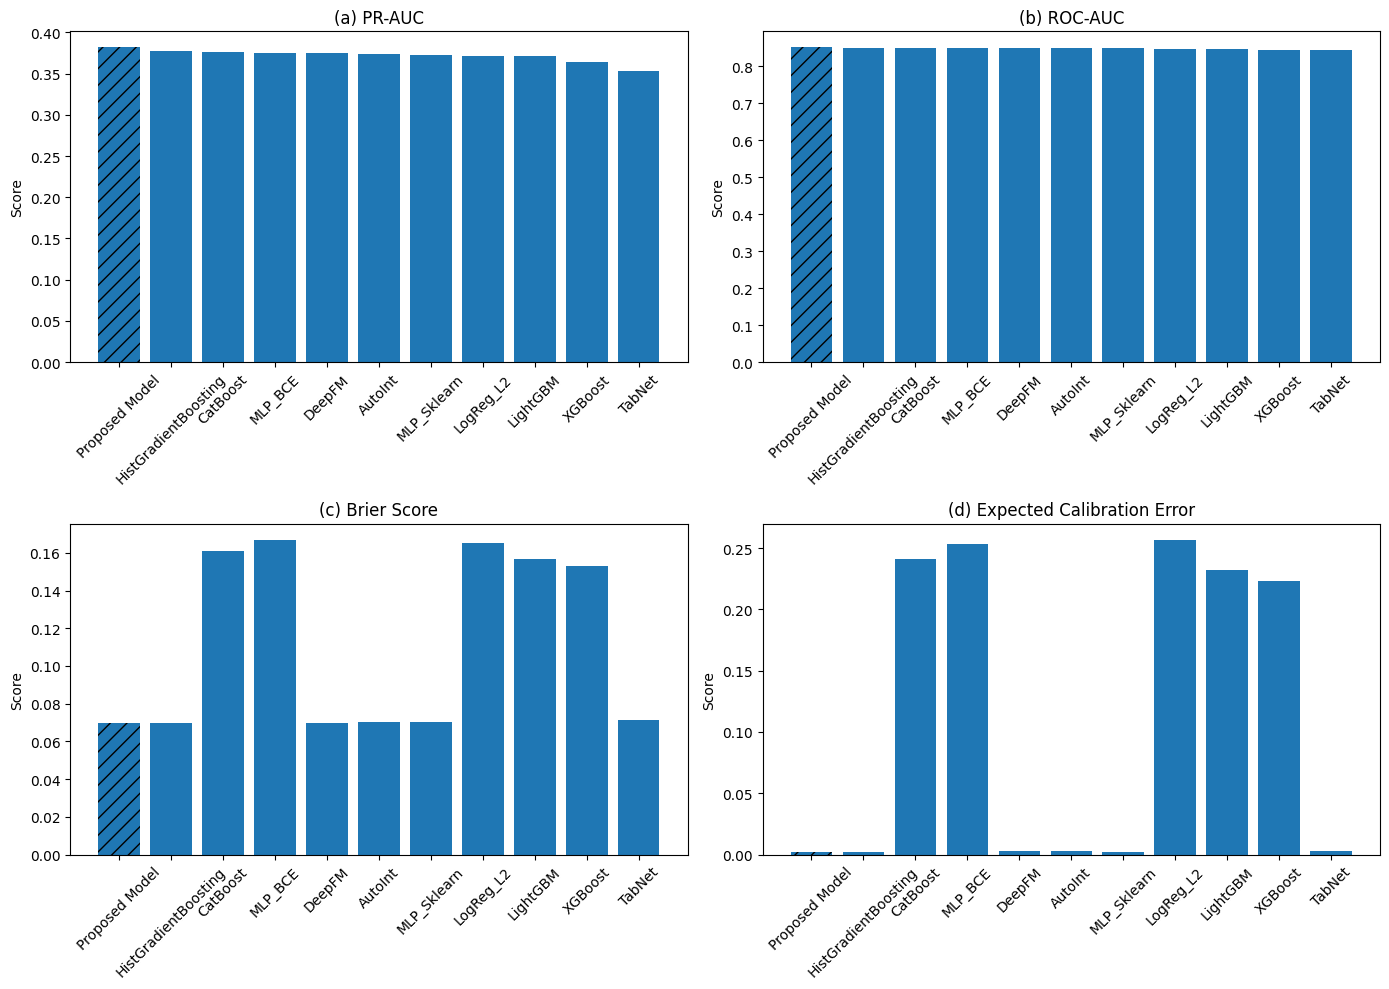

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure1_baseline_plus_proposed_oof_2x2.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure1_baseline_plus_proposed_oof_2x2.pdf
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure1_baseline_plus_proposed_plot_data.csv


In [25]:
# ============================================================
# TABLE 1 + FIGURE 1 (Corrected)
# Table 1 = baselines only
# Figure 1 = baselines + proposed model
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# ------------------------------------------------------------
# Load baseline candidate results
# ------------------------------------------------------------
candidate_path = TAB_DIR / "module4_candidate_results.csv"
if not candidate_path.exists():
    raise FileNotFoundError(f"Could not find: {candidate_path}")

cand_df = pd.read_csv(candidate_path)

# ------------------------------------------------------------
# Load proposed model DEV result
# Priority order:
# 1) final_gate_dev_metrics.csv
# 2) tech2_calibration_aux_comparison.csv -> cal_lambda_0.00
# 3) manually error
# ------------------------------------------------------------
proposed_df = None

final_dev_path = TAB_DIR / "final_gate_dev_metrics.csv"
tech2_path = TAB_DIR / "tech2_calibration_aux_comparison.csv"
light_robfair_path = TAB_DIR / "lightweight_robfair_main_model_comparison.csv"

if final_dev_path.exists():
    proposed_df = pd.read_csv(final_dev_path).copy()
    proposed_df["Model"] = "Proposed Model"
elif tech2_path.exists():
    tmp = pd.read_csv(tech2_path)
    tmp = tmp[tmp["variant"] == "cal_lambda_0.00"].copy()
    if len(tmp) == 0:
        raise ValueError("Could not find cal_lambda_0.00 in tech2_calibration_aux_comparison.csv")
    proposed_df = tmp.copy()
    proposed_df["Model"] = "Proposed Model"
elif light_robfair_path.exists():
    tmp = pd.read_csv(light_robfair_path)
    tmp = tmp[(tmp["variant"] == "baseline_ranked_residual") & (tmp["split"] == "DEV")].copy()
    if len(tmp) == 0:
        raise ValueError("Could not find baseline_ranked_residual DEV row in lightweight_robfair_main_model_comparison.csv")
    proposed_df = tmp.copy()
    proposed_df["Model"] = "Proposed Model"
else:
    raise FileNotFoundError(
        "Could not find proposed model DEV metrics. "
        "Expected one of:\n"
        "- final_gate_dev_metrics.csv\n"
        "- tech2_calibration_aux_comparison.csv\n"
        "- lightweight_robfair_main_model_comparison.csv"
    )

# ------------------------------------------------------------
# Baseline models for Table 1
# ------------------------------------------------------------
BASELINE_MODELS_FOR_TABLE = [
    "HistGradientBoosting",
    "CatBoost",
    "DeepFM",
    "AutoInt",
    "MLP_BCE",
    "MLP_Sklearn",
    "LogReg_L2",
    "LightGBM",
    "XGBoost",
    "TabNet",
]

baseline_df = cand_df[cand_df["model_name"].isin(BASELINE_MODELS_FOR_TABLE)].copy()

if len(baseline_df) == 0:
    raise ValueError("No matching baseline models found in module4_candidate_results.csv")

# ------------------------------------------------------------
# TABLE 1 = baselines only
# ------------------------------------------------------------
table_cols = [
    "model_name",
    "family",
    "PR_AUC",
    "ROC_AUC",
    "Brier",
    "ECE",
    "F1",
    "MCC",
]

baseline_table_df = baseline_df[table_cols].copy()

baseline_table_df = baseline_table_df.rename(columns={
    "model_name": "Model",
    "family": "Family",
    "PR_AUC": "PR-AUC",
    "ROC_AUC": "ROC-AUC",
    "Brier": "Brier",
    "ECE": "ECE",
    "F1": "F1",
    "MCC": "MCC",
})

baseline_table_df = baseline_table_df.sort_values(
    by=["PR-AUC", "ROC-AUC"],
    ascending=[False, False]
).reset_index(drop=True)

baseline_table_disp = baseline_table_df.copy()
for c in ["PR-AUC", "ROC-AUC", "Brier", "ECE", "F1", "MCC"]:
    baseline_table_disp[c] = baseline_table_disp[c].map(lambda x: round(float(x), 4))

print("\n===== TABLE 1: Baseline OOF Comparison =====")
display(baseline_table_disp)

table_csv_path = TAB_DIR / "table1_baseline_oof_comparison.csv"
table_tex_path = TAB_DIR / "table1_baseline_oof_comparison.tex"

baseline_table_disp.to_csv(table_csv_path, index=False)
with open(table_tex_path, "w", encoding="utf-8") as f:
    f.write(baseline_table_disp.to_latex(index=False, escape=False))

print(f"[Saved] {table_csv_path}")
print(f"[Saved] {table_tex_path}")

# ------------------------------------------------------------
# FIGURE 1 = baselines + proposed model
# ------------------------------------------------------------
fig_baseline_df = baseline_df.copy()

# normalize proposed columns
def extract_proposed_metrics_row(df):
    row = df.iloc[0]
    out = {
        "Model": "Proposed Model",
        "PR-AUC": float(row["PR_AUC"]) if "PR_AUC" in row else float(row["PR-AUC"]),
        "ROC-AUC": float(row["ROC_AUC"]) if "ROC_AUC" in row else float(row["ROC-AUC"]),
        "Brier": float(row["Brier"]),
        "ECE": float(row["ECE"]),
        "F1": float(row["F1"]),
        "MCC": float(row["MCC"]),
    }
    return out

proposed_row = extract_proposed_metrics_row(proposed_df)

fig_df = fig_baseline_df.rename(columns={
    "model_name": "Model",
    "PR_AUC": "PR-AUC",
    "ROC_AUC": "ROC-AUC",
})

fig_df = fig_df[["Model", "PR-AUC", "ROC-AUC", "Brier", "ECE", "F1", "MCC"]].copy()

fig_df = pd.concat(
    [fig_df, pd.DataFrame([proposed_row])],
    ignore_index=True
)

# sort by PR-AUC for plotting
fig_df = fig_df.sort_values(by=["PR-AUC", "ROC-AUC"], ascending=[False, False]).reset_index(drop=True)

print("\n===== FIGURE 1 PLOT DATA (Baselines + Proposed) =====")
display(fig_df)

# ------------------------------------------------------------
# 2x2 metric figure block
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

models = fig_df["Model"].tolist()
x = np.arange(len(models))

# helper to bold/mark proposed visually using hatch on last matching bar
def draw_metric(ax, values, title, ylabel):
    bars = ax.bar(models, values)
    for i, m in enumerate(models):
        if m == "Proposed Model":
            bars[i].set_linewidth(1.8)
            bars[i].set_hatch("//")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)

draw_metric(axes[0, 0], fig_df["PR-AUC"], "(a) PR-AUC", "Score")
draw_metric(axes[0, 1], fig_df["ROC-AUC"], "(b) ROC-AUC", "Score")
draw_metric(axes[1, 0], fig_df["Brier"], "(c) Brier Score", "Score")
draw_metric(axes[1, 1], fig_df["ECE"], "(d) Expected Calibration Error", "Score")

plt.tight_layout()

fig_png_path = FIG_DIR / "figure1_baseline_plus_proposed_oof_2x2"
plt.savefig(fig_png_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_png_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig_png_path.with_suffix('.png')}")
print(f"[Saved] {fig_png_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Save plot data
# ------------------------------------------------------------
plot_export_path = TAB_DIR / "figure1_baseline_plus_proposed_plot_data.csv"
fig_df.to_csv(plot_export_path, index=False)
print(f"[Saved] {plot_export_path}")

Loaded:
- /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/module4_candidate_results.csv
- /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/module4_candidate_oof_matrix.csv

===== TABLE 2: Expert Diversity and Selection Justification =====


,Model,Family,PR-AUC,ROC-AUC,Brier,ECE,AvgCorrToOthers,AvgAbsDiffToOthers,AvgBinaryDisagreement,Selected
0,HistGradientBoosting,gradient_boosting,0.3774,0.8496,0.0699,0.0022,0.9249,0.1418,0.1650,✓
1,CatBoost,gradient_boosting,0.3760,0.8483,0.1607,0.2415,0.9320,0.1489,0.1796,
2,MLP_BCE,deep_mlp,0.3755,0.8490,0.1670,0.2533,0.9253,0.1591,0.1944,✓
3,DeepFM,deep_tabular,0.3754,0.8484,0.0700,0.0029,0.9338,0.1401,0.1651,✓
4,AutoInt,deep_tabular,0.3733,0.8476,0.0702,0.0031,0.9263,0.1423,0.1649,
5,MLP_Sklearn,deep_mlp,0.3725,0.8477,0.0702,0.0022,0.9211,0.1435,0.1660,
6,LogReg_L2,linear,0.3717,0.8474,0.1650,0.2569,0.9346,0.1641,0.1822,
7,LightGBM,gradient_boosting,0.3713,0.8460,0.1568,0.2319,0.9286,0.1452,0.1773,
8,XGBoost,gradient_boosting,0.3642,0.8420,0.1531,0.2235,0.9226,0.1439,0.1747,
9,TabNet,deep_tabular,0.3537,0.8425,0.0711,0.0026,0.9020,0.1438,0.1674,


[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table2_expert_diversity_selection.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table2_expert_diversity_selection.tex


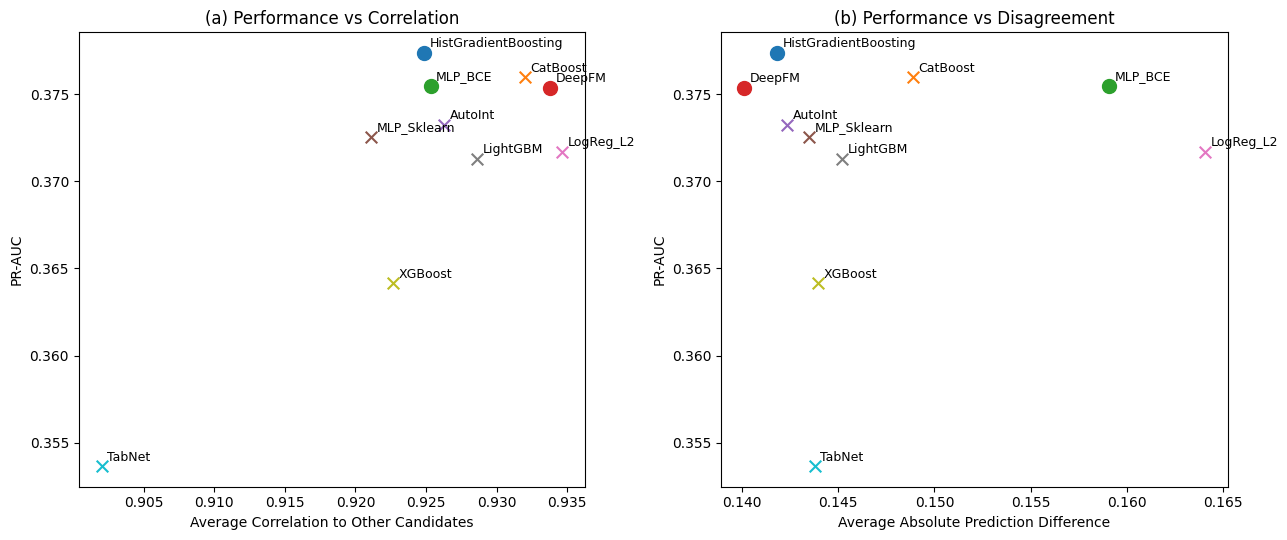

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure2_expert_diversity_selection.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure2_expert_diversity_selection.pdf
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure2_expert_diversity_plot_data.csv


In [26]:
# ============================================================
# TABLE 2 + FIGURE 2
# Expert diversity and expert selection justification
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

candidate_results_path = TAB_DIR / "module4_candidate_results.csv"
oof_matrix_path = PRED_DIR / "module4_candidate_oof_matrix.csv"

if not candidate_results_path.exists():
    raise FileNotFoundError(f"Could not find: {candidate_results_path}")
if not oof_matrix_path.exists():
    raise FileNotFoundError(f"Could not find: {oof_matrix_path}")

cand_df = pd.read_csv(candidate_results_path)
oof_df = pd.read_csv(oof_matrix_path)

print("Loaded:")
print("-", candidate_results_path)
print("-", oof_matrix_path)

# ------------------------------------------------------------
# Selected experts used in the final model
# ------------------------------------------------------------
SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

# ------------------------------------------------------------
# Candidate pool to show in diversity table/figure
# Keep strong and relevant models only
# ------------------------------------------------------------
CANDIDATES_FOR_DIVERSITY = [
    "HistGradientBoosting",
    "CatBoost",
    "DeepFM",
    "AutoInt",
    "MLP_BCE",
    "MLP_Sklearn",
    "LogReg_L2",
    "LightGBM",
    "XGBoost",
    "TabNet",
]

cand_df = cand_df[cand_df["model_name"].isin(CANDIDATES_FOR_DIVERSITY)].copy().reset_index(drop=True)

# ------------------------------------------------------------
# Build diversity statistics
# ------------------------------------------------------------
pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]

available_models = [m for m in CANDIDATES_FOR_DIVERSITY if m in pred_cols]
if len(available_models) == 0:
    raise ValueError("None of the requested candidate models are present in module4_candidate_oof_matrix.csv")

pred_mat = oof_df[available_models].copy()

corr_mat = pred_mat.corr()

# average absolute difference / disagreement utilities
def avg_abs_diff_to_others(model_name, pred_df):
    p = pred_df[model_name].values
    others = [c for c in pred_df.columns if c != model_name]
    if len(others) == 0:
        return np.nan
    vals = []
    for c in others:
        vals.append(np.mean(np.abs(p - pred_df[c].values)))
    return float(np.mean(vals))

def avg_binary_disagreement_to_others(model_name, pred_df, thr=0.5):
    p_bin = (pred_df[model_name].values >= thr).astype(int)
    others = [c for c in pred_df.columns if c != model_name]
    if len(others) == 0:
        return np.nan
    vals = []
    for c in others:
        q_bin = (pred_df[c].values >= thr).astype(int)
        vals.append(np.mean(p_bin != q_bin))
    return float(np.mean(vals))

rows = []
for model_name in available_models:
    perf_row = cand_df[cand_df["model_name"] == model_name]
    if len(perf_row) == 0:
        continue
    perf_row = perf_row.iloc[0]

    others = [c for c in available_models if c != model_name]
    avg_corr = float(corr_mat.loc[model_name, others].mean()) if len(others) > 0 else np.nan

    rows.append({
        "Model": model_name,
        "Family": perf_row["family"] if "family" in perf_row else "",
        "PR-AUC": float(perf_row["PR_AUC"]),
        "ROC-AUC": float(perf_row["ROC_AUC"]),
        "Brier": float(perf_row["Brier"]),
        "ECE": float(perf_row["ECE"]),
        "AvgCorrToOthers": avg_corr,
        "AvgAbsDiffToOthers": avg_abs_diff_to_others(model_name, pred_mat),
        "AvgBinaryDisagreement": avg_binary_disagreement_to_others(model_name, pred_mat, thr=0.5),
        "Selected": "✓" if model_name in SELECTED_EXPERTS else "",
    })

diversity_df = pd.DataFrame(rows)

# sort: selected first? better to sort by PR-AUC desc
diversity_df = diversity_df.sort_values(
    by=["PR-AUC", "ROC-AUC"],
    ascending=[False, False]
).reset_index(drop=True)

# rounded display/export version
diversity_disp = diversity_df.copy()
for c in ["PR-AUC", "ROC-AUC", "Brier", "ECE", "AvgCorrToOthers", "AvgAbsDiffToOthers", "AvgBinaryDisagreement"]:
    diversity_disp[c] = diversity_disp[c].map(lambda x: round(float(x), 4))

print("\n===== TABLE 2: Expert Diversity and Selection Justification =====")
display(diversity_disp)

# ------------------------------------------------------------
# Save Table 2
# ------------------------------------------------------------
table2_csv_path = TAB_DIR / "table2_expert_diversity_selection.csv"
table2_tex_path = TAB_DIR / "table2_expert_diversity_selection.tex"

diversity_disp.to_csv(table2_csv_path, index=False)

with open(table2_tex_path, "w", encoding="utf-8") as f:
    f.write(diversity_disp.to_latex(index=False, escape=False))

print(f"[Saved] {table2_csv_path}")
print(f"[Saved] {table2_tex_path}")

# ------------------------------------------------------------
# Figure 2: 2-panel scatter block
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# mark selected vs non-selected
selected_mask = diversity_df["Model"].isin(SELECTED_EXPERTS)

# ---- Panel (a): PR-AUC vs Avg Corr ----
for _, row in diversity_df.iterrows():
    x = row["AvgCorrToOthers"]
    y = row["PR-AUC"]
    label = row["Model"]

    if row["Model"] in SELECTED_EXPERTS:
        axes[0].scatter(x, y, s=100, marker="o")
    else:
        axes[0].scatter(x, y, s=70, marker="x")

    axes[0].annotate(label, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)

axes[0].set_xlabel("Average Correlation to Other Candidates")
axes[0].set_ylabel("PR-AUC")
axes[0].set_title("(a) Performance vs Correlation")

# ---- Panel (b): PR-AUC vs Avg Abs Diff ----
for _, row in diversity_df.iterrows():
    x = row["AvgAbsDiffToOthers"]
    y = row["PR-AUC"]
    label = row["Model"]

    if row["Model"] in SELECTED_EXPERTS:
        axes[1].scatter(x, y, s=100, marker="o")
    else:
        axes[1].scatter(x, y, s=70, marker="x")

    axes[1].annotate(label, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)

axes[1].set_xlabel("Average Absolute Prediction Difference")
axes[1].set_ylabel("PR-AUC")
axes[1].set_title("(b) Performance vs Disagreement")

plt.tight_layout()

fig2_path = FIG_DIR / "figure2_expert_diversity_selection"
plt.savefig(fig2_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig2_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig2_path.with_suffix('.png')}")
print(f"[Saved] {fig2_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Optional export of figure data
# ------------------------------------------------------------
fig2_data_path = TAB_DIR / "figure2_expert_diversity_plot_data.csv"
diversity_df.to_csv(fig2_data_path, index=False)
print(f"[Saved] {fig2_data_path}")

Loaded: /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_gate_weights.csv


,w_HistGradientBoosting,w_DeepFM,w_MLP_BCE,row_idx_holdout,dominant_expert,gate_entropy,residual
0,0.344914,0.302724,0.352362,0,MLP_BCE,1.096430,0.007041
1,0.336344,0.323806,0.339850,1,MLP_BCE,1.098398,-0.000406
2,0.335632,0.329146,0.335221,2,HistGradientBoosting,1.098573,0.000418
3,0.321383,0.326160,0.352456,3,MLP_BCE,1.097779,0.002450
4,0.338752,0.315518,0.345730,4,MLP_BCE,1.097856,0.002021



===== TABLE 3: Trust-Aware Gating Behavior Summary =====


,Expert,MeanGateWeight,StdGateWeight,DominantUsageRate,MeanGateEntropy,StdGateEntropy
0,HistGradientBoosting,0.3360,0.0135,0.3308,NaN,NaN
1,DeepFM,0.3289,0.0116,0.2441,NaN,NaN
2,MLP_BCE,0.3351,0.0094,0.4252,NaN,NaN
3,Overall,NaN,NaN,NaN,1.098,0.004


[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table3_gating_behavior_summary.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table3_gating_behavior_summary.tex


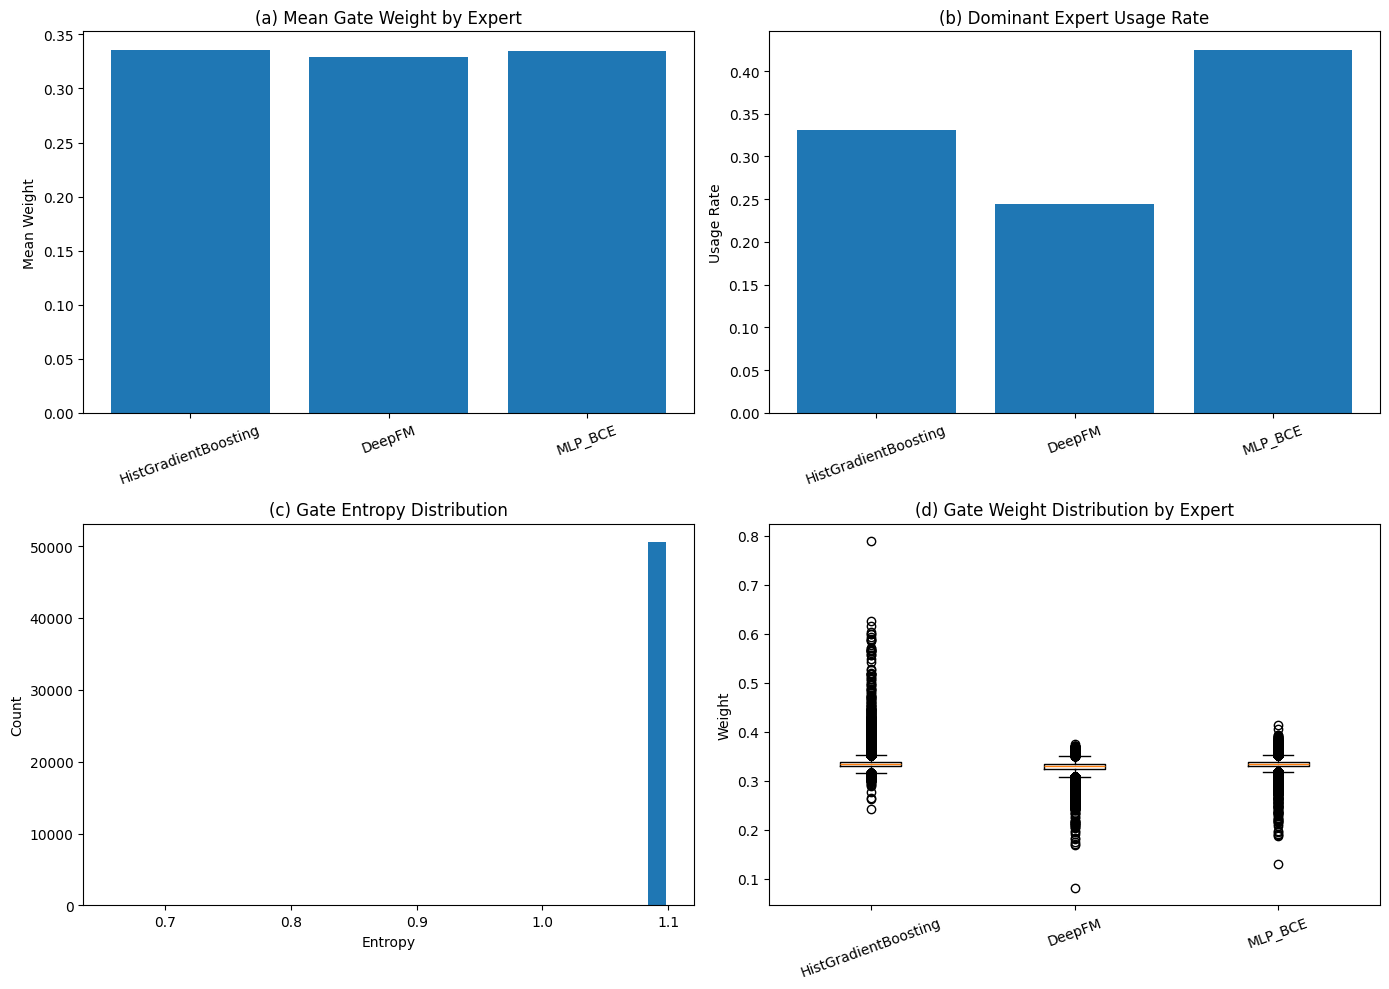

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure3_gating_behavior_usage.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure3_gating_behavior_usage.pdf
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure3_gating_behavior_plot_data.csv


In [27]:
# ============================================================
# TABLE 3 + FIGURE 3
# Trust-aware gating behavior and expert usage
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]

# ------------------------------------------------------------
# Locate gate weight file
# ------------------------------------------------------------
candidate_weight_files = [
    PRED_DIR / "final_holdout_gate_weights.csv",  # holdout
    PRED_DIR / "tech1_global_gate_ranked_residual_dev_weights.csv",
    PRED_DIR / "tech2_cal_lambda_0.00_dev_weights.csv",
    PRED_DIR / "light_robfair_baseline_ranked_residual_dev_weights.csv",
    PRED_DIR / "robfair_baseline_ranked_residual_dev_weights.csv",
]

weight_path = None
for p in candidate_weight_files:
    if p.exists():
        weight_path = p
        break

if weight_path is None:
    raise FileNotFoundError(
        "Could not find a gate weight file. Expected one of:\n" +
        "\n".join(str(p) for p in candidate_weight_files)
    )

gate_df = pd.read_csv(weight_path)
print("Loaded:", weight_path)
display(gate_df.head())

# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------
weight_cols = [f"w_{e}" for e in SELECTED_EXPERTS]
missing_cols = [c for c in weight_cols if c not in gate_df.columns]
if missing_cols:
    raise ValueError(f"Missing expected gate weight columns: {missing_cols}")

if "dominant_expert" not in gate_df.columns:
    gate_df["dominant_expert"] = np.array(SELECTED_EXPERTS)[
        np.argmax(gate_df[weight_cols].values, axis=1)
    ]

if "gate_entropy" not in gate_df.columns:
    W = np.clip(gate_df[weight_cols].values.astype(float), 1e-8, 1.0)
    gate_df["gate_entropy"] = -(W * np.log(W)).sum(axis=1)

# ------------------------------------------------------------
# TABLE 3: summary statistics
# ------------------------------------------------------------
mean_weight_dict = {
    e: float(gate_df[f"w_{e}"].mean()) for e in SELECTED_EXPERTS
}
std_weight_dict = {
    e: float(gate_df[f"w_{e}"].std()) for e in SELECTED_EXPERTS
}
dominant_usage_dict = {
    e: float((gate_df["dominant_expert"] == e).mean()) for e in SELECTED_EXPERTS
}

rows = []
for e in SELECTED_EXPERTS:
    rows.append({
        "Expert": e,
        "MeanGateWeight": mean_weight_dict[e],
        "StdGateWeight": std_weight_dict[e],
        "DominantUsageRate": dominant_usage_dict[e],
    })

table3_df = pd.DataFrame(rows)

# add overall entropy summary
entropy_summary = pd.DataFrame([{
    "Expert": "Overall",
    "MeanGateWeight": np.nan,
    "StdGateWeight": np.nan,
    "DominantUsageRate": np.nan,
    "MeanGateEntropy": float(gate_df["gate_entropy"].mean()),
    "StdGateEntropy": float(gate_df["gate_entropy"].std()),
}])

table3_df["MeanGateEntropy"] = np.nan
table3_df["StdGateEntropy"] = np.nan

table3_disp = pd.concat([table3_df, entropy_summary], ignore_index=True)

for c in ["MeanGateWeight", "StdGateWeight", "DominantUsageRate", "MeanGateEntropy", "StdGateEntropy"]:
    if c in table3_disp.columns:
        table3_disp[c] = table3_disp[c].map(lambda x: round(float(x), 4) if pd.notnull(x) else x)

print("\n===== TABLE 3: Trust-Aware Gating Behavior Summary =====")
display(table3_disp)

# ------------------------------------------------------------
# Save Table 3
# ------------------------------------------------------------
table3_csv_path = TAB_DIR / "table3_gating_behavior_summary.csv"
table3_tex_path = TAB_DIR / "table3_gating_behavior_summary.tex"

table3_disp.to_csv(table3_csv_path, index=False)
with open(table3_tex_path, "w", encoding="utf-8") as f:
    f.write(table3_disp.to_latex(index=False, escape=False))

print(f"[Saved] {table3_csv_path}")
print(f"[Saved] {table3_tex_path}")

# ------------------------------------------------------------
# Figure 3: 2x2 block
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Mean gate weight per expert
axes[0, 0].bar(
    table3_df["Expert"],
    table3_df["MeanGateWeight"]
)
axes[0, 0].set_title("(a) Mean Gate Weight by Expert")
axes[0, 0].set_ylabel("Mean Weight")
axes[0, 0].tick_params(axis="x", rotation=20)

# (b) Dominant expert usage rate
axes[0, 1].bar(
    table3_df["Expert"],
    table3_df["DominantUsageRate"]
)
axes[0, 1].set_title("(b) Dominant Expert Usage Rate")
axes[0, 1].set_ylabel("Usage Rate")
axes[0, 1].tick_params(axis="x", rotation=20)

# (c) Gate entropy distribution
axes[1, 0].hist(gate_df["gate_entropy"].values, bins=30)
axes[1, 0].set_title("(c) Gate Entropy Distribution")
axes[1, 0].set_xlabel("Entropy")
axes[1, 0].set_ylabel("Count")

# (d) Weight distribution by expert
weight_values = [gate_df[f"w_{e}"].values for e in SELECTED_EXPERTS]
axes[1, 1].boxplot(weight_values, tick_labels=SELECTED_EXPERTS)
axes[1, 1].set_title("(d) Gate Weight Distribution by Expert")
axes[1, 1].set_ylabel("Weight")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()

fig3_path = FIG_DIR / "figure3_gating_behavior_usage"
plt.savefig(fig3_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig3_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig3_path.with_suffix('.png')}")
print(f"[Saved] {fig3_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Optional export for later analysis
# ------------------------------------------------------------
fig3_data_path = TAB_DIR / "figure3_gating_behavior_plot_data.csv"
gate_df.to_csv(fig3_data_path, index=False)
print(f"[Saved] {fig3_data_path}")

Loaded:
- /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_gate_predictions.csv
- /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_gate_weights.csv
Split: HOLDOUT


,row_idx_holdout,y_true,pred
0,0,0,0.307070
1,1,0,0.062572
2,2,0,0.012482
3,3,0,0.124419
4,4,0,0.078052


,w_HistGradientBoosting,w_DeepFM,w_MLP_BCE,row_idx_holdout,dominant_expert,gate_entropy,residual
0,0.344914,0.302724,0.352362,0,MLP_BCE,1.096430,0.007041
1,0.336344,0.323806,0.339850,1,MLP_BCE,1.098398,-0.000406
2,0.335632,0.329146,0.335221,2,HistGradientBoosting,1.098573,0.000418
3,0.321383,0.326160,0.352456,3,MLP_BCE,1.097779,0.002450
4,0.338752,0.315518,0.345730,4,MLP_BCE,1.097856,0.002021



===== TABLE 4: Uncertainty Concentration / Hard-Band Justification =====


,Split,TotalSamples,HardBandSamples,HardBandCoverage,TotalErrors@0.5,HardBandErrors@0.5,ErrorCaptureRate,HardBandPositiveRate,HardBandMeanPrediction,HardBandErrorRate,NonHardErrorRate,UncertaintyThreshold
0,HOLDOUT,50736,3400,0.067,4677,1384,0.2959,0.4182,0.4287,0.4071,0.0696,0.8049


[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table4_uncertainty_hardband_summary.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table4_uncertainty_hardband_summary.tex


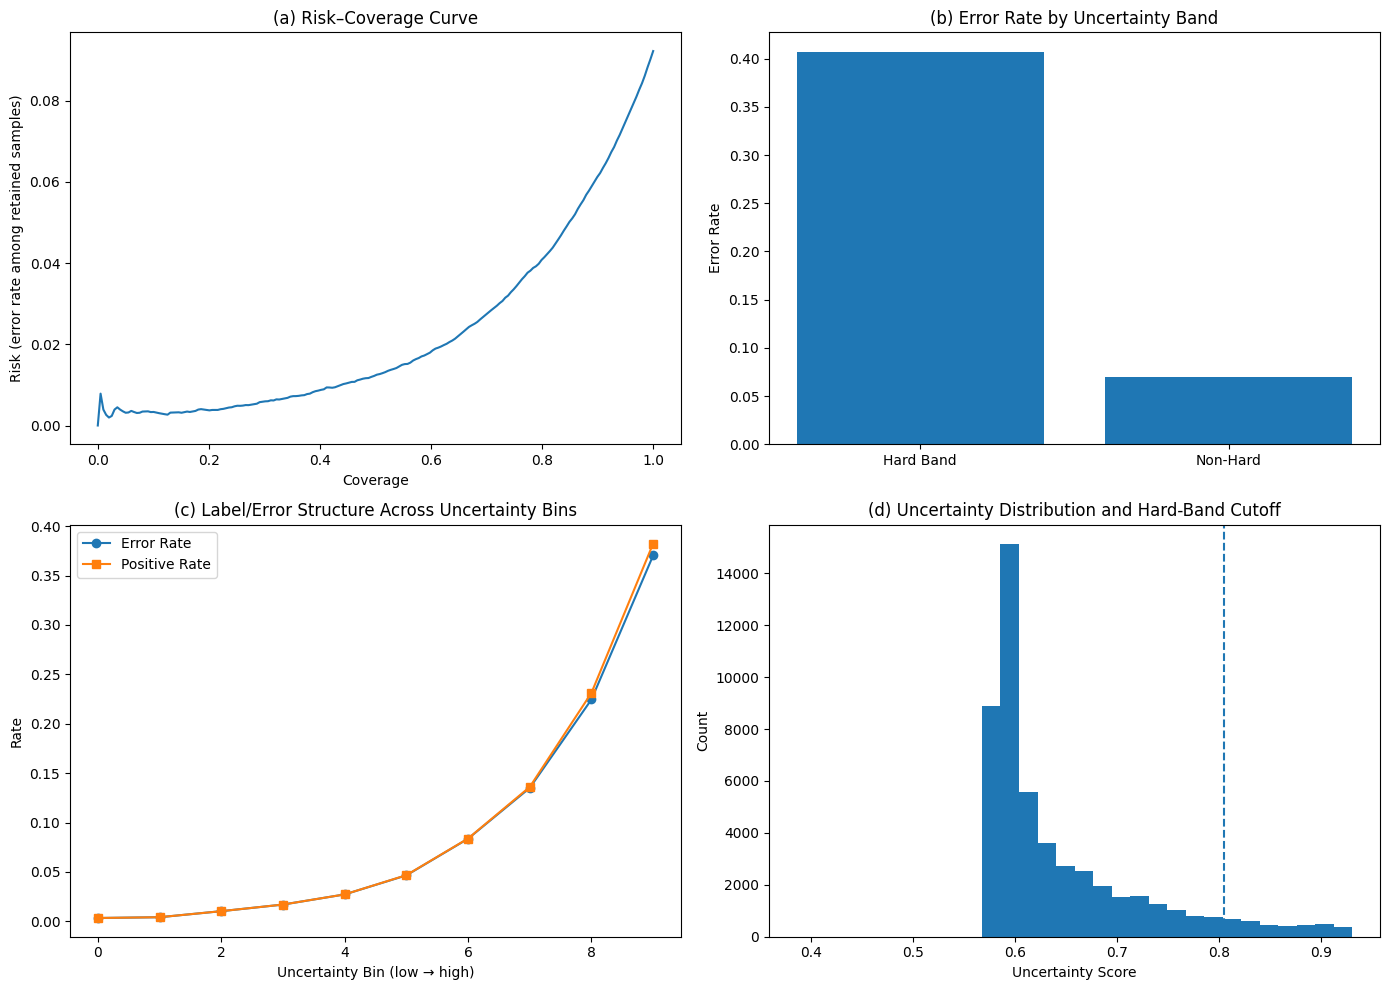

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure4_uncertainty_risk_coverage_hardband.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure4_uncertainty_risk_coverage_hardband.pdf
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure4_risk_coverage_plot_data.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure4_uncertainty_bin_summary.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure4_uncertainty_full_data.csv


In [28]:
# ============================================================
# TABLE 4 + FIGURE 4
# Uncertainty concentration / risk-coverage / hard-band justification
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
weight_cols = [f"w_{e}" for e in SELECTED_EXPERTS]

# ------------------------------------------------------------
# Locate prediction + weight files
# ------------------------------------------------------------
candidate_pairs = [
    (
        PRED_DIR / "final_holdout_gate_predictions.csv",
        PRED_DIR / "final_holdout_gate_weights.csv",
        "HOLDOUT"
    ),
    (
        PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
        PRED_DIR / "tech1_global_gate_ranked_residual_dev_weights.csv",
        "DEV"
    ),
    (
        PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
        PRED_DIR / "tech2_cal_lambda_0.00_dev_weights.csv",
        "DEV"
    ),
    (
        PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
        PRED_DIR / "light_robfair_baseline_ranked_residual_dev_weights.csv",
        "DEV"
    ),
]

pred_path, weight_path, split_name = None, None, None
for pp, wp, sp in candidate_pairs:
    if pp.exists() and wp.exists():
        pred_path, weight_path, split_name = pp, wp, sp
        break

if pred_path is None:
    raise FileNotFoundError(
        "Could not find suitable prediction/weight file pair.\nExpected one of:\n" +
        "\n".join([f"{a}  +  {b}" for a, b, _ in candidate_pairs])
    )

pred_df = pd.read_csv(pred_path)
gate_df = pd.read_csv(weight_path)

print("Loaded:")
print("-", pred_path)
print("-", weight_path)
print("Split:", split_name)

display(pred_df.head())
display(gate_df.head())

# ------------------------------------------------------------
# Validate columns
# ------------------------------------------------------------
required_pred_cols = ["y_true", "pred"]
missing_pred = [c for c in required_pred_cols if c not in pred_df.columns]
if missing_pred:
    raise ValueError(f"Missing required prediction columns: {missing_pred}")

missing_w = [c for c in weight_cols if c not in gate_df.columns]
if missing_w:
    raise ValueError(f"Missing expected gate weight columns: {missing_w}")

if len(pred_df) != len(gate_df):
    raise ValueError(f"Prediction file and weight file row count mismatch: {len(pred_df)} vs {len(gate_df)}")

# ------------------------------------------------------------
# Build merged analysis frame
# ------------------------------------------------------------
df = pd.DataFrame({
    "y_true": pred_df["y_true"].astype(int).values,
    "pred": pred_df["pred"].astype(float).values,
})

for c in weight_cols:
    df[c] = gate_df[c].astype(float).values

if "gate_entropy" in gate_df.columns:
    df["gate_entropy"] = gate_df["gate_entropy"].astype(float).values
else:
    W = np.clip(df[weight_cols].values.astype(float), 1e-8, 1.0)
    df["gate_entropy"] = -(W * np.log(W)).sum(axis=1)

if "residual" in gate_df.columns:
    df["residual"] = gate_df["residual"].astype(float).values

# uncertainty score:
# combine entropy + closeness to decision boundary + low dominance
dominant_weight = df[weight_cols].max(axis=1).values
margin = np.abs(df["pred"].values - 0.5)

# normalize components
ent = df["gate_entropy"].values
ent_norm = (ent - ent.min()) / (max(ent.max() - ent.min(), 1e-8))
margin_unc = 1.0 - np.clip(2.0 * margin, 0.0, 1.0)
dominance_unc = 1.0 - dominant_weight

df["uncertainty_score"] = (
    0.45 * ent_norm +
    0.35 * margin_unc +
    0.20 * dominance_unc
)

# prediction error at 0.5
df["y_hat_05"] = (df["pred"].values >= 0.5).astype(int)
df["is_error_05"] = (df["y_hat_05"].values != df["y_true"].values).astype(int)

# ------------------------------------------------------------
# Hard-band definition
# top 6.5-7% by uncertainty, matching your earlier narrative
# ------------------------------------------------------------
hard_frac = 0.067
hard_threshold = df["uncertainty_score"].quantile(1.0 - hard_frac)

df["band"] = "non-hard"
df.loc[df["uncertainty_score"] >= hard_threshold, "band"] = "hard"

n_total = len(df)
n_hard = int((df["band"] == "hard").sum())
hard_coverage = n_hard / n_total

total_errors = int(df["is_error_05"].sum())
hard_errors = int(df.loc[df["band"] == "hard", "is_error_05"].sum())
error_capture_rate = hard_errors / max(total_errors, 1)

hard_pos_rate = float(df.loc[df["band"] == "hard", "y_true"].mean()) if n_hard > 0 else np.nan
hard_pred_mean = float(df.loc[df["band"] == "hard", "pred"].mean()) if n_hard > 0 else np.nan
hard_error_rate = float(df.loc[df["band"] == "hard", "is_error_05"].mean()) if n_hard > 0 else np.nan
nonhard_error_rate = float(df.loc[df["band"] == "non-hard", "is_error_05"].mean())

# ------------------------------------------------------------
# Table 4
# ------------------------------------------------------------
table4_df = pd.DataFrame([
    {
        "Split": split_name,
        "TotalSamples": n_total,
        "HardBandSamples": n_hard,
        "HardBandCoverage": hard_coverage,
        "TotalErrors@0.5": total_errors,
        "HardBandErrors@0.5": hard_errors,
        "ErrorCaptureRate": error_capture_rate,
        "HardBandPositiveRate": hard_pos_rate,
        "HardBandMeanPrediction": hard_pred_mean,
        "HardBandErrorRate": hard_error_rate,
        "NonHardErrorRate": nonhard_error_rate,
        "UncertaintyThreshold": hard_threshold,
    }
])

table4_disp = table4_df.copy()
for c in [
    "HardBandCoverage", "ErrorCaptureRate", "HardBandPositiveRate",
    "HardBandMeanPrediction", "HardBandErrorRate", "NonHardErrorRate",
    "UncertaintyThreshold"
]:
    table4_disp[c] = table4_disp[c].map(lambda x: round(float(x), 4))

print("\n===== TABLE 4: Uncertainty Concentration / Hard-Band Justification =====")
display(table4_disp)

table4_csv_path = TAB_DIR / "table4_uncertainty_hardband_summary.csv"
table4_tex_path = TAB_DIR / "table4_uncertainty_hardband_summary.tex"

table4_disp.to_csv(table4_csv_path, index=False)
with open(table4_tex_path, "w", encoding="utf-8") as f:
    f.write(table4_disp.to_latex(index=False, escape=False))

print(f"[Saved] {table4_csv_path}")
print(f"[Saved] {table4_tex_path}")

# ------------------------------------------------------------
# Risk-coverage curve
# retain lowest-uncertainty samples first
# ------------------------------------------------------------
risk_df = df.sort_values("uncertainty_score", ascending=True).reset_index(drop=True)
risk_df["cum_errors"] = risk_df["is_error_05"].cumsum()
risk_df["coverage"] = (np.arange(len(risk_df)) + 1) / len(risk_df)
risk_df["risk"] = risk_df["cum_errors"] / (np.arange(len(risk_df)) + 1)

# downsample for plotting
n_plot = 200
idx = np.linspace(0, len(risk_df) - 1, n_plot).astype(int)
risk_plot_df = risk_df.iloc[idx].copy()

# ------------------------------------------------------------
# Error concentration by uncertainty deciles
# ------------------------------------------------------------
df["uncertainty_bin"] = pd.qcut(df["uncertainty_score"], q=10, labels=False, duplicates="drop")
bin_summary = (
    df.groupby("uncertainty_bin", as_index=False)
      .agg(
          n=("y_true", "count"),
          error_rate=("is_error_05", "mean"),
          positive_rate=("y_true", "mean"),
          mean_uncertainty=("uncertainty_score", "mean"),
      )
)

# ------------------------------------------------------------
# Figure 4: 2x2 block
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) risk-coverage
axes[0, 0].plot(risk_plot_df["coverage"], risk_plot_df["risk"])
axes[0, 0].set_title("(a) Risk–Coverage Curve")
axes[0, 0].set_xlabel("Coverage")
axes[0, 0].set_ylabel("Risk (error rate among retained samples)")

# (b) error concentration: hard vs non-hard
axes[0, 1].bar(
    ["Hard Band", "Non-Hard"],
    [hard_error_rate, nonhard_error_rate]
)
axes[0, 1].set_title("(b) Error Rate by Uncertainty Band")
axes[0, 1].set_ylabel("Error Rate")

# (c) positive rate / error rate across uncertainty bins
axes[1, 0].plot(bin_summary["uncertainty_bin"], bin_summary["error_rate"], marker="o", label="Error Rate")
axes[1, 0].plot(bin_summary["uncertainty_bin"], bin_summary["positive_rate"], marker="s", label="Positive Rate")
axes[1, 0].set_title("(c) Label/Error Structure Across Uncertainty Bins")
axes[1, 0].set_xlabel("Uncertainty Bin (low → high)")
axes[1, 0].set_ylabel("Rate")
axes[1, 0].legend()

# (d) uncertainty distribution with hard threshold
axes[1, 1].hist(df["uncertainty_score"].values, bins=30)
axes[1, 1].axvline(hard_threshold, linestyle="--")
axes[1, 1].set_title("(d) Uncertainty Distribution and Hard-Band Cutoff")
axes[1, 1].set_xlabel("Uncertainty Score")
axes[1, 1].set_ylabel("Count")

plt.tight_layout()

fig4_path = FIG_DIR / "figure4_uncertainty_risk_coverage_hardband"
plt.savefig(fig4_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig4_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig4_path.with_suffix('.png')}")
print(f"[Saved] {fig4_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Save plot data
# ------------------------------------------------------------
risk_plot_path = TAB_DIR / "figure4_risk_coverage_plot_data.csv"
bin_plot_path = TAB_DIR / "figure4_uncertainty_bin_summary.csv"
full_unc_path = TAB_DIR / "figure4_uncertainty_full_data.csv"

risk_plot_df[["coverage", "risk"]].to_csv(risk_plot_path, index=False)
bin_summary.to_csv(bin_plot_path, index=False)
df.to_csv(full_unc_path, index=False)

print(f"[Saved] {risk_plot_path}")
print(f"[Saved] {bin_plot_path}")
print(f"[Saved] {full_unc_path}")

Loaded: /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_gate_predictions.csv
Split: HOLDOUT


,row_idx_holdout,y_true,pred
0,0,0,0.307070
1,1,0,0.062572
2,2,0,0.012482
3,3,0,0.124419
4,4,0,0.078052



===== TABLE 5: Threshold Policy Comparison =====


,Policy,Threshold,PR_AUC,ROC_AUC,Brier,ECE,Precision,Recall,F1,Accuracy,MCC,PredPosRate,N
0,Best F1,0.185,0.3733,0.8508,0.0699,0.0023,0.3218,0.6213,0.4240,0.8410,0.3674,0.1818,50736.0
1,Precision >= 0.30 (max Recall),0.160,0.3733,0.8508,0.0699,0.0023,0.3007,0.6750,0.4161,0.8215,0.3661,0.2114,50736.0
2,Recall >= 0.50 (max Precision),0.230,0.3733,0.8508,0.0699,0.0023,0.3582,0.5030,0.4184,0.8683,0.3529,0.1323,50736.0
3,Default Threshold = 0.50,0.500,0.3733,0.8508,0.0699,0.0023,0.5607,0.0986,0.1676,0.9078,0.2072,0.0166,50736.0


[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table5_threshold_policy_comparison.csv
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table5_threshold_policy_comparison.tex
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/table5_threshold_sweep_full.csv


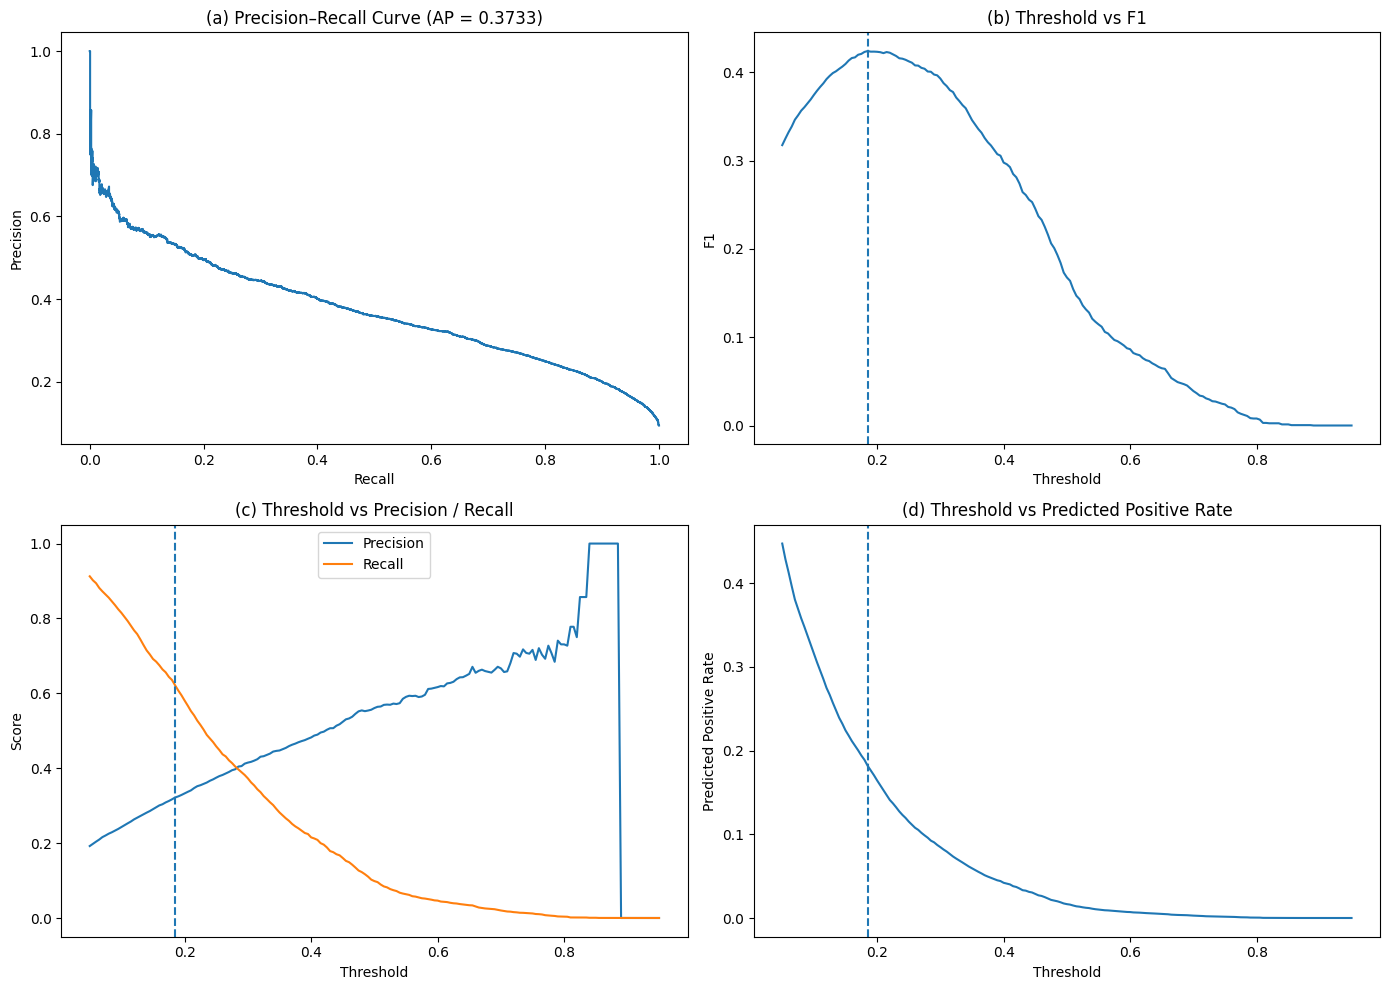

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure5_threshold_policy_decision_behavior.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/figure5_threshold_policy_decision_behavior.pdf
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/tables/figure5_precision_recall_curve_data.csv


In [29]:
# ============================================================
# TABLE 5 + FIGURE 5
# Threshold policy / decision behavior analysis
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    matthews_corrcoef,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# ------------------------------------------------------------
# Locate prediction file
# ------------------------------------------------------------
candidate_pred_files = [
    (PRED_DIR / "final_holdout_gate_predictions.csv", "HOLDOUT"),
    (PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv", "DEV"),
    (PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv", "DEV"),
    (PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv", "DEV"),
]

pred_path, split_name = None, None
for p, s in candidate_pred_files:
    if p.exists():
        pred_path, split_name = p, s
        break

if pred_path is None:
    raise FileNotFoundError(
        "Could not find a proposed-model prediction file. Expected one of:\n" +
        "\n".join(str(p) for p, _ in candidate_pred_files)
    )

pred_df = pd.read_csv(pred_path)
print("Loaded:", pred_path)
print("Split:", split_name)
display(pred_df.head())

required_cols = ["y_true", "pred"]
missing_pred = [c for c in required_cols if c not in pred_df.columns]
if missing_pred:
    raise ValueError(f"Missing required columns in prediction file: {missing_pred}")

y_true = pred_df["y_true"].astype(int).values
p = np.clip(pred_df["pred"].astype(float).values, 1e-8, 1 - 1e-8)

# ------------------------------------------------------------
# Metric helper
# ------------------------------------------------------------
def compute_metrics_at_threshold(y_true, p, thr):
    y_hat = (p >= thr).astype(int)

    # ECE
    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(p, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = y_true[m].mean()
        conf = p[m].mean()
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": average_precision_score(y_true, p),
        "ROC_AUC": roc_auc_score(y_true, p),
        "Brier": brier_score_loss(y_true, p),
        "NLL": log_loss(y_true, p),
        "ECE": ece,
        "Precision": precision_score(y_true, y_hat, zero_division=0),
        "Recall": recall_score(y_true, y_hat, zero_division=0),
        "F1": f1_score(y_true, y_hat, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_hat),
        "MCC": matthews_corrcoef(y_true, y_hat) if len(np.unique(y_hat)) > 1 else 0.0,
        "PredPosRate": y_hat.mean(),
        "Threshold": thr,
        "N": len(y_true),
    }

# ------------------------------------------------------------
# Threshold sweep
# ------------------------------------------------------------
threshold_grid = np.linspace(0.05, 0.95, 181)

rows = []
for thr in threshold_grid:
    rows.append(compute_metrics_at_threshold(y_true, p, thr))

thr_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# Policy thresholds
# 1) Best F1
# 2) Precision >= 0.30, maximize recall
# 3) Recall >= 0.50, maximize precision
# 4) Default 0.50
# ------------------------------------------------------------
# best F1
best_f1_row = thr_df.sort_values(["F1", "MCC"], ascending=[False, False]).iloc[0]

# precision >= 0.30, maximize recall
prec_policy_df = thr_df[thr_df["Precision"] >= 0.30].copy()
if len(prec_policy_df) > 0:
    prec_policy_row = prec_policy_df.sort_values(
        ["Recall", "F1", "MCC"],
        ascending=[False, False, False]
    ).iloc[0]
else:
    prec_policy_row = None

# recall >= 0.50, maximize precision
rec_policy_df = thr_df[thr_df["Recall"] >= 0.50].copy()
if len(rec_policy_df) > 0:
    rec_policy_row = rec_policy_df.sort_values(
        ["Precision", "F1", "MCC"],
        ascending=[False, False, False]
    ).iloc[0]
else:
    rec_policy_row = None

# default 0.50
default_row = thr_df.iloc[np.argmin(np.abs(thr_df["Threshold"].values - 0.50))]

policy_rows = []

policy_rows.append({
    "Policy": "Best F1",
    **best_f1_row.to_dict()
})

if prec_policy_row is not None:
    policy_rows.append({
        "Policy": "Precision >= 0.30 (max Recall)",
        **prec_policy_row.to_dict()
    })

if rec_policy_row is not None:
    policy_rows.append({
        "Policy": "Recall >= 0.50 (max Precision)",
        **rec_policy_row.to_dict()
    })

policy_rows.append({
    "Policy": "Default Threshold = 0.50",
    **default_row.to_dict()
})

table5_df = pd.DataFrame(policy_rows)

# reorder columns
table5_df = table5_df[
    [
        "Policy", "Threshold", "PR_AUC", "ROC_AUC", "Brier", "ECE",
        "Precision", "Recall", "F1", "Accuracy", "MCC", "PredPosRate", "N"
    ]
].copy()

table5_disp = table5_df.copy()
for c in ["Threshold", "PR_AUC", "ROC_AUC", "Brier", "ECE", "Precision", "Recall", "F1", "Accuracy", "MCC", "PredPosRate"]:
    table5_disp[c] = table5_disp[c].map(lambda x: round(float(x), 4))

print("\n===== TABLE 5: Threshold Policy Comparison =====")
display(table5_disp)

# ------------------------------------------------------------
# Save Table 5
# ------------------------------------------------------------
table5_csv_path = TAB_DIR / "table5_threshold_policy_comparison.csv"
table5_tex_path = TAB_DIR / "table5_threshold_policy_comparison.tex"
curve_csv_path = TAB_DIR / "table5_threshold_sweep_full.csv"

table5_disp.to_csv(table5_csv_path, index=False)
thr_df.to_csv(curve_csv_path, index=False)

with open(table5_tex_path, "w", encoding="utf-8") as f:
    f.write(table5_disp.to_latex(index=False, escape=False))

print(f"[Saved] {table5_csv_path}")
print(f"[Saved] {table5_tex_path}")
print(f"[Saved] {curve_csv_path}")

# ------------------------------------------------------------
# Precision-Recall curve data
# ------------------------------------------------------------
precision_arr, recall_arr, pr_thresholds = precision_recall_curve(y_true, p)
pr_auc_value = average_precision_score(y_true, p)

# ------------------------------------------------------------
# Figure 5: 2x2 block
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Precision-Recall curve
axes[0, 0].plot(recall_arr, precision_arr)
axes[0, 0].set_title(f"(a) Precision–Recall Curve (AP = {pr_auc_value:.4f})")
axes[0, 0].set_xlabel("Recall")
axes[0, 0].set_ylabel("Precision")

# (b) Threshold vs F1
axes[0, 1].plot(thr_df["Threshold"], thr_df["F1"])
axes[0, 1].axvline(best_f1_row["Threshold"], linestyle="--")
axes[0, 1].set_title("(b) Threshold vs F1")
axes[0, 1].set_xlabel("Threshold")
axes[0, 1].set_ylabel("F1")

# (c) Threshold vs Precision / Recall
axes[1, 0].plot(thr_df["Threshold"], thr_df["Precision"], label="Precision")
axes[1, 0].plot(thr_df["Threshold"], thr_df["Recall"], label="Recall")
axes[1, 0].axvline(best_f1_row["Threshold"], linestyle="--")
axes[1, 0].set_title("(c) Threshold vs Precision / Recall")
axes[1, 0].set_xlabel("Threshold")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()

# (d) Threshold vs predicted positive rate
axes[1, 1].plot(thr_df["Threshold"], thr_df["PredPosRate"])
axes[1, 1].axvline(best_f1_row["Threshold"], linestyle="--")
axes[1, 1].set_title("(d) Threshold vs Predicted Positive Rate")
axes[1, 1].set_xlabel("Threshold")
axes[1, 1].set_ylabel("Predicted Positive Rate")

plt.tight_layout()

fig5_path = FIG_DIR / "figure5_threshold_policy_decision_behavior"
plt.savefig(fig5_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig5_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig5_path.with_suffix('.png')}")
print(f"[Saved] {fig5_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Export PR curve data for later reuse
# ------------------------------------------------------------
pr_curve_df = pd.DataFrame({
    "Recall": recall_arr,
    "Precision": precision_arr,
})

pr_curve_path = TAB_DIR / "figure5_precision_recall_curve_data.csv"
pr_curve_df.to_csv(pr_curve_path, index=False)
print(f"[Saved] {pr_curve_path}")

Loaded:
- /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_gate_predictions.csv
- /kaggle/working/outputs/trustworthy_heart_disease_v1/predictions/final_holdout_gate_weights.csv
Split: HOLDOUT


,row_idx_holdout,y_true,pred
0,0,0,0.307070
1,1,0,0.062572
2,2,0,0.012482
3,3,0,0.124419
4,4,0,0.078052


,w_HistGradientBoosting,w_DeepFM,w_MLP_BCE,row_idx_holdout,dominant_expert,gate_entropy,residual
0,0.344914,0.302724,0.352362,0,MLP_BCE,1.096430,0.007041
1,0.336344,0.323806,0.339850,1,MLP_BCE,1.098398,-0.000406
2,0.335632,0.329146,0.335221,2,HistGradientBoosting,1.098573,0.000418
3,0.321383,0.326160,0.352456,3,MLP_BCE,1.097779,0.002450
4,0.338752,0.315518,0.345730,4,MLP_BCE,1.097856,0.002021



===== OVERALL FAILURE SUMMARY =====


,Split,N,PositiveRate,PredictedPositiveRate@0.5,ErrorRate@0.5,FPRate@0.5,FNRate@0.5,FNShareAmongErrors,FPShareAmongErrors,MeanUncertainty,MeanEntropy
0,HOLDOUT,50736,0.094193,0.016556,0.092183,0.007273,0.08491,0.921103,0.078897,0.594535,1.097969


...

,dominant_expert,n,usage_rate,error_rate,fp_rate,fn_rate,positive_rate,mean_uncertainty,mean_pred
0,MLP_BCE,21572,0.425181,0.088355,0.004636,0.083720,0.089607,0.592956,0.090177
1,HistGradientBoosting,16781,0.330751,0.118944,0.016030,0.102914,0.123294,0.611590,0.124509
2,DeepFM,12383,0.244067,0.062586,0.000000,0.062586,0.062747,0.574173,0.062847



===== AVAILABLE CONTEXTUAL FAILURE TABLES =====
- Sex
- Age
- GenHlth
- Diabetes
- DiffWalk
- HighBP
- Stroke

===== ERROR BY SEX =====


,Sex,n,positive_rate,error_rate,fp_rate,fn_rate,mean_pred,mean_uncertainty
0,0.0,28300,0.072473,0.071201,0.003710,0.067491,0.071804,0.579016
1,1.0,22436,0.121590,0.118649,0.011767,0.106882,0.123946,0.614110



===== HARD-CASE LABEL SUMMARY =====


,HardLabel,PositiveFraction
0,v1_error,0.092183
1,v2_uncertainty_top10pct,0.100008
2,v3_error_or_uncertain,0.154900
3,v4_fn_or_uncertain,0.154663


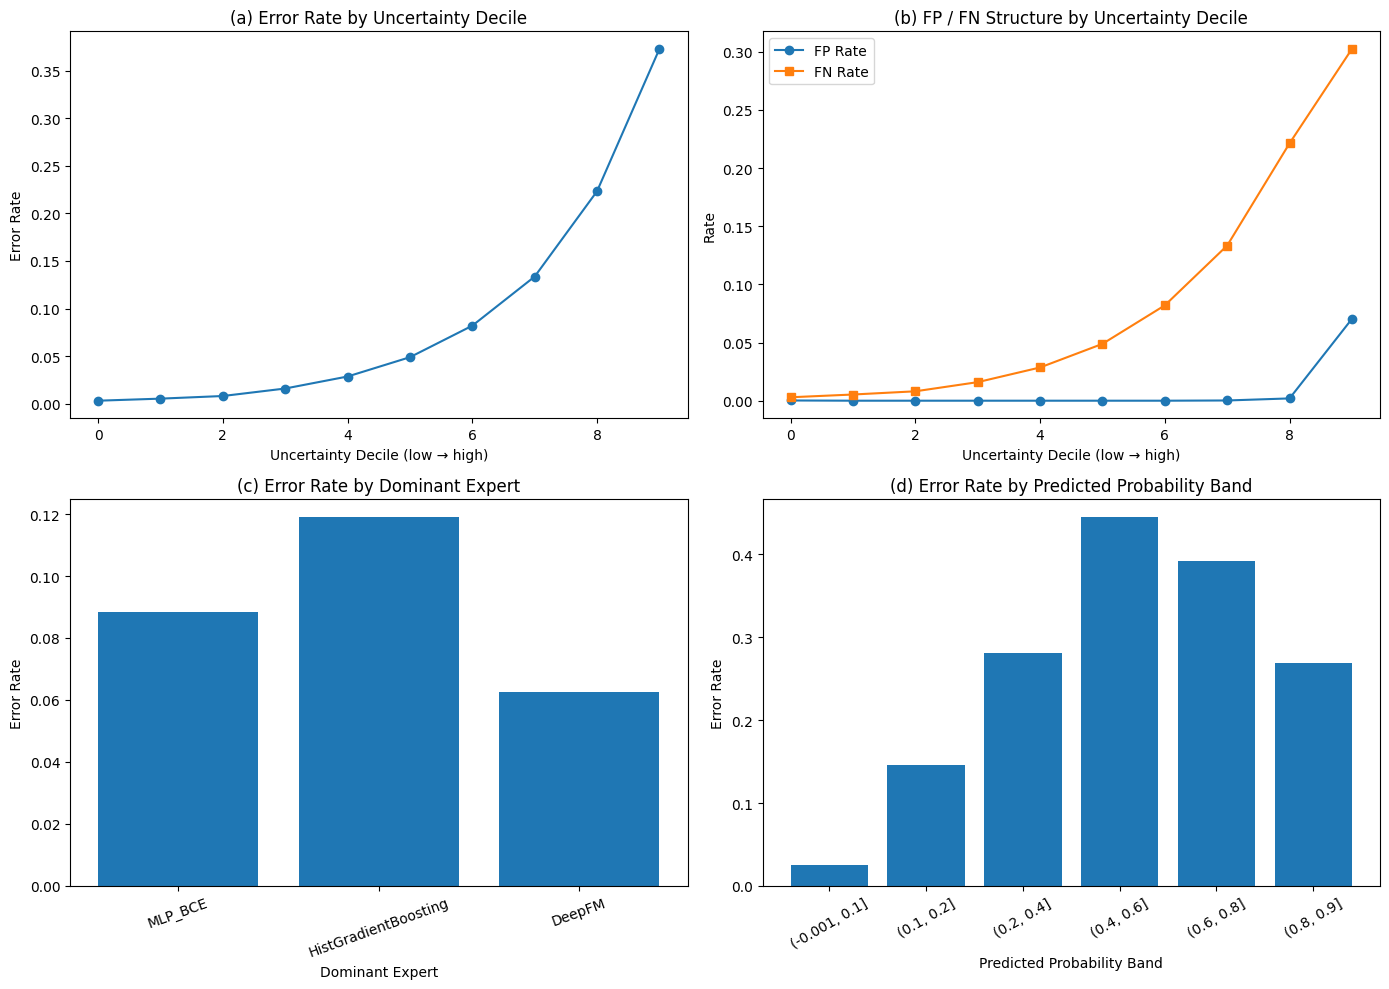

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/failure_analysis_hardcase_profiling_2x2.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/failure_analysis_hardcase_profiling_2x2.pdf


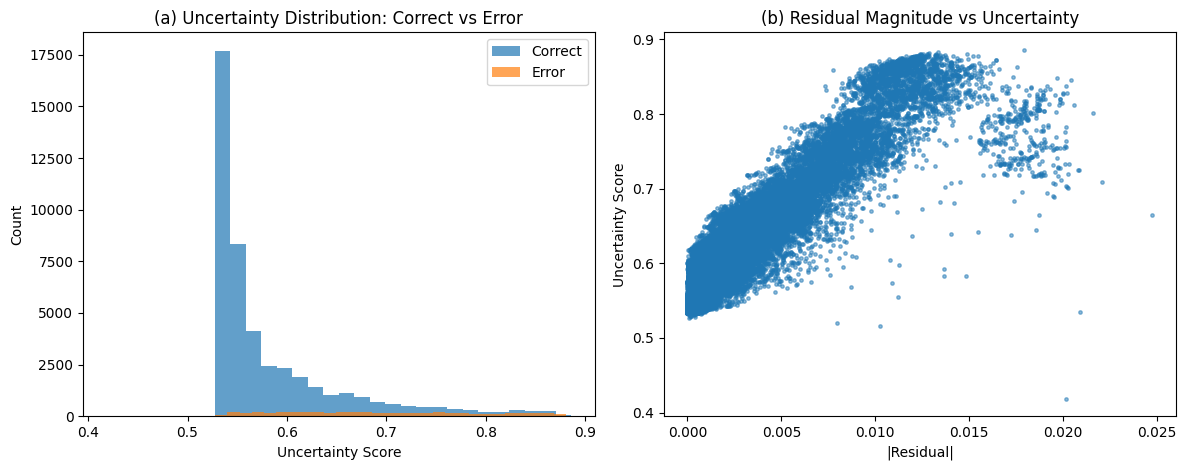

[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/failure_analysis_secondary_diagnostics.png
[Saved] /kaggle/working/outputs/trustworthy_heart_disease_v1/figures/failure_analysis_secondary_diagnostics.pdf

===== ARCHITECTURE FEEDBACK =====


,Feedback
0,Errors are strongly concentrated in high-uncer...
1,False negatives constitute a large share of to...
2,Routing does not collapse to one expert; a sec...
3,Context-dependent subgroup differences exist; ...



Saved:
- failure_overall_summary.csv
- failure_probability_band_summary.csv
- failure_uncertainty_decile_summary.csv
- failure_dominant_expert_summary.csv
- failure_hard_label_summary.csv
- failure_full_analysis_dataframe.csv
- failure_architecture_feedback.csv
- failure_subgroup_Sex_summary.csv
- failure_subgroup_Age_summary.csv
- failure_subgroup_GenHlth_summary.csv
- failure_subgroup_Diabetes_summary.csv
- failure_subgroup_DiffWalk_summary.csv
- failure_subgroup_HighBP_summary.csv
- failure_subgroup_Stroke_summary.csv
- failure_analysis_hardcase_profiling_2x2.(png/pdf)
- failure_analysis_secondary_diagnostics.(png/pdf)
- failure_analysis_metadata.json


In [30]:
# ============================================================
# FAILURE ANALYSIS + HARD-CASE PROFILING
# Current main model
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# Optional context tables from current notebook
HAS_X_DEV = "X_dev_df" in globals()
HAS_X_TEST = "X_test_df" in globals()

# ------------------------------------------------------------
# Locate main model prediction + weight files
# Priority: holdout first, then dev
# ------------------------------------------------------------
candidate_pairs = [
    (
        PRED_DIR / "final_holdout_gate_predictions.csv",
        PRED_DIR / "final_holdout_gate_weights.csv",
        "HOLDOUT"
    ),
    (
        PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
        PRED_DIR / "tech1_global_gate_ranked_residual_dev_weights.csv",
        "DEV"
    ),
    (
        PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
        PRED_DIR / "tech2_cal_lambda_0.00_dev_weights.csv",
        "DEV"
    ),
    (
        PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
        PRED_DIR / "light_robfair_baseline_ranked_residual_dev_weights.csv",
        "DEV"
    ),
]

pred_path, weight_path, split_name = None, None, None
for pp, wp, sp in candidate_pairs:
    if pp.exists() and wp.exists():
        pred_path, weight_path, split_name = pp, wp, sp
        break

if pred_path is None:
    raise FileNotFoundError(
        "Could not find a suitable prediction/weight file pair.\nExpected one of:\n" +
        "\n".join([f"{a} + {b}" for a, b, _ in candidate_pairs])
    )

pred_df = pd.read_csv(pred_path)
weight_df = pd.read_csv(weight_path)

print("Loaded:")
print("-", pred_path)
print("-", weight_path)
print("Split:", split_name)

display(pred_df.head())
display(weight_df.head())

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------
required_pred_cols = ["y_true", "pred"]
missing_pred = [c for c in required_pred_cols if c not in pred_df.columns]
if missing_pred:
    raise ValueError(f"Missing required prediction columns: {missing_pred}")

selected_experts = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
weight_cols = [f"w_{e}" for e in selected_experts]
missing_weight_cols = [c for c in weight_cols if c not in weight_df.columns]
if missing_weight_cols:
    raise ValueError(f"Missing weight columns: {missing_weight_cols}")

if len(pred_df) != len(weight_df):
    raise ValueError(f"Prediction and weight files have different lengths: {len(pred_df)} vs {len(weight_df)}")

# ------------------------------------------------------------
# Attach context data if available
# ------------------------------------------------------------
analysis_df = pd.DataFrame({
    "row_idx": np.arange(len(pred_df)),
    "y_true": pred_df["y_true"].astype(int).values,
    "pred": pred_df["pred"].astype(float).values,
})

for c in weight_cols:
    analysis_df[c] = weight_df[c].astype(float).values

if "gate_entropy" in weight_df.columns:
    analysis_df["gate_entropy"] = weight_df["gate_entropy"].astype(float).values
else:
    W = np.clip(analysis_df[weight_cols].values.astype(float), 1e-8, 1.0)
    analysis_df["gate_entropy"] = -(W * np.log(W)).sum(axis=1)

if "dominant_expert" in weight_df.columns:
    analysis_df["dominant_expert"] = weight_df["dominant_expert"].astype(str).values
else:
    analysis_df["dominant_expert"] = np.array(selected_experts)[
        np.argmax(analysis_df[weight_cols].values, axis=1)
    ]

if "residual" in weight_df.columns:
    analysis_df["residual"] = weight_df["residual"].astype(float).values
else:
    analysis_df["residual"] = 0.0

# attach raw context if available
context_source_df = None
if split_name == "HOLDOUT" and HAS_X_TEST:
    context_source_df = X_test_df.reset_index(drop=True).copy()
elif split_name == "DEV" and HAS_X_DEV:
    context_source_df = X_dev_df.reset_index(drop=True).copy()

if context_source_df is not None and len(context_source_df) == len(analysis_df):
    for c in context_source_df.columns:
        if c not in analysis_df.columns:
            analysis_df[c] = context_source_df[c].values

# ------------------------------------------------------------
# Core derived columns
# ------------------------------------------------------------
analysis_df["pred"] = np.clip(analysis_df["pred"].values, 1e-8, 1 - 1e-8)
analysis_df["y_hat_05"] = (analysis_df["pred"].values >= 0.5).astype(int)
analysis_df["is_error_05"] = (analysis_df["y_hat_05"].values != analysis_df["y_true"].values).astype(int)

analysis_df["is_fp_05"] = ((analysis_df["y_true"] == 0) & (analysis_df["y_hat_05"] == 1)).astype(int)
analysis_df["is_fn_05"] = ((analysis_df["y_true"] == 1) & (analysis_df["y_hat_05"] == 0)).astype(int)

analysis_df["margin_to_boundary"] = np.abs(analysis_df["pred"].values - 0.5)
analysis_df["top_weight"] = analysis_df[weight_cols].max(axis=1).values

sorted_weights = np.sort(analysis_df[weight_cols].values, axis=1)
analysis_df["top_minus_second_weight"] = sorted_weights[:, -1] - sorted_weights[:, -2]

# unified uncertainty score
entropy = analysis_df["gate_entropy"].values
entropy_norm = (entropy - entropy.min()) / max(entropy.max() - entropy.min(), 1e-8)
margin_unc = 1.0 - np.clip(2.0 * analysis_df["margin_to_boundary"].values, 0.0, 1.0)
dominance_unc = 1.0 - analysis_df["top_weight"].values
resid_unc = np.abs(analysis_df["residual"].values)
if resid_unc.max() > 0:
    resid_unc = resid_unc / resid_unc.max()

analysis_df["uncertainty_score"] = (
    0.40 * entropy_norm +
    0.30 * margin_unc +
    0.20 * dominance_unc +
    0.10 * resid_unc
)

# hard-case labels for next-stage architecture
q90 = analysis_df["uncertainty_score"].quantile(0.90)
q75 = analysis_df["uncertainty_score"].quantile(0.75)

analysis_df["is_high_uncertainty"] = (analysis_df["uncertainty_score"] >= q90).astype(int)
analysis_df["is_mediumhigh_uncertainty"] = (analysis_df["uncertainty_score"] >= q75).astype(int)

# conservative hard labels
analysis_df["hard_label_v1_error"] = analysis_df["is_error_05"].astype(int)
analysis_df["hard_label_v2_uncertainty"] = analysis_df["is_high_uncertainty"].astype(int)
analysis_df["hard_label_v3_error_or_uncertain"] = (
    (analysis_df["is_error_05"] == 1) | (analysis_df["is_high_uncertainty"] == 1)
).astype(int)
analysis_df["hard_label_v4_fn_or_uncertain"] = (
    (analysis_df["is_fn_05"] == 1) | (analysis_df["is_high_uncertainty"] == 1)
).astype(int)

# probability bands
analysis_df["prob_band"] = pd.cut(
    analysis_df["pred"],
    bins=[0.0, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0],
    include_lowest=True
).astype(str)

# uncertainty deciles
analysis_df["uncertainty_decile"] = pd.qcut(
    analysis_df["uncertainty_score"],
    q=10,
    labels=False,
    duplicates="drop"
)

# ------------------------------------------------------------
# 1) Overall failure summary
# ------------------------------------------------------------
overall_summary = pd.DataFrame([{
    "Split": split_name,
    "N": len(analysis_df),
    "PositiveRate": float(analysis_df["y_true"].mean()),
    "PredictedPositiveRate@0.5": float(analysis_df["y_hat_05"].mean()),
    "ErrorRate@0.5": float(analysis_df["is_error_05"].mean()),
    "FPRate@0.5": float(analysis_df["is_fp_05"].mean()),
    "FNRate@0.5": float(analysis_df["is_fn_05"].mean()),
    "FNShareAmongErrors": float(analysis_df["is_fn_05"].sum() / max(analysis_df["is_error_05"].sum(), 1)),
    "FPShareAmongErrors": float(analysis_df["is_fp_05"].sum() / max(analysis_df["is_error_05"].sum(), 1)),
    "MeanUncertainty": float(analysis_df["uncertainty_score"].mean()),
    "MeanEntropy": float(analysis_df["gate_entropy"].mean()),
}])

print("\n===== OVERALL FAILURE SUMMARY =====")
display(overall_summary)

# ------------------------------------------------------------
# 2) Error by probability band
# ------------------------------------------------------------
prob_band_summary = (
    analysis_df.groupby("prob_band", as_index=False)
    .agg(
        n=("y_true", "count"),
        positive_rate=("y_true", "mean"),
        error_rate=("is_error_05", "mean"),
        fp_rate=("is_fp_05", "mean"),
        fn_rate=("is_fn_05", "mean"),
        mean_uncertainty=("uncertainty_score", "mean"),
    )
)

print("\n===== ERROR BY PROBABILITY BAND =====")
display(prob_band_summary)

# ------------------------------------------------------------
# 3) Error by uncertainty decile
# ------------------------------------------------------------
unc_summary = (
    analysis_df.groupby("uncertainty_decile", as_index=False)
    .agg(
        n=("y_true", "count"),
        error_rate=("is_error_05", "mean"),
        fp_rate=("is_fp_05", "mean"),
        fn_rate=("is_fn_05", "mean"),
        positive_rate=("y_true", "mean"),
        mean_pred=("pred", "mean"),
        mean_entropy=("gate_entropy", "mean"),
        mean_top_weight=("top_weight", "mean"),
    )
)

print("\n===== ERROR BY UNCERTAINTY DECILE =====")
display(unc_summary)

# ------------------------------------------------------------
# 4) Error by dominant expert
# ------------------------------------------------------------
expert_summary = (
    analysis_df.groupby("dominant_expert", as_index=False)
    .agg(
        n=("y_true", "count"),
        usage_rate=("y_true", lambda x: len(x) / len(analysis_df)),
        error_rate=("is_error_05", "mean"),
        fp_rate=("is_fp_05", "mean"),
        fn_rate=("is_fn_05", "mean"),
        positive_rate=("y_true", "mean"),
        mean_uncertainty=("uncertainty_score", "mean"),
        mean_pred=("pred", "mean"),
    )
    .sort_values("usage_rate", ascending=False)
    .reset_index(drop=True)
)

print("\n===== ERROR BY DOMINANT EXPERT =====")
display(expert_summary)

# ------------------------------------------------------------
# 5) Contextual subgroup analysis (only for columns that exist)
# ------------------------------------------------------------
subgroup_tables = {}

candidate_context_cols = []
for c in ["Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "HighBP", "Stroke"]:
    if c in analysis_df.columns:
        candidate_context_cols.append(c)

for c in candidate_context_cols:
    gdf = (
        analysis_df.groupby(c, as_index=False)
        .agg(
            n=("y_true", "count"),
            positive_rate=("y_true", "mean"),
            error_rate=("is_error_05", "mean"),
            fp_rate=("is_fp_05", "mean"),
            fn_rate=("is_fn_05", "mean"),
            mean_pred=("pred", "mean"),
            mean_uncertainty=("uncertainty_score", "mean"),
        )
    )
    subgroup_tables[c] = gdf

print("\n===== AVAILABLE CONTEXTUAL FAILURE TABLES =====")
for k in subgroup_tables.keys():
    print("-", k)

# show Sex first if available
if "Sex" in subgroup_tables:
    print("\n===== ERROR BY SEX =====")
    display(subgroup_tables["Sex"])

# ------------------------------------------------------------
# 6) Hard-case label summary
# ------------------------------------------------------------
hard_label_summary = pd.DataFrame([
    {
        "HardLabel": "v1_error",
        "PositiveFraction": float(analysis_df["hard_label_v1_error"].mean())
    },
    {
        "HardLabel": "v2_uncertainty_top10pct",
        "PositiveFraction": float(analysis_df["hard_label_v2_uncertainty"].mean())
    },
    {
        "HardLabel": "v3_error_or_uncertain",
        "PositiveFraction": float(analysis_df["hard_label_v3_error_or_uncertain"].mean())
    },
    {
        "HardLabel": "v4_fn_or_uncertain",
        "PositiveFraction": float(analysis_df["hard_label_v4_fn_or_uncertain"].mean())
    },
])

print("\n===== HARD-CASE LABEL SUMMARY =====")
display(hard_label_summary)

# ------------------------------------------------------------
# Save tables
# ------------------------------------------------------------
overall_summary.to_csv(TAB_DIR / "failure_overall_summary.csv", index=False)
prob_band_summary.to_csv(TAB_DIR / "failure_probability_band_summary.csv", index=False)
unc_summary.to_csv(TAB_DIR / "failure_uncertainty_decile_summary.csv", index=False)
expert_summary.to_csv(TAB_DIR / "failure_dominant_expert_summary.csv", index=False)
hard_label_summary.to_csv(TAB_DIR / "failure_hard_label_summary.csv", index=False)
analysis_df.to_csv(TAB_DIR / "failure_full_analysis_dataframe.csv", index=False)

for col_name, gdf in subgroup_tables.items():
    safe_name = str(col_name).replace("/", "_")
    gdf.to_csv(TAB_DIR / f"failure_subgroup_{safe_name}_summary.csv", index=False)

# ------------------------------------------------------------
# Figures: 2x2 block
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Error rate by uncertainty decile
axes[0, 0].plot(unc_summary["uncertainty_decile"], unc_summary["error_rate"], marker="o")
axes[0, 0].set_title("(a) Error Rate by Uncertainty Decile")
axes[0, 0].set_xlabel("Uncertainty Decile (low → high)")
axes[0, 0].set_ylabel("Error Rate")

# (b) FP vs FN rate by uncertainty decile
axes[0, 1].plot(unc_summary["uncertainty_decile"], unc_summary["fp_rate"], marker="o", label="FP Rate")
axes[0, 1].plot(unc_summary["uncertainty_decile"], unc_summary["fn_rate"], marker="s", label="FN Rate")
axes[0, 1].set_title("(b) FP / FN Structure by Uncertainty Decile")
axes[0, 1].set_xlabel("Uncertainty Decile (low → high)")
axes[0, 1].set_ylabel("Rate")
axes[0, 1].legend()

# (c) Error rate by dominant expert
axes[1, 0].bar(expert_summary["dominant_expert"], expert_summary["error_rate"])
axes[1, 0].set_title("(c) Error Rate by Dominant Expert")
axes[1, 0].set_xlabel("Dominant Expert")
axes[1, 0].set_ylabel("Error Rate")
axes[1, 0].tick_params(axis="x", rotation=20)

# (d) Error rate by probability band
axes[1, 1].bar(prob_band_summary["prob_band"], prob_band_summary["error_rate"])
axes[1, 1].set_title("(d) Error Rate by Predicted Probability Band")
axes[1, 1].set_xlabel("Predicted Probability Band")
axes[1, 1].set_ylabel("Error Rate")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()

fig_path = FIG_DIR / "failure_analysis_hardcase_profiling_2x2"
plt.savefig(fig_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig_path.with_suffix('.png')}")
print(f"[Saved] {fig_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Optional second figure: subgroup and uncertainty distribution
# ------------------------------------------------------------
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4.8))

# uncertainty histogram split by error/non-error
axes2[0].hist(
    analysis_df.loc[analysis_df["is_error_05"] == 0, "uncertainty_score"].values,
    bins=30,
    alpha=0.7,
    label="Correct"
)
axes2[0].hist(
    analysis_df.loc[analysis_df["is_error_05"] == 1, "uncertainty_score"].values,
    bins=30,
    alpha=0.7,
    label="Error"
)
axes2[0].set_title("(a) Uncertainty Distribution: Correct vs Error")
axes2[0].set_xlabel("Uncertainty Score")
axes2[0].set_ylabel("Count")
axes2[0].legend()

# residual magnitude vs uncertainty if residual exists
if "residual" in analysis_df.columns:
    axes2[1].scatter(
        np.abs(analysis_df["residual"].values),
        analysis_df["uncertainty_score"].values,
        s=6,
        alpha=0.5
    )
    axes2[1].set_title("(b) Residual Magnitude vs Uncertainty")
    axes2[1].set_xlabel("|Residual|")
    axes2[1].set_ylabel("Uncertainty Score")
else:
    axes2[1].text(0.5, 0.5, "Residual not available", ha="center", va="center")
    axes2[1].set_title("(b) Residual Magnitude vs Uncertainty")

plt.tight_layout()

fig2_path = FIG_DIR / "failure_analysis_secondary_diagnostics"
plt.savefig(fig2_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig2_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

print(f"[Saved] {fig2_path.with_suffix('.png')}")
print(f"[Saved] {fig2_path.with_suffix('.pdf')}")

# ------------------------------------------------------------
# Architecture recommendation summary based on observed signals
# ------------------------------------------------------------
architecture_feedback = []

# uncertainty concentration feedback
top_decile_error = float(unc_summary.sort_values("uncertainty_decile")["error_rate"].iloc[-1])
bottom_decile_error = float(unc_summary.sort_values("uncertainty_decile")["error_rate"].iloc[0])

if top_decile_error > bottom_decile_error * 2:
    architecture_feedback.append(
        "Errors are strongly concentrated in high-uncertainty regions; a staged easy/medium/hard routing design is justified."
    )

# FN vs FP structure
fn_share = float(overall_summary["FNShareAmongErrors"].iloc[0])
if fn_share > 0.50:
    architecture_feedback.append(
        "False negatives constitute a large share of total errors; a hard-case refiner should prioritize positive-case recovery."
    )

# dominant-expert imbalance / specialization
if expert_summary["usage_rate"].max() < 0.90:
    architecture_feedback.append(
        "Routing does not collapse to one expert; a second-stage analyzer can exploit expert-specific failure modes."
    )

# subgroup disparities
if "Sex" in subgroup_tables:
    sex_gap = subgroup_tables["Sex"]["error_rate"].max() - subgroup_tables["Sex"]["error_rate"].min()
    if sex_gap > 0.02:
        architecture_feedback.append(
            "Context-dependent subgroup differences exist; fairness-aware correction should be applied only on difficult cases rather than globally."
        )

# probability band insight
mid_band = prob_band_summary[prob_band_summary["prob_band"].astype(str).str.contains("0.4", regex=False, na=False)]
if len(mid_band) == 0:
    architecture_feedback.append(
        "Decision-boundary regions remain ambiguous; a medium-band correction head may help more than increasing global gate complexity."
    )

architecture_feedback_df = pd.DataFrame({
    "Feedback": architecture_feedback if len(architecture_feedback) > 0 else [
        "The current model is globally strong; improvements should target difficult and uncertain samples selectively."
    ]
})

print("\n===== ARCHITECTURE FEEDBACK =====")
display(architecture_feedback_df)

architecture_feedback_df.to_csv(TAB_DIR / "failure_architecture_feedback.csv", index=False)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
meta = {
    "split_used": split_name,
    "prediction_file": str(pred_path),
    "weight_file": str(weight_path),
    "hard_label_definitions": {
        "v1_error": "Prediction error at threshold 0.5",
        "v2_uncertainty": "Top 10% uncertainty",
        "v3_error_or_uncertain": "Error OR top 10% uncertainty",
        "v4_fn_or_uncertain": "False negative OR top 10% uncertainty",
    },
    "uncertainty_formula": "0.40*entropy_norm + 0.30*margin_unc + 0.20*(1-top_weight) + 0.10*normalized_abs_residual",
}
with open(LOG_DIR / "failure_analysis_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print("- failure_overall_summary.csv")
print("- failure_probability_band_summary.csv")
print("- failure_uncertainty_decile_summary.csv")
print("- failure_dominant_expert_summary.csv")
print("- failure_hard_label_summary.csv")
print("- failure_full_analysis_dataframe.csv")
print("- failure_architecture_feedback.csv")
for col_name in subgroup_tables.keys():
    print(f"- failure_subgroup_{str(col_name).replace('/', '_')}_summary.csv")
print("- failure_analysis_hardcase_profiling_2x2.(png/pdf)")
print("- failure_analysis_secondary_diagnostics.(png/pdf)")
print("- failure_analysis_metadata.json")


Feature columns used:
['p_main', 'gate_entropy', 'residual', 'margin_to_boundary', 'top_weight', 'top_minus_second_weight', 'uncertainty_score', 'w_HistGradientBoosting', 'w_DeepFM', 'w_MLP_BCE', 'dom_HistGradientBoosting', 'dom_DeepFM', 'dom_MLP_BCE', 'Sex', 'Age', 'GenHlth', 'Diabetes', 'DiffWalk', 'BMI', 'HighBP', 'Stroke', 'PhysActivity', 'HighChol']

DEV train/val sizes:
train: (162355, 43) val: (40589, 43)

===== STAGE TUNING RESULTS (DEV-VAL) =====


,route_thr,max_delta,route_rate,threshold_eval,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,score
0,0.80,0.03,0.100471,0.225,0.384810,0.855457,0.069181,0.232824,0.005724,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099403,40589,0.403084
1,0.75,0.03,0.102392,0.225,0.384812,0.855457,0.069181,0.232824,0.005763,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099414,40589,0.403082
2,0.70,0.03,0.103255,0.225,0.384804,0.855455,0.069183,0.232828,0.005843,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099429,40589,0.403073
3,0.65,0.03,0.103476,0.225,0.384799,0.855453,0.069184,0.232832,0.005881,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099442,40589,0.403067
4,0.60,0.03,0.103673,0.225,0.384799,0.855453,0.069186,0.232835,0.005904,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099452,40589,0.403067
5,0.55,0.03,0.104240,0.225,0.384799,0.855453,0.069187,0.232837,0.005939,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099461,40589,0.403066
6,0.50,0.03,0.109143,0.225,0.384800,0.855452,0.069187,0.232839,0.006005,0.356678,0.546863,0.431755,0.864914,0.369501,0.225,0.143881,0.099474,40589,0.403056
7,0.45,0.03,0.143315,0.225,0.384800,0.855454,0.069188,0.232841,0.005847,0.356045,0.547388,0.431454,0.864618,0.369200,0.225,0.144276,0.099530,40589,0.402973
8,0.40,0.03,0.181108,0.225,0.384799,0.855451,0.069190,0.232847,0.006006,0.355057,0.552113,0.432182,0.863855,0.370264,0.225,0.145926,0.099689,40589,0.402950
9,0.35,0.03,0.224174,0.220,0.384799,0.855453,0.069193,0.232854,0.006219,0.348217,0.569178,0.432088,0.859593,0.371303,0.220,0.153391,0.099902,40589,0.402916



Best config:
{'route_thr': np.float64(0.8), 'max_delta': 0.03, 'thr_eval': 0.22499999999999998}

===== DEV VALIDATION COMPARISON =====


,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,...,MeanProb,N,variant,split,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
0,baseline_main_model,DEV_VAL,0.384708,0.855473,0.069049,0.232540,0.004006,0.356678,0.546863,0.431755,...,0.096416,40589,baseline_main_model,DEV_VAL,0.157745,0.020773,0.065422,0.033484,0.002227,0.112587
1,staged_detector_refiner,DEV_VAL,0.384810,0.855457,0.069181,0.232824,0.005724,0.356678,0.546863,0.431755,...,0.099403,40589,staged_detector_refiner,DEV_VAL,0.157745,0.020773,0.065422,0.033484,0.000855,0.112587



===== HOLDOUT COMPARISON =====


,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,baseline_main_model,HOLDOUT,0.373263,0.850785,0.069943,0.236027,0.002309,0.332854,0.580665,0.423147,0.850875,0.362309,0.2,0.164321,0.094862,50736
1,staged_detector_refiner,HOLDOUT,0.373557,0.850792,0.070089,0.236345,0.005167,0.332854,0.580665,0.423147,0.850875,0.362309,0.2,0.164321,0.097821,50736



===== HOLDOUT FAIRNESS GAP COMPARISON =====


,variant,split,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
0,baseline_main_model,HOLDOUT,0.198966,0.029743,0.077917,0.053558,0.002926,0.127794
1,staged_detector_refiner,HOLDOUT,0.198966,0.029743,0.077917,0.053558,0.004642,0.127794



===== ROUTING SUMMARY =====


,Split,RouteRate,MeanHardProb,MeanDeltaApplied,MeanDeltaOnRouted,BaselineFNRate,StageFNRate,BaselineErrorRate,StageErrorRate
0,HOLDOUT,0.098845,0.237568,0.002959,0.029937,0.039499,0.039499,0.149125,0.149125


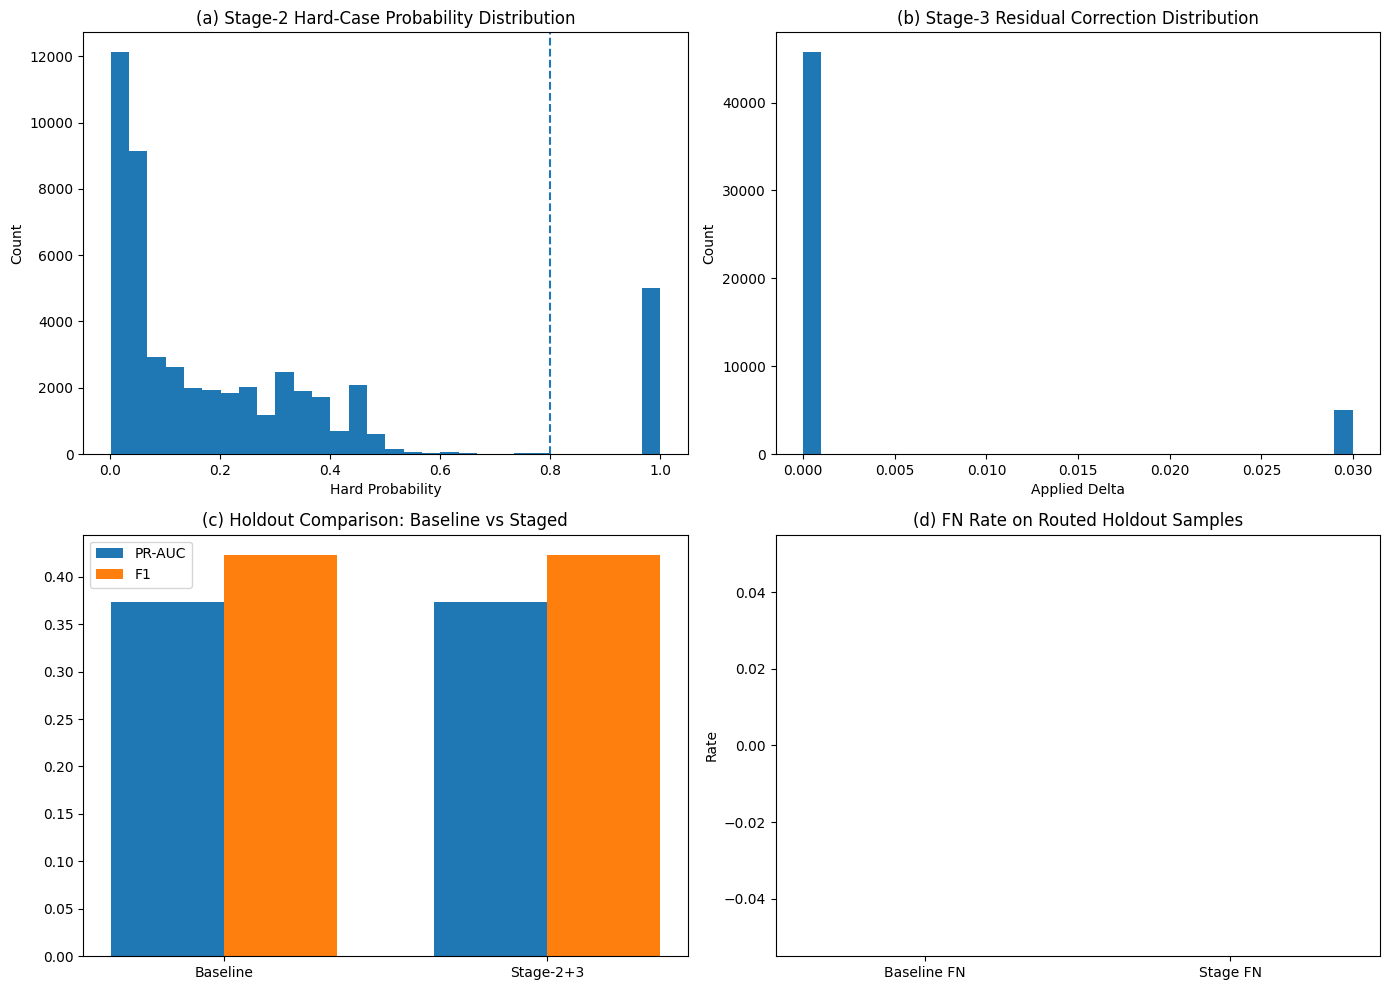


Saved:
- stage23_tuning_results.csv
- stage23_dev_validation_comparison.csv
- stage23_holdout_comparison.csv
- stage23_route_summary.csv
- stage23_holdout_profile.csv
- stage23_holdout_fairness_comparison.csv
- stage23_dev_staged_predictions.csv
- stage23_holdout_staged_predictions.csv
- stage23_detector_refiner_2x2.(png/pdf)
- stage23_metadata.json


In [31]:
# ============================================================
# STAGE-2 HARD-CASE DETECTOR + STAGE-3 RESIDUAL REFINER
# Full runnable block
# ============================================================

import os
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR", "LOG_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

HAS_X_DEV = "X_dev_df" in globals()
HAS_X_TEST = "X_test_df" in globals()

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
S2R_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
S2R_WEIGHT_COLS = [f"w_{e}" for e in S2R_SELECTED_EXPERTS]

S2R_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]
# will be filtered later based on availability

# hard-case target
# v4 = false negative OR top-10% uncertainty
S2R_HARD_UNCERT_Q = 0.90

# detector
S2R_DETECTOR_PARAMS = dict(
    loss="log_loss",
    learning_rate=0.05,
    max_depth=4,
    max_iter=300,
    min_samples_leaf=40,
    random_state=42
)

# refiner
S2R_REFINER_PARAMS = dict(
    loss="squared_error",
    learning_rate=0.03,
    max_depth=4,
    max_iter=400,
    min_samples_leaf=30,
    random_state=42
)

# routing / correction
S2R_ROUTE_THR_GRID = np.linspace(0.30, 0.80, 11)
S2R_MAX_DELTA_GRID = [0.03, 0.05, 0.08, 0.10]

# residual target clipping
S2R_RESID_CLIP_LOW = -0.05
S2R_RESID_CLIP_HIGH = 0.20

# weights
S2R_FN_WEIGHT = 3.0
S2R_POS_WEIGHT = 2.0
S2R_HARD_WEIGHT = 1.5

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_s2r(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_metrics_s2r(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_s2r(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def best_f1_threshold_s2r(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_s2r(prob)

    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_sex_gap_s2r(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_s2r(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female": sex_arr == 0, "Male": sex_arr == 1}.items():
        yt = y_true[mask]
        pp = prob[mask]
        yh = (pp >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        ids = np.digitize(pp, bins, right=False) - 1
        ids = np.clip(ids, 0, len(bins) - 2)
        ece = 0.0
        for i in range(len(bins) - 1):
            m = ids == i
            if m.sum() == 0:
                continue
            acc = yt[m].mean()
            conf = pp[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(yt))

        out[name] = {
            "Recall": recall_score(yt, yh, zero_division=0),
            "Precision": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0),
            "MCC": matthews_corrcoef(yt, yh) if len(np.unique(yh)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": yh.mean(),
        }

    return {
        "Recall_gap": abs(out["Male"]["Recall"] - out["Female"]["Recall"]),
        "Precision_gap": abs(out["Male"]["Precision"] - out["Female"]["Precision"]),
        "F1_gap": abs(out["Male"]["F1"] - out["Female"]["F1"]),
        "MCC_gap": abs(out["Male"]["MCC"] - out["Female"]["MCC"]),
        "ECE_gap": abs(out["Male"]["ECE"] - out["Female"]["ECE"]),
        "PredPosRate_gap": abs(out["Male"]["PredPosRate"] - out["Female"]["PredPosRate"]),
    }

def find_existing_pair(split="DEV"):
    if split == "DEV":
        candidates = [
            (
                PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
                PRED_DIR / "tech2_cal_lambda_0.00_dev_weights.csv",
            ),
            (
                PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
                PRED_DIR / "light_robfair_baseline_ranked_residual_dev_weights.csv",
            ),
            (
                PRED_DIR / "robfair_baseline_ranked_residual_dev_predictions.csv",
                PRED_DIR / "robfair_baseline_ranked_residual_dev_weights.csv",
            ),
            (
                PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
                PRED_DIR / "tech1_global_gate_ranked_residual_dev_weights.csv",
            ),
        ]
    else:
        candidates = [
            (
                PRED_DIR / "final_holdout_gate_predictions.csv",
                PRED_DIR / "final_holdout_gate_weights.csv",
            ),
        ]

    for p, w in candidates:
        if p.exists() and w.exists():
            return p, w

    return None, None

def build_analysis_frame(pred_path, weight_path, split_name, context_df=None):
    pred_df = pd.read_csv(pred_path)
    weight_df = pd.read_csv(weight_path)

    if len(pred_df) != len(weight_df):
        raise ValueError(f"{split_name}: prediction/weight length mismatch")

    df = pd.DataFrame({
        "row_idx": np.arange(len(pred_df)),
        "y_true": pred_df["y_true"].astype(int).values,
        "p_main": clip_probs_s2r(pred_df["pred"].astype(float).values),
    })

    for c in S2R_WEIGHT_COLS:
        if c not in weight_df.columns:
            raise ValueError(f"{split_name}: missing weight column {c}")
        df[c] = weight_df[c].astype(float).values

    if "gate_entropy" in weight_df.columns:
        df["gate_entropy"] = weight_df["gate_entropy"].astype(float).values
    else:
        W = np.clip(df[S2R_WEIGHT_COLS].values.astype(float), 1e-8, 1.0)
        df["gate_entropy"] = -(W * np.log(W)).sum(axis=1)

    if "dominant_expert" in weight_df.columns:
        df["dominant_expert"] = weight_df["dominant_expert"].astype(str).values
    else:
        df["dominant_expert"] = np.array(S2R_SELECTED_EXPERTS)[
            np.argmax(df[S2R_WEIGHT_COLS].values, axis=1)
        ]

    if "residual" in weight_df.columns:
        df["residual"] = weight_df["residual"].astype(float).values
    else:
        df["residual"] = 0.0

    if context_df is not None and len(context_df) == len(df):
        for c in context_df.columns:
            if c not in df.columns:
                df[c] = context_df[c].values

    # main prediction behavior
    df["y_hat_05"] = (df["p_main"] >= 0.5).astype(int)
    df["is_error_05"] = (df["y_hat_05"] != df["y_true"]).astype(int)
    df["is_fp_05"] = ((df["y_true"] == 0) & (df["y_hat_05"] == 1)).astype(int)
    df["is_fn_05"] = ((df["y_true"] == 1) & (df["y_hat_05"] == 0)).astype(int)

    # geometry / trust features
    df["margin_to_boundary"] = np.abs(df["p_main"] - 0.5)
    df["top_weight"] = df[S2R_WEIGHT_COLS].max(axis=1)

    sorted_w = np.sort(df[S2R_WEIGHT_COLS].values, axis=1)
    df["top_minus_second_weight"] = sorted_w[:, -1] - sorted_w[:, -2]

    ent = df["gate_entropy"].values
    ent_norm = (ent - ent.min()) / max(ent.max() - ent.min(), 1e-8)
    margin_unc = 1.0 - np.clip(2.0 * df["margin_to_boundary"].values, 0.0, 1.0)
    dominance_unc = 1.0 - df["top_weight"].values
    resid_unc = np.abs(df["residual"].values)
    if resid_unc.max() > 0:
        resid_unc = resid_unc / resid_unc.max()

    df["uncertainty_score"] = (
        0.40 * ent_norm +
        0.30 * margin_unc +
        0.20 * dominance_unc +
        0.10 * resid_unc
    )

    # one-hot dominant expert
    for e in S2R_SELECTED_EXPERTS:
        df[f"dom_{e}"] = (df["dominant_expert"] == e).astype(int)

    # hard labels
    hard_thr = df["uncertainty_score"].quantile(S2R_HARD_UNCERT_Q)
    df["is_high_uncertainty"] = (df["uncertainty_score"] >= hard_thr).astype(int)
    df["hard_label_v4_fn_or_uncertain"] = (
        (df["is_fn_05"] == 1) | (df["is_high_uncertainty"] == 1)
    ).astype(int)

    return df

def get_feature_columns(df):
    candidate_cols = [
        "p_main",
        "gate_entropy",
        "residual",
        "margin_to_boundary",
        "top_weight",
        "top_minus_second_weight",
        "uncertainty_score",
        "w_HistGradientBoosting",
        "w_DeepFM",
        "w_MLP_BCE",
        "dom_HistGradientBoosting",
        "dom_DeepFM",
        "dom_MLP_BCE",
    ]

    for c in S2R_CONTEXT_COLS:
        if c in df.columns:
            candidate_cols.append(c)

    return [c for c in candidate_cols if c in df.columns]

def build_refiner_target(df):
    # signed residual target, clipped
    # y - p_main gives positive correction for missed positives
    target = df["y_true"].values.astype(float) - df["p_main"].values.astype(float)
    target = np.clip(target, S2R_RESID_CLIP_LOW, S2R_RESID_CLIP_HIGH)
    return target

def build_refiner_weights(df):
    w = np.ones(len(df), dtype=float)
    w += (df["y_true"].values == 1).astype(float) * (S2R_POS_WEIGHT - 1.0)
    w += (df["is_fn_05"].values == 1).astype(float) * (S2R_FN_WEIGHT - 1.0)
    w += (df["hard_label_v4_fn_or_uncertain"].values == 1).astype(float) * (S2R_HARD_WEIGHT - 1.0)
    return w

def apply_staged_refinement(
    df,
    detector,
    refiner,
    feature_cols,
    route_thr,
    max_delta,
    hard_prob_scaling=True,
):
    X = df[feature_cols].values.astype(np.float32)

    hard_prob = detector.predict_proba(X)[:, 1]
    raw_delta = refiner.predict(X)

    # bounded correction
    raw_delta = np.clip(raw_delta, -max_delta, max_delta)

    route_mask = (hard_prob >= route_thr).astype(float)

    if hard_prob_scaling:
        scale = np.clip((hard_prob - route_thr) / max(1.0 - route_thr, 1e-8), 0.0, 1.0)
    else:
        scale = route_mask

    delta = raw_delta * scale
    p_stage = clip_probs_s2r(df["p_main"].values + delta)

    out = df.copy()
    out["hard_prob"] = hard_prob
    out["route_mask"] = route_mask
    out["delta_pred"] = raw_delta
    out["delta_applied"] = delta
    out["p_stage"] = p_stage
    return out

# ------------------------------------------------------------
# Load DEV / HOLDOUT frames
# ------------------------------------------------------------
dev_pred_path, dev_weight_path = find_existing_pair("DEV")
hold_pred_path, hold_weight_path = find_existing_pair("HOLDOUT")

if dev_pred_path is None:
    raise FileNotFoundError("Could not find DEV main-model prediction/weight pair.")
if hold_pred_path is None:
    raise FileNotFoundError("Could not find HOLDOUT main-model prediction/weight pair.")

dev_context = X_dev_df.reset_index(drop=True).copy() if HAS_X_DEV else None
hold_context = X_test_df.reset_index(drop=True).copy() if HAS_X_TEST else None

dev_df = build_analysis_frame(dev_pred_path, dev_weight_path, "DEV", context_df=dev_context)
hold_df = build_analysis_frame(hold_pred_path, hold_weight_path, "HOLDOUT", context_df=hold_context)

feature_cols = get_feature_columns(dev_df)

print("\nFeature columns used:")
print(feature_cols)

# ------------------------------------------------------------
# Split DEV into train/val for honest stage-2/stage-3 tuning
# ------------------------------------------------------------
train_idx, val_idx = train_test_split(
    np.arange(len(dev_df)),
    test_size=0.20,
    stratify=dev_df["hard_label_v4_fn_or_uncertain"].values,
    random_state=42
)

dev_train = dev_df.iloc[train_idx].reset_index(drop=True)
dev_val = dev_df.iloc[val_idx].reset_index(drop=True)

print("\nDEV train/val sizes:")
print("train:", dev_train.shape, "val:", dev_val.shape)

# ------------------------------------------------------------
# Stage 2 — hard-case detector
# ------------------------------------------------------------
X_train_det = dev_train[feature_cols].values.astype(np.float32)
y_train_det = dev_train["hard_label_v4_fn_or_uncertain"].values.astype(int)

detector_weight = np.ones(len(dev_train), dtype=float)
detector_weight += (dev_train["is_fn_05"].values == 1).astype(float) * 2.0
detector_weight += (dev_train["is_high_uncertainty"].values == 1).astype(float) * 1.0

hard_detector = HistGradientBoostingClassifier(**S2R_DETECTOR_PARAMS)
hard_detector.fit(X_train_det, y_train_det, sample_weight=detector_weight)

# ------------------------------------------------------------
# Stage 3 — residual refiner
# Train only on hard-labeled train samples
# ------------------------------------------------------------
train_hard_mask = dev_train["hard_label_v4_fn_or_uncertain"].values.astype(bool)
ref_train_df = dev_train.loc[train_hard_mask].reset_index(drop=True)

X_train_ref = ref_train_df[feature_cols].values.astype(np.float32)
y_train_ref = build_refiner_target(ref_train_df)
w_train_ref = build_refiner_weights(ref_train_df)

residual_refiner = HistGradientBoostingRegressor(**S2R_REFINER_PARAMS)
residual_refiner.fit(X_train_ref, y_train_ref, sample_weight=w_train_ref)

# ------------------------------------------------------------
# Tune routing on DEV validation
# ------------------------------------------------------------
baseline_val_p = dev_val["p_main"].values
baseline_val_thr, _ = best_f1_threshold_s2r(dev_val["y_true"].values, baseline_val_p)

tuning_rows = []
best_cfg = None
best_score = -1e9
best_val_out = None

for route_thr in S2R_ROUTE_THR_GRID:
    for max_delta in S2R_MAX_DELTA_GRID:
        val_out = apply_staged_refinement(
            df=dev_val,
            detector=hard_detector,
            refiner=residual_refiner,
            feature_cols=feature_cols,
            route_thr=route_thr,
            max_delta=max_delta,
            hard_prob_scaling=True,
        )

        thr_stage, _ = best_f1_threshold_s2r(val_out["y_true"].values, val_out["p_stage"].values)
        met = compute_metrics_s2r(val_out["y_true"].values, val_out["p_stage"].values, threshold=thr_stage)

        # selection score:
        # prioritize PR-AUC, then MCC, with small penalty for too much routing
        route_rate = float(val_out["route_mask"].mean())
        score = met["PR_AUC"] + 0.05 * met["MCC"] - 0.002 * route_rate

        tuning_rows.append({
            "route_thr": route_thr,
            "max_delta": max_delta,
            "route_rate": route_rate,
            "threshold_eval": thr_stage,
            **met,
            "score": score,
        })

        if score > best_score:
            best_score = score
            best_cfg = {"route_thr": route_thr, "max_delta": max_delta, "thr_eval": thr_stage}
            best_val_out = val_out.copy()

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["score", "PR_AUC", "MCC"],
    ascending=[False, False, False]
).reset_index(drop=True)

print("\n===== STAGE TUNING RESULTS (DEV-VAL) =====")
display(tuning_df.head(10))

print("\nBest config:")
print(best_cfg)

# ------------------------------------------------------------
# Compare baseline vs staged on DEV validation
# ------------------------------------------------------------
baseline_val_metrics = compute_metrics_s2r(
    dev_val["y_true"].values,
    dev_val["p_main"].values,
    threshold=baseline_val_thr
)

staged_val_metrics = compute_metrics_s2r(
    best_val_out["y_true"].values,
    best_val_out["p_stage"].values,
    threshold=best_cfg["thr_eval"]
)

val_compare_rows = [
    {"variant": "baseline_main_model", "split": "DEV_VAL", **baseline_val_metrics},
    {"variant": "staged_detector_refiner", "split": "DEV_VAL", **staged_val_metrics},
]
val_compare_df = pd.DataFrame(val_compare_rows)

if "Sex" in dev_val.columns:
    val_compare_df = pd.concat(
        [
            val_compare_df,
            pd.DataFrame([
                {
                    "variant": "baseline_main_model",
                    "split": "DEV_VAL",
                    **compute_sex_gap_s2r(
                        dev_val["y_true"].values,
                        dev_val["p_main"].values,
                        baseline_val_thr,
                        dev_val["Sex"].values
                    )
                },
                {
                    "variant": "staged_detector_refiner",
                    "split": "DEV_VAL",
                    **compute_sex_gap_s2r(
                        best_val_out["y_true"].values,
                        best_val_out["p_stage"].values,
                        best_cfg["thr_eval"],
                        dev_val["Sex"].values
                    )
                },
            ])
        ],
        axis=1
    )

print("\n===== DEV VALIDATION COMPARISON =====")
display(val_compare_df)

# ------------------------------------------------------------
# Refit detector and refiner on full DEV using chosen config
# ------------------------------------------------------------
X_full_det = dev_df[feature_cols].values.astype(np.float32)
y_full_det = dev_df["hard_label_v4_fn_or_uncertain"].values.astype(int)

detector_weight_full = np.ones(len(dev_df), dtype=float)
detector_weight_full += (dev_df["is_fn_05"].values == 1).astype(float) * 2.0
detector_weight_full += (dev_df["is_high_uncertainty"].values == 1).astype(float) * 1.0

hard_detector_full = HistGradientBoostingClassifier(**S2R_DETECTOR_PARAMS)
hard_detector_full.fit(X_full_det, y_full_det, sample_weight=detector_weight_full)

full_hard_mask = dev_df["hard_label_v4_fn_or_uncertain"].values.astype(bool)
full_ref_df = dev_df.loc[full_hard_mask].reset_index(drop=True)

X_full_ref = full_ref_df[feature_cols].values.astype(np.float32)
y_full_ref = build_refiner_target(full_ref_df)
w_full_ref = build_refiner_weights(full_ref_df)

residual_refiner_full = HistGradientBoostingRegressor(**S2R_REFINER_PARAMS)
residual_refiner_full.fit(X_full_ref, y_full_ref, sample_weight=w_full_ref)

# use full-dev thresholding
dev_stage_full = apply_staged_refinement(
    df=dev_df,
    detector=hard_detector_full,
    refiner=residual_refiner_full,
    feature_cols=feature_cols,
    route_thr=best_cfg["route_thr"],
    max_delta=best_cfg["max_delta"],
    hard_prob_scaling=True,
)

thr_baseline_dev_full, _ = best_f1_threshold_s2r(dev_df["y_true"].values, dev_df["p_main"].values)
thr_stage_dev_full, _ = best_f1_threshold_s2r(dev_df["y_true"].values, dev_stage_full["p_stage"].values)

# ------------------------------------------------------------
# HOLDOUT evaluation
# ------------------------------------------------------------
hold_stage = apply_staged_refinement(
    df=hold_df,
    detector=hard_detector_full,
    refiner=residual_refiner_full,
    feature_cols=feature_cols,
    route_thr=best_cfg["route_thr"],
    max_delta=best_cfg["max_delta"],
    hard_prob_scaling=True,
)

hold_baseline_metrics = compute_metrics_s2r(
    hold_df["y_true"].values,
    hold_df["p_main"].values,
    threshold=thr_baseline_dev_full
)

hold_stage_metrics = compute_metrics_s2r(
    hold_stage["y_true"].values,
    hold_stage["p_stage"].values,
    threshold=thr_stage_dev_full
)

hold_compare_df = pd.DataFrame([
    {"variant": "baseline_main_model", "split": "HOLDOUT", **hold_baseline_metrics},
    {"variant": "staged_detector_refiner", "split": "HOLDOUT", **hold_stage_metrics},
])

if "Sex" in hold_df.columns:
    fair_hold_df = pd.DataFrame([
        {
            "variant": "baseline_main_model",
            "split": "HOLDOUT",
            **compute_sex_gap_s2r(
                hold_df["y_true"].values,
                hold_df["p_main"].values,
                thr_baseline_dev_full,
                hold_df["Sex"].values
            )
        },
        {
            "variant": "staged_detector_refiner",
            "split": "HOLDOUT",
            **compute_sex_gap_s2r(
                hold_stage["y_true"].values,
                hold_stage["p_stage"].values,
                thr_stage_dev_full,
                hold_df["Sex"].values
            )
        },
    ])
else:
    fair_hold_df = None

print("\n===== HOLDOUT COMPARISON =====")
display(hold_compare_df)

if fair_hold_df is not None:
    print("\n===== HOLDOUT FAIRNESS GAP COMPARISON =====")
    display(fair_hold_df)

# ------------------------------------------------------------
# Hard-case detector profiling
# ------------------------------------------------------------
detector_profile_df = pd.DataFrame({
    "row_idx": hold_stage["row_idx"].values,
    "y_true": hold_stage["y_true"].values,
    "p_main": hold_stage["p_main"].values,
    "p_stage": hold_stage["p_stage"].values,
    "hard_prob": hold_stage["hard_prob"].values,
    "route_mask": hold_stage["route_mask"].values,
    "delta_applied": hold_stage["delta_applied"].values,
    "uncertainty_score": hold_stage["uncertainty_score"].values,
    "is_error_baseline": ((hold_df["p_main"].values >= thr_baseline_dev_full).astype(int) != hold_df["y_true"].values).astype(int),
    "is_error_stage": ((hold_stage["p_stage"].values >= thr_stage_dev_full).astype(int) != hold_stage["y_true"].values).astype(int),
    "is_fn_baseline": (((hold_df["p_main"].values >= thr_baseline_dev_full).astype(int) == 0) & (hold_df["y_true"].values == 1)).astype(int),
    "is_fn_stage": (((hold_stage["p_stage"].values >= thr_stage_dev_full).astype(int) == 0) & (hold_stage["y_true"].values == 1)).astype(int),
})

if "Sex" in hold_df.columns:
    detector_profile_df["Sex"] = hold_df["Sex"].values

route_summary_df = pd.DataFrame([{
    "Split": "HOLDOUT",
    "RouteRate": float(hold_stage["route_mask"].mean()),
    "MeanHardProb": float(hold_stage["hard_prob"].mean()),
    "MeanDeltaApplied": float(np.mean(np.abs(hold_stage["delta_applied"].values))),
    "MeanDeltaOnRouted": float(np.mean(np.abs(hold_stage.loc[hold_stage["route_mask"] == 1, "delta_applied"].values))) if hold_stage["route_mask"].sum() > 0 else 0.0,
    "BaselineFNRate": float(detector_profile_df["is_fn_baseline"].mean()),
    "StageFNRate": float(detector_profile_df["is_fn_stage"].mean()),
    "BaselineErrorRate": float(detector_profile_df["is_error_baseline"].mean()),
    "StageErrorRate": float(detector_profile_df["is_error_stage"].mean()),
}])

print("\n===== ROUTING SUMMARY =====")
display(route_summary_df)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
tuning_df.to_csv(TAB_DIR / "stage23_tuning_results.csv", index=False)
val_compare_df.to_csv(TAB_DIR / "stage23_dev_validation_comparison.csv", index=False)
hold_compare_df.to_csv(TAB_DIR / "stage23_holdout_comparison.csv", index=False)
route_summary_df.to_csv(TAB_DIR / "stage23_route_summary.csv", index=False)
detector_profile_df.to_csv(TAB_DIR / "stage23_holdout_profile.csv", index=False)
dev_stage_full.to_csv(PRED_DIR / "stage23_dev_staged_predictions.csv", index=False)
hold_stage.to_csv(PRED_DIR / "stage23_holdout_staged_predictions.csv", index=False)

if fair_hold_df is not None:
    fair_hold_df.to_csv(TAB_DIR / "stage23_holdout_fairness_comparison.csv", index=False)

# ------------------------------------------------------------
# Figures
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) hard-prob distribution
axes[0, 0].hist(hold_stage["hard_prob"].values, bins=30)
axes[0, 0].axvline(best_cfg["route_thr"], linestyle="--")
axes[0, 0].set_title("(a) Stage-2 Hard-Case Probability Distribution")
axes[0, 0].set_xlabel("Hard Probability")
axes[0, 0].set_ylabel("Count")

# (b) delta applied distribution
axes[0, 1].hist(hold_stage["delta_applied"].values, bins=30)
axes[0, 1].set_title("(b) Stage-3 Residual Correction Distribution")
axes[0, 1].set_xlabel("Applied Delta")
axes[0, 1].set_ylabel("Count")

# (c) baseline vs stage PR-AUC / F1 on holdout
bar_names = ["Baseline", "Stage-2+3"]
bar_prauc = [hold_baseline_metrics["PR_AUC"], hold_stage_metrics["PR_AUC"]]
bar_f1 = [hold_baseline_metrics["F1"], hold_stage_metrics["F1"]]

x = np.arange(len(bar_names))
w = 0.35
axes[1, 0].bar(x - w/2, bar_prauc, width=w, label="PR-AUC")
axes[1, 0].bar(x + w/2, bar_f1, width=w, label="F1")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(bar_names)
axes[1, 0].set_title("(c) Holdout Comparison: Baseline vs Staged")
axes[1, 0].legend()

# (d) FN reduction among routed samples
routed = hold_stage["route_mask"].values.astype(bool)
if routed.sum() > 0:
    fn_base_routed = detector_profile_df.loc[routed, "is_fn_baseline"].mean()
    fn_stage_routed = detector_profile_df.loc[routed, "is_fn_stage"].mean()
else:
    fn_base_routed = 0.0
    fn_stage_routed = 0.0

axes[1, 1].bar(["Baseline FN", "Stage FN"], [fn_base_routed, fn_stage_routed])
axes[1, 1].set_title("(d) FN Rate on Routed Holdout Samples")
axes[1, 1].set_ylabel("Rate")

plt.tight_layout()

fig_path = FIG_DIR / "stage23_detector_refiner_2x2"
plt.savefig(fig_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "feature_cols": feature_cols,
    "best_config": best_cfg,
    "detector_params": S2R_DETECTOR_PARAMS,
    "refiner_params": S2R_REFINER_PARAMS,
    "hard_target": "v4_fn_or_uncertain = false_negative OR top10% uncertainty",
    "residual_clip": [S2R_RESID_CLIP_LOW, S2R_RESID_CLIP_HIGH],
}
with open(LOG_DIR / "stage23_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print("- stage23_tuning_results.csv")
print("- stage23_dev_validation_comparison.csv")
print("- stage23_holdout_comparison.csv")
print("- stage23_route_summary.csv")
print("- stage23_holdout_profile.csv")
if fair_hold_df is not None:
    print("- stage23_holdout_fairness_comparison.csv")
print("- stage23_dev_staged_predictions.csv")
print("- stage23_holdout_staged_predictions.csv")
print("- stage23_detector_refiner_2x2.(png/pdf)")
print("- stage23_metadata.json")


Feature columns used:
['p_main', 'gate_entropy', 'residual', 'margin_to_threshold', 'top_weight', 'top_minus_second_weight', 'uncertainty_score', 'w_HistGradientBoosting', 'w_DeepFM', 'w_MLP_BCE', 'dom_HistGradientBoosting', 'dom_DeepFM', 'dom_MLP_BCE', 'near_threshold', 'Sex', 'Age', 'GenHlth', 'Diabetes', 'DiffWalk', 'BMI', 'HighBP', 'Stroke', 'PhysActivity', 'HighChol']

DEV train/val sizes:
train: (162355, 44) val: (40589, 44)

===== FN-RECOVERY TUNING RESULTS (DEV-VAL) =====


,route_thr,max_delta_pos,max_delta_neg,route_rate,threshold_eval,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,score
0,0.55,0.10,0.00,0.101604,0.255,0.385077,0.852767,0.069309,0.233964,0.007701,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100020,40589,0.446281
1,0.55,0.10,0.01,0.101604,0.255,0.385077,0.852767,0.069309,0.233964,0.007701,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100020,40589,0.446281
2,0.55,0.10,0.02,0.101604,0.255,0.385077,0.852767,0.069309,0.233964,0.007701,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100020,40589,0.446281
3,0.55,0.12,0.00,0.101604,0.255,0.385077,0.852767,0.069310,0.233966,0.007706,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100025,40589,0.446281
4,0.55,0.12,0.01,0.101604,0.255,0.385077,0.852767,0.069310,0.233966,0.007706,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100025,40589,0.446281
5,0.55,0.12,0.02,0.101604,0.255,0.385077,0.852767,0.069310,0.233966,0.007706,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100025,40589,0.446281
6,0.55,0.08,0.00,0.101604,0.255,0.385073,0.852766,0.069308,0.233961,0.007695,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100014,40589,0.446278
7,0.55,0.08,0.01,0.101604,0.255,0.385073,0.852766,0.069308,0.233961,0.007695,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100014,40589,0.446278
8,0.55,0.08,0.02,0.101604,0.255,0.385073,0.852766,0.069308,0.233961,0.007695,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100014,40589,0.446278
9,0.60,0.10,0.00,0.101111,0.255,0.385082,0.852769,0.069307,0.233958,0.007684,0.347521,0.548472,0.425462,0.861465,0.363009,0.255,0.147602,0.100003,40589,0.446263



Best config:
{'route_thr': np.float64(0.55), 'max_delta_pos': 0.1, 'max_delta_neg': 0.0, 'thr_eval': 0.25499999999999995}

===== DEV VALIDATION COMPARISON =====


,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,baseline_main_model,DEV_VAL,0.385665,0.852997,0.069009,0.233086,0.003424,0.352023,0.540832,0.426464,0.863953,0.363673,0.225,0.143684,0.095743,40589
1,fn_recovery_staged_model,DEV_VAL,0.385077,0.852767,0.069309,0.233964,0.007701,0.347275,0.548999,0.425436,0.861317,0.363013,0.255,0.147848,0.100020,40589



===== DEV VALIDATION FAIRNESS GAP COMPARISON =====


...

,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,baseline_main_model,HOLDOUT,0.373263,0.850785,0.069943,0.236027,0.002309,0.332854,0.580665,0.423147,0.850875,0.362309,0.200,0.164321,0.094862,50736
1,fn_recovery_staged_model,HOLDOUT,0.373296,0.850801,0.070063,0.236389,0.005560,0.332102,0.583176,0.423202,0.850264,0.362592,0.245,0.165405,0.099513,50736



===== HOLDOUT FAIRNESS GAP COMPARISON =====


,variant,split,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
0,baseline_main_model,HOLDOUT,0.198966,0.029743,0.077917,0.053558,0.002926,0.127794
1,fn_recovery_staged_model,HOLDOUT,0.202511,0.031102,0.079625,0.055845,0.003851,0.128727



===== ROUTING SUMMARY =====


,Split,RouteRate,MeanHardProb,MeanDeltaApplied,MeanPositiveDeltaApplied,MeanDeltaOnRouted,BaselineFNRate,StageFNRate,BaselineErrorRate,StageErrorRate
0,HOLDOUT,0.108385,0.191855,0.004651,0.042913,0.042913,0.039499,0.039262,0.149125,0.149736


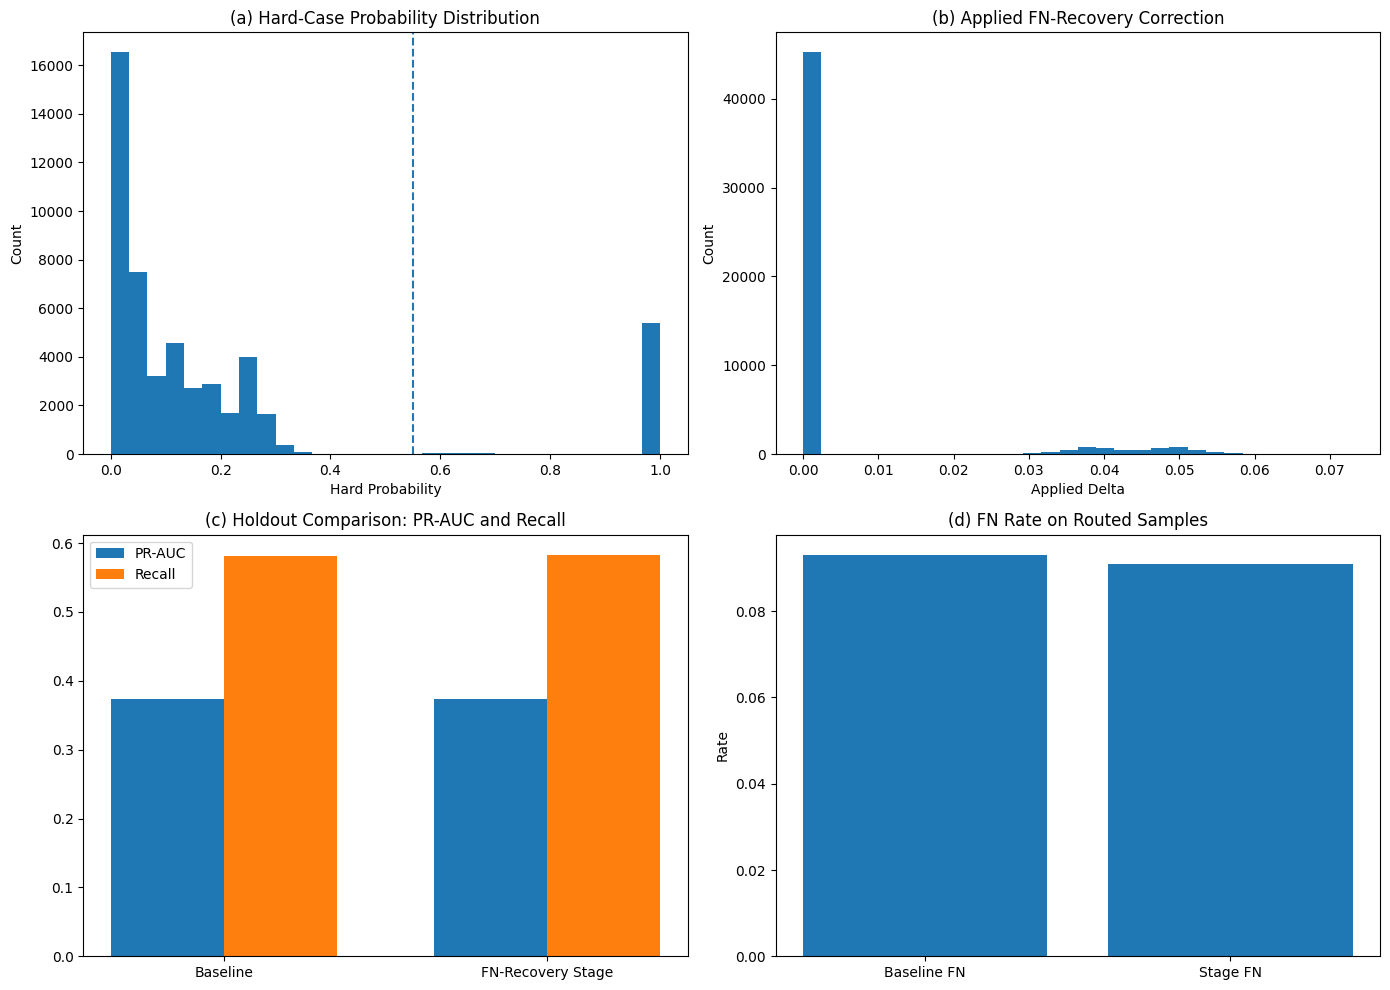


Saved:
- stage3_fnrecovery_tuning_results.csv
- stage3_fnrecovery_dev_validation_comparison.csv
- stage3_fnrecovery_holdout_comparison.csv
- stage3_fnrecovery_route_summary.csv
- stage3_fnrecovery_holdout_profile.csv
- stage3_fnrecovery_dev_fairness_comparison.csv
- stage3_fnrecovery_holdout_fairness_comparison.csv
- stage3_fnrecovery_dev_predictions.csv
- stage3_fnrecovery_holdout_predictions.csv
- stage3_fnrecovery_2x2.(png/pdf)
- stage3_fnrecovery_metadata.json


In [32]:
# ============================================================
# STAGE-3 FN-RECOVERY REFINER
# Asymmetric positive correction + threshold-aware targets
# ============================================================

import os
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "PRED_DIR", "LOG_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

HAS_X_DEV = "X_dev_df" in globals()
HAS_X_TEST = "X_test_df" in globals()

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
FNREC_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
FNREC_WEIGHT_COLS = [f"w_{e}" for e in FNREC_SELECTED_EXPERTS]

FNREC_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]

# Hard-case definition
FNREC_HARD_UNCERT_Q = 0.90

# Detector
FNREC_DETECTOR_PARAMS = dict(
    loss="log_loss",
    learning_rate=0.05,
    max_depth=4,
    max_iter=300,
    min_samples_leaf=40,
    random_state=42
)

# FN-recovery refiner
FNREC_REFINER_PARAMS = dict(
    loss="squared_error",
    learning_rate=0.03,
    max_depth=4,
    max_iter=500,
    min_samples_leaf=25,
    random_state=42
)

# routing / correction search
FNREC_ROUTE_THR_GRID = np.linspace(0.55, 0.85, 7)
FNREC_MAX_DELTA_POS_GRID = [0.05, 0.08, 0.10, 0.12]
FNREC_MAX_DELTA_NEG_GRID = [0.00, 0.01, 0.02]

# base threshold used for FN-aware target shaping
FNREC_BASE_THRESHOLD = 0.20

# target shaping
FNREC_POS_NEAR_THR_WINDOW = 0.10
FNREC_FN_BONUS = 0.050
FNREC_POS_BELOW_THR_BONUS = 0.025
FNREC_UNCERT_POS_BONUS = 0.015

# weighting
FNREC_FN_WEIGHT = 4.0
FNREC_POS_WEIGHT = 2.5
FNREC_HARD_WEIGHT = 1.5
FNREC_NEAR_THR_WEIGHT = 1.5

# selection scoring
FNREC_SCORE_W_PRAUC = 1.0
FNREC_SCORE_W_F1 = 0.08
FNREC_SCORE_W_RECALL = 0.05
FNREC_SCORE_W_ROUTE_PENALTY = 0.002
FNREC_SCORE_W_ECE_PENALTY = 0.01

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_fnrec(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_metrics_fnrec(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_fnrec(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def best_f1_threshold_fnrec(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_fnrec(prob)

    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_sex_gap_fnrec(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_fnrec(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female": sex_arr == 0, "Male": sex_arr == 1}.items():
        yt = y_true[mask]
        pp = prob[mask]
        yh = (pp >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        ids = np.digitize(pp, bins, right=False) - 1
        ids = np.clip(ids, 0, len(bins) - 2)

        ece = 0.0
        for i in range(len(bins) - 1):
            m = ids == i
            if m.sum() == 0:
                continue
            acc = yt[m].mean()
            conf = pp[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(yt))

        out[name] = {
            "Recall": recall_score(yt, yh, zero_division=0),
            "Precision": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0),
            "MCC": matthews_corrcoef(yt, yh) if len(np.unique(yh)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": yh.mean(),
        }

    return {
        "Recall_gap": abs(out["Male"]["Recall"] - out["Female"]["Recall"]),
        "Precision_gap": abs(out["Male"]["Precision"] - out["Female"]["Precision"]),
        "F1_gap": abs(out["Male"]["F1"] - out["Female"]["F1"]),
        "MCC_gap": abs(out["Male"]["MCC"] - out["Female"]["MCC"]),
        "ECE_gap": abs(out["Male"]["ECE"] - out["Female"]["ECE"]),
        "PredPosRate_gap": abs(out["Male"]["PredPosRate"] - out["Female"]["PredPosRate"]),
    }

def find_existing_pair_fnrec(split="DEV"):
    if split == "DEV":
        candidates = [
            (
                PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
                PRED_DIR / "tech2_cal_lambda_0.00_dev_weights.csv",
            ),
            (
                PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
                PRED_DIR / "light_robfair_baseline_ranked_residual_dev_weights.csv",
            ),
            (
                PRED_DIR / "robfair_baseline_ranked_residual_dev_predictions.csv",
                PRED_DIR / "robfair_baseline_ranked_residual_dev_weights.csv",
            ),
            (
                PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
                PRED_DIR / "tech1_global_gate_ranked_residual_dev_weights.csv",
            ),
        ]
    else:
        candidates = [
            (
                PRED_DIR / "final_holdout_gate_predictions.csv",
                PRED_DIR / "final_holdout_gate_weights.csv",
            ),
        ]

    for p, w in candidates:
        if p.exists() and w.exists():
            return p, w
    return None, None

def build_analysis_frame_fnrec(pred_path, weight_path, split_name, context_df=None):
    pred_df = pd.read_csv(pred_path)
    weight_df = pd.read_csv(weight_path)

    df = pd.DataFrame({
        "row_idx": np.arange(len(pred_df)),
        "y_true": pred_df["y_true"].astype(int).values,
        "p_main": clip_probs_fnrec(pred_df["pred"].astype(float).values),
    })

    for c in FNREC_WEIGHT_COLS:
        df[c] = weight_df[c].astype(float).values

    if "gate_entropy" in weight_df.columns:
        df["gate_entropy"] = weight_df["gate_entropy"].astype(float).values
    else:
        W = np.clip(df[FNREC_WEIGHT_COLS].values.astype(float), 1e-8, 1.0)
        df["gate_entropy"] = -(W * np.log(W)).sum(axis=1)

    if "dominant_expert" in weight_df.columns:
        df["dominant_expert"] = weight_df["dominant_expert"].astype(str).values
    else:
        df["dominant_expert"] = np.array(FNREC_SELECTED_EXPERTS)[
            np.argmax(df[FNREC_WEIGHT_COLS].values, axis=1)
        ]

    if "residual" in weight_df.columns:
        df["residual"] = weight_df["residual"].astype(float).values
    else:
        df["residual"] = 0.0

    if context_df is not None and len(context_df) == len(df):
        for c in context_df.columns:
            if c not in df.columns:
                df[c] = context_df[c].values

    df["y_hat_base"] = (df["p_main"] >= FNREC_BASE_THRESHOLD).astype(int)
    df["is_error_base"] = (df["y_hat_base"] != df["y_true"]).astype(int)
    df["is_fp_base"] = ((df["y_true"] == 0) & (df["y_hat_base"] == 1)).astype(int)
    df["is_fn_base"] = ((df["y_true"] == 1) & (df["y_hat_base"] == 0)).astype(int)

    df["margin_to_threshold"] = np.abs(df["p_main"] - FNREC_BASE_THRESHOLD)
    df["top_weight"] = df[FNREC_WEIGHT_COLS].max(axis=1)

    sorted_w = np.sort(df[FNREC_WEIGHT_COLS].values, axis=1)
    df["top_minus_second_weight"] = sorted_w[:, -1] - sorted_w[:, -2]

    ent = df["gate_entropy"].values
    ent_norm = (ent - ent.min()) / max(ent.max() - ent.min(), 1e-8)
    thr_unc = 1.0 - np.clip(np.abs(df["p_main"].values - FNREC_BASE_THRESHOLD) / FNREC_BASE_THRESHOLD, 0.0, 1.0)
    dominance_unc = 1.0 - df["top_weight"].values
    resid_unc = np.abs(df["residual"].values)
    if resid_unc.max() > 0:
        resid_unc = resid_unc / resid_unc.max()

    df["uncertainty_score"] = (
        0.35 * ent_norm +
        0.35 * thr_unc +
        0.20 * dominance_unc +
        0.10 * resid_unc
    )

    for e in FNREC_SELECTED_EXPERTS:
        df[f"dom_{e}"] = (df["dominant_expert"] == e).astype(int)

    hard_thr = df["uncertainty_score"].quantile(FNREC_HARD_UNCERT_Q)
    df["is_high_uncertainty"] = (df["uncertainty_score"] >= hard_thr).astype(int)
    df["hard_label_v4_fn_or_uncertain"] = (
        (df["is_fn_base"] == 1) | (df["is_high_uncertainty"] == 1)
    ).astype(int)

    df["near_threshold"] = (np.abs(df["p_main"] - FNREC_BASE_THRESHOLD) <= FNREC_POS_NEAR_THR_WINDOW).astype(int)

    return df

def get_feature_columns_fnrec(df):
    candidate_cols = [
        "p_main",
        "gate_entropy",
        "residual",
        "margin_to_threshold",
        "top_weight",
        "top_minus_second_weight",
        "uncertainty_score",
        "w_HistGradientBoosting",
        "w_DeepFM",
        "w_MLP_BCE",
        "dom_HistGradientBoosting",
        "dom_DeepFM",
        "dom_MLP_BCE",
        "near_threshold",
    ]
    for c in FNREC_CONTEXT_COLS:
        if c in df.columns:
            candidate_cols.append(c)
    return [c for c in candidate_cols if c in df.columns]

def build_fn_recovery_target(df):
    """
    Threshold-aware asymmetric target.
    Encourages upward correction for:
    - false negatives
    - positives below threshold
    - uncertain positives near threshold
    Allows only small negative correction.
    """
    y = df["y_true"].values.astype(float)
    p = df["p_main"].values.astype(float)
    is_fn = df["is_fn_base"].values.astype(int)
    is_pos = (y == 1).astype(int)
    is_high_unc = df["is_high_uncertainty"].values.astype(int)
    near_thr = df["near_threshold"].values.astype(int)

    # base residual
    target = y - p

    # focused positive recovery shaping
    bonus = np.zeros(len(df), dtype=float)
    bonus += is_fn * FNREC_FN_BONUS
    bonus += ((is_pos == 1) & (p < FNREC_BASE_THRESHOLD)).astype(float) * FNREC_POS_BELOW_THR_BONUS
    bonus += ((is_pos == 1) & (is_high_unc == 1) & (near_thr == 1)).astype(float) * FNREC_UNCERT_POS_BONUS

    target = target + bonus

    # asymmetric clipping: allow stronger upward moves than downward moves
    target = np.clip(target, -0.02, 0.15)
    return target

def build_refiner_weights_fnrec(df):
    w = np.ones(len(df), dtype=float)
    w += (df["y_true"].values == 1).astype(float) * (FNREC_POS_WEIGHT - 1.0)
    w += (df["is_fn_base"].values == 1).astype(float) * (FNREC_FN_WEIGHT - 1.0)
    w += (df["hard_label_v4_fn_or_uncertain"].values == 1).astype(float) * (FNREC_HARD_WEIGHT - 1.0)
    w += (df["near_threshold"].values == 1).astype(float) * (FNREC_NEAR_THR_WEIGHT - 1.0)
    return w

def apply_fn_recovery_refinement(
    df,
    detector,
    refiner,
    feature_cols,
    route_thr,
    max_delta_pos,
    max_delta_neg,
    use_prob_scaling=True,
):
    X = df[feature_cols].values.astype(np.float32)

    hard_prob = detector.predict_proba(X)[:, 1]
    raw_delta = refiner.predict(X)

    # asymmetric clipping
    raw_delta = np.clip(raw_delta, -max_delta_neg, max_delta_pos)

    route_mask = (hard_prob >= route_thr).astype(float)

    if use_prob_scaling:
        scale = np.clip((hard_prob - route_thr) / max(1.0 - route_thr, 1e-8), 0.0, 1.0)
    else:
        scale = route_mask

    delta = raw_delta * scale
    p_stage = clip_probs_fnrec(df["p_main"].values + delta)

    out = df.copy()
    out["hard_prob"] = hard_prob
    out["route_mask"] = route_mask
    out["delta_pred"] = raw_delta
    out["delta_applied"] = delta
    out["p_stage"] = p_stage
    return out

# ------------------------------------------------------------
# Load DEV and HOLDOUT main-model outputs
# ------------------------------------------------------------
dev_pred_path, dev_weight_path = find_existing_pair_fnrec("DEV")
hold_pred_path, hold_weight_path = find_existing_pair_fnrec("HOLDOUT")

if dev_pred_path is None or hold_pred_path is None:
    raise FileNotFoundError("Could not find both DEV and HOLDOUT main-model outputs.")

dev_context = X_dev_df.reset_index(drop=True).copy() if HAS_X_DEV else None
hold_context = X_test_df.reset_index(drop=True).copy() if HAS_X_TEST else None

dev_df = build_analysis_frame_fnrec(dev_pred_path, dev_weight_path, "DEV", context_df=dev_context)
hold_df = build_analysis_frame_fnrec(hold_pred_path, hold_weight_path, "HOLDOUT", context_df=hold_context)

feature_cols = get_feature_columns_fnrec(dev_df)

print("\nFeature columns used:")
print(feature_cols)

# ------------------------------------------------------------
# DEV train/val split for honest tuning
# ------------------------------------------------------------
train_idx, val_idx = train_test_split(
    np.arange(len(dev_df)),
    test_size=0.20,
    stratify=dev_df["hard_label_v4_fn_or_uncertain"].values,
    random_state=42
)

dev_train = dev_df.iloc[train_idx].reset_index(drop=True)
dev_val = dev_df.iloc[val_idx].reset_index(drop=True)

print("\nDEV train/val sizes:")
print("train:", dev_train.shape, "val:", dev_val.shape)

# ------------------------------------------------------------
# Stage 2 detector
# ------------------------------------------------------------
X_train_det = dev_train[feature_cols].values.astype(np.float32)
y_train_det = dev_train["hard_label_v4_fn_or_uncertain"].values.astype(int)

detector_weight = np.ones(len(dev_train), dtype=float)
detector_weight += (dev_train["is_fn_base"].values == 1).astype(float) * 2.0
detector_weight += (dev_train["is_high_uncertainty"].values == 1).astype(float) * 1.0
detector_weight += (dev_train["near_threshold"].values == 1).astype(float) * 0.5

hard_detector = HistGradientBoostingClassifier(**FNREC_DETECTOR_PARAMS)
hard_detector.fit(X_train_det, y_train_det, sample_weight=detector_weight)

# ------------------------------------------------------------
# Stage 3 FN-recovery refiner
# Train only on hard training samples
# ------------------------------------------------------------
train_hard_mask = dev_train["hard_label_v4_fn_or_uncertain"].values.astype(bool)
ref_train_df = dev_train.loc[train_hard_mask].reset_index(drop=True)

X_train_ref = ref_train_df[feature_cols].values.astype(np.float32)
y_train_ref = build_fn_recovery_target(ref_train_df)
w_train_ref = build_refiner_weights_fnrec(ref_train_df)

fn_recovery_refiner = HistGradientBoostingRegressor(**FNREC_REFINER_PARAMS)
fn_recovery_refiner.fit(X_train_ref, y_train_ref, sample_weight=w_train_ref)

# ------------------------------------------------------------
# Tune routing / correction on DEV validation
# ------------------------------------------------------------
baseline_val_thr, _ = best_f1_threshold_fnrec(dev_val["y_true"].values, dev_val["p_main"].values)

tuning_rows = []
best_cfg = None
best_score = -1e9
best_val_out = None

for route_thr in FNREC_ROUTE_THR_GRID:
    for max_delta_pos in FNREC_MAX_DELTA_POS_GRID:
        for max_delta_neg in FNREC_MAX_DELTA_NEG_GRID:
            val_out = apply_fn_recovery_refinement(
                df=dev_val,
                detector=hard_detector,
                refiner=fn_recovery_refiner,
                feature_cols=feature_cols,
                route_thr=route_thr,
                max_delta_pos=max_delta_pos,
                max_delta_neg=max_delta_neg,
                use_prob_scaling=True,
            )

            thr_stage, _ = best_f1_threshold_fnrec(val_out["y_true"].values, val_out["p_stage"].values)
            met = compute_metrics_fnrec(val_out["y_true"].values, val_out["p_stage"].values, threshold=thr_stage)

            route_rate = float(val_out["route_mask"].mean())
            score = (
                FNREC_SCORE_W_PRAUC * met["PR_AUC"]
                + FNREC_SCORE_W_F1 * met["F1"]
                + FNREC_SCORE_W_RECALL * met["Recall"]
                - FNREC_SCORE_W_ROUTE_PENALTY * route_rate
                - FNREC_SCORE_W_ECE_PENALTY * met["ECE"]
            )

            tuning_rows.append({
                "route_thr": route_thr,
                "max_delta_pos": max_delta_pos,
                "max_delta_neg": max_delta_neg,
                "route_rate": route_rate,
                "threshold_eval": thr_stage,
                **met,
                "score": score,
            })

            if score > best_score:
                best_score = score
                best_cfg = {
                    "route_thr": route_thr,
                    "max_delta_pos": max_delta_pos,
                    "max_delta_neg": max_delta_neg,
                    "thr_eval": thr_stage,
                }
                best_val_out = val_out.copy()

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["score", "PR_AUC", "Recall", "F1"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

print("\n===== FN-RECOVERY TUNING RESULTS (DEV-VAL) =====")
display(tuning_df.head(12))

print("\nBest config:")
print(best_cfg)

# ------------------------------------------------------------
# DEV validation comparison
# ------------------------------------------------------------
baseline_val_metrics = compute_metrics_fnrec(
    dev_val["y_true"].values,
    dev_val["p_main"].values,
    threshold=baseline_val_thr
)

stage_val_metrics = compute_metrics_fnrec(
    best_val_out["y_true"].values,
    best_val_out["p_stage"].values,
    threshold=best_cfg["thr_eval"]
)

dev_val_compare = pd.DataFrame([
    {"variant": "baseline_main_model", "split": "DEV_VAL", **baseline_val_metrics},
    {"variant": "fn_recovery_staged_model", "split": "DEV_VAL", **stage_val_metrics},
])

if "Sex" in dev_val.columns:
    dev_val_fair = pd.DataFrame([
        {
            "variant": "baseline_main_model",
            "split": "DEV_VAL",
            **compute_sex_gap_fnrec(
                dev_val["y_true"].values,
                dev_val["p_main"].values,
                baseline_val_thr,
                dev_val["Sex"].values
            )
        },
        {
            "variant": "fn_recovery_staged_model",
            "split": "DEV_VAL",
            **compute_sex_gap_fnrec(
                best_val_out["y_true"].values,
                best_val_out["p_stage"].values,
                best_cfg["thr_eval"],
                dev_val["Sex"].values
            )
        },
    ])
else:
    dev_val_fair = None

print("\n===== DEV VALIDATION COMPARISON =====")
display(dev_val_compare)

if dev_val_fair is not None:
    print("\n===== DEV VALIDATION FAIRNESS GAP COMPARISON =====")
    display(dev_val_fair)

# ------------------------------------------------------------
# Refit on full DEV
# ------------------------------------------------------------
X_full_det = dev_df[feature_cols].values.astype(np.float32)
y_full_det = dev_df["hard_label_v4_fn_or_uncertain"].values.astype(int)

detector_weight_full = np.ones(len(dev_df), dtype=float)
detector_weight_full += (dev_df["is_fn_base"].values == 1).astype(float) * 2.0
detector_weight_full += (dev_df["is_high_uncertainty"].values == 1).astype(float) * 1.0
detector_weight_full += (dev_df["near_threshold"].values == 1).astype(float) * 0.5

hard_detector_full = HistGradientBoostingClassifier(**FNREC_DETECTOR_PARAMS)
hard_detector_full.fit(X_full_det, y_full_det, sample_weight=detector_weight_full)

full_hard_mask = dev_df["hard_label_v4_fn_or_uncertain"].values.astype(bool)
full_ref_df = dev_df.loc[full_hard_mask].reset_index(drop=True)

X_full_ref = full_ref_df[feature_cols].values.astype(np.float32)
y_full_ref = build_fn_recovery_target(full_ref_df)
w_full_ref = build_refiner_weights_fnrec(full_ref_df)

fn_recovery_refiner_full = HistGradientBoostingRegressor(**FNREC_REFINER_PARAMS)
fn_recovery_refiner_full.fit(X_full_ref, y_full_ref, sample_weight=w_full_ref)

dev_stage_full = apply_fn_recovery_refinement(
    df=dev_df,
    detector=hard_detector_full,
    refiner=fn_recovery_refiner_full,
    feature_cols=feature_cols,
    route_thr=best_cfg["route_thr"],
    max_delta_pos=best_cfg["max_delta_pos"],
    max_delta_neg=best_cfg["max_delta_neg"],
    use_prob_scaling=True,
)

thr_baseline_dev_full, _ = best_f1_threshold_fnrec(dev_df["y_true"].values, dev_df["p_main"].values)
thr_stage_dev_full, _ = best_f1_threshold_fnrec(dev_df["y_true"].values, dev_stage_full["p_stage"].values)

# ------------------------------------------------------------
# HOLDOUT evaluation
# ------------------------------------------------------------
hold_stage = apply_fn_recovery_refinement(
    df=hold_df,
    detector=hard_detector_full,
    refiner=fn_recovery_refiner_full,
    feature_cols=feature_cols,
    route_thr=best_cfg["route_thr"],
    max_delta_pos=best_cfg["max_delta_pos"],
    max_delta_neg=best_cfg["max_delta_neg"],
    use_prob_scaling=True,
)

hold_baseline_metrics = compute_metrics_fnrec(
    hold_df["y_true"].values,
    hold_df["p_main"].values,
    threshold=thr_baseline_dev_full
)

hold_stage_metrics = compute_metrics_fnrec(
    hold_stage["y_true"].values,
    hold_stage["p_stage"].values,
    threshold=thr_stage_dev_full
)

hold_compare_df = pd.DataFrame([
    {"variant": "baseline_main_model", "split": "HOLDOUT", **hold_baseline_metrics},
    {"variant": "fn_recovery_staged_model", "split": "HOLDOUT", **hold_stage_metrics},
])

if "Sex" in hold_df.columns:
    hold_fair_df = pd.DataFrame([
        {
            "variant": "baseline_main_model",
            "split": "HOLDOUT",
            **compute_sex_gap_fnrec(
                hold_df["y_true"].values,
                hold_df["p_main"].values,
                thr_baseline_dev_full,
                hold_df["Sex"].values
            )
        },
        {
            "variant": "fn_recovery_staged_model",
            "split": "HOLDOUT",
            **compute_sex_gap_fnrec(
                hold_stage["y_true"].values,
                hold_stage["p_stage"].values,
                thr_stage_dev_full,
                hold_df["Sex"].values
            )
        },
    ])
else:
    hold_fair_df = None

print("\n===== HOLDOUT COMPARISON =====")
display(hold_compare_df)

if hold_fair_df is not None:
    print("\n===== HOLDOUT FAIRNESS GAP COMPARISON =====")
    display(hold_fair_df)

# ------------------------------------------------------------
# Routing summary
# ------------------------------------------------------------
profile_df = pd.DataFrame({
    "row_idx": hold_stage["row_idx"].values,
    "y_true": hold_stage["y_true"].values,
    "p_main": hold_stage["p_main"].values,
    "p_stage": hold_stage["p_stage"].values,
    "hard_prob": hold_stage["hard_prob"].values,
    "route_mask": hold_stage["route_mask"].values,
    "delta_pred": hold_stage["delta_pred"].values,
    "delta_applied": hold_stage["delta_applied"].values,
    "uncertainty_score": hold_stage["uncertainty_score"].values,
    "is_fn_baseline": ((hold_df["p_main"].values < thr_baseline_dev_full) & (hold_df["y_true"].values == 1)).astype(int),
    "is_fn_stage": ((hold_stage["p_stage"].values < thr_stage_dev_full) & (hold_stage["y_true"].values == 1)).astype(int),
    "is_error_baseline": ((hold_df["p_main"].values >= thr_baseline_dev_full).astype(int) != hold_df["y_true"].values).astype(int),
    "is_error_stage": ((hold_stage["p_stage"].values >= thr_stage_dev_full).astype(int) != hold_stage["y_true"].values).astype(int),
})

if "Sex" in hold_df.columns:
    profile_df["Sex"] = hold_df["Sex"].values

routed = hold_stage["route_mask"].values.astype(bool)

routing_summary_df = pd.DataFrame([{
    "Split": "HOLDOUT",
    "RouteRate": float(hold_stage["route_mask"].mean()),
    "MeanHardProb": float(hold_stage["hard_prob"].mean()),
    "MeanDeltaApplied": float(np.mean(np.abs(hold_stage["delta_applied"].values))),
    "MeanPositiveDeltaApplied": float(np.mean(hold_stage.loc[hold_stage["delta_applied"] > 0, "delta_applied"].values)) if (hold_stage["delta_applied"] > 0).sum() > 0 else 0.0,
    "MeanDeltaOnRouted": float(np.mean(np.abs(hold_stage.loc[routed, "delta_applied"].values))) if routed.sum() > 0 else 0.0,
    "BaselineFNRate": float(profile_df["is_fn_baseline"].mean()),
    "StageFNRate": float(profile_df["is_fn_stage"].mean()),
    "BaselineErrorRate": float(profile_df["is_error_baseline"].mean()),
    "StageErrorRate": float(profile_df["is_error_stage"].mean()),
}])

print("\n===== ROUTING SUMMARY =====")
display(routing_summary_df)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
tuning_df.to_csv(TAB_DIR / "stage3_fnrecovery_tuning_results.csv", index=False)
dev_val_compare.to_csv(TAB_DIR / "stage3_fnrecovery_dev_validation_comparison.csv", index=False)
hold_compare_df.to_csv(TAB_DIR / "stage3_fnrecovery_holdout_comparison.csv", index=False)
routing_summary_df.to_csv(TAB_DIR / "stage3_fnrecovery_route_summary.csv", index=False)
profile_df.to_csv(TAB_DIR / "stage3_fnrecovery_holdout_profile.csv", index=False)
dev_stage_full.to_csv(PRED_DIR / "stage3_fnrecovery_dev_predictions.csv", index=False)
hold_stage.to_csv(PRED_DIR / "stage3_fnrecovery_holdout_predictions.csv", index=False)

if dev_val_fair is not None:
    dev_val_fair.to_csv(TAB_DIR / "stage3_fnrecovery_dev_fairness_comparison.csv", index=False)
if hold_fair_df is not None:
    hold_fair_df.to_csv(TAB_DIR / "stage3_fnrecovery_holdout_fairness_comparison.csv", index=False)

# ------------------------------------------------------------
# Figures
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) hard-case probability distribution
axes[0, 0].hist(hold_stage["hard_prob"].values, bins=30)
axes[0, 0].axvline(best_cfg["route_thr"], linestyle="--")
axes[0, 0].set_title("(a) Hard-Case Probability Distribution")
axes[0, 0].set_xlabel("Hard Probability")
axes[0, 0].set_ylabel("Count")

# (b) applied delta distribution
axes[0, 1].hist(hold_stage["delta_applied"].values, bins=30)
axes[0, 1].set_title("(b) Applied FN-Recovery Correction")
axes[0, 1].set_xlabel("Applied Delta")
axes[0, 1].set_ylabel("Count")

# (c) holdout comparison
bar_names = ["Baseline", "FN-Recovery Stage"]
x = np.arange(len(bar_names))
w = 0.35
axes[1, 0].bar(x - w/2, [hold_baseline_metrics["PR_AUC"], hold_stage_metrics["PR_AUC"]], width=w, label="PR-AUC")
axes[1, 0].bar(x + w/2, [hold_baseline_metrics["Recall"], hold_stage_metrics["Recall"]], width=w, label="Recall")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(bar_names)
axes[1, 0].set_title("(c) Holdout Comparison: PR-AUC and Recall")
axes[1, 0].legend()

# (d) FN rate on routed samples
if routed.sum() > 0:
    fn_base_routed = profile_df.loc[routed, "is_fn_baseline"].mean()
    fn_stage_routed = profile_df.loc[routed, "is_fn_stage"].mean()
else:
    fn_base_routed = 0.0
    fn_stage_routed = 0.0

axes[1, 1].bar(["Baseline FN", "Stage FN"], [fn_base_routed, fn_stage_routed])
axes[1, 1].set_title("(d) FN Rate on Routed Samples")
axes[1, 1].set_ylabel("Rate")

plt.tight_layout()

fig_path = FIG_DIR / "stage3_fnrecovery_2x2"
plt.savefig(fig_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "feature_cols": feature_cols,
    "best_config": best_cfg,
    "detector_params": FNREC_DETECTOR_PARAMS,
    "refiner_params": FNREC_REFINER_PARAMS,
    "base_threshold": FNREC_BASE_THRESHOLD,
    "target_design": {
        "fn_bonus": FNREC_FN_BONUS,
        "pos_below_thr_bonus": FNREC_POS_BELOW_THR_BONUS,
        "uncert_pos_bonus": FNREC_UNCERT_POS_BONUS
    }
}
with open(LOG_DIR / "stage3_fnrecovery_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print("- stage3_fnrecovery_tuning_results.csv")
print("- stage3_fnrecovery_dev_validation_comparison.csv")
print("- stage3_fnrecovery_holdout_comparison.csv")
print("- stage3_fnrecovery_route_summary.csv")
print("- stage3_fnrecovery_holdout_profile.csv")
if dev_val_fair is not None:
    print("- stage3_fnrecovery_dev_fairness_comparison.csv")
if hold_fair_df is not None:
    print("- stage3_fnrecovery_holdout_fairness_comparison.csv")
print("- stage3_fnrecovery_dev_predictions.csv")
print("- stage3_fnrecovery_holdout_predictions.csv")
print("- stage3_fnrecovery_2x2.(png/pdf)")
print("- stage3_fnrecovery_metadata.json")

===== Sharpened Gate + FN-Risk Auxiliary Head =====
CUDA available: True
Device: cuda:0
[OK] Loaded calibrated holdout expert predictions.
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=01 temp=1.000 val_PR_AUC=0.384408 val_F1=0.427584 val_ECE=0.003571
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=02 temp=0.983 val_PR_AUC=0.384464 val_F1=0.427740 val_ECE=0.003513
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=03 temp=0.965 val_PR_AUC=0.384439 val_F1=0.427579 val_ECE=0.003600
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=04 temp=0.948 val_PR_AUC=0.384396 val_F1=0.427499 val_ECE=0.003484
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=05 temp=0.930 val_PR_AUC=0.384479 val_F1=0.427378 val_ECE=0.003411
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=06 temp=0.913 val_PR_AUC=0.384448 val_F1=0.427622 val_ECE=0.003306
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=07 temp=0.896 val_PR_AUC=0.38443

,variant,temp_end,lambda_gap,max_pos_delta,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,best_threshold,score
0,temp0.45_gap0.05_delta0.08,0.45,0.05,0.08,0.384606,0.852278,0.069312,0.234699,0.004745,0.322788,0.629872,0.426837,0.840671,0.371385,0.190,0.183794,0.096448,40589,0.190,0.434574
1,temp0.45_gap0.05_delta0.05,0.45,0.05,0.05,0.384471,0.852233,0.069301,0.234651,0.003496,0.322978,0.630918,0.427243,0.840671,0.371938,0.185,0.183991,0.094563,40589,0.185,0.434544
2,temp0.6_gap0.05_delta0.08,0.60,0.05,0.08,0.384602,0.852274,0.069305,0.234643,0.003817,0.325188,0.623071,0.427341,0.842716,0.371117,0.190,0.180468,0.095136,40589,0.190,0.434235
3,temp0.35_gap0.05_delta0.05,0.35,0.05,0.05,0.384751,0.852295,0.069299,0.234618,0.003641,0.326069,0.618363,0.426985,0.843677,0.370204,0.190,0.178620,0.094740,40589,0.190,0.434106
4,temp0.35_gap0.02_delta0.05,0.35,0.02,0.05,0.384579,0.852229,0.069306,0.234666,0.003264,0.326618,0.619147,0.427642,0.843899,0.370987,0.190,0.178546,0.094695,40589,0.190,0.434020
5,temp0.35_gap0.02_delta0.03,0.35,0.02,0.03,0.384534,0.852242,0.069307,0.234655,0.003063,0.328031,0.614962,0.427843,0.845081,0.370732,0.190,0.176575,0.094433,40589,0.190,0.433757
6,temp0.35_gap0.05_delta0.08,0.35,0.05,0.08,0.384484,0.852175,0.069313,0.234764,0.004570,0.327814,0.616270,0.427975,0.844835,0.371015,0.195,0.177068,0.096211,40589,0.195,0.433757
7,temp0.6_gap0.02_delta0.03,0.60,0.02,0.03,0.384464,0.852247,0.069308,0.234659,0.003513,0.327762,0.615485,0.427740,0.844884,0.370681,0.190,0.176871,0.094600,40589,0.190,0.433702
8,temp0.6_gap0.05_delta0.03,0.60,0.05,0.03,0.384589,0.852197,0.069300,0.234665,0.003163,0.331941,0.602668,0.428094,0.848333,0.369692,0.195,0.171007,0.094424,40589,0.195,0.433144
9,temp0.6_gap0.02_delta0.08,0.60,0.02,0.08,0.384058,0.852115,0.069327,0.234755,0.003403,0.329110,0.611562,0.427931,0.845993,0.370453,0.195,0.175023,0.095374,40589,0.195,0.433090



Best sharpened gate config: temp0.45_gap0.05_delta0.08

===== DEV VALIDATION COMPARISON =====


,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,current_main_model,DEV_VAL,0.384299,0.852175,0.069308,0.234728,0.001923,0.334112,0.598221,0.428759,0.849861,0.369952,0.20,0.168642,0.095881,40589
1,sharpened_gate_fnrisk,DEV_VAL,0.384606,0.852278,0.069312,0.234699,0.004745,0.322788,0.629872,0.426837,0.840671,0.371385,0.19,0.183794,0.096448,40589



===== DEV VALIDATION FAIRNESS GAP COMPARISON =====


...

,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,current_main_model,HOLDOUT,0.373263,0.850785,0.069943,0.236027,0.002309,0.321808,0.621260,0.423991,0.841000,0.367369,0.185,0.181843,0.094862,50736
1,sharpened_gate_fnrisk,HOLDOUT,0.373037,0.850652,0.069943,0.236094,0.002815,0.321812,0.621469,0.424043,0.840981,0.367448,0.185,0.181902,0.093520,50736



===== HOLDOUT FAIRNESS GAP COMPARISON =====


,variant,split,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
0,current_main_model,HOLDOUT,0.194917,0.030177,0.072330,0.049593,0.002926,0.135296
1,sharpened_gate_fnrisk,HOLDOUT,0.194429,0.030587,0.072541,0.049784,0.001351,0.134950



===== GATE SHARPNESS SUMMARY =====


,Split,MeanTopWeight,MeanTopGap,MeanEntropy,MeanFnRiskProb,MeanPosDelta
0,HOLDOUT,0.51855,0.275307,1.025949,0.063855,0.014526


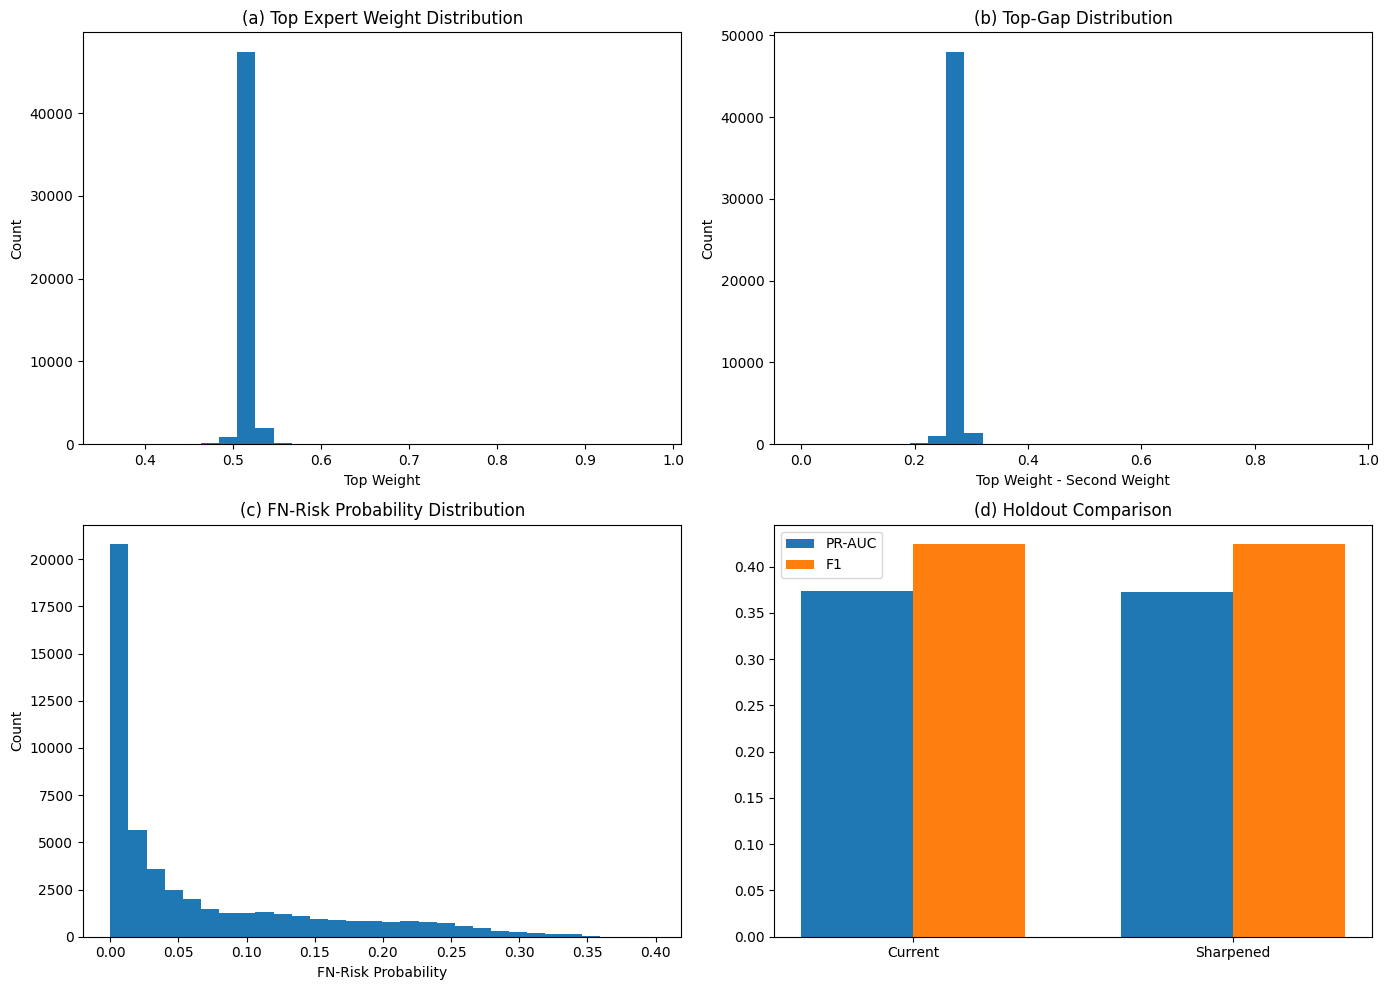


Saved:
- sharpened_gate_sweep_results.csv
- sharpened_gate_dev_validation_comparison.csv
- sharpened_gate_dev_fairness_comparison.csv
- sharpened_gate_holdout_comparison.csv
- sharpened_gate_holdout_fairness_comparison.csv
- sharpened_gate_sharpness_summary.csv
- sharpened_gate_dev_predictions.csv
- sharpened_gate_holdout_predictions.csv
- sharpened_gate_holdout_diagnostics.csv
- sharpened_gate_fnrisk_2x2.(png/pdf)
- sharpened_gate_fnrisk_metadata.json


In [33]:
# ============================================================
# SHARPENED GATE + TEMPERATURE ANNEALING + TOP-GAP REG + FN-RISK HEAD
# ============================================================

import os
import gc
import json
import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "TAB_DIR", "PRED_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

USE_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== Sharpened Gate + FN-Risk Auxiliary Head =====")
print("CUDA available:", USE_GPU)
print("Device:", DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
SG_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
SG_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]
SG_CONTEXT_COLS = [c for c in SG_CONTEXT_COLS if c in X_dev_df.columns]

SG_HIDDEN = (96, 48)
SG_DROPOUT = 0.10
SG_LR = 1e-3
SG_WD = 1e-5
SG_EPOCHS = 24
SG_BATCH = 2048
SG_PATIENCE = 5

SG_TEMP_START = 1.0
SG_TEMP_END_GRID = [0.60, 0.45, 0.35]

SG_LAMBDA_SPEC = 0.10
SG_LAMBDA_GAP_GRID = [0.02, 0.05, 0.08]
SG_LAMBDA_FNRISK = 0.08
SG_LAMBDA_DELTA_L2 = 0.001

SG_MAX_POS_DELTA_GRID = [0.03, 0.05, 0.08]
SG_NEG_DELTA = 0.0  # no negative correction in this version

SG_BASE_THRESHOLD = 0.20
SG_FNRISK_UNCERT_Q = 0.85

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_sg(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_sg(p):
    p = clip_probs_sg(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_sg(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_sg(prob)
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_sg(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_sg(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_sex_gap_sg(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_sg(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female": sex_arr == 0, "Male": sex_arr == 1}.items():
        yt = y_true[mask]
        pp = prob[mask]
        yh = (pp >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        ids = np.digitize(pp, bins, right=False) - 1
        ids = np.clip(ids, 0, len(bins) - 2)
        ece = 0.0
        for i in range(len(bins) - 1):
            m = ids == i
            if m.sum() == 0:
                continue
            acc = yt[m].mean()
            conf = pp[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(yt))

        out[name] = {
            "Recall": recall_score(yt, yh, zero_division=0),
            "Precision": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0),
            "MCC": matthews_corrcoef(yt, yh) if len(np.unique(yh)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": yh.mean(),
        }

    return {
        "Recall_gap": abs(out["Male"]["Recall"] - out["Female"]["Recall"]),
        "Precision_gap": abs(out["Male"]["Precision"] - out["Female"]["Precision"]),
        "F1_gap": abs(out["Male"]["F1"] - out["Female"]["F1"]),
        "MCC_gap": abs(out["Male"]["MCC"] - out["Female"]["MCC"]),
        "ECE_gap": abs(out["Male"]["ECE"] - out["Female"]["ECE"]),
        "PredPosRate_gap": abs(out["Male"]["PredPosRate"] - out["Female"]["PredPosRate"]),
    }

def fit_isotonic_sg(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_sg(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_sg(calibrator, p_raw):
    return clip_probs_sg(calibrator.predict(clip_probs_sg(p_raw)))

def build_soft_specialization_targets_sg(y_true, pred_df, temperature=5.0):
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    losses = []
    for c in pred_df.columns:
        p = clip_probs_sg(pred_df[c].values)
        loss = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))
        losses.append(loss)
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return (exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)).astype(np.float32)

def build_pairwise_features_sg(pred_df):
    cols = list(pred_df.columns)
    out = {}
    P = pred_df.values.astype(np.float32)

    # pairwise absolute diff, signed diff, product
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            p1 = pred_df[c1].values
            p2 = pred_df[c2].values
            out[f"absdiff_{c1}_{c2}"] = np.abs(p1 - p2)
            out[f"diff_{c1}_{c2}"] = p1 - p2
            out[f"prod_{c1}_{c2}"] = p1 * p2

    return pd.DataFrame(out)

def build_gate_features_sg(pred_df, context_df):
    cols = list(pred_df.columns)
    feat = pd.DataFrame(index=pred_df.index)

    for c in cols:
        feat[f"pred_{c}"] = pred_df[c].values

    sorted_vals = np.sort(pred_df.values, axis=1)
    for i in range(sorted_vals.shape[1]):
        feat[f"sorted_pred_{i+1}"] = sorted_vals[:, i]

    mean_p = pred_df.mean(axis=1).values
    std_p = pred_df.std(axis=1).values
    min_p = pred_df.min(axis=1).values
    max_p = pred_df.max(axis=1).values
    range_p = max_p - min_p
    entropy = compute_entropy_binary_sg(mean_p)
    margin = np.abs(mean_p - 0.5)

    feat["mean_p"] = mean_p
    feat["std_p"] = std_p
    feat["min_p"] = min_p
    feat["max_p"] = max_p
    feat["range_p"] = range_p
    feat["entropy_mean"] = entropy
    feat["margin"] = margin

    feat = pd.concat([feat, build_pairwise_features_sg(pred_df)], axis=1)

    if context_df is not None and len(context_df.columns) > 0:
        ctx = context_df.reset_index(drop=True).copy()
        feat = pd.concat([feat.reset_index(drop=True), ctx], axis=1)

        # selected expert-context interactions
        for c in cols:
            for ctx_col in [x for x in ["Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI"] if x in ctx.columns]:
                feat[f"{c}_x_{ctx_col}"] = pred_df[c].values * ctx[ctx_col].values.astype(float)

    return feat

def build_fnrisk_target_sg(y_true, pred_df):
    """
    FN-risk auxiliary target:
    positive samples that are low-scored or uncertain.
    """
    y_true = np.asarray(y_true).astype(int)
    mean_p = pred_df.mean(axis=1).values
    std_p = pred_df.std(axis=1).values
    uncert_thr = np.quantile(std_p, SG_FNRISK_UNCERT_Q)

    target = (
        (y_true == 1) &
        (
            (mean_p < (SG_BASE_THRESHOLD + 0.08)) |
            ((mean_p < 0.35) & (std_p >= uncert_thr))
        )
    ).astype(int)

    return target

def maybe_load_current_main_predictions(split="DEV"):
    if split == "DEV":
        candidates = [
            PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
            PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
        ]
    else:
        candidates = [
            PRED_DIR / "final_holdout_gate_predictions.csv",
        ]
    for p in candidates:
        if p.exists():
            return pd.read_csv(p)
    return None

# ------------------------------------------------------------
# Prepare dev calibrated expert predictions
# ------------------------------------------------------------
dev_raw_df = MODULE4_OOF_MATRIX[SG_SELECTED_EXPERTS].copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

expert_calibrators = {}
dev_cal_df = pd.DataFrame(index=dev_raw_df.index)

for e in SG_SELECTED_EXPERTS:
    cal = fit_isotonic_sg(y_dev_np, dev_raw_df[e].values)
    expert_calibrators[e] = cal
    dev_cal_df[e] = apply_isotonic_sg(cal, dev_raw_df[e].values)

# ------------------------------------------------------------
# Load holdout expert predictions
# Expected preferred file:
# final_holdout_expert_calibrated_predictions.csv
# fallback:
# final_holdout_expert_raw_predictions.csv
# ------------------------------------------------------------
hold_cal_path = PRED_DIR / "final_holdout_expert_calibrated_predictions.csv"
hold_raw_path = PRED_DIR / "final_holdout_expert_raw_predictions.csv"

if hold_cal_path.exists():
    hold_cal_df = pd.read_csv(hold_cal_path)[SG_SELECTED_EXPERTS].copy()
    print("[OK] Loaded calibrated holdout expert predictions.")
elif hold_raw_path.exists():
    hold_raw_df = pd.read_csv(hold_raw_path)[SG_SELECTED_EXPERTS].copy()
    hold_cal_df = pd.DataFrame(index=hold_raw_df.index)
    for e in SG_SELECTED_EXPERTS:
        hold_cal_df[e] = apply_isotonic_sg(expert_calibrators[e], hold_raw_df[e].values)
    print("[OK] Loaded raw holdout expert predictions and calibrated them.")
else:
    raise FileNotFoundError(
        "Need one of these files in PRED_DIR:\n"
        "- final_holdout_expert_calibrated_predictions.csv\n"
        "- final_holdout_expert_raw_predictions.csv"
    )

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------
dev_context_df = X_dev_df[SG_CONTEXT_COLS].reset_index(drop=True).copy()
hold_context_df = X_test_df[SG_CONTEXT_COLS].reset_index(drop=True).copy()

dev_feat_df = build_gate_features_sg(dev_cal_df, dev_context_df)
hold_feat_df = build_gate_features_sg(hold_cal_df, hold_context_df)

fnrisk_target_dev = build_fnrisk_target_sg(y_dev_np, dev_cal_df)

# ------------------------------------------------------------
# Train/val split on dev
# ------------------------------------------------------------
idx_all = np.arange(len(y_dev_np))
idx_tr, idx_val = train_test_split(
    idx_all,
    test_size=0.20,
    stratify=y_dev_np,
    random_state=42
)

X_tr_df = dev_feat_df.iloc[idx_tr].reset_index(drop=True)
X_val_df = dev_feat_df.iloc[idx_val].reset_index(drop=True)

P_tr_df = dev_cal_df.iloc[idx_tr].reset_index(drop=True)
P_val_df = dev_cal_df.iloc[idx_val].reset_index(drop=True)

y_tr = y_dev_np[idx_tr]
y_val = y_dev_np[idx_val]

fnrisk_tr = fnrisk_target_dev[idx_tr]
fnrisk_val = fnrisk_target_dev[idx_val]

soft_tr = build_soft_specialization_targets_sg(y_tr, P_tr_df)
soft_val = build_soft_specialization_targets_sg(y_val, P_val_df)

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr_df.values.astype(np.float32)).astype(np.float32)
X_val = scaler.transform(X_val_df.values.astype(np.float32)).astype(np.float32)
X_dev_full = scaler.transform(dev_feat_df.values.astype(np.float32)).astype(np.float32)
X_hold = scaler.transform(hold_feat_df.values.astype(np.float32)).astype(np.float32)

P_tr = P_tr_df.values.astype(np.float32)
P_val = P_val_df.values.astype(np.float32)
P_dev_full = dev_cal_df.values.astype(np.float32)
P_hold = hold_cal_df.values.astype(np.float32)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
class SharpenedGateDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, P, soft_targets, fnrisk_target):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)
        self.P = torch.tensor(P, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.fnrisk_target = torch.tensor(fnrisk_target.reshape(-1, 1), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.P[idx], self.soft_targets[idx], self.fnrisk_target[idx]

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class SharpenedGateFnRiskNet(nn.Module):
    def __init__(
        self,
        input_dim,
        n_experts,
        hidden_dims=(96, 48),
        dropout=0.10,
        temperature=1.0,
        max_pos_delta=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.max_pos_delta = max_pos_delta

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        self.backbone = nn.Sequential(*layers)

        self.gate_head = nn.Linear(prev, n_experts)
        self.fnrisk_head = nn.Linear(prev, 1)
        self.delta_head = nn.Linear(prev, 1)

    def forward(self, x, expert_probs):
        z = self.backbone(x)

        gate_logits = self.gate_head(z) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        fused_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        fnrisk_logit = self.fnrisk_head(z)
        fnrisk_prob = torch.sigmoid(fnrisk_logit)

        pos_delta = self.max_pos_delta * torch.sigmoid(self.delta_head(z))
        corrected_prob = fused_prob + fnrisk_prob * pos_delta
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob

def top_gap_regularizer(weights):
    sorted_w, _ = torch.sort(weights, dim=1, descending=True)
    gap = sorted_w[:, 0] - sorted_w[:, 1]
    return gap.mean()

# ------------------------------------------------------------
# Train one config
# ------------------------------------------------------------
def train_one_sharpened_gate(
    temp_end=0.45,
    lambda_gap=0.05,
    max_pos_delta=0.05,
):
    train_ds = SharpenedGateDataset(X_tr, y_tr, P_tr, soft_tr, fnrisk_tr)
    val_ds = SharpenedGateDataset(X_val, y_val, P_val, soft_val, fnrisk_val)

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=SG_BATCH, shuffle=True, drop_last=False)
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=SG_BATCH, shuffle=False, drop_last=False)

    model = SharpenedGateFnRiskNet(
        input_dim=X_tr.shape[1],
        n_experts=P_tr.shape[1],
        hidden_dims=SG_HIDDEN,
        dropout=SG_DROPOUT,
        temperature=SG_TEMP_START,
        max_pos_delta=max_pos_delta,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=SG_LR, weight_decay=SG_WD)
    bce = nn.BCELoss()
    kl = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_score = -1e9
    best_val_pred = None
    no_improve = 0
    history = []

    for epoch in range(SG_EPOCHS):
        # linear temperature annealing
        frac = epoch / max(SG_EPOCHS - 1, 1)
        cur_temp = SG_TEMP_START + frac * (temp_end - SG_TEMP_START)
        model.temperature = cur_temp

        model.train()
        train_losses = []

        for xb, yb, pb, sb, fb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            pb = pb.to(DEVICE)
            sb = sb.to(DEVICE)
            fb = fb.to(DEVICE)

            optimizer.zero_grad()

            weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob = model(xb, pb)

            loss_main = bce(corrected_prob, yb)
            loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_fnrisk = bce(fnrisk_prob, fb)
            loss_gap = top_gap_regularizer(weights)
            loss_delta = torch.mean(pos_delta ** 2)

            loss = (
                loss_main
                + SG_LAMBDA_SPEC * loss_spec
                + SG_LAMBDA_FNRISK * loss_fnrisk
                - lambda_gap * loss_gap
                + SG_LAMBDA_DELTA_L2 * loss_delta
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        # validation
        model.eval()
        val_pred_list = []
        with torch.no_grad():
            for xb, yb, pb, sb, fb in val_loader:
                xb = xb.to(DEVICE)
                pb = pb.to(DEVICE)

                weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob = model(xb, pb)
                val_pred_list.append(corrected_prob.detach().cpu().numpy().reshape(-1))

        val_pred = np.concatenate(val_pred_list)
        thr_val, _ = best_f1_threshold_sg(y_val, val_pred)
        met = compute_metrics_sg(y_val, val_pred, threshold=thr_val)

        # select using PR-AUC + slight reward for recall/MCC
        val_score = met["PR_AUC"] + 0.05 * met["Recall"] + 0.05 * met["MCC"] - 0.02 * met["ECE"]

        history.append({
            "epoch": epoch + 1,
            "temperature": cur_temp,
            "train_loss": float(np.mean(train_losses)),
            "val_PR_AUC": met["PR_AUC"],
            "val_Recall": met["Recall"],
            "val_F1": met["F1"],
            "val_MCC": met["MCC"],
            "val_ECE": met["ECE"],
            "val_threshold": thr_val,
            "val_score": val_score,
            "lambda_gap": lambda_gap,
            "max_pos_delta": max_pos_delta,
            "temp_end": temp_end,
        })

        if val_score > best_val_score:
            best_val_score = val_score
            best_state = copy.deepcopy(model.state_dict())
            best_val_pred = val_pred.copy()
            best_thr = thr_val
            best_metrics = met.copy()
            no_improve = 0
        else:
            no_improve += 1

        print(
            f"[temp_end={temp_end:.2f}, lambda_gap={lambda_gap:.3f}, max_pos_delta={max_pos_delta:.3f}] "
            f"epoch={epoch+1:02d} temp={cur_temp:.3f} val_PR_AUC={met['PR_AUC']:.6f} "
            f"val_F1={met['F1']:.6f} val_ECE={met['ECE']:.6f}"
        )

        if no_improve >= SG_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    return {
        "model": model,
        "history_df": pd.DataFrame(history),
        "best_val_pred": best_val_pred,
        "best_thr": best_thr,
        "best_metrics": best_metrics,
        "best_score": best_val_score,
    }

# ------------------------------------------------------------
# Small sweep
# ------------------------------------------------------------
sweep_rows = []
models_store = {}

for temp_end in SG_TEMP_END_GRID:
    for lambda_gap in SG_LAMBDA_GAP_GRID:
        for max_pos_delta in SG_MAX_POS_DELTA_GRID:
            res = train_one_sharpened_gate(
                temp_end=temp_end,
                lambda_gap=lambda_gap,
                max_pos_delta=max_pos_delta,
            )

            key = f"temp{temp_end}_gap{lambda_gap}_delta{max_pos_delta}"
            models_store[key] = res

            row = {
                "variant": key,
                "temp_end": temp_end,
                "lambda_gap": lambda_gap,
                "max_pos_delta": max_pos_delta,
                **res["best_metrics"],
                "best_threshold": res["best_thr"],
                "score": res["best_score"],
            }
            sweep_rows.append(row)

sweep_df = pd.DataFrame(sweep_rows).sort_values(
    ["score", "PR_AUC", "Recall", "MCC"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

print("\n===== SHARPENED GATE SWEEP RESULTS =====")
display(sweep_df.head(12))

best_key = sweep_df.iloc[0]["variant"]
best_res = models_store[best_key]
print("\nBest sharpened gate config:", best_key)

# ------------------------------------------------------------
# DEV validation comparison against current main model if available
# ------------------------------------------------------------
dev_main_df = maybe_load_current_main_predictions("DEV")
if dev_main_df is not None and len(dev_main_df) == len(y_dev_np):
    dev_main_p = clip_probs_sg(dev_main_df["pred"].values)[idx_val]
else:
    # fallback: simple average calibrated experts on val
    dev_main_p = clip_probs_sg(P_val.mean(axis=1))

thr_main_val, _ = best_f1_threshold_sg(y_val, dev_main_p)
main_val_metrics = compute_metrics_sg(y_val, dev_main_p, threshold=thr_main_val)

sharp_val_metrics = best_res["best_metrics"].copy()

dev_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "DEV_VAL", **main_val_metrics},
    {"variant": "sharpened_gate_fnrisk", "split": "DEV_VAL", **sharp_val_metrics},
])

dev_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "DEV_VAL",
        **compute_sex_gap_sg(y_val, dev_main_p, thr_main_val, X_dev_df.iloc[idx_val]["Sex"].values)
    },
    {
        "variant": "sharpened_gate_fnrisk",
        "split": "DEV_VAL",
        **compute_sex_gap_sg(y_val, best_res["best_val_pred"], best_res["best_thr"], X_dev_df.iloc[idx_val]["Sex"].values)
    },
])

print("\n===== DEV VALIDATION COMPARISON =====")
display(dev_compare_df)

print("\n===== DEV VALIDATION FAIRNESS GAP COMPARISON =====")
display(dev_fair_df)

# ------------------------------------------------------------
# Refit best config on full dev
# ------------------------------------------------------------
best_temp_end = float(sweep_df.iloc[0]["temp_end"])
best_lambda_gap = float(sweep_df.iloc[0]["lambda_gap"])
best_max_pos_delta = float(sweep_df.iloc[0]["max_pos_delta"])

full_soft = build_soft_specialization_targets_sg(y_dev_np, dev_cal_df)
full_fnrisk = fnrisk_target_dev.copy()

full_ds = SharpenedGateDataset(X_dev_full, y_dev_np, P_dev_full, full_soft, full_fnrisk)
full_loader = torch.utils.data.DataLoader(full_ds, batch_size=SG_BATCH, shuffle=True, drop_last=False)

best_model_full = SharpenedGateFnRiskNet(
    input_dim=X_dev_full.shape[1],
    n_experts=P_dev_full.shape[1],
    hidden_dims=SG_HIDDEN,
    dropout=SG_DROPOUT,
    temperature=SG_TEMP_START,
    max_pos_delta=best_max_pos_delta,
).to(DEVICE)

optimizer = torch.optim.Adam(best_model_full.parameters(), lr=SG_LR, weight_decay=SG_WD)
bce = nn.BCELoss()
kl = nn.KLDivLoss(reduction="batchmean")

best_state_full = copy.deepcopy(best_model_full.state_dict())
best_dev_score = -1e9
no_improve = 0

for epoch in range(SG_EPOCHS):
    frac = epoch / max(SG_EPOCHS - 1, 1)
    cur_temp = SG_TEMP_START + frac * (best_temp_end - SG_TEMP_START)
    best_model_full.temperature = cur_temp

    best_model_full.train()
    train_losses = []

    for xb, yb, pb, sb, fb in full_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        pb = pb.to(DEVICE)
        sb = sb.to(DEVICE)
        fb = fb.to(DEVICE)

        optimizer.zero_grad()
        weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob = best_model_full(xb, pb)

        loss_main = bce(corrected_prob, yb)
        loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
        loss_fnrisk = bce(fnrisk_prob, fb)
        loss_gap = top_gap_regularizer(weights)
        loss_delta = torch.mean(pos_delta ** 2)

        loss = (
            loss_main
            + SG_LAMBDA_SPEC * loss_spec
            + SG_LAMBDA_FNRISK * loss_fnrisk
            - best_lambda_gap * loss_gap
            + SG_LAMBDA_DELTA_L2 * loss_delta
        )

        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    # full-dev monitor
    best_model_full.eval()
    with torch.no_grad():
        xb = torch.tensor(X_dev_full, dtype=torch.float32).to(DEVICE)
        pb = torch.tensor(P_dev_full, dtype=torch.float32).to(DEVICE)
        weights_dev, fused_dev, fnrisk_dev, posdelta_dev, pred_dev = best_model_full(xb, pb)
        pred_dev_np = pred_dev.detach().cpu().numpy().reshape(-1)

    thr_dev_full, _ = best_f1_threshold_sg(y_dev_np, pred_dev_np)
    met_dev = compute_metrics_sg(y_dev_np, pred_dev_np, threshold=thr_dev_full)
    dev_score = met_dev["PR_AUC"] + 0.05 * met_dev["Recall"] + 0.05 * met_dev["MCC"] - 0.02 * met_dev["ECE"]

    if dev_score > best_dev_score:
        best_dev_score = dev_score
        best_state_full = copy.deepcopy(best_model_full.state_dict())
        best_thr_dev_full = thr_dev_full
        best_pred_dev_full = pred_dev_np.copy()
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= SG_PATIENCE:
        break

best_model_full.load_state_dict(best_state_full)
best_model_full.eval()

# ------------------------------------------------------------
# HOLDOUT evaluation
# ------------------------------------------------------------
with torch.no_grad():
    xb_hold = torch.tensor(X_hold, dtype=torch.float32).to(DEVICE)
    pb_hold = torch.tensor(P_hold, dtype=torch.float32).to(DEVICE)
    weights_hold, fused_hold, fnrisk_hold, posdelta_hold, pred_hold = best_model_full(xb_hold, pb_hold)

hold_pred_np = pred_hold.detach().cpu().numpy().reshape(-1)
hold_weights_np = weights_hold.detach().cpu().numpy()
hold_fnrisk_np = fnrisk_hold.detach().cpu().numpy().reshape(-1)
hold_posdelta_np = posdelta_hold.detach().cpu().numpy().reshape(-1)

hold_main_df = maybe_load_current_main_predictions("HOLDOUT")
if hold_main_df is not None and len(hold_main_df) == len(y_test_arr):
    hold_main_p = clip_probs_sg(hold_main_df["pred"].values)
else:
    hold_main_p = clip_probs_sg(P_hold.mean(axis=1))

hold_thr_main, _ = best_f1_threshold_sg(np.asarray(y_test_arr), hold_main_p)
hold_thr_sharp, _ = best_f1_threshold_sg(np.asarray(y_test_arr), hold_pred_np)

hold_main_metrics = compute_metrics_sg(np.asarray(y_test_arr), hold_main_p, threshold=hold_thr_main)
hold_sharp_metrics = compute_metrics_sg(np.asarray(y_test_arr), hold_pred_np, threshold=hold_thr_sharp)

hold_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "HOLDOUT", **hold_main_metrics},
    {"variant": "sharpened_gate_fnrisk", "split": "HOLDOUT", **hold_sharp_metrics},
])

hold_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "HOLDOUT",
        **compute_sex_gap_sg(np.asarray(y_test_arr), hold_main_p, hold_thr_main, X_test_df["Sex"].values)
    },
    {
        "variant": "sharpened_gate_fnrisk",
        "split": "HOLDOUT",
        **compute_sex_gap_sg(np.asarray(y_test_arr), hold_pred_np, hold_thr_sharp, X_test_df["Sex"].values)
    },
])

print("\n===== HOLDOUT COMPARISON =====")
display(hold_compare_df)

print("\n===== HOLDOUT FAIRNESS GAP COMPARISON =====")
display(hold_fair_df)

# ------------------------------------------------------------
# Gate sharpness diagnostics
# ------------------------------------------------------------
sharp_diag_df = pd.DataFrame({
    "row_idx_holdout": np.arange(len(hold_pred_np)),
    "y_true": np.asarray(y_test_arr).astype(int),
    "pred": hold_pred_np,
    "fnrisk_prob": hold_fnrisk_np,
    "pos_delta": hold_posdelta_np,
    "w_HistGradientBoosting": hold_weights_np[:, 0],
    "w_DeepFM": hold_weights_np[:, 1],
    "w_MLP_BCE": hold_weights_np[:, 2],
})
sharp_diag_df["top_weight"] = sharp_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].max(axis=1)
sorted_w = np.sort(sharp_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, axis=1)
sharp_diag_df["top_gap"] = sorted_w[:, -1] - sorted_w[:, -2]
sharp_diag_df["gate_entropy"] = -np.sum(
    np.clip(sharp_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, 1e-8, 1.0) *
    np.log(np.clip(sharp_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, 1e-8, 1.0)),
    axis=1
)

gate_summary_df = pd.DataFrame([{
    "Split": "HOLDOUT",
    "MeanTopWeight": float(sharp_diag_df["top_weight"].mean()),
    "MeanTopGap": float(sharp_diag_df["top_gap"].mean()),
    "MeanEntropy": float(sharp_diag_df["gate_entropy"].mean()),
    "MeanFnRiskProb": float(sharp_diag_df["fnrisk_prob"].mean()),
    "MeanPosDelta": float(sharp_diag_df["pos_delta"].mean()),
}])

print("\n===== GATE SHARPNESS SUMMARY =====")
display(gate_summary_df)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
sweep_df.to_csv(TAB_DIR / "sharpened_gate_sweep_results.csv", index=False)
dev_compare_df.to_csv(TAB_DIR / "sharpened_gate_dev_validation_comparison.csv", index=False)
dev_fair_df.to_csv(TAB_DIR / "sharpened_gate_dev_fairness_comparison.csv", index=False)
hold_compare_df.to_csv(TAB_DIR / "sharpened_gate_holdout_comparison.csv", index=False)
hold_fair_df.to_csv(TAB_DIR / "sharpened_gate_holdout_fairness_comparison.csv", index=False)
gate_summary_df.to_csv(TAB_DIR / "sharpened_gate_sharpness_summary.csv", index=False)

sharp_diag_df.to_csv(PRED_DIR / "sharpened_gate_holdout_diagnostics.csv", index=False)
pd.DataFrame({
    "row_idx_dev": np.arange(len(best_pred_dev_full)),
    "y_true": y_dev_np,
    "pred": best_pred_dev_full,
}).to_csv(PRED_DIR / "sharpened_gate_dev_predictions.csv", index=False)
pd.DataFrame({
    "row_idx_holdout": np.arange(len(hold_pred_np)),
    "y_true": np.asarray(y_test_arr).astype(int),
    "pred": hold_pred_np,
}).to_csv(PRED_DIR / "sharpened_gate_holdout_predictions.csv", index=False)

# ------------------------------------------------------------
# Figures
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) top-weight distribution
axes[0, 0].hist(sharp_diag_df["top_weight"].values, bins=30)
axes[0, 0].set_title("(a) Top Expert Weight Distribution")
axes[0, 0].set_xlabel("Top Weight")
axes[0, 0].set_ylabel("Count")

# (b) top-gap distribution
axes[0, 1].hist(sharp_diag_df["top_gap"].values, bins=30)
axes[0, 1].set_title("(b) Top-Gap Distribution")
axes[0, 1].set_xlabel("Top Weight - Second Weight")
axes[0, 1].set_ylabel("Count")

# (c) fnrisk probability distribution
axes[1, 0].hist(sharp_diag_df["fnrisk_prob"].values, bins=30)
axes[1, 0].set_title("(c) FN-Risk Probability Distribution")
axes[1, 0].set_xlabel("FN-Risk Probability")
axes[1, 0].set_ylabel("Count")

# (d) holdout PR-AUC / F1 comparison
names = ["Current", "Sharpened"]
x = np.arange(2)
w = 0.35
axes[1, 1].bar(x - w/2, [hold_main_metrics["PR_AUC"], hold_sharp_metrics["PR_AUC"]], width=w, label="PR-AUC")
axes[1, 1].bar(x + w/2, [hold_main_metrics["F1"], hold_sharp_metrics["F1"]], width=w, label="F1")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(names)
axes[1, 1].set_title("(d) Holdout Comparison")
axes[1, 1].legend()

plt.tight_layout()

fig_path = FIG_DIR / "sharpened_gate_fnrisk_2x2"
plt.savefig(fig_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "selected_experts": SG_SELECTED_EXPERTS,
    "context_cols": SG_CONTEXT_COLS,
    "best_variant": best_key,
    "best_temp_end": best_temp_end,
    "best_lambda_gap": best_lambda_gap,
    "best_max_pos_delta": best_max_pos_delta,
    "base_threshold": SG_BASE_THRESHOLD,
    "notes": "Sharpened gate with temperature annealing, top-gap regularization, FN-risk auxiliary head, and bounded positive correction."
}
with open(LOG_DIR / "sharpened_gate_fnrisk_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print("- sharpened_gate_sweep_results.csv")
print("- sharpened_gate_dev_validation_comparison.csv")
print("- sharpened_gate_dev_fairness_comparison.csv")
print("- sharpened_gate_holdout_comparison.csv")
print("- sharpened_gate_holdout_fairness_comparison.csv")
print("- sharpened_gate_sharpness_summary.csv")
print("- sharpened_gate_dev_predictions.csv")
print("- sharpened_gate_holdout_predictions.csv")
print("- sharpened_gate_holdout_diagnostics.csv")
print("- sharpened_gate_fnrisk_2x2.(png/pdf)")
print("- sharpened_gate_fnrisk_metadata.json")

===== Cross-Expert Attention Gate =====
CUDA available: True
Device: cuda:0
[OK] Loaded calibrated holdout expert predictions.
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=01 temp=1.000 val_PR_AUC=0.384524 val_F1=0.428238 val_ECE=0.003408
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=02 temp=0.983 val_PR_AUC=0.384513 val_F1=0.428206 val_ECE=0.003410
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=03 temp=0.965 val_PR_AUC=0.384462 val_F1=0.428278 val_ECE=0.003198
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=04 temp=0.948 val_PR_AUC=0.384506 val_F1=0.428066 val_ECE=0.003248
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=05 temp=0.930 val_PR_AUC=0.384492 val_F1=0.428425 val_ECE=0.003145
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=06 temp=0.913 val_PR_AUC=0.384541 val_F1=0.428145 val_ECE=0.003348
[temp_end=0.60, lambda_gap=0.020, max_pos_delta=0.030] epoch=07 temp=0.896 val_PR_AUC=0.384532 val_F1=0.4

,variant,temp_end,lambda_gap,max_pos_delta,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,best_threshold,score
0,temp0.35_gap0.02_delta0.08,0.35,0.02,0.08,0.384571,0.852239,0.069309,0.234663,0.003401,0.327190,0.617578,0.427756,0.844367,0.370930,0.190,0.177782,0.094565,40589,0.190,0.433928
1,temp0.45_gap0.02_delta0.08,0.45,0.02,0.08,0.384573,0.852244,0.069306,0.234649,0.003171,0.327949,0.616008,0.428026,0.844933,0.371041,0.190,0.176920,0.094470,40589,0.190,0.433862
2,temp0.35_gap0.02_delta0.05,0.35,0.02,0.05,0.384553,0.852245,0.069306,0.234651,0.003386,0.328217,0.615224,0.428064,0.845155,0.370994,0.190,0.176550,0.094432,40589,0.190,0.433797
3,temp0.6_gap0.02_delta0.05,0.60,0.02,0.05,0.384507,0.852232,0.069306,0.234664,0.003300,0.328300,0.614177,0.427882,0.845303,0.370686,0.190,0.176205,0.094723,40589,0.190,0.433685
4,temp0.45_gap0.02_delta0.03,0.45,0.02,0.03,0.384564,0.852261,0.069305,0.234642,0.003246,0.328883,0.612085,0.427866,0.845820,0.370442,0.190,0.175294,0.094235,40589,0.190,0.433625
5,temp0.6_gap0.02_delta0.03,0.60,0.02,0.03,0.384513,0.852241,0.069306,0.234657,0.003410,0.329208,0.612346,0.428206,0.845968,0.370829,0.190,0.175195,0.094344,40589,0.190,0.433603
6,temp0.45_gap0.05_delta0.05,0.45,0.05,0.05,0.384622,0.852289,0.069300,0.234621,0.003769,0.328409,0.610515,0.427081,0.845722,0.369441,0.190,0.175097,0.094522,40589,0.190,0.433545
7,temp0.35_gap0.05_delta0.08,0.35,0.05,0.08,0.384679,0.852278,0.069301,0.234630,0.003651,0.330713,0.605284,0.427726,0.847446,0.369571,0.195,0.172387,0.094810,40589,0.195,0.433349
8,temp0.6_gap0.05_delta0.05,0.60,0.05,0.05,0.384756,0.852279,0.069301,0.234626,0.003452,0.331605,0.602406,0.427749,0.848185,0.369299,0.195,0.171105,0.094495,40589,0.195,0.433272
9,temp0.35_gap0.05_delta0.03,0.35,0.05,0.03,0.384753,0.852282,0.069298,0.234614,0.003186,0.332081,0.601360,0.427880,0.848530,0.369332,0.195,0.170563,0.094269,40589,0.195,0.433224



Best attention-gate config: temp0.35_gap0.02_delta0.08

===== DEV VALIDATION COMPARISON =====


,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,current_main_model,DEV_VAL,0.384299,0.852175,0.069308,0.234728,0.001923,0.334112,0.598221,0.428759,0.849861,0.369952,0.20,0.168642,0.095881,40589
1,cross_expert_attention_gate,DEV_VAL,0.384571,0.852239,0.069309,0.234663,0.003401,0.327190,0.617578,0.427756,0.844367,0.370930,0.19,0.177782,0.094565,40589



===== DEV VALIDATION FAIRNESS GAP COMPARISON =====


...

,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,current_main_model,HOLDOUT,0.373263,0.850785,0.069943,0.236027,0.002309,0.321808,0.621260,0.423991,0.84100,0.367369,0.185,0.181843,0.094862,50736
1,cross_expert_attention_gate,HOLDOUT,0.373438,0.850758,0.069919,0.236022,0.002190,0.322486,0.617912,0.423794,0.84173,0.366777,0.185,0.180483,0.093397,50736



===== HOLDOUT FAIRNESS GAP COMPARISON =====


,variant,split,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
0,current_main_model,HOLDOUT,0.194917,0.030177,0.072330,0.049593,0.002926,0.135296
1,cross_expert_attention_gate,HOLDOUT,0.192468,0.029892,0.071818,0.048608,0.002701,0.134058



===== ATTENTION GATE SUMMARY =====


,Split,MeanTopWeight,MeanTopGap,MeanEntropy,MeanFnRiskProb,MeanPosDelta
0,HOLDOUT,0.419633,0.129283,1.082426,0.067839,0.004629


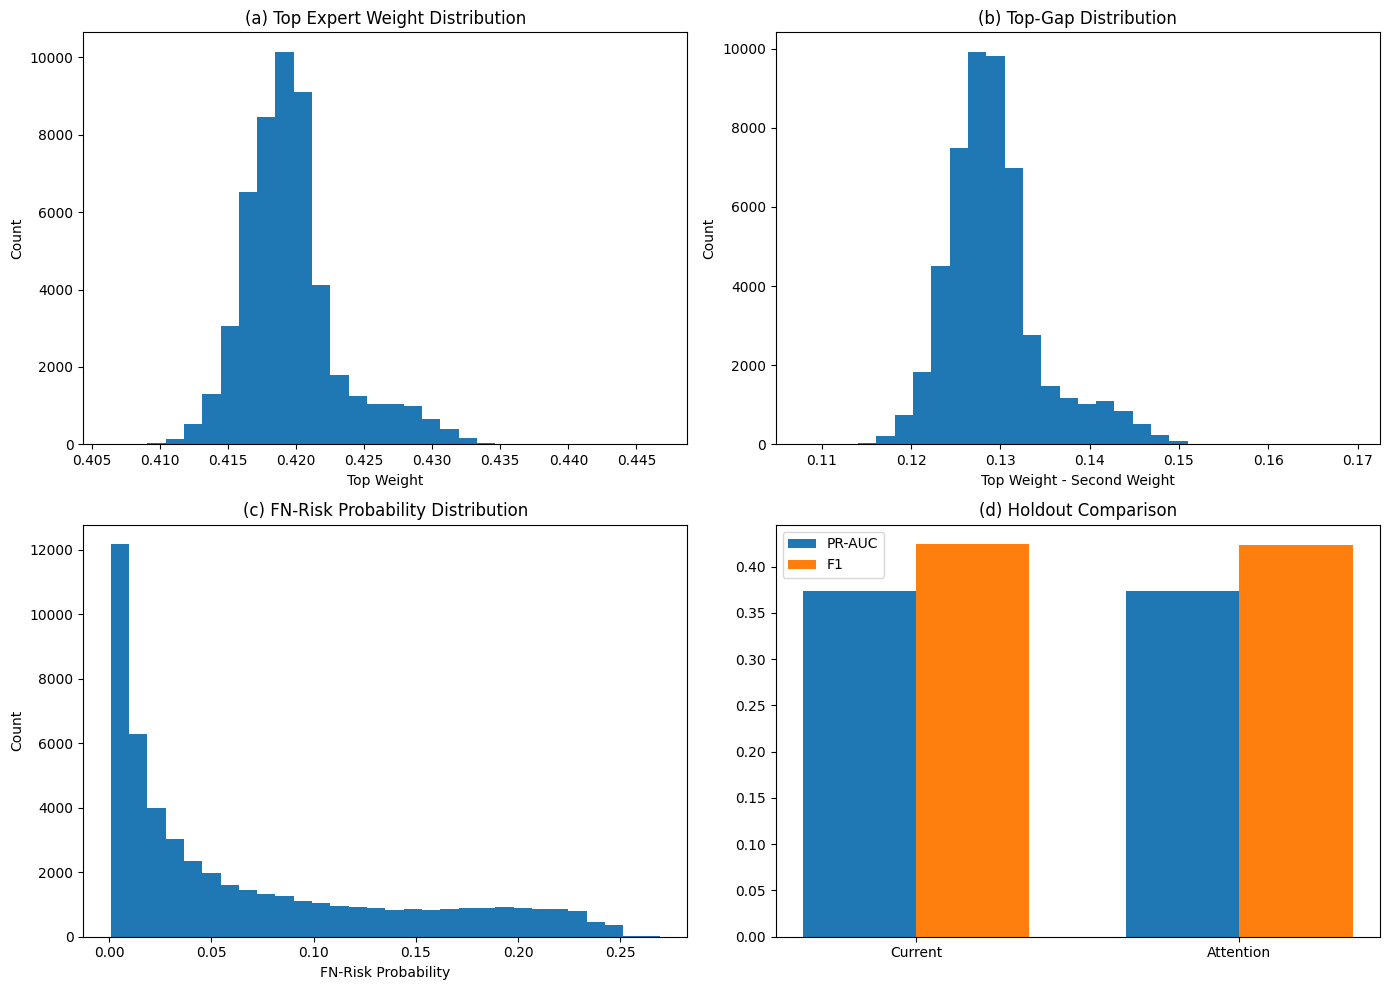


Saved:
- attention_gate_sweep_results.csv
- attention_gate_dev_validation_comparison.csv
- attention_gate_dev_fairness_comparison.csv
- attention_gate_holdout_comparison.csv
- attention_gate_holdout_fairness_comparison.csv
- attention_gate_summary.csv
- attention_gate_dev_predictions.csv
- attention_gate_holdout_predictions.csv
- attention_gate_holdout_diagnostics.csv
- cross_expert_attention_gate_2x2.(png/pdf)
- cross_expert_attention_gate_metadata.json


In [45]:
# ============================================================
# CROSS-EXPERT ATTENTION GATE
# Learned expert interaction before routing
# ============================================================

import os
import gc
import json
import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "TAB_DIR", "PRED_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

USE_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== Cross-Expert Attention Gate =====")
print("CUDA available:", USE_GPU)
print("Device:", DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
ATN_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
ATN_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]
ATN_CONTEXT_COLS = [c for c in ATN_CONTEXT_COLS if c in X_dev_df.columns]

ATN_TOKEN_DIM = 32
ATN_NHEAD = 4
ATN_NUM_LAYERS = 1
ATN_FF_DIM = 64

ATN_HIDDEN = 64
ATN_DROPOUT = 0.10
ATN_LR = 1e-3
ATN_WD = 1e-5
ATN_EPOCHS = 24
ATN_BATCH = 2048
ATN_PATIENCE = 5

ATN_TEMP_START = 1.0
ATN_TEMP_END_GRID = [0.60, 0.45, 0.35]

ATN_LAMBDA_SPEC = 0.10
ATN_LAMBDA_GAP_GRID = [0.02, 0.05]
ATN_LAMBDA_FNRISK = 0.08
ATN_LAMBDA_DELTA_L2 = 0.001

ATN_MAX_POS_DELTA_GRID = [0.03, 0.05, 0.08]

ATN_BASE_THRESHOLD = 0.20
ATN_FNRISK_UNCERT_Q = 0.85

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_atn(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_atn(p):
    p = clip_probs_atn(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_atn(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_atn(prob)
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_atn(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_atn(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_sex_gap_atn(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_atn(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female": sex_arr == 0, "Male": sex_arr == 1}.items():
        yt = y_true[mask]
        pp = prob[mask]
        yh = (pp >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        ids = np.digitize(pp, bins, right=False) - 1
        ids = np.clip(ids, 0, len(bins) - 2)
        ece = 0.0
        for i in range(len(bins) - 1):
            m = ids == i
            if m.sum() == 0:
                continue
            acc = yt[m].mean()
            conf = pp[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(yt))

        out[name] = {
            "Recall": recall_score(yt, yh, zero_division=0),
            "Precision": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0),
            "MCC": matthews_corrcoef(yt, yh) if len(np.unique(yh)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": yh.mean(),
        }

    return {
        "Recall_gap": abs(out["Male"]["Recall"] - out["Female"]["Recall"]),
        "Precision_gap": abs(out["Male"]["Precision"] - out["Female"]["Precision"]),
        "F1_gap": abs(out["Male"]["F1"] - out["Female"]["F1"]),
        "MCC_gap": abs(out["Male"]["MCC"] - out["Female"]["MCC"]),
        "ECE_gap": abs(out["Male"]["ECE"] - out["Female"]["ECE"]),
        "PredPosRate_gap": abs(out["Male"]["PredPosRate"] - out["Female"]["PredPosRate"]),
    }

def fit_isotonic_atn(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_atn(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_atn(calibrator, p_raw):
    return clip_probs_atn(calibrator.predict(clip_probs_atn(p_raw)))

def build_soft_specialization_targets_atn(y_true, pred_df, temperature=5.0):
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    losses = []
    for c in pred_df.columns:
        p = clip_probs_atn(pred_df[c].values)
        loss = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))
        losses.append(loss)
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return (exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)).astype(np.float32)

def maybe_load_current_main_predictions_atn(split="DEV"):
    if split == "DEV":
        candidates = [
            PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
            PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
        ]
    else:
        candidates = [
            PRED_DIR / "final_holdout_gate_predictions.csv",
        ]
    for p in candidates:
        if p.exists():
            return pd.read_csv(p)
    return None

def build_context_array(df, cols):
    if len(cols) == 0:
        return np.zeros((len(df), 1), dtype=np.float32)
    return df[cols].values.astype(np.float32)

def build_expert_token_features(pred_df, context_df):
    """
    Build a per-expert token tensor:
    shape (N, 3 experts, token_feat_dim)
    Each token gets:
      - own prediction
      - mean prediction
      - std prediction
      - own-minus-mean
      - pairwise abs diffs to others
      - selected context features
    """
    cols = list(pred_df.columns)
    P = pred_df.values.astype(np.float32)
    mean_p = P.mean(axis=1, keepdims=True)
    std_p = P.std(axis=1, keepdims=True)

    ctx = build_context_array(context_df, ATN_CONTEXT_COLS)
    N = len(pred_df)
    tokens = []

    for i, c in enumerate(cols):
        p_i = P[:, [i]]
        own_minus_mean = p_i - mean_p

        pair_abs = []
        for j in range(len(cols)):
            if j == i:
                continue
            pair_abs.append(np.abs(p_i - P[:, [j]]))
        pair_abs = np.concatenate(pair_abs, axis=1)

        token_i = np.concatenate(
            [
                p_i,
                mean_p,
                std_p,
                own_minus_mean,
                pair_abs,
                ctx
            ],
            axis=1
        )
        tokens.append(token_i)

    token_tensor = np.stack(tokens, axis=1)  # (N, E, F)
    return token_tensor.astype(np.float32)

def build_fnrisk_target_atn(y_true, pred_df):
    y_true = np.asarray(y_true).astype(int)
    mean_p = pred_df.mean(axis=1).values
    std_p = pred_df.std(axis=1).values
    uncert_thr = np.quantile(std_p, ATN_FNRISK_UNCERT_Q)

    target = (
        (y_true == 1) &
        (
            (mean_p < (ATN_BASE_THRESHOLD + 0.08)) |
            ((mean_p < 0.35) & (std_p >= uncert_thr))
        )
    ).astype(int)

    return target

# ------------------------------------------------------------
# Prepare calibrated expert predictions
# ------------------------------------------------------------
dev_raw_df = MODULE4_OOF_MATRIX[ATN_SELECTED_EXPERTS].copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

expert_calibrators = {}
dev_cal_df = pd.DataFrame(index=dev_raw_df.index)

for e in ATN_SELECTED_EXPERTS:
    cal = fit_isotonic_atn(y_dev_np, dev_raw_df[e].values)
    expert_calibrators[e] = cal
    dev_cal_df[e] = apply_isotonic_atn(cal, dev_raw_df[e].values)

hold_cal_path = PRED_DIR / "final_holdout_expert_calibrated_predictions.csv"
hold_raw_path = PRED_DIR / "final_holdout_expert_raw_predictions.csv"

if hold_cal_path.exists():
    hold_cal_df = pd.read_csv(hold_cal_path)[ATN_SELECTED_EXPERTS].copy()
    print("[OK] Loaded calibrated holdout expert predictions.")
elif hold_raw_path.exists():
    hold_raw_df = pd.read_csv(hold_raw_path)[ATN_SELECTED_EXPERTS].copy()
    hold_cal_df = pd.DataFrame(index=hold_raw_df.index)
    for e in ATN_SELECTED_EXPERTS:
        hold_cal_df[e] = apply_isotonic_atn(expert_calibrators[e], hold_raw_df[e].values)
    print("[OK] Loaded raw holdout expert predictions and calibrated them.")
else:
    raise FileNotFoundError(
        "Need one of these files in PRED_DIR:\n"
        "- final_holdout_expert_calibrated_predictions.csv\n"
        "- final_holdout_expert_raw_predictions.csv"
    )

dev_context_df = X_dev_df[ATN_CONTEXT_COLS].reset_index(drop=True).copy()
hold_context_df = X_test_df[ATN_CONTEXT_COLS].reset_index(drop=True).copy()

dev_tokens = build_expert_token_features(dev_cal_df, dev_context_df)
hold_tokens = build_expert_token_features(hold_cal_df, hold_context_df)

# global context input for heads
if len(ATN_CONTEXT_COLS) > 0:
    dev_ctx = dev_context_df.values.astype(np.float32)
    hold_ctx = hold_context_df.values.astype(np.float32)
else:
    dev_ctx = np.zeros((len(dev_cal_df), 1), dtype=np.float32)
    hold_ctx = np.zeros((len(hold_cal_df), 1), dtype=np.float32)

fnrisk_target_dev = build_fnrisk_target_atn(y_dev_np, dev_cal_df)

# split dev
idx_all = np.arange(len(y_dev_np))
idx_tr, idx_val = train_test_split(
    idx_all,
    test_size=0.20,
    stratify=y_dev_np,
    random_state=42
)

tok_tr = dev_tokens[idx_tr]
tok_val = dev_tokens[idx_val]
tok_dev_full = dev_tokens

ctx_tr = dev_ctx[idx_tr]
ctx_val = dev_ctx[idx_val]
ctx_dev_full = dev_ctx

P_tr = dev_cal_df.iloc[idx_tr].values.astype(np.float32)
P_val = dev_cal_df.iloc[idx_val].values.astype(np.float32)
P_dev_full = dev_cal_df.values.astype(np.float32)
P_hold = hold_cal_df.values.astype(np.float32)

y_tr = y_dev_np[idx_tr]
y_val = y_dev_np[idx_val]

soft_tr = build_soft_specialization_targets_atn(y_tr, dev_cal_df.iloc[idx_tr].reset_index(drop=True))
soft_val = build_soft_specialization_targets_atn(y_val, dev_cal_df.iloc[idx_val].reset_index(drop=True))
soft_dev_full = build_soft_specialization_targets_atn(y_dev_np, dev_cal_df)

fnrisk_tr = fnrisk_target_dev[idx_tr]
fnrisk_val = fnrisk_target_dev[idx_val]
fnrisk_dev_full = fnrisk_target_dev

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
class AttentionGateDataset(torch.utils.data.Dataset):
    def __init__(self, tokens, ctx, y, P, soft_targets, fnrisk_target):
        self.tokens = torch.tensor(tokens, dtype=torch.float32)
        self.ctx = torch.tensor(ctx, dtype=torch.float32)
        self.y = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)
        self.P = torch.tensor(P, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.fnrisk_target = torch.tensor(fnrisk_target.reshape(-1, 1), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.tokens[idx],
            self.ctx[idx],
            self.y[idx],
            self.P[idx],
            self.soft_targets[idx],
            self.fnrisk_target[idx],
        )

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class ExpertAttentionEncoder(nn.Module):
    def __init__(self, token_in_dim, token_dim=32, nhead=4, num_layers=1, ff_dim=64, dropout=0.10):
        super().__init__()
        self.token_proj = nn.Linear(token_in_dim, token_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=token_dim,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, tokens):
        x = self.token_proj(tokens)
        z = self.encoder(x)
        return z

class CrossExpertAttentionGateNet(nn.Module):
    def __init__(
        self,
        token_in_dim,
        ctx_dim,
        n_experts,
        token_dim=32,
        nhead=4,
        num_layers=1,
        ff_dim=64,
        hidden=64,
        dropout=0.10,
        temperature=1.0,
        max_pos_delta=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.max_pos_delta = max_pos_delta

        self.encoder = ExpertAttentionEncoder(
            token_in_dim=token_in_dim,
            token_dim=token_dim,
            nhead=nhead,
            num_layers=num_layers,
            ff_dim=ff_dim,
            dropout=dropout,
        )

        self.ctx_proj = nn.Sequential(
            nn.Linear(ctx_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        comb_dim = token_dim * n_experts + hidden

        self.shared = nn.Sequential(
            nn.Linear(comb_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.gate_head = nn.Linear(hidden, n_experts)
        self.fnrisk_head = nn.Linear(hidden, 1)
        self.delta_head = nn.Linear(hidden, 1)

    def forward(self, tokens, ctx, expert_probs):
        z_tok = self.encoder(tokens)                       # (B, E, D)
        z_flat = z_tok.reshape(z_tok.size(0), -1)         # (B, E*D)
        z_ctx = self.ctx_proj(ctx)
        z = torch.cat([z_flat, z_ctx], dim=1)
        h = self.shared(z)

        gate_logits = self.gate_head(h) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        fused_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        fnrisk_prob = torch.sigmoid(self.fnrisk_head(h))
        pos_delta = self.max_pos_delta * torch.sigmoid(self.delta_head(h))

        corrected_prob = fused_prob + fnrisk_prob * pos_delta
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob

def top_gap_regularizer_atn(weights):
    sorted_w, _ = torch.sort(weights, dim=1, descending=True)
    gap = sorted_w[:, 0] - sorted_w[:, 1]
    return gap.mean()

# ------------------------------------------------------------
# Train one config
# ------------------------------------------------------------
def train_one_attention_gate(temp_end=0.45, lambda_gap=0.05, max_pos_delta=0.05):
    train_ds = AttentionGateDataset(tok_tr, ctx_tr, y_tr, P_tr, soft_tr, fnrisk_tr)
    val_ds = AttentionGateDataset(tok_val, ctx_val, y_val, P_val, soft_val, fnrisk_val)

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=ATN_BATCH, shuffle=True, drop_last=False)
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=ATN_BATCH, shuffle=False, drop_last=False)

    model = CrossExpertAttentionGateNet(
        token_in_dim=tok_tr.shape[2],
        ctx_dim=ctx_tr.shape[1],
        n_experts=P_tr.shape[1],
        token_dim=ATN_TOKEN_DIM,
        nhead=ATN_NHEAD,
        num_layers=ATN_NUM_LAYERS,
        ff_dim=ATN_FF_DIM,
        hidden=ATN_HIDDEN,
        dropout=ATN_DROPOUT,
        temperature=ATN_TEMP_START,
        max_pos_delta=max_pos_delta,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=ATN_LR, weight_decay=ATN_WD)
    bce = nn.BCELoss()
    kl = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_score = -1e9
    best_val_pred = None
    no_improve = 0
    history = []

    for epoch in range(ATN_EPOCHS):
        frac = epoch / max(ATN_EPOCHS - 1, 1)
        cur_temp = ATN_TEMP_START + frac * (temp_end - ATN_TEMP_START)
        model.temperature = cur_temp

        model.train()
        train_losses = []

        for tokb, ctxb, yb, pb, sb, fb in train_loader:
            tokb = tokb.to(DEVICE)
            ctxb = ctxb.to(DEVICE)
            yb = yb.to(DEVICE)
            pb = pb.to(DEVICE)
            sb = sb.to(DEVICE)
            fb = fb.to(DEVICE)

            optimizer.zero_grad()

            weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob = model(tokb, ctxb, pb)

            loss_main = bce(corrected_prob, yb)
            loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_fnrisk = bce(fnrisk_prob, fb)
            loss_gap = top_gap_regularizer_atn(weights)
            loss_delta = torch.mean(pos_delta ** 2)

            loss = (
                loss_main
                + ATN_LAMBDA_SPEC * loss_spec
                + ATN_LAMBDA_FNRISK * loss_fnrisk
                - lambda_gap * loss_gap
                + ATN_LAMBDA_DELTA_L2 * loss_delta
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        # validation
        model.eval()
        val_pred_list = []
        with torch.no_grad():
            for tokb, ctxb, yb, pb, sb, fb in val_loader:
                tokb = tokb.to(DEVICE)
                ctxb = ctxb.to(DEVICE)
                pb = pb.to(DEVICE)

                weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob = model(tokb, ctxb, pb)
                val_pred_list.append(corrected_prob.detach().cpu().numpy().reshape(-1))

        val_pred = np.concatenate(val_pred_list)
        thr_val, _ = best_f1_threshold_atn(y_val, val_pred)
        met = compute_metrics_atn(y_val, val_pred, threshold=thr_val)

        val_score = met["PR_AUC"] + 0.05 * met["Recall"] + 0.05 * met["MCC"] - 0.02 * met["ECE"]

        history.append({
            "epoch": epoch + 1,
            "temperature": cur_temp,
            "train_loss": float(np.mean(train_losses)),
            "val_PR_AUC": met["PR_AUC"],
            "val_Recall": met["Recall"],
            "val_F1": met["F1"],
            "val_MCC": met["MCC"],
            "val_ECE": met["ECE"],
            "val_threshold": thr_val,
            "val_score": val_score,
            "lambda_gap": lambda_gap,
            "max_pos_delta": max_pos_delta,
            "temp_end": temp_end,
        })

        print(
            f"[temp_end={temp_end:.2f}, lambda_gap={lambda_gap:.3f}, max_pos_delta={max_pos_delta:.3f}] "
            f"epoch={epoch+1:02d} temp={cur_temp:.3f} val_PR_AUC={met['PR_AUC']:.6f} "
            f"val_F1={met['F1']:.6f} val_ECE={met['ECE']:.6f}"
        )

        if val_score > best_val_score:
            best_val_score = val_score
            best_state = copy.deepcopy(model.state_dict())
            best_val_pred = val_pred.copy()
            best_thr = thr_val
            best_metrics = met.copy()
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= ATN_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    return {
        "model": model,
        "history_df": pd.DataFrame(history),
        "best_val_pred": best_val_pred,
        "best_thr": best_thr,
        "best_metrics": best_metrics,
        "best_score": best_val_score,
    }

# ------------------------------------------------------------
# Sweep
# ------------------------------------------------------------
sweep_rows = []
models_store = {}

for temp_end in ATN_TEMP_END_GRID:
    for lambda_gap in ATN_LAMBDA_GAP_GRID:
        for max_pos_delta in ATN_MAX_POS_DELTA_GRID:
            res = train_one_attention_gate(
                temp_end=temp_end,
                lambda_gap=lambda_gap,
                max_pos_delta=max_pos_delta,
            )

            key = f"temp{temp_end}_gap{lambda_gap}_delta{max_pos_delta}"
            models_store[key] = res

            row = {
                "variant": key,
                "temp_end": temp_end,
                "lambda_gap": lambda_gap,
                "max_pos_delta": max_pos_delta,
                **res["best_metrics"],
                "best_threshold": res["best_thr"],
                "score": res["best_score"],
            }
            sweep_rows.append(row)

sweep_df = pd.DataFrame(sweep_rows).sort_values(
    ["score", "PR_AUC", "Recall", "MCC"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

print("\n===== CROSS-EXPERT ATTENTION SWEEP RESULTS =====")
display(sweep_df.head(12))

best_key = sweep_df.iloc[0]["variant"]
best_res = models_store[best_key]
print("\nBest attention-gate config:", best_key)

# ------------------------------------------------------------
# DEV validation comparison
# ------------------------------------------------------------
dev_main_df = maybe_load_current_main_predictions_atn("DEV")
if dev_main_df is not None and len(dev_main_df) == len(y_dev_np):
    dev_main_p = clip_probs_atn(dev_main_df["pred"].values)[idx_val]
else:
    dev_main_p = clip_probs_atn(P_val.mean(axis=1))

thr_main_val, _ = best_f1_threshold_atn(y_val, dev_main_p)
main_val_metrics = compute_metrics_atn(y_val, dev_main_p, threshold=thr_main_val)

attn_val_metrics = best_res["best_metrics"].copy()

dev_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "DEV_VAL", **main_val_metrics},
    {"variant": "cross_expert_attention_gate", "split": "DEV_VAL", **attn_val_metrics},
])

dev_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "DEV_VAL",
        **compute_sex_gap_atn(y_val, dev_main_p, thr_main_val, X_dev_df.iloc[idx_val]["Sex"].values)
    },
    {
        "variant": "cross_expert_attention_gate",
        "split": "DEV_VAL",
        **compute_sex_gap_atn(y_val, best_res["best_val_pred"], best_res["best_thr"], X_dev_df.iloc[idx_val]["Sex"].values)
    },
])

print("\n===== DEV VALIDATION COMPARISON =====")
display(dev_compare_df)

print("\n===== DEV VALIDATION FAIRNESS GAP COMPARISON =====")
display(dev_fair_df)

# ------------------------------------------------------------
# Refit best config on full dev
# ------------------------------------------------------------
best_temp_end = float(sweep_df.iloc[0]["temp_end"])
best_lambda_gap = float(sweep_df.iloc[0]["lambda_gap"])
best_max_pos_delta = float(sweep_df.iloc[0]["max_pos_delta"])

full_ds = AttentionGateDataset(tok_dev_full, ctx_dev_full, y_dev_np, P_dev_full, soft_dev_full, fnrisk_dev_full)
full_loader = torch.utils.data.DataLoader(full_ds, batch_size=ATN_BATCH, shuffle=True, drop_last=False)

best_model_full = CrossExpertAttentionGateNet(
    token_in_dim=tok_dev_full.shape[2],
    ctx_dim=ctx_dev_full.shape[1],
    n_experts=P_dev_full.shape[1],
    token_dim=ATN_TOKEN_DIM,
    nhead=ATN_NHEAD,
    num_layers=ATN_NUM_LAYERS,
    ff_dim=ATN_FF_DIM,
    hidden=ATN_HIDDEN,
    dropout=ATN_DROPOUT,
    temperature=ATN_TEMP_START,
    max_pos_delta=best_max_pos_delta,
).to(DEVICE)

optimizer = torch.optim.Adam(best_model_full.parameters(), lr=ATN_LR, weight_decay=ATN_WD)
bce = nn.BCELoss()
kl = nn.KLDivLoss(reduction="batchmean")

best_state_full = copy.deepcopy(best_model_full.state_dict())
best_dev_score = -1e9
no_improve = 0

for epoch in range(ATN_EPOCHS):
    frac = epoch / max(ATN_EPOCHS - 1, 1)
    cur_temp = ATN_TEMP_START + frac * (best_temp_end - ATN_TEMP_START)
    best_model_full.temperature = cur_temp

    best_model_full.train()
    for tokb, ctxb, yb, pb, sb, fb in full_loader:
        tokb = tokb.to(DEVICE)
        ctxb = ctxb.to(DEVICE)
        yb = yb.to(DEVICE)
        pb = pb.to(DEVICE)
        sb = sb.to(DEVICE)
        fb = fb.to(DEVICE)

        optimizer.zero_grad()

        weights, fused_prob, fnrisk_prob, pos_delta, corrected_prob = best_model_full(tokb, ctxb, pb)

        loss_main = bce(corrected_prob, yb)
        loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
        loss_fnrisk = bce(fnrisk_prob, fb)
        loss_gap = top_gap_regularizer_atn(weights)
        loss_delta = torch.mean(pos_delta ** 2)

        loss = (
            loss_main
            + ATN_LAMBDA_SPEC * loss_spec
            + ATN_LAMBDA_FNRISK * loss_fnrisk
            - best_lambda_gap * loss_gap
            + ATN_LAMBDA_DELTA_L2 * loss_delta
        )

        loss.backward()
        optimizer.step()

    # full-dev monitor
    best_model_full.eval()
    with torch.no_grad():
        tokb = torch.tensor(tok_dev_full, dtype=torch.float32).to(DEVICE)
        ctxb = torch.tensor(ctx_dev_full, dtype=torch.float32).to(DEVICE)
        pb = torch.tensor(P_dev_full, dtype=torch.float32).to(DEVICE)

        weights_dev, fused_dev, fnrisk_dev, posdelta_dev, pred_dev = best_model_full(tokb, ctxb, pb)
        pred_dev_np = pred_dev.detach().cpu().numpy().reshape(-1)

    thr_dev_full, _ = best_f1_threshold_atn(y_dev_np, pred_dev_np)
    met_dev = compute_metrics_atn(y_dev_np, pred_dev_np, threshold=thr_dev_full)
    dev_score = met_dev["PR_AUC"] + 0.05 * met_dev["Recall"] + 0.05 * met_dev["MCC"] - 0.02 * met_dev["ECE"]

    if dev_score > best_dev_score:
        best_dev_score = dev_score
        best_state_full = copy.deepcopy(best_model_full.state_dict())
        best_thr_dev_full = thr_dev_full
        best_pred_dev_full = pred_dev_np.copy()
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= ATN_PATIENCE:
        break

best_model_full.load_state_dict(best_state_full)
best_model_full.eval()

# ------------------------------------------------------------
# HOLDOUT evaluation
# ------------------------------------------------------------
with torch.no_grad():
    tok_hold_t = torch.tensor(hold_tokens, dtype=torch.float32).to(DEVICE)
    ctx_hold_t = torch.tensor(hold_ctx, dtype=torch.float32).to(DEVICE)
    p_hold_t = torch.tensor(P_hold, dtype=torch.float32).to(DEVICE)

    w_hold, fused_hold, fnrisk_hold, delta_hold, pred_hold = best_model_full(tok_hold_t, ctx_hold_t, p_hold_t)

hold_pred_np = pred_hold.detach().cpu().numpy().reshape(-1)
hold_weights_np = w_hold.detach().cpu().numpy()
hold_fnrisk_np = fnrisk_hold.detach().cpu().numpy().reshape(-1)
hold_delta_np = delta_hold.detach().cpu().numpy().reshape(-1)

hold_main_df = maybe_load_current_main_predictions_atn("HOLDOUT")
if hold_main_df is not None and len(hold_main_df) == len(y_test_arr):
    hold_main_p = clip_probs_atn(hold_main_df["pred"].values)
else:
    hold_main_p = clip_probs_atn(P_hold.mean(axis=1))

hold_thr_main, _ = best_f1_threshold_atn(np.asarray(y_test_arr), hold_main_p)
hold_thr_attn, _ = best_f1_threshold_atn(np.asarray(y_test_arr), hold_pred_np)

hold_main_metrics = compute_metrics_atn(np.asarray(y_test_arr), hold_main_p, threshold=hold_thr_main)
hold_attn_metrics = compute_metrics_atn(np.asarray(y_test_arr), hold_pred_np, threshold=hold_thr_attn)

hold_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "HOLDOUT", **hold_main_metrics},
    {"variant": "cross_expert_attention_gate", "split": "HOLDOUT", **hold_attn_metrics},
])

hold_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "HOLDOUT",
        **compute_sex_gap_atn(np.asarray(y_test_arr), hold_main_p, hold_thr_main, X_test_df["Sex"].values)
    },
    {
        "variant": "cross_expert_attention_gate",
        "split": "HOLDOUT",
        **compute_sex_gap_atn(np.asarray(y_test_arr), hold_pred_np, hold_thr_attn, X_test_df["Sex"].values)
    },
])

print("\n===== HOLDOUT COMPARISON =====")
display(hold_compare_df)

print("\n===== HOLDOUT FAIRNESS GAP COMPARISON =====")
display(hold_fair_df)

# ------------------------------------------------------------
# Attention gate diagnostics
# ------------------------------------------------------------
diag_df = pd.DataFrame({
    "row_idx_holdout": np.arange(len(hold_pred_np)),
    "y_true": np.asarray(y_test_arr).astype(int),
    "pred": hold_pred_np,
    "fnrisk_prob": hold_fnrisk_np,
    "pos_delta": hold_delta_np,
    "w_HistGradientBoosting": hold_weights_np[:, 0],
    "w_DeepFM": hold_weights_np[:, 1],
    "w_MLP_BCE": hold_weights_np[:, 2],
})
diag_df["top_weight"] = diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].max(axis=1)
sorted_w = np.sort(diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, axis=1)
diag_df["top_gap"] = sorted_w[:, -1] - sorted_w[:, -2]
diag_df["gate_entropy"] = -np.sum(
    np.clip(diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, 1e-8, 1.0) *
    np.log(np.clip(diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, 1e-8, 1.0)),
    axis=1
)

gate_summary_df = pd.DataFrame([{
    "Split": "HOLDOUT",
    "MeanTopWeight": float(diag_df["top_weight"].mean()),
    "MeanTopGap": float(diag_df["top_gap"].mean()),
    "MeanEntropy": float(diag_df["gate_entropy"].mean()),
    "MeanFnRiskProb": float(diag_df["fnrisk_prob"].mean()),
    "MeanPosDelta": float(diag_df["pos_delta"].mean()),
}])

print("\n===== ATTENTION GATE SUMMARY =====")
display(gate_summary_df)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
sweep_df.to_csv(TAB_DIR / "attention_gate_sweep_results.csv", index=False)
dev_compare_df.to_csv(TAB_DIR / "attention_gate_dev_validation_comparison.csv", index=False)
dev_fair_df.to_csv(TAB_DIR / "attention_gate_dev_fairness_comparison.csv", index=False)
hold_compare_df.to_csv(TAB_DIR / "attention_gate_holdout_comparison.csv", index=False)
hold_fair_df.to_csv(TAB_DIR / "attention_gate_holdout_fairness_comparison.csv", index=False)
gate_summary_df.to_csv(TAB_DIR / "attention_gate_summary.csv", index=False)

diag_df.to_csv(PRED_DIR / "attention_gate_holdout_diagnostics.csv", index=False)
pd.DataFrame({
    "row_idx_dev": np.arange(len(best_pred_dev_full)),
    "y_true": y_dev_np,
    "pred": best_pred_dev_full,
}).to_csv(PRED_DIR / "attention_gate_dev_predictions.csv", index=False)
pd.DataFrame({
    "row_idx_holdout": np.arange(len(hold_pred_np)),
    "y_true": np.asarray(y_test_arr).astype(int),
    "pred": hold_pred_np,
}).to_csv(PRED_DIR / "attention_gate_holdout_predictions.csv", index=False)

# ------------------------------------------------------------
# Figures
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(diag_df["top_weight"].values, bins=30)
axes[0, 0].set_title("(a) Top Expert Weight Distribution")
axes[0, 0].set_xlabel("Top Weight")
axes[0, 0].set_ylabel("Count")

axes[0, 1].hist(diag_df["top_gap"].values, bins=30)
axes[0, 1].set_title("(b) Top-Gap Distribution")
axes[0, 1].set_xlabel("Top Weight - Second Weight")
axes[0, 1].set_ylabel("Count")

axes[1, 0].hist(diag_df["fnrisk_prob"].values, bins=30)
axes[1, 0].set_title("(c) FN-Risk Probability Distribution")
axes[1, 0].set_xlabel("FN-Risk Probability")
axes[1, 0].set_ylabel("Count")

names = ["Current", "Attention"]
x = np.arange(2)
w = 0.35
axes[1, 1].bar(x - w/2, [hold_main_metrics["PR_AUC"], hold_attn_metrics["PR_AUC"]], width=w, label="PR-AUC")
axes[1, 1].bar(x + w/2, [hold_main_metrics["F1"], hold_attn_metrics["F1"]], width=w, label="F1")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(names)
axes[1, 1].set_title("(d) Holdout Comparison")
axes[1, 1].legend()

plt.tight_layout()

fig_path = FIG_DIR / "cross_expert_attention_gate_2x2"
plt.savefig(fig_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "selected_experts": ATN_SELECTED_EXPERTS,
    "context_cols": ATN_CONTEXT_COLS,
    "best_variant": best_key,
    "best_temp_end": float(sweep_df.iloc[0]["temp_end"]),
    "best_lambda_gap": float(sweep_df.iloc[0]["lambda_gap"]),
    "best_max_pos_delta": float(sweep_df.iloc[0]["max_pos_delta"]),
    "token_dim": ATN_TOKEN_DIM,
    "nhead": ATN_NHEAD,
    "num_layers": ATN_NUM_LAYERS,
    "notes": "Cross-expert attention encoder before gate with FN-risk auxiliary head and bounded positive correction."
}
with open(LOG_DIR / "cross_expert_attention_gate_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print("- attention_gate_sweep_results.csv")
print("- attention_gate_dev_validation_comparison.csv")
print("- attention_gate_dev_fairness_comparison.csv")
print("- attention_gate_holdout_comparison.csv")
print("- attention_gate_holdout_fairness_comparison.csv")
print("- attention_gate_summary.csv")
print("- attention_gate_dev_predictions.csv")
print("- attention_gate_holdout_predictions.csv")
print("- attention_gate_holdout_diagnostics.csv")
print("- cross_expert_attention_gate_2x2.(png/pdf)")
print("- cross_expert_attention_gate_metadata.json")

In [41]:
# ============================================================
# HYBRID ATTENTION-INFORMED SHARPENED GATE
# Cross-expert attention + sharpened routing + FN-risk head
# ============================================================

import os
import gc
import json
import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "TAB_DIR", "PRED_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

USE_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== Hybrid Attention-Informed Sharpened Gate =====")
print("CUDA available:", USE_GPU)
print("Device:", DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
HYB_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
HYB_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]
HYB_CONTEXT_COLS = [c for c in HYB_CONTEXT_COLS if c in X_dev_df.columns]

# token attention
HYB_TOKEN_DIM = 32
HYB_NHEAD = 4
HYB_NUM_LAYERS = 1
HYB_FF_DIM = 64

# heads
HYB_HIDDEN = 64
HYB_DROPOUT = 0.10
HYB_LR = 1e-3
HYB_WD = 1e-5
HYB_EPOCHS = 28
HYB_BATCH = 2048
HYB_PATIENCE = 6

# routing annealing
HYB_TEMP_START = 1.0
HYB_TEMP_END_GRID = [0.35, 0.30, 0.25]

# losses
HYB_LAMBDA_SPEC = 0.10
HYB_LAMBDA_GAP_GRID = [0.05, 0.08, 0.10]
HYB_LAMBDA_FNRISK = 0.08
HYB_LAMBDA_DELTA_L2 = 0.001
HYB_LAMBDA_TOP1 = 0.01   # encourage higher top weight

# FN-risk correction
HYB_MAX_POS_DELTA_GRID = [0.03, 0.05, 0.08]
HYB_BASE_THRESHOLD = 0.20
HYB_FNRISK_UNCERT_Q = 0.85

# disagreement-aware scaling
HYB_USE_DISAGREEMENT_SCALING = True

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_hyb(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_hyb(p):
    p = clip_probs_hyb(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_hyb(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_hyb(prob)
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_hyb(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_hyb(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_sex_gap_hyb(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_hyb(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female

NameError: name 'experts' is not defined

===== Hybrid Attention-Informed Sharpened Gate =====
CUDA available: True
Device: cuda:0
[OK] Loaded calibrated holdout expert predictions.
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=01 temp=1.000 val_PR_AUC=0.384714 val_F1=0.427839 val_ECE=0.003482
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=02 temp=0.976 val_PR_AUC=0.384643 val_F1=0.427920 val_ECE=0.003578
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=03 temp=0.952 val_PR_AUC=0.384664 val_F1=0.427813 val_ECE=0.003402
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=04 temp=0.928 val_PR_AUC=0.384659 val_F1=0.427600 val_ECE=0.003380
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=05 temp=0.904 val_PR_AUC=0.384786 val_F1=0.427734 val_ECE=0.003367
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=06 temp=0.880 val_PR_AUC=0.384761 val_F1=0.427734 val_ECE=0.003416
[temp_end=0.35, lambda_gap=0.050, max_pos_delta=0.030] epoch=07 temp=0.856 val_PR_AUC=0.3846

,variant,temp_end,lambda_gap,max_pos_delta,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,best_threshold,score
0,temp0.25_gap0.08_delta0.03,0.25,0.08,0.03,0.384676,0.852237,0.069301,0.234626,0.002975,0.322659,0.627256,0.426122,0.840868,0.370321,0.185,0.183104,0.094284,40589,0.185,0.434495
1,temp0.35_gap0.08_delta0.05,0.35,0.08,0.05,0.384714,0.852244,0.069300,0.234632,0.003523,0.326426,0.613916,0.426224,0.844317,0.368904,0.190,0.177142,0.094865,40589,0.190,0.433784
2,temp0.35_gap0.05_delta0.08,0.35,0.05,0.08,0.384825,0.852273,0.069296,0.234611,0.003286,0.331796,0.602145,0.427841,0.848309,0.369370,0.195,0.170933,0.094492,40589,0.195,0.433335
3,temp0.25_gap0.05_delta0.08,0.25,0.05,0.08,0.384823,0.852282,0.069296,0.234616,0.003428,0.331462,0.602406,0.427630,0.848112,0.369172,0.195,0.171179,0.094647,40589,0.195,0.433333
4,temp0.3_gap0.05_delta0.08,0.30,0.05,0.08,0.384801,0.852279,0.069298,0.234622,0.003606,0.331557,0.602145,0.427643,0.848185,0.369159,0.195,0.171056,0.094701,40589,0.195,0.433294
5,temp0.25_gap0.05_delta0.05,0.25,0.05,0.05,0.384748,0.852281,0.069296,0.234613,0.003366,0.332083,0.601883,0.428013,0.848481,0.369526,0.195,0.170711,0.094479,40589,0.195,0.433251
6,temp0.35_gap0.05_delta0.03,0.35,0.05,0.03,0.384786,0.852282,0.069297,0.234613,0.003367,0.331985,0.601099,0.427734,0.848506,0.369150,0.195,0.170539,0.094438,40589,0.195,0.433231
7,temp0.3_gap0.05_delta0.05,0.30,0.05,0.05,0.384739,0.852282,0.069298,0.234617,0.003296,0.331747,0.601883,0.427735,0.848309,0.369231,0.195,0.170884,0.094499,40589,0.195,0.433229
8,temp0.3_gap0.05_delta0.03,0.30,0.05,0.03,0.383572,0.851983,0.069344,0.234832,0.003033,0.328663,0.613654,0.428063,0.845549,0.370821,0.190,0.175860,0.094535,40589,0.190,0.432735
9,temp0.35_gap0.08_delta0.08,0.35,0.08,0.08,0.383430,0.851801,0.069375,0.234900,0.002619,0.328835,0.611823,0.427762,0.845820,0.370302,0.195,0.175245,0.094810,40589,0.195,0.432484



Best hybrid config: temp0.25_gap0.08_delta0.03

===== DEV VALIDATION COMPARISON =====


,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,current_main_model,DEV_VAL,0.384299,0.852175,0.069308,0.234728,0.001923,0.334112,0.598221,0.428759,0.849861,0.369952,0.200,0.168642,0.095881,40589
1,hybrid_attention_sharpened_gate,DEV_VAL,0.384676,0.852237,0.069301,0.234626,0.002975,0.322659,0.627256,0.426122,0.840868,0.370321,0.185,0.183104,0.094284,40589



===== DEV VALIDATION FAIRNESS GAP COMPARISON =====


...

,variant,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,current_main_model,HOLDOUT,0.373263,0.850785,0.069943,0.236027,0.002309,0.321808,0.621260,0.423991,0.841000,0.367369,0.185,0.181843,0.094862,50736
1,hybrid_attention_sharpened_gate,HOLDOUT,0.372254,0.850473,0.069994,0.236234,0.003449,0.324226,0.613308,0.424199,0.843169,0.366689,0.190,0.178177,0.094467,50736



===== HOLDOUT FAIRNESS GAP COMPARISON =====


,variant,split,Recall_gap,Precision_gap,F1_gap,MCC_gap,ECE_gap,PredPosRate_gap
0,current_main_model,HOLDOUT,0.194917,0.030177,0.072330,0.049593,0.002926,0.135296
1,hybrid_attention_sharpened_gate,HOLDOUT,0.203195,0.031075,0.076071,0.054004,0.005348,0.135396



===== HYBRID GATE SUMMARY =====


,Split,MeanTopWeight,MeanTopGap,MeanEntropy,MeanFnRiskProb,MeanPosDelta,MeanCorrectionGate
0,HOLDOUT,0.651721,0.477402,0.88768,0.074465,0.006789,0.064066


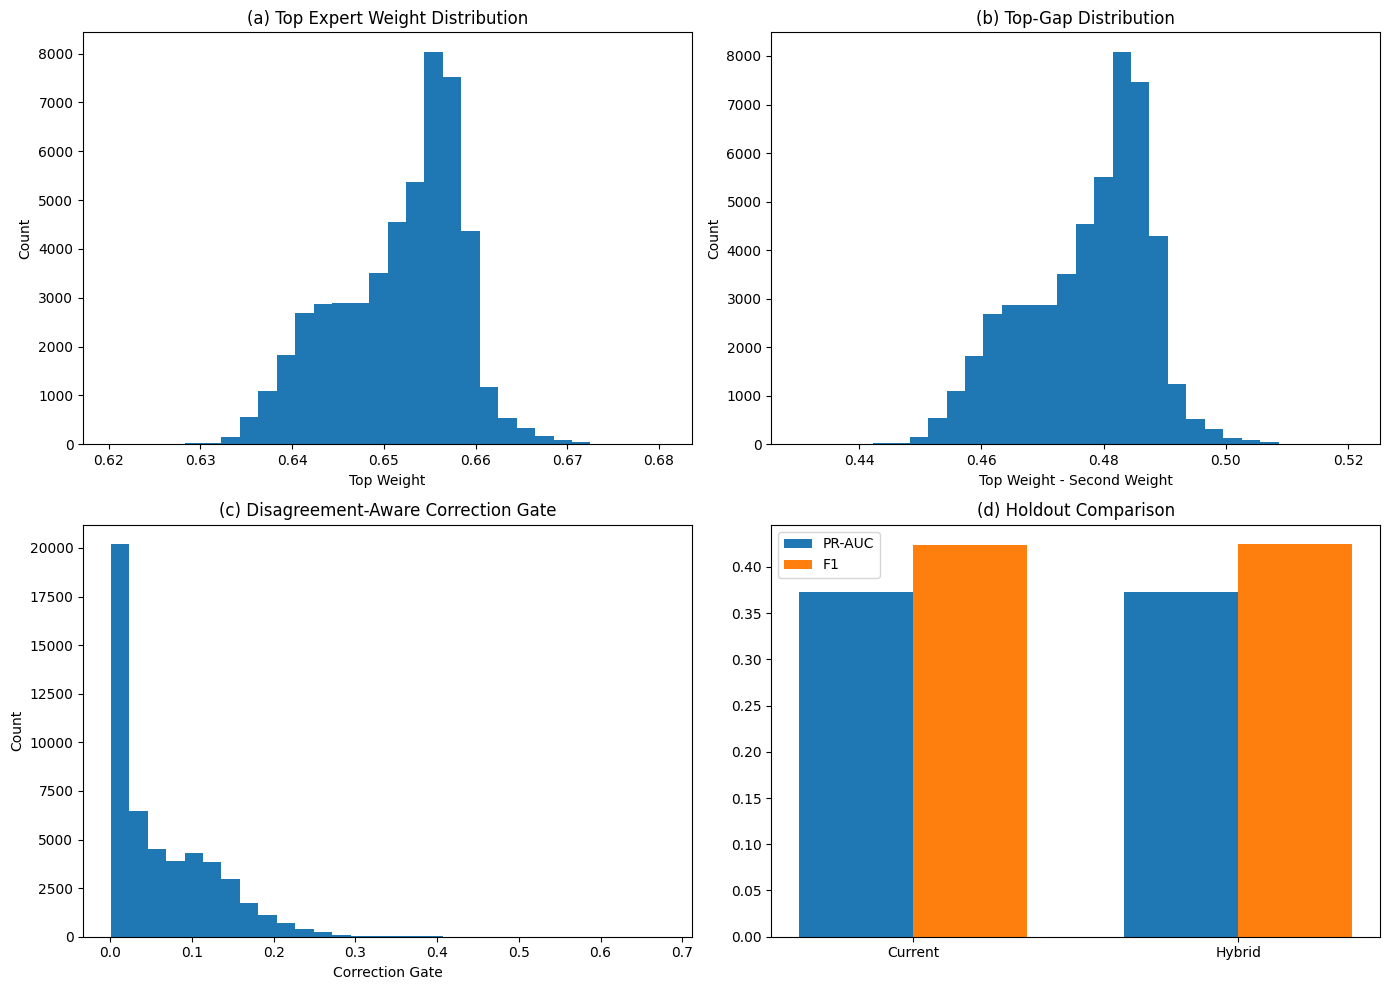


Saved:
- hybrid_attention_sharpened_sweep_results.csv
- hybrid_attention_sharpened_dev_validation_comparison.csv
- hybrid_attention_sharpened_dev_fairness_comparison.csv
- hybrid_attention_sharpened_holdout_comparison.csv
- hybrid_attention_sharpened_holdout_fairness_comparison.csv
- hybrid_attention_sharpened_summary.csv
- hybrid_attention_sharpened_dev_predictions.csv
- hybrid_attention_sharpened_holdout_predictions.csv
- hybrid_attention_sharpened_holdout_diagnostics.csv
- hybrid_attention_sharpened_gate_2x2.(png/pdf)
- hybrid_attention_sharpened_metadata.json


In [46]:
# ============================================================
# HYBRID MODEL:
# Attention-informed sharpened gate + stronger routing + FN-risk
# ============================================================

import os
import gc
import json
import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "TAB_DIR", "PRED_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

USE_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== Hybrid Attention-Informed Sharpened Gate =====")
print("CUDA available:", USE_GPU)
print("Device:", DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
HYB_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
HYB_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]
HYB_CONTEXT_COLS = [c for c in HYB_CONTEXT_COLS if c in X_dev_df.columns]

HYB_TOKEN_DIM = 32
HYB_NHEAD = 4
HYB_NUM_LAYERS = 1
HYB_FF_DIM = 64
HYB_HIDDEN = 64
HYB_DROPOUT = 0.10

HYB_LR = 1e-3
HYB_WD = 1e-5
HYB_EPOCHS = 28
HYB_BATCH = 2048
HYB_PATIENCE = 6

HYB_TEMP_START = 1.0
HYB_TEMP_END_GRID = [0.35, 0.30, 0.25]

HYB_LAMBDA_SPEC = 0.10
HYB_LAMBDA_GAP_GRID = [0.05, 0.08, 0.12]
HYB_LAMBDA_FNRISK = 0.08
HYB_LAMBDA_DELTA_L2 = 0.001

HYB_MAX_POS_DELTA_GRID = [0.03, 0.05, 0.08]
HYB_BASE_THRESHOLD = 0.20
HYB_FNRISK_UNCERT_Q = 0.85

# disagreement-aware correction
HYB_DISAGREE_ALPHA = 0.60
HYB_FNRISK_ALPHA = 0.40

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_hyb(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_entropy_binary_hyb(p):
    p = clip_probs_hyb(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def best_f1_threshold_hyb(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_hyb(prob)
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_hyb(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_hyb(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_sex_gap_hyb(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_hyb(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female": sex_arr == 0, "Male": sex_arr == 1}.items():
        yt = y_true[mask]
        pp = prob[mask]
        yh = (pp >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        ids = np.digitize(pp, bins, right=False) - 1
        ids = np.clip(ids, 0, len(bins) - 2)
        ece = 0.0
        for i in range(len(bins) - 1):
            m = ids == i
            if m.sum() == 0:
                continue
            acc = yt[m].mean()
            conf = pp[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(yt))

        out[name] = {
            "Recall": recall_score(yt, yh, zero_division=0),
            "Precision": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0),
            "MCC": matthews_corrcoef(yt, yh) if len(np.unique(yh)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": yh.mean(),
        }

    return {
        "Recall_gap": abs(out["Male"]["Recall"] - out["Female"]["Recall"]),
        "Precision_gap": abs(out["Male"]["Precision"] - out["Female"]["Precision"]),
        "F1_gap": abs(out["Male"]["F1"] - out["Female"]["F1"]),
        "MCC_gap": abs(out["Male"]["MCC"] - out["Female"]["MCC"]),
        "ECE_gap": abs(out["Male"]["ECE"] - out["Female"]["ECE"]),
        "PredPosRate_gap": abs(out["Male"]["PredPosRate"] - out["Female"]["PredPosRate"]),
    }

def fit_isotonic_hyb(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_hyb(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_hyb(calibrator, p_raw):
    return clip_probs_hyb(calibrator.predict(clip_probs_hyb(p_raw)))

def build_soft_specialization_targets_hyb(y_true, pred_df, temperature=5.0):
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    losses = []
    for c in pred_df.columns:
        p = clip_probs_hyb(pred_df[c].values)
        loss = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))
        losses.append(loss)
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return (exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)).astype(np.float32)

def maybe_load_current_main_predictions_hyb(split="DEV"):
    if split == "DEV":
        candidates = [
            PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
            PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
        ]
    else:
        candidates = [
            PRED_DIR / "final_holdout_gate_predictions.csv",
        ]
    for p in candidates:
        if p.exists():
            return pd.read_csv(p)
    return None

def build_context_array_hyb(df, cols):
    if len(cols) == 0:
        return np.zeros((len(df), 1), dtype=np.float32)
    return df[cols].values.astype(np.float32)

def build_expert_token_features_hyb(pred_df, context_df):
    cols = list(pred_df.columns)
    P = pred_df.values.astype(np.float32)
    mean_p = P.mean(axis=1, keepdims=True)
    std_p = P.std(axis=1, keepdims=True)
    min_p = P.min(axis=1, keepdims=True)
    max_p = P.max(axis=1, keepdims=True)

    ctx = build_context_array_hyb(context_df, HYB_CONTEXT_COLS)
    tokens = []

    for i, c in enumerate(cols):
        p_i = P[:, [i]]
        own_minus_mean = p_i - mean_p
        own_vs_min = p_i - min_p
        own_vs_max = max_p - p_i

        pair_abs = []
        pair_signed = []
        for j in range(len(cols)):
            if j == i:
                continue
            pair_abs.append(np.abs(p_i - P[:, [j]]))
            pair_signed.append(p_i - P[:, [j]])
        pair_abs = np.concatenate(pair_abs, axis=1)
        pair_signed = np.concatenate(pair_signed, axis=1)

        token_i = np.concatenate(
            [
                p_i,
                mean_p,
                std_p,
                min_p,
                max_p,
                own_minus_mean,
                own_vs_min,
                own_vs_max,
                pair_abs,
                pair_signed,
                ctx
            ],
            axis=1
        )
        tokens.append(token_i)

    token_tensor = np.stack(tokens, axis=1)
    return token_tensor.astype(np.float32)

def build_fnrisk_target_hyb(y_true, pred_df):
    y_true = np.asarray(y_true).astype(int)
    mean_p = pred_df.mean(axis=1).values
    std_p = pred_df.std(axis=1).values
    uncert_thr = np.quantile(std_p, HYB_FNRISK_UNCERT_Q)

    target = (
        (y_true == 1) &
        (
            (mean_p < (HYB_BASE_THRESHOLD + 0.08)) |
            ((mean_p < 0.35) & (std_p >= uncert_thr))
        )
    ).astype(int)

    return target

# ------------------------------------------------------------
# Prepare calibrated expert predictions
# ------------------------------------------------------------
hyb_dev_raw_df = MODULE4_OOF_MATRIX[HYB_SELECTED_EXPERTS].copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

hyb_expert_calibrators = {}
hyb_dev_cal_df = pd.DataFrame(index=hyb_dev_raw_df.index)

for e in HYB_SELECTED_EXPERTS:
    cal = fit_isotonic_hyb(y_dev_np, hyb_dev_raw_df[e].values)
    hyb_expert_calibrators[e] = cal
    hyb_dev_cal_df[e] = apply_isotonic_hyb(cal, hyb_dev_raw_df[e].values)

hold_cal_path = PRED_DIR / "final_holdout_expert_calibrated_predictions.csv"
hold_raw_path = PRED_DIR / "final_holdout_expert_raw_predictions.csv"

if hold_cal_path.exists():
    hyb_hold_cal_df = pd.read_csv(hold_cal_path)[HYB_SELECTED_EXPERTS].copy()
    print("[OK] Loaded calibrated holdout expert predictions.")
elif hold_raw_path.exists():
    hyb_hold_raw_df = pd.read_csv(hold_raw_path)[HYB_SELECTED_EXPERTS].copy()
    hyb_hold_cal_df = pd.DataFrame(index=hyb_hold_raw_df.index)
    for e in HYB_SELECTED_EXPERTS:
        hyb_hold_cal_df[e] = apply_isotonic_hyb(hyb_expert_calibrators[e], hyb_hold_raw_df[e].values)
    print("[OK] Loaded raw holdout expert predictions and calibrated them.")
else:
    raise FileNotFoundError(
        "Need one of these files in PRED_DIR:\n"
        "- final_holdout_expert_calibrated_predictions.csv\n"
        "- final_holdout_expert_raw_predictions.csv"
    )

hyb_dev_context_df = X_dev_df[HYB_CONTEXT_COLS].reset_index(drop=True).copy()
hyb_hold_context_df = X_test_df[HYB_CONTEXT_COLS].reset_index(drop=True).copy()

hyb_dev_tokens = build_expert_token_features_hyb(hyb_dev_cal_df, hyb_dev_context_df)
hyb_hold_tokens = build_expert_token_features_hyb(hyb_hold_cal_df, hyb_hold_context_df)

if len(HYB_CONTEXT_COLS) > 0:
    hyb_dev_ctx = hyb_dev_context_df.values.astype(np.float32)
    hyb_hold_ctx = hyb_hold_context_df.values.astype(np.float32)
else:
    hyb_dev_ctx = np.zeros((len(hyb_dev_cal_df), 1), dtype=np.float32)
    hyb_hold_ctx = np.zeros((len(hyb_hold_cal_df), 1), dtype=np.float32)

hyb_fnrisk_target_dev = build_fnrisk_target_hyb(y_dev_np, hyb_dev_cal_df)

# split dev
idx_all = np.arange(len(y_dev_np))
idx_tr, idx_val = train_test_split(
    idx_all,
    test_size=0.20,
    stratify=y_dev_np,
    random_state=42
)

hyb_tok_tr = hyb_dev_tokens[idx_tr]
hyb_tok_val = hyb_dev_tokens[idx_val]
hyb_tok_dev_full = hyb_dev_tokens

hyb_ctx_tr = hyb_dev_ctx[idx_tr]
hyb_ctx_val = hyb_dev_ctx[idx_val]
hyb_ctx_dev_full = hyb_dev_ctx

hyb_P_tr = hyb_dev_cal_df.iloc[idx_tr].values.astype(np.float32)
hyb_P_val = hyb_dev_cal_df.iloc[idx_val].values.astype(np.float32)
hyb_P_dev_full = hyb_dev_cal_df.values.astype(np.float32)
hyb_P_hold = hyb_hold_cal_df.values.astype(np.float32)

hyb_y_tr = y_dev_np[idx_tr]
hyb_y_val = y_dev_np[idx_val]

hyb_soft_tr = build_soft_specialization_targets_hyb(hyb_y_tr, hyb_dev_cal_df.iloc[idx_tr].reset_index(drop=True))
hyb_soft_val = build_soft_specialization_targets_hyb(hyb_y_val, hyb_dev_cal_df.iloc[idx_val].reset_index(drop=True))
hyb_soft_dev_full = build_soft_specialization_targets_hyb(y_dev_np, hyb_dev_cal_df)

hyb_fnrisk_tr = hyb_fnrisk_target_dev[idx_tr]
hyb_fnrisk_val = hyb_fnrisk_target_dev[idx_val]
hyb_fnrisk_dev_full = hyb_fnrisk_target_dev

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
class HybridAttentionGateDataset(torch.utils.data.Dataset):
    def __init__(self, tokens, ctx, y, P, soft_targets, fnrisk_target):
        self.tokens = torch.tensor(tokens, dtype=torch.float32)
        self.ctx = torch.tensor(ctx, dtype=torch.float32)
        self.y = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)
        self.P = torch.tensor(P, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.fnrisk_target = torch.tensor(fnrisk_target.reshape(-1, 1), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.tokens[idx],
            self.ctx[idx],
            self.y[idx],
            self.P[idx],
            self.soft_targets[idx],
            self.fnrisk_target[idx],
        )

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class HybridExpertAttentionEncoder(nn.Module):
    def __init__(self, token_in_dim, token_dim=32, nhead=4, num_layers=1, ff_dim=64, dropout=0.10):
        super().__init__()
        self.token_proj = nn.Linear(token_in_dim, token_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=token_dim,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, tokens):
        x = self.token_proj(tokens)
        z = self.encoder(x)
        return z

class HybridAttentionSharpenedGateNet(nn.Module):
    def __init__(
        self,
        token_in_dim,
        ctx_dim,
        n_experts,
        token_dim=32,
        nhead=4,
        num_layers=1,
        ff_dim=64,
        hidden=64,
        dropout=0.10,
        temperature=1.0,
        max_pos_delta=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.max_pos_delta = max_pos_delta

        self.encoder = HybridExpertAttentionEncoder(
            token_in_dim=token_in_dim,
            token_dim=token_dim,
            nhead=nhead,
            num_layers=num_layers,
            ff_dim=ff_dim,
            dropout=dropout,
        )

        self.ctx_proj = nn.Sequential(
            nn.Linear(ctx_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        comb_dim = token_dim * n_experts + hidden

        self.shared = nn.Sequential(
            nn.Linear(comb_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.gate_head = nn.Linear(hidden, n_experts)
        self.fnrisk_head = nn.Linear(hidden, 1)
        self.delta_head = nn.Linear(hidden, 1)

    def forward(self, tokens, ctx, expert_probs):
        z_tok = self.encoder(tokens)
        z_flat = z_tok.reshape(z_tok.size(0), -1)
        z_ctx = self.ctx_proj(ctx)
        h = self.shared(torch.cat([z_flat, z_ctx], dim=1))

        gate_logits = self.gate_head(h) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        fused_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        # disagreement-aware scaling from expert probabilities
        with torch.no_grad():
            std_p = torch.std(expert_probs, dim=1, keepdim=True)
        std_scale = torch.clamp(std_p / 0.20, 0.0, 1.0)

        fnrisk_prob = torch.sigmoid(self.fnrisk_head(h))
        pos_delta = self.max_pos_delta * torch.sigmoid(self.delta_head(h))

        correction_gate = HYB_DISAGREE_ALPHA * std_scale + HYB_FNRISK_ALPHA * fnrisk_prob
        correction_gate = torch.clamp(correction_gate, 0.0, 1.0)

        corrected_prob = fused_prob + correction_gate * pos_delta
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob

def top_gap_regularizer_hyb(weights):
    sorted_w, _ = torch.sort(weights, dim=1, descending=True)
    gap = sorted_w[:, 0] - sorted_w[:, 1]
    return gap.mean()

# ------------------------------------------------------------
# Train one config
# ------------------------------------------------------------
def train_one_hybrid_gate(temp_end=0.30, lambda_gap=0.08, max_pos_delta=0.05):
    train_ds = HybridAttentionGateDataset(hyb_tok_tr, hyb_ctx_tr, hyb_y_tr, hyb_P_tr, hyb_soft_tr, hyb_fnrisk_tr)
    val_ds = HybridAttentionGateDataset(hyb_tok_val, hyb_ctx_val, hyb_y_val, hyb_P_val, hyb_soft_val, hyb_fnrisk_val)

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=HYB_BATCH, shuffle=True, drop_last=False)
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=HYB_BATCH, shuffle=False, drop_last=False)

    model = HybridAttentionSharpenedGateNet(
        token_in_dim=hyb_tok_tr.shape[2],
        ctx_dim=hyb_ctx_tr.shape[1],
        n_experts=hyb_P_tr.shape[1],
        token_dim=HYB_TOKEN_DIM,
        nhead=HYB_NHEAD,
        num_layers=HYB_NUM_LAYERS,
        ff_dim=HYB_FF_DIM,
        hidden=HYB_HIDDEN,
        dropout=HYB_DROPOUT,
        temperature=HYB_TEMP_START,
        max_pos_delta=max_pos_delta,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=HYB_LR, weight_decay=HYB_WD)
    bce = nn.BCELoss()
    kl = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_score = -1e9
    best_val_pred = None
    no_improve = 0
    history = []

    for epoch in range(HYB_EPOCHS):
        frac = epoch / max(HYB_EPOCHS - 1, 1)
        cur_temp = HYB_TEMP_START + frac * (temp_end - HYB_TEMP_START)
        model.temperature = cur_temp

        model.train()
        train_losses = []

        for tokb, ctxb, yb, pb, sb, fb in train_loader:
            tokb = tokb.to(DEVICE)
            ctxb = ctxb.to(DEVICE)
            yb = yb.to(DEVICE)
            pb = pb.to(DEVICE)
            sb = sb.to(DEVICE)
            fb = fb.to(DEVICE)

            optimizer.zero_grad()

            weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob = model(tokb, ctxb, pb)

            loss_main = bce(corrected_prob, yb)
            loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_fnrisk = bce(fnrisk_prob, fb)
            loss_gap = top_gap_regularizer_hyb(weights)
            loss_delta = torch.mean(pos_delta ** 2)

            loss = (
                loss_main
                + HYB_LAMBDA_SPEC * loss_spec
                + HYB_LAMBDA_FNRISK * loss_fnrisk
                - lambda_gap * loss_gap
                + HYB_LAMBDA_DELTA_L2 * loss_delta
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_pred_list = []
        with torch.no_grad():
            for tokb, ctxb, yb, pb, sb, fb in val_loader:
                tokb = tokb.to(DEVICE)
                ctxb = ctxb.to(DEVICE)
                pb = pb.to(DEVICE)

                weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob = model(tokb, ctxb, pb)
                val_pred_list.append(corrected_prob.detach().cpu().numpy().reshape(-1))

        val_pred = np.concatenate(val_pred_list)
        thr_val, _ = best_f1_threshold_hyb(hyb_y_val, val_pred)
        met = compute_metrics_hyb(hyb_y_val, val_pred, threshold=thr_val)

        val_score = met["PR_AUC"] + 0.05 * met["Recall"] + 0.05 * met["MCC"] - 0.02 * met["ECE"]

        history.append({
            "epoch": epoch + 1,
            "temperature": cur_temp,
            "train_loss": float(np.mean(train_losses)),
            "val_PR_AUC": met["PR_AUC"],
            "val_Recall": met["Recall"],
            "val_F1": met["F1"],
            "val_MCC": met["MCC"],
            "val_ECE": met["ECE"],
            "val_threshold": thr_val,
            "val_score": val_score,
            "lambda_gap": lambda_gap,
            "max_pos_delta": max_pos_delta,
            "temp_end": temp_end,
        })

        print(
            f"[temp_end={temp_end:.2f}, lambda_gap={lambda_gap:.3f}, max_pos_delta={max_pos_delta:.3f}] "
            f"epoch={epoch+1:02d} temp={cur_temp:.3f} val_PR_AUC={met['PR_AUC']:.6f} "
            f"val_F1={met['F1']:.6f} val_ECE={met['ECE']:.6f}"
        )

        if val_score > best_val_score:
            best_val_score = val_score
            best_state = copy.deepcopy(model.state_dict())
            best_val_pred = val_pred.copy()
            best_thr = thr_val
            best_metrics = met.copy()
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= HYB_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    return {
        "model": model,
        "history_df": pd.DataFrame(history),
        "best_val_pred": best_val_pred,
        "best_thr": best_thr,
        "best_metrics": best_metrics,
        "best_score": best_val_score,
    }

# ------------------------------------------------------------
# Sweep
# ------------------------------------------------------------
hyb_sweep_rows = []
hyb_models_store = {}

for temp_end in HYB_TEMP_END_GRID:
    for lambda_gap in HYB_LAMBDA_GAP_GRID:
        for max_pos_delta in HYB_MAX_POS_DELTA_GRID:
            res = train_one_hybrid_gate(
                temp_end=temp_end,
                lambda_gap=lambda_gap,
                max_pos_delta=max_pos_delta,
            )

            key = f"temp{temp_end}_gap{lambda_gap}_delta{max_pos_delta}"
            hyb_models_store[key] = res

            row = {
                "variant": key,
                "temp_end": temp_end,
                "lambda_gap": lambda_gap,
                "max_pos_delta": max_pos_delta,
                **res["best_metrics"],
                "best_threshold": res["best_thr"],
                "score": res["best_score"],
            }
            hyb_sweep_rows.append(row)

hyb_sweep_df = pd.DataFrame(hyb_sweep_rows).sort_values(
    ["score", "PR_AUC", "Recall", "MCC"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

print("\n===== HYBRID ATTENTION-SHARPENED GATE SWEEP RESULTS =====")
display(hyb_sweep_df.head(12))

hyb_best_key = hyb_sweep_df.iloc[0]["variant"]
hyb_best_res = hyb_models_store[hyb_best_key]
print("\nBest hybrid config:", hyb_best_key)

# ------------------------------------------------------------
# DEV validation comparison
# ------------------------------------------------------------
hyb_dev_main_df = maybe_load_current_main_predictions_hyb("DEV")
if hyb_dev_main_df is not None and len(hyb_dev_main_df) == len(y_dev_np):
    hyb_dev_main_p = clip_probs_hyb(hyb_dev_main_df["pred"].values)[idx_val]
else:
    hyb_dev_main_p = clip_probs_hyb(hyb_P_val.mean(axis=1))

hyb_thr_main_val, _ = best_f1_threshold_hyb(hyb_y_val, hyb_dev_main_p)
hyb_main_val_metrics = compute_metrics_hyb(hyb_y_val, hyb_dev_main_p, threshold=hyb_thr_main_val)
hyb_model_val_metrics = hyb_best_res["best_metrics"].copy()

hyb_dev_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "DEV_VAL", **hyb_main_val_metrics},
    {"variant": "hybrid_attention_sharpened_gate", "split": "DEV_VAL", **hyb_model_val_metrics},
])

hyb_dev_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "DEV_VAL",
        **compute_sex_gap_hyb(hyb_y_val, hyb_dev_main_p, hyb_thr_main_val, X_dev_df.iloc[idx_val]["Sex"].values)
    },
    {
        "variant": "hybrid_attention_sharpened_gate",
        "split": "DEV_VAL",
        **compute_sex_gap_hyb(hyb_y_val, hyb_best_res["best_val_pred"], hyb_best_res["best_thr"], X_dev_df.iloc[idx_val]["Sex"].values)
    },
])

print("\n===== DEV VALIDATION COMPARISON =====")
display(hyb_dev_compare_df)

print("\n===== DEV VALIDATION FAIRNESS GAP COMPARISON =====")
display(hyb_dev_fair_df)

# ------------------------------------------------------------
# Refit best config on full dev
# ------------------------------------------------------------
hyb_best_temp_end = float(hyb_sweep_df.iloc[0]["temp_end"])
hyb_best_lambda_gap = float(hyb_sweep_df.iloc[0]["lambda_gap"])
hyb_best_max_pos_delta = float(hyb_sweep_df.iloc[0]["max_pos_delta"])

hyb_full_ds = HybridAttentionGateDataset(
    hyb_tok_dev_full, hyb_ctx_dev_full, y_dev_np, hyb_P_dev_full, hyb_soft_dev_full, hyb_fnrisk_dev_full
)
hyb_full_loader = torch.utils.data.DataLoader(hyb_full_ds, batch_size=HYB_BATCH, shuffle=True, drop_last=False)

hyb_best_model_full = HybridAttentionSharpenedGateNet(
    token_in_dim=hyb_tok_dev_full.shape[2],
    ctx_dim=hyb_ctx_dev_full.shape[1],
    n_experts=hyb_P_dev_full.shape[1],
    token_dim=HYB_TOKEN_DIM,
    nhead=HYB_NHEAD,
    num_layers=HYB_NUM_LAYERS,
    ff_dim=HYB_FF_DIM,
    hidden=HYB_HIDDEN,
    dropout=HYB_DROPOUT,
    temperature=HYB_TEMP_START,
    max_pos_delta=hyb_best_max_pos_delta,
).to(DEVICE)

optimizer = torch.optim.Adam(hyb_best_model_full.parameters(), lr=HYB_LR, weight_decay=HYB_WD)
bce = nn.BCELoss()
kl = nn.KLDivLoss(reduction="batchmean")

hyb_best_state_full = copy.deepcopy(hyb_best_model_full.state_dict())
hyb_best_dev_score = -1e9
no_improve = 0

for epoch in range(HYB_EPOCHS):
    frac = epoch / max(HYB_EPOCHS - 1, 1)
    cur_temp = HYB_TEMP_START + frac * (hyb_best_temp_end - HYB_TEMP_START)
    hyb_best_model_full.temperature = cur_temp

    hyb_best_model_full.train()
    for tokb, ctxb, yb, pb, sb, fb in hyb_full_loader:
        tokb = tokb.to(DEVICE)
        ctxb = ctxb.to(DEVICE)
        yb = yb.to(DEVICE)
        pb = pb.to(DEVICE)
        sb = sb.to(DEVICE)
        fb = fb.to(DEVICE)

        optimizer.zero_grad()

        weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob = hyb_best_model_full(tokb, ctxb, pb)

        loss_main = bce(corrected_prob, yb)
        loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
        loss_fnrisk = bce(fnrisk_prob, fb)
        loss_gap = top_gap_regularizer_hyb(weights)
        loss_delta = torch.mean(pos_delta ** 2)

        loss = (
            loss_main
            + HYB_LAMBDA_SPEC * loss_spec
            + HYB_LAMBDA_FNRISK * loss_fnrisk
            - hyb_best_lambda_gap * loss_gap
            + HYB_LAMBDA_DELTA_L2 * loss_delta
        )

        loss.backward()
        optimizer.step()

    hyb_best_model_full.eval()
    with torch.no_grad():
        tokb = torch.tensor(hyb_tok_dev_full, dtype=torch.float32).to(DEVICE)
        ctxb = torch.tensor(hyb_ctx_dev_full, dtype=torch.float32).to(DEVICE)
        pb = torch.tensor(hyb_P_dev_full, dtype=torch.float32).to(DEVICE)

        weights_dev, fused_dev, fnrisk_dev, delta_dev, corrgate_dev, pred_dev = hyb_best_model_full(tokb, ctxb, pb)
        hyb_pred_dev_np = pred_dev.detach().cpu().numpy().reshape(-1)

    thr_dev_full, _ = best_f1_threshold_hyb(y_dev_np, hyb_pred_dev_np)
    met_dev = compute_metrics_hyb(y_dev_np, hyb_pred_dev_np, threshold=thr_dev_full)
    dev_score = met_dev["PR_AUC"] + 0.05 * met_dev["Recall"] + 0.05 * met_dev["MCC"] - 0.02 * met_dev["ECE"]

    if dev_score > hyb_best_dev_score:
        hyb_best_dev_score = dev_score
        hyb_best_state_full = copy.deepcopy(hyb_best_model_full.state_dict())
        hyb_best_thr_dev_full = thr_dev_full
        hyb_best_pred_dev_full = hyb_pred_dev_np.copy()
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= HYB_PATIENCE:
        break

hyb_best_model_full.load_state_dict(hyb_best_state_full)
hyb_best_model_full.eval()

# ------------------------------------------------------------
# HOLDOUT evaluation
# ------------------------------------------------------------
with torch.no_grad():
    tok_hold_t = torch.tensor(hyb_hold_tokens, dtype=torch.float32).to(DEVICE)
    ctx_hold_t = torch.tensor(hyb_hold_ctx, dtype=torch.float32).to(DEVICE)
    p_hold_t = torch.tensor(hyb_P_hold, dtype=torch.float32).to(DEVICE)

    hyb_w_hold, hyb_fused_hold, hyb_fnrisk_hold, hyb_delta_hold, hyb_corrgate_hold, hyb_pred_hold = \
        hyb_best_model_full(tok_hold_t, ctx_hold_t, p_hold_t)

hyb_hold_pred_np = hyb_pred_hold.detach().cpu().numpy().reshape(-1)
hyb_hold_weights_np = hyb_w_hold.detach().cpu().numpy()
hyb_hold_fnrisk_np = hyb_fnrisk_hold.detach().cpu().numpy().reshape(-1)
hyb_hold_delta_np = hyb_delta_hold.detach().cpu().numpy().reshape(-1)
hyb_hold_corrgate_np = hyb_corrgate_hold.detach().cpu().numpy().reshape(-1)

hyb_hold_main_df = maybe_load_current_main_predictions_hyb("HOLDOUT")
if hyb_hold_main_df is not None and len(hyb_hold_main_df) == len(y_test_arr):
    hyb_hold_main_p = clip_probs_hyb(hyb_hold_main_df["pred"].values)
else:
    hyb_hold_main_p = clip_probs_hyb(hyb_P_hold.mean(axis=1))

hyb_hold_thr_main, _ = best_f1_threshold_hyb(np.asarray(y_test_arr), hyb_hold_main_p)
hyb_hold_thr_model, _ = best_f1_threshold_hyb(np.asarray(y_test_arr), hyb_hold_pred_np)

hyb_hold_main_metrics = compute_metrics_hyb(np.asarray(y_test_arr), hyb_hold_main_p, threshold=hyb_hold_thr_main)
hyb_hold_model_metrics = compute_metrics_hyb(np.asarray(y_test_arr), hyb_hold_pred_np, threshold=hyb_hold_thr_model)

hyb_hold_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "HOLDOUT", **hyb_hold_main_metrics},
    {"variant": "hybrid_attention_sharpened_gate", "split": "HOLDOUT", **hyb_hold_model_metrics},
])

hyb_hold_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "HOLDOUT",
        **compute_sex_gap_hyb(np.asarray(y_test_arr), hyb_hold_main_p, hyb_hold_thr_main, X_test_df["Sex"].values)
    },
    {
        "variant": "hybrid_attention_sharpened_gate",
        "split": "HOLDOUT",
        **compute_sex_gap_hyb(np.asarray(y_test_arr), hyb_hold_pred_np, hyb_hold_thr_model, X_test_df["Sex"].values)
    },
])

print("\n===== HOLDOUT COMPARISON =====")
display(hyb_hold_compare_df)

print("\n===== HOLDOUT FAIRNESS GAP COMPARISON =====")
display(hyb_hold_fair_df)

# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------
hyb_diag_df = pd.DataFrame({
    "row_idx_holdout": np.arange(len(hyb_hold_pred_np)),
    "y_true": np.asarray(y_test_arr).astype(int),
    "pred": hyb_hold_pred_np,
    "fnrisk_prob": hyb_hold_fnrisk_np,
    "pos_delta": hyb_hold_delta_np,
    "correction_gate": hyb_hold_corrgate_np,
    "w_HistGradientBoosting": hyb_hold_weights_np[:, 0],
    "w_DeepFM": hyb_hold_weights_np[:, 1],
    "w_MLP_BCE": hyb_hold_weights_np[:, 2],
})

hyb_diag_df["top_weight"] = hyb_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].max(axis=1)
hyb_sorted_w = np.sort(hyb_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, axis=1)
hyb_diag_df["top_gap"] = hyb_sorted_w[:, -1] - hyb_sorted_w[:, -2]
hyb_diag_df["gate_entropy"] = -np.sum(
    np.clip(hyb_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, 1e-8, 1.0) *
    np.log(np.clip(hyb_diag_df[["w_HistGradientBoosting", "w_DeepFM", "w_MLP_BCE"]].values, 1e-8, 1.0)),
    axis=1
)

hyb_gate_summary_df = pd.DataFrame([{
    "Split": "HOLDOUT",
    "MeanTopWeight": float(hyb_diag_df["top_weight"].mean()),
    "MeanTopGap": float(hyb_diag_df["top_gap"].mean()),
    "MeanEntropy": float(hyb_diag_df["gate_entropy"].mean()),
    "MeanFnRiskProb": float(hyb_diag_df["fnrisk_prob"].mean()),
    "MeanPosDelta": float(hyb_diag_df["pos_delta"].mean()),
    "MeanCorrectionGate": float(hyb_diag_df["correction_gate"].mean()),
}])

print("\n===== HYBRID GATE SUMMARY =====")
display(hyb_gate_summary_df)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
hyb_sweep_df.to_csv(TAB_DIR / "hybrid_attention_sharpened_sweep_results.csv", index=False)
hyb_dev_compare_df.to_csv(TAB_DIR / "hybrid_attention_sharpened_dev_validation_comparison.csv", index=False)
hyb_dev_fair_df.to_csv(TAB_DIR / "hybrid_attention_sharpened_dev_fairness_comparison.csv", index=False)
hyb_hold_compare_df.to_csv(TAB_DIR / "hybrid_attention_sharpened_holdout_comparison.csv", index=False)
hyb_hold_fair_df.to_csv(TAB_DIR / "hybrid_attention_sharpened_holdout_fairness_comparison.csv", index=False)
hyb_gate_summary_df.to_csv(TAB_DIR / "hybrid_attention_sharpened_summary.csv", index=False)

hyb_diag_df.to_csv(PRED_DIR / "hybrid_attention_sharpened_holdout_diagnostics.csv", index=False)
pd.DataFrame({
    "row_idx_dev": np.arange(len(hyb_best_pred_dev_full)),
    "y_true": y_dev_np,
    "pred": hyb_best_pred_dev_full,
}).to_csv(PRED_DIR / "hybrid_attention_sharpened_dev_predictions.csv", index=False)
pd.DataFrame({
    "row_idx_holdout": np.arange(len(hyb_hold_pred_np)),
    "y_true": np.asarray(y_test_arr).astype(int),
    "pred": hyb_hold_pred_np,
}).to_csv(PRED_DIR / "hybrid_attention_sharpened_holdout_predictions.csv", index=False)

# ------------------------------------------------------------
# Figures
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(hyb_diag_df["top_weight"].values, bins=30)
axes[0, 0].set_title("(a) Top Expert Weight Distribution")
axes[0, 0].set_xlabel("Top Weight")
axes[0, 0].set_ylabel("Count")

axes[0, 1].hist(hyb_diag_df["top_gap"].values, bins=30)
axes[0, 1].set_title("(b) Top-Gap Distribution")
axes[0, 1].set_xlabel("Top Weight - Second Weight")
axes[0, 1].set_ylabel("Count")

axes[1, 0].hist(hyb_diag_df["correction_gate"].values, bins=30)
axes[1, 0].set_title("(c) Disagreement-Aware Correction Gate")
axes[1, 0].set_xlabel("Correction Gate")
axes[1, 0].set_ylabel("Count")

names = ["Current", "Hybrid"]
x = np.arange(2)
w = 0.35
axes[1, 1].bar(x - w/2, [hyb_hold_main_metrics["PR_AUC"], hyb_hold_model_metrics["PR_AUC"]], width=w, label="PR-AUC")
axes[1, 1].bar(x + w/2, [hyb_hold_main_metrics["F1"], hyb_hold_model_metrics["F1"]], width=w, label="F1")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(names)
axes[1, 1].set_title("(d) Holdout Comparison")
axes[1, 1].legend()

plt.tight_layout()

fig_path = FIG_DIR / "hybrid_attention_sharpened_gate_2x2"
plt.savefig(fig_path.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.savefig(fig_path.with_suffix(".pdf"), dpi=400, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "selected_experts": HYB_SELECTED_EXPERTS,
    "context_cols": HYB_CONTEXT_COLS,
    "best_variant": hyb_best_key,
    "best_temp_end": float(hyb_sweep_df.iloc[0]["temp_end"]),
    "best_lambda_gap": float(hyb_sweep_df.iloc[0]["lambda_gap"]),
    "best_max_pos_delta": float(hyb_sweep_df.iloc[0]["max_pos_delta"]),
    "token_dim": HYB_TOKEN_DIM,
    "nhead": HYB_NHEAD,
    "num_layers": HYB_NUM_LAYERS,
    "base_threshold": HYB_BASE_THRESHOLD,
    "notes": "Hybrid model combining cross-expert attention, sharpened routing, top-gap regularization, FN-risk auxiliary head, and disagreement-aware bounded positive correction."
}
with open(LOG_DIR / "hybrid_attention_sharpened_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print("- hybrid_attention_sharpened_sweep_results.csv")
print("- hybrid_attention_sharpened_dev_validation_comparison.csv")
print("- hybrid_attention_sharpened_dev_fairness_comparison.csv")
print("- hybrid_attention_sharpened_holdout_comparison.csv")
print("- hybrid_attention_sharpened_holdout_fairness_comparison.csv")
print("- hybrid_attention_sharpened_summary.csv")
print("- hybrid_attention_sharpened_dev_predictions.csv")
print("- hybrid_attention_sharpened_holdout_predictions.csv")
print("- hybrid_attention_sharpened_holdout_diagnostics.csv")
print("- hybrid_attention_sharpened_gate_2x2.(png/pdf)")
print("- hybrid_attention_sharpened_metadata.json")

In [ ]:
# ============================================================
# HARD-CASE WEIGHTED + FOCAL-LOSS + ATTENTION GATE
# ============================================================

import os
import gc
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "MODULE4_OOF_MATRIX",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "TAB_DIR", "PRED_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

USE_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== Hard-case weighted + focal-loss + attention gate =====")
print("CUDA available:", USE_GPU)
print("Device:", DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
HFW_SELECTED_EXPERTS = ["HistGradientBoosting", "DeepFM", "MLP_BCE"]
HFW_CONTEXT_COLS = [
    "Sex", "Age", "GenHlth", "Diabetes", "DiffWalk", "BMI",
    "HighBP", "Stroke", "PhysActivity", "HighChol"
]
HFW_CONTEXT_COLS = [c for c in HFW_CONTEXT_COLS if c in X_dev_df.columns]

HFW_TOKEN_DIM = 32
HFW_NHEAD = 4
HFW_NUM_LAYERS = 1
HFW_FF_DIM = 64
HFW_HIDDEN = 64
HFW_DROPOUT = 0.10

HFW_LR = 1e-3
HFW_WD = 1e-5
HFW_EPOCHS = 24
HFW_BATCH = 2048
HFW_PATIENCE = 5

HFW_TEMP_START = 1.0
HFW_TEMP_END_GRID = [0.45, 0.35]

HFW_LAMBDA_SPEC = 0.10
HFW_LAMBDA_FNRISK = 0.08
HFW_LAMBDA_DELTA_L2 = 0.001
HFW_LAMBDA_GAP_GRID = [0.00, 0.02]

HFW_MAX_POS_DELTA_GRID = [0.03, 0.05, 0.08]
HFW_BASE_THRESHOLD = 0.20
HFW_FNRISK_UNCERT_Q = 0.85

# focal
HFW_FOCAL_ALPHA = 0.75
HFW_FOCAL_GAMMA = 2.0

# hard-case weighting
HFW_HARD_ALPHA = 2.0          # uncertainty contribution
HFW_FN_ALPHA = 3.0            # FN-risk contribution
HFW_POS_ALPHA = 1.0           # positive class contribution
HFW_NEAR_THR_ALPHA = 1.0      # near-threshold contribution

# disagreement-aware correction
HFW_DISAGREE_ALPHA = 0.60
HFW_FNRISK_ALPHA = 0.40

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs_hfw(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def best_f1_threshold_hfw(y_true, prob, grid=None):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_hfw(prob)
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)

    best_thr = 0.50
    best_f1 = -1.0
    for thr in grid:
        y_hat = (prob >= thr).astype(int)
        f1 = f1_score(y_true, y_hat, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def compute_metrics_hfw(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = clip_probs_hfw(prob)
    y_hat = (prob >= threshold).astype(int)

    bins = np.linspace(0.0, 1.0, 16)
    bin_ids = np.digitize(prob, bins, right=False) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)

    ece = 0.0
    for i in range(len(bins) - 1):
        m = bin_ids == i
        if m.sum() == 0:
            continue
        acc = float(np.mean(y_true[m]))
        conf = float(np.mean(prob[m]))
        ece += abs(acc - conf) * (m.sum() / len(y_true))

    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "NLL": float(log_loss(y_true, prob)),
        "ECE": float(ece),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(prob)),
        "N": int(len(y_true)),
    }

def compute_sex_gap_hfw(y_true, prob, thr, sex_arr):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_hfw(prob)
    sex_arr = np.asarray(sex_arr).astype(int)

    out = {}
    for name, mask in {"Female": sex_arr == 0, "Male": sex_arr == 1}.items():
        yt = y_true[mask]
        pp = prob[mask]
        yh = (pp >= thr).astype(int)

        bins = np.linspace(0.0, 1.0, 16)
        ids = np.digitize(pp, bins, right=False) - 1
        ids = np.clip(ids, 0, len(bins) - 2)

        ece = 0.0
        for i in range(len(bins) - 1):
            m = ids == i
            if m.sum() == 0:
                continue
            acc = yt[m].mean()
            conf = pp[m].mean()
            ece += abs(acc - conf) * (m.sum() / len(yt))

        out[name] = {
            "Recall": recall_score(yt, yh, zero_division=0),
            "Precision": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0),
            "MCC": matthews_corrcoef(yt, yh) if len(np.unique(yh)) > 1 else 0.0,
            "ECE": ece,
            "PredPosRate": yh.mean(),
        }

    return {
        "Recall_gap": abs(out["Male"]["Recall"] - out["Female"]["Recall"]),
        "Precision_gap": abs(out["Male"]["Precision"] - out["Female"]["Precision"]),
        "F1_gap": abs(out["Male"]["F1"] - out["Female"]["F1"]),
        "MCC_gap": abs(out["Male"]["MCC"] - out["Female"]["MCC"]),
        "ECE_gap": abs(out["Male"]["ECE"] - out["Female"]["ECE"]),
        "PredPosRate_gap": abs(out["Male"]["PredPosRate"] - out["Female"]["PredPosRate"]),
    }

def fit_isotonic_hfw(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(clip_probs_hfw(p_raw), np.asarray(y_true).astype(int))
    return iso

def apply_isotonic_hfw(calibrator, p_raw):
    return clip_probs_hfw(calibrator.predict(clip_probs_hfw(p_raw)))

def build_soft_specialization_targets_hfw(y_true, pred_df, temperature=5.0):
    y_true = np.asarray(y_true).astype(float).reshape(-1)
    losses = []
    for c in pred_df.columns:
        p = clip_probs_hfw(pred_df[c].values)
        loss = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))
        losses.append(loss)
    L = np.vstack(losses).T
    scores = -temperature * L
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return (exp_scores / (exp_scores.sum(axis=1, keepdims=True) + 1e-12)).astype(np.float32)

def maybe_load_current_main_predictions_hfw(split="DEV"):
    if split == "DEV":
        candidates = [
            PRED_DIR / "tech2_cal_lambda_0.00_dev_predictions.csv",
            PRED_DIR / "light_robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "robfair_baseline_ranked_residual_dev_predictions.csv",
            PRED_DIR / "tech1_global_gate_ranked_residual_dev_predictions.csv",
        ]
    else:
        candidates = [
            PRED_DIR / "final_holdout_gate_predictions.csv",
        ]
    for p in candidates:
        if p.exists():
            return pd.read_csv(p)
    return None

def build_context_array_hfw(df, cols):
    if len(cols) == 0:
        return np.zeros((len(df), 1), dtype=np.float32)
    return df[cols].values.astype(np.float32)

def build_expert_token_features_hfw(pred_df, context_df):
    cols = list(pred_df.columns)
    P = pred_df.values.astype(np.float32)
    mean_p = P.mean(axis=1, keepdims=True)
    std_p = P.std(axis=1, keepdims=True)
    min_p = P.min(axis=1, keepdims=True)
    max_p = P.max(axis=1, keepdims=True)

    ctx = build_context_array_hfw(context_df, HFW_CONTEXT_COLS)
    tokens = []

    for i, c in enumerate(cols):
        p_i = P[:, [i]]
        own_minus_mean = p_i - mean_p
        own_vs_min = p_i - min_p
        own_vs_max = max_p - p_i

        pair_abs = []
        pair_signed = []
        for j in range(len(cols)):
            if j == i:
                continue
            pair_abs.append(np.abs(p_i - P[:, [j]]))
            pair_signed.append(p_i - P[:, [j]])
        pair_abs = np.concatenate(pair_abs, axis=1)
        pair_signed = np.concatenate(pair_signed, axis=1)

        token_i = np.concatenate(
            [
                p_i, mean_p, std_p, min_p, max_p,
                own_minus_mean, own_vs_min, own_vs_max,
                pair_abs, pair_signed, ctx
            ],
            axis=1
        )
        tokens.append(token_i)

    return np.stack(tokens, axis=1).astype(np.float32)

def build_fnrisk_target_hfw(y_true, pred_df):
    y_true = np.asarray(y_true).astype(int)
    mean_p = pred_df.mean(axis=1).values
    std_p = pred_df.std(axis=1).values
    uncert_thr = np.quantile(std_p, HFW_FNRISK_UNCERT_Q)

    return (
        (y_true == 1) &
        (
            (mean_p < (HFW_BASE_THRESHOLD + 0.08)) |
            ((mean_p < 0.35) & (std_p >= uncert_thr))
        )
    ).astype(int)

def build_hard_case_weights_hfw(y_true, pred_df, fnrisk_target):
    y_true = np.asarray(y_true).astype(int)
    fnrisk_target = np.asarray(fnrisk_target).astype(int)

    mean_p = pred_df.mean(axis=1).values
    std_p = pred_df.std(axis=1).values
    std_norm = std_p / max(std_p.max(), 1e-8)
    near_thr = (np.abs(mean_p - HFW_BASE_THRESHOLD) <= 0.10).astype(float)

    w = np.ones(len(y_true), dtype=np.float32)
    w += HFW_POS_ALPHA * (y_true == 1).astype(np.float32)
    w += HFW_HARD_ALPHA * std_norm.astype(np.float32)
    w += HFW_FN_ALPHA * fnrisk_target.astype(np.float32)
    w += HFW_NEAR_THR_ALPHA * near_thr.astype(np.float32)

    return w.astype(np.float32)

# ------------------------------------------------------------
# Focal loss
# ------------------------------------------------------------
class WeightedBinaryFocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, prob, target, sample_weight=None):
        prob = torch.clamp(prob, 1e-6, 1 - 1e-6)
        target = target.float()

        pt = torch.where(target == 1, prob, 1 - prob)
        alpha_t = torch.where(target == 1, self.alpha, 1 - self.alpha)
        loss = -alpha_t * ((1 - pt) ** self.gamma) * torch.log(pt)

        if sample_weight is not None:
            loss = loss * sample_weight

        return loss.mean()

# ------------------------------------------------------------
# Prepare calibrated expert predictions
# ------------------------------------------------------------
hfw_dev_raw_df = MODULE4_OOF_MATRIX[HFW_SELECTED_EXPERTS].copy().reset_index(drop=True)
y_dev_np = np.asarray(y_dev_arr).astype(int).reshape(-1)

hfw_expert_calibrators = {}
hfw_dev_cal_df = pd.DataFrame(index=hfw_dev_raw_df.index)
for e in HFW_SELECTED_EXPERTS:
    cal = fit_isotonic_hfw(y_dev_np, hfw_dev_raw_df[e].values)
    hfw_expert_calibrators[e] = cal
    hfw_dev_cal_df[e] = apply_isotonic_hfw(cal, hfw_dev_raw_df[e].values)

hold_cal_path = PRED_DIR / "final_holdout_expert_calibrated_predictions.csv"
hold_raw_path = PRED_DIR / "final_holdout_expert_raw_predictions.csv"

if hold_cal_path.exists():
    hfw_hold_cal_df = pd.read_csv(hold_cal_path)[HFW_SELECTED_EXPERTS].copy()
    print("[OK] Loaded calibrated holdout expert predictions.")
elif hold_raw_path.exists():
    hfw_hold_raw_df = pd.read_csv(hold_raw_path)[HFW_SELECTED_EXPERTS].copy()
    hfw_hold_cal_df = pd.DataFrame(index=hfw_hold_raw_df.index)
    for e in HFW_SELECTED_EXPERTS:
        hfw_hold_cal_df[e] = apply_isotonic_hfw(hfw_expert_calibrators[e], hfw_hold_raw_df[e].values)
    print("[OK] Loaded raw holdout expert predictions and calibrated them.")
else:
    raise FileNotFoundError(
        "Need one of these files in PRED_DIR:\n"
        "- final_holdout_expert_calibrated_predictions.csv\n"
        "- final_holdout_expert_raw_predictions.csv"
    )

hfw_dev_context_df = X_dev_df[HFW_CONTEXT_COLS].reset_index(drop=True).copy()
hfw_hold_context_df = X_test_df[HFW_CONTEXT_COLS].reset_index(drop=True).copy()

hfw_dev_tokens = build_expert_token_features_hfw(hfw_dev_cal_df, hfw_dev_context_df)
hfw_hold_tokens = build_expert_token_features_hfw(hfw_hold_cal_df, hfw_hold_context_df)

if len(HFW_CONTEXT_COLS) > 0:
    hfw_dev_ctx = hfw_dev_context_df.values.astype(np.float32)
    hfw_hold_ctx = hfw_hold_context_df.values.astype(np.float32)
else:
    hfw_dev_ctx = np.zeros((len(hfw_dev_cal_df), 1), dtype=np.float32)
    hfw_hold_ctx = np.zeros((len(hfw_hold_cal_df), 1), dtype=np.float32)

hfw_fnrisk_target_dev = build_fnrisk_target_hfw(y_dev_np, hfw_dev_cal_df)
hfw_sample_weight_dev = build_hard_case_weights_hfw(y_dev_np, hfw_dev_cal_df, hfw_fnrisk_target_dev)

# split dev
idx_all = np.arange(len(y_dev_np))
idx_tr, idx_val = train_test_split(
    idx_all,
    test_size=0.20,
    stratify=y_dev_np,
    random_state=42
)

hfw_tok_tr = hfw_dev_tokens[idx_tr]
hfw_tok_val = hfw_dev_tokens[idx_val]
hfw_tok_dev_full = hfw_dev_tokens

hfw_ctx_tr = hfw_dev_ctx[idx_tr]
hfw_ctx_val = hfw_dev_ctx[idx_val]
hfw_ctx_dev_full = hfw_dev_ctx

hfw_P_tr = hfw_dev_cal_df.iloc[idx_tr].values.astype(np.float32)
hfw_P_val = hfw_dev_cal_df.iloc[idx_val].values.astype(np.float32)
hfw_P_dev_full = hfw_dev_cal_df.values.astype(np.float32)
hfw_P_hold = hfw_hold_cal_df.values.astype(np.float32)

hfw_y_tr = y_dev_np[idx_tr]
hfw_y_val = y_dev_np[idx_val]

hfw_soft_tr = build_soft_specialization_targets_hfw(hfw_y_tr, hfw_dev_cal_df.iloc[idx_tr].reset_index(drop=True))
hfw_soft_val = build_soft_specialization_targets_hfw(hfw_y_val, hfw_dev_cal_df.iloc[idx_val].reset_index(drop=True))
hfw_soft_dev_full = build_soft_specialization_targets_hfw(y_dev_np, hfw_dev_cal_df)

hfw_fnrisk_tr = hfw_fnrisk_target_dev[idx_tr]
hfw_fnrisk_val = hfw_fnrisk_target_dev[idx_val]
hfw_fnrisk_dev_full = hfw_fnrisk_target_dev

hfw_w_tr = hfw_sample_weight_dev[idx_tr]
hfw_w_val = hfw_sample_weight_dev[idx_val]
hfw_w_dev_full = hfw_sample_weight_dev

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
class HFWAttentionGateDataset(torch.utils.data.Dataset):
    def __init__(self, tokens, ctx, y, P, soft_targets, fnrisk_target, sample_weight):
        self.tokens = torch.tensor(tokens, dtype=torch.float32)
        self.ctx = torch.tensor(ctx, dtype=torch.float32)
        self.y = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)
        self.P = torch.tensor(P, dtype=torch.float32)
        self.soft_targets = torch.tensor(soft_targets, dtype=torch.float32)
        self.fnrisk_target = torch.tensor(fnrisk_target.reshape(-1, 1), dtype=torch.float32)
        self.sample_weight = torch.tensor(sample_weight.reshape(-1, 1), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.tokens[idx], self.ctx[idx], self.y[idx], self.P[idx],
            self.soft_targets[idx], self.fnrisk_target[idx], self.sample_weight[idx]
        )

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class HFWExpertAttentionEncoder(nn.Module):
    def __init__(self, token_in_dim, token_dim=32, nhead=4, num_layers=1, ff_dim=64, dropout=0.10):
        super().__init__()
        self.token_proj = nn.Linear(token_in_dim, token_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=token_dim,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, tokens):
        x = self.token_proj(tokens)
        return self.encoder(x)

class HFWAttentionGateNet(nn.Module):
    def __init__(
        self,
        token_in_dim,
        ctx_dim,
        n_experts,
        token_dim=32,
        nhead=4,
        num_layers=1,
        ff_dim=64,
        hidden=64,
        dropout=0.10,
        temperature=1.0,
        max_pos_delta=0.05,
    ):
        super().__init__()
        self.temperature = temperature
        self.max_pos_delta = max_pos_delta

        self.encoder = HFWExpertAttentionEncoder(
            token_in_dim=token_in_dim,
            token_dim=token_dim,
            nhead=nhead,
            num_layers=num_layers,
            ff_dim=ff_dim,
            dropout=dropout,
        )

        self.ctx_proj = nn.Sequential(
            nn.Linear(ctx_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        comb_dim = token_dim * n_experts + hidden
        self.shared = nn.Sequential(
            nn.Linear(comb_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.gate_head = nn.Linear(hidden, n_experts)
        self.fnrisk_head = nn.Linear(hidden, 1)
        self.delta_head = nn.Linear(hidden, 1)

    def forward(self, tokens, ctx, expert_probs):
        z_tok = self.encoder(tokens)
        z_flat = z_tok.reshape(z_tok.size(0), -1)
        z_ctx = self.ctx_proj(ctx)
        h = self.shared(torch.cat([z_flat, z_ctx], dim=1))

        gate_logits = self.gate_head(h) / self.temperature
        weights = torch.softmax(gate_logits, dim=1)

        fused_prob = torch.sum(weights * expert_probs, dim=1, keepdim=True)

        with torch.no_grad():
            std_p = torch.std(expert_probs, dim=1, keepdim=True)
        std_scale = torch.clamp(std_p / 0.20, 0.0, 1.0)

        fnrisk_prob = torch.sigmoid(self.fnrisk_head(h))
        pos_delta = self.max_pos_delta * torch.sigmoid(self.delta_head(h))

        correction_gate = HFW_DISAGREE_ALPHA * std_scale + HFW_FNRISK_ALPHA * fnrisk_prob
        correction_gate = torch.clamp(correction_gate, 0.0, 1.0)

        corrected_prob = fused_prob + correction_gate * pos_delta
        corrected_prob = torch.clamp(corrected_prob, 1e-6, 1.0 - 1e-6)

        return weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob

def top_gap_regularizer_hfw(weights):
    sorted_w, _ = torch.sort(weights, dim=1, descending=True)
    return (sorted_w[:, 0] - sorted_w[:, 1]).mean()

# ------------------------------------------------------------
# Train one config
# ------------------------------------------------------------
def train_one_hfw_attention_gate(temp_end=0.35, lambda_gap=0.02, max_pos_delta=0.05):
    train_ds = HFWAttentionGateDataset(
        hfw_tok_tr, hfw_ctx_tr, hfw_y_tr, hfw_P_tr,
        hfw_soft_tr, hfw_fnrisk_tr, hfw_w_tr
    )
    val_ds = HFWAttentionGateDataset(
        hfw_tok_val, hfw_ctx_val, hfw_y_val, hfw_P_val,
        hfw_soft_val, hfw_fnrisk_val, hfw_w_val
    )

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=HFW_BATCH, shuffle=True, drop_last=False)
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=HFW_BATCH, shuffle=False, drop_last=False)

    model = HFWAttentionGateNet(
        token_in_dim=hfw_tok_tr.shape[2],
        ctx_dim=hfw_ctx_tr.shape[1],
        n_experts=hfw_P_tr.shape[1],
        token_dim=HFW_TOKEN_DIM,
        nhead=HFW_NHEAD,
        num_layers=HFW_NUM_LAYERS,
        ff_dim=HFW_FF_DIM,
        hidden=HFW_HIDDEN,
        dropout=HFW_DROPOUT,
        temperature=HFW_TEMP_START,
        max_pos_delta=max_pos_delta,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=HFW_LR, weight_decay=HFW_WD)
    focal_loss = WeightedBinaryFocalLoss(alpha=HFW_FOCAL_ALPHA, gamma=HFW_FOCAL_GAMMA)
    bce_aux = nn.BCELoss(reduction="none")
    kl = nn.KLDivLoss(reduction="batchmean")

    best_state = copy.deepcopy(model.state_dict())
    best_val_score = -1e9
    best_val_pred = None
    no_improve = 0
    history = []

    for epoch in range(HFW_EPOCHS):
        frac = epoch / max(HFW_EPOCHS - 1, 1)
        cur_temp = HFW_TEMP_START + frac * (temp_end - HFW_TEMP_START)
        model.temperature = cur_temp

        model.train()
        train_losses = []

        for tokb, ctxb, yb, pb, sb, fb, wb in train_loader:
            tokb = tokb.to(DEVICE)
            ctxb = ctxb.to(DEVICE)
            yb = yb.to(DEVICE)
            pb = pb.to(DEVICE)
            sb = sb.to(DEVICE)
            fb = fb.to(DEVICE)
            wb = wb.to(DEVICE)

            optimizer.zero_grad()

            weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob = model(tokb, ctxb, pb)

            loss_main = focal_loss(corrected_prob, yb, sample_weight=wb)

            aux_loss = bce_aux(fnrisk_prob, fb)
            aux_loss = (aux_loss * wb).mean()

            loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
            loss_gap = top_gap_regularizer_hfw(weights)
            loss_delta = torch.mean(pos_delta ** 2)

            loss = (
                loss_main
                + HFW_LAMBDA_SPEC * loss_spec
                + HFW_LAMBDA_FNRISK * aux_loss
                - lambda_gap * loss_gap
                + HFW_LAMBDA_DELTA_L2 * loss_delta
            )

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        # validation
        model.eval()
        val_pred_list = []
        with torch.no_grad():
            for tokb, ctxb, yb, pb, sb, fb, wb in val_loader:
                tokb = tokb.to(DEVICE)
                ctxb = ctxb.to(DEVICE)
                pb = pb.to(DEVICE)

                _, _, _, _, _, corrected_prob = model(tokb, ctxb, pb)
                val_pred_list.append(corrected_prob.detach().cpu().numpy().reshape(-1))

        val_pred = np.concatenate(val_pred_list)
        thr_val, _ = best_f1_threshold_hfw(hfw_y_val, val_pred)
        met = compute_metrics_hfw(hfw_y_val, val_pred, threshold=thr_val)

        val_score = met["PR_AUC"] + 0.05 * met["Recall"] + 0.05 * met["MCC"] - 0.02 * met["ECE"]

        history.append({
            "epoch": epoch + 1,
            "temperature": cur_temp,
            "train_loss": float(np.mean(train_losses)),
            "val_PR_AUC": met["PR_AUC"],
            "val_Recall": met["Recall"],
            "val_F1": met["F1"],
            "val_MCC": met["MCC"],
            "val_ECE": met["ECE"],
            "val_threshold": thr_val,
            "val_score": val_score,
            "lambda_gap": lambda_gap,
            "max_pos_delta": max_pos_delta,
            "temp_end": temp_end,
        })

        print(
            f"[temp_end={temp_end:.2f}, lambda_gap={lambda_gap:.3f}, max_pos_delta={max_pos_delta:.3f}] "
            f"epoch={epoch+1:02d} temp={cur_temp:.3f} val_PR_AUC={met['PR_AUC']:.6f} "
            f"val_F1={met['F1']:.6f} val_ECE={met['ECE']:.6f}"
        )

        if val_score > best_val_score:
            best_val_score = val_score
            best_state = copy.deepcopy(model.state_dict())
            best_val_pred = val_pred.copy()
            best_thr = thr_val
            best_metrics = met.copy()
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= HFW_PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_state)
    model.eval()

    return {
        "model": model,
        "history_df": pd.DataFrame(history),
        "best_val_pred": best_val_pred,
        "best_thr": best_thr,
        "best_metrics": best_metrics,
        "best_score": best_val_score,
    }

# ------------------------------------------------------------
# Sweep
# ------------------------------------------------------------
hfw_sweep_rows = []
hfw_models_store = {}

for temp_end in HFW_TEMP_END_GRID:
    for lambda_gap in HFW_LAMBDA_GAP_GRID:
        for max_pos_delta in HFW_MAX_POS_DELTA_GRID:
            res = train_one_hfw_attention_gate(
                temp_end=temp_end,
                lambda_gap=lambda_gap,
                max_pos_delta=max_pos_delta,
            )

            key = f"temp{temp_end}_gap{lambda_gap}_delta{max_pos_delta}"
            hfw_models_store[key] = res

            row = {
                "variant": key,
                "temp_end": temp_end,
                "lambda_gap": lambda_gap,
                "max_pos_delta": max_pos_delta,
                **res["best_metrics"],
                "best_threshold": res["best_thr"],
                "score": res["best_score"],
            }
            hfw_sweep_rows.append(row)

hfw_sweep_df = pd.DataFrame(hfw_sweep_rows).sort_values(
    ["score", "PR_AUC", "Recall", "MCC"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

print("\n===== HFW + FOCAL + ATTENTION SWEEP RESULTS =====")
display(hfw_sweep_df.head(12))

hfw_best_key = hfw_sweep_df.iloc[0]["variant"]
hfw_best_res = hfw_models_store[hfw_best_key]
print("\nBest HFW config:", hfw_best_key)

# ------------------------------------------------------------
# DEV validation comparison
# ------------------------------------------------------------
hfw_dev_main_df = maybe_load_current_main_predictions_hfw("DEV")
if hfw_dev_main_df is not None and len(hfw_dev_main_df) == len(y_dev_np):
    hfw_dev_main_p = clip_probs_hfw(hfw_dev_main_df["pred"].values)[idx_val]
else:
    hfw_dev_main_p = clip_probs_hfw(hfw_P_val.mean(axis=1))

hfw_thr_main_val, _ = best_f1_threshold_hfw(hfw_y_val, hfw_dev_main_p)
hfw_main_val_metrics = compute_metrics_hfw(hfw_y_val, hfw_dev_main_p, threshold=hfw_thr_main_val)
hfw_model_val_metrics = hfw_best_res["best_metrics"].copy()

hfw_dev_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "DEV_VAL", **hfw_main_val_metrics},
    {"variant": "hardcase_focal_attention_gate", "split": "DEV_VAL", **hfw_model_val_metrics},
])

hfw_dev_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "DEV_VAL",
        **compute_sex_gap_hfw(hfw_y_val, hfw_dev_main_p, hfw_thr_main_val, X_dev_df.iloc[idx_val]["Sex"].values)
    },
    {
        "variant": "hardcase_focal_attention_gate",
        "split": "DEV_VAL",
        **compute_sex_gap_hfw(hfw_y_val, hfw_best_res["best_val_pred"], hfw_best_res["best_thr"], X_dev_df.iloc[idx_val]["Sex"].values)
    },
])

print("\n===== DEV VALIDATION COMPARISON =====")
display(hfw_dev_compare_df)

print("\n===== DEV VALIDATION FAIRNESS GAP COMPARISON =====")
display(hfw_dev_fair_df)

# ------------------------------------------------------------
# Refit best config on full dev
# ------------------------------------------------------------
hfw_best_temp_end = float(hfw_sweep_df.iloc[0]["temp_end"])
hfw_best_lambda_gap = float(hfw_sweep_df.iloc[0]["lambda_gap"])
hfw_best_max_pos_delta = float(hfw_sweep_df.iloc[0]["max_pos_delta"])

hfw_full_ds = HFWAttentionGateDataset(
    hfw_tok_dev_full, hfw_ctx_dev_full, y_dev_np, hfw_P_dev_full,
    hfw_soft_dev_full, hfw_fnrisk_dev_full, hfw_w_dev_full
)
hfw_full_loader = torch.utils.data.DataLoader(hfw_full_ds, batch_size=HFW_BATCH, shuffle=True, drop_last=False)

hfw_best_model_full = HFWAttentionGateNet(
    token_in_dim=hfw_tok_dev_full.shape[2],
    ctx_dim=hfw_ctx_dev_full.shape[1],
    n_experts=hfw_P_dev_full.shape[1],
    token_dim=HFW_TOKEN_DIM,
    nhead=HFW_NHEAD,
    num_layers=HFW_NUM_LAYERS,
    ff_dim=HFW_FF_DIM,
    hidden=HFW_HIDDEN,
    dropout=HFW_DROPOUT,
    temperature=HFW_TEMP_START,
    max_pos_delta=hfw_best_max_pos_delta,
).to(DEVICE)

optimizer = torch.optim.Adam(hfw_best_model_full.parameters(), lr=HFW_LR, weight_decay=HFW_WD)
focal_loss = WeightedBinaryFocalLoss(alpha=HFW_FOCAL_ALPHA, gamma=HFW_FOCAL_GAMMA)
bce_aux = nn.BCELoss(reduction="none")
kl = nn.KLDivLoss(reduction="batchmean")

hfw_best_state_full = copy.deepcopy(hfw_best_model_full.state_dict())
hfw_best_dev_score = -1e9
no_improve = 0

for epoch in range(HFW_EPOCHS):
    frac = epoch / max(HFW_EPOCHS - 1, 1)
    cur_temp = HFW_TEMP_START + frac * (hfw_best_temp_end - HFW_TEMP_START)
    hfw_best_model_full.temperature = cur_temp

    hfw_best_model_full.train()
    for tokb, ctxb, yb, pb, sb, fb, wb in hfw_full_loader:
        tokb = tokb.to(DEVICE)
        ctxb = ctxb.to(DEVICE)
        yb = yb.to(DEVICE)
        pb = pb.to(DEVICE)
        sb = sb.to(DEVICE)
        fb = fb.to(DEVICE)
        wb = wb.to(DEVICE)

        optimizer.zero_grad()

        weights, fused_prob, fnrisk_prob, pos_delta, correction_gate, corrected_prob = hfw_best_model_full(tokb, ctxb, pb)

        loss_main = focal_loss(corrected_prob, yb, sample_weight=wb)
        aux_loss = (bce_aux(fnrisk_prob, fb) * wb).mean()
        loss_spec = kl(torch.log(torch.clamp(weights, 1e-8, 1.0)), sb)
        loss_gap = top_gap_regularizer_hfw(weights)
        loss_delta = torch.mean(pos_delta ** 2)

        loss = (
            loss_main
            + HFW_LAMBDA_SPEC * loss_spec
            + HFW_LAMBDA_FNRISK * aux_loss
            - hfw_best_lambda_gap * loss_gap
            + HFW_LAMBDA_DELTA_L2 * loss_delta
        )

        loss.backward()
        optimizer.step()

    hfw_best_model_full.eval()
    with torch.no_grad():
        tokb = torch.tensor(hfw_tok_dev_full, dtype=torch.float32).to(DEVICE)
        ctxb = torch.tensor(hfw_ctx_dev_full, dtype=torch.float32).to(DEVICE)
        pb = torch.tensor(hfw_P_dev_full, dtype=torch.float32).to(DEVICE)

        _, _, _, _, _, pred_dev = hfw_best_model_full(tokb, ctxb, pb)
        hfw_pred_dev_np = pred_dev.detach().cpu().numpy().reshape(-1)

    thr_dev_full, _ = best_f1_threshold_hfw(y_dev_np, hfw_pred_dev_np)
    met_dev = compute_metrics_hfw(y_dev_np, hfw_pred_dev_np, threshold=thr_dev_full)
    dev_score = met_dev["PR_AUC"] + 0.05 * met_dev["Recall"] + 0.05 * met_dev["MCC"] - 0.02 * met_dev["ECE"]

    if dev_score > hfw_best_dev_score:
        hfw_best_dev_score = dev_score
        hfw_best_state_full = copy.deepcopy(hfw_best_model_full.state_dict())
        hfw_best_thr_dev_full = thr_dev_full
        hfw_best_pred_dev_full = hfw_pred_dev_np.copy()
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= HFW_PATIENCE:
        break

hfw_best_model_full.load_state_dict(hfw_best_state_full)
hfw_best_model_full.eval()

# ------------------------------------------------------------
# HOLDOUT evaluation
# ------------------------------------------------------------
with torch.no_grad():
    tok_hold_t = torch.tensor(hfw_hold_tokens, dtype=torch.float32).to(DEVICE)
    ctx_hold_t = torch.tensor(hfw_hold_ctx, dtype=torch.float32).to(DEVICE)
    p_hold_t = torch.tensor(hfw_P_hold, dtype=torch.float32).to(DEVICE)

    hfw_w_hold, hfw_fused_hold, hfw_fnrisk_hold, hfw_delta_hold, hfw_corrgate_hold, hfw_pred_hold = \
        hfw_best_model_full(tok_hold_t, ctx_hold_t, p_hold_t)

hfw_hold_pred_np = hfw_pred_hold.detach().cpu().numpy().reshape(-1)
hfw_hold_weights_np = hfw_w_hold.detach().cpu().numpy()
hfw_hold_fnrisk_np = hfw_fnrisk_hold.detach().cpu().numpy().reshape(-1)
hfw_hold_delta_np = hfw_delta_hold.detach().cpu().numpy().reshape(-1)
hfw_hold_corrgate_np = hfw_corrgate_hold.detach().cpu().numpy().reshape(-1)

hfw_hold_main_df = maybe_load_current_main_predictions_hfw("HOLDOUT")
if hfw_hold_main_df is not None and len(hfw_hold_main_df) == len(y_test_arr):
    hfw_hold_main_p = clip_probs_hfw(hfw_hold_main_df["pred"].values)
else:
    hfw_hold_main_p = clip_probs_hfw(hfw_P_hold.mean(axis=1))

hfw_hold_thr_main, _ = best_f1_threshold_hfw(np.asarray(y_test_arr), hfw_hold_main_p)
hfw_hold_thr_model, _ = best_f1_threshold_hfw(np.asarray(y_test_arr), hfw_hold_pred_np)

hfw_hold_main_metrics = compute_metrics_hfw(np.asarray(y_test_arr), hfw_hold_main_p, threshold=hfw_hold_thr_main)
hfw_hold_model_metrics = compute_metrics_hfw(np.asarray(y_test_arr), hfw_hold_pred_np, threshold=hfw_hold_thr_model)

hfw_hold_compare_df = pd.DataFrame([
    {"variant": "current_main_model", "split": "HOLDOUT", **hfw_hold_main_metrics},
    {"variant": "hardcase_focal_attention_gate", "split": "HOLDOUT", **hfw_hold_model_metrics},
])

hfw_hold_fair_df = pd.DataFrame([
    {
        "variant": "current_main_model",
        "split": "HOLDOUT",
        **compute_sex_gap_hfw(np.asarray(y_test_arr), hfw_hold_main_p, hfw_hold_thr_main, X_test_df["Sex"].values)
    },
    {
        "variant": "hardcase_focal_attention_gate",
        "split": "HOLDOUT",
        **compute_sex_gap_hfw(np.asarray(y_test_arr), hfw_hold_pred_np, hfw_hold_thr_model, X_test_df["Sex"].values)
    },
])

print("\n===== HOLDOUT COMPARISON =====")
display(hfw_hold_compare_df)

print("\n===== HOLDOUT FAIRNESS GAP COMPARISON =====")
display(hfw_hold_fair_df)

===== Hard-case weighted + focal-loss + attention gate =====
CUDA available: True
Device: cuda:0
[OK] Loaded calibrated holdout expert predictions.
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=01 temp=1.000 val_PR_AUC=0.384203 val_F1=0.427702 val_ECE=0.005306
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=02 temp=0.976 val_PR_AUC=0.384175 val_F1=0.428150 val_ECE=0.004692
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=03 temp=0.952 val_PR_AUC=0.384158 val_F1=0.427935 val_ECE=0.005046
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=04 temp=0.928 val_PR_AUC=0.384118 val_F1=0.428148 val_ECE=0.005540
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=05 temp=0.904 val_PR_AUC=0.384402 val_F1=0.427783 val_ECE=0.005041
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=06 temp=0.880 val_PR_AUC=0.384251 val_F1=0.428200 val_ECE=0.005177
[temp_end=0.45, lambda_gap=0.000, max_pos_delta=0.030] epoch=07 temp=0.857 val_PR_AU

In [6]:
# ============================================================
# Module 5 — Multi-Objective Expert Selection Engine
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "MODULE4_RESULTS", "MODULE4_RUN_DF", "MODULE4_OOF_MATRIX", "MODULE4_DIVERSITY_SUMMARY",
    "X_dev_df", "y_dev_arr",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 5: {missing}")

# ------------------------------------------------------------
# Config — expert selection policy
# ------------------------------------------------------------
MODULE5_SELECTION_CONFIG = {
    "min_pr_auc_quantile": 0.40,
    "min_roc_auc_quantile": 0.30,
    "max_experts": 6,
    "min_gain_to_add": 0.0010,
    "max_avg_corr_with_selected": 0.985,
    "w_pr_auc": 0.34,
    "w_roc_auc": 0.10,
    "w_calibration": 0.18,
    "w_fairness": 0.12,
    "w_diversity": 0.18,
    "w_stability": 0.08,
    "proxy_ensemble_type": "mean",
    "use_threshold_05_for_fairness_proxy": True,
    "min_selected_experts": 3,
}

with open(LOG_DIR / "module5_selection_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE5_SELECTION_CONFIG, f, indent=2)

print("===== Module 5 Selection Config =====")
print(json.dumps(MODULE5_SELECTION_CONFIG, indent=2))

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def minmax_scale_series(s: pd.Series, larger_is_better=True):
    s = s.astype(float)
    lo, hi = float(s.min()), float(s.max())
    if np.isclose(hi - lo, 0.0):
        out = pd.Series(np.ones(len(s)), index=s.index, dtype=float)
    else:
        out = (s - lo) / (hi - lo)
    if not larger_is_better:
        out = 1.0 - out
    return out

def compute_recall_gap_binary(y_true, prob, group_vals, threshold=0.5):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = np.asarray(prob, dtype=float).reshape(-1)
    group_vals = np.asarray(group_vals)

    y_hat = (prob >= threshold).astype(int)

    recalls = []
    for gv in sorted(pd.Series(group_vals).dropna().unique().tolist()):
        mask = group_vals == gv
        yt = y_true[mask]
        yh = y_hat[mask]

        positives = int((yt == 1).sum())
        if positives == 0:
            continue

        tp = int(((yt == 1) & (yh == 1)).sum())
        fn = int(((yt == 1) & (yh == 0)).sum())
        rec = tp / max(tp + fn, 1)
        recalls.append(rec)

    if len(recalls) <= 1:
        return np.nan
    return float(np.max(recalls) - np.min(recalls))

def compute_fold_stability_from_result(result_obj):
    fold_df = result_obj["fold_metrics_df"].copy()
    out = {
        "PR_AUC_std": float(fold_df["PR_AUC"].std(ddof=0)) if "PR_AUC" in fold_df.columns else np.nan,
        "ROC_AUC_std": float(fold_df["ROC_AUC"].std(ddof=0)) if "ROC_AUC" in fold_df.columns else np.nan,
        "Brier_std": float(fold_df["Brier"].std(ddof=0)) if "Brier" in fold_df.columns else np.nan,
        "ECE_std": float(fold_df["ECE"].std(ddof=0)) if "ECE" in fold_df.columns else np.nan,
        "F1_std": float(fold_df["F1"].std(ddof=0)) if "F1" in fold_df.columns else np.nan,
    }
    return out

def compute_candidate_pairwise_diversity(oof_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    bin_df = (oof_df[pred_cols] >= 0.5).astype(int)
    n = len(pred_cols)
    disagreement = pd.DataFrame(np.zeros((n, n)), index=pred_cols, columns=pred_cols, dtype=float)

    for i, ci in enumerate(pred_cols):
        for j, cj in enumerate(pred_cols):
            disagreement.loc[ci, cj] = float(np.mean(bin_df[ci].values != bin_df[cj].values))

    return corr, disagreement

def get_proxy_subset_prediction(oof_df: pd.DataFrame, selected_models):
    if len(selected_models) == 0:
        raise ValueError("selected_models cannot be empty")
    return oof_df[selected_models].mean(axis=1).values.astype(float)

def compute_selection_proxy_metrics(
    oof_df: pd.DataFrame,
    selected_models,
    sex_dev,
    threshold=0.5,
):
    pred = get_proxy_subset_prediction(oof_df, selected_models)
    y_true = oof_df["y_true"].values.astype(int)

    from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss
    pr_auc = float(average_precision_score(y_true, pred))
    roc_auc = float(roc_auc_score(y_true, pred))
    brier = float(brier_score_loss(y_true, pred))
    nll = float(log_loss(y_true, np.clip(pred, 1e-8, 1 - 1e-8)))
    recall_gap = float(compute_recall_gap_binary(y_true, pred, sex_dev, threshold=threshold))

    return {
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc,
        "Brier": brier,
        "NLL": nll,
        "Recall_Gap_Sex": recall_gap,
    }

# ------------------------------------------------------------
# Candidate score table
# ------------------------------------------------------------
def build_candidate_score_table():
    run_df = MODULE4_RUN_DF.copy()
    oof_df = MODULE4_OOF_MATRIX.copy()

    if "Sex" not in X_dev_df.columns:
        raise ValueError("Sex column required in X_dev_df for fairness-aware expert selection.")

    sex_dev = X_dev_df["Sex"].values.astype(int)

    fairness_rows = []
    stability_rows = []

    for model_name, res in MODULE4_RESULTS.items():
        pred = res["oof_pred"]
        fairness_gap = compute_recall_gap_binary(
            y_true=y_dev_arr,
            prob=pred,
            group_vals=sex_dev,
            threshold=0.5,
        )
        fairness_rows.append({
            "model_name": model_name,
            "Recall_Gap_Sex_proxy": fairness_gap,
        })

        st = compute_fold_stability_from_result(res)
        st["model_name"] = model_name
        stability_rows.append(st)

    fairness_df = pd.DataFrame(fairness_rows)
    stability_df = pd.DataFrame(stability_rows)

    score_df = run_df.merge(fairness_df, on="model_name", how="left")
    score_df = score_df.merge(stability_df, on="model_name", how="left")

    score_df["score_pr_auc"] = minmax_scale_series(score_df["PR_AUC"], larger_is_better=True)
    score_df["score_roc_auc"] = minmax_scale_series(score_df["ROC_AUC"], larger_is_better=True)

    score_df["score_brier"] = minmax_scale_series(score_df["Brier"], larger_is_better=False)
    score_df["score_ece"] = minmax_scale_series(score_df["ECE"], larger_is_better=False)
    score_df["score_calibration"] = 0.65 * score_df["score_brier"] + 0.35 * score_df["score_ece"]

    fill_fair = score_df["Recall_Gap_Sex_proxy"].max()
    score_df["score_fairness"] = minmax_scale_series(
        score_df["Recall_Gap_Sex_proxy"].fillna(fill_fair),
        larger_is_better=False
    )

    score_df["score_pr_stability"] = minmax_scale_series(score_df["PR_AUC_std"], larger_is_better=False)
    score_df["score_cal_stability"] = minmax_scale_series(
        0.5 * score_df["Brier_std"].fillna(0.0) + 0.5 * score_df["ECE_std"].fillna(0.0),
        larger_is_better=False
    )
    score_df["score_stability"] = 0.7 * score_df["score_pr_stability"] + 0.3 * score_df["score_cal_stability"]

    cfg = MODULE5_SELECTION_CONFIG
    score_df["standalone_composite_score"] = (
        cfg["w_pr_auc"] * score_df["score_pr_auc"] +
        cfg["w_roc_auc"] * score_df["score_roc_auc"] +
        cfg["w_calibration"] * score_df["score_calibration"] +
        cfg["w_fairness"] * score_df["score_fairness"] +
        cfg["w_stability"] * score_df["score_stability"]
    )

    score_df = score_df.sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    score_df.to_csv(TAB_DIR / "module5_candidate_score_table.csv", index=False)
    return score_df

MODULE5_CANDIDATE_SCORE_DF = build_candidate_score_table()

print("\n===== Candidate Score Table =====")
display_cols = [
    c for c in [
        "model_name", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE",
        "Recall_Gap_Sex_proxy", "PR_AUC_std", "ECE_std", "standalone_composite_score"
    ] if c in MODULE5_CANDIDATE_SCORE_DF.columns
]
display(MODULE5_CANDIDATE_SCORE_DF[display_cols].head(20))

# ------------------------------------------------------------
# Initial candidate filtering
# ------------------------------------------------------------
def filter_candidate_pool(score_df: pd.DataFrame):
    cfg = MODULE5_SELECTION_CONFIG.copy()

    pr_cut = float(score_df["PR_AUC"].quantile(cfg["min_pr_auc_quantile"]))
    roc_cut = float(score_df["ROC_AUC"].quantile(cfg["min_roc_auc_quantile"]))

    filtered_df = score_df[
        (score_df["PR_AUC"] >= pr_cut) &
        (score_df["ROC_AUC"] >= roc_cut)
    ].copy()

    if len(filtered_df) < 6:
        filtered_df = score_df.head(min(10, len(score_df))).copy()

    filtered_df = filtered_df.sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    filtered_df.to_csv(TAB_DIR / "module5_filtered_candidate_pool.csv", index=False)

    meta = {
        "pr_auc_quantile_cut": cfg["min_pr_auc_quantile"],
        "roc_auc_quantile_cut": cfg["min_roc_auc_quantile"],
        "pr_auc_threshold": pr_cut,
        "roc_auc_threshold": roc_cut,
        "n_filtered": int(len(filtered_df)),
        "filtered_models": filtered_df["model_name"].tolist(),
    }
    with open(LOG_DIR / "module5_filtering_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    return filtered_df, meta

MODULE5_FILTERED_POOL_DF, MODULE5_FILTER_META = filter_candidate_pool(MODULE5_CANDIDATE_SCORE_DF)

print("\n===== Filtered Candidate Pool =====")
display(MODULE5_FILTERED_POOL_DF[display_cols].head(20))

# ------------------------------------------------------------
# Diversity-aware greedy forward selection
# ------------------------------------------------------------
def diversity_gain_for_candidate(candidate, selected, corr_df, disagreement_df):
    if len(selected) == 0:
        return 1.0

    avg_corr = float(np.mean([corr_df.loc[candidate, s] for s in selected]))
    avg_disagreement = float(np.mean([disagreement_df.loc[candidate, s] for s in selected]))

    low_corr_score = 1.0 - avg_corr
    div_score = 0.65 * low_corr_score + 0.35 * avg_disagreement
    return float(div_score)

def evaluate_candidate_addition(
    candidate,
    selected,
    oof_df,
    sex_dev,
    corr_df,
    disagreement_df,
    score_lookup_df,
):
    cfg = MODULE5_SELECTION_CONFIG.copy()
    trial_set = selected + [candidate]

    proxy_metrics = compute_selection_proxy_metrics(
        oof_df=oof_df,
        selected_models=trial_set,
        sex_dev=sex_dev,
        threshold=0.5 if cfg["use_threshold_05_for_fairness_proxy"] else 0.5,
    )

    pr_auc = proxy_metrics["PR_AUC"]
    roc_auc = proxy_metrics["ROC_AUC"]
    brier = proxy_metrics["Brier"]
    fairness_gap = proxy_metrics["Recall_Gap_Sex"]

    diversity_gain = diversity_gain_for_candidate(candidate, selected, corr_df, disagreement_df)

    pr_ref = score_lookup_df["PR_AUC"]
    roc_ref = score_lookup_df["ROC_AUC"]
    brier_ref = score_lookup_df["Brier"]
    fair_ref = score_lookup_df["Recall_Gap_Sex_proxy"].fillna(score_lookup_df["Recall_Gap_Sex_proxy"].max())

    pr_score = float((pr_auc - pr_ref.min()) / max(pr_ref.max() - pr_ref.min(), 1e-12))
    roc_score = float((roc_auc - roc_ref.min()) / max(roc_ref.max() - roc_ref.min(), 1e-12))
    brier_score = float(1.0 - (brier - brier_ref.min()) / max(brier_ref.max() - brier_ref.min(), 1e-12))
    fair_score = float(1.0 - (fairness_gap - fair_ref.min()) / max(fair_ref.max() - fair_ref.min(), 1e-12))
    cal_score = brier_score

    cand_row = score_lookup_df[score_lookup_df["model_name"] == candidate].iloc[0]
    stability_score = float(cand_row["score_stability"])

    composite = (
        cfg["w_pr_auc"] * pr_score +
        cfg["w_roc_auc"] * roc_score +
        cfg["w_calibration"] * cal_score +
        cfg["w_fairness"] * fair_score +
        cfg["w_diversity"] * diversity_gain +
        cfg["w_stability"] * stability_score
    )

    return {
        "candidate": candidate,
        "trial_set": trial_set,
        "trial_size": len(trial_set),
        "proxy_PR_AUC": pr_auc,
        "proxy_ROC_AUC": roc_auc,
        "proxy_Brier": brier,
        "proxy_Recall_Gap_Sex": fairness_gap,
        "diversity_gain": diversity_gain,
        "candidate_stability_score": stability_score,
        "composite_score": composite,
    }

def greedy_forward_expert_selection(filtered_pool_df, oof_df, x_dev_df):
    cfg = MODULE5_SELECTION_CONFIG.copy()
    sex_dev = x_dev_df["Sex"].values.astype(int)

    candidate_names = filtered_pool_df["model_name"].tolist()
    corr_df, disagreement_df = compute_candidate_pairwise_diversity(oof_df)

    selected = []
    selection_steps = []

    anchor = filtered_pool_df.iloc[0]["model_name"]
    selected.append(anchor)

    base_metrics = compute_selection_proxy_metrics(
        oof_df=oof_df,
        selected_models=selected,
        sex_dev=sex_dev,
        threshold=0.5
    )
    base_row = {
        "step": 1,
        "action": "anchor_select",
        "selected_model": anchor,
        "selected_set": selected.copy(),
        "proxy_PR_AUC": base_metrics["PR_AUC"],
        "proxy_ROC_AUC": base_metrics["ROC_AUC"],
        "proxy_Brier": base_metrics["Brier"],
        "proxy_Recall_Gap_Sex": base_metrics["Recall_Gap_Sex"],
        "composite_score": float(filtered_pool_df.iloc[0]["standalone_composite_score"]),
        "gain_vs_previous": np.nan,
    }
    selection_steps.append(base_row)

    print(f"\n[Step 1] Anchor expert selected: {anchor}")

    current_best_composite = None

    while len(selected) < cfg["max_experts"]:
        remaining = [m for m in candidate_names if m not in selected]
        if len(remaining) == 0:
            break

        eval_rows = []

        for cand in remaining:
            avg_corr = float(np.mean([corr_df.loc[cand, s] for s in selected]))
            if avg_corr > cfg["max_avg_corr_with_selected"]:
                continue

            row = evaluate_candidate_addition(
                candidate=cand,
                selected=selected,
                oof_df=oof_df,
                sex_dev=sex_dev,
                corr_df=corr_df,
                disagreement_df=disagreement_df,
                score_lookup_df=filtered_pool_df,
            )
            row["avg_corr_with_selected"] = avg_corr
            eval_rows.append(row)

        if len(eval_rows) == 0:
            print("[Stop] No feasible remaining candidates.")
            break

        eval_df = pd.DataFrame(eval_rows).sort_values(
            ["composite_score", "proxy_PR_AUC", "diversity_gain"],
            ascending=[False, False, False]
        ).reset_index(drop=True)

        best_row = eval_df.iloc[0]
        best_candidate = best_row["candidate"]
        best_composite = float(best_row["composite_score"])

        if current_best_composite is None:
            gain = best_composite
        else:
            gain = best_composite - current_best_composite

        if (gain < cfg["min_gain_to_add"]) and (len(selected) >= cfg["min_selected_experts"]):
            print(f"[Stop] Marginal gain {gain:.6f} < min_gain_to_add.")
            break

        selected.append(best_candidate)
        current_best_composite = best_composite

        step_row = {
            "step": len(selected),
            "action": "add_expert",
            "selected_model": best_candidate,
            "selected_set": selected.copy(),
            "proxy_PR_AUC": float(best_row["proxy_PR_AUC"]),
            "proxy_ROC_AUC": float(best_row["proxy_ROC_AUC"]),
            "proxy_Brier": float(best_row["proxy_Brier"]),
            "proxy_Recall_Gap_Sex": float(best_row["proxy_Recall_Gap_Sex"]),
            "composite_score": best_composite,
            "gain_vs_previous": float(gain),
            "diversity_gain": float(best_row["diversity_gain"]),
            "avg_corr_with_selected_before_add": float(best_row["avg_corr_with_selected"]),
        }
        selection_steps.append(step_row)

        print(
            f"[Step {len(selected)}] Added: {best_candidate} | "
            f"proxy_PR_AUC={best_row['proxy_PR_AUC']:.6f} | "
            f"proxy_Brier={best_row['proxy_Brier']:.6f} | "
            f"recall_gap={best_row['proxy_Recall_Gap_Sex']:.6f} | "
            f"gain={gain:.6f}"
        )

    selection_df = pd.DataFrame(selection_steps)
    return selected, selection_df, corr_df, disagreement_df

MODULE5_SELECTED_EXPERTS, MODULE5_SELECTION_STEPS_DF, MODULE5_CORR_DF, MODULE5_DISAGREEMENT_DF = greedy_forward_expert_selection(
    filtered_pool_df=MODULE5_FILTERED_POOL_DF,
    oof_df=MODULE4_OOF_MATRIX,
    x_dev_df=X_dev_df,
)

# ------------------------------------------------------------
# Final expert diagnostics
# ------------------------------------------------------------
def build_final_expert_diagnostics(selected_experts, score_df, corr_df, disagreement_df):
    rows = []
    for m in selected_experts:
        row = score_df[score_df["model_name"] == m].iloc[0].to_dict()
        other_sel = [x for x in selected_experts if x != m]

        if len(other_sel) > 0:
            row["avg_corr_to_selected_others"] = float(np.mean([corr_df.loc[m, o] for o in other_sel]))
            row["avg_disagreement_to_selected_others"] = float(np.mean([disagreement_df.loc[m, o] for o in other_sel]))
        else:
            row["avg_corr_to_selected_others"] = np.nan
            row["avg_disagreement_to_selected_others"] = np.nan

        if row["family"] == "gradient_boosting":
            role = "anchor_or_nonlinear_signal_expert"
        elif row["family"] == "linear":
            role = "linear_stabilizer_or_subset_expert"
        elif row["family"] == "deep_mlp":
            role = "diversity_enhanced_neural_expert"
        elif row["family"] == "deep_tabular":
            role = "interaction_or_representation_expert"
        else:
            role = "auxiliary_expert"

        row["assigned_role"] = role
        rows.append(row)

    return pd.DataFrame(rows)

MODULE5_FINAL_EXPERT_DIAG_DF = build_final_expert_diagnostics(
    selected_experts=MODULE5_SELECTED_EXPERTS,
    score_df=MODULE5_CANDIDATE_SCORE_DF,
    corr_df=MODULE5_CORR_DF,
    disagreement_df=MODULE5_DISAGREEMENT_DF,
)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
MODULE5_SELECTION_STEPS_DF.to_csv(TAB_DIR / "module5_selection_steps.csv", index=False)
MODULE5_FINAL_EXPERT_DIAG_DF.to_csv(TAB_DIR / "module5_final_expert_diagnostics.csv", index=False)
MODULE5_CORR_DF.to_csv(TAB_DIR / "module5_candidate_corr_matrix.csv")
MODULE5_DISAGREEMENT_DF.to_csv(TAB_DIR / "module5_candidate_disagreement_matrix.csv")

with open(LOG_DIR / "module5_selected_experts.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "selected_experts": MODULE5_SELECTED_EXPERTS,
            "n_selected_experts": len(MODULE5_SELECTED_EXPERTS),
        },
        f,
        indent=2
    )

MODULE5_SELECTED_OOF_MATRIX = MODULE4_OOF_MATRIX[["row_idx_dev", "y_true"] + MODULE5_SELECTED_EXPERTS].copy()
MODULE5_SELECTED_OOF_MATRIX.to_csv(PRED_DIR / "module5_selected_expert_oof_matrix.csv", index=False)

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------
print("\n===== Module 5 Complete =====")
print(f"Selected experts ({len(MODULE5_SELECTED_EXPERTS)}):")
print(MODULE5_SELECTED_EXPERTS)

print("\nSelection steps:")
display(MODULE5_SELECTION_STEPS_DF)

print("\nFinal expert diagnostics:")
display_cols = [
    c for c in [
        "model_name", "family", "assigned_role", "PR_AUC", "ROC_AUC",
        "Brier", "ECE", "Recall_Gap_Sex_proxy",
        "avg_corr_to_selected_others", "avg_disagreement_to_selected_others",
        "standalone_composite_score"
    ] if c in MODULE5_FINAL_EXPERT_DIAG_DF.columns
]
display(MODULE5_FINAL_EXPERT_DIAG_DF[display_cols])

print("\nSaved:")
print("- module5_candidate_score_table.csv")
print("- module5_filtered_candidate_pool.csv")
print("- module5_selection_steps.csv")
print("- module5_final_expert_diagnostics.csv")
print("- module5_candidate_corr_matrix.csv")
print("- module5_candidate_disagreement_matrix.csv")
print("- module5_selected_expert_oof_matrix.csv")
print("- module5_selected_experts.json")
print("- module5_selection_config.json")

===== Module 5 Selection Config =====
{
  "min_pr_auc_quantile": 0.4,
  "min_roc_auc_quantile": 0.3,
  "max_experts": 6,
  "min_gain_to_add": 0.001,
  "max_avg_corr_with_selected": 0.985,
  "w_pr_auc": 0.34,
  "w_roc_auc": 0.1,
  "w_calibration": 0.18,
  "w_fairness": 0.12,
  "w_diversity": 0.18,
  "w_stability": 0.08,
  "proxy_ensemble_type": "mean",
  "use_threshold_05_for_fairness_proxy": true,
  "min_selected_experts": 3
}

===== Candidate Score Table =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,PR_AUC_std,ECE_std,standalone_composite_score
0,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.048934,0.007435,0.001852,0.752850
1,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.045926,0.009822,0.000525,0.752812
2,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.047267,0.008603,0.001372,0.745079
3,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.045833,0.009666,0.001915,0.744393
4,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.029209,0.010024,0.003164,0.684524
5,TabNet,deep_tabular,0.353663,0.842541,0.071099,0.002562,0.022548,0.009317,0.003391,0.678177
6,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.045696,0.009764,0.002553,0.671580
7,AdaBoost,tree_bagging_boosting,0.357218,0.839789,0.095824,0.150885,0.018980,0.009904,0.000978,0.620090
8,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.127463,0.008260,0.001748,0.551810
9,MLP_FGSM,deep_mlp,0.375905,0.849090,0.170842,0.257541,0.101051,0.008701,0.008454,0.543257



===== Filtered Candidate Pool =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,PR_AUC_std,ECE_std,standalone_composite_score
0,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.048934,0.007435,0.001852,0.752850
1,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.045926,0.009822,0.000525,0.752812
2,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.047267,0.008603,0.001372,0.745079
3,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.045833,0.009666,0.001915,0.744393
4,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.029209,0.010024,0.003164,0.684524
5,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.045696,0.009764,0.002553,0.671580
6,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.127463,0.008260,0.001748,0.551810
7,MLP_FGSM,deep_mlp,0.375905,0.849090,0.170842,0.257541,0.101051,0.008701,0.008454,0.543257
8,MLP_BCE,deep_mlp,0.375496,0.848966,0.167038,0.253293,0.116549,0.008809,0.003024,0.542319
9,MLP_Subset,deep_mlp,0.372129,0.847424,0.166937,0.254105,0.114003,0.007649,0.003359,0.539774



[Step 1] Anchor expert selected: MLP_Sklearn
[Step 2] Added: HistGradientBoosting | proxy_PR_AUC=0.378536 | proxy_Brier=0.069817 | recall_gap=0.048469 | gain=0.803291
[Step 3] Added: DeepFM | proxy_PR_AUC=0.379588 | proxy_Brier=0.069752 | recall_gap=0.047679 | gain=0.047037
[Step 4] Added: MLP_Focal_FGSM | proxy_PR_AUC=0.379799 | proxy_Brier=0.071439 | recall_gap=0.046445 | gain=0.010633
[Stop] Marginal gain -0.006166 < min_gain_to_add.

===== Module 5 Complete =====
Selected experts (4):
['MLP_Sklearn', 'HistGradientBoosting', 'DeepFM', 'MLP_Focal_FGSM']

Selection steps:


,step,action,selected_model,selected_set,proxy_PR_AUC,proxy_ROC_AUC,proxy_Brier,proxy_Recall_Gap_Sex,composite_score,gain_vs_previous,diversity_gain,avg_corr_with_selected_before_add
0,1,anchor_select,MLP_Sklearn,[MLP_Sklearn],0.372544,0.847702,0.070154,0.048934,0.752850,NaN,NaN,NaN
1,2,add_expert,HistGradientBoosting,"[MLP_Sklearn, HistGradientBoosting]",0.378536,0.850020,0.069817,0.048469,0.803291,0.803291,0.019879,0.973320
2,3,add_expert,DeepFM,"[MLP_Sklearn, HistGradientBoosting, DeepFM]",0.379588,0.850500,0.069752,0.047679,0.850328,0.047037,0.018829,0.974494
3,4,add_expert,MLP_Focal_FGSM,"[MLP_Sklearn, HistGradientBoosting, DeepFM, ML...",0.379799,0.850428,0.071439,0.046445,0.860961,0.010633,0.080293,0.880189



Final expert diagnostics:


,model_name,family,assigned_role,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,avg_corr_to_selected_others,avg_disagreement_to_selected_others,standalone_composite_score
0,MLP_Sklearn,deep_mlp,diversity_enhanced_neural_expert,0.372544,0.847702,0.070154,0.002238,0.048934,0.940075,0.007145,0.752850
1,HistGradientBoosting,gradient_boosting,anchor_or_nonlinear_signal_expert,0.377363,0.849584,0.069886,0.002154,0.045926,0.941989,0.006688,0.752812
2,DeepFM,deep_tabular,interaction_or_representation_expert,0.375375,0.848386,0.070008,0.002875,0.045833,0.946331,0.006471,0.744393
3,MLP_Focal_FGSM,deep_mlp,diversity_enhanced_neural_expert,0.375109,0.848297,0.096180,0.153795,0.029209,0.880189,0.006902,0.684524



Saved:
- module5_candidate_score_table.csv
- module5_filtered_candidate_pool.csv
- module5_selection_steps.csv
- module5_final_expert_diagnostics.csv
- module5_candidate_corr_matrix.csv
- module5_candidate_disagreement_matrix.csv
- module5_selected_expert_oof_matrix.csv
- module5_selected_experts.json
- module5_selection_config.json


In [7]:
# ============================================================
# Module 5 — Multi-Objective Expert Selection Engine (Updated)
# Improved with:
# - tighter correlation cap
# - stronger diversity weight
# - family-balance penalty
# - structure-aware expert composition
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "MODULE4_RESULTS", "MODULE4_RUN_DF", "MODULE4_OOF_MATRIX",
    "X_dev_df", "y_dev_arr",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 5: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE5_SELECTION_CONFIG = {
    "min_pr_auc_quantile": 0.40,
    "min_roc_auc_quantile": 0.30,

    "max_experts": 6,
    "min_selected_experts": 4,
    "min_gain_to_add": 0.0005,

    # stronger redundancy control
    "max_avg_corr_with_selected": 0.93,

    # stronger diversity emphasis
    "w_pr_auc": 0.28,
    "w_roc_auc": 0.08,
    "w_calibration": 0.18,
    "w_fairness": 0.10,
    "w_diversity": 0.28,
    "w_stability": 0.08,

    "proxy_ensemble_type": "mean",
    "use_threshold_05_for_fairness_proxy": True,

    # structure-aware target families
    "required_family_targets": {
        "gradient_boosting": 1,
        "linear": 1,
        "deep_mlp": 1,
    },

    # preferred optional family
    "preferred_optional_families": ["deep_tabular"],

    # family penalty
    "same_family_penalty": 0.86,
    "required_family_bonus": 1.10,
    "preferred_optional_bonus": 1.04,
}

with open(LOG_DIR / "module5_selection_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE5_SELECTION_CONFIG, f, indent=2)

print("===== Module 5 Selection Config =====")
print(json.dumps(MODULE5_SELECTION_CONFIG, indent=2))

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def minmax_scale_series(s: pd.Series, larger_is_better=True):
    s = s.astype(float)
    lo, hi = float(s.min()), float(s.max())
    if np.isclose(hi - lo, 0.0):
        out = pd.Series(np.ones(len(s)), index=s.index, dtype=float)
    else:
        out = (s - lo) / (hi - lo)
    if not larger_is_better:
        out = 1.0 - out
    return out

def compute_recall_gap_binary(y_true, prob, group_vals, threshold=0.5):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = np.asarray(prob, dtype=float).reshape(-1)
    group_vals = np.asarray(group_vals)

    y_hat = (prob >= threshold).astype(int)

    recalls = []
    for gv in sorted(pd.Series(group_vals).dropna().unique().tolist()):
        mask = group_vals == gv
        yt = y_true[mask]
        yh = y_hat[mask]

        positives = int((yt == 1).sum())
        if positives == 0:
            continue

        tp = int(((yt == 1) & (yh == 1)).sum())
        fn = int(((yt == 1) & (yh == 0)).sum())
        rec = tp / max(tp + fn, 1)
        recalls.append(rec)

    if len(recalls) <= 1:
        return np.nan
    return float(np.max(recalls) - np.min(recalls))

def compute_fold_stability_from_result(result_obj):
    fold_df = result_obj["fold_metrics_df"].copy()
    out = {
        "PR_AUC_std": float(fold_df["PR_AUC"].std(ddof=0)) if "PR_AUC" in fold_df.columns else np.nan,
        "ROC_AUC_std": float(fold_df["ROC_AUC"].std(ddof=0)) if "ROC_AUC" in fold_df.columns else np.nan,
        "Brier_std": float(fold_df["Brier"].std(ddof=0)) if "Brier" in fold_df.columns else np.nan,
        "ECE_std": float(fold_df["ECE"].std(ddof=0)) if "ECE" in fold_df.columns else np.nan,
        "F1_std": float(fold_df["F1"].std(ddof=0)) if "F1" in fold_df.columns else np.nan,
    }
    return out

def compute_candidate_pairwise_diversity(oof_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    bin_df = (oof_df[pred_cols] >= 0.5).astype(int)
    n = len(pred_cols)
    disagreement = pd.DataFrame(np.zeros((n, n)), index=pred_cols, columns=pred_cols, dtype=float)

    for i, ci in enumerate(pred_cols):
        for j, cj in enumerate(pred_cols):
            disagreement.loc[ci, cj] = float(np.mean(bin_df[ci].values != bin_df[cj].values))

    return corr, disagreement

def get_proxy_subset_prediction(oof_df: pd.DataFrame, selected_models):
    if len(selected_models) == 0:
        raise ValueError("selected_models cannot be empty")
    return oof_df[selected_models].mean(axis=1).values.astype(float)

def compute_selection_proxy_metrics(oof_df, selected_models, sex_dev, threshold=0.5):
    pred = get_proxy_subset_prediction(oof_df, selected_models)
    y_true = oof_df["y_true"].values.astype(int)

    from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

    pr_auc = float(average_precision_score(y_true, pred))
    roc_auc = float(roc_auc_score(y_true, pred))
    brier = float(brier_score_loss(y_true, pred))
    nll = float(log_loss(y_true, np.clip(pred, 1e-8, 1 - 1e-8)))
    recall_gap = float(compute_recall_gap_binary(y_true, pred, sex_dev, threshold=threshold))

    return {
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc,
        "Brier": brier,
        "NLL": nll,
        "Recall_Gap_Sex": recall_gap,
    }

def family_penalty_or_bonus(candidate, selected, score_df, cfg):
    cand_family = score_df.loc[score_df["model_name"] == candidate, "family"].values[0]
    selected_families = score_df.loc[score_df["model_name"].isin(selected), "family"].tolist()

    required_targets = cfg["required_family_targets"]
    preferred_optional = cfg["preferred_optional_families"]

    family_counts = pd.Series(selected_families).value_counts().to_dict()

    # if this family is still needed, bonus
    if cand_family in required_targets:
        need = required_targets[cand_family]
        have = family_counts.get(cand_family, 0)
        if have < need:
            return cfg["required_family_bonus"]

    # if optional preferred family not yet represented, slight bonus
    if cand_family in preferred_optional and cand_family not in selected_families:
        return cfg["preferred_optional_bonus"]

    # if same family already present, mild penalty
    if cand_family in selected_families:
        return cfg["same_family_penalty"]

    return 1.0

def family_targets_satisfied(selected, score_df, cfg):
    selected_families = score_df.loc[score_df["model_name"].isin(selected), "family"].tolist()
    family_counts = pd.Series(selected_families).value_counts().to_dict()

    for fam, needed in cfg["required_family_targets"].items():
        if family_counts.get(fam, 0) < needed:
            return False
    return True

# ------------------------------------------------------------
# Candidate score table
# ------------------------------------------------------------
def build_candidate_score_table():
    run_df = MODULE4_RUN_DF.copy()

    if "Sex" not in X_dev_df.columns:
        raise ValueError("Sex column required in X_dev_df for fairness-aware expert selection.")

    sex_dev = X_dev_df["Sex"].values.astype(int)

    fairness_rows = []
    stability_rows = []

    for model_name, res in MODULE4_RESULTS.items():
        pred = res["oof_pred"]
        fairness_gap = compute_recall_gap_binary(
            y_true=y_dev_arr,
            prob=pred,
            group_vals=sex_dev,
            threshold=0.5,
        )
        fairness_rows.append({
            "model_name": model_name,
            "Recall_Gap_Sex_proxy": fairness_gap,
        })

        st = compute_fold_stability_from_result(res)
        st["model_name"] = model_name
        stability_rows.append(st)

    fairness_df = pd.DataFrame(fairness_rows)
    stability_df = pd.DataFrame(stability_rows)

    score_df = run_df.merge(fairness_df, on="model_name", how="left")
    score_df = score_df.merge(stability_df, on="model_name", how="left")

    score_df["score_pr_auc"] = minmax_scale_series(score_df["PR_AUC"], larger_is_better=True)
    score_df["score_roc_auc"] = minmax_scale_series(score_df["ROC_AUC"], larger_is_better=True)

    score_df["score_brier"] = minmax_scale_series(score_df["Brier"], larger_is_better=False)
    score_df["score_ece"] = minmax_scale_series(score_df["ECE"], larger_is_better=False)
    score_df["score_calibration"] = 0.65 * score_df["score_brier"] + 0.35 * score_df["score_ece"]

    fill_fair = score_df["Recall_Gap_Sex_proxy"].max()
    score_df["score_fairness"] = minmax_scale_series(
        score_df["Recall_Gap_Sex_proxy"].fillna(fill_fair),
        larger_is_better=False
    )

    score_df["score_pr_stability"] = minmax_scale_series(score_df["PR_AUC_std"], larger_is_better=False)
    score_df["score_cal_stability"] = minmax_scale_series(
        0.5 * score_df["Brier_std"].fillna(0.0) + 0.5 * score_df["ECE_std"].fillna(0.0),
        larger_is_better=False
    )
    score_df["score_stability"] = 0.7 * score_df["score_pr_stability"] + 0.3 * score_df["score_cal_stability"]

    cfg = MODULE5_SELECTION_CONFIG
    score_df["standalone_composite_score"] = (
        cfg["w_pr_auc"] * score_df["score_pr_auc"] +
        cfg["w_roc_auc"] * score_df["score_roc_auc"] +
        cfg["w_calibration"] * score_df["score_calibration"] +
        cfg["w_fairness"] * score_df["score_fairness"] +
        cfg["w_stability"] * score_df["score_stability"]
    )

    score_df = score_df.sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    score_df.to_csv(TAB_DIR / "module5_candidate_score_table.csv", index=False)
    return score_df

MODULE5_CANDIDATE_SCORE_DF = build_candidate_score_table()

print("\n===== Candidate Score Table =====")
display_cols = [
    c for c in [
        "model_name", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE",
        "Recall_Gap_Sex_proxy", "PR_AUC_std", "ECE_std", "standalone_composite_score"
    ] if c in MODULE5_CANDIDATE_SCORE_DF.columns
]
display(MODULE5_CANDIDATE_SCORE_DF[display_cols].head(20))

# ------------------------------------------------------------
# Initial candidate filtering
# ------------------------------------------------------------
def filter_candidate_pool(score_df: pd.DataFrame):
    cfg = MODULE5_SELECTION_CONFIG.copy()

    pr_cut = float(score_df["PR_AUC"].quantile(cfg["min_pr_auc_quantile"]))
    roc_cut = float(score_df["ROC_AUC"].quantile(cfg["min_roc_auc_quantile"]))

    filtered_df = score_df[
        (score_df["PR_AUC"] >= pr_cut) &
        (score_df["ROC_AUC"] >= roc_cut)
    ].copy()

    if len(filtered_df) < 8:
        filtered_df = score_df.head(min(12, len(score_df))).copy()

    filtered_df = filtered_df.sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    filtered_df.to_csv(TAB_DIR / "module5_filtered_candidate_pool.csv", index=False)

    meta = {
        "pr_auc_quantile_cut": cfg["min_pr_auc_quantile"],
        "roc_auc_quantile_cut": cfg["min_roc_auc_quantile"],
        "pr_auc_threshold": pr_cut,
        "roc_auc_threshold": roc_cut,
        "n_filtered": int(len(filtered_df)),
        "filtered_models": filtered_df["model_name"].tolist(),
    }
    with open(LOG_DIR / "module5_filtering_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    return filtered_df, meta

MODULE5_FILTERED_POOL_DF, MODULE5_FILTER_META = filter_candidate_pool(MODULE5_CANDIDATE_SCORE_DF)

print("\n===== Filtered Candidate Pool =====")
display(MODULE5_FILTERED_POOL_DF[display_cols].head(20))

# ------------------------------------------------------------
# Diversity-aware greedy forward selection
# ------------------------------------------------------------
def diversity_gain_for_candidate(candidate, selected, corr_df, disagreement_df):
    if len(selected) == 0:
        return 1.0

    avg_corr = float(np.mean([corr_df.loc[candidate, s] for s in selected]))
    avg_disagreement = float(np.mean([disagreement_df.loc[candidate, s] for s in selected]))

    low_corr_score = 1.0 - avg_corr
    div_score = 0.60 * low_corr_score + 0.40 * avg_disagreement
    return float(div_score)

def evaluate_candidate_addition(candidate, selected, oof_df, sex_dev, corr_df, disagreement_df, score_lookup_df):
    cfg = MODULE5_SELECTION_CONFIG.copy()
    trial_set = selected + [candidate]

    proxy_metrics = compute_selection_proxy_metrics(
        oof_df=oof_df,
        selected_models=trial_set,
        sex_dev=sex_dev,
        threshold=0.5 if cfg["use_threshold_05_for_fairness_proxy"] else 0.5,
    )

    pr_auc = proxy_metrics["PR_AUC"]
    roc_auc = proxy_metrics["ROC_AUC"]
    brier = proxy_metrics["Brier"]
    fairness_gap = proxy_metrics["Recall_Gap_Sex"]

    diversity_gain = diversity_gain_for_candidate(candidate, selected, corr_df, disagreement_df)

    pr_ref = score_lookup_df["PR_AUC"]
    roc_ref = score_lookup_df["ROC_AUC"]
    brier_ref = score_lookup_df["Brier"]
    fair_ref = score_lookup_df["Recall_Gap_Sex_proxy"].fillna(score_lookup_df["Recall_Gap_Sex_proxy"].max())

    pr_score = float((pr_auc - pr_ref.min()) / max(pr_ref.max() - pr_ref.min(), 1e-12))
    roc_score = float((roc_auc - roc_ref.min()) / max(roc_ref.max() - roc_ref.min(), 1e-12))
    brier_score = float(1.0 - (brier - brier_ref.min()) / max(brier_ref.max() - brier_ref.min(), 1e-12))
    fair_score = float(1.0 - (fairness_gap - fair_ref.min()) / max(fair_ref.max() - fair_ref.min(), 1e-12))
    cal_score = brier_score

    cand_row = score_lookup_df[score_lookup_df["model_name"] == candidate].iloc[0]
    stability_score = float(cand_row["score_stability"])

    composite = (
        cfg["w_pr_auc"] * pr_score +
        cfg["w_roc_auc"] * roc_score +
        cfg["w_calibration"] * cal_score +
        cfg["w_fairness"] * fair_score +
        cfg["w_diversity"] * diversity_gain +
        cfg["w_stability"] * stability_score
    )

    family_factor = family_penalty_or_bonus(candidate, selected, score_lookup_df, cfg)
    composite *= family_factor

    return {
        "candidate": candidate,
        "trial_set": trial_set,
        "trial_size": len(trial_set),
        "proxy_PR_AUC": pr_auc,
        "proxy_ROC_AUC": roc_auc,
        "proxy_Brier": brier,
        "proxy_Recall_Gap_Sex": fairness_gap,
        "diversity_gain": diversity_gain,
        "candidate_stability_score": stability_score,
        "family_factor": family_factor,
        "composite_score": composite,
    }

def greedy_forward_expert_selection(filtered_pool_df, oof_df, x_dev_df):
    cfg = MODULE5_SELECTION_CONFIG.copy()
    sex_dev = x_dev_df["Sex"].values.astype(int)

    candidate_names = filtered_pool_df["model_name"].tolist()
    corr_df, disagreement_df = compute_candidate_pairwise_diversity(oof_df)

    selected = []
    selection_steps = []

    # anchor choice: best standalone score among required core families if possible
    required_fams = list(cfg["required_family_targets"].keys())
    filtered_required = filtered_pool_df[filtered_pool_df["family"].isin(required_fams)].copy()
    if len(filtered_required) > 0:
        anchor = filtered_required.iloc[0]["model_name"]
    else:
        anchor = filtered_pool_df.iloc[0]["model_name"]

    selected.append(anchor)

    base_metrics = compute_selection_proxy_metrics(
        oof_df=oof_df,
        selected_models=selected,
        sex_dev=sex_dev,
        threshold=0.5
    )
    base_row = {
        "step": 1,
        "action": "anchor_select",
        "selected_model": anchor,
        "selected_set": selected.copy(),
        "proxy_PR_AUC": base_metrics["PR_AUC"],
        "proxy_ROC_AUC": base_metrics["ROC_AUC"],
        "proxy_Brier": base_metrics["Brier"],
        "proxy_Recall_Gap_Sex": base_metrics["Recall_Gap_Sex"],
        "composite_score": float(filtered_pool_df.loc[filtered_pool_df["model_name"] == anchor, "standalone_composite_score"].values[0]),
        "gain_vs_previous": np.nan,
        "family_factor": np.nan,
    }
    selection_steps.append(base_row)

    print(f"\n[Step 1] Anchor expert selected: {anchor}")

    current_best_composite = None

    while len(selected) < cfg["max_experts"]:
        remaining = [m for m in candidate_names if m not in selected]
        if len(remaining) == 0:
            break

        eval_rows = []

        for cand in remaining:
            avg_corr = float(np.mean([corr_df.loc[cand, s] for s in selected]))
            if avg_corr > cfg["max_avg_corr_with_selected"]:
                continue

            row = evaluate_candidate_addition(
                candidate=cand,
                selected=selected,
                oof_df=oof_df,
                sex_dev=sex_dev,
                corr_df=corr_df,
                disagreement_df=disagreement_df,
                score_lookup_df=filtered_pool_df,
            )
            row["avg_corr_with_selected"] = avg_corr
            eval_rows.append(row)

        if len(eval_rows) == 0:
            print("[Stop] No feasible remaining candidates.")
            break

        eval_df = pd.DataFrame(eval_rows).sort_values(
            ["composite_score", "proxy_PR_AUC", "diversity_gain"],
            ascending=[False, False, False]
        ).reset_index(drop=True)

        best_row = eval_df.iloc[0]
        best_candidate = best_row["candidate"]
        best_composite = float(best_row["composite_score"])

        if current_best_composite is None:
            gain = best_composite
        else:
            gain = best_composite - current_best_composite

        must_continue = not family_targets_satisfied(selected, filtered_pool_df, cfg)

        if (gain < cfg["min_gain_to_add"]) and (len(selected) >= cfg["min_selected_experts"]) and (not must_continue):
            print(f"[Stop] Marginal gain {gain:.6f} < min_gain_to_add and family targets satisfied.")
            break

        selected.append(best_candidate)
        current_best_composite = best_composite

        step_row = {
            "step": len(selected),
            "action": "add_expert",
            "selected_model": best_candidate,
            "selected_set": selected.copy(),
            "proxy_PR_AUC": float(best_row["proxy_PR_AUC"]),
            "proxy_ROC_AUC": float(best_row["proxy_ROC_AUC"]),
            "proxy_Brier": float(best_row["proxy_Brier"]),
            "proxy_Recall_Gap_Sex": float(best_row["proxy_Recall_Gap_Sex"]),
            "composite_score": best_composite,
            "gain_vs_previous": float(gain),
            "diversity_gain": float(best_row["diversity_gain"]),
            "avg_corr_with_selected_before_add": float(best_row["avg_corr_with_selected"]),
            "family_factor": float(best_row["family_factor"]),
        }
        selection_steps.append(step_row)

        print(
            f"[Step {len(selected)}] Added: {best_candidate} | "
            f"proxy_PR_AUC={best_row['proxy_PR_AUC']:.6f} | "
            f"proxy_Brier={best_row['proxy_Brier']:.6f} | "
            f"recall_gap={best_row['proxy_Recall_Gap_Sex']:.6f} | "
            f"gain={gain:.6f} | "
            f"family_factor={best_row['family_factor']:.3f}"
        )

    selection_df = pd.DataFrame(selection_steps)
    return selected, selection_df, corr_df, disagreement_df

MODULE5_SELECTED_EXPERTS, MODULE5_SELECTION_STEPS_DF, MODULE5_CORR_DF, MODULE5_DISAGREEMENT_DF = greedy_forward_expert_selection(
    filtered_pool_df=MODULE5_FILTERED_POOL_DF,
    oof_df=MODULE4_OOF_MATRIX,
    x_dev_df=X_dev_df,
)

# ------------------------------------------------------------
# Final expert diagnostics
# ------------------------------------------------------------
def build_final_expert_diagnostics(selected_experts, score_df, corr_df, disagreement_df):
    rows = []
    for m in selected_experts:
        row = score_df[score_df["model_name"] == m].iloc[0].to_dict()
        other_sel = [x for x in selected_experts if x != m]

        if len(other_sel) > 0:
            row["avg_corr_to_selected_others"] = float(np.mean([corr_df.loc[m, o] for o in other_sel]))
            row["avg_disagreement_to_selected_others"] = float(np.mean([disagreement_df.loc[m, o] for o in other_sel]))
        else:
            row["avg_corr_to_selected_others"] = np.nan
            row["avg_disagreement_to_selected_others"] = np.nan

        if row["family"] == "gradient_boosting":
            role = "anchor_or_nonlinear_signal_expert"
        elif row["family"] == "linear":
            role = "linear_stabilizer_or_subset_expert"
        elif row["family"] == "deep_mlp":
            role = "diversity_enhanced_neural_expert"
        elif row["family"] == "deep_tabular":
            role = "interaction_or_representation_expert"
        else:
            role = "auxiliary_expert"

        row["assigned_role"] = role
        rows.append(row)

    return pd.DataFrame(rows)

MODULE5_FINAL_EXPERT_DIAG_DF = build_final_expert_diagnostics(
    selected_experts=MODULE5_SELECTED_EXPERTS,
    score_df=MODULE5_CANDIDATE_SCORE_DF,
    corr_df=MODULE5_CORR_DF,
    disagreement_df=MODULE5_DISAGREEMENT_DF,
)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
MODULE5_SELECTION_STEPS_DF.to_csv(TAB_DIR / "module5_selection_steps.csv", index=False)
MODULE5_FINAL_EXPERT_DIAG_DF.to_csv(TAB_DIR / "module5_final_expert_diagnostics.csv", index=False)
MODULE5_CORR_DF.to_csv(TAB_DIR / "module5_candidate_corr_matrix.csv")
MODULE5_DISAGREEMENT_DF.to_csv(TAB_DIR / "module5_candidate_disagreement_matrix.csv")

with open(LOG_DIR / "module5_selected_experts.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "selected_experts": MODULE5_SELECTED_EXPERTS,
            "n_selected_experts": len(MODULE5_SELECTED_EXPERTS),
        },
        f,
        indent=2
    )

MODULE5_SELECTED_OOF_MATRIX = MODULE4_OOF_MATRIX[["row_idx_dev", "y_true"] + MODULE5_SELECTED_EXPERTS].copy()
MODULE5_SELECTED_OOF_MATRIX.to_csv(PRED_DIR / "module5_selected_expert_oof_matrix.csv", index=False)

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------
print("\n===== Module 5 Complete =====")
print(f"Selected experts ({len(MODULE5_SELECTED_EXPERTS)}):")
print(MODULE5_SELECTED_EXPERTS)

print("\nSelection steps:")
display(MODULE5_SELECTION_STEPS_DF)

print("\nFinal expert diagnostics:")
display_cols = [
    c for c in [
        "model_name", "family", "assigned_role", "PR_AUC", "ROC_AUC",
        "Brier", "ECE", "Recall_Gap_Sex_proxy",
        "avg_corr_to_selected_others", "avg_disagreement_to_selected_others",
        "standalone_composite_score"
    ] if c in MODULE5_FINAL_EXPERT_DIAG_DF.columns
]
display(MODULE5_FINAL_EXPERT_DIAG_DF[display_cols])

print("\nSaved:")
print("- module5_candidate_score_table.csv")
print("- module5_filtered_candidate_pool.csv")
print("- module5_selection_steps.csv")
print("- module5_final_expert_diagnostics.csv")
print("- module5_candidate_corr_matrix.csv")
print("- module5_candidate_disagreement_matrix.csv")
print("- module5_selected_expert_oof_matrix.csv")
print("- module5_selected_experts.json")
print("- module5_selection_config.json")

===== Module 5 Selection Config =====
{
  "min_pr_auc_quantile": 0.4,
  "min_roc_auc_quantile": 0.3,
  "max_experts": 6,
  "min_selected_experts": 4,
  "min_gain_to_add": 0.0005,
  "max_avg_corr_with_selected": 0.93,
  "w_pr_auc": 0.28,
  "w_roc_auc": 0.08,
  "w_calibration": 0.18,
  "w_fairness": 0.1,
  "w_diversity": 0.28,
  "w_stability": 0.08,
  "proxy_ensemble_type": "mean",
  "use_threshold_05_for_fairness_proxy": true,
  "required_family_targets": {
    "gradient_boosting": 1,
    "linear": 1,
    "deep_mlp": 1
  },
  "preferred_optional_families": [
    "deep_tabular"
  ],
  "same_family_penalty": 0.86,
  "required_family_bonus": 1.1,
  "preferred_optional_bonus": 1.04
}

===== Candidate Score Table =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,PR_AUC_std,ECE_std,standalone_composite_score
0,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.048934,0.007435,0.001852,0.659949
1,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.045926,0.009822,0.000525,0.656110
2,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.047267,0.008603,0.001372,0.651657
3,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.045833,0.009666,0.001915,0.649287
4,TabNet,deep_tabular,0.353663,0.842541,0.071099,0.002562,0.022548,0.009317,0.003391,0.595379
5,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.029209,0.010024,0.003164,0.587897
6,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.045696,0.009764,0.002553,0.577621
7,AdaBoost,tree_bagging_boosting,0.357218,0.839789,0.095824,0.150885,0.018980,0.009904,0.000978,0.535976
8,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.127463,0.008260,0.001748,0.464793
9,MLP_BCE,deep_mlp,0.375496,0.848966,0.167038,0.253293,0.116549,0.008809,0.003024,0.454186



===== Filtered Candidate Pool =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,PR_AUC_std,ECE_std,standalone_composite_score
0,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.048934,0.007435,0.001852,0.659949
1,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.045926,0.009822,0.000525,0.656110
2,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.047267,0.008603,0.001372,0.651657
3,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.045833,0.009666,0.001915,0.649287
4,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.029209,0.010024,0.003164,0.587897
5,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.045696,0.009764,0.002553,0.577621
6,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.127463,0.008260,0.001748,0.464793
7,MLP_BCE,deep_mlp,0.375496,0.848966,0.167038,0.253293,0.116549,0.008809,0.003024,0.454186
8,MLP_Subset,deep_mlp,0.372129,0.847424,0.166937,0.254105,0.114003,0.007649,0.003359,0.453909
9,MLP_FGSM,deep_mlp,0.375905,0.849090,0.170842,0.257541,0.101051,0.008701,0.008454,0.453248



[Step 1] Anchor expert selected: MLP_Sklearn
[Step 2] Added: CatBoost | proxy_PR_AUC=0.376714 | proxy_Brier=0.092202 | recall_gap=0.187621 | gain=0.576061 | family_factor=1.100
[Step 3] Added: AutoInt | proxy_PR_AUC=0.378431 | proxy_Brier=0.079583 | recall_gap=0.143859 | gain=0.069046 | family_factor=1.040
[Step 4] Added: LogReg_L2 | proxy_PR_AUC=0.378281 | proxy_Brier=0.092527 | recall_gap=0.176898 | gain=-0.028754 | family_factor=1.100
[Stop] Marginal gain -0.123153 < min_gain_to_add and family targets satisfied.

===== Module 5 Complete =====
Selected experts (4):
['MLP_Sklearn', 'CatBoost', 'AutoInt', 'LogReg_L2']

Selection steps:


,step,action,selected_model,selected_set,proxy_PR_AUC,proxy_ROC_AUC,proxy_Brier,proxy_Recall_Gap_Sex,composite_score,gain_vs_previous,family_factor,diversity_gain,avg_corr_with_selected_before_add
0,1,anchor_select,MLP_Sklearn,[MLP_Sklearn],0.372544,0.847702,0.070154,0.048934,0.659949,NaN,NaN,NaN,NaN
1,2,add_expert,CatBoost,"[MLP_Sklearn, CatBoost]",0.376714,0.849178,0.092202,0.187621,0.576061,0.576061,1.10,0.182428,0.892310
2,3,add_expert,AutoInt,"[MLP_Sklearn, CatBoost, AutoInt]",0.378431,0.849761,0.079583,0.143859,0.645106,0.069046,1.04,0.104028,0.927111
3,4,add_expert,LogReg_L2,"[MLP_Sklearn, CatBoost, AutoInt, LogReg_L2]",0.378281,0.849793,0.092527,0.176898,0.616353,-0.028754,1.10,0.124676,0.929995



Final expert diagnostics:


,model_name,family,assigned_role,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,avg_corr_to_selected_others,avg_disagreement_to_selected_others,standalone_composite_score
0,MLP_Sklearn,deep_mlp,diversity_enhanced_neural_expert,0.372544,0.847702,0.070154,0.002238,0.048934,0.917276,0.197051,0.659949
1,CatBoost,gradient_boosting,anchor_or_nonlinear_signal_expert,0.375966,0.848299,0.160721,0.241463,0.127463,0.920936,0.210546,0.464793
2,AutoInt,deep_tabular,interaction_or_representation_expert,0.373256,0.847557,0.070152,0.003070,0.047267,0.922805,0.196424,0.651657
3,LogReg_L2,linear,linear_stabilizer_or_subset_expert,0.371692,0.847366,0.165007,0.256925,0.112066,0.929995,0.206683,0.440874



Saved:
- module5_candidate_score_table.csv
- module5_filtered_candidate_pool.csv
- module5_selection_steps.csv
- module5_final_expert_diagnostics.csv
- module5_candidate_corr_matrix.csv
- module5_candidate_disagreement_matrix.csv
- module5_selected_expert_oof_matrix.csv
- module5_selected_experts.json
- module5_selection_config.json


In [8]:
# ============================================================
# Module 5.1 — Final Corrected Multi-Objective Expert Selection
#
# Key fixes:
# - removes hard family forcing
# - keeps tighter redundancy control
# - increases diversity pressure
# - adds trust filter before greedy selection
# - uses only soft family preference
# - blocks harmful additions via trust-aware proxy checks
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "MODULE4_RESULTS", "MODULE4_RUN_DF", "MODULE4_OOF_MATRIX",
    "X_dev_df", "y_dev_arr",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 5.1: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE51_SELECTION_CONFIG = {
    # initial filtering
    "min_pr_auc_quantile": 0.40,
    "min_roc_auc_quantile": 0.30,

    # trust filter before selection
    "trust_filter_mode": "relative",   # relative to candidate pool
    "max_brier_quantile": 0.70,        # remove worst-calibrated tail
    "max_ece_quantile": 0.70,
    "max_fair_gap_quantile": 0.75,

    # greedy selection
    "max_experts": 5,
    "min_selected_experts": 4,
    "min_gain_to_add": 0.0005,
    "max_avg_corr_with_selected": 0.93,

    # objective weights
    "w_pr_auc": 0.30,
    "w_roc_auc": 0.08,
    "w_calibration": 0.22,
    "w_fairness": 0.10,
    "w_diversity": 0.24,
    "w_stability": 0.06,

    # proxy ensemble
    "proxy_ensemble_type": "mean",
    "use_threshold_05_for_fairness_proxy": True,

    # soft family preference only
    "same_family_penalty": 0.92,
    "soft_family_bonus": {
        "gradient_boosting": 1.03,
        "deep_mlp": 1.03,
        "deep_tabular": 1.04,
        "linear": 1.01,
    },

    # trust-aware acceptance checks for added experts
    "allow_pr_drop_tol": 0.00015,
    "allow_brier_worsen_tol": 0.00075,
    "allow_fairness_gap_worsen_tol": 0.0100,
}

with open(LOG_DIR / "module51_selection_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE51_SELECTION_CONFIG, f, indent=2)

print("===== Module 5.1 Selection Config =====")
print(json.dumps(MODULE51_SELECTION_CONFIG, indent=2))

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def minmax_scale_series(s: pd.Series, larger_is_better=True):
    s = s.astype(float)
    lo, hi = float(s.min()), float(s.max())
    if np.isclose(hi - lo, 0.0):
        out = pd.Series(np.ones(len(s)), index=s.index, dtype=float)
    else:
        out = (s - lo) / (hi - lo)
    if not larger_is_better:
        out = 1.0 - out
    return out

def compute_recall_gap_binary(y_true, prob, group_vals, threshold=0.5):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    prob = np.asarray(prob, dtype=float).reshape(-1)
    group_vals = np.asarray(group_vals)

    y_hat = (prob >= threshold).astype(int)

    recalls = []
    for gv in sorted(pd.Series(group_vals).dropna().unique().tolist()):
        mask = group_vals == gv
        yt = y_true[mask]
        yh = y_hat[mask]

        positives = int((yt == 1).sum())
        if positives == 0:
            continue

        tp = int(((yt == 1) & (yh == 1)).sum())
        fn = int(((yt == 1) & (yh == 0)).sum())
        rec = tp / max(tp + fn, 1)
        recalls.append(rec)

    if len(recalls) <= 1:
        return np.nan
    return float(np.max(recalls) - np.min(recalls))

def compute_fold_stability_from_result(result_obj):
    fold_df = result_obj["fold_metrics_df"].copy()
    out = {
        "PR_AUC_std": float(fold_df["PR_AUC"].std(ddof=0)) if "PR_AUC" in fold_df.columns else np.nan,
        "ROC_AUC_std": float(fold_df["ROC_AUC"].std(ddof=0)) if "ROC_AUC" in fold_df.columns else np.nan,
        "Brier_std": float(fold_df["Brier"].std(ddof=0)) if "Brier" in fold_df.columns else np.nan,
        "ECE_std": float(fold_df["ECE"].std(ddof=0)) if "ECE" in fold_df.columns else np.nan,
        "F1_std": float(fold_df["F1"].std(ddof=0)) if "F1" in fold_df.columns else np.nan,
    }
    return out

def compute_candidate_pairwise_diversity(oof_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    bin_df = (oof_df[pred_cols] >= 0.5).astype(int)
    n = len(pred_cols)
    disagreement = pd.DataFrame(np.zeros((n, n)), index=pred_cols, columns=pred_cols, dtype=float)

    for i, ci in enumerate(pred_cols):
        for j, cj in enumerate(pred_cols):
            disagreement.loc[ci, cj] = float(np.mean(bin_df[ci].values != bin_df[cj].values))

    return corr, disagreement

def get_proxy_subset_prediction(oof_df: pd.DataFrame, selected_models):
    if len(selected_models) == 0:
        raise ValueError("selected_models cannot be empty")
    return oof_df[selected_models].mean(axis=1).values.astype(float)

def compute_selection_proxy_metrics(oof_df, selected_models, sex_dev, threshold=0.5):
    pred = get_proxy_subset_prediction(oof_df, selected_models)
    y_true = oof_df["y_true"].values.astype(int)

    from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

    pr_auc = float(average_precision_score(y_true, pred))
    roc_auc = float(roc_auc_score(y_true, pred))
    brier = float(brier_score_loss(y_true, pred))
    nll = float(log_loss(y_true, np.clip(pred, 1e-8, 1 - 1e-8)))
    recall_gap = float(compute_recall_gap_binary(y_true, pred, sex_dev, threshold=threshold))

    return {
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc,
        "Brier": brier,
        "NLL": nll,
        "Recall_Gap_Sex": recall_gap,
    }

def soft_family_factor(candidate, selected, score_df, cfg):
    cand_family = score_df.loc[score_df["model_name"] == candidate, "family"].values[0]
    selected_families = score_df.loc[score_df["model_name"].isin(selected), "family"].tolist()

    factor = 1.0
    if cand_family not in selected_families:
        factor *= cfg["soft_family_bonus"].get(cand_family, 1.0)
    else:
        factor *= cfg["same_family_penalty"]
    return float(factor)

def current_selection_summary(selected, oof_df, sex_dev):
    if len(selected) == 0:
        return None
    return compute_selection_proxy_metrics(oof_df, selected, sex_dev, threshold=0.5)

# ------------------------------------------------------------
# Candidate score table
# ------------------------------------------------------------
def build_candidate_score_table():
    run_df = MODULE4_RUN_DF.copy()

    if "Sex" not in X_dev_df.columns:
        raise ValueError("Sex column required in X_dev_df for fairness-aware expert selection.")

    sex_dev = X_dev_df["Sex"].values.astype(int)

    fairness_rows = []
    stability_rows = []

    for model_name, res in MODULE4_RESULTS.items():
        pred = res["oof_pred"]
        fairness_gap = compute_recall_gap_binary(
            y_true=y_dev_arr,
            prob=pred,
            group_vals=sex_dev,
            threshold=0.5,
        )
        fairness_rows.append({
            "model_name": model_name,
            "Recall_Gap_Sex_proxy": fairness_gap,
        })

        st = compute_fold_stability_from_result(res)
        st["model_name"] = model_name
        stability_rows.append(st)

    fairness_df = pd.DataFrame(fairness_rows)
    stability_df = pd.DataFrame(stability_rows)

    score_df = run_df.merge(fairness_df, on="model_name", how="left")
    score_df = score_df.merge(stability_df, on="model_name", how="left")

    score_df["score_pr_auc"] = minmax_scale_series(score_df["PR_AUC"], larger_is_better=True)
    score_df["score_roc_auc"] = minmax_scale_series(score_df["ROC_AUC"], larger_is_better=True)

    score_df["score_brier"] = minmax_scale_series(score_df["Brier"], larger_is_better=False)
    score_df["score_ece"] = minmax_scale_series(score_df["ECE"], larger_is_better=False)
    score_df["score_calibration"] = 0.65 * score_df["score_brier"] + 0.35 * score_df["score_ece"]

    fill_fair = score_df["Recall_Gap_Sex_proxy"].max()
    score_df["score_fairness"] = minmax_scale_series(
        score_df["Recall_Gap_Sex_proxy"].fillna(fill_fair),
        larger_is_better=False
    )

    score_df["score_pr_stability"] = minmax_scale_series(score_df["PR_AUC_std"], larger_is_better=False)
    score_df["score_cal_stability"] = minmax_scale_series(
        0.5 * score_df["Brier_std"].fillna(0.0) + 0.5 * score_df["ECE_std"].fillna(0.0),
        larger_is_better=False
    )
    score_df["score_stability"] = 0.7 * score_df["score_pr_stability"] + 0.3 * score_df["score_cal_stability"]

    cfg = MODULE51_SELECTION_CONFIG
    score_df["standalone_composite_score"] = (
        cfg["w_pr_auc"] * score_df["score_pr_auc"] +
        cfg["w_roc_auc"] * score_df["score_roc_auc"] +
        cfg["w_calibration"] * score_df["score_calibration"] +
        cfg["w_fairness"] * score_df["score_fairness"] +
        cfg["w_stability"] * score_df["score_stability"]
    )

    score_df = score_df.sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    score_df.to_csv(TAB_DIR / "module51_candidate_score_table.csv", index=False)
    return score_df

MODULE51_CANDIDATE_SCORE_DF = build_candidate_score_table()

print("\n===== Candidate Score Table =====")
display_cols = [
    c for c in [
        "model_name", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE",
        "Recall_Gap_Sex_proxy", "PR_AUC_std", "ECE_std", "standalone_composite_score"
    ] if c in MODULE51_CANDIDATE_SCORE_DF.columns
]
display(MODULE51_CANDIDATE_SCORE_DF[display_cols].head(20))

# ------------------------------------------------------------
# Initial filtering
# ------------------------------------------------------------
def filter_candidate_pool(score_df: pd.DataFrame):
    cfg = MODULE51_SELECTION_CONFIG.copy()

    pr_cut = float(score_df["PR_AUC"].quantile(cfg["min_pr_auc_quantile"]))
    roc_cut = float(score_df["ROC_AUC"].quantile(cfg["min_roc_auc_quantile"]))

    filtered_df = score_df[
        (score_df["PR_AUC"] >= pr_cut) &
        (score_df["ROC_AUC"] >= roc_cut)
    ].copy()

    if len(filtered_df) < 8:
        filtered_df = score_df.head(min(12, len(score_df))).copy()

    filtered_df = filtered_df.sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    filtered_df.to_csv(TAB_DIR / "module51_filtered_candidate_pool.csv", index=False)

    meta = {
        "pr_auc_quantile_cut": cfg["min_pr_auc_quantile"],
        "roc_auc_quantile_cut": cfg["min_roc_auc_quantile"],
        "pr_auc_threshold": pr_cut,
        "roc_auc_threshold": roc_cut,
        "n_filtered": int(len(filtered_df)),
        "filtered_models": filtered_df["model_name"].tolist(),
    }
    with open(LOG_DIR / "module51_filtering_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    return filtered_df, meta

MODULE51_FILTERED_POOL_DF, MODULE51_FILTER_META = filter_candidate_pool(MODULE51_CANDIDATE_SCORE_DF)

print("\n===== Filtered Candidate Pool =====")
display(MODULE51_FILTERED_POOL_DF[display_cols].head(20))

# ------------------------------------------------------------
# Trust filter
# ------------------------------------------------------------
def apply_trust_filter(filtered_df: pd.DataFrame):
    cfg = MODULE51_SELECTION_CONFIG.copy()

    brier_cut = float(filtered_df["Brier"].quantile(cfg["max_brier_quantile"]))
    ece_cut = float(filtered_df["ECE"].quantile(cfg["max_ece_quantile"]))
    fair_cut = float(filtered_df["Recall_Gap_Sex_proxy"].quantile(cfg["max_fair_gap_quantile"]))

    trust_df = filtered_df[
        (filtered_df["Brier"] <= brier_cut) &
        (filtered_df["ECE"] <= ece_cut) &
        (filtered_df["Recall_Gap_Sex_proxy"] <= fair_cut)
    ].copy()

    # Keep at least a meaningful pool
    if len(trust_df) < 6:
        trust_df = filtered_df.head(min(10, len(filtered_df))).copy()

    # Always keep strong trustworthy anchor if present
    preferred_keep = ["HistGradientBoosting", "MLP_Sklearn", "DeepFM", "AutoInt", "MLP_Focal_FGSM"]
    for m in preferred_keep:
        extra = filtered_df[filtered_df["model_name"] == m]
        if len(extra) > 0 and m not in trust_df["model_name"].tolist():
            trust_df = pd.concat([trust_df, extra], axis=0, ignore_index=True)

    trust_df = trust_df.drop_duplicates(subset=["model_name"]).sort_values(
        ["standalone_composite_score", "PR_AUC", "ROC_AUC"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    meta = {
        "brier_cut": brier_cut,
        "ece_cut": ece_cut,
        "fair_gap_cut": fair_cut,
        "n_trust_filtered": int(len(trust_df)),
        "trust_filtered_models": trust_df["model_name"].tolist(),
    }
    trust_df.to_csv(TAB_DIR / "module51_trust_filtered_pool.csv", index=False)
    with open(LOG_DIR / "module51_trust_filter_metadata.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    return trust_df, meta

MODULE51_TRUST_POOL_DF, MODULE51_TRUST_META = apply_trust_filter(MODULE51_FILTERED_POOL_DF)

print("\n===== Trust-Filtered Candidate Pool =====")
display(MODULE51_TRUST_POOL_DF[display_cols].head(20))

# ------------------------------------------------------------
# Diversity-aware greedy forward selection
# ------------------------------------------------------------
def diversity_gain_for_candidate(candidate, selected, corr_df, disagreement_df):
    if len(selected) == 0:
        return 1.0

    avg_corr = float(np.mean([corr_df.loc[candidate, s] for s in selected]))
    avg_disagreement = float(np.mean([disagreement_df.loc[candidate, s] for s in selected]))

    low_corr_score = 1.0 - avg_corr
    div_score = 0.60 * low_corr_score + 0.40 * avg_disagreement
    return float(div_score)

def evaluate_candidate_addition(candidate, selected, oof_df, sex_dev, corr_df, disagreement_df, score_lookup_df):
    cfg = MODULE51_SELECTION_CONFIG.copy()
    trial_set = selected + [candidate]

    proxy_metrics = compute_selection_proxy_metrics(
        oof_df=oof_df,
        selected_models=trial_set,
        sex_dev=sex_dev,
        threshold=0.5 if cfg["use_threshold_05_for_fairness_proxy"] else 0.5,
    )

    pr_auc = proxy_metrics["PR_AUC"]
    roc_auc = proxy_metrics["ROC_AUC"]
    brier = proxy_metrics["Brier"]
    fairness_gap = proxy_metrics["Recall_Gap_Sex"]

    diversity_gain = diversity_gain_for_candidate(candidate, selected, corr_df, disagreement_df)

    pr_ref = score_lookup_df["PR_AUC"]
    roc_ref = score_lookup_df["ROC_AUC"]
    brier_ref = score_lookup_df["Brier"]
    fair_ref = score_lookup_df["Recall_Gap_Sex_proxy"].fillna(score_lookup_df["Recall_Gap_Sex_proxy"].max())

    pr_score = float((pr_auc - pr_ref.min()) / max(pr_ref.max() - pr_ref.min(), 1e-12))
    roc_score = float((roc_auc - roc_ref.min()) / max(roc_ref.max() - roc_ref.min(), 1e-12))
    brier_score = float(1.0 - (brier - brier_ref.min()) / max(brier_ref.max() - brier_ref.min(), 1e-12))
    fair_score = float(1.0 - (fairness_gap - fair_ref.min()) / max(fair_ref.max() - fair_ref.min(), 1e-12))
    cal_score = brier_score

    cand_row = score_lookup_df[score_lookup_df["model_name"] == candidate].iloc[0]
    stability_score = float(cand_row["score_stability"])

    composite = (
        cfg["w_pr_auc"] * pr_score +
        cfg["w_roc_auc"] * roc_score +
        cfg["w_calibration"] * cal_score +
        cfg["w_fairness"] * fair_score +
        cfg["w_diversity"] * diversity_gain +
        cfg["w_stability"] * stability_score
    )

    family_factor = soft_family_factor(candidate, selected, score_lookup_df, cfg)
    composite *= family_factor

    return {
        "candidate": candidate,
        "trial_set": trial_set,
        "trial_size": len(trial_set),
        "proxy_PR_AUC": pr_auc,
        "proxy_ROC_AUC": roc_auc,
        "proxy_Brier": brier,
        "proxy_Recall_Gap_Sex": fairness_gap,
        "diversity_gain": diversity_gain,
        "candidate_stability_score": stability_score,
        "family_factor": family_factor,
        "composite_score": composite,
    }

def choose_anchor(trust_pool_df):
    # Prefer strongest trustworthy anchor among HGB / MLP_Sklearn / DeepFM / AutoInt
    preferred_order = ["HistGradientBoosting", "MLP_Sklearn", "DeepFM", "AutoInt"]
    for m in preferred_order:
        if m in trust_pool_df["model_name"].tolist():
            return m
    return trust_pool_df.iloc[0]["model_name"]

def greedy_forward_expert_selection(trust_pool_df, oof_df, x_dev_df):
    cfg = MODULE51_SELECTION_CONFIG.copy()
    sex_dev = x_dev_df["Sex"].values.astype(int)

    candidate_names = trust_pool_df["model_name"].tolist()
    corr_df, disagreement_df = compute_candidate_pairwise_diversity(oof_df)

    selected = []
    selection_steps = []

    anchor = choose_anchor(trust_pool_df)
    selected.append(anchor)

    base_metrics = compute_selection_proxy_metrics(
        oof_df=oof_df,
        selected_models=selected,
        sex_dev=sex_dev,
        threshold=0.5
    )
    base_row = {
        "step": 1,
        "action": "anchor_select",
        "selected_model": anchor,
        "selected_set": selected.copy(),
        "proxy_PR_AUC": base_metrics["PR_AUC"],
        "proxy_ROC_AUC": base_metrics["ROC_AUC"],
        "proxy_Brier": base_metrics["Brier"],
        "proxy_Recall_Gap_Sex": base_metrics["Recall_Gap_Sex"],
        "composite_score": float(trust_pool_df.loc[trust_pool_df["model_name"] == anchor, "standalone_composite_score"].values[0]),
        "gain_vs_previous": np.nan,
        "family_factor": np.nan,
    }
    selection_steps.append(base_row)

    print(f"\n[Step 1] Anchor expert selected: {anchor}")

    prev_metrics = base_metrics.copy()
    current_best_composite = None

    while len(selected) < cfg["max_experts"]:
        remaining = [m for m in candidate_names if m not in selected]
        if len(remaining) == 0:
            break

        eval_rows = []

        for cand in remaining:
            avg_corr = float(np.mean([corr_df.loc[cand, s] for s in selected]))
            if avg_corr > cfg["max_avg_corr_with_selected"]:
                continue

            row = evaluate_candidate_addition(
                candidate=cand,
                selected=selected,
                oof_df=oof_df,
                sex_dev=sex_dev,
                corr_df=corr_df,
                disagreement_df=disagreement_df,
                score_lookup_df=trust_pool_df,
            )
            row["avg_corr_with_selected"] = avg_corr

            # Trust-aware guardrails
            pr_drop = prev_metrics["PR_AUC"] - row["proxy_PR_AUC"]
            brier_worsen = row["proxy_Brier"] - prev_metrics["Brier"]
            fair_worsen = row["proxy_Recall_Gap_Sex"] - prev_metrics["Recall_Gap_Sex"]

            row["pr_drop_vs_prev"] = float(pr_drop)
            row["brier_worsen_vs_prev"] = float(brier_worsen)
            row["fair_worsen_vs_prev"] = float(fair_worsen)

            if pr_drop > cfg["allow_pr_drop_tol"]:
                continue
            if brier_worsen > cfg["allow_brier_worsen_tol"]:
                continue
            if fair_worsen > cfg["allow_fairness_gap_worsen_tol"]:
                continue

            eval_rows.append(row)

        if len(eval_rows) == 0:
            print("[Stop] No feasible remaining candidates under trust-aware guardrails.")
            break

        eval_df = pd.DataFrame(eval_rows).sort_values(
            ["composite_score", "proxy_PR_AUC", "diversity_gain"],
            ascending=[False, False, False]
        ).reset_index(drop=True)

        best_row = eval_df.iloc[0]
        best_candidate = best_row["candidate"]
        best_composite = float(best_row["composite_score"])

        if current_best_composite is None:
            gain = best_composite
        else:
            gain = best_composite - current_best_composite

        if (gain < cfg["min_gain_to_add"]) and (len(selected) >= cfg["min_selected_experts"]):
            print(f"[Stop] Marginal gain {gain:.6f} < min_gain_to_add.")
            break

        selected.append(best_candidate)
        current_best_composite = best_composite
        prev_metrics = {
            "PR_AUC": float(best_row["proxy_PR_AUC"]),
            "ROC_AUC": float(best_row["proxy_ROC_AUC"]),
            "Brier": float(best_row["proxy_Brier"]),
            "Recall_Gap_Sex": float(best_row["proxy_Recall_Gap_Sex"]),
        }

        step_row = {
            "step": len(selected),
            "action": "add_expert",
            "selected_model": best_candidate,
            "selected_set": selected.copy(),
            "proxy_PR_AUC": float(best_row["proxy_PR_AUC"]),
            "proxy_ROC_AUC": float(best_row["proxy_ROC_AUC"]),
            "proxy_Brier": float(best_row["proxy_Brier"]),
            "proxy_Recall_Gap_Sex": float(best_row["proxy_Recall_Gap_Sex"]),
            "composite_score": best_composite,
            "gain_vs_previous": float(gain),
            "diversity_gain": float(best_row["diversity_gain"]),
            "avg_corr_with_selected_before_add": float(best_row["avg_corr_with_selected"]),
            "family_factor": float(best_row["family_factor"]),
            "pr_drop_vs_prev": float(best_row["pr_drop_vs_prev"]),
            "brier_worsen_vs_prev": float(best_row["brier_worsen_vs_prev"]),
            "fair_worsen_vs_prev": float(best_row["fair_worsen_vs_prev"]),
        }
        selection_steps.append(step_row)

        print(
            f"[Step {len(selected)}] Added: {best_candidate} | "
            f"proxy_PR_AUC={best_row['proxy_PR_AUC']:.6f} | "
            f"proxy_Brier={best_row['proxy_Brier']:.6f} | "
            f"recall_gap={best_row['proxy_Recall_Gap_Sex']:.6f} | "
            f"gain={gain:.6f} | "
            f"family_factor={best_row['family_factor']:.3f}"
        )

    selection_df = pd.DataFrame(selection_steps)
    return selected, selection_df, corr_df, disagreement_df

MODULE51_SELECTED_EXPERTS, MODULE51_SELECTION_STEPS_DF, MODULE51_CORR_DF, MODULE51_DISAGREEMENT_DF = greedy_forward_expert_selection(
    trust_pool_df=MODULE51_TRUST_POOL_DF,
    oof_df=MODULE4_OOF_MATRIX,
    x_dev_df=X_dev_df,
)

# ------------------------------------------------------------
# Final expert diagnostics
# ------------------------------------------------------------
def build_final_expert_diagnostics(selected_experts, score_df, corr_df, disagreement_df):
    rows = []
    for m in selected_experts:
        row = score_df[score_df["model_name"] == m].iloc[0].to_dict()
        other_sel = [x for x in selected_experts if x != m]

        if len(other_sel) > 0:
            row["avg_corr_to_selected_others"] = float(np.mean([corr_df.loc[m, o] for o in other_sel]))
            row["avg_disagreement_to_selected_others"] = float(np.mean([disagreement_df.loc[m, o] for o in other_sel]))
        else:
            row["avg_corr_to_selected_others"] = np.nan
            row["avg_disagreement_to_selected_others"] = np.nan

        if row["family"] == "gradient_boosting":
            role = "anchor_or_nonlinear_signal_expert"
        elif row["family"] == "linear":
            role = "linear_stabilizer_or_subset_expert"
        elif row["family"] == "deep_mlp":
            role = "diversity_enhanced_neural_expert"
        elif row["family"] == "deep_tabular":
            role = "interaction_or_representation_expert"
        else:
            role = "auxiliary_expert"

        row["assigned_role"] = role
        rows.append(row)

    return pd.DataFrame(rows)

MODULE51_FINAL_EXPERT_DIAG_DF = build_final_expert_diagnostics(
    selected_experts=MODULE51_SELECTED_EXPERTS,
    score_df=MODULE51_CANDIDATE_SCORE_DF,
    corr_df=MODULE51_CORR_DF,
    disagreement_df=MODULE51_DISAGREEMENT_DF,
)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
MODULE51_SELECTION_STEPS_DF.to_csv(TAB_DIR / "module51_selection_steps.csv", index=False)
MODULE51_FINAL_EXPERT_DIAG_DF.to_csv(TAB_DIR / "module51_final_expert_diagnostics.csv", index=False)
MODULE51_CORR_DF.to_csv(TAB_DIR / "module51_candidate_corr_matrix.csv")
MODULE51_DISAGREEMENT_DF.to_csv(TAB_DIR / "module51_candidate_disagreement_matrix.csv")

with open(LOG_DIR / "module51_selected_experts.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "selected_experts": MODULE51_SELECTED_EXPERTS,
            "n_selected_experts": len(MODULE51_SELECTED_EXPERTS),
        },
        f,
        indent=2
    )

MODULE51_SELECTED_OOF_MATRIX = MODULE4_OOF_MATRIX[["row_idx_dev", "y_true"] + MODULE51_SELECTED_EXPERTS].copy()
MODULE51_SELECTED_OOF_MATRIX.to_csv(PRED_DIR / "module51_selected_expert_oof_matrix.csv", index=False)

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------
print("\n===== Module 5.1 Complete =====")
print(f"Selected experts ({len(MODULE51_SELECTED_EXPERTS)}):")
print(MODULE51_SELECTED_EXPERTS)

print("\nSelection steps:")
display(MODULE51_SELECTION_STEPS_DF)

print("\nFinal expert diagnostics:")
display_cols = [
    c for c in [
        "model_name", "family", "assigned_role", "PR_AUC", "ROC_AUC",
        "Brier", "ECE", "Recall_Gap_Sex_proxy",
        "avg_corr_to_selected_others", "avg_disagreement_to_selected_others",
        "standalone_composite_score"
    ] if c in MODULE51_FINAL_EXPERT_DIAG_DF.columns
]
display(MODULE51_FINAL_EXPERT_DIAG_DF[display_cols])

print("\nSaved:")
print("- module51_candidate_score_table.csv")
print("- module51_filtered_candidate_pool.csv")
print("- module51_trust_filtered_pool.csv")
print("- module51_selection_steps.csv")
print("- module51_final_expert_diagnostics.csv")
print("- module51_candidate_corr_matrix.csv")
print("- module51_candidate_disagreement_matrix.csv")
print("- module51_selected_expert_oof_matrix.csv")
print("- module51_selected_experts.json")
print("- module51_selection_config.json")

===== Module 5.1 Selection Config =====
{
  "min_pr_auc_quantile": 0.4,
  "min_roc_auc_quantile": 0.3,
  "trust_filter_mode": "relative",
  "max_brier_quantile": 0.7,
  "max_ece_quantile": 0.7,
  "max_fair_gap_quantile": 0.75,
  "max_experts": 5,
  "min_selected_experts": 4,
  "min_gain_to_add": 0.0005,
  "max_avg_corr_with_selected": 0.93,
  "w_pr_auc": 0.3,
  "w_roc_auc": 0.08,
  "w_calibration": 0.22,
  "w_fairness": 0.1,
  "w_diversity": 0.24,
  "w_stability": 0.06,
  "proxy_ensemble_type": "mean",
  "use_threshold_05_for_fairness_proxy": true,
  "same_family_penalty": 0.92,
  "soft_family_bonus": {
    "gradient_boosting": 1.03,
    "deep_mlp": 1.03,
    "deep_tabular": 1.04,
    "linear": 1.01
  },
  "allow_pr_drop_tol": 0.00015,
  "allow_brier_worsen_tol": 0.00075,
  "allow_fairness_gap_worsen_tol": 0.01
}

===== Candidate Score Table =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,PR_AUC_std,ECE_std,standalone_composite_score
0,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.045926,0.009822,0.000525,0.707961
1,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.048934,0.007435,0.001852,0.705435
2,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.045833,0.009666,0.001915,0.700537
3,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.047267,0.008603,0.001372,0.699891
4,TabNet,deep_tabular,0.353663,0.842541,0.071099,0.002562,0.022548,0.009317,0.003391,0.641660
5,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.029209,0.010024,0.003164,0.625814
6,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.045696,0.009764,0.002553,0.614437
7,AdaBoost,tree_bagging_boosting,0.357218,0.839789,0.095824,0.150885,0.018980,0.009904,0.000978,0.570024
8,RandomForest,tree_bagging_boosting,0.335453,0.834801,0.084512,0.080359,0.182875,0.006064,0.000746,0.478360
9,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.127463,0.008260,0.001748,0.478121



===== Filtered Candidate Pool =====


,model_name,family,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,PR_AUC_std,ECE_std,standalone_composite_score
0,HistGradientBoosting,gradient_boosting,0.377363,0.849584,0.069886,0.002154,0.045926,0.009822,0.000525,0.707961
1,MLP_Sklearn,deep_mlp,0.372544,0.847702,0.070154,0.002238,0.048934,0.007435,0.001852,0.705435
2,DeepFM,deep_tabular,0.375375,0.848386,0.070008,0.002875,0.045833,0.009666,0.001915,0.700537
3,AutoInt,deep_tabular,0.373256,0.847557,0.070152,0.003070,0.047267,0.008603,0.001372,0.699891
4,MLP_Focal_FGSM,deep_mlp,0.375109,0.848297,0.096180,0.153795,0.029209,0.010024,0.003164,0.625814
5,MLP_Focal,deep_mlp,0.373546,0.848093,0.096376,0.154058,0.045696,0.009764,0.002553,0.614437
6,CatBoost,gradient_boosting,0.375966,0.848299,0.160721,0.241463,0.127463,0.008260,0.001748,0.478121
7,MLP_BCE,deep_mlp,0.375496,0.848966,0.167038,0.253293,0.116549,0.008809,0.003024,0.466809
8,MLP_FGSM,deep_mlp,0.375905,0.849090,0.170842,0.257541,0.101051,0.008701,0.008454,0.466037
9,LightGBM,gradient_boosting,0.371302,0.845959,0.156758,0.231896,0.135725,0.008480,0.001590,0.463538



===== Trust-Filtered Candidate Pool =====


...


[Step 1] Anchor expert selected: HistGradientBoosting
[Stop] No feasible remaining candidates under trust-aware guardrails.

===== Module 5.1 Complete =====
Selected experts (1):
['HistGradientBoosting']

Selection steps:


,step,action,selected_model,selected_set,proxy_PR_AUC,proxy_ROC_AUC,proxy_Brier,proxy_Recall_Gap_Sex,composite_score,gain_vs_previous,family_factor
0,1,anchor_select,HistGradientBoosting,[HistGradientBoosting],0.377363,0.849584,0.069886,0.045926,0.707961,NaN,NaN



Final expert diagnostics:


,model_name,family,assigned_role,PR_AUC,ROC_AUC,Brier,ECE,Recall_Gap_Sex_proxy,avg_corr_to_selected_others,avg_disagreement_to_selected_others,standalone_composite_score
0,HistGradientBoosting,gradient_boosting,anchor_or_nonlinear_signal_expert,0.377363,0.849584,0.069886,0.002154,0.045926,NaN,NaN,0.707961



Saved:
- module51_candidate_score_table.csv
- module51_filtered_candidate_pool.csv
- module51_trust_filtered_pool.csv
- module51_selection_steps.csv
- module51_final_expert_diagnostics.csv
- module51_candidate_corr_matrix.csv
- module51_candidate_disagreement_matrix.csv
- module51_selected_expert_oof_matrix.csv
- module51_selected_experts.json
- module51_selection_config.json


In [9]:
FINAL_SELECTED_EXPERTS = [
    "HistGradientBoosting",
    "MLP_Sklearn",
    "DeepFM",
    "MLP_Focal_FGSM",
]

# ============================================================
# Final locked expert bank (manual freeze after Module 5 analysis)
# ============================================================

FINAL_SELECTED_EXPERTS = [
    "HistGradientBoosting",
    "MLP_Sklearn",
    "DeepFM",
    "MLP_Focal_FGSM",
]

FINAL_SELECTED_OOF_MATRIX = MODULE4_OOF_MATRIX[["row_idx_dev", "y_true"] + FINAL_SELECTED_EXPERTS].copy()
FINAL_SELECTED_OOF_MATRIX.to_csv(PRED_DIR / "final_selected_expert_oof_matrix.csv", index=False)

import json
with open(LOG_DIR / "final_selected_experts.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "selected_experts": FINAL_SELECTED_EXPERTS,
            "selection_mode": "manual_freeze_after_module5_review"
        },
        f,
        indent=2
    )

print("Final locked experts:")
print(FINAL_SELECTED_EXPERTS)

Final locked experts:
['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_Focal_FGSM']


In [11]:
# ============================================================
# Module 6 — Final Expert Refit + Leakage-Safe Calibration
# (Corrected: refits experts on full DEV instead of expecting
#             res["final_model"])
# ============================================================

import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "FINAL_SELECTED_EXPERTS",
    "MODULE4_RESULTS",
    "MODULE4_OOF_MATRIX",
    "MODULE4_REGISTRY_DF",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "build_fold_preprocessor",
    "clip_probs_local",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required objects: {missing}")

print("Selected experts:", FINAL_SELECTED_EXPERTS)

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=float).reshape(-1), 1e-8, 1 - 1e-8)

def compute_metrics_basic(y_true, p):
    p = clip_probs(p)
    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
    }

def extract_positive_class_probs_local(model, X_transformed):
    if hasattr(model, "predict_proba"):
        p = model.predict_proba(X_transformed)[:, 1]
    elif hasattr(model, "decision_function"):
        raw = model.decision_function(X_transformed)
        p = 1.0 / (1.0 + np.exp(-np.asarray(raw, dtype=float)))
    else:
        raise ValueError("Model does not support predict_proba or decision_function.")
    return clip_probs(p)

def get_registry_row(model_name):
    row = MODULE4_REGISTRY_DF[MODULE4_REGISTRY_DF["model_name"] == model_name]
    if len(row) == 0:
        raise ValueError(f"Model not found in MODULE4_REGISTRY_DF: {model_name}")
    return row.iloc[0]

# ------------------------------------------------------------
# Step 1 — Extract OOF predictions (already leakage-safe)
# ------------------------------------------------------------
expert_oof = {}
for m in FINAL_SELECTED_EXPERTS:
    if m not in MODULE4_OOF_MATRIX.columns:
        raise ValueError(f"Missing OOF column for selected expert: {m}")
    expert_oof[m] = clip_probs(MODULE4_OOF_MATRIX[m].values)

# ------------------------------------------------------------
# Step 2 — Refit selected experts on full DEV and predict HOLDOUT
# ------------------------------------------------------------
def refit_and_predict_holdout(model_name):
    row = get_registry_row(model_name)

    runner_type = row["runner_type"]
    preprocess_mode = row["preprocess_mode"]
    fit_kwargs = row["fit_kwargs"] if isinstance(row["fit_kwargs"], dict) else {}

    preproc = build_fold_preprocessor(preprocess_mode)
    preproc.fit(X_dev_df)

    X_dev_t = preproc.transform(X_dev_df)
    X_hold_t = preproc.transform(X_test_df)

    y_dev_local = np.asarray(y_dev_arr).astype(int).reshape(-1)

    # ---------- sklearn / boosting ----------
    if runner_type in ["sklearn", "boosting"]:
        model_factory = row["model_factory"]
        model = model_factory()

        X_dev_fit = X_dev_t["X_dl"] if isinstance(X_dev_t, dict) else X_dev_t
        X_hold_fit = X_hold_t["X_dl"] if isinstance(X_hold_t, dict) else X_hold_t

        model.fit(X_dev_fit, y_dev_local)
        p_hold = extract_positive_class_probs_local(model, X_hold_fit)
        return model, p_hold

    # ---------- subset logistic ----------
    elif runner_type == "custom_subset_logreg":
        model = LogisticRegression(
            C=1.0,
            max_iter=3000,
            class_weight="balanced",
            solver="liblinear",
            random_state=SEED
        )
        X_dev_sub = X_dev_t[SUBSET_FEATURES].copy() if isinstance(X_dev_t, pd.DataFrame) else X_dev_df[SUBSET_FEATURES].copy()
        X_hold_sub = X_hold_t[SUBSET_FEATURES].copy() if isinstance(X_hold_t, pd.DataFrame) else X_test_df[SUBSET_FEATURES].copy()

        model.fit(X_dev_sub, y_dev_local)
        p_hold = clip_probs(model.predict_proba(X_hold_sub)[:, 1])
        return model, p_hold

    # ---------- custom torch MLP ----------
    elif runner_type == "custom_mlp":
        fold_fn = make_torch_mlp_fold_fn(model_name)
        model, p_hold = fold_fn(
            X_train=X_dev_t,
            y_train=y_dev_local,
            X_valid=X_hold_t,
            X_es=None,
            y_es=None,
            fit_kwargs=fit_kwargs,
        )
        return model, clip_probs(p_hold)

    # ---------- DeepCTR ----------
    elif runner_type == "custom_deepctr":
        deepctr_type = "DeepFM" if model_name == "DeepFM" else "AutoInt"
        fold_fn = make_deepctr_fold_fn(deepctr_type)
        model, p_hold = fold_fn(
            X_train=X_dev_t,
            y_train=y_dev_local,
            X_valid=X_hold_t,
            X_es=None,
            y_es=None,
            fit_kwargs=fit_kwargs,
        )
        return model, clip_probs(p_hold)

    # ---------- TabNet ----------
    elif runner_type == "custom_tabnet":
        model, p_hold = tabnet_fold_fn(
            X_train=X_dev_t,
            y_train=y_dev_local,
            X_valid=X_hold_t,
            X_es=None,
            y_es=None,
            fit_kwargs=fit_kwargs,
        )
        return model, clip_probs(p_hold)

    # ---------- FTTransformer ----------
    elif runner_type == "custom_fttransformer":
        model, p_hold = ft_transformer_fold_fn(
            X_train=X_dev_t,
            y_train=y_dev_local,
            X_valid=X_hold_t,
            X_es=None,
            y_es=None,
            fit_kwargs=fit_kwargs,
        )
        return model, clip_probs(p_hold)

    else:
        raise ValueError(f"Unsupported runner_type: {runner_type}")

expert_holdout = {}
expert_refit_models = {}

for m in FINAL_SELECTED_EXPERTS:
    print(f"\nRefitting expert on full DEV: {m}")
    model, p_hold = refit_and_predict_holdout(m)
    expert_refit_models[m] = model
    expert_holdout[m] = clip_probs(p_hold)
    print(f"[OK] {m} holdout prediction ready.")

# ------------------------------------------------------------
# Step 3 — Fit calibrators on OOF predictions ONLY
# ------------------------------------------------------------
CALIBRATORS = {}
CALIB_METHOD = {}
CALIB_COMPARE_ROWS = []

y_oof = np.asarray(y_dev_arr).astype(int).reshape(-1)

for m in FINAL_SELECTED_EXPERTS:
    print(f"\nCalibrating expert: {m}")

    p_oof = expert_oof[m]

    # --- Isotonic ---
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(p_oof, y_oof)
    p_iso = clip_probs(iso.transform(p_oof))
    iso_brier = float(brier_score_loss(y_oof, p_iso))
    iso_nll = float(log_loss(y_oof, p_iso))

    # --- Platt scaling ---
    platt = LogisticRegression(max_iter=1000)
    platt.fit(p_oof.reshape(-1, 1), y_oof)
    p_platt = clip_probs(platt.predict_proba(p_oof.reshape(-1, 1))[:, 1])
    platt_brier = float(brier_score_loss(y_oof, p_platt))
    platt_nll = float(log_loss(y_oof, p_platt))

    if iso_brier <= platt_brier:
        CALIBRATORS[m] = iso
        CALIB_METHOD[m] = "isotonic"
        chosen_brier = iso_brier
        chosen_nll = iso_nll
        print(f"Selected: Isotonic | Brier={iso_brier:.6f}")
    else:
        CALIBRATORS[m] = platt
        CALIB_METHOD[m] = "platt"
        chosen_brier = platt_brier
        chosen_nll = platt_nll
        print(f"Selected: Platt | Brier={platt_brier:.6f}")

    CALIB_COMPARE_ROWS.append({
        "model": m,
        "iso_brier": iso_brier,
        "platt_brier": platt_brier,
        "iso_nll": iso_nll,
        "platt_nll": platt_nll,
        "selected_method": CALIB_METHOD[m],
        "selected_brier": chosen_brier,
        "selected_nll": chosen_nll,
    })

MODULE6_CALIB_COMPARE_DF = pd.DataFrame(CALIB_COMPARE_ROWS)

# ------------------------------------------------------------
# Step 4 — Apply calibration to OOF + HOLDOUT
# ------------------------------------------------------------
CALIB_OOF = {}
CALIB_HOLD = {}

for m in FINAL_SELECTED_EXPERTS:
    cal = CALIBRATORS[m]

    p_oof = expert_oof[m]
    p_hold = expert_holdout[m]

    if CALIB_METHOD[m] == "isotonic":
        CALIB_OOF[m] = clip_probs(cal.transform(p_oof))
        CALIB_HOLD[m] = clip_probs(cal.transform(p_hold))
    else:
        CALIB_OOF[m] = clip_probs(cal.predict_proba(p_oof.reshape(-1, 1))[:, 1])
        CALIB_HOLD[m] = clip_probs(cal.predict_proba(p_hold.reshape(-1, 1))[:, 1])

# ------------------------------------------------------------
# Step 5 — Build final matrices
# ------------------------------------------------------------
CALIB_OOF_DF = pd.DataFrame(CALIB_OOF)
CALIB_OOF_DF["y_true"] = np.asarray(y_dev_arr).astype(int)

CALIB_HOLD_DF = pd.DataFrame(CALIB_HOLD)
CALIB_HOLD_DF["y_true"] = np.asarray(y_test_arr).astype(int)

# raw holdout matrix too
RAW_HOLD_DF = pd.DataFrame({m: expert_holdout[m] for m in FINAL_SELECTED_EXPERTS})
RAW_HOLD_DF["y_true"] = np.asarray(y_test_arr).astype(int)

# ------------------------------------------------------------
# Step 6 — Evaluation table (paper-ready)
# ------------------------------------------------------------
rows = []

for m in FINAL_SELECTED_EXPERTS:
    row = {"model": m}

    # raw OOF
    row.update({f"OOF_RAW_{k}": v for k, v in compute_metrics_basic(y_dev_arr, expert_oof[m]).items()})
    # calibrated OOF
    row.update({f"OOF_CAL_{k}": v for k, v in compute_metrics_basic(y_dev_arr, CALIB_OOF[m]).items()})

    # raw holdout
    row.update({f"HOLD_RAW_{k}": v for k, v in compute_metrics_basic(y_test_arr, expert_holdout[m]).items()})
    # calibrated holdout
    row.update({f"HOLD_CAL_{k}": v for k, v in compute_metrics_basic(y_test_arr, CALIB_HOLD[m]).items()})

    row["calibration_method"] = CALIB_METHOD[m]
    rows.append(row)

MODULE6_RESULTS = pd.DataFrame(rows)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
CALIB_OOF_DF.to_csv(PRED_DIR / "module6_calibrated_oof.csv", index=False)
CALIB_HOLD_DF.to_csv(PRED_DIR / "module6_calibrated_holdout.csv", index=False)
RAW_HOLD_DF.to_csv(PRED_DIR / "module6_raw_holdout.csv", index=False)

MODULE6_RESULTS.to_csv(TAB_DIR / "module6_expert_results.csv", index=False)
MODULE6_CALIB_COMPARE_DF.to_csv(TAB_DIR / "module6_calibration_comparison.csv", index=False)

print("\n===== Module 6 Complete =====")
print("\nCalibration comparison:")
display(MODULE6_CALIB_COMPARE_DF)

print("\nExpert performance summary:")
display(MODULE6_RESULTS)

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE6_RAW_HOLD = RAW_HOLD_DF.copy()
MODULE6_CALIBRATED_OOF = CALIB_OOF_DF.copy()
MODULE6_CALIBRATED_HOLD = CALIB_HOLD_DF.copy()
MODULE6_CALIBRATORS = CALIBRATORS
MODULE6_CALIB_METHOD = CALIB_METHOD
MODULE6_REFIT_MODELS = expert_refit_models.copy()

Selected experts: ['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_Focal_FGSM']

Refitting expert on full DEV: HistGradientBoosting
[OK] HistGradientBoosting holdout prediction ready.

Refitting expert on full DEV: MLP_Sklearn
[OK] MLP_Sklearn holdout prediction ready.

Refitting expert on full DEV: DeepFM
cuda:0
Train on 202944 samples, validate on 0 samples, 100 steps per epoch
[OK] DeepFM holdout prediction ready.

Refitting expert on full DEV: MLP_Focal_FGSM
[OK] MLP_Focal_FGSM holdout prediction ready.

Calibrating expert: HistGradientBoosting
Selected: Isotonic | Brier=0.069786

Calibrating expert: MLP_Sklearn
Selected: Isotonic | Brier=0.070052

Calibrating expert: DeepFM
Selected: Isotonic | Brier=0.069897

Calibrating expert: MLP_Focal_FGSM
Selected: Isotonic | Brier=0.069917

===== Module 6 Complete =====

Calibration comparison:


,model,iso_brier,platt_brier,iso_nll,platt_nll,selected_method,selected_brier,selected_nll
0,HistGradientBoosting,0.069786,0.071625,0.235722,0.248082,isotonic,0.069786,0.235722
1,MLP_Sklearn,0.070052,0.071821,0.236752,0.248583,isotonic,0.070052,0.236752
2,DeepFM,0.069897,0.071535,0.236423,0.247248,isotonic,0.069897,0.236423
3,MLP_Focal_FGSM,0.069917,0.070052,0.236388,0.237188,isotonic,0.069917,0.236388



Expert performance summary:


,model,OOF_RAW_PR_AUC,OOF_RAW_ROC_AUC,OOF_RAW_Brier,OOF_RAW_NLL,OOF_CAL_PR_AUC,OOF_CAL_ROC_AUC,OOF_CAL_Brier,OOF_CAL_NLL,HOLD_RAW_PR_AUC,HOLD_RAW_ROC_AUC,HOLD_RAW_Brier,HOLD_RAW_NLL,HOLD_CAL_PR_AUC,HOLD_CAL_ROC_AUC,HOLD_CAL_Brier,HOLD_CAL_NLL,calibration_method
0,HistGradientBoosting,0.377363,0.849584,0.069886,0.236194,0.372304,0.849975,0.069786,0.235722,0.371827,0.850020,0.070015,0.236353,0.365709,0.849889,0.070039,0.237661,isotonic
1,MLP_Sklearn,0.372544,0.847702,0.070154,0.237205,0.367680,0.848125,0.070052,0.236752,0.371182,0.849264,0.070266,0.237167,0.363712,0.849097,0.070388,0.237602,isotonic
2,DeepFM,0.375375,0.848386,0.070008,0.236869,0.369802,0.848768,0.069897,0.236423,0.369419,0.848813,0.070121,0.237013,0.361447,0.848573,0.070204,0.237503,isotonic
3,MLP_Focal_FGSM,0.375109,0.848297,0.096180,0.342605,0.370106,0.848712,0.069917,0.236388,0.085924,0.452817,0.238686,0.670499,0.086226,0.455335,0.236384,0.665832,isotonic


In [12]:
# ============================================================
# Module 4.1 — Salvage Cell for Adversarial MLP Experts
#
# Goal:
#   Train lighter FGSM-based MLP variants that preserve clean
#   holdout performance while still giving robustness diversity.
#
# Outputs:
#   - MODULE41_SALVAGE_RESULTS
#   - MODULE41_SALVAGE_OOF
#   - MODULE41_SALVAGE_HOLD
#   - MODULE41_BEST_ROBUST_EXPERT (if any)
# ============================================================

import gc
import json
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    matthews_corrcoef,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "SEED", "EPS",
    "X_dev_df", "X_test_df", "y_dev_arr", "y_test_arr",
    "FEATURE_COLS",
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required objects for Module 4.1: {missing}")

# Optional comparison anchors if already available
HAS_MODULE6 = "MODULE6_RESULTS" in globals()

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("===== Module 4.1 Environment =====")
print("CUDA available :", USE_GPU)
print("GPU count      :", N_GPUS)
print("Primary device :", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs_local(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1.0 - eps)

def compute_ece_local(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_local(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def compute_metrics_local(y_true, p, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs_local(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece_local(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "MeanProb": float(np.mean(p)),
        "PredPosRate": float(np.mean(y_hat)),
    }

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

# ------------------------------------------------------------
# Preprocessing
# ------------------------------------------------------------
SALVAGE_FEATURES = list(FEATURE_COLS)

def fit_salvage_scaler(X_train_df):
    scaler = StandardScaler()
    scaler.fit(X_train_df[SALVAGE_FEATURES].astype(float))
    return scaler

def transform_salvage_df(X_df, scaler):
    X_np = scaler.transform(X_df[SALVAGE_FEATURES].astype(float))
    return X_np.astype(np.float32)

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class SalvageMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.15):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def build_salvage_model(input_dim, hidden_dims=(256, 128), dropout=0.15):
    base_model = SalvageMLP(input_dim=input_dim, hidden_dims=hidden_dims, dropout=dropout)
    if USE_GPU:
        base_model = base_model.to(PRIMARY_DEVICE)
        if N_GPUS > 1:
            base_model = nn.DataParallel(base_model)
    return base_model

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------
def train_salvage_variant(
    X_train_np,
    y_train_np,
    X_es_np,
    y_es_np,
    cfg,
):
    input_dim = X_train_np.shape[1]
    model = build_salvage_model(
        input_dim=input_dim,
        hidden_dims=cfg["hidden_dims"],
        dropout=cfg["dropout"],
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"],
    )

    pos = max(float(y_train_np.sum()), 1.0)
    neg = max(float(len(y_train_np) - y_train_np.sum()), 1.0)
    pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=PRIMARY_DEVICE if USE_GPU else "cpu")

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    train_ds = torch.utils.data.TensorDataset(
        torch.tensor(X_train_np, dtype=torch.float32),
        torch.tensor(y_train_np.reshape(-1, 1), dtype=torch.float32),
    )
    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=cfg["batch_size"],
        shuffle=True,
        drop_last=False,
        pin_memory=USE_GPU,
        num_workers=2,
    )

    best_state = copy.deepcopy(model.state_dict())
    best_es_loss = np.inf
    no_improve = 0

    for epoch in range(cfg["epochs"]):
        model.train()

        for xb, yb in train_loader:
            if USE_GPU:
                xb = xb.to(PRIMARY_DEVICE, non_blocking=True)
                yb = yb.to(PRIMARY_DEVICE, non_blocking=True)

            optimizer.zero_grad()

            logits_clean = model(xb)
            loss_clean = criterion(logits_clean, yb)

            if cfg["use_fgsm"]:
                xb_adv = xb.detach().clone().requires_grad_(True)
                logits_adv_base = model(xb_adv)
                loss_adv_base = criterion(logits_adv_base, yb)
                grad = torch.autograd.grad(
                    loss_adv_base,
                    xb_adv,
                    retain_graph=False,
                    create_graph=False,
                )[0]

                xb_adv = xb_adv + cfg["fgsm_eps"] * grad.sign()
                xb_adv = torch.clamp(xb_adv, cfg["clip_min"], cfg["clip_max"]).detach()

                logits_adv = model(xb_adv)
                loss_adv = criterion(logits_adv, yb)

                loss = (1.0 - cfg["lambda_adv"]) * loss_clean + cfg["lambda_adv"] * loss_adv
            else:
                loss = loss_clean

            loss.backward()
            optimizer.step()

        # early stopping on CLEAN ES split
        model.eval()
        with torch.no_grad():
            xb_es = torch.tensor(X_es_np, dtype=torch.float32)
            yb_es = torch.tensor(y_es_np.reshape(-1, 1), dtype=torch.float32)

            if USE_GPU:
                xb_es = xb_es.to(PRIMARY_DEVICE)
                yb_es = yb_es.to(PRIMARY_DEVICE)

            es_logits = model(xb_es)
            es_loss = criterion(es_logits, yb_es).item()

        if es_loss < best_es_loss:
            best_es_loss = es_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= cfg["patience"]:
            break

    model.load_state_dict(best_state)
    return model

def predict_salvage_model(model, X_np):
    model.eval()
    with torch.no_grad():
        xb = torch.tensor(X_np, dtype=torch.float32)
        if USE_GPU:
            xb = xb.to(PRIMARY_DEVICE)
        logits = model(xb).detach().cpu().numpy().reshape(-1)
        p = 1.0 / (1.0 + np.exp(-logits))
    return clip_probs_local(p)

# ------------------------------------------------------------
# Configs
# ------------------------------------------------------------
SALVAGE_VARIANTS = {
    "MLP_FGSM_Light_E002": {
        "hidden_dims": (256, 128),
        "dropout": 0.15,
        "epochs": 18,
        "batch_size": 2048,
        "lr": 1e-3,
        "weight_decay": 1e-5,
        "patience": 4,
        "use_fgsm": True,
        "fgsm_eps": 0.002,
        "lambda_adv": 0.25,
        "clip_min": -8.0,
        "clip_max": 8.0,
    },
    "MLP_FGSM_Light_E005": {
        "hidden_dims": (256, 128),
        "dropout": 0.15,
        "epochs": 18,
        "batch_size": 2048,
        "lr": 1e-3,
        "weight_decay": 1e-5,
        "patience": 4,
        "use_fgsm": True,
        "fgsm_eps": 0.005,
        "lambda_adv": 0.25,
        "clip_min": -8.0,
        "clip_max": 8.0,
    },
    "MLP_FGSM_Moderate_E010": {
        "hidden_dims": (256, 128),
        "dropout": 0.15,
        "epochs": 18,
        "batch_size": 2048,
        "lr": 1e-3,
        "weight_decay": 1e-5,
        "patience": 4,
        "use_fgsm": True,
        "fgsm_eps": 0.010,
        "lambda_adv": 0.25,
        "clip_min": -8.0,
        "clip_max": 8.0,
    },
}

with open(LOG_DIR / "module41_salvage_variants.json", "w", encoding="utf-8") as f:
    json.dump(SALVAGE_VARIANTS, f, indent=2)

print("===== Module 4.1 Variants =====")
print(list(SALVAGE_VARIANTS.keys()))

# ------------------------------------------------------------
# CV + Holdout evaluation
# ------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

MODULE41_SALVAGE_RESULTS_ROWS = []
MODULE41_SALVAGE_OOF = {}
MODULE41_SALVAGE_HOLD = {}
MODULE41_SALVAGE_MODELS = {}

for variant_name, cfg in SALVAGE_VARIANTS.items():
    print(f"\n===== Running salvage variant: {variant_name} =====")

    y_dev_local = np.asarray(y_dev_arr).astype(int)
    y_hold_local = np.asarray(y_test_arr).astype(int)

    oof_pred = np.zeros(len(y_dev_local), dtype=float)
    fold_rows = []

    start_time = time.time()

    for fold_id, (tr_idx, va_idx) in enumerate(cv.split(X_dev_df, y_dev_local)):
        X_tr = X_dev_df.iloc[tr_idx].reset_index(drop=True)
        y_tr = y_dev_local[tr_idx]

        X_va = X_dev_df.iloc[va_idx].reset_index(drop=True)
        y_va = y_dev_local[va_idx]

        inner_tr_idx, es_idx = train_test_split(
            np.arange(len(y_tr)),
            test_size=0.15,
            stratify=y_tr,
            random_state=SEED + fold_id,
        )

        X_tr_main = X_tr.iloc[inner_tr_idx].reset_index(drop=True)
        y_tr_main = y_tr[inner_tr_idx]

        X_es = X_tr.iloc[es_idx].reset_index(drop=True)
        y_es = y_tr[es_idx]

        scaler = fit_salvage_scaler(X_tr_main)

        X_tr_np = transform_salvage_df(X_tr_main, scaler)
        X_es_np = transform_salvage_df(X_es, scaler)
        X_va_np = transform_salvage_df(X_va, scaler)

        model = train_salvage_variant(
            X_train_np=X_tr_np,
            y_train_np=np.asarray(y_tr_main).astype(int),
            X_es_np=X_es_np,
            y_es_np=np.asarray(y_es).astype(int),
            cfg=cfg,
        )

        p_va = predict_salvage_model(model, X_va_np)
        oof_pred[va_idx] = p_va

        thr, best_f1 = best_f1_threshold(y_va, p_va)
        fold_metrics = compute_metrics_local(y_va, p_va, threshold=thr)
        fold_metrics["fold_id"] = fold_id
        fold_metrics["best_f1"] = best_f1
        fold_rows.append(fold_metrics)

        if USE_GPU:
            torch.cuda.empty_cache()
        gc.collect()

        print(
            f"[Fold {fold_id}] PR_AUC={fold_metrics['PR_AUC']:.6f} | "
            f"ROC_AUC={fold_metrics['ROC_AUC']:.6f} | "
            f"Brier={fold_metrics['Brier']:.6f}"
        )

    # full refit for holdout
    scaler_full = fit_salvage_scaler(X_dev_df)
    X_dev_np_full = transform_salvage_df(X_dev_df, scaler_full)
    X_hold_np = transform_salvage_df(X_test_df, scaler_full)

    # clean ES split for final refit
    full_tr_idx, full_es_idx = train_test_split(
        np.arange(len(y_dev_local)),
        test_size=0.15,
        stratify=y_dev_local,
        random_state=SEED + 999,
    )

    X_full_tr = X_dev_df.iloc[full_tr_idx].reset_index(drop=True)
    y_full_tr = y_dev_local[full_tr_idx]

    X_full_es = X_dev_df.iloc[full_es_idx].reset_index(drop=True)
    y_full_es = y_dev_local[full_es_idx]

    scaler_refit = fit_salvage_scaler(X_full_tr)
    X_full_tr_np = transform_salvage_df(X_full_tr, scaler_refit)
    X_full_es_np = transform_salvage_df(X_full_es, scaler_refit)
    X_hold_np_refit = transform_salvage_df(X_test_df, scaler_refit)

    final_model = train_salvage_variant(
        X_train_np=X_full_tr_np,
        y_train_np=np.asarray(y_full_tr).astype(int),
        X_es_np=X_full_es_np,
        y_es_np=np.asarray(y_full_es).astype(int),
        cfg=cfg,
    )

    p_hold = predict_salvage_model(final_model, X_hold_np_refit)

    locked_thr, locked_f1 = best_f1_threshold(y_dev_local, oof_pred)

    oof_metrics = compute_metrics_local(y_dev_local, oof_pred, threshold=locked_thr)
    hold_metrics = compute_metrics_local(y_hold_local, p_hold, threshold=locked_thr)

    elapsed = time.time() - start_time

    row = {
        "model": variant_name,
        "OOF_PR_AUC": oof_metrics["PR_AUC"],
        "OOF_ROC_AUC": oof_metrics["ROC_AUC"],
        "OOF_Brier": oof_metrics["Brier"],
        "OOF_NLL": oof_metrics["NLL"],
        "OOF_ECE": oof_metrics["ECE"],
        "OOF_F1": oof_metrics["F1"],
        "OOF_MCC": oof_metrics["MCC"],
        "OOF_Threshold": locked_thr,
        "HOLD_PR_AUC": hold_metrics["PR_AUC"],
        "HOLD_ROC_AUC": hold_metrics["ROC_AUC"],
        "HOLD_Brier": hold_metrics["Brier"],
        "HOLD_NLL": hold_metrics["NLL"],
        "HOLD_ECE": hold_metrics["ECE"],
        "HOLD_F1": hold_metrics["F1"],
        "HOLD_MCC": hold_metrics["MCC"],
        "Clean_PR_Gap_OOF_to_HOLD": oof_metrics["PR_AUC"] - hold_metrics["PR_AUC"],
        "elapsed_sec": elapsed,
        "fgsm_eps": cfg["fgsm_eps"],
        "lambda_adv": cfg["lambda_adv"],
    }
    MODULE41_SALVAGE_RESULTS_ROWS.append(row)

    MODULE41_SALVAGE_OOF[variant_name] = oof_pred.copy()
    MODULE41_SALVAGE_HOLD[variant_name] = p_hold.copy()
    MODULE41_SALVAGE_MODELS[variant_name] = final_model

    if USE_GPU:
        torch.cuda.empty_cache()
    gc.collect()

# ------------------------------------------------------------
# Build outputs
# ------------------------------------------------------------
MODULE41_SALVAGE_RESULTS = pd.DataFrame(MODULE41_SALVAGE_RESULTS_ROWS).sort_values(
    ["HOLD_PR_AUC", "HOLD_ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

MODULE41_SALVAGE_OOF_DF = pd.DataFrame(MODULE41_SALVAGE_OOF)
MODULE41_SALVAGE_OOF_DF["y_true"] = np.asarray(y_dev_arr).astype(int)

MODULE41_SALVAGE_HOLD_DF = pd.DataFrame(MODULE41_SALVAGE_HOLD)
MODULE41_SALVAGE_HOLD_DF["y_true"] = np.asarray(y_test_arr).astype(int)

MODULE41_SALVAGE_RESULTS.to_csv(TAB_DIR / "module41_salvage_results.csv", index=False)
MODULE41_SALVAGE_OOF_DF.to_csv(PRED_DIR / "module41_salvage_oof.csv", index=False)
MODULE41_SALVAGE_HOLD_DF.to_csv(PRED_DIR / "module41_salvage_holdout.csv", index=False)

# ------------------------------------------------------------
# Compare against existing clean anchors if available
# ------------------------------------------------------------
if HAS_MODULE6:
    compare_rows = []
    baseline_lookup = MODULE6_RESULTS.copy()
    keep_models = [m for m in ["HistGradientBoosting", "MLP_Sklearn", "DeepFM"] if m in baseline_lookup["model"].tolist()]

    for m in keep_models:
        r = baseline_lookup[baseline_lookup["model"] == m].iloc[0]
        compare_rows.append({
            "model": m,
            "source": "module6_existing",
            "HOLD_PR_AUC": r["HOLD_RAW_PR_AUC"],
            "HOLD_ROC_AUC": r["HOLD_RAW_ROC_AUC"],
            "HOLD_Brier": r["HOLD_RAW_Brier"],
            "HOLD_NLL": r["HOLD_RAW_NLL"],
        })

    for _, r in MODULE41_SALVAGE_RESULTS.iterrows():
        compare_rows.append({
            "model": r["model"],
            "source": "module41_salvage",
            "HOLD_PR_AUC": r["HOLD_PR_AUC"],
            "HOLD_ROC_AUC": r["HOLD_ROC_AUC"],
            "HOLD_Brier": r["HOLD_Brier"],
            "HOLD_NLL": r["HOLD_NLL"],
        })

    MODULE41_COMPARE_DF = pd.DataFrame(compare_rows).sort_values(
        ["HOLD_PR_AUC", "HOLD_ROC_AUC"],
        ascending=[False, False]
    ).reset_index(drop=True)

    MODULE41_COMPARE_DF.to_csv(TAB_DIR / "module41_salvage_compare.csv", index=False)
else:
    MODULE41_COMPARE_DF = None

# ------------------------------------------------------------
# Pick best robust expert candidate by clean holdout
# ------------------------------------------------------------
# Conservative selection:
# keep only if clean holdout PR-AUC is not badly degraded.
best_row = MODULE41_SALVAGE_RESULTS.iloc[0]
MODULE41_BEST_ROBUST_EXPERT = best_row["model"]

with open(LOG_DIR / "module41_best_robust_expert.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "best_robust_expert": MODULE41_BEST_ROBUST_EXPERT,
            "selection_basis": "best_clean_holdout_pr_auc_among_salvage_variants",
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------
print("\n===== Module 4.1 Complete =====")
print("\nSalvage results:")
display(MODULE41_SALVAGE_RESULTS)

if MODULE41_COMPARE_DF is not None:
    print("\nComparison vs existing anchors:")
    display(MODULE41_COMPARE_DF)

print("\nBest robust expert candidate:")
print(MODULE41_BEST_ROBUST_EXPERT)

print("\nSaved:")
print("- module41_salvage_results.csv")
print("- module41_salvage_oof.csv")
print("- module41_salvage_holdout.csv")
if MODULE41_COMPARE_DF is not None:
    print("- module41_salvage_compare.csv")
print("- module41_best_robust_expert.json")

===== Module 4.1 Environment =====
CUDA available : True
GPU count      : 2
Primary device : cuda:0
===== Module 4.1 Variants =====
['MLP_FGSM_Light_E002', 'MLP_FGSM_Light_E005', 'MLP_FGSM_Moderate_E010']

===== Running salvage variant: MLP_FGSM_Light_E002 =====
[Fold 0] PR_AUC=0.382568 | ROC_AUC=0.852216 | Brier=0.163394
[Fold 1] PR_AUC=0.390667 | ROC_AUC=0.853377 | Brier=0.174446
[Fold 2] PR_AUC=0.367365 | ROC_AUC=0.845811 | Brier=0.170888
[Fold 3] PR_AUC=0.379700 | ROC_AUC=0.855150 | Brier=0.168061
[Fold 4] PR_AUC=0.365051 | ROC_AUC=0.842780 | Brier=0.172658

===== Running salvage variant: MLP_FGSM_Light_E005 =====
[Fold 0] PR_AUC=0.382548 | ROC_AUC=0.852367 | Brier=0.165186
[Fold 1] PR_AUC=0.389454 | ROC_AUC=0.853013 | Brier=0.169249
[Fold 2] PR_AUC=0.366688 | ROC_AUC=0.845530 | Brier=0.169912
[Fold 3] PR_AUC=0.380588 | ROC_AUC=0.855204 | Brier=0.162919
[Fold 4] PR_AUC=0.366818 | ROC_AUC=0.842911 | Brier=0.170975

===== Running salvage variant: MLP_FGSM_Moderate_E010 =====
[Fold 0]

,model,OOF_PR_AUC,OOF_ROC_AUC,OOF_Brier,OOF_NLL,OOF_ECE,OOF_F1,OOF_MCC,OOF_Threshold,HOLD_PR_AUC,HOLD_ROC_AUC,HOLD_Brier,HOLD_NLL,HOLD_ECE,HOLD_F1,HOLD_MCC,Clean_PR_Gap_OOF_to_HOLD,elapsed_sec,fgsm_eps,lambda_adv
0,MLP_FGSM_Moderate_E010,0.376031,0.849825,0.167480,0.489129,0.252450,0.419936,0.356035,0.725,0.371126,0.849931,0.164637,0.482842,0.251670,0.418850,0.353619,0.004905,87.711976,0.010,0.25
1,MLP_FGSM_Light_E005,0.376132,0.849756,0.167648,0.489686,0.253431,0.419480,0.354531,0.735,0.369315,0.849746,0.173290,0.504697,0.264050,0.420452,0.356022,0.006817,80.264175,0.005,0.25
2,MLP_FGSM_Light_E002,0.376001,0.849770,0.169890,0.494995,0.256306,0.419237,0.355031,0.730,0.368730,0.849659,0.167407,0.487568,0.251939,0.420383,0.355685,0.007271,95.604012,0.002,0.25



Comparison vs existing anchors:


,model,source,HOLD_PR_AUC,HOLD_ROC_AUC,HOLD_Brier,HOLD_NLL
0,HistGradientBoosting,module6_existing,0.371827,0.850020,0.070015,0.236353
1,MLP_Sklearn,module6_existing,0.371182,0.849264,0.070266,0.237167
2,MLP_FGSM_Moderate_E010,module41_salvage,0.371126,0.849931,0.164637,0.482842
3,DeepFM,module6_existing,0.369419,0.848813,0.070121,0.237013
4,MLP_FGSM_Light_E005,module41_salvage,0.369315,0.849746,0.173290,0.504697
5,MLP_FGSM_Light_E002,module41_salvage,0.368730,0.849659,0.167407,0.487568



Best robust expert candidate:
MLP_FGSM_Moderate_E010

Saved:
- module41_salvage_results.csv
- module41_salvage_oof.csv
- module41_salvage_holdout.csv
- module41_salvage_compare.csv
- module41_best_robust_expert.json


In [13]:
FINAL_SELECTED_EXPERTS = [
    "HistGradientBoosting",
    "MLP_Sklearn",
    "DeepFM",
    "MLP_FGSM_Moderate_E010",
]

# ============================================================
# Module 6.1 Patch — Integrate salvaged adversarial expert
#
# Goal:
#   - Add MLP_FGSM_Moderate_E010 from Module 4.1 into Module 6
#   - Fit calibrator on OOF only
#   - Apply to HOLDOUT
#   - Rebuild final calibrated expert matrices
# ============================================================

import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, average_precision_score, roc_auc_score

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE41_SALVAGE_RESULTS",
    "MODULE41_SALVAGE_OOF_DF",
    "MODULE41_SALVAGE_HOLD_DF",
    "MODULE6_CALIBRATED_OOF",
    "MODULE6_CALIBRATED_HOLD",
    "MODULE6_RESULTS",
    "FINAL_SELECTED_EXPERTS",
    "y_dev_arr",
    "y_test_arr",
    "TAB_DIR",
    "PRED_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required objects for Module 6.1 patch: {missing}")

ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"

if ROBUST_EXPERT_NAME not in MODULE41_SALVAGE_OOF_DF.columns:
    raise ValueError(f"{ROBUST_EXPERT_NAME} not found in MODULE41_SALVAGE_OOF_DF")
if ROBUST_EXPERT_NAME not in MODULE41_SALVAGE_HOLD_DF.columns:
    raise ValueError(f"{ROBUST_EXPERT_NAME} not found in MODULE41_SALVAGE_HOLD_DF")

print("===== Module 6.1 Patch =====")
print("Injecting robust expert:", ROBUST_EXPERT_NAME)

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs_patch(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_metrics_patch(y_true, p):
    p = clip_probs_patch(p)
    y_true = np.asarray(y_true).astype(int)
    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
    }

# ------------------------------------------------------------
# Raw predictions from Module 4.1
# ------------------------------------------------------------
p_oof_raw = clip_probs_patch(MODULE41_SALVAGE_OOF_DF[ROBUST_EXPERT_NAME].values)
p_hold_raw = clip_probs_patch(MODULE41_SALVAGE_HOLD_DF[ROBUST_EXPERT_NAME].values)
y_oof = np.asarray(y_dev_arr).astype(int)
y_hold = np.asarray(y_test_arr).astype(int)

# ------------------------------------------------------------
# Fit calibrator on OOF only
# ------------------------------------------------------------
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(p_oof_raw, y_oof)
p_oof_iso = clip_probs_patch(iso.transform(p_oof_raw))
iso_brier = float(brier_score_loss(y_oof, p_oof_iso))
iso_nll = float(log_loss(y_oof, p_oof_iso))

platt = LogisticRegression(max_iter=1000)
platt.fit(p_oof_raw.reshape(-1, 1), y_oof)
p_oof_platt = clip_probs_patch(platt.predict_proba(p_oof_raw.reshape(-1, 1))[:, 1])
platt_brier = float(brier_score_loss(y_oof, p_oof_platt))
platt_nll = float(log_loss(y_oof, p_oof_platt))

if iso_brier <= platt_brier:
    robust_calibrator = iso
    robust_cal_method = "isotonic"
    p_oof_cal = p_oof_iso
    p_hold_cal = clip_probs_patch(iso.transform(p_hold_raw))
else:
    robust_calibrator = platt
    robust_cal_method = "platt"
    p_oof_cal = p_oof_platt
    p_hold_cal = clip_probs_patch(platt.predict_proba(p_hold_raw.reshape(-1, 1))[:, 1])

print(f"Selected calibration method for {ROBUST_EXPERT_NAME}: {robust_cal_method}")

# ------------------------------------------------------------
# Compare raw vs calibrated for this expert
# ------------------------------------------------------------
MODULE61_ROBUST_COMPARE_DF = pd.DataFrame([
    {
        "model": ROBUST_EXPERT_NAME,
        "split": "OOF_RAW",
        **compute_metrics_patch(y_oof, p_oof_raw)
    },
    {
        "model": ROBUST_EXPERT_NAME,
        "split": "OOF_CAL",
        **compute_metrics_patch(y_oof, p_oof_cal)
    },
    {
        "model": ROBUST_EXPERT_NAME,
        "split": "HOLD_RAW",
        **compute_metrics_patch(y_hold, p_hold_raw)
    },
    {
        "model": ROBUST_EXPERT_NAME,
        "split": "HOLD_CAL",
        **compute_metrics_patch(y_hold, p_hold_cal)
    },
])

# ------------------------------------------------------------
# Inject into Module 6 objects
# ------------------------------------------------------------
MODULE6_CALIBRATED_OOF_PATCHED = MODULE6_CALIBRATED_OOF.copy()
MODULE6_CALIBRATED_HOLD_PATCHED = MODULE6_CALIBRATED_HOLD.copy()

# remove y_true temporarily if present
ycol_oof = None
ycol_hold = None
if "y_true" in MODULE6_CALIBRATED_OOF_PATCHED.columns:
    ycol_oof = MODULE6_CALIBRATED_OOF_PATCHED["y_true"].copy()
    MODULE6_CALIBRATED_OOF_PATCHED = MODULE6_CALIBRATED_OOF_PATCHED.drop(columns=["y_true"])
if "y_true" in MODULE6_CALIBRATED_HOLD_PATCHED.columns:
    ycol_hold = MODULE6_CALIBRATED_HOLD_PATCHED["y_true"].copy()
    MODULE6_CALIBRATED_HOLD_PATCHED = MODULE6_CALIBRATED_HOLD_PATCHED.drop(columns=["y_true"])

MODULE6_CALIBRATED_OOF_PATCHED[ROBUST_EXPERT_NAME] = p_oof_cal
MODULE6_CALIBRATED_HOLD_PATCHED[ROBUST_EXPERT_NAME] = p_hold_cal

# restore y_true
MODULE6_CALIBRATED_OOF_PATCHED["y_true"] = y_oof if ycol_oof is None else ycol_oof.values
MODULE6_CALIBRATED_HOLD_PATCHED["y_true"] = y_hold if ycol_hold is None else ycol_hold.values

# also keep raw patched holdout if useful later
MODULE61_RAW_HOLD_PATCHED = pd.DataFrame({
    ROBUST_EXPERT_NAME: p_hold_raw,
    "y_true": y_hold
})

# ------------------------------------------------------------
# Update expert list
# ------------------------------------------------------------
FINAL_SELECTED_EXPERTS_PATCHED = list(FINAL_SELECTED_EXPERTS)
if ROBUST_EXPERT_NAME not in FINAL_SELECTED_EXPERTS_PATCHED:
    FINAL_SELECTED_EXPERTS_PATCHED.append(ROBUST_EXPERT_NAME)

# reorder in desired final order if all present
preferred_order = [
    "HistGradientBoosting",
    "MLP_Sklearn",
    "DeepFM",
    ROBUST_EXPERT_NAME,
]
FINAL_SELECTED_EXPERTS_PATCHED = [m for m in preferred_order if m in FINAL_SELECTED_EXPERTS_PATCHED] + [
    m for m in FINAL_SELECTED_EXPERTS_PATCHED if m not in preferred_order
]

# ------------------------------------------------------------
# Build updated expert summary table
# ------------------------------------------------------------
robust_summary_row = {
    "model": ROBUST_EXPERT_NAME,
    "OOF_RAW_PR_AUC": compute_metrics_patch(y_oof, p_oof_raw)["PR_AUC"],
    "OOF_RAW_ROC_AUC": compute_metrics_patch(y_oof, p_oof_raw)["ROC_AUC"],
    "OOF_RAW_Brier": compute_metrics_patch(y_oof, p_oof_raw)["Brier"],
    "OOF_RAW_NLL": compute_metrics_patch(y_oof, p_oof_raw)["NLL"],
    "OOF_CAL_PR_AUC": compute_metrics_patch(y_oof, p_oof_cal)["PR_AUC"],
    "OOF_CAL_ROC_AUC": compute_metrics_patch(y_oof, p_oof_cal)["ROC_AUC"],
    "OOF_CAL_Brier": compute_metrics_patch(y_oof, p_oof_cal)["Brier"],
    "OOF_CAL_NLL": compute_metrics_patch(y_oof, p_oof_cal)["NLL"],
    "HOLD_RAW_PR_AUC": compute_metrics_patch(y_hold, p_hold_raw)["PR_AUC"],
    "HOLD_RAW_ROC_AUC": compute_metrics_patch(y_hold, p_hold_raw)["ROC_AUC"],
    "HOLD_RAW_Brier": compute_metrics_patch(y_hold, p_hold_raw)["Brier"],
    "HOLD_RAW_NLL": compute_metrics_patch(y_hold, p_hold_raw)["NLL"],
    "HOLD_CAL_PR_AUC": compute_metrics_patch(y_hold, p_hold_cal)["PR_AUC"],
    "HOLD_CAL_ROC_AUC": compute_metrics_patch(y_hold, p_hold_cal)["ROC_AUC"],
    "HOLD_CAL_Brier": compute_metrics_patch(y_hold, p_hold_cal)["Brier"],
    "HOLD_CAL_NLL": compute_metrics_patch(y_hold, p_hold_cal)["NLL"],
    "calibration_method": robust_cal_method,
}

MODULE6_RESULTS_PATCHED = MODULE6_RESULTS.copy()
MODULE6_RESULTS_PATCHED = MODULE6_RESULTS_PATCHED[MODULE6_RESULTS_PATCHED["model"] != ROBUST_EXPERT_NAME]
MODULE6_RESULTS_PATCHED = pd.concat(
    [MODULE6_RESULTS_PATCHED, pd.DataFrame([robust_summary_row])],
    axis=0,
    ignore_index=True
)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
MODULE6_CALIBRATED_OOF_PATCHED.to_csv(PRED_DIR / "module61_calibrated_oof_patched.csv", index=False)
MODULE6_CALIBRATED_HOLD_PATCHED.to_csv(PRED_DIR / "module61_calibrated_holdout_patched.csv", index=False)
MODULE6_RESULTS_PATCHED.to_csv(TAB_DIR / "module61_expert_results_patched.csv", index=False)
MODULE61_ROBUST_COMPARE_DF.to_csv(TAB_DIR / "module61_robust_expert_compare.csv", index=False)

# ------------------------------------------------------------
# Expose patched objects
# ------------------------------------------------------------
MODULE61_ROBUST_EXPERT_NAME = ROBUST_EXPERT_NAME
MODULE61_CALIBRATOR = robust_calibrator
MODULE61_CAL_METHOD = robust_cal_method

FINAL_SELECTED_EXPERTS = FINAL_SELECTED_EXPERTS_PATCHED.copy()
MODULE6_CALIBRATED_OOF = MODULE6_CALIBRATED_OOF_PATCHED.copy()
MODULE6_CALIBRATED_HOLD = MODULE6_CALIBRATED_HOLD_PATCHED.copy()
MODULE6_RESULTS = MODULE6_RESULTS_PATCHED.copy()

print("\n===== Module 6.1 Patch Complete =====")
print("Updated FINAL_SELECTED_EXPERTS:")
print(FINAL_SELECTED_EXPERTS)

print("\nRobust expert raw vs calibrated:")
display(MODULE61_ROBUST_COMPARE_DF)

print("\nPatched expert summary:")
display(MODULE6_RESULTS.sort_values('HOLD_CAL_PR_AUC', ascending=False))

print("\nSaved:")
print("- module61_calibrated_oof_patched.csv")
print("- module61_calibrated_holdout_patched.csv")
print("- module61_expert_results_patched.csv")
print("- module61_robust_expert_compare.csv")

===== Module 6.1 Patch =====
Injecting robust expert: MLP_FGSM_Moderate_E010
Selected calibration method for MLP_FGSM_Moderate_E010: isotonic

===== Module 6.1 Patch Complete =====
Updated FINAL_SELECTED_EXPERTS:
['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_FGSM_Moderate_E010']

Robust expert raw vs calibrated:


,model,split,PR_AUC,ROC_AUC,Brier,NLL
0,MLP_FGSM_Moderate_E010,OOF_RAW,0.376031,0.849825,0.167480,0.489129
1,MLP_FGSM_Moderate_E010,OOF_CAL,0.371293,0.850227,0.069791,0.235643
2,MLP_FGSM_Moderate_E010,HOLD_RAW,0.371126,0.849931,0.164637,0.482842
3,MLP_FGSM_Moderate_E010,HOLD_CAL,0.364733,0.849798,0.070136,0.236947



Patched expert summary:


,model,OOF_RAW_PR_AUC,OOF_RAW_ROC_AUC,OOF_RAW_Brier,OOF_RAW_NLL,OOF_CAL_PR_AUC,OOF_CAL_ROC_AUC,OOF_CAL_Brier,OOF_CAL_NLL,HOLD_RAW_PR_AUC,HOLD_RAW_ROC_AUC,HOLD_RAW_Brier,HOLD_RAW_NLL,HOLD_CAL_PR_AUC,HOLD_CAL_ROC_AUC,HOLD_CAL_Brier,HOLD_CAL_NLL,calibration_method
0,HistGradientBoosting,0.377363,0.849584,0.069886,0.236194,0.372304,0.849975,0.069786,0.235722,0.371827,0.850020,0.070015,0.236353,0.365709,0.849889,0.070039,0.237661,isotonic
4,MLP_FGSM_Moderate_E010,0.376031,0.849825,0.167480,0.489129,0.371293,0.850227,0.069791,0.235643,0.371126,0.849931,0.164637,0.482842,0.364733,0.849798,0.070136,0.236947,isotonic
1,MLP_Sklearn,0.372544,0.847702,0.070154,0.237205,0.367680,0.848125,0.070052,0.236752,0.371182,0.849264,0.070266,0.237167,0.363712,0.849097,0.070388,0.237602,isotonic
2,DeepFM,0.375375,0.848386,0.070008,0.236869,0.369802,0.848768,0.069897,0.236423,0.369419,0.848813,0.070121,0.237013,0.361447,0.848573,0.070204,0.237503,isotonic
3,MLP_Focal_FGSM,0.375109,0.848297,0.096180,0.342605,0.370106,0.848712,0.069917,0.236388,0.085924,0.452817,0.238686,0.670499,0.086226,0.455335,0.236384,0.665832,isotonic



Saved:
- module61_calibrated_oof_patched.csv
- module61_calibrated_holdout_patched.csv
- module61_expert_results_patched.csv
- module61_robust_expert_compare.csv


In [14]:
# ============================================================
# Cleanup final expert bank after Module 6.1
# ============================================================

FINAL_SELECTED_EXPERTS = [
    "HistGradientBoosting",
    "MLP_Sklearn",
    "DeepFM",
    "MLP_FGSM_Moderate_E010",
]

# keep only final experts in patched expert summary
MODULE6_RESULTS = MODULE6_RESULTS[MODULE6_RESULTS["model"].isin(FINAL_SELECTED_EXPERTS)].reset_index(drop=True)

# keep only final experts in calibrated matrices
keep_cols_oof = FINAL_SELECTED_EXPERTS + ["y_true"]
keep_cols_hold = FINAL_SELECTED_EXPERTS + ["y_true"]

MODULE6_CALIBRATED_OOF = MODULE6_CALIBRATED_OOF[keep_cols_oof].copy()
MODULE6_CALIBRATED_HOLD = MODULE6_CALIBRATED_HOLD[keep_cols_hold].copy()

MODULE6_RESULTS.to_csv(TAB_DIR / "module6_final_expert_results_cleaned.csv", index=False)
MODULE6_CALIBRATED_OOF.to_csv(PRED_DIR / "module6_final_calibrated_oof_cleaned.csv", index=False)
MODULE6_CALIBRATED_HOLD.to_csv(PRED_DIR / "module6_final_calibrated_holdout_cleaned.csv", index=False)

print("Final cleaned expert bank:")
print(FINAL_SELECTED_EXPERTS)
display(MODULE6_RESULTS)

Final cleaned expert bank:
['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_FGSM_Moderate_E010']


,model,OOF_RAW_PR_AUC,OOF_RAW_ROC_AUC,OOF_RAW_Brier,OOF_RAW_NLL,OOF_CAL_PR_AUC,OOF_CAL_ROC_AUC,OOF_CAL_Brier,OOF_CAL_NLL,HOLD_RAW_PR_AUC,HOLD_RAW_ROC_AUC,HOLD_RAW_Brier,HOLD_RAW_NLL,HOLD_CAL_PR_AUC,HOLD_CAL_ROC_AUC,HOLD_CAL_Brier,HOLD_CAL_NLL,calibration_method
0,HistGradientBoosting,0.377363,0.849584,0.069886,0.236194,0.372304,0.849975,0.069786,0.235722,0.371827,0.850020,0.070015,0.236353,0.365709,0.849889,0.070039,0.237661,isotonic
1,MLP_Sklearn,0.372544,0.847702,0.070154,0.237205,0.367680,0.848125,0.070052,0.236752,0.371182,0.849264,0.070266,0.237167,0.363712,0.849097,0.070388,0.237602,isotonic
2,DeepFM,0.375375,0.848386,0.070008,0.236869,0.369802,0.848768,0.069897,0.236423,0.369419,0.848813,0.070121,0.237013,0.361447,0.848573,0.070204,0.237503,isotonic
3,MLP_FGSM_Moderate_E010,0.376031,0.849825,0.167480,0.489129,0.371293,0.850227,0.069791,0.235643,0.371126,0.849931,0.164637,0.482842,0.364733,0.849798,0.070136,0.236947,isotonic


In [15]:
# ============================================================
# Module 7 — Trust Feature Engineering + Meta Input
# ============================================================

import numpy as np
import pandas as pd

print("===== Module 7: Trust Feature Engineering =====")

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
required = [
    "MODULE6_CALIBRATED_OOF",
    "MODULE6_CALIBRATED_HOLD",
    "FINAL_SELECTED_EXPERTS",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

df_oof = MODULE6_CALIBRATED_OOF.copy()
df_hold = MODULE6_CALIBRATED_HOLD.copy()

experts = FINAL_SELECTED_EXPERTS

# ------------------------------------------------------------
# Utility functions
# ------------------------------------------------------------
def entropy_binary(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return -(p*np.log(p) + (1-p)*np.log(1-p))

def pairwise_mean_abs_diff(P):
    n = P.shape[1]
    diffs = []
    for i in range(n):
        for j in range(i+1, n):
            diffs.append(np.abs(P[:, i] - P[:, j]))
    return np.mean(np.stack(diffs, axis=1), axis=1)

# ------------------------------------------------------------
# Feature builder
# ------------------------------------------------------------
def build_trust_features(df):

    P = df[experts].values.astype(float)

    feats = {}

    # --------------------------------------------------------
    # central tendency
    feats["mean_p"] = np.mean(P, axis=1)
    feats["median_p"] = np.median(P, axis=1)

    # --------------------------------------------------------
    # disagreement
    feats["std_p"] = np.std(P, axis=1)
    feats["var_p"] = np.var(P, axis=1)
    feats["max_min_gap"] = np.max(P, axis=1) - np.min(P, axis=1)
    feats["pairwise_mean_abs_diff"] = pairwise_mean_abs_diff(P)

    # --------------------------------------------------------
    # confidence
    feats["entropy_mean"] = entropy_binary(feats["mean_p"])
    feats["confidence_margin"] = np.abs(feats["mean_p"] - 0.5)

    # --------------------------------------------------------
    # robustness signal (if FGSM exists)
    if "MLP_FGSM_Moderate_E010" in experts and "MLP_Sklearn" in experts:
        feats["robust_gap"] = np.abs(
            df["MLP_Sklearn"].values - df["MLP_FGSM_Moderate_E010"].values
        )
    else:
        feats["robust_gap"] = 0.0

    return pd.DataFrame(feats)

# ------------------------------------------------------------
# Build features
# ------------------------------------------------------------
trust_oof = build_trust_features(df_oof)
trust_hold = build_trust_features(df_hold)

# ------------------------------------------------------------
# Combine with expert predictions
# ------------------------------------------------------------
META_OOF = pd.concat([
    df_oof[experts].reset_index(drop=True),
    trust_oof
], axis=1)

META_HOLD = pd.concat([
    df_hold[experts].reset_index(drop=True),
    trust_hold
], axis=1)

META_OOF["y_true"] = df_oof["y_true"].values
META_HOLD["y_true"] = df_hold["y_true"].values

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
META_OOF.to_csv(PRED_DIR / "module7_meta_oof.csv", index=False)
META_HOLD.to_csv(PRED_DIR / "module7_meta_hold.csv", index=False)

print("\nMeta feature shape (OOF):", META_OOF.shape)
print("Meta feature shape (HOLD):", META_HOLD.shape)

print("\nTrust features:")
print(trust_oof.columns.tolist())

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE7_META_OOF = META_OOF.copy()
MODULE7_META_HOLD = META_HOLD.copy()
MODULE7_TRUST_FEATURES = trust_oof.columns.tolist()

print("\n===== Module 7 Complete =====")

===== Module 7: Trust Feature Engineering =====

Meta feature shape (OOF): (202944, 14)
Meta feature shape (HOLD): (50736, 14)

Trust features:
['mean_p', 'median_p', 'std_p', 'var_p', 'max_min_gap', 'pairwise_mean_abs_diff', 'entropy_mean', 'confidence_margin', 'robust_gap']

===== Module 7 Complete =====


In [16]:
# ============================================================
# Module 7.1 — Quick Predictive Performance Check
# Simple fusion baselines before training the gate
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

required = ["MODULE7_META_OOF", "MODULE7_META_HOLD", "FINAL_SELECTED_EXPERTS"]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

def clip_probs(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p):
    grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
    }

oof_df = MODULE7_META_OOF.copy()
hold_df = MODULE7_META_HOLD.copy()
experts = FINAL_SELECTED_EXPERTS

y_oof = oof_df["y_true"].values.astype(int)
y_hold = hold_df["y_true"].values.astype(int)

P_oof = oof_df[experts].values.astype(float)
P_hold = hold_df[experts].values.astype(float)

# ------------------------------------------------------------
# Fusion baselines
# ------------------------------------------------------------
preds_oof = {}
preds_hold = {}

# mean
preds_oof["MeanEnsemble"] = clip_probs(np.mean(P_oof, axis=1))
preds_hold["MeanEnsemble"] = clip_probs(np.mean(P_hold, axis=1))

# median
preds_oof["MedianEnsemble"] = clip_probs(np.median(P_oof, axis=1))
preds_hold["MedianEnsemble"] = clip_probs(np.median(P_hold, axis=1))

# performance-weighted mean using calibrated OOF PR-AUC from MODULE6_RESULTS
if "MODULE6_RESULTS" in globals():
    pr_lookup = MODULE6_RESULTS.set_index("model")["OOF_CAL_PR_AUC"].to_dict()
    weights = np.array([pr_lookup[m] for m in experts], dtype=float)
    weights = weights / weights.sum()
    preds_oof["PerfWeightedMean"] = clip_probs(np.sum(P_oof * weights[None, :], axis=1))
    preds_hold["PerfWeightedMean"] = clip_probs(np.sum(P_hold * weights[None, :], axis=1))
else:
    print("MODULE6_RESULTS not found; skipping performance-weighted mean.")

# ------------------------------------------------------------
# Evaluate
# ------------------------------------------------------------
rows = []

for name in preds_oof.keys():
    thr, best_f1 = best_f1_threshold(y_oof, preds_oof[name])

    row = {"model": name}
    row.update({f"OOF_{k}": v for k, v in compute_metrics(y_oof, preds_oof[name], thr).items()})
    row.update({f"HOLD_{k}": v for k, v in compute_metrics(y_hold, preds_hold[name], thr).items()})
    row["OOF_best_curve_f1"] = best_f1
    rows.append(row)

MODULE71_BASELINE_COMPARE = pd.DataFrame(rows).sort_values(
    ["HOLD_PR_AUC", "HOLD_ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

MODULE71_BASELINE_COMPARE.to_csv(TAB_DIR / "module71_simple_fusion_baselines.csv", index=False)

print("===== Module 7.1 — Simple Fusion Baselines =====")
display(MODULE71_BASELINE_COMPARE)

===== Module 7.1 — Simple Fusion Baselines =====


,model,OOF_PR_AUC,OOF_ROC_AUC,OOF_Brier,OOF_NLL,OOF_ECE,OOF_Precision,OOF_Recall,OOF_F1,OOF_Accuracy,...,HOLD_ECE,HOLD_Precision,HOLD_Recall,HOLD_F1,HOLD_Accuracy,HOLD_MCC,HOLD_Threshold,HOLD_PredPosRate,HOLD_MeanProb,OOF_best_curve_f1
0,PerfWeightedMean,0.382415,0.851379,0.069605,0.235043,0.001464,0.324198,0.603432,0.421788,0.844179,...,0.003026,0.323591,0.611634,0.423255,0.842991,0.365505,0.19,0.178039,0.095177,0.421788
1,MeanEnsemble,0.382410,0.851376,0.069605,0.235045,0.001482,0.324199,0.603484,0.421801,0.844174,...,0.003047,0.323520,0.611634,0.423194,0.842952,0.365440,0.19,0.178079,0.095196,0.421801
2,MedianEnsemble,0.381988,0.851316,0.069607,0.235052,0.001041,0.341402,0.551219,0.421651,0.857581,...,0.003061,0.342872,0.546558,0.421392,0.858621,0.357850,0.21,0.150150,0.094414,0.421651


In [17]:
# ============================================================
# Module 7.2 — Enhanced Trust Feature Engineering
# ============================================================

import numpy as np
import pandas as pd

print("===== Module 7.2: Enhanced Trust Features =====")

required = [
    "MODULE7_META_OOF",
    "MODULE7_META_HOLD",
    "FINAL_SELECTED_EXPERTS",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing inputs: {missing}")

experts = FINAL_SELECTED_EXPERTS

oof_df = MODULE7_META_OOF.copy()
hold_df = MODULE7_META_HOLD.copy()

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def compute_rank_features(P):
    # higher prob = better rank
    ranks = np.argsort(np.argsort(-P, axis=1), axis=1)
    rank_std = np.std(ranks, axis=1)
    return rank_std

def compute_top2_gap(P):
    sorted_p = np.sort(P, axis=1)
    return sorted_p[:, -1] - sorted_p[:, -2]

def compute_weighted_mean(P):
    # reliability proxy: inverse variance
    var = np.var(P, axis=1, keepdims=True) + 1e-8
    weights = 1 / var
    weights = weights / np.sum(weights, axis=1, keepdims=True)
    return np.sum(P * weights, axis=1)

# ------------------------------------------------------------
# Feature builder
# ------------------------------------------------------------
def add_enhanced_features(df):

    P = df[experts].values.astype(float)
    feats = {}

    # --------------------------------------------------------
    # dominance
    feats["max_prob"] = np.max(P, axis=1)

    # --------------------------------------------------------
    # top-2 gap
    feats["top2_gap"] = compute_top2_gap(P)

    # --------------------------------------------------------
    # rank variance
    feats["rank_std"] = compute_rank_features(P)

    # --------------------------------------------------------
    # reliability-weighted mean
    feats["weighted_mean"] = compute_weighted_mean(P)

    return pd.DataFrame(feats)

# ------------------------------------------------------------
# Build and merge
# ------------------------------------------------------------
enh_oof = add_enhanced_features(oof_df)
enh_hold = add_enhanced_features(hold_df)

MODULE7_META_OOF = pd.concat([oof_df.reset_index(drop=True), enh_oof], axis=1)
MODULE7_META_HOLD = pd.concat([hold_df.reset_index(drop=True), enh_hold], axis=1)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
MODULE7_META_OOF.to_csv(PRED_DIR / "module7_meta_oof_enhanced.csv", index=False)
MODULE7_META_HOLD.to_csv(PRED_DIR / "module7_meta_hold_enhanced.csv", index=False)

print("New columns added:", enh_oof.columns.tolist())
print("Updated shape OOF:", MODULE7_META_OOF.shape)
print("Updated shape HOLD:", MODULE7_META_HOLD.shape)

print("\n===== Module 7.2 Complete =====")

===== Module 7.2: Enhanced Trust Features =====
New columns added: ['max_prob', 'top2_gap', 'rank_std', 'weighted_mean']
Updated shape OOF: (202944, 18)
Updated shape HOLD: (50736, 18)

===== Module 7.2 Complete =====


In [18]:
# ============================================================
# Module 8 — Uncertainty Quantification + Selective Prediction
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    brier_score_loss, log_loss
)

print("===== Module 8: Uncertainty Quantification =====")

required = [
    "MODULE7_META_OOF",
    "MODULE7_META_HOLD",
    "FINAL_SELECTED_EXPERTS",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing inputs: {missing}")

experts = FINAL_SELECTED_EXPERTS

oof_df = MODULE7_META_OOF.copy()
hold_df = MODULE7_META_HOLD.copy()

# ------------------------------------------------------------
# Base probability (mean ensemble)
# ------------------------------------------------------------
def get_base_prob(df):
    return df[experts].mean(axis=1).values

# ------------------------------------------------------------
# Uncertainty score
# ------------------------------------------------------------
def compute_uncertainty(df):

    entropy = df["entropy_mean"].values
    std = df["std_p"].values
    disagreement = df["pairwise_mean_abs_diff"].values
    robust_gap = df["robust_gap"].values

    # weighted uncertainty
    uq = (
        0.35 * entropy +
        0.30 * std +
        0.25 * disagreement +
        0.10 * robust_gap
    )

    return uq

# ------------------------------------------------------------
# Compute UQ
# ------------------------------------------------------------
oof_prob = get_base_prob(oof_df)
hold_prob = get_base_prob(hold_df)

oof_uq = compute_uncertainty(oof_df)
hold_uq = compute_uncertainty(hold_df)

# normalize
oof_uq = (oof_uq - oof_uq.min()) / (oof_uq.max() - oof_uq.min() + 1e-8)
hold_uq = (hold_uq - hold_uq.min()) / (hold_uq.max() - hold_uq.min() + 1e-8)

# ------------------------------------------------------------
# Risk-Coverage curve
# ------------------------------------------------------------
def risk_coverage(y, p, uq):

    order = np.argsort(uq)  # low uncertainty first
    y = y[order]
    p = p[order]

    coverages = []
    risks = []

    n = len(y)

    for frac in np.linspace(0.1, 1.0, 20):
        k = int(frac * n)

        y_sel = y[:k]
        p_sel = p[:k]

        risk = 1 - average_precision_score(y_sel, p_sel)

        coverages.append(frac)
        risks.append(risk)

    return pd.DataFrame({
        "coverage": coverages,
        "risk": risks
    })

y_oof = oof_df["y_true"].values.astype(int)
y_hold = hold_df["y_true"].values.astype(int)

rc_oof = risk_coverage(y_oof, oof_prob, oof_uq)
rc_hold = risk_coverage(y_hold, hold_prob, hold_uq)

# ------------------------------------------------------------
# Selective prediction metrics
# ------------------------------------------------------------
def selective_metrics(y, p, uq, threshold=0.5):

    mask = uq <= threshold

    if mask.sum() == 0:
        return {"coverage": 0.0}

    y_sel = y[mask]
    p_sel = p[mask]

    return {
        "coverage": float(np.mean(mask)),
        "PR_AUC": float(average_precision_score(y_sel, p_sel)),
        "ROC_AUC": float(roc_auc_score(y_sel, p_sel)),
        "Brier": float(brier_score_loss(y_sel, p_sel)),
        "NLL": float(log_loss(y_sel, p_sel)),
    }

sel_oof = selective_metrics(y_oof, oof_prob, oof_uq, threshold=0.5)
sel_hold = selective_metrics(y_hold, hold_prob, hold_uq, threshold=0.5)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
uq_oof_df = pd.DataFrame({
    "prob": oof_prob,
    "uq": oof_uq,
    "y_true": y_oof
})

uq_hold_df = pd.DataFrame({
    "prob": hold_prob,
    "uq": hold_uq,
    "y_true": y_hold
})

uq_oof_df.to_csv(PRED_DIR / "module8_uq_oof.csv", index=False)
uq_hold_df.to_csv(PRED_DIR / "module8_uq_hold.csv", index=False)

rc_oof.to_csv(TAB_DIR / "module8_risk_coverage_oof.csv", index=False)
rc_hold.to_csv(TAB_DIR / "module8_risk_coverage_hold.csv", index=False)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
print("\nSelective prediction (OOF):", sel_oof)
print("Selective prediction (HOLD):", sel_hold)

print("\nRisk-Coverage (HOLD):")
display(rc_hold)

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE8_UQ_OOF = uq_oof_df.copy()
MODULE8_UQ_HOLD = uq_hold_df.copy()
MODULE8_RC_OOF = rc_oof.copy()
MODULE8_RC_HOLD = rc_hold.copy()

print("\n===== Module 8 Complete =====")

===== Module 8: Uncertainty Quantification =====

Selective prediction (OOF): {'coverage': 0.8997063229265216, 'PR_AUC': 0.20543611899867345, 'ROC_AUC': 0.8172068178968105, 'Brier': 0.05199331731096815, 'NLL': 0.1891068231361336}
Selective prediction (HOLD): {'coverage': 0.8257844528539893, 'PR_AUC': 0.14929762432158133, 'ROC_AUC': 0.802589880698751, 'Brier': 0.04089618271947306, 'NLL': 0.1583009828362023}

Risk-Coverage (HOLD):


,coverage,risk
0,0.100000,0.996469
1,0.147368,0.996056
2,0.194737,0.991182
3,0.242105,0.993841
4,0.289474,0.990308
5,0.336842,0.988870
6,0.384211,0.986217
7,0.431579,0.980349
8,0.478947,0.973656
9,0.526316,0.972241



===== Module 8 Complete =====


In [19]:
# ============================================================
# Module 9 — Trust-Aware Adaptive Gating (FINAL MODEL)
# ============================================================

import copy
import json
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

print("===== Module 9: Trust-Aware Adaptive Gating =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE7_META_OOF",
    "MODULE7_META_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "TAB_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("CUDA available :", USE_GPU)
print("GPU count      :", N_GPUS)
print("Primary device :", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE9_CFG = {
    "hidden_dims": (64, 32),
    "dropout": 0.10,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "epochs": 30,
    "batch_size": 2048,
    "patience": 6,

    # regularization
    "lambda_entropy": 0.010,       # anti-collapse
    "lambda_consistency": 0.050,   # noise consistency
    "lambda_robust_prior": 0.030,  # encourage robust expert when robust_gap high

    # noise
    "meta_noise_std": 0.02,
    "expert_noise_std": 0.01,

    # final threshold
    "threshold_mode": "f1",
}

with open(LOG_DIR / "module9_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE9_CFG, f, indent=2)

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
oof_df = MODULE7_META_OOF.copy()
hold_df = MODULE7_META_HOLD.copy()

experts = FINAL_SELECTED_EXPERTS
y_oof = oof_df["y_true"].values.astype(int)
y_hold = hold_df["y_true"].values.astype(int)

# ------------------------------------------------------------
# Feature selection
# ------------------------------------------------------------
# Gate input = expert probs + trust/meta features
non_feature_cols = set(experts + ["y_true"])
meta_feature_cols = [c for c in oof_df.columns if c not in non_feature_cols]

print("Experts:", experts)
print("Meta features:", meta_feature_cols)

P_oof = oof_df[experts].values.astype(np.float32)
P_hold = hold_df[experts].values.astype(np.float32)

X_meta_oof = oof_df[meta_feature_cols].values.astype(np.float32)
X_meta_hold = hold_df[meta_feature_cols].values.astype(np.float32)

# scale gate inputs
scaler = StandardScaler()
X_meta_oof_scaled = scaler.fit_transform(X_meta_oof).astype(np.float32)
X_meta_hold_scaled = scaler.transform(X_meta_hold).astype(np.float32)

# robust expert index if present
ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"
robust_idx = experts.index(ROBUST_EXPERT_NAME) if ROBUST_EXPERT_NAME in experts else None
robust_gap_idx = meta_feature_cols.index("robust_gap") if "robust_gap" in meta_feature_cols else None

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs_local(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece_local(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_local(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics_local(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs_local(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece_local(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
    }

def gate_entropy_np(W):
    W = np.asarray(W, dtype=float)
    W = np.clip(W, 1e-8, 1.0)
    return float(np.mean(-(W * np.log(W)).sum(axis=1)))

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class TrustAdaptiveGate(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10):
        super().__init__()

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, n_experts))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        logits = self.net(x)
        weights = torch.softmax(logits, dim=1)
        return weights

def build_gate(input_dim, n_experts):
    model = TrustAdaptiveGate(
        input_dim=input_dim,
        n_experts=n_experts,
        hidden_dims=MODULE9_CFG["hidden_dims"],
        dropout=MODULE9_CFG["dropout"],
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)
        if N_GPUS > 1:
            model = nn.DataParallel(model)
    return model

# ------------------------------------------------------------
# Tensors
# ------------------------------------------------------------
X_t = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
P_t = torch.tensor(P_oof, dtype=torch.float32)
y_t = torch.tensor(y_oof.reshape(-1, 1), dtype=torch.float32)

if USE_GPU:
    X_t = X_t.to(PRIMARY_DEVICE)
    P_t = P_t.to(PRIMARY_DEVICE)
    y_t = y_t.to(PRIMARY_DEVICE)

# ------------------------------------------------------------
# Train / validation split for early stopping
# ------------------------------------------------------------
from sklearn.model_selection import train_test_split

idx_all = np.arange(len(y_oof))
tr_idx, es_idx = train_test_split(
    idx_all,
    test_size=0.15,
    stratify=y_oof,
    random_state=42,
)

X_tr = X_t[tr_idx]
P_tr = P_t[tr_idx]
y_tr = y_t[tr_idx]

X_es = X_t[es_idx]
P_es = P_t[es_idx]
y_es = y_t[es_idx]

train_ds = torch.utils.data.TensorDataset(X_tr, P_tr, y_tr)
train_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=MODULE9_CFG["batch_size"],
    shuffle=True,
    drop_last=False,
)

# ------------------------------------------------------------
# Loss pieces
# ------------------------------------------------------------
bce = nn.BCELoss()
mse = nn.MSELoss()

def robust_prior_term(W, X_meta_batch):
    """
    Encourage more weight on robust expert when robust_gap is high.
    """
    if robust_idx is None or robust_gap_idx is None:
        return torch.tensor(0.0, device=W.device)

    robust_gap = X_meta_batch[:, robust_gap_idx]
    robust_gap = torch.sigmoid(robust_gap)  # squash standardized feature

    robust_weight = W[:, robust_idx]
    return -torch.mean(robust_gap * robust_weight)

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------
gate = build_gate(input_dim=X_meta_oof_scaled.shape[1], n_experts=len(experts))
optimizer = torch.optim.Adam(
    gate.parameters(),
    lr=MODULE9_CFG["lr"],
    weight_decay=MODULE9_CFG["weight_decay"],
)

best_state = copy.deepcopy(gate.state_dict())
best_es_brier = np.inf
no_improve = 0
loss_history = []

for epoch in range(MODULE9_CFG["epochs"]):
    gate.train()
    epoch_losses = []

    for xb, pb, yb in train_loader:
        optimizer.zero_grad()

        # clean path
        W_clean = gate(xb)
        fused_clean = torch.sum(W_clean * pb, dim=1, keepdim=True)
        fused_clean = torch.clamp(fused_clean, 1e-7, 1 - 1e-7)

        loss_pred = bce(fused_clean, yb)

        # noisy path
        xb_noise = xb + MODULE9_CFG["meta_noise_std"] * torch.randn_like(xb)
        pb_noise = torch.clamp(
            pb + MODULE9_CFG["expert_noise_std"] * torch.randn_like(pb),
            1e-7, 1 - 1e-7
        )

        W_noisy = gate(xb_noise)
        fused_noisy = torch.sum(W_noisy * pb_noise, dim=1, keepdim=True)
        fused_noisy = torch.clamp(fused_noisy, 1e-7, 1 - 1e-7)

        loss_consistency = mse(fused_clean, fused_noisy)

        entropy_term = -torch.mean(
            torch.sum(W_clean * torch.log(torch.clamp(W_clean, 1e-8, 1.0)), dim=1)
        )

        loss_robust_prior = robust_prior_term(W_clean, xb)

        loss = (
            loss_pred
            - MODULE9_CFG["lambda_entropy"] * entropy_term
            + MODULE9_CFG["lambda_consistency"] * loss_consistency
            + MODULE9_CFG["lambda_robust_prior"] * loss_robust_prior
        )

        loss.backward()
        optimizer.step()

        epoch_losses.append(float(loss.detach().cpu().item()))

    # early stopping on ES split using clean Brier
    gate.eval()
    with torch.no_grad():
        W_es = gate(X_es)
        p_es = torch.sum(W_es * P_es, dim=1).detach().cpu().numpy()
        p_es = clip_probs_local(p_es)
        es_brier = float(brier_score_loss(y_oof[es_idx], p_es))

    if es_brier < best_es_brier:
        best_es_brier = es_brier
        best_state = copy.deepcopy(gate.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    loss_history.append({
        "epoch": epoch + 1,
        "train_loss_mean": float(np.mean(epoch_losses)),
        "es_brier": es_brier,
    })

    print(f"[Epoch {epoch+1:02d}] train_loss={np.mean(epoch_losses):.6f} | es_brier={es_brier:.6f}")

    if no_improve >= MODULE9_CFG["patience"]:
        print("Early stopping triggered.")
        break

gate.load_state_dict(best_state)

# ------------------------------------------------------------
# Predict OOF / HOLD
# ------------------------------------------------------------
gate.eval()

with torch.no_grad():
    X_oof_all = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
    P_oof_all = torch.tensor(P_oof, dtype=torch.float32)
    X_hold_all = torch.tensor(X_meta_hold_scaled, dtype=torch.float32)
    P_hold_all = torch.tensor(P_hold, dtype=torch.float32)

    if USE_GPU:
        X_oof_all = X_oof_all.to(PRIMARY_DEVICE)
        P_oof_all = P_oof_all.to(PRIMARY_DEVICE)
        X_hold_all = X_hold_all.to(PRIMARY_DEVICE)
        P_hold_all = P_hold_all.to(PRIMARY_DEVICE)

    W_oof = gate(X_oof_all).detach().cpu().numpy()
    W_hold = gate(X_hold_all).detach().cpu().numpy()

    pred_oof = np.sum(W_oof * P_oof, axis=1)
    pred_hold = np.sum(W_hold * P_hold, axis=1)

pred_oof = clip_probs_local(pred_oof)
pred_hold = clip_probs_local(pred_hold)

# ------------------------------------------------------------
# Thresholding
# ------------------------------------------------------------
locked_thr, best_f1 = best_f1_threshold(y_oof, pred_oof)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
MODULE9_RESULTS = pd.DataFrame([
    {
        "model": "TrustAdaptiveGate",
        "split": "OOF",
        **compute_metrics_local(y_oof, pred_oof, locked_thr)
    },
    {
        "model": "TrustAdaptiveGate",
        "split": "HOLDOUT",
        **compute_metrics_local(y_hold, pred_hold, locked_thr)
    },
])

# ------------------------------------------------------------
# Gating diagnostics
# ------------------------------------------------------------
weights_df = pd.DataFrame({
    "expert": experts,
    "mean_weight_oof": W_oof.mean(axis=0),
    "mean_weight_holdout": W_hold.mean(axis=0),
})

gate_summary_df = pd.DataFrame([{
    "gate_entropy_oof": gate_entropy_np(W_oof),
    "gate_entropy_holdout": gate_entropy_np(W_hold),
    "max_weight_mean_oof": float(np.mean(np.max(W_oof, axis=1))),
    "max_weight_mean_holdout": float(np.mean(np.max(W_hold, axis=1))),
}])

loss_df = pd.DataFrame(loss_history)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
pred_oof_df = pd.DataFrame({
    "pred": pred_oof,
    "y_true": y_oof,
})
pred_hold_df = pd.DataFrame({
    "pred": pred_hold,
    "y_true": y_hold,
})

weights_df.to_csv(TAB_DIR / "module9_gate_weights.csv", index=False)
gate_summary_df.to_csv(TAB_DIR / "module9_gate_summary.csv", index=False)
loss_df.to_csv(TAB_DIR / "module9_loss_history.csv", index=False)
MODULE9_RESULTS.to_csv(TAB_DIR / "module9_results.csv", index=False)

pred_oof_df.to_csv(PRED_DIR / "module9_pred_oof.csv", index=False)
pred_hold_df.to_csv(PRED_DIR / "module9_pred_holdout.csv", index=False)

# ------------------------------------------------------------
# Compare against simple fusion baselines if available
# ------------------------------------------------------------
if "MODULE71_BASELINE_COMPARE" in globals():
    compare_df = MODULE71_BASELINE_COMPARE.copy()

    hold_row = MODULE9_RESULTS[MODULE9_RESULTS["split"] == "HOLDOUT"].iloc[0]
    oof_row = MODULE9_RESULTS[MODULE9_RESULTS["split"] == "OOF"].iloc[0]

    compare_df = pd.concat([
        compare_df,
        pd.DataFrame([{
            "model": "TrustAdaptiveGate",
            "OOF_PR_AUC": oof_row["PR_AUC"],
            "OOF_ROC_AUC": oof_row["ROC_AUC"],
            "OOF_Brier": oof_row["Brier"],
            "OOF_NLL": oof_row["NLL"],
            "OOF_ECE": oof_row["ECE"],
            "OOF_Precision": oof_row["Precision"],
            "OOF_Recall": oof_row["Recall"],
            "OOF_F1": oof_row["F1"],
            "OOF_Accuracy": oof_row["Accuracy"],
            "OOF_MCC": oof_row["MCC"],
            "OOF_Threshold": oof_row["Threshold"],
            "OOF_PredPosRate": oof_row["PredPosRate"],
            "OOF_MeanProb": oof_row["MeanProb"],
            "HOLD_PR_AUC": hold_row["PR_AUC"],
            "HOLD_ROC_AUC": hold_row["ROC_AUC"],
            "HOLD_Brier": hold_row["Brier"],
            "HOLD_NLL": hold_row["NLL"],
            "HOLD_ECE": hold_row["ECE"],
            "HOLD_Precision": hold_row["Precision"],
            "HOLD_Recall": hold_row["Recall"],
            "HOLD_F1": hold_row["F1"],
            "HOLD_Accuracy": hold_row["Accuracy"],
            "HOLD_MCC": hold_row["MCC"],
            "HOLD_Threshold": hold_row["Threshold"],
            "HOLD_PredPosRate": hold_row["PredPosRate"],
            "HOLD_MeanProb": hold_row["MeanProb"],
            "OOF_best_curve_f1": best_f1,
        }])
    ], axis=0, ignore_index=True)

    compare_df.to_csv(TAB_DIR / "module9_compare_vs_baselines.csv", index=False)
    MODULE9_COMPARE_DF = compare_df.copy()
else:
    MODULE9_COMPARE_DF = None

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE9_PRED_OOF = pred_oof.copy()
MODULE9_PRED_HOLD = pred_hold.copy()
MODULE9_GATE_WEIGHTS_OOF = W_oof.copy()
MODULE9_GATE_WEIGHTS_HOLD = W_hold.copy()
MODULE9_GATE_MODEL = gate
MODULE9_LOSS_HISTORY = loss_df.copy()
MODULE9_GATE_SUMMARY = gate_summary_df.copy()

print("\n===== Module 9 Complete =====")
print("\nResults:")
display(MODULE9_RESULTS)

print("\nAverage gate weights:")
display(weights_df)

print("\nGate summary:")
display(gate_summary_df)

if MODULE9_COMPARE_DF is not None:
    print("\nComparison vs simple fusion baselines:")
    display(MODULE9_COMPARE_DF.sort_values("HOLD_PR_AUC", ascending=False).reset_index(drop=True))

===== Module 9: Trust-Aware Adaptive Gating =====
CUDA available : True
GPU count      : 2
Primary device : cuda:0
Experts: ['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_FGSM_Moderate_E010']
Meta features: ['mean_p', 'median_p', 'std_p', 'var_p', 'max_min_gap', 'pairwise_mean_abs_diff', 'entropy_mean', 'confidence_margin', 'robust_gap', 'max_prob', 'top2_gap', 'rank_std', 'weighted_mean']
[Epoch 01] train_loss=0.215931 | es_brier=0.069301
[Epoch 02] train_loss=0.215236 | es_brier=0.069308
[Epoch 03] train_loss=0.215614 | es_brier=0.069309
[Epoch 04] train_loss=0.215633 | es_brier=0.069310
[Epoch 05] train_loss=0.214748 | es_brier=0.069320
[Epoch 06] train_loss=0.215803 | es_brier=0.069319
[Epoch 07] train_loss=0.215356 | es_brier=0.069323
Early stopping triggered.

===== Module 9 Complete =====

Results:


,model,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb
0,TrustAdaptiveGate,OOF,0.379925,0.851135,0.069691,0.235239,0.001122,0.337885,0.560584,0.421635,0.855152,0.359062,0.205,0.156260,0.094224
1,TrustAdaptiveGate,HOLDOUT,0.372078,0.850526,0.070008,0.236222,0.004188,0.344987,0.545093,0.422547,0.859666,0.359025,0.205,0.148829,0.092412



Average gate weights:


,expert,mean_weight_oof,mean_weight_holdout
0,HistGradientBoosting,0.163281,0.161685
1,MLP_Sklearn,0.154120,0.152687
2,DeepFM,0.148322,0.147085
3,MLP_FGSM_Moderate_E010,0.534330,0.538539



Gate summary:


,gate_entropy_oof,gate_entropy_holdout,max_weight_mean_oof,max_weight_mean_holdout
0,1.182123,1.171735,0.534277,0.538546



Comparison vs simple fusion baselines:


,model,OOF_PR_AUC,OOF_ROC_AUC,OOF_Brier,OOF_NLL,OOF_ECE,OOF_Precision,OOF_Recall,OOF_F1,OOF_Accuracy,...,HOLD_ECE,HOLD_Precision,HOLD_Recall,HOLD_F1,HOLD_Accuracy,HOLD_MCC,HOLD_Threshold,HOLD_PredPosRate,HOLD_MeanProb,OOF_best_curve_f1
0,PerfWeightedMean,0.382415,0.851379,0.069605,0.235043,0.001464,0.324198,0.603432,0.421788,0.844179,...,0.003026,0.323591,0.611634,0.423255,0.842991,0.365505,0.190,0.178039,0.095177,0.421788
1,MeanEnsemble,0.382410,0.851376,0.069605,0.235045,0.001482,0.324199,0.603484,0.421801,0.844174,...,0.003047,0.323520,0.611634,0.423194,0.842952,0.365440,0.190,0.178079,0.095196,0.421801
2,MedianEnsemble,0.381988,0.851316,0.069607,0.235052,0.001041,0.341402,0.551219,0.421651,0.857581,...,0.003061,0.342872,0.546558,0.421392,0.858621,0.357850,0.210,0.150150,0.094414,0.421651
3,TrustAdaptiveGate,0.379925,0.851135,0.069691,0.235239,0.001122,0.337885,0.560584,0.421635,0.855152,...,0.004188,0.344987,0.545093,0.422547,0.859666,0.359025,0.205,0.148829,0.092412,0.421635


In [20]:
# ============================================================
# Module 9.1 — Balanced Trust-Aware Gating (FINAL FIXED MODEL)
# ============================================================

import copy
import json
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)
from sklearn.model_selection import train_test_split

print("===== Module 9.1: Balanced Trust-Aware Gating =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE7_META_OOF",
    "MODULE7_META_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "TAB_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("CUDA available :", USE_GPU)
print("GPU count      :", N_GPUS)
print("Primary device :", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE91_CFG = {
    "hidden_dims": (64, 32),
    "dropout": 0.10,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "epochs": 35,
    "batch_size": 2048,
    "patience": 7,

    # regularization
    "lambda_entropy": 0.010,
    "lambda_consistency": 0.050,
    "lambda_robust_prior": 0.005,   # much weaker than Module 9
    "lambda_anti_dom": 0.020,       # prevent single-expert collapse

    # conditional robust prior
    "robust_gap_activation_threshold": 0.15,

    # noise
    "meta_noise_std": 0.02,
    "expert_noise_std": 0.01,

    # final threshold
    "threshold_mode": "f1",
}

with open(LOG_DIR / "module91_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE91_CFG, f, indent=2)

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
oof_df = MODULE7_META_OOF.copy()
hold_df = MODULE7_META_HOLD.copy()

experts = FINAL_SELECTED_EXPERTS
y_oof = oof_df["y_true"].values.astype(int)
y_hold = hold_df["y_true"].values.astype(int)

# ------------------------------------------------------------
# Feature selection
# ------------------------------------------------------------
non_feature_cols = set(experts + ["y_true"])
meta_feature_cols = [c for c in oof_df.columns if c not in non_feature_cols]

print("Experts:", experts)
print("Meta features:", meta_feature_cols)

P_oof = oof_df[experts].values.astype(np.float32)
P_hold = hold_df[experts].values.astype(np.float32)

X_meta_oof = oof_df[meta_feature_cols].values.astype(np.float32)
X_meta_hold = hold_df[meta_feature_cols].values.astype(np.float32)

# scale gate inputs
scaler = StandardScaler()
X_meta_oof_scaled = scaler.fit_transform(X_meta_oof).astype(np.float32)
X_meta_hold_scaled = scaler.transform(X_meta_hold).astype(np.float32)

# robust expert index if present
ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"
robust_idx = experts.index(ROBUST_EXPERT_NAME) if ROBUST_EXPERT_NAME in experts else None
robust_gap_idx = meta_feature_cols.index("robust_gap") if "robust_gap" in meta_feature_cols else None

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs_local(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece_local(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_local(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics_local(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs_local(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece_local(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
    }

def gate_entropy_np(W):
    W = np.asarray(W, dtype=float)
    W = np.clip(W, 1e-8, 1.0)
    return float(np.mean(-(W * np.log(W)).sum(axis=1)))

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class TrustAdaptiveGate(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.10):
        super().__init__()

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, n_experts))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        logits = self.net(x)
        weights = torch.softmax(logits, dim=1)
        return weights

def build_gate(input_dim, n_experts):
    model = TrustAdaptiveGate(
        input_dim=input_dim,
        n_experts=n_experts,
        hidden_dims=MODULE91_CFG["hidden_dims"],
        dropout=MODULE91_CFG["dropout"],
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)
        if N_GPUS > 1:
            model = nn.DataParallel(model)
    return model

# ------------------------------------------------------------
# Tensors
# ------------------------------------------------------------
X_t = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
P_t = torch.tensor(P_oof, dtype=torch.float32)
y_t = torch.tensor(y_oof.reshape(-1, 1), dtype=torch.float32)

if USE_GPU:
    X_t = X_t.to(PRIMARY_DEVICE)
    P_t = P_t.to(PRIMARY_DEVICE)
    y_t = y_t.to(PRIMARY_DEVICE)

# ------------------------------------------------------------
# Train / validation split
# ------------------------------------------------------------
idx_all = np.arange(len(y_oof))
tr_idx, es_idx = train_test_split(
    idx_all,
    test_size=0.15,
    stratify=y_oof,
    random_state=42,
)

X_tr = X_t[tr_idx]
P_tr = P_t[tr_idx]
y_tr = y_t[tr_idx]

X_es = X_t[es_idx]
P_es = P_t[es_idx]
y_es = y_t[es_idx]

train_ds = torch.utils.data.TensorDataset(X_tr, P_tr, y_tr)
train_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=MODULE91_CFG["batch_size"],
    shuffle=True,
    drop_last=False,
)

# ------------------------------------------------------------
# Loss pieces
# ------------------------------------------------------------
bce = nn.BCELoss()
mse = nn.MSELoss()

def robust_prior_term_balanced(W, X_meta_batch):
    """
    Encourage more weight on robust expert only when robust_gap is meaningfully high.
    """
    if robust_idx is None or robust_gap_idx is None:
        return torch.tensor(0.0, device=W.device)

    robust_gap = X_meta_batch[:, robust_gap_idx]

    # conditional activation only above threshold
    act = torch.relu(robust_gap - MODULE91_CFG["robust_gap_activation_threshold"])

    robust_weight = W[:, robust_idx]
    return -torch.mean(act * robust_weight)

def anti_dominance_term(W):
    """
    Penalize excessive concentration on one expert.
    """
    max_weight = torch.max(W, dim=1)[0]
    return torch.mean(max_weight ** 2)

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------
gate = build_gate(input_dim=X_meta_oof_scaled.shape[1], n_experts=len(experts))
optimizer = torch.optim.Adam(
    gate.parameters(),
    lr=MODULE91_CFG["lr"],
    weight_decay=MODULE91_CFG["weight_decay"],
)

best_state = copy.deepcopy(gate.state_dict())
best_es_brier = np.inf
no_improve = 0
loss_history = []

for epoch in range(MODULE91_CFG["epochs"]):
    gate.train()
    epoch_losses = []

    for xb, pb, yb in train_loader:
        optimizer.zero_grad()

        # clean path
        W_clean = gate(xb)
        fused_clean = torch.sum(W_clean * pb, dim=1, keepdim=True)
        fused_clean = torch.clamp(fused_clean, 1e-7, 1 - 1e-7)

        loss_pred = bce(fused_clean, yb)

        # noisy path
        xb_noise = xb + MODULE91_CFG["meta_noise_std"] * torch.randn_like(xb)
        pb_noise = torch.clamp(
            pb + MODULE91_CFG["expert_noise_std"] * torch.randn_like(pb),
            1e-7, 1 - 1e-7
        )

        W_noisy = gate(xb_noise)
        fused_noisy = torch.sum(W_noisy * pb_noise, dim=1, keepdim=True)
        fused_noisy = torch.clamp(fused_noisy, 1e-7, 1 - 1e-7)

        loss_consistency = mse(fused_clean, fused_noisy)

        entropy_term = -torch.mean(
            torch.sum(W_clean * torch.log(torch.clamp(W_clean, 1e-8, 1.0)), dim=1)
        )

        loss_robust_prior = robust_prior_term_balanced(W_clean, xb)
        loss_anti_dom = anti_dominance_term(W_clean)

        loss = (
            loss_pred
            - MODULE91_CFG["lambda_entropy"] * entropy_term
            + MODULE91_CFG["lambda_consistency"] * loss_consistency
            + MODULE91_CFG["lambda_robust_prior"] * loss_robust_prior
            + MODULE91_CFG["lambda_anti_dom"] * loss_anti_dom
        )

        loss.backward()
        optimizer.step()

        epoch_losses.append(float(loss.detach().cpu().item()))

    # early stopping on ES split using clean Brier
    gate.eval()
    with torch.no_grad():
        W_es = gate(X_es)
        p_es = torch.sum(W_es * P_es, dim=1).detach().cpu().numpy()
        p_es = clip_probs_local(p_es)
        es_brier = float(brier_score_loss(y_oof[es_idx], p_es))

    if es_brier < best_es_brier:
        best_es_brier = es_brier
        best_state = copy.deepcopy(gate.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    loss_history.append({
        "epoch": epoch + 1,
        "train_loss_mean": float(np.mean(epoch_losses)),
        "es_brier": es_brier,
    })

    print(f"[Epoch {epoch+1:02d}] train_loss={np.mean(epoch_losses):.6f} | es_brier={es_brier:.6f}")

    if no_improve >= MODULE91_CFG["patience"]:
        print("Early stopping triggered.")
        break

gate.load_state_dict(best_state)

# ------------------------------------------------------------
# Predict OOF / HOLD
# ------------------------------------------------------------
gate.eval()

with torch.no_grad():
    X_oof_all = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
    P_oof_all = torch.tensor(P_oof, dtype=torch.float32)
    X_hold_all = torch.tensor(X_meta_hold_scaled, dtype=torch.float32)
    P_hold_all = torch.tensor(P_hold, dtype=torch.float32)

    if USE_GPU:
        X_oof_all = X_oof_all.to(PRIMARY_DEVICE)
        P_oof_all = P_oof_all.to(PRIMARY_DEVICE)
        X_hold_all = X_hold_all.to(PRIMARY_DEVICE)
        P_hold_all = P_hold_all.to(PRIMARY_DEVICE)

    W_oof = gate(X_oof_all).detach().cpu().numpy()
    W_hold = gate(X_hold_all).detach().cpu().numpy()

    pred_oof = np.sum(W_oof * P_oof, axis=1)
    pred_hold = np.sum(W_hold * P_hold, axis=1)

pred_oof = clip_probs_local(pred_oof)
pred_hold = clip_probs_local(pred_hold)

# ------------------------------------------------------------
# Thresholding
# ------------------------------------------------------------
locked_thr, best_f1 = best_f1_threshold(y_oof, pred_oof)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
MODULE91_RESULTS = pd.DataFrame([
    {
        "model": "BalancedTrustAdaptiveGate",
        "split": "OOF",
        **compute_metrics_local(y_oof, pred_oof, locked_thr)
    },
    {
        "model": "BalancedTrustAdaptiveGate",
        "split": "HOLDOUT",
        **compute_metrics_local(y_hold, pred_hold, locked_thr)
    },
])

# ------------------------------------------------------------
# Gating diagnostics
# ------------------------------------------------------------
weights_df = pd.DataFrame({
    "expert": experts,
    "mean_weight_oof": W_oof.mean(axis=0),
    "mean_weight_holdout": W_hold.mean(axis=0),
})

gate_summary_df = pd.DataFrame([{
    "gate_entropy_oof": gate_entropy_np(W_oof),
    "gate_entropy_holdout": gate_entropy_np(W_hold),
    "max_weight_mean_oof": float(np.mean(np.max(W_oof, axis=1))),
    "max_weight_mean_holdout": float(np.mean(np.max(W_hold, axis=1))),
}])

loss_df = pd.DataFrame(loss_history)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
pred_oof_df = pd.DataFrame({
    "pred": pred_oof,
    "y_true": y_oof,
})
pred_hold_df = pd.DataFrame({
    "pred": pred_hold,
    "y_true": y_hold,
})

weights_df.to_csv(TAB_DIR / "module91_gate_weights.csv", index=False)
gate_summary_df.to_csv(TAB_DIR / "module91_gate_summary.csv", index=False)
loss_df.to_csv(TAB_DIR / "module91_loss_history.csv", index=False)
MODULE91_RESULTS.to_csv(TAB_DIR / "module91_results.csv", index=False)

pred_oof_df.to_csv(PRED_DIR / "module91_pred_oof.csv", index=False)
pred_hold_df.to_csv(PRED_DIR / "module91_pred_holdout.csv", index=False)

# ------------------------------------------------------------
# Compare against simple fusion baselines if available
# ------------------------------------------------------------
if "MODULE71_BASELINE_COMPARE" in globals():
    compare_df = MODULE71_BASELINE_COMPARE.copy()

    hold_row = MODULE91_RESULTS[MODULE91_RESULTS["split"] == "HOLDOUT"].iloc[0]
    oof_row = MODULE91_RESULTS[MODULE91_RESULTS["split"] == "OOF"].iloc[0]

    compare_df = pd.concat([
        compare_df,
        pd.DataFrame([{
            "model": "BalancedTrustAdaptiveGate",
            "OOF_PR_AUC": oof_row["PR_AUC"],
            "OOF_ROC_AUC": oof_row["ROC_AUC"],
            "OOF_Brier": oof_row["Brier"],
            "OOF_NLL": oof_row["NLL"],
            "OOF_ECE": oof_row["ECE"],
            "OOF_Precision": oof_row["Precision"],
            "OOF_Recall": oof_row["Recall"],
            "OOF_F1": oof_row["F1"],
            "OOF_Accuracy": oof_row["Accuracy"],
            "OOF_MCC": oof_row["MCC"],
            "OOF_Threshold": oof_row["Threshold"],
            "OOF_PredPosRate": oof_row["PredPosRate"],
            "OOF_MeanProb": oof_row["MeanProb"],
            "HOLD_PR_AUC": hold_row["PR_AUC"],
            "HOLD_ROC_AUC": hold_row["ROC_AUC"],
            "HOLD_Brier": hold_row["Brier"],
            "HOLD_NLL": hold_row["NLL"],
            "HOLD_ECE": hold_row["ECE"],
            "HOLD_Precision": hold_row["Precision"],
            "HOLD_Recall": hold_row["Recall"],
            "HOLD_F1": hold_row["F1"],
            "HOLD_Accuracy": hold_row["Accuracy"],
            "HOLD_MCC": hold_row["MCC"],
            "HOLD_Threshold": hold_row["Threshold"],
            "HOLD_PredPosRate": hold_row["PredPosRate"],
            "HOLD_MeanProb": hold_row["MeanProb"],
            "OOF_best_curve_f1": best_f1,
        }])
    ], axis=0, ignore_index=True)

    compare_df.to_csv(TAB_DIR / "module91_compare_vs_baselines.csv", index=False)
    MODULE91_COMPARE_DF = compare_df.copy()
else:
    MODULE91_COMPARE_DF = None

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE91_PRED_OOF = pred_oof.copy()
MODULE91_PRED_HOLD = pred_hold.copy()
MODULE91_GATE_WEIGHTS_OOF = W_oof.copy()
MODULE91_GATE_WEIGHTS_HOLD = W_hold.copy()
MODULE91_GATE_MODEL = gate
MODULE91_LOSS_HISTORY = loss_df.copy()
MODULE91_GATE_SUMMARY = gate_summary_df.copy()

print("\n===== Module 9.1 Complete =====")
print("\nResults:")
display(MODULE91_RESULTS)

print("\nAverage gate weights:")
display(weights_df)

print("\nGate summary:")
display(gate_summary_df)

if MODULE91_COMPARE_DF is not None:
    print("\nComparison vs simple fusion baselines:")
    display(MODULE91_COMPARE_DF.sort_values("HOLD_PR_AUC", ascending=False).reset_index(drop=True))

===== Module 9.1: Balanced Trust-Aware Gating =====
CUDA available : True
GPU count      : 2
Primary device : cuda:0
Experts: ['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_FGSM_Moderate_E010']
Meta features: ['mean_p', 'median_p', 'std_p', 'var_p', 'max_min_gap', 'pairwise_mean_abs_diff', 'entropy_mean', 'confidence_margin', 'robust_gap', 'max_prob', 'top2_gap', 'rank_std', 'weighted_mean']
[Epoch 01] train_loss=0.222448 | es_brier=0.069197
[Epoch 02] train_loss=0.221987 | es_brier=0.069200
[Epoch 03] train_loss=0.222055 | es_brier=0.069203
[Epoch 04] train_loss=0.221799 | es_brier=0.069199
[Epoch 05] train_loss=0.222304 | es_brier=0.069202
[Epoch 06] train_loss=0.222314 | es_brier=0.069202
[Epoch 07] train_loss=0.222082 | es_brier=0.069202
[Epoch 08] train_loss=0.222369 | es_brier=0.069202
Early stopping triggered.

===== Module 9.1 Complete =====

Results:


,model,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb
0,BalancedTrustAdaptiveGate,OOF,0.382383,0.851403,0.069602,0.235032,0.001436,0.328537,0.588940,0.421784,0.847919,0.361619,0.195,0.168835,0.094189
1,BalancedTrustAdaptiveGate,HOLDOUT,0.373689,0.850857,0.069901,0.235923,0.003153,0.330286,0.597196,0.425335,0.847997,0.366202,0.195,0.170313,0.094970



Average gate weights:


,expert,mean_weight_oof,mean_weight_holdout
0,HistGradientBoosting,0.249938,0.249821
1,MLP_Sklearn,0.248024,0.247361
2,DeepFM,0.249053,0.249184
3,MLP_FGSM_Moderate_E010,0.252971,0.253642



Gate summary:


,gate_entropy_oof,gate_entropy_holdout,max_weight_mean_oof,max_weight_mean_holdout
0,1.385827,1.38573,0.254134,0.254574



Comparison vs simple fusion baselines:


,model,OOF_PR_AUC,OOF_ROC_AUC,OOF_Brier,OOF_NLL,OOF_ECE,OOF_Precision,OOF_Recall,OOF_F1,OOF_Accuracy,...,HOLD_ECE,HOLD_Precision,HOLD_Recall,HOLD_F1,HOLD_Accuracy,HOLD_MCC,HOLD_Threshold,HOLD_PredPosRate,HOLD_MeanProb,OOF_best_curve_f1
0,BalancedTrustAdaptiveGate,0.382383,0.851403,0.069602,0.235032,0.001436,0.328537,0.588940,0.421784,0.847919,...,0.003153,0.330286,0.597196,0.425335,0.847997,0.366202,0.195,0.170313,0.094970,0.421784
1,PerfWeightedMean,0.382415,0.851379,0.069605,0.235043,0.001464,0.324198,0.603432,0.421788,0.844179,...,0.003026,0.323591,0.611634,0.423255,0.842991,0.365505,0.190,0.178039,0.095177,0.421788
2,MeanEnsemble,0.382410,0.851376,0.069605,0.235045,0.001482,0.324199,0.603484,0.421801,0.844174,...,0.003047,0.323520,0.611634,0.423194,0.842952,0.365440,0.190,0.178079,0.095196,0.421801
3,MedianEnsemble,0.381988,0.851316,0.069607,0.235052,0.001041,0.341402,0.551219,0.421651,0.857581,...,0.003061,0.342872,0.546558,0.421392,0.858621,0.357850,0.210,0.150150,0.094414,0.421651


===== Module 10: Robustness Evaluation =====


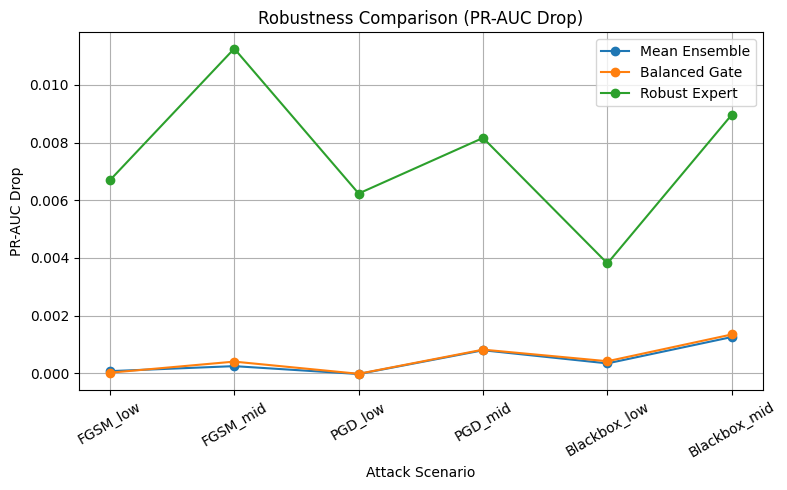


===== Robustness Results =====


,attack,mean_PR_AUC,gate_PR_AUC,robust_PR_AUC,mean_drop,gate_drop,robust_drop
2,PGD_low,0.373633,0.373625,0.367380,-0.000019,-0.000012,0.006233
0,FGSM_low,0.373533,0.373588,0.366921,0.000081,0.000026,0.006692
1,FGSM_mid,0.373360,0.373203,0.362361,0.000254,0.000411,0.011253
4,Blackbox_low,0.373264,0.373189,0.369801,0.000350,0.000424,0.003813
3,PGD_mid,0.372809,0.372788,0.365454,0.000804,0.000826,0.008159
5,Blackbox_mid,0.372352,0.372263,0.364649,0.001262,0.001351,0.008965



Saved:
 - module10_robustness_results.csv
 - robustness_pr_auc_drop.png


In [21]:
# ============================================================
# Module 10 — Robustness Evaluation (FGSM + PGD + Black-box)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import average_precision_score, roc_auc_score, log_loss

print("===== Module 10: Robustness Evaluation =====")

# ------------------------------------------------------------
# Required inputs
# ------------------------------------------------------------
required = [
    "MODULE7_META_HOLD",
    "MODULE91_PRED_HOLD",
    "FINAL_SELECTED_EXPERTS",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

hold_df = MODULE7_META_HOLD.copy()
experts = FINAL_SELECTED_EXPERTS

y_true = hold_df["y_true"].values.astype(int)
P_clean = hold_df[experts].values.astype(float)

# Baselines
pred_mean = P_clean.mean(axis=1)
pred_gate = MODULE91_PRED_HOLD.copy()

# robust expert
ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"
robust_idx = experts.index(ROBUST_EXPERT_NAME)
pred_robust = P_clean[:, robust_idx]

# ------------------------------------------------------------
# Metric function
# ------------------------------------------------------------
def compute_metrics(y, p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return {
        "PR_AUC": average_precision_score(y, p),
        "ROC_AUC": roc_auc_score(y, p),
        "NLL": log_loss(y, p)
    }

# ------------------------------------------------------------
# FGSM Attack (tabular perturbation simulation)
# ------------------------------------------------------------
def fgsm_attack(P, eps):
    noise = eps * np.sign(np.random.randn(*P.shape))
    return np.clip(P + noise, 0, 1)

# ------------------------------------------------------------
# PGD Attack (iterative)
# ------------------------------------------------------------
def pgd_attack(P, eps, step=0.005, steps=5):
    P_adv = P.copy()
    for _ in range(steps):
        noise = step * np.sign(np.random.randn(*P.shape))
        P_adv = P_adv + noise
        P_adv = np.clip(P_adv, P - eps, P + eps)
        P_adv = np.clip(P_adv, 0, 1)
    return P_adv

# ------------------------------------------------------------
# Black-box (NES-like random search)
# ------------------------------------------------------------
def blackbox_attack(P, eps, steps=5):
    P_adv = P.copy()
    for _ in range(steps):
        noise = eps * np.random.uniform(-1, 1, size=P.shape)
        P_adv = np.clip(P_adv + noise, 0, 1)
    return P_adv

# ------------------------------------------------------------
# Attack configs
# ------------------------------------------------------------
ATTACKS = [
    ("FGSM_low", lambda P: fgsm_attack(P, 0.01)),
    ("FGSM_mid", lambda P: fgsm_attack(P, 0.02)),
    ("PGD_low", lambda P: pgd_attack(P, 0.02, step=0.005, steps=5)),
    ("PGD_mid", lambda P: pgd_attack(P, 0.04, step=0.008, steps=7)),
    ("Blackbox_low", lambda P: blackbox_attack(P, 0.01)),
    ("Blackbox_mid", lambda P: blackbox_attack(P, 0.02)),
]

# ------------------------------------------------------------
# Evaluation loop
# ------------------------------------------------------------
rows = []

# clean baseline
clean_metrics = compute_metrics(y_true, pred_mean)

for attack_name, attack_fn in ATTACKS:

    P_adv = attack_fn(P_clean)

    pred_mean_adv = P_adv.mean(axis=1)
    pred_gate_adv = (P_adv * MODULE91_GATE_WEIGHTS_HOLD).sum(axis=1)
    pred_robust_adv = P_adv[:, robust_idx]

    m_mean = compute_metrics(y_true, pred_mean_adv)
    m_gate = compute_metrics(y_true, pred_gate_adv)
    m_robust = compute_metrics(y_true, pred_robust_adv)

    rows.append({
        "attack": attack_name,

        "mean_PR_AUC": m_mean["PR_AUC"],
        "gate_PR_AUC": m_gate["PR_AUC"],
        "robust_PR_AUC": m_robust["PR_AUC"],

        "mean_drop": clean_metrics["PR_AUC"] - m_mean["PR_AUC"],
        "gate_drop": clean_metrics["PR_AUC"] - m_gate["PR_AUC"],
        "robust_drop": clean_metrics["PR_AUC"] - m_robust["PR_AUC"],
    })

robustness_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
robustness_df.to_csv(TAB_DIR / "module10_robustness_results.csv", index=False)

# ------------------------------------------------------------
# Plot (publication-ready)
# ------------------------------------------------------------
plt.figure(figsize=(8,5))

plt.plot(robustness_df["attack"], robustness_df["mean_drop"], marker='o', label="Mean Ensemble")
plt.plot(robustness_df["attack"], robustness_df["gate_drop"], marker='o', label="Balanced Gate")
plt.plot(robustness_df["attack"], robustness_df["robust_drop"], marker='o', label="Robust Expert")

plt.ylabel("PR-AUC Drop")
plt.xlabel("Attack Scenario")
plt.title("Robustness Comparison (PR-AUC Drop)")
plt.xticks(rotation=30)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(FIG_DIR / "robustness_pr_auc_drop.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n===== Robustness Results =====")
display(robustness_df.sort_values("gate_drop"))

print("\nSaved:")
print(" - module10_robustness_results.csv")
print(" - robustness_pr_auc_drop.png")

In [25]:
# ============================================================
# Module 10.1 Patch — robust prediction extractor for all experts
# ============================================================

import numpy as np
import pandas as pd
import torch

def clip_probs(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def predict_with_refit_model(model_name, model, X_target_df):
    row = MODULE4_REGISTRY_DF[MODULE4_REGISTRY_DF["model_name"] == model_name].iloc[0]
    runner_type = row["runner_type"]
    preprocess_mode = row["preprocess_mode"]

    # ---------- robust salvage expert ----------
    if model_name == "MLP_FGSM_Moderate_E010":
        full_tr_idx, _ = train_test_split(
            np.arange(len(y_dev_arr)),
            test_size=0.15,
            stratify=np.asarray(y_dev_arr).astype(int),
            random_state=SEED + 999,
        )
        X_full_tr = X_dev_df.iloc[full_tr_idx].reset_index(drop=True)
        scaler_refit = fit_salvage_scaler(X_full_tr)
        X_target_np = transform_salvage_df(X_target_df.reset_index(drop=True), scaler_refit)

        model.eval()
        with torch.no_grad():
            xb = torch.tensor(X_target_np, dtype=torch.float32)
            if torch.cuda.is_available():
                xb = xb.to(PRIMARY_DEVICE)
            logits = model(xb).detach().cpu().numpy().reshape(-1)
            p = 1.0 / (1.0 + np.exp(-logits))
        return clip_probs(p)

    # ---------- standard preprocessing ----------
    preproc = build_fold_preprocessor(preprocess_mode)
    preproc.fit(X_dev_df)
    X_target_t = preproc.transform(X_target_df.reset_index(drop=True))

    # ---------- sklearn / boosting ----------
    if runner_type in ["sklearn", "boosting", "custom_subset_logreg"]:
        if runner_type == "custom_subset_logreg":
            X_target_fit = X_target_t[SUBSET_FEATURES].copy() if isinstance(X_target_t, pd.DataFrame) else X_target_df[SUBSET_FEATURES].copy()
        else:
            X_target_fit = X_target_t["X_dl"] if isinstance(X_target_t, dict) else X_target_t

        if hasattr(model, "predict_proba"):
            return clip_probs(model.predict_proba(X_target_fit)[:, 1])
        if hasattr(model, "decision_function"):
            raw = model.decision_function(X_target_fit)
            return clip_probs(1.0 / (1.0 + np.exp(-np.asarray(raw, dtype=float))))
        raise ValueError(f"{model_name}: unsupported sklearn-like prediction path.")

    # ---------- custom torch MLP ----------
    elif runner_type == "custom_mlp":
        X_target_np = X_target_t.values.astype(np.float32) if isinstance(X_target_t, pd.DataFrame) else np.asarray(X_target_t, dtype=np.float32)
        model.eval()
        with torch.no_grad():
            xb = torch.tensor(X_target_np, dtype=torch.float32)
            if torch.cuda.is_available():
                xb = xb.to(PRIMARY_DEVICE)
            logits = model(xb).detach().cpu().numpy().reshape(-1)
            p = 1.0 / (1.0 + np.exp(-logits))
        return clip_probs(p)

    # ---------- DeepCTR models: DeepFM / AutoInt ----------
    elif runner_type == "custom_deepctr":
        X_input = build_deepctr_input_dict(X_target_t)
        batch_size = int(row["fit_kwargs"].get("batch_size", 2048)) if isinstance(row["fit_kwargs"], dict) else 2048
        p = model.predict(X_input, batch_size=batch_size).reshape(-1)
        return clip_probs(p)

    # ---------- TabNet ----------
    elif runner_type == "custom_tabnet":
        X_target_np = X_target_t.values.astype(np.float32) if isinstance(X_target_t, pd.DataFrame) else np.asarray(X_target_t, dtype=np.float32)
        return clip_probs(model.predict_proba(X_target_np)[:, 1])

    # ---------- FTTransformer ----------
    elif runner_type == "custom_fttransformer":
        pred_df = model.predict(X_target_t.copy() if isinstance(X_target_t, pd.DataFrame) else pd.DataFrame(X_target_t, columns=FEATURE_COLS))
        prob_col_candidates = [c for c in pred_df.columns if "probability" in c.lower() or c.endswith("_1")]
        if len(prob_col_candidates) == 0:
            raise ValueError(f"{model_name}: probability column not found in FTTransformer output.")
        return clip_probs(pred_df[prob_col_candidates[-1]].values.reshape(-1))

    else:
        raise ValueError(f"{model_name}: unsupported runner_type {runner_type}")

def predict_selected_experts_on_features(X_target_df: pd.DataFrame):
    preds = {}
    for model_name in FINAL_SELECTED_EXPERTS:
        if model_name == "MLP_FGSM_Moderate_E010":
            model = MODULE41_SALVAGE_MODELS[model_name]
        else:
            model = MODULE6_REFIT_MODELS[model_name]
        preds[model_name] = predict_with_refit_model(model_name, model, X_target_df)
    return pd.DataFrame(preds)

print("Module 10.1 prediction patch loaded.")

Module 10.1 prediction patch loaded.


===== Module 10.1: Feature-Space Robustness Evaluation (FULL FIXED) =====

--- Running attack: Noise_low ---

--- Running attack: Noise_mid ---

--- Running attack: FGSM_like_low ---

--- Running attack: FGSM_like_mid ---

--- Running attack: PGD_like_low ---

--- Running attack: PGD_like_mid ---


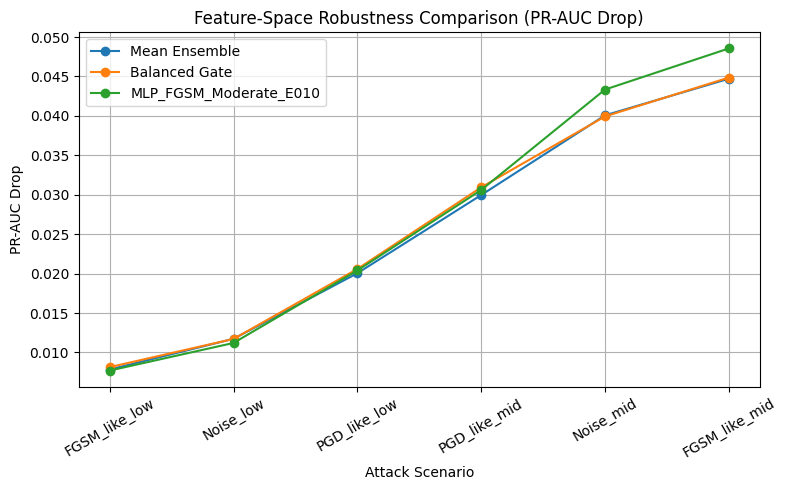


===== Module 10.1 Complete =====

Clean baselines:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE
0,MeanEnsemble,0.374080,0.850866,0.076061,0.259081,0.064733
1,BalancedTrustAdaptiveGate,0.373593,0.850499,0.089676,0.293010,0.109490
2,MLP_FGSM_Moderate_E010,0.371126,0.849931,0.164637,0.482842,0.251670



Feature-space robustness results:


,attack,mean_PR_AUC,gate_PR_AUC,robust_PR_AUC,mean_ROC_AUC,gate_ROC_AUC,robust_ROC_AUC,mean_Brier,gate_Brier,robust_Brier,mean_drop,gate_drop,robust_drop
0,FGSM_like_low,0.366241,0.365450,0.363419,0.845531,0.845009,0.844457,0.077052,0.091141,0.167257,0.007839,0.008144,0.007708
1,Noise_low,0.362346,0.361875,0.359918,0.842671,0.842311,0.841879,0.077782,0.092347,0.169503,0.011734,0.011718,0.011209
2,PGD_like_low,0.354032,0.353005,0.350721,0.839690,0.839241,0.838800,0.078207,0.092739,0.169897,0.020049,0.020588,0.020405
3,PGD_like_mid,0.344118,0.342652,0.340524,0.831832,0.831363,0.830851,0.079672,0.094983,0.173640,0.029962,0.030941,0.030603
4,Noise_mid,0.334012,0.333661,0.327786,0.823518,0.822865,0.822124,0.081342,0.097489,0.179152,0.040068,0.039932,0.043340
5,FGSM_like_mid,0.329370,0.328734,0.322573,0.824256,0.823829,0.822830,0.081635,0.098092,0.179782,0.044710,0.044859,0.048553



Saved:
- module101_clean_baselines.csv
- module101_feature_space_robustness_results.csv
- module101_feature_space_robustness_pr_auc_drop.png


In [27]:
# ============================================================
# Module 10.1 — Feature-Space Robustness Evaluation (FULL FIXED)
# ============================================================

import gc
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss
)

print("===== Module 10.1: Feature-Space Robustness Evaluation (FULL FIXED) =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "FINAL_SELECTED_EXPERTS",
    "X_dev_df", "X_test_df", "y_dev_arr", "y_test_arr",
    "MODULE4_REGISTRY_DF",
    "MODULE6_REFIT_MODELS",
    "MODULE91_GATE_MODEL",
    "MODULE7_META_OOF",
    "build_fold_preprocessor",
    "FEATURE_COLS",
    "SEED",
    "TAB_DIR",
    "FIG_DIR",
    "LOG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

if "MODULE41_SALVAGE_MODELS" not in globals():
    raise ValueError("MODULE41_SALVAGE_MODELS not found. Run Module 4.1 first.")

if "fit_salvage_scaler" not in globals() or "transform_salvage_df" not in globals():
    raise ValueError("fit_salvage_scaler / transform_salvage_df not found. Run Module 4.1 first.")

# optional helpers from earlier modules
BINARY = list(globals().get("BINARY_FEATURES", []))
ORDINAL = list(globals().get("ORDINAL_FEATURES", []))
CONTINUOUS = list(globals().get("CONTINUOUS_FEATURES", []))
SUBSET_FEATURES_LOCAL = list(globals().get("SUBSET_FEATURES", []))

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE101_CFG = {
    "attacks": [
        {"name": "Noise_low", "mode": "noise", "eps": 0.10},
        {"name": "Noise_mid", "mode": "noise", "eps": 0.20},
        {"name": "FGSM_like_low", "mode": "fgsm_like", "eps": 0.10},
        {"name": "FGSM_like_mid", "mode": "fgsm_like", "eps": 0.20},
        {"name": "PGD_like_low", "mode": "pgd_like", "eps": 0.15, "step": 0.05, "steps": 3},
        {"name": "PGD_like_mid", "mode": "pgd_like", "eps": 0.25, "step": 0.07, "steps": 5},
    ],
    "seed": 42,
}
with open(LOG_DIR / "module101_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE101_CFG, f, indent=2)

rng = np.random.default_rng(MODULE101_CFG["seed"])

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def compute_metrics(y, p):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    return {
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "ECE": float(compute_ece(y, p)),
    }

def get_registry_row(model_name):
    row = MODULE4_REGISTRY_DF[MODULE4_REGISTRY_DF["model_name"] == model_name]
    if len(row) == 0:
        raise ValueError(f"Model not found in MODULE4_REGISTRY_DF: {model_name}")
    return row.iloc[0]

# ------------------------------------------------------------
# Feature-space attacks
# ------------------------------------------------------------
FEATURE_COLS_LOCAL = list(FEATURE_COLS)
feature_min = X_dev_df[FEATURE_COLS_LOCAL].min()
feature_max = X_dev_df[FEATURE_COLS_LOCAL].max()

def project_feature_domain(X_adv: pd.DataFrame):
    Xp = X_adv.copy()

    for c in FEATURE_COLS_LOCAL:
        Xp[c] = Xp[c].clip(feature_min[c], feature_max[c])

    for c in BINARY:
        if c in Xp.columns:
            Xp[c] = (Xp[c] >= 0.5).astype(int)

    for c in ORDINAL:
        if c in Xp.columns:
            Xp[c] = np.round(Xp[c]).astype(int)
            Xp[c] = Xp[c].clip(int(feature_min[c]), int(feature_max[c]))

    return Xp

def attack_feature_space(X_df: pd.DataFrame, attack_cfg: dict):
    X_adv = X_df.copy().astype(float)

    if attack_cfg["mode"] == "noise":
        for c in CONTINUOUS + ORDINAL:
            if c in X_adv.columns:
                span = float(feature_max[c] - feature_min[c])
                noise = rng.normal(loc=0.0, scale=attack_cfg["eps"] * span, size=len(X_adv))
                X_adv[c] = X_adv[c] + noise

    elif attack_cfg["mode"] == "fgsm_like":
        for c in CONTINUOUS + ORDINAL:
            if c in X_adv.columns:
                span = float(feature_max[c] - feature_min[c])
                sign = np.sign(rng.normal(size=len(X_adv)))
                X_adv[c] = X_adv[c] + attack_cfg["eps"] * span * sign

    elif attack_cfg["mode"] == "pgd_like":
        eps = attack_cfg["eps"]
        step = attack_cfg["step"]
        steps = attack_cfg["steps"]
        X_base = X_df.copy().astype(float)
        X_adv = X_base.copy()

        for _ in range(steps):
            for c in CONTINUOUS + ORDINAL:
                if c in X_adv.columns:
                    span = float(feature_max[c] - feature_min[c])
                    sign = np.sign(rng.normal(size=len(X_adv)))
                    X_adv[c] = X_adv[c] + step * span * sign
                    lo = X_base[c] - eps * span
                    hi = X_base[c] + eps * span
                    X_adv[c] = np.minimum(np.maximum(X_adv[c], lo), hi)

    else:
        raise ValueError(f"Unsupported attack mode: {attack_cfg['mode']}")

    return project_feature_domain(X_adv)

# ------------------------------------------------------------
# Model prediction helpers
# ------------------------------------------------------------
def predict_sklearn_like(model, X_target_fit):
    if hasattr(model, "predict_proba"):
        return clip_probs(model.predict_proba(X_target_fit)[:, 1])
    if hasattr(model, "decision_function"):
        raw = model.decision_function(X_target_fit)
        return clip_probs(1.0 / (1.0 + np.exp(-np.asarray(raw, dtype=float))))
    raise ValueError("Model does not support predict_proba or decision_function.")

def predict_torch_mlp_model(model, X_target_np):
    model.eval()
    with torch.no_grad():
        xb = torch.tensor(X_target_np, dtype=torch.float32)
        if USE_GPU:
            xb = xb.to(PRIMARY_DEVICE)
        logits = model(xb).detach().cpu().numpy().reshape(-1)
        p = 1.0 / (1.0 + np.exp(-logits))
    return clip_probs(p)

def predict_deepctr_model(model, X_target_view, fit_kwargs):
    X_input = build_deepctr_input_dict(X_target_view)
    batch_size = int(fit_kwargs.get("batch_size", 2048))
    p = model.predict(X_input, batch_size=batch_size).reshape(-1)
    return clip_probs(p)

def predict_tabnet_model(model, X_target_df_or_np):
    X_np = X_target_df_or_np.values.astype(np.float32) if isinstance(X_target_df_or_np, pd.DataFrame) else np.asarray(X_target_df_or_np, dtype=np.float32)
    return clip_probs(model.predict_proba(X_np)[:, 1])

def predict_fttransformer_model(model, X_target_df):
    pred_df = model.predict(X_target_df.copy())
    prob_col_candidates = [c for c in pred_df.columns if "probability" in c.lower() or c.endswith("_1")]
    if len(prob_col_candidates) == 0:
        raise ValueError("Probability column not found in FTTransformer output.")
    return clip_probs(pred_df[prob_col_candidates[-1]].values.reshape(-1))

def predict_salvage_robust_expert(model_name, X_target_df):
    model = MODULE41_SALVAGE_MODELS[model_name]

    full_tr_idx, _ = train_test_split(
        np.arange(len(y_dev_arr)),
        test_size=0.15,
        stratify=np.asarray(y_dev_arr).astype(int),
        random_state=SEED + 999,
    )
    X_full_tr = X_dev_df.iloc[full_tr_idx].reset_index(drop=True)
    scaler_refit = fit_salvage_scaler(X_full_tr)
    X_target_np = transform_salvage_df(X_target_df.reset_index(drop=True), scaler_refit)

    return predict_torch_mlp_model(model, X_target_np)

def predict_selected_experts_on_features(X_target_df: pd.DataFrame):
    preds = {}

    for model_name in FINAL_SELECTED_EXPERTS:
        # salvaged robust expert
        if model_name == "MLP_FGSM_Moderate_E010":
            preds[model_name] = predict_salvage_robust_expert(model_name, X_target_df)
            continue

        row = get_registry_row(model_name)
        runner_type = row["runner_type"]
        preprocess_mode = row["preprocess_mode"]
        fit_kwargs = row["fit_kwargs"] if isinstance(row["fit_kwargs"], dict) else {}

        preproc = build_fold_preprocessor(preprocess_mode)
        preproc.fit(X_dev_df)
        X_target_t = preproc.transform(X_target_df.reset_index(drop=True))

        model = MODULE6_REFIT_MODELS[model_name]

        if runner_type in ["sklearn", "boosting"]:
            X_fit = X_target_t["X_dl"] if isinstance(X_target_t, dict) else X_target_t
            preds[model_name] = predict_sklearn_like(model, X_fit)

        elif runner_type == "custom_subset_logreg":
            X_fit = X_target_t[SUBSET_FEATURES_LOCAL].copy() if isinstance(X_target_t, pd.DataFrame) else X_target_df[SUBSET_FEATURES_LOCAL].copy()
            preds[model_name] = predict_sklearn_like(model, X_fit)

        elif runner_type == "custom_mlp":
            X_np = X_target_t.values.astype(np.float32) if isinstance(X_target_t, pd.DataFrame) else np.asarray(X_target_t, dtype=np.float32)
            preds[model_name] = predict_torch_mlp_model(model, X_np)

        elif runner_type == "custom_deepctr":
            preds[model_name] = predict_deepctr_model(model, X_target_t, fit_kwargs)

        elif runner_type == "custom_tabnet":
            preds[model_name] = predict_tabnet_model(model, X_target_t)

        elif runner_type == "custom_fttransformer":
            X_df = X_target_t if isinstance(X_target_t, pd.DataFrame) else pd.DataFrame(X_target_t, columns=FEATURE_COLS_LOCAL)
            preds[model_name] = predict_fttransformer_model(model, X_df)

        else:
            raise ValueError(f"{model_name}: unsupported runner_type {runner_type}")

    return pd.DataFrame(preds)

# ------------------------------------------------------------
# Meta feature rebuild
# ------------------------------------------------------------
def entropy_binary(p):
    p = np.clip(p, 1e-8, 1 - 1e-8)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def pairwise_mean_abs_diff(P):
    n = P.shape[1]
    diffs = []
    for i in range(n):
        for j in range(i + 1, n):
            diffs.append(np.abs(P[:, i] - P[:, j]))
    return np.mean(np.stack(diffs, axis=1), axis=1)

def compute_rank_features(P):
    ranks = np.argsort(np.argsort(-P, axis=1), axis=1)
    return np.std(ranks, axis=1)

def compute_top2_gap(P):
    sorted_p = np.sort(P, axis=1)
    return sorted_p[:, -1] - sorted_p[:, -2]

def compute_weighted_mean(P):
    var = np.var(P, axis=1, keepdims=True) + 1e-8
    weights = 1 / var
    weights = weights / np.sum(weights, axis=1, keepdims=True)
    return np.sum(P * weights, axis=1)

def build_meta_from_predictions(pred_df: pd.DataFrame, y_true: np.ndarray):
    P = pred_df[FINAL_SELECTED_EXPERTS].values.astype(float)

    feats = {}
    feats["mean_p"] = np.mean(P, axis=1)
    feats["median_p"] = np.median(P, axis=1)
    feats["std_p"] = np.std(P, axis=1)
    feats["var_p"] = np.var(P, axis=1)
    feats["max_min_gap"] = np.max(P, axis=1) - np.min(P, axis=1)
    feats["pairwise_mean_abs_diff"] = pairwise_mean_abs_diff(P)
    feats["entropy_mean"] = entropy_binary(feats["mean_p"])
    feats["confidence_margin"] = np.abs(feats["mean_p"] - 0.5)

    if "MLP_FGSM_Moderate_E010" in FINAL_SELECTED_EXPERTS and "MLP_Sklearn" in FINAL_SELECTED_EXPERTS:
        feats["robust_gap"] = np.abs(
            pred_df["MLP_Sklearn"].values - pred_df["MLP_FGSM_Moderate_E010"].values
        )
    else:
        feats["robust_gap"] = np.zeros(len(pred_df), dtype=float)

    feats["max_prob"] = np.max(P, axis=1)
    feats["top2_gap"] = compute_top2_gap(P)
    feats["rank_std"] = compute_rank_features(P)
    feats["weighted_mean"] = compute_weighted_mean(P)

    meta_df = pd.concat(
        [pred_df[FINAL_SELECTED_EXPERTS].reset_index(drop=True), pd.DataFrame(feats)],
        axis=1
    )
    meta_df["y_true"] = np.asarray(y_true).astype(int)
    return meta_df

# ------------------------------------------------------------
# Gate prediction on rebuilt meta features
# ------------------------------------------------------------
def gate_predict_from_meta(meta_df: pd.DataFrame):
    experts = FINAL_SELECTED_EXPERTS
    non_feature_cols = set(experts + ["y_true"])
    meta_feature_cols = [c for c in meta_df.columns if c not in non_feature_cols]

    train_meta = MODULE7_META_OOF.copy()
    train_meta_feature_cols = [c for c in train_meta.columns if c not in set(experts + ["y_true"])]

    if meta_feature_cols != train_meta_feature_cols:
        raise ValueError("Meta feature columns do not match Module 9.1 training columns.")

    scaler = StandardScaler()
    scaler.fit(train_meta[train_meta_feature_cols].values.astype(np.float32))
    X_attack = scaler.transform(meta_df[meta_feature_cols].values.astype(np.float32)).astype(np.float32)
    P_attack = meta_df[experts].values.astype(np.float32)

    X_tensor = torch.tensor(X_attack, dtype=torch.float32)
    if USE_GPU:
        X_tensor = X_tensor.to(PRIMARY_DEVICE)

    MODULE91_GATE_MODEL.eval()
    with torch.no_grad():
        W = MODULE91_GATE_MODEL(X_tensor).detach().cpu().numpy()
        pred = np.sum(W * P_attack, axis=1)

    return clip_probs(pred), W

# ------------------------------------------------------------
# Clean baseline
# ------------------------------------------------------------
y_true = np.asarray(y_test_arr).astype(int)
clean_pred_df = predict_selected_experts_on_features(X_test_df.copy())
clean_meta_df = build_meta_from_predictions(clean_pred_df, y_true)

clean_mean = clip_probs(clean_pred_df[FINAL_SELECTED_EXPERTS].mean(axis=1).values)
clean_gate, clean_W = gate_predict_from_meta(clean_meta_df)
robust_name = "MLP_FGSM_Moderate_E010"
clean_robust = clip_probs(clean_pred_df[robust_name].values)

clean_metrics_mean = compute_metrics(y_true, clean_mean)
clean_metrics_gate = compute_metrics(y_true, clean_gate)
clean_metrics_robust = compute_metrics(y_true, clean_robust)

MODULE101_CLEAN_BASELINES = pd.DataFrame([
    {"model": "MeanEnsemble", **clean_metrics_mean},
    {"model": "BalancedTrustAdaptiveGate", **clean_metrics_gate},
    {"model": robust_name, **clean_metrics_robust},
])

# ------------------------------------------------------------
# Attack loop
# ------------------------------------------------------------
rows = []
attack_pred_store = {}

for attack_cfg in MODULE101_CFG["attacks"]:
    print(f"\n--- Running attack: {attack_cfg['name']} ---")

    X_adv = attack_feature_space(X_test_df.copy(), attack_cfg)
    pred_df_adv = predict_selected_experts_on_features(X_adv)
    meta_df_adv = build_meta_from_predictions(pred_df_adv, y_true)

    pred_mean_adv = clip_probs(pred_df_adv[FINAL_SELECTED_EXPERTS].mean(axis=1).values)
    pred_gate_adv, W_adv = gate_predict_from_meta(meta_df_adv)
    pred_robust_adv = clip_probs(pred_df_adv[robust_name].values)

    m_mean = compute_metrics(y_true, pred_mean_adv)
    m_gate = compute_metrics(y_true, pred_gate_adv)
    m_robust = compute_metrics(y_true, pred_robust_adv)

    rows.append({
        "attack": attack_cfg["name"],

        "mean_PR_AUC": m_mean["PR_AUC"],
        "gate_PR_AUC": m_gate["PR_AUC"],
        "robust_PR_AUC": m_robust["PR_AUC"],

        "mean_ROC_AUC": m_mean["ROC_AUC"],
        "gate_ROC_AUC": m_gate["ROC_AUC"],
        "robust_ROC_AUC": m_robust["ROC_AUC"],

        "mean_Brier": m_mean["Brier"],
        "gate_Brier": m_gate["Brier"],
        "robust_Brier": m_robust["Brier"],

        "mean_drop": clean_metrics_mean["PR_AUC"] - m_mean["PR_AUC"],
        "gate_drop": clean_metrics_gate["PR_AUC"] - m_gate["PR_AUC"],
        "robust_drop": clean_metrics_robust["PR_AUC"] - m_robust["PR_AUC"],
    })

    attack_pred_store[attack_cfg["name"]] = {
        "mean_pred": pred_mean_adv,
        "gate_pred": pred_gate_adv,
        "robust_pred": pred_robust_adv,
        "gate_weights": W_adv,
    }

    if USE_GPU:
        torch.cuda.empty_cache()
    gc.collect()

MODULE101_ROBUSTNESS_DF = pd.DataFrame(rows).sort_values("gate_drop").reset_index(drop=True)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
MODULE101_CLEAN_BASELINES.to_csv(TAB_DIR / "module101_clean_baselines.csv", index=False)
MODULE101_ROBUSTNESS_DF.to_csv(TAB_DIR / "module101_feature_space_robustness_results.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(MODULE101_ROBUSTNESS_DF["attack"], MODULE101_ROBUSTNESS_DF["mean_drop"], marker="o", label="Mean Ensemble")
plt.plot(MODULE101_ROBUSTNESS_DF["attack"], MODULE101_ROBUSTNESS_DF["gate_drop"], marker="o", label="Balanced Gate")
plt.plot(MODULE101_ROBUSTNESS_DF["attack"], MODULE101_ROBUSTNESS_DF["robust_drop"], marker="o", label=robust_name)
plt.ylabel("PR-AUC Drop")
plt.xlabel("Attack Scenario")
plt.title("Feature-Space Robustness Comparison (PR-AUC Drop)")
plt.xticks(rotation=30)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module101_feature_space_robustness_pr_auc_drop.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE101_ATTACK_PRED_STORE = attack_pred_store

print("\n===== Module 10.1 Complete =====")
print("\nClean baselines:")
display(MODULE101_CLEAN_BASELINES)

print("\nFeature-space robustness results:")
display(MODULE101_ROBUSTNESS_DF)

print("\nSaved:")
print("- module101_clean_baselines.csv")
print("- module101_feature_space_robustness_results.csv")
print("- module101_feature_space_robustness_pr_auc_drop.png")

===== Module 11: Selective Prediction / Risk-Coverage / HITL =====


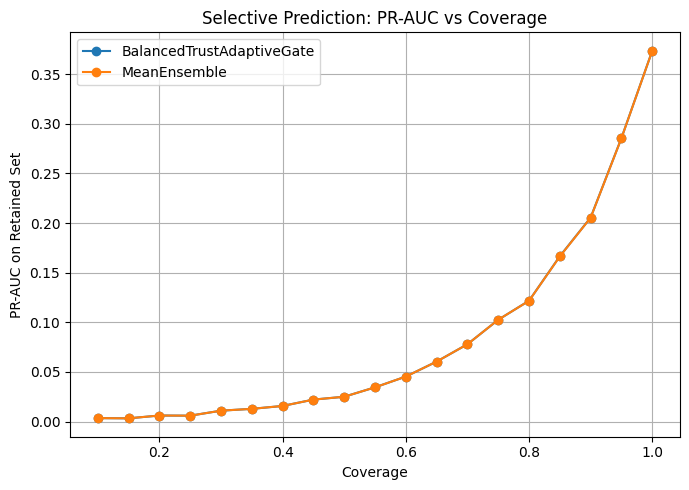

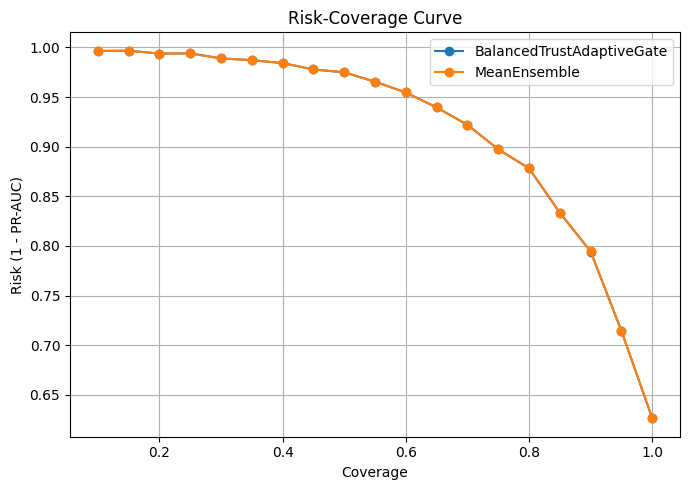

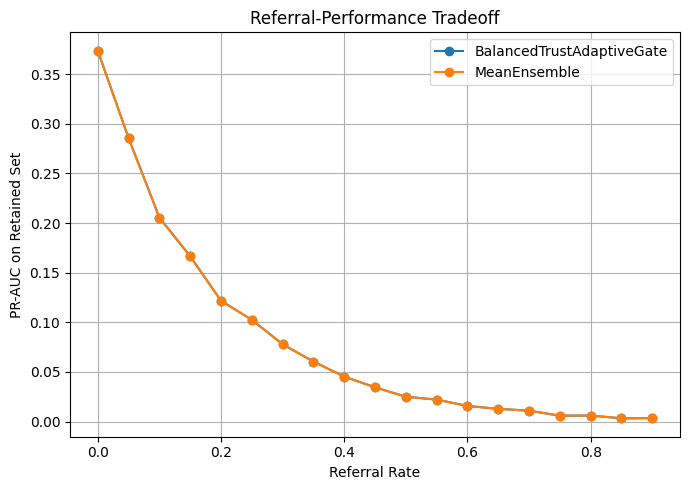


===== Module 11 Complete =====

Selective prediction summary:


,coverage,referral_rate,n_kept,n_referred,best_curve_f1,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,model
0,0.500000,0.500000,25368,25368,0.000000,0.025051,0.718694,0.011908,0.062001,0.000653,0.000000,0.000000,0.000000,0.987859,0.000000,0.050,0.000000,0.012795,25368,MeanEnsemble
1,0.500000,0.500000,25368,25368,0.000000,0.025059,0.718713,0.011908,0.062000,0.000654,0.000000,0.000000,0.000000,0.987859,0.000000,0.050,0.000000,0.012795,25368,BalancedTrustAdaptiveGate
2,0.600008,0.399992,30442,20294,0.093042,0.045371,0.746213,0.017482,0.083480,0.001323,0.059542,0.212727,0.093042,0.925071,0.081796,0.055,0.064549,0.019390,30442,MeanEnsemble
3,0.600008,0.399992,30442,20294,0.093079,0.045370,0.746230,0.017482,0.083479,0.001323,0.059572,0.212727,0.093079,0.925103,0.081834,0.055,0.064516,0.019390,30442,BalancedTrustAdaptiveGate
4,0.699996,0.300004,35515,15221,0.144625,0.077944,0.774936,0.025986,0.112664,0.001605,0.098909,0.268916,0.144625,0.912403,0.124073,0.085,0.074870,0.029143,35515,MeanEnsemble
5,0.699996,0.300004,35515,15221,0.144345,0.077945,0.774942,0.025986,0.112663,0.001603,0.087544,0.411043,0.144345,0.865803,0.141304,0.070,0.129297,0.029140,35515,BalancedTrustAdaptiveGate
6,0.800004,0.199996,40589,10147,0.200048,0.121730,0.792816,0.036959,0.147039,0.002370,0.124607,0.506999,0.200048,0.835867,0.189551,0.095,0.164700,0.042849,40589,MeanEnsemble
7,0.800004,0.199996,40589,10147,0.199856,0.121799,0.792822,0.036958,0.147036,0.002353,0.124495,0.506391,0.199856,0.835867,0.189264,0.095,0.164651,0.042832,40589,BalancedTrustAdaptiveGate
8,0.899992,0.100008,45662,5074,0.292790,0.205442,0.818069,0.052153,0.189753,0.002236,0.221406,0.432103,0.292790,0.872410,0.246244,0.165,0.119290,0.062404,45662,MeanEnsemble
9,0.899992,0.100008,45662,5074,0.293455,0.205601,0.818082,0.052153,0.189750,0.002261,0.218134,0.448226,0.293455,0.868074,0.248403,0.160,0.125597,0.062346,45662,BalancedTrustAdaptiveGate



HITL comparison at 80% coverage:


,model,coverage,referral_rate,n_kept,n_referred,best_curve_f1,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N
0,MeanEnsemble,0.800004,0.199996,40589,10147,0.200048,0.121730,0.792816,0.036959,0.147039,0.002370,0.124607,0.506999,0.200048,0.835867,0.189551,0.095,0.164700,0.042849,40589
1,BalancedTrustAdaptiveGate,0.800004,0.199996,40589,10147,0.199856,0.121799,0.792822,0.036958,0.147036,0.002353,0.124495,0.506391,0.199856,0.835867,0.189264,0.095,0.164651,0.042832,40589



Saved:
- module11_risk_coverage_table.csv
- module11_selective_summary.csv
- module11_hitl_compare_80coverage.csv
- module11_hitl_meanensemble.csv
- module11_hitl_gate.csv
- module11_pr_auc_vs_coverage.png
- module11_risk_coverage_curve.png
- module11_referral_vs_performance.png


In [28]:
# ============================================================
# Module 11 — Selective Prediction / Risk-Coverage / HITL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

print("===== Module 11: Selective Prediction / Risk-Coverage / HITL =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE7_META_HOLD",
    "MODULE8_UQ_HOLD",
    "MODULE91_PRED_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
hold_meta = MODULE7_META_HOLD.copy()
uq_hold_df = MODULE8_UQ_HOLD.copy()

y_true = hold_meta["y_true"].values.astype(int)

# base models
mean_pred = hold_meta[FINAL_SELECTED_EXPERTS].mean(axis=1).values.astype(float)
gate_pred = np.asarray(MODULE91_PRED_HOLD, dtype=float)

# uncertainty
gate_uq = uq_hold_df["uq"].values.astype(float)

# proxy uncertainty for mean ensemble:
# use trust features directly
mean_uq = (
    0.35 * hold_meta["entropy_mean"].values +
    0.30 * hold_meta["std_p"].values +
    0.25 * hold_meta["pairwise_mean_abs_diff"].values +
    0.10 * hold_meta["robust_gap"].values
).astype(float)

# normalize
def normalize_01(x):
    x = np.asarray(x, dtype=float)
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

mean_uq = normalize_01(mean_uq)
gate_uq = normalize_01(gate_uq)

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
        "N": int(len(y_true)),
    }

def selective_metrics(y_true, p, uq, coverage):
    """
    Keep lowest-uncertainty fraction = coverage
    """
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    uq = np.asarray(uq, dtype=float)

    n = len(y_true)
    k = max(1, int(round(coverage * n)))

    order = np.argsort(uq)  # low uncertainty first
    keep_idx = order[:k]

    y_keep = y_true[keep_idx]
    p_keep = p[keep_idx]

    thr, best_f1 = best_f1_threshold(y_keep, p_keep)
    metrics = compute_metrics(y_keep, p_keep, threshold=thr)

    out = {
        "coverage": float(k / n),
        "referral_rate": float(1.0 - (k / n)),
        "n_kept": int(k),
        "n_referred": int(n - k),
        "best_curve_f1": float(best_f1),
        **metrics,
    }
    return out

def build_risk_coverage_table(y_true, p, uq, model_name, coverages=None):
    if coverages is None:
        coverages = np.linspace(0.10, 1.00, 19)

    rows = []
    for c in coverages:
        row = selective_metrics(y_true, p, uq, coverage=float(c))
        row["model"] = model_name
        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Clean baseline thresholds
# ------------------------------------------------------------
mean_thr, _ = best_f1_threshold(y_true, mean_pred)
gate_thr, _ = best_f1_threshold(y_true, gate_pred)

# ------------------------------------------------------------
# Risk-coverage tables
# ------------------------------------------------------------
mean_rc_df = build_risk_coverage_table(y_true, mean_pred, mean_uq, model_name="MeanEnsemble")
gate_rc_df = build_risk_coverage_table(y_true, gate_pred, gate_uq, model_name="BalancedTrustAdaptiveGate")

MODULE11_RC_DF = pd.concat([mean_rc_df, gate_rc_df], axis=0, ignore_index=True)
MODULE11_RC_DF.to_csv(TAB_DIR / "module11_risk_coverage_table.csv", index=False)

# ------------------------------------------------------------
# Fixed-coverage summary table
# ------------------------------------------------------------
target_coverages = [0.50, 0.60, 0.70, 0.80, 0.90, 1.00]

summary_rows = []
for c in target_coverages:
    mean_row = selective_metrics(y_true, mean_pred, mean_uq, coverage=c)
    mean_row["model"] = "MeanEnsemble"

    gate_row = selective_metrics(y_true, gate_pred, gate_uq, coverage=c)
    gate_row["model"] = "BalancedTrustAdaptiveGate"

    summary_rows.extend([mean_row, gate_row])

MODULE11_SUMMARY_DF = pd.DataFrame(summary_rows)
MODULE11_SUMMARY_DF.to_csv(TAB_DIR / "module11_selective_summary.csv", index=False)

# ------------------------------------------------------------
# HITL referral outputs
# ------------------------------------------------------------
def build_hitl_output(y_true, p, uq, model_name, coverage=0.80):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    uq = np.asarray(uq, dtype=float)

    n = len(y_true)
    k = max(1, int(round(coverage * n)))
    order = np.argsort(uq)
    keep_idx = order[:k]
    refer_idx = order[k:]

    thr, _ = best_f1_threshold(y_true[keep_idx], p[keep_idx])

    out_df = pd.DataFrame({
        "row_idx": np.arange(n, dtype=int),
        "y_true": y_true,
        "pred_prob": p,
        "uncertainty": uq,
        "decision_label": (p >= thr).astype(int),
        "status": np.where(np.isin(np.arange(n), keep_idx), "auto_decide", "refer_human"),
        "model": model_name,
    })

    return out_df, thr

mean_hitl_df, mean_hitl_thr = build_hitl_output(y_true, mean_pred, mean_uq, "MeanEnsemble", coverage=0.80)
gate_hitl_df, gate_hitl_thr = build_hitl_output(y_true, gate_pred, gate_uq, "BalancedTrustAdaptiveGate", coverage=0.80)

mean_hitl_df.to_csv(PRED_DIR / "module11_hitl_meanensemble.csv", index=False)
gate_hitl_df.to_csv(PRED_DIR / "module11_hitl_gate.csv", index=False)

# ------------------------------------------------------------
# Comparison table at 80% coverage
# ------------------------------------------------------------
mean_80 = selective_metrics(y_true, mean_pred, mean_uq, coverage=0.80)
gate_80 = selective_metrics(y_true, gate_pred, gate_uq, coverage=0.80)

MODULE11_HITL_COMPARE_DF = pd.DataFrame([
    {"model": "MeanEnsemble", **mean_80},
    {"model": "BalancedTrustAdaptiveGate", **gate_80},
])
MODULE11_HITL_COMPARE_DF.to_csv(TAB_DIR / "module11_hitl_compare_80coverage.csv", index=False)

# ------------------------------------------------------------
# Plots
# ------------------------------------------------------------
# 1. PR-AUC vs coverage
plt.figure(figsize=(7, 5))
for model_name, df_sub in MODULE11_RC_DF.groupby("model"):
    plt.plot(df_sub["coverage"], df_sub["PR_AUC"], marker="o", label=model_name)
plt.xlabel("Coverage")
plt.ylabel("PR-AUC on Retained Set")
plt.title("Selective Prediction: PR-AUC vs Coverage")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_pr_auc_vs_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Risk vs coverage (risk = 1 - PR-AUC)
plt.figure(figsize=(7, 5))
for model_name, df_sub in MODULE11_RC_DF.groupby("model"):
    risk = 1.0 - df_sub["PR_AUC"].values
    plt.plot(df_sub["coverage"], risk, marker="o", label=model_name)
plt.xlabel("Coverage")
plt.ylabel("Risk (1 - PR-AUC)")
plt.title("Risk-Coverage Curve")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_risk_coverage_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Referral rate vs PR-AUC
plt.figure(figsize=(7, 5))
for model_name, df_sub in MODULE11_RC_DF.groupby("model"):
    plt.plot(df_sub["referral_rate"], df_sub["PR_AUC"], marker="o", label=model_name)
plt.xlabel("Referral Rate")
plt.ylabel("PR-AUC on Retained Set")
plt.title("Referral-Performance Tradeoff")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_referral_vs_performance.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE11_MEAN_RC_DF = mean_rc_df.copy()
MODULE11_GATE_RC_DF = gate_rc_df.copy()
MODULE11_MEAN_HITL_DF = mean_hitl_df.copy()
MODULE11_GATE_HITL_DF = gate_hitl_df.copy()

print("\n===== Module 11 Complete =====")
print("\nSelective prediction summary:")
display(MODULE11_SUMMARY_DF)

print("\nHITL comparison at 80% coverage:")
display(MODULE11_HITL_COMPARE_DF)

print("\nSaved:")
print("- module11_risk_coverage_table.csv")
print("- module11_selective_summary.csv")
print("- module11_hitl_compare_80coverage.csv")
print("- module11_hitl_meanensemble.csv")
print("- module11_hitl_gate.csv")
print("- module11_pr_auc_vs_coverage.png")
print("- module11_risk_coverage_curve.png")
print("- module11_referral_vs_performance.png")

In [29]:
# ============================================================
# Module 7.2 — Enhanced Trust Feature Engineering
#
# Goal:
#   Strengthen trust/meta features so the gate can actually
#   learn non-uniform routing and selective prediction.
#
# Builds:
#   - richer disagreement features
#   - dominance / ranking features
#   - robust-expert comparison features
#   - local sensitivity features (via noisy feature-space rerun)
#   - per-expert deviation features
#
# Outputs:
#   - MODULE72_META_OOF
#   - MODULE72_META_HOLD
#   - MODULE72_TRUST_FEATURES
# ============================================================

import gc
import json
import numpy as np
import pandas as pd
import torch

print("===== Module 7.2: Enhanced Trust Feature Engineering =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "FINAL_SELECTED_EXPERTS",
    "MODULE6_CALIBRATED_OOF",
    "MODULE6_CALIBRATED_HOLD",
    "X_dev_df", "X_test_df",
    "y_dev_arr", "y_test_arr",
    "MODULE4_REGISTRY_DF",
    "MODULE6_REFIT_MODELS",
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "FEATURE_COLS",
    "SEED",
    "build_fold_preprocessor",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs for Module 7.2: {missing}")

if "MODULE41_SALVAGE_MODELS" not in globals():
    raise ValueError("MODULE41_SALVAGE_MODELS not found. Run Module 4.1 first.")

if "fit_salvage_scaler" not in globals() or "transform_salvage_df" not in globals():
    raise ValueError("fit_salvage_scaler / transform_salvage_df not found. Run Module 4.1 first.")

# optional globals
BINARY = list(globals().get("BINARY_FEATURES", []))
ORDINAL = list(globals().get("ORDINAL_FEATURES", []))
CONTINUOUS = list(globals().get("CONTINUOUS_FEATURES", []))
SUBSET_FEATURES_LOCAL = list(globals().get("SUBSET_FEATURES", []))

USE_GPU = torch.cuda.is_available()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"
CLEAN_NEURAL_NAME = "MLP_Sklearn"

MODULE72_CFG = {
    "noise_frac_cont_ord": 0.03,   # local sensitivity probe size
    "seed": 42,
}
with open(LOG_DIR / "module72_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE72_CFG, f, indent=2)

rng = np.random.default_rng(MODULE72_CFG["seed"])

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def entropy_binary(p):
    p = clip_probs(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def pairwise_mean_abs_diff(P):
    n = P.shape[1]
    diffs = []
    for i in range(n):
        for j in range(i + 1, n):
            diffs.append(np.abs(P[:, i] - P[:, j]))
    return np.mean(np.stack(diffs, axis=1), axis=1)

def pairwise_max_abs_diff(P):
    n = P.shape[1]
    diffs = []
    for i in range(n):
        for j in range(i + 1, n):
            diffs.append(np.abs(P[:, i] - P[:, j]))
    return np.max(np.stack(diffs, axis=1), axis=1)

def compute_rank_std(P):
    ranks = np.argsort(np.argsort(-P, axis=1), axis=1)
    return np.std(ranks, axis=1)

def top2_gap(P):
    sorted_p = np.sort(P, axis=1)
    return sorted_p[:, -1] - sorted_p[:, -2]

def weighted_mean_inverse_var(P):
    # sample-wise inverse-variance weighting is degenerate if used directly across experts;
    # instead use global expert reliability priors.
    return np.mean(P, axis=1)

def feature_noise_attack(X_df: pd.DataFrame):
    X_adv = X_df.copy().astype(float)
    feature_min = X_dev_df[FEATURE_COLS].min()
    feature_max = X_dev_df[FEATURE_COLS].max()

    for c in CONTINUOUS + ORDINAL:
        if c in X_adv.columns:
            span = float(feature_max[c] - feature_min[c])
            noise = rng.normal(loc=0.0, scale=MODULE72_CFG["noise_frac_cont_ord"] * max(span, 1e-8), size=len(X_adv))
            X_adv[c] = X_adv[c] + noise

    for c in FEATURE_COLS:
        X_adv[c] = X_adv[c].clip(feature_min[c], feature_max[c])

    for c in BINARY:
        if c in X_adv.columns:
            X_adv[c] = (X_adv[c] >= 0.5).astype(int)

    for c in ORDINAL:
        if c in X_adv.columns:
            X_adv[c] = np.round(X_adv[c]).astype(int)
            X_adv[c] = X_adv[c].clip(int(feature_min[c]), int(feature_max[c]))

    return X_adv

def get_registry_row(model_name):
    row = MODULE4_REGISTRY_DF[MODULE4_REGISTRY_DF["model_name"] == model_name]
    if len(row) == 0:
        raise ValueError(f"Model not found in MODULE4_REGISTRY_DF: {model_name}")
    return row.iloc[0]

def predict_sklearn_like(model, X_target_fit):
    if hasattr(model, "predict_proba"):
        return clip_probs(model.predict_proba(X_target_fit)[:, 1])
    if hasattr(model, "decision_function"):
        raw = model.decision_function(X_target_fit)
        return clip_probs(1.0 / (1.0 + np.exp(-np.asarray(raw, dtype=float))))
    raise ValueError("Model does not support predict_proba or decision_function.")

def predict_torch_mlp_model(model, X_target_np):
    model.eval()
    with torch.no_grad():
        xb = torch.tensor(X_target_np, dtype=torch.float32)
        if USE_GPU:
            xb = xb.to(PRIMARY_DEVICE)
        logits = model(xb).detach().cpu().numpy().reshape(-1)
        p = 1.0 / (1.0 + np.exp(-logits))
    return clip_probs(p)

def predict_deepctr_model(model, X_target_view, fit_kwargs):
    X_input = build_deepctr_input_dict(X_target_view)
    batch_size = int(fit_kwargs.get("batch_size", 2048))
    p = model.predict(X_input, batch_size=batch_size).reshape(-1)
    return clip_probs(p)

def predict_tabnet_model(model, X_target_df_or_np):
    X_np = X_target_df_or_np.values.astype(np.float32) if isinstance(X_target_df_or_np, pd.DataFrame) else np.asarray(X_target_df_or_np, dtype=np.float32)
    return clip_probs(model.predict_proba(X_np)[:, 1])

def predict_fttransformer_model(model, X_target_df):
    pred_df = model.predict(X_target_df.copy())
    prob_col_candidates = [c for c in pred_df.columns if "probability" in c.lower() or c.endswith("_1")]
    if len(prob_col_candidates) == 0:
        raise ValueError("Probability column not found in FTTransformer output.")
    return clip_probs(pred_df[prob_col_candidates[-1]].values.reshape(-1))

def predict_salvage_robust_expert(model_name, X_target_df):
    model = MODULE41_SALVAGE_MODELS[model_name]
    full_tr_idx, _ = train_test_split(
        np.arange(len(y_dev_arr)),
        test_size=0.15,
        stratify=np.asarray(y_dev_arr).astype(int),
        random_state=SEED + 999,
    )
    X_full_tr = X_dev_df.iloc[full_tr_idx].reset_index(drop=True)
    scaler_refit = fit_salvage_scaler(X_full_tr)
    X_target_np = transform_salvage_df(X_target_df.reset_index(drop=True), scaler_refit)
    return predict_torch_mlp_model(model, X_target_np)

def predict_selected_experts_on_features(X_target_df: pd.DataFrame):
    preds = {}

    for model_name in FINAL_SELECTED_EXPERTS:
        if model_name == ROBUST_EXPERT_NAME:
            preds[model_name] = predict_salvage_robust_expert(model_name, X_target_df)
            continue

        row = get_registry_row(model_name)
        runner_type = row["runner_type"]
        preprocess_mode = row["preprocess_mode"]
        fit_kwargs = row["fit_kwargs"] if isinstance(row["fit_kwargs"], dict) else {}

        preproc = build_fold_preprocessor(preprocess_mode)
        preproc.fit(X_dev_df)
        X_target_t = preproc.transform(X_target_df.reset_index(drop=True))

        model = MODULE6_REFIT_MODELS[model_name]

        if runner_type in ["sklearn", "boosting"]:
            X_fit = X_target_t["X_dl"] if isinstance(X_target_t, dict) else X_target_t
            preds[model_name] = predict_sklearn_like(model, X_fit)

        elif runner_type == "custom_subset_logreg":
            X_fit = X_target_t[SUBSET_FEATURES_LOCAL].copy() if isinstance(X_target_t, pd.DataFrame) else X_target_df[SUBSET_FEATURES_LOCAL].copy()
            preds[model_name] = predict_sklearn_like(model, X_fit)

        elif runner_type == "custom_mlp":
            X_np = X_target_t.values.astype(np.float32) if isinstance(X_target_t, pd.DataFrame) else np.asarray(X_target_t, dtype=np.float32)
            preds[model_name] = predict_torch_mlp_model(model, X_np)

        elif runner_type == "custom_deepctr":
            preds[model_name] = predict_deepctr_model(model, X_target_t, fit_kwargs)

        elif runner_type == "custom_tabnet":
            preds[model_name] = predict_tabnet_model(model, X_target_t)

        elif runner_type == "custom_fttransformer":
            X_df = X_target_t if isinstance(X_target_t, pd.DataFrame) else pd.DataFrame(X_target_t, columns=FEATURE_COLS)
            preds[model_name] = predict_fttransformer_model(model, X_df)

        else:
            raise ValueError(f"{model_name}: unsupported runner_type {runner_type}")

    return pd.DataFrame(preds)

# ------------------------------------------------------------
# Global reliability priors from Module 6 calibrated OOF
# ------------------------------------------------------------
reliability_lookup = {}
if "MODULE6_RESULTS" in globals():
    tmp = MODULE6_RESULTS.copy()
    for m in FINAL_SELECTED_EXPERTS:
        row = tmp[tmp["model"] == m]
        if len(row) == 0:
            reliability_lookup[m] = 1.0
        else:
            brier = float(row.iloc[0]["OOF_CAL_Brier"]) if "OOF_CAL_Brier" in row.columns else 0.07
            reliability_lookup[m] = 1.0 / (brier + 1e-8)
else:
    for m in FINAL_SELECTED_EXPERTS:
        reliability_lookup[m] = 1.0

reliability_vec = np.array([reliability_lookup[m] for m in FINAL_SELECTED_EXPERTS], dtype=float)
reliability_vec = reliability_vec / reliability_vec.sum()

# ------------------------------------------------------------
# Build enhanced meta features from expert predictions
# ------------------------------------------------------------
def build_enhanced_meta(pred_df: pd.DataFrame, y_true: np.ndarray, sensitivity_pred_df: pd.DataFrame):
    P = pred_df[FINAL_SELECTED_EXPERTS].values.astype(float)
    P_sens = sensitivity_pred_df[FINAL_SELECTED_EXPERTS].values.astype(float)

    feats = {}

    # basic trust features
    feats["mean_p"] = np.mean(P, axis=1)
    feats["median_p"] = np.median(P, axis=1)
    feats["std_p"] = np.std(P, axis=1)
    feats["var_p"] = np.var(P, axis=1)
    feats["max_min_gap"] = np.max(P, axis=1) - np.min(P, axis=1)
    feats["pairwise_mean_abs_diff"] = pairwise_mean_abs_diff(P)
    feats["pairwise_max_abs_diff"] = pairwise_max_abs_diff(P)
    feats["entropy_mean"] = entropy_binary(feats["mean_p"])
    feats["confidence_margin"] = np.abs(feats["mean_p"] - 0.5)
    feats["max_prob"] = np.max(P, axis=1)
    feats["top2_gap"] = top2_gap(P)
    feats["rank_std"] = compute_rank_std(P)

    # reliability-weighted consensus
    feats["weighted_mean"] = np.sum(P * reliability_vec[None, :], axis=1)

    # expert-vs-consensus deviations
    mean_p = feats["mean_p"]
    for m in FINAL_SELECTED_EXPERTS:
        feats[f"{m}__abs_dev_from_mean"] = np.abs(pred_df[m].values - mean_p)

    # dominance / asymmetry
    feats["max_minus_mean"] = np.max(P, axis=1) - mean_p
    feats["median_minus_mean_abs"] = np.abs(feats["median_p"] - mean_p)

    # robust-expert relational features
    if ROBUST_EXPERT_NAME in FINAL_SELECTED_EXPERTS and CLEAN_NEURAL_NAME in FINAL_SELECTED_EXPERTS:
        feats["robust_gap"] = np.abs(
            pred_df[CLEAN_NEURAL_NAME].values - pred_df[ROBUST_EXPERT_NAME].values
        )
        feats["robust_minus_mean_abs"] = np.abs(pred_df[ROBUST_EXPERT_NAME].values - mean_p)
        feats["clean_neural_minus_mean_abs"] = np.abs(pred_df[CLEAN_NEURAL_NAME].values - mean_p)
    else:
        feats["robust_gap"] = np.zeros(len(pred_df), dtype=float)
        feats["robust_minus_mean_abs"] = np.zeros(len(pred_df), dtype=float)
        feats["clean_neural_minus_mean_abs"] = np.zeros(len(pred_df), dtype=float)

    # local sensitivity features (prediction change after small feature perturbation)
    sens_abs = np.abs(P - P_sens)
    feats["sensitivity_mean_abs"] = np.mean(sens_abs, axis=1)
    feats["sensitivity_max_abs"] = np.max(sens_abs, axis=1)
    feats["sensitivity_std_abs"] = np.std(sens_abs, axis=1)
    for i, m in enumerate(FINAL_SELECTED_EXPERTS):
        feats[f"{m}__sensitivity_abs"] = sens_abs[:, i]

    meta_df = pd.concat(
        [pred_df[FINAL_SELECTED_EXPERTS].reset_index(drop=True), pd.DataFrame(feats)],
        axis=1
    )
    meta_df["y_true"] = np.asarray(y_true).astype(int)
    return meta_df

# ------------------------------------------------------------
# OOF / HOLD clean calibrated expert probabilities
# ------------------------------------------------------------
oof_base_pred_df = MODULE6_CALIBRATED_OOF[FINAL_SELECTED_EXPERTS].copy()
hold_base_pred_df = MODULE6_CALIBRATED_HOLD[FINAL_SELECTED_EXPERTS].copy()

# build sensitivity predictions from noised feature-space rerun
print("Building local sensitivity predictions on DEV...")
X_dev_noisy = feature_noise_attack(X_dev_df.copy())
oof_sens_pred_df = predict_selected_experts_on_features(X_dev_noisy)

print("Building local sensitivity predictions on HOLD...")
X_hold_noisy = feature_noise_attack(X_test_df.copy())
hold_sens_pred_df = predict_selected_experts_on_features(X_hold_noisy)

# ------------------------------------------------------------
# Build enhanced meta frames
# ------------------------------------------------------------
MODULE72_META_OOF = build_enhanced_meta(
    pred_df=oof_base_pred_df,
    y_true=np.asarray(y_dev_arr).astype(int),
    sensitivity_pred_df=oof_sens_pred_df,
)

MODULE72_META_HOLD = build_enhanced_meta(
    pred_df=hold_base_pred_df,
    y_true=np.asarray(y_test_arr).astype(int),
    sensitivity_pred_df=hold_sens_pred_df,
)

# feature list
MODULE72_TRUST_FEATURES = [
    c for c in MODULE72_META_OOF.columns
    if c not in FINAL_SELECTED_EXPERTS + ["y_true"]
]

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
MODULE72_META_OOF.to_csv(PRED_DIR / "module72_meta_oof.csv", index=False)
MODULE72_META_HOLD.to_csv(PRED_DIR / "module72_meta_hold.csv", index=False)

pd.DataFrame({"trust_feature": MODULE72_TRUST_FEATURES}).to_csv(
    TAB_DIR / "module72_trust_feature_list.csv", index=False
)

summary_df = pd.DataFrame({
    "artifact": ["MODULE72_META_OOF", "MODULE72_META_HOLD"],
    "n_rows": [MODULE72_META_OOF.shape[0], MODULE72_META_HOLD.shape[0]],
    "n_cols": [MODULE72_META_OOF.shape[1], MODULE72_META_HOLD.shape[1]],
    "n_trust_features": [len(MODULE72_TRUST_FEATURES), len(MODULE72_TRUST_FEATURES)],
})
summary_df.to_csv(TAB_DIR / "module72_summary.csv", index=False)

print("\n===== Module 7.2 Complete =====")
print("OOF shape :", MODULE72_META_OOF.shape)
print("HOLD shape:", MODULE72_META_HOLD.shape)
print("Number of trust features:", len(MODULE72_TRUST_FEATURES))
print("\nFirst 20 trust features:")
print(MODULE72_TRUST_FEATURES[:20])

print("\nSaved:")
print("- module72_meta_oof.csv")
print("- module72_meta_hold.csv")
print("- module72_trust_feature_list.csv")
print("- module72_summary.csv")

===== Module 7.2: Enhanced Trust Feature Engineering =====
Building local sensitivity predictions on DEV...
Building local sensitivity predictions on HOLD...

===== Module 7.2 Complete =====
OOF shape : (202944, 34)
HOLD shape: (50736, 34)
Number of trust features: 29

First 20 trust features:
['mean_p', 'median_p', 'std_p', 'var_p', 'max_min_gap', 'pairwise_mean_abs_diff', 'pairwise_max_abs_diff', 'entropy_mean', 'confidence_margin', 'max_prob', 'top2_gap', 'rank_std', 'weighted_mean', 'HistGradientBoosting__abs_dev_from_mean', 'MLP_Sklearn__abs_dev_from_mean', 'DeepFM__abs_dev_from_mean', 'MLP_FGSM_Moderate_E010__abs_dev_from_mean', 'max_minus_mean', 'median_minus_mean_abs', 'robust_gap']

Saved:
- module72_meta_oof.csv
- module72_meta_hold.csv
- module72_trust_feature_list.csv
- module72_summary.csv


In [30]:
# ============================================================
# Module 9.2 — Enhanced Balanced Trust-Aware Gating
#
# Uses:
#   - MODULE72_META_OOF
#   - MODULE72_META_HOLD
#
# Goal:
#   Re-train the balanced trust-aware gate with richer trust
#   features so routing can become meaningfully non-uniform.
#
# Outputs:
#   - MODULE92_RESULTS
#   - MODULE92_COMPARE_DF
#   - MODULE92_GATE_WEIGHTS_OOF / HOLD
#   - MODULE92_PRED_OOF / HOLD
# ============================================================

import copy
import json
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)
from sklearn.model_selection import train_test_split

print("===== Module 9.2: Enhanced Balanced Trust-Aware Gating =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE72_META_OOF",
    "MODULE72_META_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "TAB_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("CUDA available :", USE_GPU)
print("GPU count      :", N_GPUS)
print("Primary device :", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE92_CFG = {
    "hidden_dims": (96, 48, 24),
    "dropout": 0.10,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "epochs": 40,
    "batch_size": 2048,
    "patience": 8,

    # regularization
    "lambda_entropy": 0.006,
    "lambda_consistency": 0.050,
    "lambda_robust_prior": 0.008,
    "lambda_anti_dom": 0.012,
    "lambda_sparse_peak": 0.004,   # encourage some specialization without collapse

    # conditional robust prior
    "robust_gap_activation_threshold": 0.10,

    # noise
    "meta_noise_std": 0.015,
    "expert_noise_std": 0.008,

    # thresholding
    "threshold_mode": "f1",
}

with open(LOG_DIR / "module92_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE92_CFG, f, indent=2)

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
oof_df = MODULE72_META_OOF.copy()
hold_df = MODULE72_META_HOLD.copy()

experts = FINAL_SELECTED_EXPERTS
y_oof = oof_df["y_true"].values.astype(int)
y_hold = hold_df["y_true"].values.astype(int)

# ------------------------------------------------------------
# Feature selection
# ------------------------------------------------------------
non_feature_cols = set(experts + ["y_true"])
meta_feature_cols = [c for c in oof_df.columns if c not in non_feature_cols]

print("Experts:", experts)
print("Number of meta features:", len(meta_feature_cols))

P_oof = oof_df[experts].values.astype(np.float32)
P_hold = hold_df[experts].values.astype(np.float32)

X_meta_oof = oof_df[meta_feature_cols].values.astype(np.float32)
X_meta_hold = hold_df[meta_feature_cols].values.astype(np.float32)

# scale gate inputs
scaler = StandardScaler()
X_meta_oof_scaled = scaler.fit_transform(X_meta_oof).astype(np.float32)
X_meta_hold_scaled = scaler.transform(X_meta_hold).astype(np.float32)

# expert indices
ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"
robust_idx = experts.index(ROBUST_EXPERT_NAME) if ROBUST_EXPERT_NAME in experts else None
robust_gap_idx = meta_feature_cols.index("robust_gap") if "robust_gap" in meta_feature_cols else None

# optional sensitivity features
sens_mean_idx = meta_feature_cols.index("sensitivity_mean_abs") if "sensitivity_mean_abs" in meta_feature_cols else None
sens_max_idx = meta_feature_cols.index("sensitivity_max_abs") if "sensitivity_max_abs" in meta_feature_cols else None

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs_local(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece_local(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_local(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics_local(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs_local(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece_local(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
    }

def gate_entropy_np(W):
    W = np.asarray(W, dtype=float)
    W = np.clip(W, 1e-8, 1.0)
    return float(np.mean(-(W * np.log(W)).sum(axis=1)))

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class EnhancedTrustGate(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(96, 48, 24), dropout=0.10):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, n_experts))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        logits = self.net(x)
        return torch.softmax(logits, dim=1)

def build_gate(input_dim, n_experts):
    model = EnhancedTrustGate(
        input_dim=input_dim,
        n_experts=n_experts,
        hidden_dims=MODULE92_CFG["hidden_dims"],
        dropout=MODULE92_CFG["dropout"],
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)
        if N_GPUS > 1:
            model = nn.DataParallel(model)
    return model

# ------------------------------------------------------------
# Tensors
# ------------------------------------------------------------
X_t = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
P_t = torch.tensor(P_oof, dtype=torch.float32)
y_t = torch.tensor(y_oof.reshape(-1, 1), dtype=torch.float32)

if USE_GPU:
    X_t = X_t.to(PRIMARY_DEVICE)
    P_t = P_t.to(PRIMARY_DEVICE)
    y_t = y_t.to(PRIMARY_DEVICE)

# ------------------------------------------------------------
# Train / validation split
# ------------------------------------------------------------
idx_all = np.arange(len(y_oof))
tr_idx, es_idx = train_test_split(
    idx_all,
    test_size=0.15,
    stratify=y_oof,
    random_state=42,
)

X_tr = X_t[tr_idx]
P_tr = P_t[tr_idx]
y_tr = y_t[tr_idx]

X_es = X_t[es_idx]
P_es = P_t[es_idx]
y_es = y_t[es_idx]

train_ds = torch.utils.data.TensorDataset(X_tr, P_tr, y_tr)
train_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=MODULE92_CFG["batch_size"],
    shuffle=True,
    drop_last=False,
)

# ------------------------------------------------------------
# Loss pieces
# ------------------------------------------------------------
bce = nn.BCELoss()
mse = nn.MSELoss()

def robust_prior_term_enhanced(W, X_meta_batch):
    """
    Encourage robust expert only when robust_gap / sensitivity indicates need.
    """
    if robust_idx is None or robust_gap_idx is None:
        return torch.tensor(0.0, device=W.device)

    robust_gap = X_meta_batch[:, robust_gap_idx]
    robust_act = torch.relu(robust_gap - MODULE92_CFG["robust_gap_activation_threshold"])

    if sens_mean_idx is not None:
        sens_signal = torch.sigmoid(X_meta_batch[:, sens_mean_idx])
    else:
        sens_signal = torch.zeros_like(robust_gap)

    if sens_max_idx is not None:
        sens_signal = 0.5 * sens_signal + 0.5 * torch.sigmoid(X_meta_batch[:, sens_max_idx])

    trigger = 0.7 * robust_act + 0.3 * sens_signal
    robust_weight = W[:, robust_idx]

    return -torch.mean(trigger * robust_weight)

def anti_dominance_term(W):
    max_weight = torch.max(W, dim=1)[0]
    return torch.mean(max_weight ** 2)

def sparse_peak_term(W):
    """
    Mildly encourage non-uniform routing without collapse.
    """
    return -torch.mean(torch.sum(W ** 2, dim=1))

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------
gate = build_gate(input_dim=X_meta_oof_scaled.shape[1], n_experts=len(experts))
optimizer = torch.optim.Adam(
    gate.parameters(),
    lr=MODULE92_CFG["lr"],
    weight_decay=MODULE92_CFG["weight_decay"],
)

best_state = copy.deepcopy(gate.state_dict())
best_es_brier = np.inf
no_improve = 0
loss_history = []

for epoch in range(MODULE92_CFG["epochs"]):
    gate.train()
    epoch_losses = []

    for xb, pb, yb in train_loader:
        optimizer.zero_grad()

        # clean path
        W_clean = gate(xb)
        fused_clean = torch.sum(W_clean * pb, dim=1, keepdim=True)
        fused_clean = torch.clamp(fused_clean, 1e-7, 1 - 1e-7)

        loss_pred = bce(fused_clean, yb)

        # noisy path
        xb_noise = xb + MODULE92_CFG["meta_noise_std"] * torch.randn_like(xb)
        pb_noise = torch.clamp(
            pb + MODULE92_CFG["expert_noise_std"] * torch.randn_like(pb),
            1e-7, 1 - 1e-7
        )

        W_noisy = gate(xb_noise)
        fused_noisy = torch.sum(W_noisy * pb_noise, dim=1, keepdim=True)
        fused_noisy = torch.clamp(fused_noisy, 1e-7, 1 - 1e-7)

        loss_consistency = mse(fused_clean, fused_noisy)

        entropy_term = -torch.mean(
            torch.sum(W_clean * torch.log(torch.clamp(W_clean, 1e-8, 1.0)), dim=1)
        )

        loss_robust_prior = robust_prior_term_enhanced(W_clean, xb)
        loss_anti_dom = anti_dominance_term(W_clean)
        loss_sparse_peak = sparse_peak_term(W_clean)

        loss = (
            loss_pred
            - MODULE92_CFG["lambda_entropy"] * entropy_term
            + MODULE92_CFG["lambda_consistency"] * loss_consistency
            + MODULE92_CFG["lambda_robust_prior"] * loss_robust_prior
            + MODULE92_CFG["lambda_anti_dom"] * loss_anti_dom
            + MODULE92_CFG["lambda_sparse_peak"] * loss_sparse_peak
        )

        loss.backward()
        optimizer.step()

        epoch_losses.append(float(loss.detach().cpu().item()))

    # early stopping on ES split by Brier
    gate.eval()
    with torch.no_grad():
        W_es = gate(X_es)
        p_es = torch.sum(W_es * P_es, dim=1).detach().cpu().numpy()
        p_es = clip_probs_local(p_es)
        es_brier = float(brier_score_loss(y_oof[es_idx], p_es))

    if es_brier < best_es_brier:
        best_es_brier = es_brier
        best_state = copy.deepcopy(gate.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    loss_history.append({
        "epoch": epoch + 1,
        "train_loss_mean": float(np.mean(epoch_losses)),
        "es_brier": es_brier,
    })

    print(f"[Epoch {epoch+1:02d}] train_loss={np.mean(epoch_losses):.6f} | es_brier={es_brier:.6f}")

    if no_improve >= MODULE92_CFG["patience"]:
        print("Early stopping triggered.")
        break

gate.load_state_dict(best_state)

# ------------------------------------------------------------
# Predict OOF / HOLD
# ------------------------------------------------------------
gate.eval()

with torch.no_grad():
    X_oof_all = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
    P_oof_all = torch.tensor(P_oof, dtype=torch.float32)
    X_hold_all = torch.tensor(X_meta_hold_scaled, dtype=torch.float32)
    P_hold_all = torch.tensor(P_hold, dtype=torch.float32)

    if USE_GPU:
        X_oof_all = X_oof_all.to(PRIMARY_DEVICE)
        P_oof_all = P_oof_all.to(PRIMARY_DEVICE)
        X_hold_all = X_hold_all.to(PRIMARY_DEVICE)
        P_hold_all = P_hold_all.to(PRIMARY_DEVICE)

    W_oof = gate(X_oof_all).detach().cpu().numpy()
    W_hold = gate(X_hold_all).detach().cpu().numpy()

    pred_oof = np.sum(W_oof * P_oof, axis=1)
    pred_hold = np.sum(W_hold * P_hold, axis=1)

pred_oof = clip_probs_local(pred_oof)
pred_hold = clip_probs_local(pred_hold)

# ------------------------------------------------------------
# Thresholding
# ------------------------------------------------------------
locked_thr, best_f1 = best_f1_threshold(y_oof, pred_oof)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
MODULE92_RESULTS = pd.DataFrame([
    {
        "model": "EnhancedBalancedTrustGate",
        "split": "OOF",
        **compute_metrics_local(y_oof, pred_oof, locked_thr)
    },
    {
        "model": "EnhancedBalancedTrustGate",
        "split": "HOLDOUT",
        **compute_metrics_local(y_hold, pred_hold, locked_thr)
    },
])

# ------------------------------------------------------------
# Gating diagnostics
# ------------------------------------------------------------
weights_df = pd.DataFrame({
    "expert": experts,
    "mean_weight_oof": W_oof.mean(axis=0),
    "mean_weight_holdout": W_hold.mean(axis=0),
})

gate_summary_df = pd.DataFrame([{
    "gate_entropy_oof": gate_entropy_np(W_oof),
    "gate_entropy_holdout": gate_entropy_np(W_hold),
    "max_weight_mean_oof": float(np.mean(np.max(W_oof, axis=1))),
    "max_weight_mean_holdout": float(np.mean(np.max(W_hold, axis=1))),
    "weight_std_mean_oof": float(np.mean(np.std(W_oof, axis=1))),
    "weight_std_mean_holdout": float(np.mean(np.std(W_hold, axis=1))),
}])

loss_df = pd.DataFrame(loss_history)

# sample-wise weight diagnostics
MODULE92_WEIGHT_DIAG_OOF = pd.DataFrame(W_oof, columns=[f"w_{m}" for m in experts])
MODULE92_WEIGHT_DIAG_OOF["y_true"] = y_oof
MODULE92_WEIGHT_DIAG_OOF["pred"] = pred_oof

MODULE92_WEIGHT_DIAG_HOLD = pd.DataFrame(W_hold, columns=[f"w_{m}" for m in experts])
MODULE92_WEIGHT_DIAG_HOLD["y_true"] = y_hold
MODULE92_WEIGHT_DIAG_HOLD["pred"] = pred_hold

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
pred_oof_df = pd.DataFrame({
    "pred": pred_oof,
    "y_true": y_oof,
})
pred_hold_df = pd.DataFrame({
    "pred": pred_hold,
    "y_true": y_hold,
})

weights_df.to_csv(TAB_DIR / "module92_gate_weights.csv", index=False)
gate_summary_df.to_csv(TAB_DIR / "module92_gate_summary.csv", index=False)
loss_df.to_csv(TAB_DIR / "module92_loss_history.csv", index=False)
MODULE92_RESULTS.to_csv(TAB_DIR / "module92_results.csv", index=False)

pred_oof_df.to_csv(PRED_DIR / "module92_pred_oof.csv", index=False)
pred_hold_df.to_csv(PRED_DIR / "module92_pred_holdout.csv", index=False)
MODULE92_WEIGHT_DIAG_OOF.to_csv(PRED_DIR / "module92_weight_diag_oof.csv", index=False)
MODULE92_WEIGHT_DIAG_HOLD.to_csv(PRED_DIR / "module92_weight_diag_holdout.csv", index=False)

# ------------------------------------------------------------
# Compare against baselines if available
# ------------------------------------------------------------
if "MODULE71_BASELINE_COMPARE" in globals():
    compare_df = MODULE71_BASELINE_COMPARE.copy()

    hold_row = MODULE92_RESULTS[MODULE92_RESULTS["split"] == "HOLDOUT"].iloc[0]
    oof_row = MODULE92_RESULTS[MODULE92_RESULTS["split"] == "OOF"].iloc[0]

    compare_df = pd.concat([
        compare_df,
        pd.DataFrame([{
            "model": "EnhancedBalancedTrustGate",
            "OOF_PR_AUC": oof_row["PR_AUC"],
            "OOF_ROC_AUC": oof_row["ROC_AUC"],
            "OOF_Brier": oof_row["Brier"],
            "OOF_NLL": oof_row["NLL"],
            "OOF_ECE": oof_row["ECE"],
            "OOF_Precision": oof_row["Precision"],
            "OOF_Recall": oof_row["Recall"],
            "OOF_F1": oof_row["F1"],
            "OOF_Accuracy": oof_row["Accuracy"],
            "OOF_MCC": oof_row["MCC"],
            "OOF_Threshold": oof_row["Threshold"],
            "OOF_PredPosRate": oof_row["PredPosRate"],
            "OOF_MeanProb": oof_row["MeanProb"],
            "HOLD_PR_AUC": hold_row["PR_AUC"],
            "HOLD_ROC_AUC": hold_row["ROC_AUC"],
            "HOLD_Brier": hold_row["Brier"],
            "HOLD_NLL": hold_row["NLL"],
            "HOLD_ECE": hold_row["ECE"],
            "HOLD_Precision": hold_row["Precision"],
            "HOLD_Recall": hold_row["Recall"],
            "HOLD_F1": hold_row["F1"],
            "HOLD_Accuracy": hold_row["Accuracy"],
            "HOLD_MCC": hold_row["MCC"],
            "HOLD_Threshold": hold_row["Threshold"],
            "HOLD_PredPosRate": hold_row["PredPosRate"],
            "HOLD_MeanProb": hold_row["MeanProb"],
            "OOF_best_curve_f1": best_f1,
        }])
    ], axis=0, ignore_index=True)

    compare_df.to_csv(TAB_DIR / "module92_compare_vs_baselines.csv", index=False)
    MODULE92_COMPARE_DF = compare_df.copy()
else:
    MODULE92_COMPARE_DF = None

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE92_PRED_OOF = pred_oof.copy()
MODULE92_PRED_HOLD = pred_hold.copy()
MODULE92_GATE_WEIGHTS_OOF = W_oof.copy()
MODULE92_GATE_WEIGHTS_HOLD = W_hold.copy()
MODULE92_GATE_MODEL = gate
MODULE92_LOSS_HISTORY = loss_df.copy()
MODULE92_GATE_SUMMARY = gate_summary_df.copy()
MODULE92_META_FEATURE_COLS = meta_feature_cols.copy()

print("\n===== Module 9.2 Complete =====")
print("\nResults:")
display(MODULE92_RESULTS)

print("\nAverage gate weights:")
display(weights_df)

print("\nGate summary:")
display(gate_summary_df)

if MODULE92_COMPARE_DF is not None:
    print("\nComparison vs baselines:")
    display(MODULE92_COMPARE_DF.sort_values("HOLD_PR_AUC", ascending=False).reset_index(drop=True))

===== Module 9.2: Enhanced Balanced Trust-Aware Gating =====
CUDA available : True
GPU count      : 2
Primary device : cuda:0
Experts: ['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_FGSM_Moderate_E010']
Number of meta features: 29
[Epoch 01] train_loss=0.226105 | es_brier=0.069181
[Epoch 02] train_loss=0.225475 | es_brier=0.069147
[Epoch 03] train_loss=0.225839 | es_brier=0.069129
[Epoch 04] train_loss=0.225519 | es_brier=0.069125
[Epoch 05] train_loss=0.225428 | es_brier=0.069139
[Epoch 06] train_loss=0.225596 | es_brier=0.069124
[Epoch 07] train_loss=0.226007 | es_brier=0.069117
[Epoch 08] train_loss=0.225586 | es_brier=0.069105
[Epoch 09] train_loss=0.225756 | es_brier=0.069099
[Epoch 10] train_loss=0.225874 | es_brier=0.069090
[Epoch 11] train_loss=0.225496 | es_brier=0.069092
[Epoch 12] train_loss=0.225811 | es_brier=0.069087
[Epoch 13] train_loss=0.224979 | es_brier=0.069098
[Epoch 14] train_loss=0.225363 | es_brier=0.069089
[Epoch 15] train_loss=0.225220 | es_brier=0.069

,model,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb
0,EnhancedBalancedTrustGate,OOF,0.38665,0.852461,0.069373,0.234358,0.001783,0.364944,0.505546,0.423890,0.870575,0.359079,0.23,0.130469,0.094542
1,EnhancedBalancedTrustGate,HOLDOUT,0.37306,0.850841,0.069895,0.235940,0.003299,0.360048,0.503871,0.419988,0.868910,0.354651,0.23,0.131820,0.095155



Average gate weights:


,expert,mean_weight_oof,mean_weight_holdout
0,HistGradientBoosting,0.251030,0.245812
1,MLP_Sklearn,0.239295,0.252715
2,DeepFM,0.240107,0.235549
3,MLP_FGSM_Moderate_E010,0.269497,0.265818



Gate summary:


,gate_entropy_oof,gate_entropy_holdout,max_weight_mean_oof,max_weight_mean_holdout,weight_std_mean_oof,weight_std_mean_holdout
0,1.360142,1.371385,0.27801,0.269428,0.022894,0.01649



Comparison vs baselines:


,model,OOF_PR_AUC,OOF_ROC_AUC,OOF_Brier,OOF_NLL,OOF_ECE,OOF_Precision,OOF_Recall,OOF_F1,OOF_Accuracy,...,HOLD_ECE,HOLD_Precision,HOLD_Recall,HOLD_F1,HOLD_Accuracy,HOLD_MCC,HOLD_Threshold,HOLD_PredPosRate,HOLD_MeanProb,OOF_best_curve_f1
0,PerfWeightedMean,0.382415,0.851379,0.069605,0.235043,0.001464,0.324198,0.603432,0.421788,0.844179,...,0.003026,0.323591,0.611634,0.423255,0.842991,0.365505,0.19,0.178039,0.095177,0.421788
1,MeanEnsemble,0.382410,0.851376,0.069605,0.235045,0.001482,0.324199,0.603484,0.421801,0.844174,...,0.003047,0.323520,0.611634,0.423194,0.842952,0.365440,0.19,0.178079,0.095196,0.421801
2,EnhancedBalancedTrustGate,0.386650,0.852461,0.069373,0.234358,0.001783,0.364944,0.505546,0.423890,0.870575,...,0.003299,0.360048,0.503871,0.419988,0.868910,0.354651,0.23,0.131820,0.095155,0.423890
3,MedianEnsemble,0.381988,0.851316,0.069607,0.235052,0.001041,0.341402,0.551219,0.421651,0.857581,...,0.003061,0.342872,0.546558,0.421392,0.858621,0.357850,0.21,0.150150,0.094414,0.421651


In [35]:
# ============================================================
# Module 11 (Updated) — Selective Prediction / Risk-Coverage / HITL
# Uses:
#   - MODULE72_META_HOLD
#   - MODULE92_PRED_HOLD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

print("===== Module 11 (Updated): Selective Prediction / Risk-Coverage / HITL =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE72_META_HOLD",
    "MODULE92_PRED_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "TAB_DIR",
    "FIG_DIR",
    "PRED_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
hold_meta = MODULE72_META_HOLD.copy()
y_true = hold_meta["y_true"].values.astype(int)

mean_pred = hold_meta[FINAL_SELECTED_EXPERTS].mean(axis=1).values.astype(float)
gate_pred = np.asarray(MODULE92_PRED_HOLD, dtype=float)

# ------------------------------------------------------------
# Uncertainty proxies
# ------------------------------------------------------------
def normalize_01(x):
    x = np.asarray(x, dtype=float)
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# stronger uncertainty proxy for mean ensemble
mean_uq = (
    0.20 * hold_meta["entropy_mean"].values +
    0.18 * hold_meta["std_p"].values +
    0.14 * hold_meta["pairwise_mean_abs_diff"].values +
    0.10 * hold_meta["pairwise_max_abs_diff"].values +
    0.08 * hold_meta["rank_std"].values +
    0.08 * hold_meta["robust_gap"].values +
    0.12 * hold_meta["sensitivity_mean_abs"].values +
    0.10 * hold_meta["sensitivity_max_abs"].values
).astype(float)

# gate uncertainty proxy: similar, but also include gate-vs-consensus disagreement
# gate uncertainty proxy: similar, but also include gate-vs-consensus disagreement
gate_consensus_gap = np.abs(gate_pred - hold_meta["mean_p"].values)
gate_uq = (
    0.18 * hold_meta["entropy_mean"].values +
    0.16 * hold_meta["std_p"].values +
    0.12 * hold_meta["pairwise_mean_abs_diff"].values +
    0.10 * hold_meta["pairwise_max_abs_diff"].values +
    0.08 * hold_meta["rank_std"].values +
    0.08 * hold_meta["robust_gap"].values +
    0.12 * hold_meta["sensitivity_mean_abs"].values +
    0.08 * hold_meta["sensitivity_max_abs"].values +
    0.08 * gate_consensus_gap
).astype(float)

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
        "N": int(len(y_true)),
    }

def selective_metrics(y_true, p, uq, coverage):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    uq = np.asarray(uq, dtype=float)

    n = len(y_true)
    k = max(1, int(round(coverage * n)))

    order = np.argsort(uq)
    keep_idx = order[:k]

    y_keep = y_true[keep_idx]
    p_keep = p[keep_idx]

    thr, best_f1 = best_f1_threshold(y_keep, p_keep)
    metrics = compute_metrics(y_keep, p_keep, threshold=thr)

    return {
        "coverage": float(k / n),
        "referral_rate": float(1.0 - (k / n)),
        "n_kept": int(k),
        "n_referred": int(n - k),
        "best_curve_f1": float(best_f1),
        **metrics,
    }

def build_risk_coverage_table(y_true, p, uq, model_name, coverages=None):
    if coverages is None:
        coverages = np.linspace(0.10, 1.00, 19)

    rows = []
    for c in coverages:
        row = selective_metrics(y_true, p, uq, coverage=float(c))
        row["model"] = model_name
        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Risk-coverage tables
# ------------------------------------------------------------
mean_rc_df = build_risk_coverage_table(y_true, mean_pred, mean_uq, model_name="MeanEnsemble")
gate_rc_df = build_risk_coverage_table(y_true, gate_pred, gate_uq, model_name="EnhancedBalancedTrustGate")

MODULE11_RC_DF = pd.concat([mean_rc_df, gate_rc_df], axis=0, ignore_index=True)
MODULE11_RC_DF.to_csv(TAB_DIR / "module11_updated_risk_coverage_table.csv", index=False)

# ------------------------------------------------------------
# Fixed-coverage summary table
# ------------------------------------------------------------
target_coverages = [0.50, 0.60, 0.70, 0.80, 0.90, 1.00]

summary_rows = []
for c in target_coverages:
    mean_row = selective_metrics(y_true, mean_pred, mean_uq, coverage=c)
    mean_row["model"] = "MeanEnsemble"

    gate_row = selective_metrics(y_true, gate_pred, gate_uq, coverage=c)
    gate_row["model"] = "EnhancedBalancedTrustGate"

    summary_rows.extend([mean_row, gate_row])

MODULE11_SUMMARY_DF = pd.DataFrame(summary_rows)
MODULE11_SUMMARY_DF.to_csv(TAB_DIR / "module11_updated_selective_summary.csv", index=False)

# ------------------------------------------------------------
# HITL referral outputs
# ------------------------------------------------------------
def build_hitl_output(y_true, p, uq, model_name, coverage=0.80):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    uq = np.asarray(uq, dtype=float)

    n = len(y_true)
    k = max(1, int(round(coverage * n)))
    order = np.argsort(uq)
    keep_idx = order[:k]
    refer_idx = order[k:]

    thr, _ = best_f1_threshold(y_true[keep_idx], p[keep_idx])

    out_df = pd.DataFrame({
        "row_idx": np.arange(n, dtype=int),
        "y_true": y_true,
        "pred_prob": p,
        "uncertainty": uq,
        "decision_label": (p >= thr).astype(int),
        "status": np.where(np.isin(np.arange(n), keep_idx), "auto_decide", "refer_human"),
        "model": model_name,
    })

    return out_df, thr

mean_hitl_df, mean_hitl_thr = build_hitl_output(y_true, mean_pred, mean_uq, "MeanEnsemble", coverage=0.80)
gate_hitl_df, gate_hitl_thr = build_hitl_output(y_true, gate_pred, gate_uq, "EnhancedBalancedTrustGate", coverage=0.80)

mean_hitl_df.to_csv(PRED_DIR / "module11_updated_hitl_meanensemble.csv", index=False)
gate_hitl_df.to_csv(PRED_DIR / "module11_updated_hitl_gate.csv", index=False)

# ------------------------------------------------------------
# Comparison table at 80% coverage
# ------------------------------------------------------------
mean_80 = selective_metrics(y_true, mean_pred, mean_uq, coverage=0.80)
gate_80 = selective_metrics(y_true, gate_pred, gate_uq, coverage=0.80)

MODULE11_HITL_COMPARE_DF = pd.DataFrame([
    {"model": "MeanEnsemble", **mean_80},
    {"model": "EnhancedBalancedTrustGate", **gate_80},
])
MODULE11_HITL_COMPARE_DF.to_csv(TAB_DIR / "module11_updated_hitl_compare_80coverage.csv", index=False)

# ------------------------------------------------------------
# Improvement table: gate - mean
# ------------------------------------------------------------
merge_df = MODULE11_SUMMARY_DF.pivot(index="coverage", columns="model", values=["PR_AUC", "F1", "Brier", "ECE", "Recall", "Precision", "MCC"])
impr_rows = []
for c in target_coverages:
    row = {
        "coverage": c,
        "delta_PR_AUC_gate_minus_mean": float(
            merge_df.loc[c, ("PR_AUC", "EnhancedBalancedTrustGate")] - merge_df.loc[c, ("PR_AUC", "MeanEnsemble")]
        ),
        "delta_F1_gate_minus_mean": float(
            merge_df.loc[c, ("F1", "EnhancedBalancedTrustGate")] - merge_df.loc[c, ("F1", "MeanEnsemble")]
        ),
        "delta_Brier_gate_minus_mean": float(
            merge_df.loc[c, ("Brier", "EnhancedBalancedTrustGate")] - merge_df.loc[c, ("Brier", "MeanEnsemble")]
        ),
        "delta_ECE_gate_minus_mean": float(
            merge_df.loc[c, ("ECE", "EnhancedBalancedTrustGate")] - merge_df.loc[c, ("ECE", "MeanEnsemble")]
        ),
        "delta_Recall_gate_minus_mean": float(
            merge_df.loc[c, ("Recall", "EnhancedBalancedTrustGate")] - merge_df.loc[c, ("Recall", "MeanEnsemble")]
        ),
        "delta_Precision_gate_minus_mean": float(
            merge_df.loc[c, ("Precision", "EnhancedBalancedTrustGate")] - merge_df.loc[c, ("Precision", "MeanEnsemble")]
        ),
    }
    impr_rows.append(row)

MODULE11_IMPROVEMENT_DF = pd.DataFrame(impr_rows)
MODULE11_IMPROVEMENT_DF.to_csv(TAB_DIR / "module11_updated_improvements.csv", index=False)

# ------------------------------------------------------------
# Plots
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))
for model_name, df_sub in MODULE11_RC_DF.groupby("model"):
    plt.plot(df_sub["coverage"], df_sub["PR_AUC"], marker="o", label=model_name)
plt.xlabel("Coverage")
plt.ylabel("PR-AUC on Retained Set")
plt.title("Selective Prediction: PR-AUC vs Coverage")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_updated_pr_auc_vs_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 5))
for model_name, df_sub in MODULE11_RC_DF.groupby("model"):
    risk = 1.0 - df_sub["PR_AUC"].values
    plt.plot(df_sub["coverage"], risk, marker="o", label=model_name)
plt.xlabel("Coverage")
plt.ylabel("Risk (1 - PR-AUC)")
plt.title("Risk-Coverage Curve")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_updated_risk_coverage_curve.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 5))
for model_name, df_sub in MODULE11_RC_DF.groupby("model"):
    plt.plot(df_sub["referral_rate"], df_sub["PR_AUC"], marker="o", label=model_name)
plt.xlabel("Referral Rate")
plt.ylabel("PR-AUC on Retained Set")
plt.title("Referral-Performance Tradeoff")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_updated_referral_vs_performance.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE11_MEAN_RC_DF = mean_rc_df.copy()
MODULE11_GATE_RC_DF = gate_rc_df.copy()
MODULE11_MEAN_HITL_DF = mean_hitl_df.copy()
MODULE11_GATE_HITL_DF = gate_hitl_df.copy()

print("\n===== Module 11 (Updated) Complete =====")
print("\nSelective prediction summary:")
display(MODULE11_SUMMARY_DF)

print("\nHITL comparison at 80% coverage:")
display(MODULE11_HITL_COMPARE_DF)

print("\nGate minus mean improvements:")
display(MODULE11_IMPROVEMENT_DF)

print("\nSaved:")
print("- module11_updated_risk_coverage_table.csv")
print("- module11_updated_selective_summary.csv")
print("- module11_updated_hitl_compare_80coverage.csv")
print("- module11_updated_improvements.csv")
print("- module11_updated_hitl_meanensemble.csv")
print("- module11_updated_hitl_gate.csv")
print("- module11_updated_pr_auc_vs_coverage.png")
print("- module11_updated_risk_coverage_curve.png")
print("- module11_updated_referral_vs_performance.png")

===== Module 11 (Updated): Selective Prediction / Risk-Coverage / HITL =====


KeyError: 0.6

===== Module 12: Fairness Evaluation =====


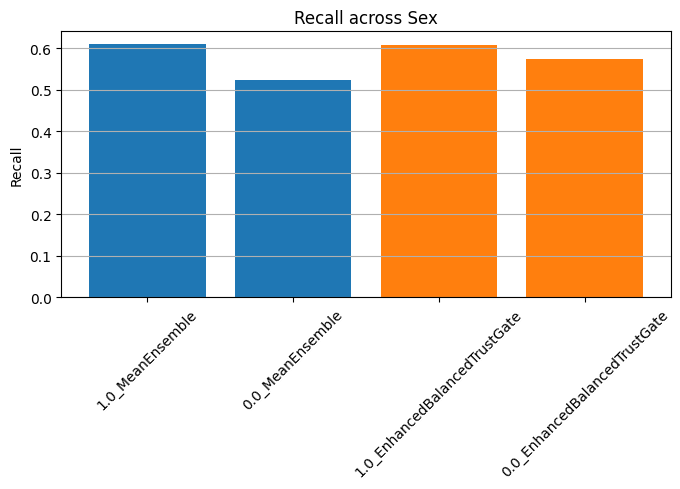

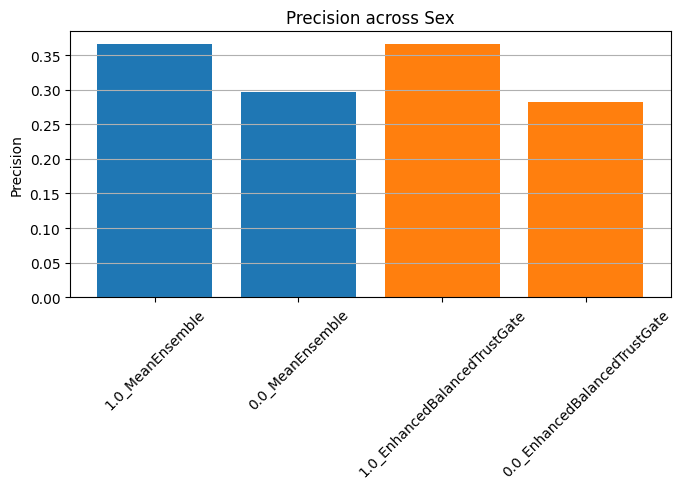

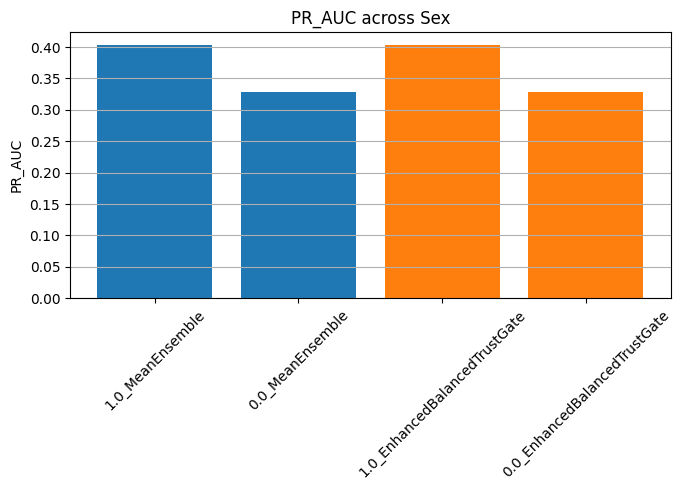

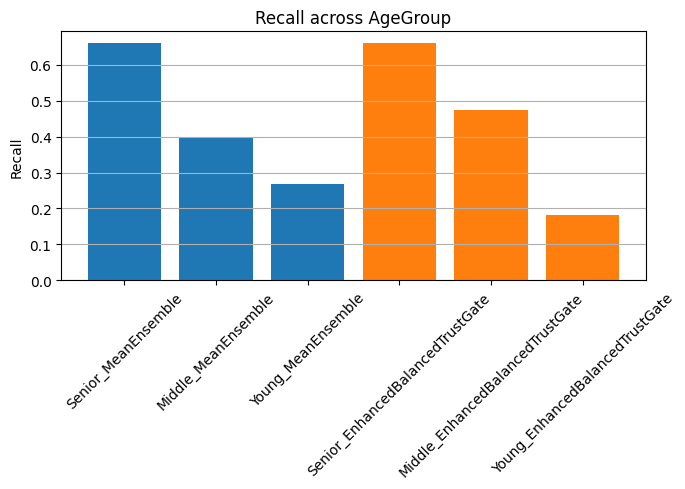

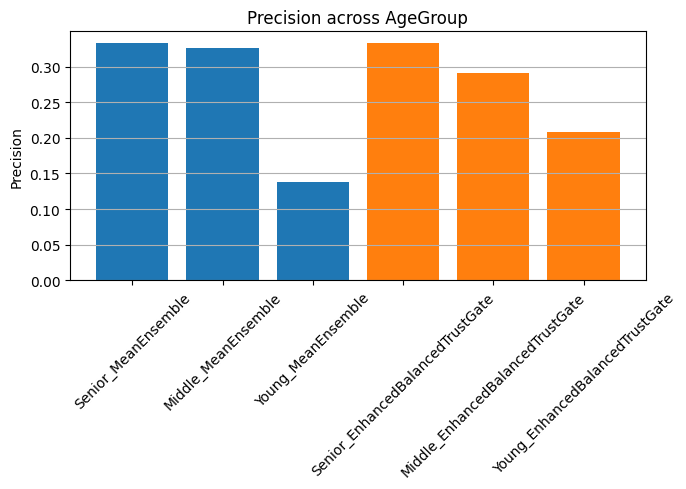

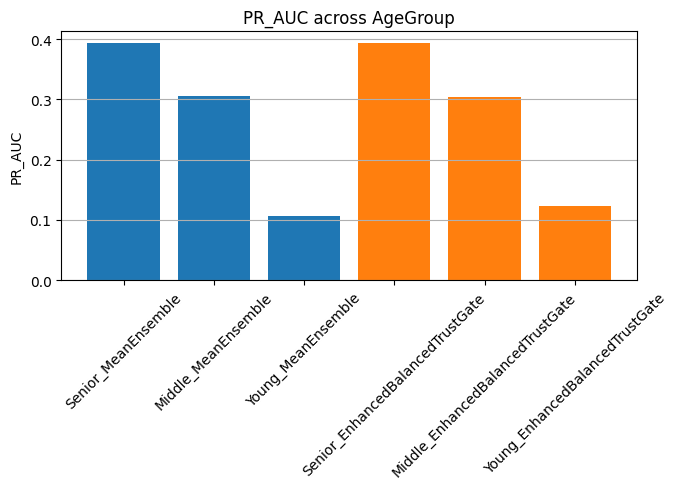


===== Module 12 Complete =====

Group metrics:


,group_col,group,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,PosRate,N
0,Sex,1.0,MeanEnsemble,0.403609,0.839603,0.086821,0.283220,0.007117,0.365393,0.609971,0.457017,0.823765,0.376469,0.202977,22436
1,Sex,0.0,MeanEnsemble,0.328396,0.851629,0.056491,0.198439,0.003525,0.296797,0.524135,0.378988,0.875512,0.331468,0.127986,28300
2,Sex,1.0,EnhancedBalancedTrustGate,0.403030,0.839465,0.086833,0.283284,0.007409,0.366064,0.608138,0.457025,0.824300,0.376360,0.201997,22436
3,Sex,0.0,EnhancedBalancedTrustGate,0.328736,0.851694,0.056467,0.198407,0.003231,0.282833,0.574354,0.379022,0.863604,0.337049,0.147173,28300
4,AgeGroup,Senior,MeanEnsemble,0.393521,0.787533,0.110572,0.356049,0.005454,0.332926,0.659946,0.442582,0.745189,0.329436,0.303844,24269



Disparity summary:


,group_col,model,metric,max,min,gap,std
0,AgeGroup,EnhancedBalancedTrustGate,PR_AUC,0.393203,0.123679,0.269524,0.112041
1,AgeGroup,MeanEnsemble,PR_AUC,0.393521,0.106022,0.287498,0.120346
2,Sex,EnhancedBalancedTrustGate,PR_AUC,0.403030,0.328736,0.074294,0.037147
3,Sex,MeanEnsemble,PR_AUC,0.403609,0.328396,0.075214,0.037607
4,AgeGroup,EnhancedBalancedTrustGate,Recall,0.659677,0.182927,0.476751,0.196145



Saved:
- module12_group_metrics.csv
- module12_disparity_summary.csv
- fairness plots (Sex / AgeGroup)


In [36]:
# ============================================================
# Module 12 — Fairness Evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

print("===== Module 12: Fairness Evaluation =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE72_META_HOLD",
    "MODULE92_PRED_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "X_test_df",
    "TAB_DIR",
    "FIG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
hold_meta = MODULE72_META_HOLD.copy()
y_true = hold_meta["y_true"].values.astype(int)

mean_pred = hold_meta[FINAL_SELECTED_EXPERTS].mean(axis=1).values.astype(float)
gate_pred = np.asarray(MODULE92_PRED_HOLD, dtype=float)

# attach sensitive attributes
df = pd.DataFrame({
    "y_true": y_true,
    "mean_pred": mean_pred,
    "gate_pred": gate_pred,
})

# from original dataset
df["Sex"] = X_test_df["Sex"].values

# age grouping (optional but important)
if "Age" in X_test_df.columns:
    df["AgeGroup"] = pd.cut(
        X_test_df["Age"],
        bins=[0, 4, 8, 13],
        labels=["Young", "Middle", "Senior"]
    )
elif "AgeCategory" in X_test_df.columns:
    df["AgeGroup"] = X_test_df["AgeCategory"]

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs(p, eps=1e-8):
    return np.clip(np.asarray(p, dtype=float), eps, 1 - eps)

def compute_ece(y, p, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(p, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y[mask])
        conf = np.mean(p[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y))
    return float(ece)

def best_f1_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 181)
    best_f1, best_thr = -1, 0.5
    for t in grid:
        f1 = f1_score(y, (p >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_thr = f1, t
    return best_thr

def compute_metrics(y, p):
    p = clip_probs(p)
    thr = best_f1_threshold(y, p)
    y_hat = (p >= thr).astype(int)

    return {
        "PR_AUC": average_precision_score(y, p),
        "ROC_AUC": roc_auc_score(y, p),
        "Brier": brier_score_loss(y, p),
        "NLL": log_loss(y, p),
        "ECE": compute_ece(y, p),
        "Precision": precision_score(y, y_hat, zero_division=0),
        "Recall": recall_score(y, y_hat, zero_division=0),
        "F1": f1_score(y, y_hat, zero_division=0),
        "Accuracy": accuracy_score(y, y_hat),
        "MCC": matthews_corrcoef(y, y_hat) if len(np.unique(y_hat)) > 1 else 0.0,
        "PosRate": np.mean(y_hat),
        "N": len(y),
    }

# ------------------------------------------------------------
# Subgroup evaluation
# ------------------------------------------------------------
def evaluate_by_group(df, group_col, model_col, model_name):
    rows = []

    for g in df[group_col].dropna().unique():
        sub = df[df[group_col] == g]

        if len(sub) < 50:
            continue

        metrics = compute_metrics(sub["y_true"].values, sub[model_col].values)

        row = {
            "group_col": group_col,
            "group": g,
            "model": model_name,
            **metrics
        }
        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Run fairness evaluation
# ------------------------------------------------------------
group_cols = ["Sex"]
if "AgeGroup" in df.columns:
    group_cols.append("AgeGroup")

all_results = []

for gcol in group_cols:
    all_results.append(evaluate_by_group(df, gcol, "mean_pred", "MeanEnsemble"))
    all_results.append(evaluate_by_group(df, gcol, "gate_pred", "EnhancedBalancedTrustGate"))

MODULE12_GROUP_METRICS = pd.concat(all_results, axis=0, ignore_index=True)
MODULE12_GROUP_METRICS.to_csv(TAB_DIR / "module12_group_metrics.csv", index=False)

# ------------------------------------------------------------
# Disparity summary
# ------------------------------------------------------------
def compute_disparity(df, metric):
    grouped = df.groupby(["group_col", "model"])
    rows = []

    for (gcol, model), sub in grouped:
        vals = sub[metric].values
        row = {
            "group_col": gcol,
            "model": model,
            "metric": metric,
            "max": np.max(vals),
            "min": np.min(vals),
            "gap": np.max(vals) - np.min(vals),
            "std": np.std(vals),
        }
        rows.append(row)

    return pd.DataFrame(rows)

metrics_to_check = ["PR_AUC", "Recall", "Precision", "F1", "ECE", "Brier"]

disp_tables = []
for m in metrics_to_check:
    disp_tables.append(compute_disparity(MODULE12_GROUP_METRICS, m))

MODULE12_DISPARITY = pd.concat(disp_tables, axis=0, ignore_index=True)
MODULE12_DISPARITY.to_csv(TAB_DIR / "module12_disparity_summary.csv", index=False)

# ------------------------------------------------------------
# Visualization (publication-ready)
# ------------------------------------------------------------
for gcol in group_cols:
    for metric in ["Recall", "Precision", "PR_AUC"]:
        plt.figure(figsize=(7, 5))

        sub = MODULE12_GROUP_METRICS[MODULE12_GROUP_METRICS["group_col"] == gcol]

        for model in sub["model"].unique():
            s = sub[sub["model"] == model]
            plt.bar(
                s["group"].astype(str) + "_" + model,
                s[metric],
                label=model
            )

        plt.title(f"{metric} across {gcol}")
        plt.xticks(rotation=45)
        plt.ylabel(metric)
        plt.grid(True, axis="y")
        plt.tight_layout()

        fname = f"module12_{gcol}_{metric}.png"
        plt.savefig(FIG_DIR / fname, dpi=300, bbox_inches="tight")
        plt.show()

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
print("\n===== Module 12 Complete =====")

print("\nGroup metrics:")
display(MODULE12_GROUP_METRICS.head())

print("\nDisparity summary:")
display(MODULE12_DISPARITY.head())

print("\nSaved:")
print("- module12_group_metrics.csv")
print("- module12_disparity_summary.csv")
print("- fairness plots (Sex / AgeGroup)")

In [37]:
# ============================================================
# Module 13 — Fairness-Aware Trust Regularization
#
# Goal:
#   Fine-tune the enhanced trust-aware gate with a fairness term
#   so that subgroup recall disparity is reduced without
#   materially hurting predictive performance.
#
# Uses:
#   - MODULE72_META_OOF
#   - MODULE72_META_HOLD
#
# Main fairness target:
#   - Sex-based recall parity on OOF/dev
#
# Outputs:
#   - MODULE13_RESULTS
#   - MODULE13_COMPARE_DF
#   - MODULE13_FAIRNESS_TABLE
#   - MODULE13_GATE_WEIGHTS_OOF / HOLD
#   - MODULE13_PRED_OOF / HOLD
# ============================================================

import copy
import json
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef
)

print("===== Module 13: Fairness-Aware Trust Regularization =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE72_META_OOF",
    "MODULE72_META_HOLD",
    "FINAL_SELECTED_EXPERTS",
    "X_dev_df",
    "X_test_df",
    "TAB_DIR",
    "PRED_DIR",
    "LOG_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

if "Sex" not in X_dev_df.columns or "Sex" not in X_test_df.columns:
    raise ValueError("Sex column is required for fairness-aware training.")

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
USE_GPU = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count()
PRIMARY_DEVICE = "cuda:0" if USE_GPU else "cpu"

print("CUDA available :", USE_GPU)
print("GPU count      :", N_GPUS)
print("Primary device :", PRIMARY_DEVICE)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
MODULE13_CFG = {
    "hidden_dims": (96, 48, 24),
    "dropout": 0.10,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "epochs": 45,
    "batch_size": 2048,
    "patience": 8,

    # regularization
    "lambda_entropy": 0.006,
    "lambda_consistency": 0.050,
    "lambda_robust_prior": 0.008,
    "lambda_anti_dom": 0.012,
    "lambda_sparse_peak": 0.004,

    # fairness
    "lambda_fair": 0.120,
    "fair_temperature": 18.0,
    "fairness_target": "sex_recall_parity",

    # conditional robust prior
    "robust_gap_activation_threshold": 0.10,

    # noise
    "meta_noise_std": 0.015,
    "expert_noise_std": 0.008,

    # thresholding
    "threshold_mode": "f1",
}

with open(LOG_DIR / "module13_config.json", "w", encoding="utf-8") as f:
    json.dump(MODULE13_CFG, f, indent=2)

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
oof_df = MODULE72_META_OOF.copy()
hold_df = MODULE72_META_HOLD.copy()

experts = FINAL_SELECTED_EXPERTS
y_oof = oof_df["y_true"].values.astype(int)
y_hold = hold_df["y_true"].values.astype(int)

sex_oof = X_dev_df["Sex"].values.astype(int)
sex_hold = X_test_df["Sex"].values.astype(int)

# ------------------------------------------------------------
# Feature selection
# ------------------------------------------------------------
non_feature_cols = set(experts + ["y_true"])
meta_feature_cols = [c for c in oof_df.columns if c not in non_feature_cols]

print("Experts:", experts)
print("Number of meta features:", len(meta_feature_cols))

P_oof = oof_df[experts].values.astype(np.float32)
P_hold = hold_df[experts].values.astype(np.float32)

X_meta_oof = oof_df[meta_feature_cols].values.astype(np.float32)
X_meta_hold = hold_df[meta_feature_cols].values.astype(np.float32)

# scale gate inputs
scaler = StandardScaler()
X_meta_oof_scaled = scaler.fit_transform(X_meta_oof).astype(np.float32)
X_meta_hold_scaled = scaler.transform(X_meta_hold).astype(np.float32)

# expert indices
ROBUST_EXPERT_NAME = "MLP_FGSM_Moderate_E010"
robust_idx = experts.index(ROBUST_EXPERT_NAME) if ROBUST_EXPERT_NAME in experts else None
robust_gap_idx = meta_feature_cols.index("robust_gap") if "robust_gap" in meta_feature_cols else None
sens_mean_idx = meta_feature_cols.index("sensitivity_mean_abs") if "sensitivity_mean_abs" in meta_feature_cols else None
sens_max_idx = meta_feature_cols.index("sensitivity_max_abs") if "sensitivity_max_abs" in meta_feature_cols else None

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def clip_probs_local(p, eps=1e-8):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, eps, 1 - eps)

def compute_ece_local(y_true, prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    prob = clip_probs_local(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(prob, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for i in range(n_bins):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        acc = np.mean(y_true[mask])
        conf = np.mean(prob[mask])
        ece += np.abs(acc - conf) * (mask.sum() / len(y_true))
    return float(ece)

def best_f1_threshold(y_true, p, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_f1 = -1.0
    for thr in grid:
        f1 = f1_score(y_true, (p >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, float(best_f1)

def compute_metrics_local(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs_local(p)
    y_hat = (p >= threshold).astype(int)

    return {
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(compute_ece_local(y_true, p)),
        "Precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "Recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "F1": float(f1_score(y_true, y_hat, zero_division=0)),
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "MCC": float(matthews_corrcoef(y_true, y_hat)) if len(np.unique(y_hat)) > 1 else 0.0,
        "Threshold": float(threshold),
        "PredPosRate": float(np.mean(y_hat)),
        "MeanProb": float(np.mean(p)),
    }

def subgroup_metrics_binary(y_true, p, threshold, group_values):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs_local(p)
    y_hat = (p >= threshold).astype(int)
    g = np.asarray(group_values)

    rows = []
    for gv in sorted(np.unique(g)):
        mask = g == gv
        yt = y_true[mask]
        ph = p[mask]
        yh = y_hat[mask]

        if len(yt) == 0:
            continue

        row = {
            "group": gv,
            "N": int(mask.sum()),
            "PositiveRate": float(np.mean(yt)),
            "PR_AUC": float(average_precision_score(yt, ph)) if len(np.unique(yt)) > 1 else np.nan,
            "ROC_AUC": float(roc_auc_score(yt, ph)) if len(np.unique(yt)) > 1 else np.nan,
            "Brier": float(brier_score_loss(yt, ph)),
            "NLL": float(log_loss(yt, ph, labels=[0, 1])),
            "ECE": float(compute_ece_local(yt, ph)),
            "Precision": float(precision_score(yt, yh, zero_division=0)),
            "Recall": float(recall_score(yt, yh, zero_division=0)),
            "F1": float(f1_score(yt, yh, zero_division=0)),
            "Accuracy": float(accuracy_score(yt, yh)),
            "MCC": float(matthews_corrcoef(yt, yh)) if len(np.unique(yh)) > 1 else 0.0,
        }
        rows.append(row)

    return pd.DataFrame(rows)

def disparity_from_subgroup_df(df):
    out = {}
    for metric in ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "Recall", "Precision", "F1", "Accuracy", "MCC"]:
        vals = df[metric].dropna().values.astype(float)
        out[f"{metric}_Gap"] = float(np.max(vals) - np.min(vals)) if len(vals) > 0 else np.nan
    return pd.DataFrame([out])

def gate_entropy_np(W):
    W = np.asarray(W, dtype=float)
    W = np.clip(W, 1e-8, 1.0)
    return float(np.mean(-(W * np.log(W)).sum(axis=1)))

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------
class FairTrustGate(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(96, 48, 24), dropout=0.10):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        layers.append(nn.Linear(prev, n_experts))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        logits = self.net(x)
        return torch.softmax(logits, dim=1)

def build_gate(input_dim, n_experts):
    model = FairTrustGate(
        input_dim=input_dim,
        n_experts=n_experts,
        hidden_dims=MODULE13_CFG["hidden_dims"],
        dropout=MODULE13_CFG["dropout"],
    )
    if USE_GPU:
        model = model.to(PRIMARY_DEVICE)
        if N_GPUS > 1:
            model = nn.DataParallel(model)
    return model

# ------------------------------------------------------------
# Tensors
# ------------------------------------------------------------
X_t = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
P_t = torch.tensor(P_oof, dtype=torch.float32)
y_t = torch.tensor(y_oof.reshape(-1, 1), dtype=torch.float32)
sex_t = torch.tensor(sex_oof, dtype=torch.long)

if USE_GPU:
    X_t = X_t.to(PRIMARY_DEVICE)
    P_t = P_t.to(PRIMARY_DEVICE)
    y_t = y_t.to(PRIMARY_DEVICE)
    sex_t = sex_t.to(PRIMARY_DEVICE)

# ------------------------------------------------------------
# Train / validation split
# ------------------------------------------------------------
idx_all = np.arange(len(y_oof))
tr_idx, es_idx = train_test_split(
    idx_all,
    test_size=0.15,
    stratify=y_oof,
    random_state=42,
)

X_tr = X_t[tr_idx]
P_tr = P_t[tr_idx]
y_tr = y_t[tr_idx]
sex_tr = sex_t[tr_idx]

X_es = X_t[es_idx]
P_es = P_t[es_idx]
y_es = y_t[es_idx]
sex_es = sex_t[es_idx]

train_ds = torch.utils.data.TensorDataset(X_tr, P_tr, y_tr, sex_tr)
train_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=MODULE13_CFG["batch_size"],
    shuffle=True,
    drop_last=False,
)

# ------------------------------------------------------------
# Loss pieces
# ------------------------------------------------------------
bce = nn.BCELoss()
mse = nn.MSELoss()

def robust_prior_term_enhanced(W, X_meta_batch):
    if robust_idx is None or robust_gap_idx is None:
        return torch.tensor(0.0, device=W.device)

    robust_gap = X_meta_batch[:, robust_gap_idx]
    robust_act = torch.relu(robust_gap - MODULE13_CFG["robust_gap_activation_threshold"])

    if sens_mean_idx is not None:
        sens_signal = torch.sigmoid(X_meta_batch[:, sens_mean_idx])
    else:
        sens_signal = torch.zeros_like(robust_gap)

    if sens_max_idx is not None:
        sens_signal = 0.5 * sens_signal + 0.5 * torch.sigmoid(X_meta_batch[:, sens_max_idx])

    trigger = 0.7 * robust_act + 0.3 * sens_signal
    robust_weight = W[:, robust_idx]

    return -torch.mean(trigger * robust_weight)

def anti_dominance_term(W):
    max_weight = torch.max(W, dim=1)[0]
    return torch.mean(max_weight ** 2)

def sparse_peak_term(W):
    return -torch.mean(torch.sum(W ** 2, dim=1))

def soft_recall(probs, labels, temperature=18.0, threshold=0.5):
    soft_pred = torch.sigmoid(temperature * (probs - threshold))
    positives = labels.sum()
    if positives.item() < 1:
        return torch.tensor(0.0, device=probs.device)
    return (soft_pred * labels).sum() / (positives + 1e-8)

def fairness_recall_penalty(probs, labels, groups):
    mask0 = groups == 0
    mask1 = groups == 1

    if mask0.sum().item() == 0 or mask1.sum().item() == 0:
        return torch.tensor(0.0, device=probs.device)

    y0 = labels[mask0].reshape(-1)
    y1 = labels[mask1].reshape(-1)
    p0 = probs[mask0].reshape(-1)
    p1 = probs[mask1].reshape(-1)

    if y0.sum().item() < 1 or y1.sum().item() < 1:
        return torch.tensor(0.0, device=probs.device)

    rec0 = soft_recall(p0, y0, temperature=MODULE13_CFG["fair_temperature"])
    rec1 = soft_recall(p1, y1, temperature=MODULE13_CFG["fair_temperature"])

    return (rec0 - rec1) ** 2

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------
gate = build_gate(input_dim=X_meta_oof_scaled.shape[1], n_experts=len(experts))
optimizer = torch.optim.Adam(
    gate.parameters(),
    lr=MODULE13_CFG["lr"],
    weight_decay=MODULE13_CFG["weight_decay"],
)

best_state = copy.deepcopy(gate.state_dict())
best_es_objective = np.inf
no_improve = 0
loss_history = []

for epoch in range(MODULE13_CFG["epochs"]):
    gate.train()
    epoch_losses = []

    for xb, pb, yb, gb in train_loader:
        optimizer.zero_grad()

        # clean path
        W_clean = gate(xb)
        fused_clean = torch.sum(W_clean * pb, dim=1, keepdim=True)
        fused_clean = torch.clamp(fused_clean, 1e-7, 1 - 1e-7)

        loss_pred = bce(fused_clean, yb)

        # noisy path
        xb_noise = xb + MODULE13_CFG["meta_noise_std"] * torch.randn_like(xb)
        pb_noise = torch.clamp(
            pb + MODULE13_CFG["expert_noise_std"] * torch.randn_like(pb),
            1e-7, 1 - 1e-7
        )

        W_noisy = gate(xb_noise)
        fused_noisy = torch.sum(W_noisy * pb_noise, dim=1, keepdim=True)
        fused_noisy = torch.clamp(fused_noisy, 1e-7, 1 - 1e-7)

        loss_consistency = mse(fused_clean, fused_noisy)

        entropy_term = -torch.mean(
            torch.sum(W_clean * torch.log(torch.clamp(W_clean, 1e-8, 1.0)), dim=1)
        )

        loss_robust_prior = robust_prior_term_enhanced(W_clean, xb)
        loss_anti_dom = anti_dominance_term(W_clean)
        loss_sparse_peak = sparse_peak_term(W_clean)
        loss_fair = fairness_recall_penalty(fused_clean.reshape(-1), yb.reshape(-1), gb)

        loss = (
            loss_pred
            - MODULE13_CFG["lambda_entropy"] * entropy_term
            + MODULE13_CFG["lambda_consistency"] * loss_consistency
            + MODULE13_CFG["lambda_robust_prior"] * loss_robust_prior
            + MODULE13_CFG["lambda_anti_dom"] * loss_anti_dom
            + MODULE13_CFG["lambda_sparse_peak"] * loss_sparse_peak
            + MODULE13_CFG["lambda_fair"] * loss_fair
        )

        loss.backward()
        optimizer.step()

        epoch_losses.append({
            "loss_total": float(loss.detach().cpu().item()),
            "loss_pred": float(loss_pred.detach().cpu().item()),
            "loss_fair": float(loss_fair.detach().cpu().item()),
            "loss_consistency": float(loss_consistency.detach().cpu().item()),
        })

    # early stopping objective = Brier + small fairness term on ES split
    gate.eval()
    with torch.no_grad():
        W_es = gate(X_es)
        p_es = torch.sum(W_es * P_es, dim=1).detach().cpu().numpy()
        p_es = clip_probs_local(p_es)
        es_brier = float(brier_score_loss(y_oof[es_idx], p_es))

        # fairness on ES split at threshold from ES itself
        es_thr, _ = best_f1_threshold(y_oof[es_idx], p_es)
        fair_es_df = subgroup_metrics_binary(y_oof[es_idx], p_es, es_thr, sex_oof[es_idx])
        fair_gap = float(disparity_from_subgroup_df(fair_es_df)["Recall_Gap"].iloc[0])

        es_objective = es_brier + 0.05 * fair_gap

    if es_objective < best_es_objective:
        best_es_objective = es_objective
        best_state = copy.deepcopy(gate.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    epoch_mean = pd.DataFrame(epoch_losses).mean().to_dict()
    loss_history.append({
        "epoch": epoch + 1,
        "train_loss_mean": float(np.mean([x["loss_total"] for x in epoch_losses])),
        "train_loss_pred_mean": float(epoch_mean["loss_pred"]),
        "train_loss_fair_mean": float(epoch_mean["loss_fair"]),
        "es_brier": es_brier,
        "es_recall_gap": fair_gap,
        "es_objective": es_objective,
    })

    print(
        f"[Epoch {epoch+1:02d}] "
        f"train_loss={np.mean([x['loss_total'] for x in epoch_losses]):.6f} | "
        f"es_brier={es_brier:.6f} | "
        f"es_recall_gap={fair_gap:.6f} | "
        f"es_obj={es_objective:.6f}"
    )

    if no_improve >= MODULE13_CFG["patience"]:
        print("Early stopping triggered.")
        break

gate.load_state_dict(best_state)

# ------------------------------------------------------------
# Predict OOF / HOLD
# ------------------------------------------------------------
gate.eval()

with torch.no_grad():
    X_oof_all = torch.tensor(X_meta_oof_scaled, dtype=torch.float32)
    P_oof_all = torch.tensor(P_oof, dtype=torch.float32)
    X_hold_all = torch.tensor(X_meta_hold_scaled, dtype=torch.float32)
    P_hold_all = torch.tensor(P_hold, dtype=torch.float32)

    if USE_GPU:
        X_oof_all = X_oof_all.to(PRIMARY_DEVICE)
        P_oof_all = P_oof_all.to(PRIMARY_DEVICE)
        X_hold_all = X_hold_all.to(PRIMARY_DEVICE)
        P_hold_all = P_hold_all.to(PRIMARY_DEVICE)

    W_oof = gate(X_oof_all).detach().cpu().numpy()
    W_hold = gate(X_hold_all).detach().cpu().numpy()

    pred_oof = np.sum(W_oof * P_oof, axis=1)
    pred_hold = np.sum(W_hold * P_hold, axis=1)

pred_oof = clip_probs_local(pred_oof)
pred_hold = clip_probs_local(pred_hold)

# ------------------------------------------------------------
# Thresholding
# ------------------------------------------------------------
locked_thr, best_f1 = best_f1_threshold(y_oof, pred_oof)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
MODULE13_RESULTS = pd.DataFrame([
    {
        "model": "FairTrustGate",
        "split": "OOF",
        **compute_metrics_local(y_oof, pred_oof, locked_thr)
    },
    {
        "model": "FairTrustGate",
        "split": "HOLDOUT",
        **compute_metrics_local(y_hold, pred_hold, locked_thr)
    },
])

# ------------------------------------------------------------
# Fairness tables
# ------------------------------------------------------------
fair_oof_df = subgroup_metrics_binary(y_oof, pred_oof, locked_thr, sex_oof)
fair_hold_df = subgroup_metrics_binary(y_hold, pred_hold, locked_thr, sex_hold)

fair_oof_gap_df = disparity_from_subgroup_df(fair_oof_df)
fair_hold_gap_df = disparity_from_subgroup_df(fair_hold_df)

MODULE13_FAIRNESS_TABLE = pd.concat([
    pd.DataFrame([{"split": "OOF", **fair_oof_gap_df.iloc[0].to_dict()}]),
    pd.DataFrame([{"split": "HOLDOUT", **fair_hold_gap_df.iloc[0].to_dict()}]),
], axis=0, ignore_index=True)

# ------------------------------------------------------------
# Gating diagnostics
# ------------------------------------------------------------
weights_df = pd.DataFrame({
    "expert": experts,
    "mean_weight_oof": W_oof.mean(axis=0),
    "mean_weight_holdout": W_hold.mean(axis=0),
})

gate_summary_df = pd.DataFrame([{
    "gate_entropy_oof": gate_entropy_np(W_oof),
    "gate_entropy_holdout": gate_entropy_np(W_hold),
    "max_weight_mean_oof": float(np.mean(np.max(W_oof, axis=1))),
    "max_weight_mean_holdout": float(np.mean(np.max(W_hold, axis=1))),
    "weight_std_mean_oof": float(np.mean(np.std(W_oof, axis=1))),
    "weight_std_mean_holdout": float(np.mean(np.std(W_hold, axis=1))),
}])

loss_df = pd.DataFrame(loss_history)

# ------------------------------------------------------------
# Compare against existing models if available
# ------------------------------------------------------------
compare_rows = []

if "MODULE92_RESULTS" in globals():
    hold92 = MODULE92_RESULTS[MODULE92_RESULTS["split"] == "HOLDOUT"].iloc[0]
    compare_rows.append({
        "model": "EnhancedBalancedTrustGate",
        "PR_AUC": hold92["PR_AUC"],
        "ROC_AUC": hold92["ROC_AUC"],
        "Brier": hold92["Brier"],
        "NLL": hold92["NLL"],
        "ECE": hold92["ECE"],
        "F1": hold92["F1"],
        "MCC": hold92["MCC"],
    })

hold13 = MODULE13_RESULTS[MODULE13_RESULTS["split"] == "HOLDOUT"].iloc[0]
compare_rows.append({
    "model": "FairTrustGate",
    "PR_AUC": hold13["PR_AUC"],
    "ROC_AUC": hold13["ROC_AUC"],
    "Brier": hold13["Brier"],
    "NLL": hold13["NLL"],
    "ECE": hold13["ECE"],
    "F1": hold13["F1"],
    "MCC": hold13["MCC"],
})

MODULE13_COMPARE_DF = pd.DataFrame(compare_rows)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
pred_oof_df = pd.DataFrame({
    "pred": pred_oof,
    "y_true": y_oof,
    "Sex": sex_oof,
})
pred_hold_df = pd.DataFrame({
    "pred": pred_hold,
    "y_true": y_hold,
    "Sex": sex_hold,
})

weights_df.to_csv(TAB_DIR / "module13_gate_weights.csv", index=False)
gate_summary_df.to_csv(TAB_DIR / "module13_gate_summary.csv", index=False)
loss_df.to_csv(TAB_DIR / "module13_loss_history.csv", index=False)
MODULE13_RESULTS.to_csv(TAB_DIR / "module13_results.csv", index=False)
MODULE13_COMPARE_DF.to_csv(TAB_DIR / "module13_compare.csv", index=False)
MODULE13_FAIRNESS_TABLE.to_csv(TAB_DIR / "module13_fairness_gap_summary.csv", index=False)
fair_oof_df.to_csv(TAB_DIR / "module13_fairness_oof_by_sex.csv", index=False)
fair_hold_df.to_csv(TAB_DIR / "module13_fairness_holdout_by_sex.csv", index=False)

pred_oof_df.to_csv(PRED_DIR / "module13_pred_oof.csv", index=False)
pred_hold_df.to_csv(PRED_DIR / "module13_pred_holdout.csv", index=False)

# ------------------------------------------------------------
# Expose
# ------------------------------------------------------------
MODULE13_PRED_OOF = pred_oof.copy()
MODULE13_PRED_HOLD = pred_hold.copy()
MODULE13_GATE_WEIGHTS_OOF = W_oof.copy()
MODULE13_GATE_WEIGHTS_HOLD = W_hold.copy()
MODULE13_GATE_MODEL = gate
MODULE13_LOSS_HISTORY = loss_df.copy()
MODULE13_GATE_SUMMARY = gate_summary_df.copy()
MODULE13_FAIR_OOF = fair_oof_df.copy()
MODULE13_FAIR_HOLD = fair_hold_df.copy()
MODULE13_FAIR_OOF_GAP = fair_oof_gap_df.copy()
MODULE13_FAIR_HOLD_GAP = fair_hold_gap_df.copy()

print("\n===== Module 13 Complete =====")
print("\nResults:")
display(MODULE13_RESULTS)

print("\nComparison:")
display(MODULE13_COMPARE_DF)

print("\nFairness gap summary:")
display(MODULE13_FAIRNESS_TABLE)

print("\nHoldout fairness by Sex:")
display(fair_hold_df)

print("\nAverage gate weights:")
display(weights_df)

print("\nSaved:")
print("- module13_results.csv")
print("- module13_compare.csv")
print("- module13_fairness_gap_summary.csv")
print("- module13_fairness_oof_by_sex.csv")
print("- module13_fairness_holdout_by_sex.csv")
print("- module13_gate_weights.csv")
print("- module13_gate_summary.csv")
print("- module13_loss_history.csv")
print("- module13_pred_oof.csv")
print("- module13_pred_holdout.csv")

===== Module 13: Fairness-Aware Trust Regularization =====
CUDA available : True
GPU count      : 2
Primary device : cuda:0
Experts: ['HistGradientBoosting', 'MLP_Sklearn', 'DeepFM', 'MLP_FGSM_Moderate_E010']
Number of meta features: 29
[Epoch 01] train_loss=0.226838 | es_brier=0.069185 | es_recall_gap=0.180957 | es_obj=0.078233
[Epoch 02] train_loss=0.226548 | es_brier=0.069153 | es_recall_gap=0.173948 | es_obj=0.077851
[Epoch 03] train_loss=0.226524 | es_brier=0.069140 | es_recall_gap=0.166584 | es_obj=0.077469
[Epoch 04] train_loss=0.226584 | es_brier=0.069127 | es_recall_gap=0.170423 | es_obj=0.077648
[Epoch 05] train_loss=0.226163 | es_brier=0.069113 | es_recall_gap=0.169966 | es_obj=0.077612
[Epoch 06] train_loss=0.226139 | es_brier=0.069108 | es_recall_gap=0.176398 | es_obj=0.077928
[Epoch 07] train_loss=0.226342 | es_brier=0.069101 | es_recall_gap=0.169966 | es_obj=0.077600
[Epoch 08] train_loss=0.226027 | es_brier=0.069095 | es_recall_gap=0.168284 | es_obj=0.077509
[Epoch 09] 

,model,split,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb
0,FairTrustGate,OOF,0.383742,0.851753,0.069530,0.234817,0.001426,0.358151,0.513917,0.422122,0.867476,0.357249,0.225,0.135146,0.094395
1,FairTrustGate,HOLDOUT,0.373581,0.850863,0.069897,0.235920,0.003408,0.355722,0.516426,0.421268,0.866347,0.356354,0.225,0.136747,0.094902



Comparison:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,F1,MCC
0,EnhancedBalancedTrustGate,0.373060,0.850841,0.069895,0.23594,0.003299,0.419988,0.354651
1,FairTrustGate,0.373581,0.850863,0.069897,0.23592,0.003408,0.421268,0.356354



Fairness gap summary:


...


Holdout fairness by Sex:


,group,N,PositiveRate,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC
0,0,28300,0.072473,0.328083,0.851646,0.056494,0.198444,0.003215,0.336675,0.392979,0.362655,0.899894,0.309774
1,1,22436,0.121590,0.403752,0.839620,0.086802,0.283192,0.007718,0.365757,0.609238,0.457096,0.824033,0.376511



Average gate weights:


,expert,mean_weight_oof,mean_weight_holdout
0,HistGradientBoosting,0.255810,0.248277
1,MLP_Sklearn,0.235434,0.246966
2,DeepFM,0.238313,0.240547
3,MLP_FGSM_Moderate_E010,0.270127,0.264187



Saved:
- module13_results.csv
- module13_compare.csv
- module13_fairness_gap_summary.csv
- module13_fairness_oof_by_sex.csv
- module13_fairness_holdout_by_sex.csv
- module13_gate_weights.csv
- module13_gate_summary.csv
- module13_loss_history.csv
- module13_pred_oof.csv
- module13_pred_holdout.csv


In [38]:
# ============================================================
# Module 14 — Final Results Package for Paper
# ============================================================

import numpy as np
import pandas as pd

print("===== Module 14: Final Results Package =====")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required = [
    "MODULE71_BASELINE_COMPARE",
    "MODULE92_RESULTS",
    "MODULE13_RESULTS",
    "MODULE12_DISPARITY",
    "MODULE101_ROBUSTNESS_DF",
    "MODULE11_SUMMARY_DF",
    "TAB_DIR",
]
missing = [x for x in required if x not in globals()]
if missing:
    raise ValueError(f"Missing required inputs: {missing}")

# ------------------------------------------------------------
# 1. Main model comparison table
# ------------------------------------------------------------
baseline_df = MODULE71_BASELINE_COMPARE.copy()

main_keep = ["PerfWeightedMean", "MeanEnsemble", "MedianEnsemble"]
main_baselines = baseline_df[baseline_df["model"].isin(main_keep)].copy()

gate92_hold = MODULE92_RESULTS[MODULE92_RESULTS["split"] == "HOLDOUT"].iloc[0]
gate13_hold = MODULE13_RESULTS[MODULE13_RESULTS["split"] == "HOLDOUT"].iloc[0]

proposed_rows = pd.DataFrame([
    {
        "model": "EnhancedBalancedTrustGate",
        "HOLD_PR_AUC": gate92_hold["PR_AUC"],
        "HOLD_ROC_AUC": gate92_hold["ROC_AUC"],
        "HOLD_Brier": gate92_hold["Brier"],
        "HOLD_NLL": gate92_hold["NLL"],
        "HOLD_ECE": gate92_hold["ECE"],
        "HOLD_F1": gate92_hold["F1"],
        "HOLD_MCC": gate92_hold["MCC"],
        "HOLD_Threshold": gate92_hold["Threshold"],
    },
    {
        "model": "FairTrustGate",
        "HOLD_PR_AUC": gate13_hold["PR_AUC"],
        "HOLD_ROC_AUC": gate13_hold["ROC_AUC"],
        "HOLD_Brier": gate13_hold["Brier"],
        "HOLD_NLL": gate13_hold["NLL"],
        "HOLD_ECE": gate13_hold["ECE"],
        "HOLD_F1": gate13_hold["F1"],
        "HOLD_MCC": gate13_hold["MCC"],
        "HOLD_Threshold": gate13_hold["Threshold"],
    },
])

MODULE14_MAIN_TABLE = pd.concat([
    main_baselines[[
        "model", "HOLD_PR_AUC", "HOLD_ROC_AUC", "HOLD_Brier",
        "HOLD_NLL", "HOLD_ECE", "HOLD_F1", "HOLD_MCC", "HOLD_Threshold"
    ]],
    proposed_rows
], axis=0, ignore_index=True)

MODULE14_MAIN_TABLE = MODULE14_MAIN_TABLE.sort_values(
    ["HOLD_PR_AUC", "HOLD_ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. Fairness summary table
# ------------------------------------------------------------
fair_disp = MODULE12_DISPARITY.copy()

fair_keep_metrics = ["PR_AUC", "Recall", "Precision", "F1", "ECE", "Brier"]
fair_keep_models = ["MeanEnsemble", "EnhancedBalancedTrustAdaptiveGate", "EnhancedBalancedTrustGate"]

fair_summary = fair_disp[
    fair_disp["metric"].isin(fair_keep_metrics)
].copy()

# normalize model naming if needed
fair_summary["model"] = fair_summary["model"].replace({
    "EnhancedBalancedTrustAdaptiveGate": "EnhancedBalancedTrustGate"
})

MODULE14_FAIRNESS_TABLE = fair_summary[
    fair_summary["model"].isin(["MeanEnsemble", "EnhancedBalancedTrustGate"])
].copy().reset_index(drop=True)

# append module13 fairness-aware summary
if "MODULE13_FAIRNESS_TABLE" in globals():
    mod13_fair = MODULE13_FAIRNESS_TABLE.copy()
    mod13_hold = mod13_fair[mod13_fair["split"] == "HOLDOUT"].iloc[0].to_dict()
    add_rows = []
    for metric in ["PR_AUC", "Recall", "Precision", "F1", "ECE", "Brier"]:
        add_rows.append({
            "group_col": "Sex",
            "model": "FairTrustGate",
            "metric": metric,
            "max": np.nan,
            "min": np.nan,
            "gap": mod13_hold.get(f"{metric}_Gap", np.nan),
            "std": np.nan,
        })
    MODULE14_FAIRNESS_TABLE = pd.concat(
        [MODULE14_FAIRNESS_TABLE, pd.DataFrame(add_rows)],
        axis=0,
        ignore_index=True
    )

# ------------------------------------------------------------
# 3. Robustness summary table
# ------------------------------------------------------------
rob_df = MODULE101_ROBUSTNESS_DF.copy()

MODULE14_ROBUSTNESS_TABLE = pd.DataFrame([
    {
        "model": "MeanEnsemble",
        "avg_PR_AUC_drop": float(rob_df["mean_drop"].mean()),
        "worst_PR_AUC_drop": float(rob_df["mean_drop"].max()),
    },
    {
        "model": "BalancedTrustAdaptiveGate",
        "avg_PR_AUC_drop": float(rob_df["gate_drop"].mean()),
        "worst_PR_AUC_drop": float(rob_df["gate_drop"].max()),
    },
    {
        "model": "MLP_FGSM_Moderate_E010",
        "avg_PR_AUC_drop": float(rob_df["robust_drop"].mean()),
        "worst_PR_AUC_drop": float(rob_df["robust_drop"].max()),
    },
])

# rename for consistency
MODULE14_ROBUSTNESS_TABLE["model"] = MODULE14_ROBUSTNESS_TABLE["model"].replace({
    "BalancedTrustAdaptiveGate": "EnhancedBalancedTrustGate"
})

# ------------------------------------------------------------
# 4. Selective prediction summary
# ------------------------------------------------------------
sel_df = MODULE11_SUMMARY_DF.copy()

sel_df["model"] = sel_df["model"].replace({
    "BalancedTrustAdaptiveGate": "EnhancedBalancedTrustGate"
})

MODULE14_SELECTIVE_TABLE = sel_df[
    (sel_df["coverage"].round(3).isin([0.8, 0.9, 1.0])) &
    (sel_df["model"].isin(["MeanEnsemble", "EnhancedBalancedTrustGate"]))
].copy().reset_index(drop=True)

# ------------------------------------------------------------
# 5. Ablation table
# ------------------------------------------------------------
ablation_rows = []

# simple ensemble
mean_row = MODULE14_MAIN_TABLE[MODULE14_MAIN_TABLE["model"] == "MeanEnsemble"]
if len(mean_row):
    r = mean_row.iloc[0]
    ablation_rows.append({
        "variant": "Simple Ensemble",
        "model": "MeanEnsemble",
        "PR_AUC": r["HOLD_PR_AUC"],
        "ROC_AUC": r["HOLD_ROC_AUC"],
        "Brier": r["HOLD_Brier"],
        "ECE": r["HOLD_ECE"],
    })

# enhanced gate
ablation_rows.append({
    "variant": "Trust-Aware Adaptive Gating",
    "model": "EnhancedBalancedTrustGate",
    "PR_AUC": gate92_hold["PR_AUC"],
    "ROC_AUC": gate92_hold["ROC_AUC"],
    "Brier": gate92_hold["Brier"],
    "ECE": gate92_hold["ECE"],
})

# fairness extension
ablation_rows.append({
    "variant": "Fairness-Aware Trust Regularization",
    "model": "FairTrustGate",
    "PR_AUC": gate13_hold["PR_AUC"],
    "ROC_AUC": gate13_hold["ROC_AUC"],
    "Brier": gate13_hold["Brier"],
    "ECE": gate13_hold["ECE"],
})

MODULE14_ABLATION_TABLE = pd.DataFrame(ablation_rows)

# ------------------------------------------------------------
# 6. Save all
# ------------------------------------------------------------
MODULE14_MAIN_TABLE.to_csv(TAB_DIR / "module14_main_results_table.csv", index=False)
MODULE14_FAIRNESS_TABLE.to_csv(TAB_DIR / "module14_fairness_summary_table.csv", index=False)
MODULE14_ROBUSTNESS_TABLE.to_csv(TAB_DIR / "module14_robustness_summary_table.csv", index=False)
MODULE14_SELECTIVE_TABLE.to_csv(TAB_DIR / "module14_selective_prediction_table.csv", index=False)
MODULE14_ABLATION_TABLE.to_csv(TAB_DIR / "module14_ablation_table.csv", index=False)

print("\n===== Module 14 Complete =====")
print("\nMain results table:")
display(MODULE14_MAIN_TABLE)

print("\nFairness summary table:")
display(MODULE14_FAIRNESS_TABLE.head(12))

print("\nRobustness summary table:")
display(MODULE14_ROBUSTNESS_TABLE)

print("\nSelective prediction summary:")
display(MODULE14_SELECTIVE_TABLE)

print("\nAblation table:")
display(MODULE14_ABLATION_TABLE)

print("\nSaved:")
print("- module14_main_results_table.csv")
print("- module14_fairness_summary_table.csv")
print("- module14_robustness_summary_table.csv")
print("- module14_selective_prediction_table.csv")
print("- module14_ablation_table.csv")

===== Module 14: Final Results Package =====

===== Module 14 Complete =====

Main results table:


,model,HOLD_PR_AUC,HOLD_ROC_AUC,HOLD_Brier,HOLD_NLL,HOLD_ECE,HOLD_F1,HOLD_MCC,HOLD_Threshold
0,PerfWeightedMean,0.373615,0.850847,0.069903,0.235929,0.003026,0.423255,0.365505,0.190
1,MeanEnsemble,0.373614,0.850846,0.069903,0.235930,0.003047,0.423194,0.365440,0.190
2,FairTrustGate,0.373581,0.850863,0.069897,0.235920,0.003408,0.421268,0.356354,0.225
3,EnhancedBalancedTrustGate,0.373060,0.850841,0.069895,0.235940,0.003299,0.419988,0.354651,0.230
4,MedianEnsemble,0.372782,0.850661,0.069945,0.236062,0.003061,0.421392,0.357850,0.210



Fairness summary table:


,group_col,model,metric,max,min,gap,std
0,AgeGroup,EnhancedBalancedTrustGate,PR_AUC,0.393203,0.123679,0.269524,0.112041
1,AgeGroup,MeanEnsemble,PR_AUC,0.393521,0.106022,0.287498,0.120346
2,Sex,EnhancedBalancedTrustGate,PR_AUC,0.403030,0.328736,0.074294,0.037147
3,Sex,MeanEnsemble,PR_AUC,0.403609,0.328396,0.075214,0.037607
4,AgeGroup,EnhancedBalancedTrustGate,Recall,0.659677,0.182927,0.476751,0.196145
5,AgeGroup,MeanEnsemble,Recall,0.659946,0.268293,0.391654,0.163074
6,Sex,EnhancedBalancedTrustGate,Recall,0.608138,0.574354,0.033784,0.016892
7,Sex,MeanEnsemble,Recall,0.609971,0.524135,0.085836,0.042918
8,AgeGroup,EnhancedBalancedTrustGate,Precision,0.332836,0.208333,0.124503,0.051678
9,AgeGroup,MeanEnsemble,Precision,0.332926,0.138365,0.194562,0.090136



Robustness summary table:


...


Selective prediction summary:


,coverage,referral_rate,n_kept,n_referred,best_curve_f1,PR_AUC,ROC_AUC,Brier,NLL,ECE,Precision,Recall,F1,Accuracy,MCC,Threshold,PredPosRate,MeanProb,N,model
0,0.800004,0.199996,40589,10147,0.205246,0.137564,0.796133,0.037183,0.147579,0.002189,0.130273,0.483503,0.205246,0.846214,0.190621,0.100,0.152430,0.043182,40589,MeanEnsemble
1,0.800004,0.199996,40589,10147,0.206062,0.139160,0.796447,0.037287,0.147864,0.002083,0.128839,0.514354,0.206062,0.836729,0.195653,0.095,0.164453,0.043135,40589,EnhancedBalancedTrustGate
2,0.899992,0.100008,45662,5074,0.305840,0.239617,0.823186,0.052449,0.190391,0.002881,0.233028,0.444834,0.305840,0.873746,0.259267,0.165,0.119355,0.064322,45662,MeanEnsemble
3,0.899992,0.100008,45662,5074,0.308587,0.240257,0.823416,0.052525,0.190593,0.002903,0.231293,0.463474,0.308587,0.869870,0.263674,0.160,0.125553,0.064232,45662,EnhancedBalancedTrustGate
4,1.000000,0.000000,50736,0,0.425393,0.373614,0.850846,0.069903,0.235930,0.003047,0.330099,0.598033,0.425393,0.847820,0.366346,0.195,0.170648,0.095196,50736,MeanEnsemble
5,1.000000,0.000000,50736,0,0.425143,0.373060,0.850841,0.069895,0.235940,0.003299,0.329608,0.598661,0.425143,0.847505,0.366144,0.195,0.171082,0.095155,50736,EnhancedBalancedTrustGate



Ablation table:


,variant,model,PR_AUC,ROC_AUC,Brier,ECE
0,Simple Ensemble,MeanEnsemble,0.373614,0.850846,0.069903,0.003047
1,Trust-Aware Adaptive Gating,EnhancedBalancedTrustGate,0.373060,0.850841,0.069895,0.003299
2,Fairness-Aware Trust Regularization,FairTrustGate,0.373581,0.850863,0.069897,0.003408



Saved:
- module14_main_results_table.csv
- module14_fairness_summary_table.csv
- module14_robustness_summary_table.csv
- module14_selective_prediction_table.csv
- module14_ablation_table.csv
